# Forecasting arbitrarily linked futures streams · Results companion

This notebook accompanies the futures forecasting dashboard. It reproduces three diagnostics from the archived Stage 1–6 forecasts and shows a small extract of the final Stage 7 score tables. **Run All** works offline with Python, NumPy, pandas and Matplotlib. The necessary data are embedded in the notebook.

The experiment asks whether a reference path and a weak-form correction predict five futures more accurately than carrying their last settlements forward. Here, arbitrarily linked means the study leaves the pattern of market links open, including indirect links and exposure to shared macroeconomic factors. Observations determine price error. Carry-forward supplies the control. Positive gains mean lower mean absolute percentage error (MAPE) and are measured in percentage points.

## What the diagnostics found

- The first two principal components explain **71.3%** of the variation in the standardized forecast-result measures used here. This PCA describes the archived results.
- K-means found three groups of issued forecasts. The group with the largest typical reference moves lost to carry-forward on **79.6%** of its cases.
- On **4,398** 2022 forecast cases, logistic regression improved the Brier score from **0.17221** for earlier loss frequency by stage and horizon to **0.16691**. Both were **74.85%** accurate at a probability threshold of 0.5.

## Archived case data

Each row represents one stage, forecast issue date, and horizon on the same matched cohort used by the dashboard. The extract contains **12,582** five-market cases. The first issue is 2020-02-10 and the last observed target is 2022-12-30. It contains only the price errors, changes, market counts, and identifiers needed for the three diagnostics. No individual prices or full forecast trajectories are embedded.

Inputs originated in `presentation_matched_cases.csv.gz` from `Futures_Results_Presentation.ipynb`. The next code cell holds a compressed copy of its 14 diagnostic columns.

In [1]:
import base64
from io import BytesIO

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


In [2]:
# Embedded diagnostic fields from the project's audited matched-case table.
embedded_cases = '''
P)h>@6aWAK2mk;8Apl5{nTUS?005>j000R96aZ6nVP|D7Zg6=401yDCF#rGn0001g000000002($UO?eKokJs#J|E*Z1)UolYk%|z)neHVI@nl5<!gYijB!Bys*g$9;BYHoB5s2$MTXU
pX4jGk5!Ppk?x+0HF9giJGkey4YeQt!9AiMer(*!5538Y?XIwyHNBZ=odN&=Xl4Ka0Gc@f0Dxuz005v_0ssJLRsaA1nm<rW0|XQR000O8001EXhVKQ^+Xw&vu!#Wx4geGYNpo{`Wgui>
bY(7XaCrd$5CE`=0RR91007$v00000008aW*O!*n8HVw}0!qXZL5-jpK^?(S0ShB4sG$mjMnFYG9bjY-WN-$C(0lI;MXCji3O2BT4XoI}s9-FZq9!ZR#1?zQ^1eCv_Imeyt(DW<&&h8+
d!Iai!ByR*d+`N5YUEYrjV$O}TG^+fpk;o+nZ-pt+w>|Z%rCgAykba2$)GFBEBcoH^wq9pU}fo#@0DdGgG+zhk89Ta)S~8vjSKTf=l?HLdrbShpC{&6a2z-uoB&P%r-IYK>EJAIHaG{I
3(f<p!G+)=a51<9Tm~)&SAZ+QRp5=_P2g&94R|wnD|j2Y7F-A34&DXc4Xy__fcJp+gAafk!A;;J;G^JXa0~bt_$2rg_%yf`d<J|Td;#1BZU<ikUj|<RcYr&=SHai8H^4W+UEo{bU%<bD
Z-eiE?}GmT{|UYaz7Ku?eh7X9ehhvBeg=LHegS?7eg%FDeg}RJ?gsNZX!iv70`~@Mg0;Zf;4i@az&hYT;4i_0!Mb2Q@G$UK;Nf6>umSjMFdsY$YzQ_2j|B_B<G{vX6YvD^MDQfADcB4=
1w0iz4Qv4xfoFhcf@guPz}Dco;BUY-U|X<V#E#&3U?;FMSPcFayb$aPb^|X4F9Caimx4XP%fTzaE5Q=5H&`0+DzG0|2KEOBM!Y8CporxW2S==oI3(iGh*c4XMH~@vWW-SsM@JkJaeTxH
ffEBKMVuUQTHy4+8G$ncX9dm;oEJDha6w>o;Nrj~f!75t4O|wuGH_Mk^{L;2yTQDU+8W><;GSSjuok!vxGz{6tOM>39snK)9t73}>w$-Whk}QJ^}z<<5#W(vL$DEeG<XbnEZ7)q0v-<*
f+v7Y!De7{@MQ25umxBIo({GI&j4G2t--UwbHH=KwqQH3J=g*42zCaG!7kwW;00h;up8JNya>D)><L~5_5v>lOTgY>AFwZ23YLNW!K=Xm;6Sh(91LCyR)CdY6*vt19XK2u0geI3g5$vP
;G~F?BTfOQg44j6;4E-9I0u{yE&!{+h2SD^F}M_51}+CzfGfcpz#Ajp6mfOLHQ+7at>A6oT5uhBCwLclH@F_$5b-|ne((WsBe)5C1bh_S9C1s;C%`Acr@*Jdt>AOu^WY2MHgG%mQpA_R
SHK<MPVlveuSa|%;+qk71@=2nTLumQ2ZGmtgTQjI0;~jwfJ4D5a5y*u90`sBM}y<Q@!$k-A~*@03Qhy3gEPRH;2dx+I1ii;E&vySi@_z}b>IqcCAbQ_9=riu4Xy!i27eFU0<HzufwzNq
fOmrH!42R&;Jx5|;6`v0_#pTY_%OH`+yXuZJ`O$sZUvtKp9P--w}IQi7r{S(FM&J2o#3nBAHmnaUEo{bpTIwZZ-eiE?}C2={|>$fz7PHj{5SX!_%Zki_#g07@C)!u@GJ0Z@Eh=Za5tFO
Nm~Ql1Kb;|3DyGl0rv&>1M7hMg9m^If(L_j!Fu2!;Gy8*V12Lwcm#MPcof(WYy=(+9s@Q8n}ElIh2TkGQ?MD>96T934Qv4xfv1Bl!Lz_tU~BMf@EovB#I_OJMQk6jL&Q!IJ4Y;z*d^lm
5ig9`HDb4j-6LKUu}8#9Ble7VS;SruuZ&m{*gLRKVBf%gfn|aH1FsGo5I88XJaBN}wSg6ZLj$V<hXoD~92Gb^a7^IX)N!d3QzxZPPMwlEHFZYn%+y(_vs34!&QD#CTAjKuby4cl)Mcs5
|9fY9tvd`_cNnzpFlgOj(7MB*b%#Og4ujSm2CX{`T6Y+<?l5TGVbHq6pmm2q>kfm~9foY(VbHq6kgYom*}B7!=ng}oI}BQP7_{y%Xx(AZy2GG#he7KOgVr4etvd`_cNnzpFy!hEgVr5}
M0Xgp?l5HQ4nwZ)Fy!hEL$>ZPXx(AZy2GG#he7KOgVr4etvd`_cNnzpFlgOj(7MB*b%#Og4ujSm2CX{`T6Y+<?l5HQ4nv|l42kYAXx(AZy2GG#he7KOgVr4etvd`_cNnzpFlgOj(7MB*
b%#Og4ujSm2CX{`T6Y+<?l5HQ4ujSmhHTwo$krW(M0Xex-C@wW!=QDCLF*2K)*S||I}BQP7_{y%Xx(AZy2GG#hap#Y7_{y%B)Y?(b%!BacNlVYhap#Y7_xPTLF*2K)*S||I}BQP7_{y%
Xx(AZy2GG#he7KOgVr4etvd`_cNnzpFlgOj(7MB*b%!BacNh}gVMug`LF*2K)*S||I}BQP7_{y%Xx(AZy2GG#he7KOgVr4etvd`_cNnzpFlgOj(7MB*b%!BacNnzpFl6fvL$>ZPB)Y?p
=njL{9R{sC3|e;>wC*ry-C@wW!=QDCLF*2K)*S||I}EwH!=QDCA<-QMtvd|ay2FsGI}EwH!;q~z3|e;>wC*ry-C@wW!=QDCLF*2K)*S||I}BQP7_{y%Xx(AZy2GG#he7KOgVr4etvd|a
y2Fs@4nv|l3|e;>wC*ry-C@wW!=QDCLF*2K)*S||I}BQP7_{y%Xx(AZy2GG#he7KOgVr4etvd|ay2GG#hap>c7_xPTA<-R%M0Xgp?l5TGVbHq6pmm2q>kfm~9R{sC3|e;>wC*ry-C@Yp
9R{sC42kYAXx(AR)*Xgi-C@Yp9foY(VbHq6pmm2q>kfm~9R{sC3|e;>wC*ry-C@wW!=QDCLF*2K)*S||I}BQP7_{y%Xx(AR)*XgKcNh}gVbHq6pmm2q>kfm~9R{sC3|e;>wC*ry-C@wW
!=QDCLF*2K)*S||I}BQP7_{y%Xx(AR)*S||I}F*n!;q~z42kYAB)Y?(b%#Og4ujSm2CX{`T6Y+<?l5TGVbHq6pmm2q>kdP%?l5TGVMug`LF*1fw(c<G>JCG$?l5HQ4ujSm2CX{`T6Y+<
?l5TGVbHq6pmm2q>kfm~9R{sC3|e;>wC*ry-C@wW!=QDCLF*1fw(c+_y2Ft8|K4Hv0Z>Z=1QY-O00;m803iTL>XSC05C8zMi2(o)02BaJVRC0>bRcA5bY(7XaCrd$5CE`=0RR91005v6
00000008ZrXY`ok9fm{9pr~0hW`x)+saa|hRikPPqEV5M5VaFR5Hlfa1SJ})_NZF1TD4k=D!OP@DWz7lD%Jk(>%)7WJ}2k&LqFa5a-IKkpPcjmzt8pF@3(ux_PY$&VYiujjO=ktp92Ps
*nfDR^?LW&U_k#pHruODzutWg95(#$;RA>6Gi>+)gZ>?DF>uI;L7$zE7(DRML7)A+(wb|1ssCF2`u6L6T<`zoU#}Ck?D3y}mx%X@zY<4@lN$MG@lwlQ6i*btXZcIwDVE<SzATOvCyNh@
zY|Xtud@92;%Va5mcJsNVfiECtKymBwc?}V>*87Bb>icepDkYB$j=dPwEWNF1k0Zg-w@9eZx(+hzAc_F-XcC@`9$$n%l|4~Al_m5JK{x_|3Z9Myjc99_`LXmd3Tq2Mc(r6!-jX{A2qzg
%W2{j;{D>U#ZSa5#i`~UIbJ?s`9B+8l7HIp5^txA*N8tB{~-3<s)(0AF|Ww+(!HHUdCSXLmAjYZvnjtxKR+qHDfUv1mrt2@<ap`c&ZXSFB%fQkdx^L6D8ExbKP&!CoL@O!K4;#M<E4B1
dFAdM`2x!6Gy3jhaZ%-XN8f#7Io`RKUr_GekuRp)y~E4JmD6|hVGo@zE#e)0*wb>nb1!>~?j89uqI-px%Zl_JeK@<$R}}G%KI~;V-no~3ME8z-CDFaZ%f2FgM<3$Nsv_RK+sN_Gy<AOn
@5omd-8;NoL!|HM!-aJIMG-IQ!$mE}OZWCmqI*fcj_6+E?Ybg;M;|Vs^Yul%qz{+2953D54Mg{nd_&Q_#M_NTyrb{%YEu#K+{>?u?j8ANqI-vzn~U@reYdi>wTO50-Kv(iyxT@}@5r|m
-8;P8PUJgG->oTrUBtTu%`5V04KK;vJMtYx_YN<266rhou)nygh<Ehi`j$^`c==7yy(8aEbnozTcagrM4>uO~7Wod-hnrfCm&;kckLX^K?<=~Ocso#}@94uV#6con(uZ4Hj+gH3fuegy
{w<L{qwfZYLqxoz@4jw1-no~Dh%N7iitZixFp)l^?{*ePh<Hce?P@vRxtE8F?j89N4e#)Bq)4C9cYBCOn|Jix-j?H?dwER5JMv>2-r?nOB7H|6?kA2m@94upmgAj!d1Avm@{=0g;pG^S
zM~Hh5>GWR>BAwG<E49hTEk27(;MF5?KqLXqYn=i&o(dV!x5I_rF(l$!%OmW8(!k=c#*!N504ZlnwRw9(U#+-dwW5{OY-kFyu{lJMf#3DJYJk+Uebr7Eyqju_R@xz<d-$P#9O}4^x(<j
Wb<*b`9_Y9?(0<zAIZPp@DX39m~ZqTK3!+NxsTU3d?Wus!#8}qL8RyC!3p9m<{LdY(Q<rqA8&2=Mt)nvH+;NZr03|ti^RLkH+pcA<@n}4{;1&_`P~iQ@bMmzo}&k+ns4;qWXti*eSDzd
8~K9`-|+Dvk$$89t`_+o(|dS^e`naad&jx^hL7|Xy>_GdMW5jhUb%Pf6X)&`p3z72)g9&yJ%tze;y$@2oVy?RL(kAd+^_pE#(wsD=iKibALtEwg?pt(xKHlc@6qp%9-t?<FM5G{;{N=8
{9br(d9S$#-eaCW_u|jppEvIr?;+2Z_m1Z^U0i(YVt?@)Vh?diaeZ+QaVBvoaU;uT7ME@0JsbI+;%t_0Ebb-FE-o)_Dh?Fq5LXa4w|q`<Ma%aSdx?E5-(Q@^@-4&z#LtPVh+B(;#d*bk
;&ztLC$4JwLE`-48kT=sT+s3X;=$rV;#%Sk;xKVxacyxY%NG&9X!)VyqT;%iA0{qt`Oe~SaS8Fu;;!OI^Kw1&iX1Q9+aqV-<#)v8#IJ~Zi^rRHo0wPRc;{Y{yLaR#G`z#hQR2$tmf|3B
jCr?}c}0$Q?&Zl1@5oPSc!!r`#Wlt4#UbK2^X_Zr6*=CymuED*BR{j@9bTR#(s#RvBgFCM9ep^`a=dddCp5exKd<2(UY;+~cl6=W;)UiVeR#a(c<J6=Gy^X$Zg@$4iAdkkhoi;I%}e@l
jOBRg-hQv)CHWN%FY)$Dk-no3PZg(_m-OK{%kk2^y}IEg`85qM@%CDgzM~J%7H=>w>BI4s<E49hW5Y}Gn;Kr??ak)hQRda{=AC<aN5ebvI~!i%<qt*rjy{|u-fP~`hnHK9ckU&*dq;j>
!#ljZU!?Eo!^z@9<{f=F#d5rJFCT7rNB&5|JG}g{NZ-+i*NKmrcl6;6mgAj!`FO)S@+TVJ;pLMeeMcYOB0eqh9i|U&w;V4gTK-JKOY&bdyu{mQ%{%%IZ(cC(+{<6hz`GY4-jTl~(r5JD
RP&9V!zVm*4}aJ2jQsZv&+zaSk^Z9Jej>hRp3!fQS&nD!;h!3wk-y&X3=jV-(qHu3Q{r3Z8U6OO<#^^EzTNPQ{I3nq@bDdxexv`M6W<s4?$UoRSdNExS^h!8L-G$Bp5f_7BK=1Hy)6F2
JiOn|@en^hX?Xb0hJX0^sYs8}bFYdsZ&SoSdhRvL@z4G2soeb|pGCR*ho7@5r^o2IH^e!W;~zcumgV^8e)dxC{*lk6-2KB(`ip*hSDa7(5AW!=_btae_i}#a?j8B(mAiL%xqx!KqTldm
5#@O0-Yu$ps-1s9=Xiv7i|L&HqTi;AODV@M`VD``@yq>NT6Dk2dyDQD{w*WYU-a8-I$uG=FZyjx%kj(oTTyhs$oq)y7yhjz(qHsjKb_+jy@o&J_~rhsD!O0ftBLLx{;e+3TlCt3I_JAe
pWzk0O|x_NjC1#HusBw{QhY!>*z(EZgW?eJG;s?4h=+)$(_fYk6~{I5Vd7bqKPnEl{5tWc;t25^`VYUv!^LyyFUyY*$6NlCI8r>{@}G%ES$>Q7bMa{L0{Rcn#AC$o(qon%D_&yxbK-H0
{CRPd<#&m{6i17fiud4`c%pb2J!knz;^mEejCn`?>xP$8#ovghidWH>;w$Fm_suJEymW70oq?BsXn0BfNAYa&dhs#w4fFB`<{dd+y0_%+CHb2TFY)#-;zaRQ@oDiL^YS+HjvO!D+jkq@
k^fDcB>qTzLHx+PyW6}W$2<3O+6=t=xZxf7-$nY4KK!ltsd+~qzG6AvxtG%$-jVm%w%}gj<xI-yJNoc7aaQGcM<2dnIo`RKvng+RH@kB8j(iT~^c{WpmN>U^yrU1_u^jK*%XyT$cjTW_
?%v_$yvpf2`tW^m0p)l}AAV#xUb?pnDt9l*7gFxt;qAi8={x%HAL3%l@sd9L)N;IZZx>hYUXm}N+`YuxC6(hHeTP@eh<N8-E-Sis<jaZf6<#hc(r5JDoI39-;vIcAx8-=}UXr_a<SUEr
9bT>?@*Sq{=F|D=BHq1cUXkOSd%1?_-jS~<x_5ZFmWWsM9p0=X;+1>1uIOHo_ZQtOy!*09pV4<qi5rT1XX(3TEXTW<E#F9V@5nb6-8;PeiilVA8D4BA;+1>1x!Ce*3(>tI-%_Nn=(B#}
wjy59XRBNOUc<ZXME8n(faqS~-S#4VMW3xL?kMt|rO(!}9Pbvfd?(SpBi~tc@9=ULk-nnO))RLV@s2**&~m(UFLxK+JMuk5_YN=j6zMbiZWD1|k?$;hx0&U5xq{^bMfZ|?KheFz+x<oQ
jK14S{FaE9^xd|W<E48$SadJR4-(x=y#2OFpV4<;6Nid;N#E^gIbOQA!$kLz{7})o#M{F}`i?&QhIoXCm-OLomgA*+JF?*=`H>AT@%AW@zM~KK5|1@6>BD_3$4mG2xQ3VH$2Yvh+Y`(?
`Vg;9GVk2WF%9p?Pi}aJm#2vI9esGPc)EE<9}cw~@7&9A4e!X$Xn2R0XNvS4eK=e^*Sw<-kFXr?+{^I|@5m=Kyu-`$MEZ_C#Jda4JNocg%kj>=BzNz~FKT#)mluol9ep@T<oiqy;u{_w
VCU{1=k6U|(qr`8So4g2!z281|J*Ci-6wpbpXjf%%pZCSKk&xAa$h)iPw<G|p_k5|ffsu=&RZV%{c}#A&^MRZebY1CGxzWJ>-S1e&?DR<y}|u)uYPZSU%c16_uLQfIrqYS`F;33@E-D>
^4xhZd9K`pKR4bJ-XoqL?+wq5=gD*9`QSOvhvzcZ{_b)1cb{p0Cx6d)`+Lr_-~U4UeJ{4(FFOp~JUa}<>@XCw!|>np>@XCw!%)l)LoquH#q2N?v%^r#4nr|J48`m)6tlxn%nn00&kjQ|
I}F9_Fch=HP|OZPF*^*!>@XCw!%)l)LoquH-8?%C#q2N?v%^r#4nr|J48`m)6tlz7&9lQ$%nm~_I}F9_Fch=HP|OZPF*^*!>@XCw!%)l)LoquH|2@wRLoquH#q2P2^XxDbv%^r#4nr|J
48`m)6tlxn%nm~_I}F9_Fch=HP|OZPH_r}3F*^*!>@XCw!%)l)LoquH#q2N?v%^r#4nr|J48`m)6tlxn%nm~_I}F9_Fm&_mFch=HP|OZPF*^+1JUa}<>@XCw!%)l)LoquH#q2N?v%^r#
4nr|J48`m)6tlxn%nm~_I}F9_Fm&_mFch=HP|OZPH_r}3F*^*!>@XCw!%)l)LpRS3LoquH#q2N?v%^r#4nr|J48`m)bo1;m6tlxn%nn00&kjQ|I}F9_Fch=HP|OZPF*^*!>@XCw!%)l)
Lm@j1#q2N?v%^r#4nr|J4Bb3C4BhkWFch=HP|OZPF*^+U`z_B7LoquH#q2N?v%}EMv%^r#4nr|J48`m)6tlxn%nm~_I}F`CI}F9_Fch=HP|OZPF*^*!>@XCw!%)l)LoquH#q2N?v%^r#
4nr|J4Bb3C48`m)6tlxn%nn00&kjQ|I}F9_Fch=HP|OZPF*^*!>@XCw!%)l)LoquH#q2N?v%^r#4nr|J48`m)6tlxn%nm~_I}F9_Fch=HP|OZPF*^*!>@XCw!%)l)LoquH#q2N?v%}EM
v%^r#4nr|J48`m)6tlxn%nm~_I}F9_Fch=HP|OZPF*^*!>@alm>@XCw!%)l)LoquH#q2N?v%^r#4nsH34nr|J48`m)6tlxn%nm~_I}F9_Fch=HP|OZPF*^*!>@alm>@XCw!%)l)LoquH
#q2N?v%}EMv%^r#4nr|J48`m)6tlz7J<kq9F*^+1JUa~CJUa}<>@XCw!%)l)LoquH#q2N?v%^r#4nr|J48`m)6tlxn%nm~_I}F9_Fch=HP|OZPF*^*!>@XCw!%)l)LpRS3LoquH#q2N?
v%^r#4nr|J4Bg*9I}F9_Fch=HP|OZPF*^*!>@XCw!%)l)LoquH#q2N?v%^r#4nr|J48`m)bo1;m6tlxn%nn00&kjQ|I}F9_Fch=HP|OZPF*^*!>@XCw!%)l)LoquH#q2N?v%^r#4nsH3
4nr|J48`m)6tlz7&9lSM&9lQ$%nm~_I}F`CI}F9_Fch=HP|OZPF*^*!>@XCw!%)l)LoquH#q2N?v%^r#4nr|J48`m)6tlxn%nm~_I}F9_Fm&_mFch=HP|OZPF*^+1^XxDbv%^r#4nz0v
{(tQ-{0mS^0|XQR000O8001EXv2a0{1_1y7rZE5j3jh=VNN;j!dT(wnZg6=401yDCF#rGn000060RR910002()-g-NKp4jH-r5gQvR#EN2?#|xcT-#(bSc3^6iQnz;-Y?ve&HsxTYYV>
_j;cA&pp2(DcqYY8J^9}-SzFg8N3bNZQZnw&R%8q<E5~9W}jB>)m6*+%GFK(d{!;mrhDE#SL>#`9~b52q|7h!>@z#_8k*7c0q~%^oiM>8{o3CgTcZU2zW>Plz*i%DJKwy5{PQk8(}g2;
(LO40AS@@Zudd%eJpLBl?Su&)p)e%RP#6F`VWBV}BHitT2_B&^B+pP706k%$Fd!n`?Su&)p)e%RP#6F`VWBV}BHitT2_B&^B+pP706k%$Fd!n`?Su&)p)e%RP#6F`VF@V=TTn{_1QY-O
00;m803iVJ4+Z$TNdN$_i2(o?02Ba2VRCYLEoN_WcVTj5AVE+?ASEttaCrd$5CE`=0RR91006p400000005kr_dk{Y|Hti_z4x(>gM(wQbUi{=B`T7JA`}g?!JAN|P(rd(n$l9qszfA}
WM!*_5ZQZt&*xwGo?p)GT<6@b*Y$cmpU=nRaX-oSPFo#zGcufH2vs@c8R!w9VnR|`?`5PyC8>Cw2nY%|c--woz#-57UAH=TG|-cNJ@D{BKTrB+inflvkq%XrN(v+WKVMu^6&q-&3qJ|}
5TCN;D04jeqj|QA(H<MZKPY}AZ^KxblcfAOE82a0G8JpB@$~UT#9mE%e91ZZu;ais_+QH9yixR<7?$ddG&ZxvagntX`=4wBb#=t!k%a@C_U*8=_8B0~AJjLxa>5bnv;VPrw`@bYe{<9$
9!JCnk1nqBV}xeaz7pjEM+h1OZ?5>@fGQo1YKuI3#GXI*OUQPf$l*+Ii5}kpcL@!b{st$g%&?ky4_m|Yg4LIe=F^00-FDIY-*-XByte1;b!RlO8z-6VwMFH!Pls*m6!DMeuNJL(H(Iua
WfeVjM$WFRKBpJfh|971y17^gANUIkh3t1jVKJ_htJEEDNi+4&oviWZ`6EHmWNvT_R!f*uc0j}QmPzC%X9N^Wl-&PniMl%O!uW9($d<dj|F3d8)~l7OUgdOwLJsLA>t}N)+cc;Lm++$K
ovCX<h9kV5Chlf=;*5;f>Mq>U8zH-@=~-08j$73SWh-AeAf%;6`%0P<)Yk>g%NGN>@@tVlt=OP^`e}Tyhy(15I#S#RcOt?);8#c@u<7gm9T%xgh*4cN*|_2eI5_@2Tjzjdj%SOrkC;LJ
z|1qB(P<+2^I!R}ADcn`G_*Vuz70+u?&>i!rg;CE--(}}4>V@=dk;KqVDi)8R#5IXY?3#9RqbX3vo34i2VZ3o5O}Z0SilOKLXT$-c5em4s?u!1E`98I={NehP8({RE?zO^8)0x^cqc8{
0^_&No{L>pg`4WNcY14LSSO-$U^k046s5vi9ow|9JL4zk#~bpf=G<~|jDsJt@7PDz8Vr$I#kJ;i&;S*6$|>fIav0I$I=1DV0z#L9cfGBpA@#%nmqW7wmhys47x)yh>TVIJbA|y%X*>Bp
wUbeqqxR&Dw;p0<vj09kO+)j-NcQkM4HT{uoya?`h+hk5T;yD+kU3w$^Jhv1OxvASYOeFc%V%qUbu1N$4=!vM71hRx7mxdAk__?acKG>jO-+3I)*HpVQ5_7t1#z!u4KeoL)z+3h#<+FU
%xf%-gxcT!0X8NkaQv!Wv`F87N4}PpNv8$;{!M6B6iOqwQ8jSX&=}OD!F(xJ;MEiN@2_%!H|`w^y<|1~dB~nSCT;+g2|*nrcVLLJzT=s)Il8}*^8~y_krbVE>yo_@P%X&eP-ud~`^Xj{
6riCguIYT1IEun1j!A9Q!}~A6jwUaSK<0ATaHzrr+!sVOBX$cT)+qP`8?!MQH*8zy5pRsu#m27@eI}^U7;g7X<w5t0RllGd6OfORUR&iF;I`B9)-PlO#Jeq>7qAnAUF{A@H*quUcon+;
z%~<*26lZe(=f#|8=ebAF|0WLFn6MI-VhDS#)rNAjPR1JuCk=x7=<O-D_z+F*t9()I?!GhCu0*U#={KJ^y*kMt<wm<<Npfl?NY$@Q@eL%C(v+jUF*JVc~gWHZDjS0Gs7vy(=iE^!r*fH
Hcf8RMWM!q@$I^L_*s&<HKfB3zL~odF1ztzThu@It@Z|}840kxvrz{%36W>Vd-aiUI@RuO2S0=ki8l<?YQi#am*}DQ`fyK3Z>qhdht>ASCZn%7Kzz(tyzqyHWxaISrE~)jz1I_dup462
uFBuGi)>Kn{N3<$qZZ6=s~BgR>!Gq`n-J-X9$tFe9q|!igoyCT_g)=ZD7qk}<x{H%(a{eV)_dzC^vuxyUj>3Fo+(@j6IX<cX-0+blq$ZZ1(M&c(}B^YmEKFNg5bMV=y=Xo41#xdJ8FB-
a3kQ5hE|6TDu0O{>%PQ<?v;ri3vC7Lnm*gyby*w5%6E10AL~O$cs#zhml4}DC0W|UH1PSTV0w(R4z34MldfDgfYp#)))7@DhzL|M|KnAI5TpX!lJ)R*g{(_x8DKwQ`l{%H3Al#pzql9a
qo?}LNtUaoxO+3<wz>r{wZ%YtNrZ~h6qVdJCBT;SPnIQumZ+a=V6xq@38HBoeN1yq=&#<K7t3ahzf9QzhVOx$Tg2`tOPZrDaDm#=&xe_XKX3kt89~!{?#vlx;Kc9jcklLY#Nxvbq~>;U
1SIhLK9Mnkp;;copA7`q$~l!4<2S%6;$k9G@G=pfSp1+*-3WQUrJCNHKv{BucZxBPeZKEq*pf6_{he;kY&1k-`|uj&ml?Fax@G8j1F2p1``<f=BTj0D@ofivzs7+DBcf*L7x?}?o@$1G
f%_aUyjYRep}2ZU(*Q#cY!2!BnV@A##V$VH6bIkzw<_T0#EqQ~IUB1CAQ0?2on&i@Y;HaePBRn8Y;pXcqAUwvogt0Or;HFr(YWCL#S{z&gy*L%4WXI5J@9Fb0QMDETs?J159xY28;)lg
B9GNTVXQ<4(cg!@Fxzn<?7{A_xj)8uGcTVsblM2{ToSQ+{}_P!X4`~BmjJ%liFw6M=tJpPRQBEd2I$!IzDbtd0CQpeZxYft5t(Uu?jM5=c-~&xN1V|?WBZ|X9x}R!dD)|!rXqySGj9sN
CFr7ZW9E!)mp%-Fy^loR&;|EV=|rUue9$;n6Z-Z&4f+%Hb2BTt7?vy1=c+IOpYWG}rfgwkRqq*?Y}Ukpx%Kt{V?A7&bU3I(HU{sxg!7TPoEW}m=H`~H0r7}s);GJg@p(v=%J_=je>r|y
Ode90oH5``v!@{8Shc`D6;0T@@%)hdRSz={$rS%$2Kb!)kYO>ahFHg^M`-q{U|{~Q{k^a@Y@haDvOL6vkTcJx+$5;*B9#RmP^V#s*o${N$F&jSJ+!beyhK#DW_)Yeqz-0*1%HB34Tim}
%g^>{qwZ>^?BT{aqW!|dSKs2uxKpQM>szD>vg?WFi3V-tu{>djZD9cAXi0R8r7B!Pwf78lQsJmv!hUIwHm=+hOqi(WK<fpD{1mDhHe^np;7d@!$Sz%`I|pg7Xp=ehqLB#~wlK^ESZbhd
$xlJwK@F_^<H8?4>Y!=!y5`|NKI|Q+GoRq3K#}Uc_4x*MupfQ0`GKtt_O-dE-pgMgj-+{A+B>cYRj)L@rcH`qx?um)&P5X&gK5??w>dyN&Gx&wmjwQEsn?|iW%1{*SDfBi8Wt<g-nxEo
nNa?cxYVmA1+~X&f5{?rKT`X~dV{Qi57!FrrHuR|-e?v&O>dM$-`<orx>rd^TDo+nHdPZUR#|BR>x5AM-?EBVf;a{r&F4x=%Omx#*|zqZR0uriJlImh0HyHwFF`!K;ICY^zd4|QduauQ
W<ROe|GDt4DnBz$e$4fIks}K3z^7_UvI=;v{=%j7n>t?2Tu`?U93x2ndp0Hxap0w^oqM*rEF20-pCxl@K;{&W^PxgTG>vB?zLE>``)Aj6MM>d)W!L)QVomVmC`=TxbAvsib&oi=BA8WW
w?=-}z^jyx*7s&qkQ3-G?;6L7&6B<C-FL-tJiKn8`j!gxD(iN(n<!(vnfnqaKO64Y4%8V;OTtl_@uG36D)vm0Vs!e*NJ{>y*u8y#P?W7c@ic%R<U>Es4B4roFYET_nIGz4ty1lFcrZ;c
JL_-sJ1U6BL36kIvsLldyW&|b{aqwQe{F5+GNDKWUcCHC6s#l42mK3FVIJJRZY+(0oJSW$sOjwZ6#lz<yQ(C{I(098Sye~u;g_xwcU54Z;P-aAev&9U(5<o%#)CKht4T*Zl)$X+aWUJO
0`=3Et^DVO@Si4U@oQN@7_9Ybt?eR%bz(<sLkk60uWEiGNwdOiwWRD%vK&e^1Nd{CHL(8?6D_Jx8AC-*IHSvqwj$%zhfK1_9WN0x=%vD%zpUi7lL~6p8MWoAgz&KbV{XYmMf6_H`y72<
8-7)`joH>Jpp8ABt#w!=tYl6o{XHm-&l}Dp9c!ZC*;irXbs-9%JP4w;i8I0|bLVd5Dn1x}O#B+LMH!k|?b53|6hQUdw7rweh6Vo3EoH1cu#KJ4b!8=ExNdXY_H-3|`S-naiGKeExtUFq
>XNu&`$F6IEE)QaAC}g5RiQXWO^T$=5znJdn9^q@q25xntyfVEru}7FXA3FVJC(tjvvGkCO3&VY`j!-u%O0i;8fsxMXvp>6oC@}Ph`qOZ#Dbp4*sX)5GN24O7yS4@15ae9#dQW{c<Ae2
H;-K*ZhqyjH9AMa0ny-#2c<M2KJg!gW=_VF!JZc*k6H2j-X`g?3o;mEzi2Xdg@&A}y3^67WE9=#yp}yMPb{_Z$E}l4!tu<#;r4_k`U-!pHmzx)>b0C%y5AC^S#e%!tdu@?<~?a$G%74D
)RZO<Xh62FzpDDw9MPK4=lyO%4w)Z9oqz4szz>%#p}X>_2%$vnQ4p9USQ<>f{fUyt562^WvOcKeW#+ue{&H2Y@8G=ubb$e@qm>rB1>{j{?sIEtMFk75Pd~eSfdY4nrN7>iEI1d`T0`cO
M@_!KEX!p@=tlM_PGnP1A>O(pqOOIAGTNkR%1A<CsZe(9RSk5g&cua9Q=#G}{clQ|6Q<2)hhrfRiIX|pT45S^82P~L9ew?)xqbIyH;ofD{rq3fN64Yc!#OE`gkD$oUxA%lG_Wn^^Fz7+
=824`HTSuA8DwlC9-JOh!9dZev;Pd~dM<L>-+pwCxTU~d+*&UKt0newtxpu#aa4(vztn=$J+Ey>>lcXU%n{bbjwD=3Y?1xGK?%3aOfLUCseu~<VXq&>v%tp8?by&U1=L?MW0t<Jh~K$|
Cv7&<=UgaM?DFgwv5h$XhMK7Wu8i|L+G6BU>i#jXjY|uw26srCpYg%Onfa>HT}6Cy_KlQSRRXy~-Z^rLh67WNvUaI6pi6akMSZY5?8o*BY@t7YUeBX@*2YxS3^|okV)}`rzO=itSxSfr
-{!-*UI{7PJI-85)qq;`{z~bbA;Qdj@X+)|WiU76rt4oN9DX~`$U;*^QMyL1zvL3p>TyNFUsfFfhOhMR+*LyAW#5UVP({3O{vh?rdyOEU*cK!7n!fH+)&&MTIlQ;;uo5vOK`Ll`L1c1<
VAwD!^j|9(<tmQKrv*s3DC}O5`I3aglQkmek{EH@tB=xVu8fzr=b!1GR>D}e-TUlFdC2L!5s2a)B?21xSm#42IQlp9g%&#*f)=FDt{U<%7`e9le9RJ|a(1=)aey-XX20^thbrNDXJ6|x
I=^LKl*syXVxB0TT~Y7pR)Al`i0Arl5<FKPZ<=zGM%`5E*7Uq-qV8Mr$<Ei(2w3ymsn|(^4|^cl<e)5^V&qenMgI`hFY{G{-U>o}*H6o5J_@Kh5gW@8AcJlvkJFF#3=<3G<vNbt0;u?7
kQGOj2g9{LQ4JQdkP-W0e3EUMxE#RXCc94_Il4QCLk`Hpwj+C&W`j7&oWCqwHCZ7%YuYpJW=KKx<%f^aq7oP>V)dB6CkEX;>$bPi{t{{3_8SN3dX=8c`}JyzB04!!emXytK+pEb7yr&o
5L47;egBI}$l23Wtm~$V9p_$;^EXRi_U@jRnJ?@xc@sXSY(@gds>4)2DA4kcd;idrgz9wPu!pmZaEtrN`NWPNIn2jA$!SUmJv*oWbwU{>l}epjpH_)`8%`dqG8e)t)$fBfTS@TJJ{E7q
K1mob?U??{DTu=F2Myxrx#FTfVMg;%M((}PKk3bEFy$Y8k@`~#!P!G@;xQ_?x^+UVqC^QsuPud7-&i9&$`^f%Ps-x(e5uUcJIYv;Xv<7%RK*FSqS<OoF06LwFjs$)!Ox!A>x)JdoPUzi
be2sUYxO3be_n_~ySX(kf13d8H{0(2Hz<R)WFF&7Z*<Xg_(*%uFeADnBGOo`6wy+$Oc}bTj342rr&h!DVWp)RGI@moF6zk#I{NALj!~03d{Z9gAx6=*TzUvg@ADgcFiO<qSIDNM%3~-?
UOr?&k$$cxb1<fZ=hBzM&fe)KexLhTR(wnz)@~*ldKDBDr1WuSD(j#-2>kc=O%hKYTYs?ItO!cq<gw5$MI2|ovYhLph0DY2ml^i4<8D>T?7}e;9Iqso<k0(~ap<Wb&nXR%>+eddq%h-n
+7Uyo5Gni+58UOSK*Ekg!VkU(P;uF(|8RrzA40e-(}v<JfvxFpo>hm@`+6{F@#m~MHs_@7R4C#@&hpQjw||R6I{j_x*?baa#?IojIu+#g(g`(Mi^O7VT59?edf#VDUA}T&0Y%YU!?!)q
fU<m#)Dt6CTtCTLl#)n7W9%o|kDV0Mhiz=(Dbs@B!zlLK+vbS4+-O5lF=_a8SgX`<(C6E3>ThSXCOmW`jy4}#AYA1F-Ckx&g7?aYcQf?4W!>EMZxfR)%zxfH-s(S2v~DZHU0!LpJigPk
XOM#G%O~t619aeXZ7l;_f=J)++iy@>0czhQlvFx(5NK2MR%zQJae%Y;?M@MCyp{}qVM;$QJ73i+n-UE${7ACP^(GTeX5H3!<WJYr&~PDf6DqD3S>3STqlYBJWS4+K4y;F>)!SMjnAUD|
q1kHUO<Y)ze2f87b-%?l(eozpO1-1lm>=CY%N6g0(U9Jx`((SZA^P4$sJZ=PL4eY2t4qo}NRAA6C6P?$q+?|%f?5pN&z+JU@mL7Mit>Cd%-Z-tvFkWB%7k-vV+(%slJMH7_vD3$4hAW{
d@)0-#A;?pfBF+)^f=q8+6QYvvHa$q2dT_x(KjvW*Wtsed54qPUK+ekw$AIajS?Q}+xLW9i()2#r7QK57Uq-o)-JLy5-*hq<&UB3z{WH;#eatij;ui)^_)pUD%|5#>nk3VCXCuwTu{Xr
LwC&F`+j2ahgapihB(S=>+Lxg)p6c7A#vZHapLv8o)S{71gtu{dicDwP;oR?Z2ZO~G1cA`#9%B3>08wE{_#54S}Vg|^nxAdEsZ}p&XVwDckAQiLz*aR-}(9Ai$#L%@nv7<c6v^%l&`T=
)<*0fZn>2HS;C#&Fspb>0oi62#AX5d9B@v*HIm{4|Hja}JXwnHV4s$8^VEQp_oTGX93u=g+|K6EpF{oCzTiJihM=5EQ(ANs0k!!Fn}&xW&IeoUU--xi4S_43H{I6bR!y1ykB%84+Hx*+
3HoUG(b(s2ZU$C)=KXFftWej-tN@*p#YzJPbEei~bS(Bm*aJ>53>mk_^6KMtVB1-tUT$Rd*dF$Z(L<t^1@q{IaYDvmqgw>KHqxyU*I9n&KxtWFuF!gI{HGX^lfW(lC!5kC*Av>PUmrwa
^<aTZ!a45iQ4|C_x$IWiJw+_EkV9>#WNcWr5YIWlfETqpJlc3v5W0o$?#l=k*fAV8?GYox#$m`a&7KQY6$~0Dz12XuS~4@P(NA0p-&tJzN(n;lPTgCd&JoE4K}OGxlA*{lpMCq&6p{F#
Og_I>8Rs$;+%Dc6Cq`ZWe91~tfRoD|PfhbhVzv26Sn^f{B*onEvTR{T&g57o(`f|=J9r;8-O2z1j?C<gcsXoZjrTQtrT}i@_qWSJ%fyA0%gGmaiNPW2F;}UeJl@DmUT<lm=YXkxtGyZH
1jG4`t+Kvih}_bs;<83UhtEv;wtRIo>TX##C9_P_3~p9&r^!Mo<Z<qgBqgx@G2}1Tp+a4%=mB#L2h581UQ4u8fZYR6zUzKUh@)hBX=zYl(by~)5ygcr!#(xYX=FTJ;QV^RRuT4Q3@rI;
R9tzp?_3VYJR!Vr^0p^M1){gZ{DjhEaObkk(am3!!KL)e?Agl^VkTR|IO~BDPL&(g9;Wka?Q5&A5!O^#tt9VlJvvNWTk@SKE1>I(`N#MgGkLU|J-xXat&V@0`+IF!7{IruT1be6o|_u?
-Sk;6hu2-YlLywT<Hwen)I!<_q5GkJaATelEPNJUGEPatV9L*;;3gR(e@;dfCNpBsrD3)|_Y|>zh)uHHR19nb5t8BoYWQ^C9j`3L2&Tc3ydBHpXv?E*kXn{T={cV=GYcwCt2AFv5?>|k
r2?)q6pNzjx5=r(OgY3AOTRlOMn#g_o0vi|VH8}H=-{^#Mz+bwjaoYrtaGpSGqtNBaKKnKpSnai_j<hb>>?pi$F_qlL=^%v=@Y71+V~Z}-g1B9B5_w%^v+ENDY)8f5r>EpKDNr0fBLKm
zsJL@#x#DY=`3#kY{P>F$sesEHWHArC~X{L)&T#PpqPh39N4!}oitz~1)d`l*S(KY5VVjG;>DqZ52DmoW=Sq=lye`sP%Z@HjRLKYR~29|DSb1yg@!)%kGuUYup($qo1&N|i4#9l!^A%;
<LZXL^ZuN=cy_;XuPkYT2)*q7`$Q=p23Ur7|K~-5POS1T1^S#_)G#=4d|-}n;$CT0&6L2{2fm*heksEH6`yFKur}VbiSHHvK1Ce+{UBj$qZE+&ZFicaGM*f&*m>g)4X+k<v1paDqSQRW
?ZOucSl`O4>flg;(Ov(BXS=k~dg!T*PboK=Z7t5Oaf+bwn)Z~!nmp=A1v}+}HBoP@Wmfg;FF}d=d~A$U0TqH~qYs1B5Wqa^IeV6dksxJ*a*0X8Y3tTgvmk*tTGZe2p(+-vcX%#tr9rf8
-yk)yjR;Zt^tvE~1Zr@+RiF?BU(D=cjw)!O<^0CJ@q`BAhviG7*QZJNw&ImWPF6wn{bx^J%uo^B{Uu_Z*H2<NF@k&jDH2LvifeG2sUmdH_O)V-2D%-=@_BlQklhrS+~`Qb<x9Dm<BjUz
_3|40#81OZ=e0w#rmU!$^t!OMngqjp{$I#eYDgB5xp|PL1*t#3(@wXJ5RIB!eJk39QGe$XC7_(n#jnIy?iW)Ll|jkXy*fa|jog>`J}ZqJo%RV{31!@0FQVFRsEXz3Gk*o%O%pb>XKe~D
vRFU8aoaPBB1WFY#n)Psk#6l6u;@QY^fpeabA$<^F2Y|viO!c2Wb@5eDe`a+N;0Y=Gr%f-`@Me|oH$;3;>N{NWiW-BWxXku$390NH@=2hV*mFGl|2K(=-uA;OLh+#8ttF=r?@F&K>BWG
IqwwlK(BmnO`Ryz-i?x~BUQk|Uc7qWPYvp}`extT`iZ@(RDbmXA;kRtBpOepz=X%s=has=G)Xk2oRVB7j%U|qrqzjoWHI@*H-!q(3zs;*8&DBY^zF|0-zkDAl60}CL>Pip>7~ex6d3j1
2^7*$Mcu+*@}1&Qf^}`J^Twxj@N_AbEYm0BFzbZb0xubhBNh|q`j&}sha}zT23{m){bjHZQG(T<`X+`dC3>BGC|Aqo2tDR^HL6J>_`W!MQQk}id)yg&)AH0{$a(&=g~|%ik*-wxOj!t?
u7!N}l__Ahx4OffuK*LR!3+1#_7gPktMV3U>yX1M_2j2AU1#NY#k9uA!qteygkn5I+=?rfKddPXpNYV8(`V%&W%z<3%^?To-#b6lTFw#<w@&b0WfldK8MAfCUj_7eN4sd*%Hr~q2LgG_
<3!A7n{QUf_(5tn?v&Id;qE5gl?!}yPVa7$s`#}?Z0A-b!g7Uid1KJ2OZ5G{&NHaHU@e13n{BVQ46x&Vi^mnVQ!;RM7cSkItqkSE&s{k8kPtp-!+F1F9U}K?Z`ET`M&{w4r0%=){KAsc
&{IUlyT^93_x`aXdhFlxX>lbK`t<(DII4>9krN^E_f^2|n(<nQ!i@RMxKAC6QqWmHn_&>GgrB^+XCLy)qhaM+xqbH(;Sp&*EIB5GrTMJlOm8U!9;m*3URV}dVvV;i>9OF!l4ys!lo%qu
^b!C4CxV_$#sk~v+}XD8+W?a^6Ou&MW973HOn!)2wit-uO&-~n!$}@do7&xk?@SZxN)3!TXo`sS5fA^ADuJd!M;c)+jYiFk28ln+_;YW7@<u`)etIK~vzAiu>Po8<mZNi_<5NcmpH@QQ
EBnq3e)3?g_I3SyR1q6Y_dY7{lf~w66RVZy3q&sing8m2MT}R4KWcGSLPG8oYy1OQ^hLk({k>&@Sm~DjnBXIiiPN)Le3kO(iS%}V5iE|3`rk_HcKsz91fuc}cuJ%B<Lx68E{aH;?D)nv
Dgm#_{rltdn6SA2MrrIRS<LKd=C<BQ=a_p*+tS43AkT8M{qpr`B2`^o_1>5)TEtJtHbEL+v{b%d%#wyPB35ne`w4l$XHmPDWbv?I#A<L<3jKviG1?7MD7812%3oL_yv(2O;nWg^xy9PU
+aIK`JH>%x`=|oKUw?P<Yy3rA`merhYa~CE`SN`p@=IYCziGW+770P`Y7O=#O%ghP`=&le^Potq#y*zL5jHEVp2O|(c=C6MLww^eqPQvjybx6oTz|5AuHPlWAj9(&;iZ6(;bV{ZDrbqN
-d8t&Zxq2w$<4+;jB+qA)hLLxkcXZ#`@)fi6=J#luulCUVQg2K{i**^9_12Aktx^cb9%d%>BjsB@w1><g|a9Ft{{c~1nx;etIX-*GhZ?aCcJ90CFTgB^JaO2X?!T{EmP)Q5`cTg+c)tp
N{Bt4A^2(W2k}0a|9&Ae2U2H3xwddhA%eM-C0I%sPgD9XrFQ)z`1U=HjQhreTdlYFN_r$<<Z?>pm5?$}AYOfri3x{a1*&edl0&{%6zxcz2)_1TOFqm-*Xi;ecdj`GNTwSyZ3~cv!9Sh$
qvLc=dv9p^hnK#7F-y=P*?Hnx?8;bNxG08s?v4vzQ^UH)mp%2yDd>^ezWAhlnm7_wsd+<N6xyFvqy?>&vFnM>z>2FX9tA9GF&y|uB<rUeIP4LDkZY2YM!7Qny}Qo1)~|xm<ro#SZxcji
nrXIUm<VK^NUH_5E91>M_YKu_{d=L1Yq?lAOK7DYGh<N}0lQ%7jlP>COvP@R{qRW%y(=~PC1FFvH<OuTQ(i*oQ2g{jWveu9kFj5yA621qT74&X{&&KZa{BbJpD->(|DCzgB@X15{<7bx
0vRifEy?@-5jy9GsUZVGSoq7~)pbY$Y$wm?#$>9&pi!o&!he8R5TEaP)g%GtseOAq_DiF}rPFe|Ck2ahsz$XdEMU8Nnw_LBg*es_r33o({&5<%erl!$O%<i5S<(Lp6~6$AQIsgo7}%GU
xRTJIF&HB9Q3LkvU-mo^XF_*uGw;4<!dR^TDQ*fm%!X|38R62#8Qi+p>B|7!_Ne@4ED}f@|9VzEhR(BngO1sPs$gH+q<6_+l;DWex3zyHhhvBodQa!z(8Ik)y%bg9SnDyw|KA*uSjqlY
#zzo`UEVLcCDQf1A#ihP^8#V@I80sSjW~AcAM2^BQ38!oU5j=7EHU|ri7SQ>hS1)S+$L8=q?sRZIeAMBTfSL5F{F+WXA^R_#GVvIw8BKh-XsNB#1FoB-$cbjRiff>vLt4o&9>~D7Q^JR
(E6hl@(4^dJbY9~6Tf`zGFAUF;ga1<+R9E2gg5eE+NZ9B8v*g(s1~{ymAkb?Ac-4iq^>>>)8zqk>A&<B{qi`ZpuhXKfHrPdJxNphxJ2AjG7kMm*MG8^8Sk!Cd3<O3@ZiP*6+Ox4Z|k@G
CWOwg7(DG2gSfcx&p}stj8nUIl7CTgStsD)kIQ|;i~Vn_fA5n(oP9_17OEVan;ECXMb&WkR$^s`$qZpt5r6o;FfVe`M>&@aWw4{kYW)sAI{#bt?$Wz5NcdcTx<#W~7@zY0Zn;fSf|O*H
#wZ&NHYZHU{eFwY+tjTa4j&c8R2t2#rBMO$V)CZSwwkb!dfRD3_sh*6n;!nH7luZ~)e;7}ZacHpRh+v(fk*JLF7*O04w$H&{cR=*<3yW08B=8hk89X&YNo)~`pHtP?=0bTL36*UofPh#
zVb_rri_T|%m=-%QK8e*IU-%jfP%hLkwz6l;81*Xj`y${WWIK5#w@CVWcRGm<L3;~&ls)S5haADzW3v<OHkodwQ={I2rZB&2=RoZ34-a&Lyk==oNzqDuE4)d9sSCC!=4zcqj09vdv(te
QTmedPPCmJ;S!qHt*mJHn0NKy_eKha+7C3R?3pL}0xwu*8;RnY^UqV7zcsKgw4*h<P93q4m7TI5W(jFk{=ar^qF^{_KYhH3?$?*E#EVu<5$y!!v<0UG8kF>H#;a9PwD0y&gNGAD>ILhh
tN&zSeo?%M=M@DEF5)+=FD(-~GmBH=^t{i*(-S$?qlLTnj;u11>PT?rR(ecYAtaKWlD>abLezl`y04pP@Rb$5`Bg>@-IJsDwRF}9*ZiQay$VWj%IEery-Gv3Y*a<}Q#HgiWly7@0Y3Ij
@0ey4aB|w=-mtR{3U}}ak2`1~<4;KN(grr9g^UlLGEqkO*Ng=VVLd3Qc&GiKXkg%V@5v1^yhyG1r|HtFif>nj56m~{VX^N(&V5lD>?|v8WPD(N+Oh0b8!kn}nEjklSk{K>7iMb*x~?{4
KY!xgxI%oWEOv7Ul*i?(tY3(B9n}0~KV&eZjApj&*41x0(0Pof(uS@#Poo`_uIp<<hd3lq#-oD!Hm57xLz(gOt)VQjTM1s4w5Ij#+Hhdq$3f0fhDf+ZV!`H7LhjV7(u?8>Xo&6$&lA+b
vs=^sk>mZuFYm&TJEs)EI~}&9BS%3^NAtdhc@dOn<>U#sFyZt>Qqa%GWSC{Y-AJ7!!{w26-_8ILB>!cj?FpG7#y`e-{^}%y#^GML^_&Xkvuzx1vC1NMKW%1_b(r8Wi*d?Np!3Fuv4TBn
%ILb^{jK;K8L=_Fsk}Sah;8eB|K>YL0rf_SjkUK5suH(Q92S)EjZrU%`kVnhVaNZv*-+qC@FldD&IyGAD%J-Yl(6?tvsB}`1)_P&%m40sE8*p9->EJkMQ~YL96KaHhOC#crWf7sdd1I1
ntCX~+R8^NP?GLLd#m4t?q4G|G8;E^nJeJA%z!uFxI8igdp5t^`Gas75X&>9=jGzowDgk(BxDrU(*BdB`|swQo7cWGA>w5JG;b&wCZAuI7-h(S&$3KIc2Wtl34LOg{eOuQ`5sY@G<m$d
_(G%hz9cRUF<3Mcs`%9ye<bJ`19+RyR4q8mL(H)4sU%GtVHfR=@&8dmM}d>$H-B!ZD~ePUI4NT4AlH{SC!}yQOJwuX0Y%&hHhfIgnIrrfYNXU(Y2bRWf76v+Vi;k&QL5S?hsx<(t<LZj
g86OPO8YN$v?f&Uh~^STTB>Q|ooX2v?s&{%lE{KFqxzLFQwnnJj#GnQb0YPly`P;C3Epe(>n<LcCsO}Q==QozfmOcei;)T*lzbg$;C@8Ho_#MVC5vp>we-a2<2Pk6zYhA65Fmt_%i6!f
UyvdAbJyU7F-DMNr7gaONg>49$GNqOjPdm*?5XdTiNcCIeibe<kb5w7ylkG%YbRDbJOb(5^WBHiV!le`6&1&^#>*hvR5)NyfE=uLd|1c!LK%ux`IC=VmkEC3JEq^W6~O9gnX9@<3EK4s
J6em?Q21&h>slleavv7md;XffPu_opk#A{`Y?(j%AV?Ea&sIa5vbhkdGN}GORuGPcuXDn646r&xv@C1!AYZFbC74$n3~$sc`65g}y0ZP;ZoLVjWt&29d?^QNly`iP=-0>GY;kq-tw}<w
)l8@A92<Jhyw}%bG(<_7r3|H+5o&KJ1M$anF~Q5JEg;2+s5_RtpG?%C{N}dh)Fvu6MU^W=Oc@{`cfje|C<oTQoJYw$b)4FCYj2l<F5d0VJ{6i^jN!bU=PD|MLB9U2W*}Ds8=Or#7D;*-
VW0SFchvwJck5=Y#fXE+uzka;5M_8LYW%S0)x>IeUpnEgj}MmuEWX%J5`OC)rtnh<i94=vaJ*1OmEPym?ZR|DI^y=@SeYnB#S-cyPAXs@LqqX_779Z01y7f4)B#WVTBNHPF9tS>iNw38
;ppe+zgtd|ag_hKar~4fT!Zb;`K$=S*V0nt3A-L*c(wO6{-ftxy=9d%KeXY0oU*M=fj+-R8j;yYOd#*UpJ3QbMaB+`xyao#^yhw(OpoQnsKt)l4RLB%thOIW-b;anV{Ltvfguim-63OF
!G_hFZ>QqFs^D&i52J&)I*!!RQawKyg2eP%z^-f^PL}tlM5a^0yTHHSW|u0eo!I{R2pGVQ@_qx0h7i8oQg`&>(?C7NkN<lQ4e7dStB(KaV>*OCwQd(X-W=_3=1|o|sf+0K@fdxK&UGc}
kc@F>cNB}PrUb5ykp`N`I&d-=f6+Fmhok3$lS2Xw@o~YfC4++*$~r$T+6bxQTHz=5BzqbzT`6SVxm^b~e=f|$yK+GCR;r%svNFt8PW{Ts(n11hs4L7t4-M%y167=iF#l)S?Z>8srYCCd
A{DB*sjtF%_oEu}9Vj&ohAhae3$^SLk_Lxp%G{<^HJqP1$n<KrDmHJ{AX9!W5)7n~f65;f;p%TUrvFnNhT@akkA#zv#JHF``(usJVN|zx7p(}*Z``r7{c4aEHhk3aPz7X?*RP8wgwgJ$
_um_9CG@Yq$arX<8g2((7A+}ILRk9J^SB#~c)6TdbR}CAErrY}R)jWQ@7y2vzyFQG{*y^Kb%hhI$p5U~qJ~Pvx^V{<9sDsWGn`pRMScCdW5wP)xVF36tzKUZ-yd9ZJ@Qo(2Nbro6-%lj
!B@dZfu3`3P3<Q6(Chlj@<yDYhBoZWo_HqjQH9_o&K&JjCY)l?+v9&h10j2#$WagJ;EQWo{Avmrd@?+zO)2bXl-e+N^rZ%Rj$Qw_(yEI#w(<aP8)@j;MECR=u|tG*Rb9iMhV@P>^X65$
_;K9zzTG()MDfM?M0U*+mkg@Ur@Clk_xweUt;h5c9{;e%o=pz9+y1L>j#(s>ko}V<Rt?MrwF+BE`q1G^RsL2fgXkf*SA#S@*dONQiT9_#lR;{6cd0IFR?~b>-4uoB@PSz#CLXMuwtR6j
fr{h5^y<#b>Z47*XLAXg0>-`1ZmAy=K&aRjqn3wcl>F4luP@QT_T_JL4CZ36XMOd`Uz;7FS8Ypr3l*R>y#49T!!+EN`S#MwNC8f^N~zD;7m4V9+H<edWubL|PkNwU9p;au1LVXM@VZIo
WkH+}evpc$eI80+VeX5!20b^f$R9V}ds-49`o~yL{#zsj6N#MCZAw^O<c__OtAdyHoGH=~ywI?G^mP5iDnZW4o?A;-f+A~l{pXj;2ylA#IA)3uJW96HX7SueGSNCHnxlY#x-FLzjws@%
j-<o=bYbit^gGdMv_^21YJNU?kIwBcZe@%fBq49)$xiEFIc(>AX?X7)FYb4*ty@>B4EKkjCSyGc$lSo?-g-tFQO;N5bj4U8aCrVwJ>Abq_2>J|%VnT!JyW=?jGo^{43{^bU`N6Yf9~xc
6ma0*yyAa>^t^ca#NRnF6<q#&ZxjDjW(+vQcgIA?VTG?|i%WtaOzQltXM)LCe^slhk8PEpU2GK-7L}*xxQNER+OoLlt3NHdkpk5VP0T@49O(Fxcecky5nFTED%Td|!IOMnVsKgmQcAvN
3;x2$*?y<6V@Uz0IodQInyO(>C9!vOw+c@BTDBEF<%J>XZZa!97q5!Pc{}RRb>U+Od&L1N0+$6tz|Dby<_*a$^t`FtxpqZRKo9QI%oAJWb)k6m2qVvaDX{$eNSmYc(*8o(7Tb5)xD^z1
;G(P^>L+c|c<B1YU*Q{Z#(@U;%+ukU-4&p;C&YFOr!LBNMw~X^#etrMvwN*CYvIn#ft>f>r4fDknd1;24PzcgmF@c{2sznS+e7r6Rm^Qr#JgSri(`}j7XQ((P|u|QT$c^0b(eMXLr73F
+qkQks)%mSm9Nh9Ijv&dVe(yy39;wS#|!n!LOGgO&LdD0I+sdi=LsEzgr8#Csm=uQg|7bj&tfpry{A?4Q5`SIrY^5<=z%kvGsxyQKOA1E1ijjzfCudQrV^(WabU1gY(Y>5lUZ|hI!0{p
3iKBLxkVm7MbCiinj)k+Yn*@G)`fwdTI^Ak3F26m+I^Pmau~6R*%sER2(sSsDnm~lD8FS=Tlbw2<4L#MOE$^i<m+r+;+`U^1T<N%d1*uMu+sF!yibI1pkUQ3{d}9Aml;3NQ-x7p)ASQ&
EeO_AJ;k&Z2~h{DqOB_w7~7d&5~I(_IE~BkK|h^qbM6hl-nvY<KAm3bH=@8tRQ`PYdu80?-X(FwM-}#S>Gr{;3{W}aP2$f}!Y^*pc9nM&?8)+R=$+Q0>&DsxE&mmw&#v^L-*H8BHut;g
j!{roCf48_pbbktioz*gCOqByhxGvcdE&$pL@$JEBV=4)blVXvc)TpHTIOPaI1#mrJy{b;RSdTBkvgcTi*u@ftBq2%)!K*BlLUF@UOeA(LvT&T^Z82Z()l3n;+=g4C>CHjWgNwfNBn2v
<qD0^-+U)Ag6@AE7mRIscbX#h+Bc7*cSnfBtf8zawj1#MyQEIB<a*Sqk0$Yln!?TSEw4o-BWBGcB42DW0JD<gzmic?gq(cYbgbVLI$@*66ir6l)_>R?nW>K&_JcJ!(WcmPH$tK7jwy1C
j_ZH#V!#WTJ1lOodT=F^BM-EiA!z-Eg~Afx(e*LE)d4O%PJUD{P0vMjr%vt&`D=oLhs9%^(txOmHBTFzw;MDC-aolxfTdZ{DjBj7_%CsE1m0PX0IBVb17|pJq|vL}n%)oh{@tkk9kU)M
o(YIo95DmKd-=F0`m4ljV*lb8iH5~w!H-pEOu#TD7XMe&1f@dnubUc(fR%fHR85Np%$Mw@)2i3w>0sEhnArvhH`?~3giaEH*It*prK=!W;h1d`iz&>%D|GFDv>u<-CZ{#-G1GnbzIbvk
4N`4AToTU=;Jkk<uYS8J$e(>jI&wKMWM>l_C9MrL6?aArZhh?I<2`D3(ijR2mPcRvEf9MA$2rYyX*l}warWj>J@7}ihF{DzhVYIW%a>iucwBh;ecxqmF#4{tk16P(LuZ~!5u$(3`^@-5
`#j;=wzp}qn2Nq;j-i$y9bDY+LOnv+0L+^uzOQ8f`)vo+|7vIu<tf^>F<cj3&Ou8DX#_YtJO(W`O5x|{puq%9O*k)~t|ez_gO$_!>`0a|qGU8~cuO;)Iy2+??_OQhp1#UOyGhrD<ey4L
1^Sp0Z#*s+P3NBey|q<abg{c|HE?gOF6Ppn-Iti9=eHY`eH@(3IMa8cyjWKoUMCzj{hp=4`ns;dX<Ztkaw@Y%c8cL+9^4y5G_k|weIH>*!wg=C_s^+7WA3)kqvLA?W!$&kBU}S~i4kQL
^jzyr{p#7pNP*%maSZ1&A>1lsQ|5#ge0Rzgh-}wJKI7R<>jSA6<7Ds5p!-3nDz|!DfhNv#i}qSjb<i)#`OJsTp}f44YZ+QhXw<!UxHFi7O*^uTM%pxxd1O*}^Ajbw<(}B28#_VJ5{}Xq
Ov%`%-P<a4Lk%XKV}<K;6;Na^IJ08|J2tVGH;vZP=RWVp@zw-YBn?#=ZaydvCLP;+t0*p{SS_48#;yX_FL|4N=)CGK6~E<D8wpW|tG0P;Um#jDJv{ivDX4w0g)Qd<73;hBU)Fu0bKN#H
o`_(@WqTKE>M;t&J<jPK@ucE~vUCn9go?Iz)uMyP*}y;Y-qEpH0fRN+Ggaj(C?8J9b}P}w-g&79uX`A=-;tc!X-|Tp$|Uu_L-Oc;cKqh#WeuF)eL!8FhY994Q)}-(m4oN{xV&*E1#kpU
_J8<919$9Joy!x;1WAXty=|BT<E<?e-ccQV4Q75A^q($ng>)_-*}#TQ)wW+D`Ep=D!sZeay1pF!IjAkD3tg@-!(tm2Jk)cw<RQx<e#V;LbHM;tXu(IH$J21~=ElJ`l_^3t?LyWW9ugAu
xbygK=p!aqc*~1#RMZ{d{J4W#1Pb%_<z2RrP-HDIu{5TK;myMWX9~3-$vJrUMItk}x|SZL(|PbY&EnsNN_E_;y?gS(86|psy#Kq-#*eD(v-=EHlu-S++e7Iuoo7+XW^Swi`5k+B*Pbv!
xqGNt>by7#B-P%n+opmodXj7V)RZtKR<#&*f1X%3w=RayPY_9xACoER3P`X^BQu<mMew;0sUP2&VAqxFBIzy;it?#E^KoeeJz`Fa@=!qjr4RlEYYY&5y*QR}MIOEGU5Nq_@_1A@n_Bcz
0OY~q6yFt2&~6O`#vPSJ?wbCKxJ)IaC5e9LD-*>0I-O_lrP=WPjp9qYI!Ua9?=c2nRg6mNb6Jflf$x1|gm~gKajAp7{k?_^@aOl)y2Bc{vlJpWc1shLZ6_SU_bn4;P9eXUHcOzjfKpbr
q=qZkE8ZI)S3$ba_6KS&SRvGRS>AI|6d`OQiR-SbqvEbtb4eftsaFm7(lr+el|0E*LPH+2>zns}@7BW89Q(4puT`ObKi|*j)I2fy`QOl%yDAv4ls|Ikk`_8fm|SHA)zFlpWf+t`PwYyO
x@-G}jO}Mz-)BCjVL(n@G32B=hReQC3(m5^)p?)N`WiBL9A1658Px_gbRa<OfF=gUCbq^XvVnW~Q^v(13WOqd-Qcm(NB#Ezq3z!^;Q6OQI{hOHer|Zlb^H_+{joLo<Zb9WWzRU$-ACtz
+lhR<*XD@oqUyYm4n4eev&~UY*Mr^N@Z$}1p8VyTG;?xpmGIj5SH?ex?k{Esi{4T7knPr5Z@HTat2O7XzdM%*9<C#663_Kfu+y#L!38aZ_qp}A`0K(q)lINbl^2?)o$3j5Z5*Jb#!{YY
qF<J4PJvMmQ!NAh+t--z=%!2I`cic~TOTyQEU5%F8e_vT3mQWG>aEy6vth)HYG6a3`-yhD^6;aIDAV3s&AgLd2hsUUnVhSH<_W`wFYFW~>I7djV<h9B@b2p$I8@+LetKKNTSi3v(tFEr
gPz}KcQY^d&^h#21zG(L{rAI3t>&#f=-uDDV_-xA504x6$<<3C#+<6slBWyL&4OiL{!J4vwe~!V@Fau(fM{xvvosi;)JsJ&w6UWt`{LEnHR2xUi0ShJW%z1+x;|MYiGXSeTB4{fcI^81
`O~3kV#h$%xqvPOWFKC)|M*22G@U8ZT)d)(;~b#}sO}7KnR8}i)l-1>x1`ob-SP-o8RF1&)W)xJ3+vu;F4VObsXo6bi~TAQDbv;@-0|cch|1A{kdf@_dM80VR8OiMm?6Wqqbr+bMj81`
t;2jTw2{2$27i0$GLd@ih|<+|WmMdJF{w7H0G7|pExY#6b=uqGpO)D&QIOx+vz1*Db>3G_ZI&nD^V;SsRsR%`k3`BH$7w>R>qZGfo-%6e{c1n=iDO4l{gmrh4P>0P4^4KTB{ce!OKZjz
;kZRzcz{I!jhdln9e!%S{t<8Y$$Ko&e<pdp=P-rtR}1li--PgOb9DSKJ#E~5_*E)}T?pJSJBpsrNEj-PYF+2biB{T+Wa?ci%HzK}6kT9ITbS<Aaa~0;?IrizRF}q#9rJ;V`}F&rd(+p-
#EvWyWM|$`!13qm6irzaj}7~yZRe@T=Wx{j%EF6z@21=~x<5GaXTASsDGHYrzXcI_3fQHz-)@aqB`D6H3qK{(`9)G)<z$jH434Eejv`ZVKqlSyGijOV5MCbgOCez(BqG)>LL8~r9qN;h
XhJjdk@TKnHoVz!s{EIzBEr1cTF+e(!rRqakLFNa3`#8Q5!U1f<(FQJXs|R^dfV?#h08;$!NWd{bAh=0{0po9F-cerHES;jYvcQ==@k938RBJ}{*9ay;@E$1<Wb6`4)n-;q?|YoDAw*A
_fz4=@jD!;EopkVX<pkLxt|T89p!H?{1AdrO_9+JJ!3E=yw5TWnJ0eTe;i(!CW)6T6X?8c0Q=h9Ue$+FgzKD6qWc>OglpY?m)xs^PhK8UliaL$nBDSgVY4*Gs(ANmozX_m!}6aQQ|u_r
k1BW<EeA$Y=vwJ{UHF^yYk%%%z^HHhjM)Zp*f}Uvs;N_v=3_9o7RQ9h;ey9)uLbEjVU(|Ak2>0ash6=uvqDxax}4WR6tC~^=*x;x!}Ig}5oWyOL~3rte-E5VFz_1<ySZHrww)squb!_F
4Yd@i%54P*Jv(WbDoR1|Z{n)|!Fgiay)~aV8<e5=an!v2IRzw<cPU*bSW&hu#N5tZ6=bh$k6ssLq+VeCTJ5n!D647K=eDR~-{)}6eeq=M)=9DWX~}@61r~>ARjJVH>kL+;_e0T$l#sxU
CE`a~grVtMdX9L~e=*~_3e^9Eq>m(XqNxrCFLS9OgvL5PG^q?HzAWLq@^x_C|Gm~#NCHV622V8#wXyij_H1D)H;#X|ED~;)g-`v)b_oGysC5=cre%`hx}~j8hL;o0Nm{XE%9?1s$@E`_
6AKjImKf9p>R@xsrqp%EdGMvud5X!y0Ova#Nj?7SFp*^5ZGTe-mS;sgPF`h&_1DiFAH6gYY!z+R?8OM4YEsMlRtnmV^E{f*Tq35Z$1fR5t7GPbTwu8M6cHnCXKnvT7Lvx=q(_qT#39Y}
c>zNO2&ULdci1x{o~H6*@rV-C&lg`!S@)Ni_*%L%$4(ia6e*)dU26nCga1WqZ$(5uKX~%msa0ZX*LeN*UKQ{ayIfUXU`58K59O~PQIXf4P~Lit8~39wQLbN80Y}L0hx<;<5C*ib&wkw|
Bj1;!@Z+<2`Z>==+DED5wONAThW~5l{=cfO?>K<#El^^hfm%DF5m)az5DvecbHi_+#UhvCHuE@#K`LU1*_fVO#-y`6prYAkE3uuJ(~TUSs7AH&tV}w34AQicgBqIR*bx?Eo`Wf7?gyT~
^g6zMeLnYoE?(F3@rOM2Mq6D8^=Bdy(yVz2@7&Y8rLVQJY){sDZ>sgsU6-eC=<aWgIO46ysu^rW|8}3hef162;)$N9znqV<hHc!HG`O^n6`A$=7bmA*nsVX6m8ZK$L|OjS)}}@6-?7%k
Ew6gx$Uy5)KTCP;j;T>rWy^)7iHVWcxe2#ydHc?2Ye_^*M((Z%D{k_p+z%IiJ!L@Ij~^WRACEQev-xEoEa_*B+S+xfF~4g{-IMKuj-Tpd)f~wx?jI3t%{_Crx-h<b3LgeO415^)Fz{jE
!@!4u4+9?tJ`8*q_%QHc;KRU&fe!;820jdY82B*oVc^5Shk*|R9|k@Qd>HsJ@L}M?z=wek10M!H415^)Fz{jE!@!4u4+9?tJ`8*q_%QHc;KRU&fe!;820jdY82B*oVc^5Shk*|R9|k@Q
d>HsJ@L}M?z=wek10M!H415^)Fz{jE!@!4u4+9?tJ`8*q_%QHc;KRU&fe!;820jdY82B*oVc^5Shk*|R9|k@Qd>HsJ@L}M?z=wek10M!H415^)Fz{jE!@!4u4+9?tJ`8*q_%QHc;KRU&
fe!;820jdY82B*oVc^5Shk*|R9|k@Qd>HsJ@L}M?z=wek10M!H415^)Fz{jE!@!4u4+9?tJ`8*q_%QHc;KRU&fe!;820jdY82B*oVc^5Shk*|R9|k@Qd>HsJ@L}M?z=wek10M!H415^)
Fz{jE!@!4u4+9?tJ`8*q_%QHc;KRU&fe!;820jdY82B*oVc^5Shk*|R9|k@Qd>HsJ@L}M?z=wek10M!H415^)Fz{jE!@!4u4+9?tJ`8*q_%QHc;KRU&fe!;820jdY82B*oVc^5Shk*|R
9|k@Qd>HsJ@L}M?z=wek10M!H415^)Fz{jE!@!4u4+9?tJ`8*q_%QHc;KRU&fe!;820jdY82B*oVc^5Shk*|R9|k@Qd>HsJ@L}M?z=wek10M!H415^)Fnrq{hEK!fVMtLPhLMJcAvw$*
hGjM%hH-cpI`A;$h=(CbJPdV)hv9vj4@1Aat3M2lco=H%Fr380km&GX*oTMVa!hC+1|J^=TMxtMco^m>55rnK3`6iRWa431;P7EcR33)-5IqcUDG$R0JPfn&Fzm;}P+{|7$Wb1KPQ$~n
UwIfFxJD1dGd3TF(_!{76dN9fWSbAeQ-+6Om3SC-yYw)ubLnB|Rvv~d!^1FBc^LcwJ`A(M^kEpIJPf`7ABGXi!w`*!!Hb7sfZ<_SVe?_ARUU?mK|TycVg4|5;$c|(fATOS*?br-;bFKJ
55pNe47>3#9Kgd+iHBh<9)?uI!;p@LVUFQpXu-oU8xO<hhKFGu9)>?E55ue1>BCT<JPd7k7*^q7coh%Bu@FBDr@ti+L%etxJmO*4frsHR9)==344d&Vyret~k$4y`PwIIX-o?XEj)x%+
55r4%7;5n_{5!-C!+bmpjpAV_5)VV6co<UgFuWI{hr!oN55s8XVJHdkVOXa;3>)z<q}zNLJjcHIFqDdiVJseoX*M5*lh^2BNOt%zq~c*%Y<L*9;$eux!!QjGL!QeI!}GoLFl2}5VTg73
Fub5V49D>>ED;aGZ^XmUj)$QY4?~&qFth~uFw__x2CsM+BKltWVR#%5!)`nbQ}Hk~7#@Zhco@p?FnolEVTa*iD8a*!=kQ_hhxlP=#lz4S4?|sm55p{*4?~7{7}nrn$il;Lx8Y%^aOq*F
Fgy%n@i1iKVd#s8VZGsDD8R#TBOZoT;$he;9)=|GFpR;&kdBApUOWut;$b+7hhc}|VTi-SFcc5NHarYxy;pu1_TXX2#lx@(4?~K07`l{)VILlb(RdgvJPhM)J`5+7hoKY?!wftOd+{(l
tvn1FA$k}->E(yv&&tD4jE7+c9)>UQFf4TGVK|6~;h^DRsKvwJ!^2Q#co=5kVTi%QaNh7RB;#SIcj;lch=*aQco+uYVW`2wum=x=9}h!?@-Vap_%PfR;KPumJPdQh!;lu>!>|SqgFj3j
hBuXmVK^R!W;_fF@i2JsFbu=Pkc5Zf4|o`+<6)R29)<$(Fx+hOVOWKSVYtJGVY_%3a>T>%I39))JPeh17}^aF!yC%OkfuBg=kPETDG$RjJPe1FhoKS=Lku2<QalWeco-V+Ftp-fD8$1s
UwIhPm4~4`$cN!+mmY>?%EM5Phan#i!(==R*?1Tp!oyHzco-JoVMxcrP>Y8l)8&WZg7Ppl8y<$8%EPb-55qg+VJHy~!yr5imCD0V<?vzHtUL?{@G$%W55qV-3_mwK41<-2A@MqU7(C~%
{xHPiVesN%_!S<811>!bZC_vgVJO1GupSS?Vmu79@i5$nhhe78hhY&OhGOwB+>M7}J06BEJPe)UVK}Nh3|)8_mf~UX;9<ze!|*rdVYnzBh9QQB;Wg!9_{nwpFeEDvL#lWfYVa^*hv;E=
77xQ*!^3bxfDgk!!^5y04?~IJVJHmpVR*&n!*D`*7&7oMd=C%9YVj~MD-XjlJPgfv7+%4{Fus=_hQ|VY7~VBJ3@7j~{2C9#bUX~B@G#UF9)>xFhv5(&hS%{hM2m-^+2O;GZFm^|syqx6
@i6=n55rq{7}f^(FmxCmhDTj~7&Zm?FhsiaF!XD>^26{$JPfzuVTchA!}ojnVTk;)=V9=PhoKq|LrRbj!!G4vXv4!WSv(B+;$e7AJPaGe!*D+yhIa8VtiZ!C#PBc_;$g_e!>|Mo!x}sc
HFy}7iihDg@i4S055uE)7`_q@LjfKJpUsEi03L>q@Gw;1Vdzub^Dyi-JPccvhoMe+7$)LjNDvRhdOQpbco=?whv8Gh!%&Hb;U<R<!|%nzkQOEn!+bmptCff0yLcFui-+Mu!^6;whv75j
VQ9g_uv|P0v+*!Ig@@r;JPfzvVesH#NV~=lL$$+)p~d0D@OL~6e&u24Z+IAvD-XjKJPg^&!%%{UAs!Ed7Y~EarH3IyJPgCd!!SZT4Aby1+$0``7sbPnEgpvPco;4R`7q=-d>GzT9)=5e
7;eYIuoDl%#Q+}$uktXYi-#dvc^J;)VJN`EaN6O+aGUZloO-zDVHk{u;V>SC2{s>w4&`C^5grB~9)=Tm7_tL=7|O-NkfS^d+YArGDLf3d;$djP!_XuihKC(K3@gI)VW<)hg9i`8mo7gH
mUtLaU49tiY(5Obl!svg9)|uQdKk{(VOVQ;7)FYRp#Tp<rr}|jsXPn=m51RG@i25M55pkwFl6Fk*lhD*_=oZ^MB-uCh=*Yg9)<<tVK|J3q2A%c@UikR<l$kMi-%!kkPn03@GvyF{4kW_
Vc4%c4DomvBE`c{W%FV1DGx)RTYDacNIVR`!^2Q69)_vnVR+1?hvAa)FeKn%D8s`r$>oP(D;|bB3=e}J4?_nYhJWH=Xma^sh{D4V=kQ_pSa}#4@i64$VdxI>VaUV7@Gs?IND1;`_%9xY
8Op;@j)&nC9){{`{4k7h_%OsO55o>T4A0?VsKdh$frnuf9)_3kFzmy_P_H};KgGkaL3tRa;$iUPVMxZqa1al}HsxV>4-dmpJPZwZ7|x1^;YB<Q5z50b+wd^>@Gz7p4?~;F55u}Jdl<Ic
d>D#?d>D2*d>C#H@L|}7hrufzh6nI4yo`roG#-X(!^1EJ4?`m!hLz%B$W<POJn=Bhb@^d<LOcu&co@zF`7m^dhanaZ!*cO3#2OxkDm)CGD|#LVKOTlkJPgP2FuX4whHN|x#UXweI`J?p
6A!~Jco@=cJ`Dc@P)h>@6aWAK2mk;8ApmcC&<j9z0RXUx0RR&K6aYhSa&l#3bY)~9K~O~?B`$7oc>w?r0I-Px0000006=yD000000GyZiKb8OE#_gG%J;K2;4vym-oBKj`va%A1NJGnL
h>(^tq9HA1M8>;CArz5}GD?dmlnRwS^Euyt;d_2Lk8_{LeeUyG*Y$j6uJ?3y^<`y=W{Dwh4T%WePc~5`n}r&YDT?IKJ^Lf~Z`r+h&;G3;|99PX%dUtJ=JklMEqg<lpVjqf3?mvvgQ6I#
`2T$IIfhHik9PegxYjz#Zn<p*T?O$y*=p|i{(Ja%|50~br0dp}Z{<UX;@xW5zjjDIq*%G<vKv}TH8~QlxS`5G{Z+;M6k+lz(0KTc1FS;1n*<4Wl+9;vRO)ks1iO6N-z{?l*LKB-taom>
e*Camu9-W$F7lq0lW@nzN5MT(dTh8WBX->If*ZI}DeG#4J)m~$p!7hBD|lThAHS~Pz&h(4PAUto*l2qq@ju%Q;JVZtFMiV!{+}8Xj10z!-TplHYrH+tr>a|1`^pmsLx#>+8Lq`zXZcd?
mVTmt_LKc3As;k7e^?Z5?S<jR&ruE@R+ua8Xegiwq3`{-igzmB=sECNQ}+E9T>ScDU&RwkG~Bs%extN78Xgy`mhADs%}DzPyPJFvz5U+3(b2W&2^)SA^qvbtt*0rf6b~>WTP-iKZo<-E
9o1fY2e@ownKI|)MZM8+@m3`-xawX|@=^{$kwWd3Km49JFR3%IZ5<14H|kb8-tffMA--QjF+sTf>PsN|d0)sn+9^~2TZIW#jt?r`9@rTx-Jejf1y8;2J6`<Yjm;&!jXxf6BEUgW{8+Iw
e7S=nG)7&q5NSMNY5?p!k?FXS#R{1q9i7rxD`cItZ;pB60BX=yGi^&Mw&`Z~{V3$byF=XGkBv<6r>JV6=c6^U?>x4<^hgV>$*##`#<H+IE7JdxumESi&+*|2Te#>7I()cFLx2Z*6D4UF
|6+N3*8_7*@#P8{)?2~F>vdOyy%97XH{5-0B!UYc$wChfZa{Q&f)i(Z2tru)dlyG-$0wUpA9nMIqV-1bV*Wi_@Z}rxn&x;T;F7vQ-!*SA${9Hx*H!V^f3KHunJadz-o)ndUl2|el{Gr7
3I^@Q$U4m^4zRbo1YO<d0m7W^LxFE7eD0o(ss6nkTH+qzv++8(f7hyG!5LWJJ9<@jy9dtn={nxg^FbGNw&MbcAL4siyHiRCl;-P(fB)=^_cc{ALG>FDpQ?OD>y$3K>hCx=3%MerIi&pf
_-6Rad)__#Bm{2ng~T-aC18<Db~)?58P2<6?uy0jLDkm@jz3SL;F$1vNr+zpNdaE_2Y%Xsb;5XFFv%7F2@73qdbI(^Uk&+ArmEsn+gsj%<M#0R%yo!w(+1?mX6ri)Zp6nK&kIL<rNCv)
E^xwzjwb_x12H*P`1eqQrz_Y7U$)1^$vH_O*Q#k(u9FF_*5|t4@V9`n^!m<pZc7|eNDj=IQ$(Cz|LyKSo>+Vx{md+P11`oJXbHM|;a9wNVibuFhcE3vS#Ri$TarbAtNmP2TRo}m&*K3P
vC+G)Z%aeDnd|YISU04bYbC@BIih_2@q{;r6Eb`Xx>r81!`e+~RaA{B<YVIf3s^1D`n5VSD#H?*P22BS-4KA%mRlDN(Twr!Q^-AXwk6K+n6Ss0uEiRMfNNXyRM2hv#pJrIA==+k%%yd#
;BmgcHC<~hIC`INv=WpC%farkoyBI5o?JC+-U;wD$u4JS+aOuuyXz`J5j5=+JZGwCi#gt>W<7Ie_{hg;@!X5KpGS08)=4ne$JDhs`J)vcneNP(H!y*RjV4>?C<C$KyAM0}abUUNURFn>
Ayn<owyQgvp?Kwc%cW)uJe3M<>V3e4`>`R*TPlIt`p5S^<{2Ys!9D4DBpu3)S*JMaMZsxxu1w0%kh#y>JlCHz#66DbSH~Po5Fw!vc*#l_&h+QLVeb0K^``RbQ5cA?p4sDj!W70{1^Jh`
B_Pq%eMsq$4(8-$8A-BK#JR}1vK8uMCi&KcUo<bWX2zDHuc~0;x#*swXOuAUH0QUM1Qm?yAHq)-u%b$I&)3}%dib_Ne3~`YhaSD6#Oe$koT@XQN-nA3^`>%%>F0FNOHbC^%`}F%$$i^2
bz}Uu?^lFNi2-P8)mJO^tgvh{;dR;F8V~0C-%_3eF(w@*@;MZ^+G!npJ7b0NzK0XtKWtFuur5`}X+4D7;&WYFSYV`T@X4SAaFaQ?t?EBZ*oI`83ct2OjIeH-s-X~+n*V#9n{EuXuG4&)
H_TAwml|}5oxt@&d{LrB@(`%j?h`!B%#q_>gVsjI=*!uB_g4rIw0>Rd*>XPo&MX#_b1=Z6gFi)rQy8dXQQUK=$P(0r+C4Qhl6XehrE#}O4Tp-%8Yc;L&@NJ?FIXC5>0EK;l{pdIw5PSx
Nep~F+@bq;g^t%794jkdQ*mvV&mY=8J{XMIZL-$XN5Z9XkH-h}QDVjN`;E0BCU&cgJ}ebRafbQdwF1_-O14?Nm2ZbjYWj6PPwcQeKO>3{GWa2VwZZ&9TafQ=?%QAH0;zdY-mb%L(CLr0
VCN8la{#+Tip5$yC3$_=T(KS>4pi_)vNC(ts@~wiYGJH>eX6Ii(h^@oldOHh>>-%s-Na6DMUdNww##*4MCN|!a!94&r&k>B3w0VYh3oojuNgvSK-1E#UIZtOR?ehfm&Tv$&YY;93Rt*b
A~&R}4VM-Bgb;BtxZLdgQDLi$@u-Nhi5O)x&w5v05hkNDl8@!~vDG-Tb@^aS4GH2i<*Ac}@|f2g(JT3>36GTb3(G_D_{+*}(3?j=e&vAgK_4C5`4CZUy~Pmw&cp;<m|BIm|EZfT2vZ>0
aPN}#O+D<%Q`;N%AK)pk|LW~AdAtlQlNMXnLO@Pz*7Fl|*v3&W|I@dIJ7?WXYcCGO*X)_&Z`4AMo5bat_WBqNNG*?eWQDi8Dqcx{;e)7L7JIC!9<tel-qiFMWAe1w`C=I}WVEh0ruZ)r
{-b&6RpE+=6`3B8;?#ofSr>mutDyig0yjJ7iB<n13YEJ_7)a{wv}{m=cFT1i-ZBH!`Ia9sz0HETSAUb`94O%aBwmqwS|6uhP!9z87@#ury>SGSPg42sUc2>(1ovMCnb%A7kWlmfXMBkT
t{QLd`gnjH%feT4Zx5)$wq9gayq6wc<X9SeUS^=?Na@EYh9HVd|Bc0O)xy!#%e?ph(ZI)b{%-q0Gjz$nH0M)VBGmG4x8w$^AWKJU%0@*8O6fn(yj?Z|T;ifiuW@5w=Xhw`K`jJ{g_f^r
qr#_=|3>i-Q#hWI(Adbs0@aQdWtyTY788(XqpyM?o+p1iuP~tHzjyS-?|H(>eW%rgy(%mY|7hR&RSgsI%3G8!8{m%UDfN;4f++aCy^{Z{05)9o)Hoif1P?i<r{!<7z`rIcvP_W&J&)I`
XDgDh>5HT9+im*zXrEP)b%hFDuAh4|*Rq4E^K;`gw>akBRK?UrXyDN=D$zKriIyC8n|HG8*zI+t{%p7;bYp&sKkQZkbwY`ityl~D%{p?W*+}?dr}47KTN%egpIi@@Qp16d{6impYv84$
nM}qeaR_X8^H?kA2(h!L)0;lK;ma=Jvqxzzu$_&zqj!lRYyM+n+-o31uxUBc*ABExt8W@Ux5AP@(&DeZQYfQrJyUj=0Nc$w&gFY;VDZ4UKR?w9hWQmg-6Ocsk(6}w`9B73dEDpsx(77)
oFSdCu>fu1`ZLKrvxJv@_v&&k2JFK;dH(wi+^Kmn>wd@#yB{}|%=%6f`I#H{?35wnWZlVzIp(~ZgjeKOelUSfNszQdwGiG#k=brPCZq1q1&hab>G*U$Az<Pe9rX@Yj49;_qQi7)-+4=M
OvL(ZdzY(*`a2pci62$b7)(nq-6D)c<Al3kyOm+f@ltzloi>)Uwxom{)r8tob(A`De(yf;jFJ7Mjk}4m#q6u;@Yu#zcHc)2tuha+^44)fO*vy5m3jVCqs|w|Jk>&T-l`o*iaHRi4{&i}
UyUwL9<lN>>Ud{AB{<}-3);`^dq?h5@IL7=-Kl7qsQB@9C}52af-{@V&pv11=Yf(F#hr$@Ut3Y8p~{8H+@Pk6E4p|QezCo+k&cn?2Nn$p1DH5eY8HOt#H+eQ(jPk#f|6!;t{TwCiLHKb
-F`Fke3+B1yJDVjq~(0h<JHEy8jUUo8w0dBI?3)+G{tvO(y_zrthm_kxXaaA54l0_x$V?V(A!tz**R>19^;V<Z`3(49;Zvbe3^zf&T%6XR{A)cy6b`}#S|+d+gMTtS-@#*bEGbW0>9>S
t{gfPyv_7~+|OqSucIaZEM73r&s|B+B?|LgrcJKm|D}gt+vmnla+;v!XID<pEFa?ecAA(uQ6Zc5XIVT%8yzDN<}d#kBToGC34xUvB4=~4uk)ln9+#_C(<Z5yID7w1ZJjxe#O-r2F<`|&
GK<ve1RX?4Jy`!-OC1LvbV`4tGax{m`rRJYL$DOM^3F!-Lg>fuo(?`Ts@Dp(3iueq$J%<diu{KN|GQt<=r|RZDPI(0OH}ZH9PsJk21698__&sDV8c_Vw;Nl2QQ^49h*X-R39c;`cl7z_
piQrGTP)y$by0!Cw<QX83<OryGRNoF*+~}tLWA<%ypPj---+MKrGGZ5Xyf>7WocNNF20tKSa!2f5q+dL!+#w+o+ci5uHT`7g&K0nUT-P{d0ih;TB!KoL{8ai{Dbh93CRiltB0#Au0rAl
8aRG1a-HNSBc!ehZxmRXC*)VV87%hGF|$!XMCKnE$&VZVi;6LWL%=i5yrD57ZlCl1+zkdOjVilv=>iqUCT|}Pvoym>mYmR)o+Uz}<O_rKI2{je@!F;tGQGt_*Rqc=#I1c#6c48^6YCwq
E|t3)ApCT*vbrt}ANfZqg<&QTwpe46mi?1BDd1ne_K7}x*OT9u80vuT?C(N~)Ios$$$pOC!e~v}cY2W7OWsnu<s*jFVO96bb-7Fn?<hf6rqemGH@>P#ufqV-E;koDJoFJ8df6fHr4d>u
-jB1LpC`t09&PGl7+~)y<$n$F`iSIx@2<Mp5TPCJ{C#0lgxmb;!JWZ+;QSTT96qayHv9PG#s~)JVd{>VmVXE@5q1ByJtSCkIhq%0X`v-hz1z~8jz*TKJ@UmX#D2-Qn@!%Rpnhz;w{n>Z
sgMUA+)o%NwWRmUFHRARBOjOkGUt^|JCh~eL<tw#w;T^WtcD%Wo)~Oq<-(yRy%4sqs_;JXVxR6YbrkM=I6I=I4b2!SW7&O^M6auZvqY&ThyzQtmu9tLy!k<3>5@7OhwfdT;Nir3!*ky|
ib+`LJ90UvS{<x3qfZRxIL^H5c3=Nvf{;x#Xr)$2VrPL^E90s%YG#7Q&HHsBxYe|^dJhW}@?RemEs?>a2F05HekvnJ=w&%ch>D@R4c-SoF^TO!(R4(#G)ntO9^vmuXe-U#7^bX&4e9g?
llzB><7K}zx7o@fw(@=S+$uF>yt-5MCQKjK9X||rFlLB`)2AXIu2Y1>rHqdHGb->jP4eGQ=%XuXmyeq>CtAwSG?$-|0-L)7qq$xQ-?p_J%h;lgxFN2M;Q{l+kTx&p%LHlEU(4`+I7C9j
uI^vU@(lP3i~ddaT_on{JvAcHGKlf0+x%uy1Ij-V4rK6CA-<}j(|nv0Wz%%4<Qo$BR_`luX@?f3CO3as3f9N_J6nudra3UO^CPQrt}2dgU(fl)OBL2_ft`^N=3tDS^)z&zAr?1xb?m=L
MtkC!eXl`<!q}&CFFmJ;vOA@2PiM8T@$LL*>{@1T1}f_Z8xbI{4k7gY=LnK=agL;i4mQS(wAS2X_CjRHYy`6hfA0AmBq+jzbOG<k)+H($tg6;I=;`BHTlyo(7-lbKe=|(#;{>DNmuKWO
9R;H-d)am|eIso1f#bE-c$=EVeQI<yyi2_A?KnciOx@qlBAuFO7|B{Hku*ouR$txLn>^_FRL*Xsqldz0nbKd>G{HD-dRwMZA0Dxvyo~lQ6WxqWDnvB}{X^WmzAu%5X30X6D-?Y8e42Od
#RQSS!k2NBO9ku+^p^E6NC@OtAAHlN0?U|n4JRVUh%QT-%2#b=NK?*58ogFQ;;#_1l|LkC<_+Sq@;H&>vHElbT^R;_+wBtWlhJe0V7cI$0`{rD@qF-t$t5xu*KDX#g@l%B+w&$>@Y+69
)DBmNjcB7^7GsHs(Ogy2!kkz6$m!3|<+S0qTh=MwLLG`Ry*%zmei44p6LOTks-QU|BVB2|9#kVXOWf|!#5sMB)py%P(Y6#$;yI)QT2+6>yBG?H&=+-Lse16~O^UnNKSAvLz_;7*ye=Hp
-u@(TSp#Lp*Z0bY8ACyMWxK)x9|Ap#*dlzXxKPsXaOAue1YgN4iO>!4UxC%euV>lNK9<7BjisR?r@4Z=f)1a;-Qn(RW+?lpcuYN?4~`qRWof0;FftYVO{mEblds&e7rh8(&hYc3ma`*@
|GN7)NgL@ZYpxyOV?eRTCP66L1b$s>vaZ>SKufjqWSHa{c*&}pL^zv(Px_kT*JV!hU3_S?Jy;tg{gB<CUz;L>McVvD3NVx9Ke!=!hOpZEen)FO36Tvqev9TaVC%18*|E+H@nb_x0!p*Q
Vs&EGm0e_*CK|cRcI!j4@spXSmKi2DGzhUgkU~@}nI`d32g0Em9zo0=);uEr_J*N3QpHAJv%TcN)}+t(Kbq?x#jMF%%g6+oT%WHo2Ih&&mws5RkCQ}TPP-THDt*+y3A}Ug4=?u1i(GTw
E`yo8hDXo!skm}PURdSlKce2`_;R_o1kU|v|3#lu$LBCx$CUSMNF>%Ze0eF3+>wXZE#6b`isg1y!rU@(O#7vOa*Gmfcip+7x=s_Wd&5`pQfCQGWueyZlX5s!=S#E|sbS}{ZD&?WrwF4C
(ZrL%68PJ5pm&yA354x#B2a3QC|u0F_wAt?Hrmvtm@v8Qf%uU=z43Wsd3;H~+))k7+dgWMlBqD*^T^)f>nPE1`&!feR86SP>(W?N7|{3Y&O9Q;3GR_wSvCqxuG{f3PBwyui$XHx?uCoY
JpACgNTVS~;i2E%&kQ)<cl1~n`jc=RS$A*bjXDB<hFd%kq$1gqNFIK{33DrI#O}B1u(NZKb$P0Z9gXX{c93{sOgGjQ6k_(}iRK-Ohm6o?WPRq`k_6NHl^a@%OfmODey&rF56MT3!lK^*
pZ9PZ)zwWCe8xwv?NVUwhf8W3Ki#&3N85?b1AZd7HC;Naw9XPOHKh2v<4pe-vDf|6whA`&)qHnG34D&V=Xu(@3Rhe<-WhE-La6@z>XYq1i5WA?<kmVWQq%J{wdb=z!8wp;_XRE3Q>t?K
K8c}FSJu>Ln=0aqB<&7*E)gT&x9h)Z6UPDFlQk|`e+mAi6TDZx%47GT9fP5Q9C)sp+L4$@h7U>jT#XzzOcQdIo-@~T?XE(u{NJlk%t%kD%wq17E$J_=*G&?nCoxL5#WZjz@ci8P4R&;}
_s!+JQG>YH`yG56{u1@tOA-06RB<Ogj%U~M5Rp;dU~(ft8H~e1*S3C~A%yGdYkL=zAbe%}7n2Y^d|z$4^^CMCg3>l+4d-#fN{*jHQGtv*S5o^IZ;-Jumc7vX@FMYm5!7XwE`vW~HN5gv
B^1@oM@Di{v98vE-(KN65q2qB`f-jZt~;%{VE9@B>PHPYte76L_lW7tD`tKTKX=J}UZ;XxHi=h~zNtdo>BfP@4rYHpEtJ$@@FVoYyq<oZ8hUznif~$KLim$g^6O1{5SOr@mJ8%Vt6S$x
m+%^__x4vv@g||saBkyfUu}$21S@MaW{7G|a{)(+G8EaRKE8F9!`Z`=mZ^uyAjQ3syb&`&JU^zc?DSn3y`Kw%_VKIXuJiTR&u-`;rmHX^k^3*9X_R&=E}4WHTj!lhC)a>smGXQ^Ula7k
LDiGzSP+>Y{)3&Yh>O>hcXv7{VTary;gBpXoVon!oc_08MAq$Ne+5pc!P-+nNl#fBu4)o-n^q~~VNHKjpgtR<G=%ew29%M^zS_?3uRM+yk4@!jGy9TnqtunMS;D8_jQhP@S)Aan(sg~N
gv_jxmo!5%1YRj`5ow$!s<-cZGhL;Cp7Rz?XG`R;wK-)nMvDwj@vgYbTg8wrk$o+qMh0H}+kea6P{8^mo6Ya?Na!dfuPbNf^TC9M`&?g?5!&F}cce`Pw(CgconI(0EA)T0MVA%(Z}2F6
xvU2J(c?!|PpE?P$fdAD(%Lw<DIuovmjL+E6UFD4JR;EGQI}+_gcPII<dhrQSXx`3X&oql-$e(WnAeeEF(<~+F`<T((H$4nRP|t#@W|6Rga<ZkU-wOQk-&09oZa%J5+<I<#82|jkiDsx
YTGS<ZI?zXUGJ!3A$~8-;*SdMV69Y>y*|h<UORS$jT7;Mg=Sj%3Xl+bzm)7G32x`%BLfq9n6mq`NAtiu@r8Ts2Ynl5JUGzMp~m!%4=uiFQP1@uqwo2GCbdYsIuLz+^%o@+L_X_IF(YB{
=BbP?8hT8>t~{quzyY52#fG?460GMF!bR4qA*5{AIm<*{#IPMUpw95aW_Sy)pOXR}C=`qjK2v~a^t|6v6cxh1On>=W%@cF0PMdSMsH4||_h|IE8sgV-3%~!YjpBjih0(e{1f}Fos}Qr-
CB=v(zI7zbXz%HJ{ay#RN+u*{*oFv4#~0!;i7GG;j$dXOBV%jdouX!ODxCO>&wN2I@xJCjwf&qLw(KIfSoqYzzV1SSM>`d&J3PI)Yp006RO+FnW-`_<I_$1mP>0X<<%Y+tx-jB*)(P&I
BFv9pe#S9GL1{wv)<YC3GSYN*H{I1o!(&~EgyX!}7u0I?GM5ZHd!4GwEP8N?Ikbn{i4MoDE@3YhCWscxuY=kD6mjc@kLd+7b^IB&7PfpzgG`s!%V)(uiR(Fxzd84n(9v41krGUXxnj+8
>l$6y%HQ7Dxwt?)x#`A}^q&$~-}ElkJE}mln0`6+DFx~>#ad^jrU+TDM4f~r=DuC~kN4<nHSEvg{zWD;b5ZsjM`P^*VRFXi;M52S!#%8w!A}(2366grsHcHy>J~~-(**G*<VA_XE)|$u
8UEtS%wyxf)hX`<sPJ%{9#QyjmMEn8ESaRK;h(MO_vAA=sJgv1eXF%TVlGm&iR>|ABK<~`#FPpYPMq_zx6p$A!&#5L&-5^QyeL{}^$Ibv+_hdgkI8?l19whM>3~)?c=C-C4N`XeoxP>Y
#98x!%s^Kabajt?5l_*AazSPG=utg*-6=dFd|`qZe&bLw->!^bv_PE|ZEal3wD%0(Ktrb~u{OnYnrPl;csa3J0l&`7G#zkZjw8Z2+}J}GR>i*V1IOoxl_3pdCj&K9ZT$JHc|jX9Id8ip
bs6X>mI~g}|Bu){d9-C-L>U1S8wSRLHIcAu<ZNxP2FCBT8E3kT5Z9){s`aH5P<6R!;fOF9S+(co&T~=_G*#u~cJc>dqp0@5;H?5O<WKSBJE%ZA<%vx%T?5Hfp8DVU6GZo?bQ#VA%-_%U
e~>q?3c<kl<a`lz9JJD_UyK+c`Z|?scbt`jXOZ+n(I6!>n;wp>7a&8T@0j~rt$AX>$8y_Qk2MG$b*ad{LdLI^dF#$in&=2Ih&h_hi%i8r*4{2v7^QyOp=hdwE<xAq8+zIx9Qj;sQurXY
kY<_LsRvT-z!yPvI@;5pMJ3J}peO(8USbbF?D_R+g-p+pc!7B0z8>~Jt9rP1kq+TQDs3HCxsWb;?W#-)8R0K%4kya!z(A#ULMBWXO|dn-Cj8Tc5btj*N(LFH-3ur!?P_=|RKXh3ri-u2
-Q62f*kF-Xo+ulyg6F@UkS|>ofl<u05Zzc!yj^$Ps>zoFM?y6-Nk2*8%&4r$Ym$Y)=~1P<V4i2uvG<+3XNb)4tfyDbt3m3RJ}2*QSp;hIm6-4;;6?A|RpuoexGuJ~TH}H`X4a*#SEj9j
O~3GgeMJiRn(F<@Dt&+$c<ilGcUuK}D}SAcFjIsuc~kfPKZ*!1zsXj(<sZSgQ2Fl7TQcI#-H)^1rG(%i(!${9HCW*8HYAj%h!02fVq;Dz!(M}U+czi=O;K&-ql=2j*k)fOWjjo?Y?)CG
D^tLr*0XPo{%f$|<c0{(r;2#`)0<O*iv#uSx|Y?&Droic=E-C7&DW>><6lx$v9cqxugPGVXl1uC-1U=;&-s%j>Q7YRdO~|u{D11`<H_1q%=kj=j=Fokg6XS+ZyfmxeAd9_yK<3mI0-$Q
)dKulSa3kpvnZuc5!qz|@^noF$o!6tI~GO8m$&D-w?7&tZZ@TKocN#!zYCnLBK-=8(`)_P+)Ba9@+R3~-U(tM`%mG*T50srw%*(&&Ak6f<9l8cRiwwzd)6NvC!%{6Gez4aQF3RPrSX>p
mMZ^lc_XZZqy>_Ic>Wx*CjZNMZF^-@=L;0Y3rV8oG}cRRUjyrN4Q2il%S7S&^gBlnDB#2a8@hq94CG`CKX`XC*UMvIUa@GHDCSRlqG_gp6(`}KUYa~iSF^sm$Mm-u)kgV;&licAddoEn
H`c)4CnvRUPy{SB5u65Q6vTLQ=j+W55|34mF8|V!K&X7#I4{2_UgaCw<bGlHKj*spgT}uJ;S80MaYI>5SVjGd5fsI($uZ%!1L_b@u<JP$!3n*#Qm2k^=KWH`s)HROU`u%H>NKi@YbH)1
0p^@=x-s|PQ(;N$<GhmU?;wf8&1Q-l)wQskzRPp#%py@j<uR=alY-gTg=m#$x~MXCiO**G=EqUDTR*F(iGYd)8<qei#03QBr!wd5R9o(TQF#?OCclXF6Z%VJ)txMRqN0e1XREWd@<|9`
kNm1vs*FCfw;#R+PZD`|+Qmbo712VgwE4AJ5ro36@DGb5=;ozz@L!uFW-L?-BRdqaJ1S$(<uXMuKK<AIu8NEneaii#oa4k-m_KSit_DWHG0U%=3dp=3nV=#~#RAVi$+oKBMAXbshC+ra
nwtLv{(B*fx1U>u4Y?_pWW8aPy89o|o^su7w~h*^Nezkt9g;AyrvGOzOTh#7kyRY$rwMwP&srRiMMiYrS^Y>!Yzr%`<<ilFw&^aG0v{Im?^<v7XhaT?MeUONWTe4&>e*pYQ*9U>rETZg
K1x_$-+$Qhs~lo2cW|ViRRZ67Hgb%+4%$VNdoCPeM|OZfzOlOun#$O7UXLk(AwN^QHGv9J*?ioWNlvUe>acu0NeuC`;e($J%0d2Qk`;FApfYNMR{F+X!qKUMzsW%qd(WTdjmsqAzHo%`
Qywk&O|Q(Jy*f__?9I7<wObssJdHAJ%$#OzZ9LBMa)MBJ5p_1=@@kNJXHpMku7Rg~PrX;|Ffsk_m|4}B2<oh4@0q$P<0mJ@K*Cf9we|E{cSEL$0w?vOPXtz@z<YS=%R4oc?pock<|VUF
b|!BTIwXUtDj6Ze<01&pnNsx}REC`P{QbCUJzV!0u(Nr{jgL-GETncyB2q4UO}?iZ#x>8dZ4S~$-R+^66iq?MhX#hqGW~h~^R#;=`6{>-FOgnxkOrUo_ZfGmSBP)>PKw9b3*v1SKlPZg
Dz?qMt-Yy8$Bl4`O~rl|9JZW)fA51RHm8~>oiJkN+QF}^tY-}%)LUzut29q+*&i>_!YTs4cpv+huM~0jM^my$8y(5?C#!FK|4W$NI8>tkRshMR`jwg|<nejEfuBgB9{$FTXW0LoAg);0
C_miHgT-Y$)eKcZ&O+VxEwePtNMAT{S&{`OH2#}y+bD#EVAc)%qa<kl9a=cvPs4Z#t!3)Z43RSCHkZL6gjaC}&yDgF@gVE!wJSb4xEdbqe$!bHO4nGrBY&<2OO@2RigptGH@p{Tv(Ut~
LVDkmy$b~OhurFcU@5G+D!_g)QVpru3pb9w(uG@3;Zdn*78LAlRDH?h(2K;_G@lv;IsrUzD57HXv3E8<Oj&X9u~g*K<EjvH4LD}_gNlt|Mi;g1X*h3}9k^okmoV?DD%du(8iF1d2S`0S
n4$K5{%WI(lXowc+!SQ;RN#9Dj?Yp|-afU`_n8K<OuvCYH+A7$LeUrNTx9Y<hHfL50-pV<y3;tMi^Rd=O{Cqr_%;z;dx5@8Jk4yJ+1D(G!-`cS_iVMnd*s}K11F}5T!yyv>N#2X^G{A!
x0A8mtnJvRub&Bh(wBd~gp_ggdeJu(YgKIhxXrF1lmp^v`FgGsOy9FUxNp#s$&0qDR`i@z(dhkgp=5fFFkwFuTY7*DchcoOqzhC;ZQRl1q@s?7iPxms;AP@LLN%XUH`8N3@Vp2<r-Rpj
3hq7kRRaz)JTz36i3OK~`vYsq80w{#c$n$o?p-$aGyf<U6T5nV{*eu*&e+<sk5G`vxx?YdJ37-(b+^A6VDeYdmOC-8gmA?ptizPa)5nEvl`ixf0{f+dat!qF`Rvi9e^ng#^PR6mp<fg3
!(-Kd4C%NNbjl!Cmjbr?6su<?D+Is9n^Va*)Nw(Q>T+%?9i|@wwKmf=F}Bk@{>BOi-cxO6bI&Sc#w_7w^iC@Do^KS8WqRMOc8!~bM|hA@`NqKLATtLZ#clg-&Vbk{K}xT?HujvKGRuyi
BrHO#+>>k6@s<Bqqtq`3u2@N3aETfv0=yfuI3BCwfwUfNtey&m<O`LYgdA>0=4p(rX2XYzmLFbk(?oCn4x4SIG&H_7Tc^kL7VQ`7@~rMH6IyFB((BE%aV+b(XjZH~K3zOPty5?2&s94$
_lt}W5@8vx7sa(;d+~)6IfjC*`$?*6({ykueRO@g)f927@ocfvB?<(bw_d4aax`g{#Xp)k&;5_DN*?QF$Jw0IP5VgN2#_iAyBMwuPa*!^TSuvo&pkG}@8CCr-n-19{hNwJ+H<-5dpgM9
OfyT`VSuP*t^MOixFL77wA62!is)SH{up*DZrdbE{}g9O#If`iwPp&Et5gb1{dC|X^G&?9Wq=4ics+@>T^A#|CIgerdT@>|tgGYDN8G?kwv1watjy(h-Rsjwo^-xWb{rjqRo?X>Ck7Of
T-j@^eiJ6eR9`<WT{KszlLW=}pz|oid{o&G`nTzVLGmnEHT-p5cA6IMJ=RFJvQ@`Y^|8crZu;nq^mXb9;KG*^+|pHIn)oqS!f{+e4Z5_`uVx+f5avsvWv@&V)%6>hN}z+`nIjL2+E$}<
gN>c?5oN@W`Ia>fFAyJs=WpChQ^$0mt?lSPHbie@<-UDL1uq5y8e3L#!vCf0JIkHQFzI=f_3?=qJSsCj)G~Sa?u(Z5mZZN#>#DYQZTV`b6v!U;yC{k`odrWusm$EwX|f4D!v*EzH|5y_
G!PJ)&~4PL2scTN-RvY9Vm`j(X?nXzZ2r?Y_LM^%-X))tx(tm$b8$K~Z@NT0e#UsDqeDk$nZ;T1Uw!1n-wp`Qwm@0yZQ1>qtmtF6dvmf#4;~IjHnaxofQ5UNTK*ps2y~Sii&d~8`(un-
>#QMM7NcAQ9_izoUQ|;XCjq)EyY&U{6(YulCOQ6<hA^Q`YhIM8LS5y@&O>cxU~3C3w%#j(<LloCDKhimtBf75?Q=cc^XqxJQAYr=fv21_{4{aclW*12a}4YvB_34XIYBg-G1528D8kIt
wS8`k4o>sd<iLx+iLYD6Ia2(&;qiGm?EG01oawM6#b$CKZqVtE{T>F!S^J&@RWA_x(~ADFMN%Ow*q3l}j_Kc}ba9nd1CVdZ)g_wn!`n8n&!3NqFy(s>IV<(i8*?(R?xPWsew~%^DOe4m
y?mWnrc~5!IkAE3us(b`Wju~<Hw0J6uj+AODeO!t@yX!Qz|VX46<1vKz}EHTY-GJLyi_Fb{ro;hc&fdbU+biSubG>v2@aZgVNcPU3em@drj0Z0`y|ksDBv4!O@^rZv_0c88MGAcm7ppb
(%)XU%`Ol?3b`v}^|Aq){#F_^su|<C#K!FBu~s-U=j)VRB#ND<N#e?l#-Lw%Id+%T416gf-=6KXg6EplS)Vg%aF^+yuH9^j*PD9xh{@Z)*5;Vv+4GLL(vZ6@MTH-=i96)8UDdESySw+W
5d}_TDfxtsK3?APA`b20g4%kiPDZN=Dx4lX(y7%!C>uHMZ59K`tfoDe9XasE>O;gnQ1G6!!f{ke2X9-s<<8mAaQ2$oWa?gFC|tWS8l|ZXl~8(Oo(3J|Cj(X|S(w0qRsOQ#WnsLiD2pm;
FhqxzNo&NM6&e{k9@6t2ackn%OQJ{ylWt4id#}+EG`KUE<AgDe`Ad8)<}pX#Rn1p58hq#`st0~&=t8MYa+-5d9~YYiNiy07cys^OUWa%d{4;yDX*aXSOOi?NMhJae|7#N6bK3yfTOV_M
r?J4h&4dvZq>KpVN9#@GweZ-IZ~kPW8iqR-51sqM3Z1wAecxHF2#waoMcaKk5YVW$GQ6V&w&VACaCwOk4OIW{_cGIqUcR9;9bjO>-PifzdP7V(vw8Vqg}BqRMKEes8m1vc#@lIiba@B)
N_Hqg=VOIqwbg3qn)s=#eJX*%o1eA&U#eimT0U^Y3l-4W!iigTEcp1WM(&@!7NR$taJ+Yq4oPOIT3(@IW;)D&$Dvi&ncqPv%hQ6GOa7@nYiY13*s`mP`9Iq!&dC9>f{3~GW<pLt3yEn~
B*uacK6fpT$@=Kw*@|==JCma)b<|z?61DJT`m6fW(|Rb*5f<IGUJnwCM0uXQ9B5MOcj@=l#m4@e%Tmnq&bsB<J;qfk!oTLLzOz_`<!gbt(hAzhx)vYwo1u^3<*ce?!!?-OP-g5NzzT~E
;@Yd6^uV=oI{r}v19$zjnzyCOfPH#U<Mri5qVnK>>4mv86inT0dHLKBYJ$c`hOR3>Ea(-x0ArER*>UC7=BFCqdcRS-&WHi1i29Is%OOt2+cGar2!p~4XHwRXLA~8X+K|t{uRjVVi63P!
act9rJKRjJJuH9Uc$A8r>`L*OQ^v?98`pZ(tK-gPnYOUaVo131_+E@S8BJc%b`YRrW+d|EWS9!rQ`6YEOSy21lXTi-SOK=aI)zJ2o~r1z<Mh3#iC1h+hc`&h6BZ{9n)}^QfHdWTibjJv
np2AH3X^mpD4izXFeQe*!VS9jgcb4mb*06xyGE$V^(`NNKu3vQajnt16=K*SAn|~j0xDK}1a*$+;B@|abH`Uo&|WgS=*#4xvRlUQZA6q|E;FfEy`lx(dfNjT9+Eh&y@$H`3m^WSpBO$I
tpv6!)zXJHslitJ6k+Yjio;0TCK|9z>~O=k(GC&}=JN-ppOKK1#v_x^rHDI`wGSstg`gO{pAplcjMGB}S%*dFI4PX=y~bYyq7iXxE1z?qv5($PW%ksrn^E}&*6OI17#U<Ok%oJj!~RkU
ZlsRw>B&{4AmvG<m|GbYai<JlMkvX`dVTpw<!=_`rKK75NGV}m!lllpbaf0{+Nr+$%j|)#;TP3gS(!f1Q*St{i9LRNy(R2)tbLvv>@2Mcr_bqQJDT}$Z>i#xB^w0=_q9sGXX$v)w&!&(
g@mo!gVrxON`N$^lBVsb3A_1_AkF=%cuf*F{Q64~w_JD7TQ3XXKEHmN!fK}Hef%MN(?%Z_H78b{=1@^Bsntq0<%f*uSnW-2J(Rz^C`USA4Bb!eAqT(cLtUE>GUsH#cC~S4$9*MCwEOs-
J7$0n=0DCP8yKP`tB?G$n-eYWzJ&+QYT@V5JJYZiWcX*9<Ycg#!sy+A&k=$foLUm&?`5@c{j-vt+l)N2-W0GFN$J5+P3-G9+a&Qyp;(xeB#)IHDlX}IWXxv=ZU0`wK(*Epy8m@Hv~RV1
k=iK+wO2=*xSmj9w=VT*^=~6gEkrrp%wR!m;pY>zosu}B^dPH;$uI4aE^lnS4KX$(a+qSx^b%g<S(2|DzQ#-sx|-AQ{XjwV?(a0*dffKIGD;Ma-GxK4O(g7!vPv=-qk?jxa9o1PrTpiA
9`o?xguUg#n-P|($hvukuCbzy2+fE6&dhcG@j%0l2pJ<X-_xcSA1NX4(5FN@6HQb<cHUmh^z8L*pX`4Stk`ks`W2r8inx%re5}HNjEm1&tgHET(C6S?x|^$qSYGpw5)-I_#LQbCRTydz
G#70<oJK+Ysz8N9$t#4db>GZ_nl>sd8u_GDNLVyoH*24&g<BtrLwns=(6P^Vax+1J^|ORs4+~Y0kR2Pqm{38B&0x(b1}n;g3WLAUH4y49dP`(Z1)u4E+Wt#YM^gxS!*azEv1Of5@M#$}
7&f-1MVu$$aHR0TS9Mz0dSm=yr8+A}O6NF)&oZDw8~k?O-w14<f483dKtpqPVt>o<5|PKkZ}m)BAKoM3d(CAHFm39ZoF$<T#o(L&35t#q4>*5lTh&=$?(p^X>!r<bh5VP5*UcO%M$0eO
rLklB(ez)pBLuSAkKSh;FvoqrQ(B{iz=tVUL$2yE!bJV+?fHuYoNr4s9Pu$l)yqw+a-GIlCHsCkRGS;+@mt9^Vi;)DlbmuaFvfzSS8l;>Lkwp(T&XTwAx2h}KA15y!V#(cg?3#QIN`H>
`#Dzv?r{fmjx&9#pyXDW<A6Q}|0U&{J~TtF4Xg0UU;_L?1&(&F_+XV6I`-+6J~jrshD0)q@n@n;HL2em62v<HcyS3V6a)zlCK#eh{w-I(qA{)-1)VB4HOGWJoBW?SE==w;jSJakgz#+R
T@}v8@PG1BZ3_?c`H2y|?dMjA`u@HG9z{B|RQ)j(W`MEp*4J7jEYZ@TsW|po9I-z{GUWaBkgGX+Zb^%Q&Gri;7ap18y;bn+uh~(;KJwI|@H{;{)@UIwSsOERIdZI~-UicmX620BR){9Q
EMoWy4WIry`&U@Q0N*+f#sxoJi)fbX4VUJ*fU?IWGHn_Ns;KZeI;sohabuQ<Fk@U)_I;-rJWbT?&VP`}Nrigf!kDoc1NyCIg{M*h4b}dB14(umJkTq#?WaMsr>0=Qje$KEtcttOTH(C4
_~($gCF0hzm+o_xdbm}Q{c~=~09`X%&M)>_gA$_KI=+<^pBfAJg~#a-;gsZ4VfKSspQnOU_*(28vzePMkVE*2U;c!a0gk_yjd^2WjFMlD2h|S(JB?5AhJIrQm)YgMkKQJ*((U21VZL*`
ex#0Y0y%AA$_HZP5LQdg?bR~GPq#&L#UdlPF3ghheNCYA=ZVhtNDdShkLX4i(7|Oow2t4?0Bj;>WpV-ykk<Fih=`U%Cpk@!BY*~h4Ju-e@(ld;9_{_>q6e$2+Dm@5EXWt`{OEO_f~AUz
HbpUAyl(qBvU-9Hk6eBoi<4|j9+WFfP0&F^Evez$9c`5D7BQxt)WqIflULeTiy$;`tJH|J7LElgc#)#CF(n_LNNv=>KUI-0c4TJ0omd~bAgqcbpLMLvq*M|2eqTqD0|}<Ptkp}4`UtkC
!fH)zig;AE#g5~VD)f)o4PPrIBOu0~WFE|gaZj13gRP1f6*BDI#wCwl_vg)euhmgHa5VajITu=TvR*VQNg+_vQ6uZH0%j>P9wojc{F$kDYH?j6QiY!Be@s>bM6PY#*h)olfK2Vt``Y*x
w3YAvKTZ@DIIp_UsD+olw}11Vqaxs8V`<wk1tUZL2OlN#VJ=rFn@^RD`%4odyopo<>Zqz#y6D5}Rm+so4i?N9g~aAD`}>R%-*Mp%O=Mq<(%-jL7wKO4qVb$;D3mEnjO|s$AA`dJ5#>xi
-+1@9!(B}@=@*L|`79F(Utj#w+($+tQD37H&A=Z)f3sqyr;0ojpFFI}hvm1gSy%61`n6Gs#Kt*2G;Q+!<)o?%$AfG36^d~pT;+qGUzrkk6BuIcQN{?!sY~0iV1ONG^kqr0Q$$&dO_=dD
X>2rn&0oXZH<t{hWc$?&Q64EK(dsM#C!4*We#a_8S)+EbZL1M31_=+m<}d||PvrOA4>+JwecC-oT@pqeatgi=DG+&9*S(onA1#`4FK!D7!{>=`oZv%M#9uts-m0mEd0nH*<(mwgYIpOl
`OS*04U^X`4vNBD&Tt3&W=%})5cSTJqC@QxL!j`(0^yjjPyVQc6sqY5#EL`J!L^@*n*2-$Z;qY4HCoJx0Ppm3Ydxe;+`sHG=%9iJd#@ksE7itlllPqmE!i<>_9cmQl>`f~yRPaFHSuv~
A+vKr57Tw_qOp4gFn3YS<bInHH1ZepI=i&de4+Z^swz#a`P+42l@KR_l6uO;mn3oGW8LVWsvhPKnZ;?j&=Gz=<nel;c_JV+JeI1gi1M>j%ja5YFr%eRmcKGV>sD^B)^%*~lHSB=e_at4
Qfm{qGxV|bXVJnzsv#1qF0T<k&x+1HT+@zKLa@E#o$MUV{9fYF-7}mtc;$TW`K-hPKmV53192)ycH3Mw_>vC2Zh}AQpbkcr#U8m<utI*Njo@Nv!spPZ@Z*OV5d3{A+C!1XJXfFoYEhSn
!)GsVa*?NCVtu>nk3)2r?=Tg^8a*tCWlUuja^u>Yh{21mDR?BZ&*HiZ1FFuqibEZAG01Z_l;<!n0*$zw6|=Q)_h+7yK)4ww+?JHSU_GoPeQI`>;K0T&zG>yP6zu92%Hz(Y<733aw)wky
P`viwx#7YTvC`RdELfI-DseH3A$?<<2#nU+x{;3h10+rhcQ#z*o*Hmw_E~w`jdR~Zjj(@1P_*I?8a8YWH`DwuPpCO6s`$(3!++&Bi^@fP<ac&3&a)VTla{V4xtR}PXO1SgNif$tXYIFs
Nh<j7DTv(3GK5Ya=RTX?>~MR=XD!&H3EvZj!o4RnFib@EuQ{QI9WC7A8`g3lS>*goou@V~lxt>oUn7B!TY32MYHjp+I4B5iV1ds1;O0GtnEnvR7TX{~Mwpp%*mye`C(5!<yG*kn$yQkF
*hVs>?c1N)(^RnURoIB(eNEgh^=|u?D2TT+Z^KVH$Rfi^x19a31omE1b+wK%0sF%{+t>UVCyKPfRJr!5ft{Q=y&v-UqgHRPRAP?0ur>6wj3q+P@X_i0lO!0&O;-L|Ck6ISHP3fx1RM{%
`z@k4MjY_o|7co38B(!KW$!0pejDjfAK4TZ@3zTp%3L85!kXJI@RIOapy%<qHdTBxb9ps0PseiJ+~$-NKKPY2bBCMCpzGAJ8#YcP)Msrivk_o&e)!Od$HJo6p>+8fu}==%x-mw&GOBnM
<}!EgmnvR<Ovu}!`;R#F=tG0Dx*TTqm51MEmB(Vw(!EGAbv&w|DEHi)BbL{n&-59WLexN09*5;BbX%V7Vq9H=t7p3oEgYF5B(~hpKFO;DlPW`+CAS>-vs8Lc6;a?Y=&3cgxI|n$@eK|C
DWTVY&6>ljCEzuAG}-Qv4la3Gtx_mpMW}?%j<wDduu$qHT&_xjt<5V}I)s_OFAE<C28)0eBddEwUJc3C-(=gy1)yh~C%Iv-I&NPc*&rj!0_RIstZQ>MaOc9!))WH;cooUqNf=Z|nys0Y
axoV~Z~WQ4?W!)~X}Y0#$qPhZ<aaJD8uNJy_l7#$gmBl_J8R#V227^Iz25F%`ZT#Lq`rs@&bk+lDX}v|%~j9B=Q7Grxf(IVIV^(Lp(n-EJ*oIesq5#wH$?=w#qQp~O@j6A+Q5eb@@QdA
*><Xsj%(c490(46JiHO)ByvR=5uA*ly+g8iAoJ~X<{mSImJIFm_Z5M~S!q2KDxlW?!1F#RVk3RvXMn~W!PanN#X&$33-2p5H9GZS@QPoJ@@<OH-evT?r*91=eoLqcuVwa0!1!?bA8!0J
QSFoaZ#7b9qm3O_7?`0gzpw%q;?snxoOxy8diQaS&OIZTQ2HYVV*e3p0z;c_J1gR$?&xs;QyMt(OwLAj{~<<N1SRN(O7NK;*9}(CL^$iN4EY649I$h#@yt}gt+dy&c1#`{)EU`q*~<k#
@`sN(|Ec4ipPQ%1qAqSeJO1{JI4kT<3q53eqKv%`4*92;d4BpX`H<&27HDy<eY^IQESBBNYO;N`@TdFQh;=3xJlbe+yR$^lrQzbx->!})?Vso;`F;}<lPaC#Bw3W4?WiIDRL8)%?LNO;
R)~Y^pYZM}mPhq>v*H{4>QI|*8IvBKCw5$2;F`))#JGX_jcpxdury?Kt6H+*>oHwDgJx}*4{*o5Z6qVY&S;&^p?`!$u+coBtB0v(?a;3C8mJ9BZ`W{hk+@QlHK8u91Nnr+(`;N6<aKS;
;yAKMtRki8M=&{oz9!S6dqxX%(da?**IanDL216uTLS}=&ywDcY2nD3cV2?Mf*7cF(N0*u27kQ04A(U=kh(|EQsxjZVuJS93*^Y)G2JRab{`wG*uIM@LJOR~-HO2MjTol^fs6a};P>=F
W<)k8JVZFIjV;shc;Z-s{iHA^if3;(NgF|{`<bq8(JEN0|2}u!f(Dkv^TG`UJm3n{bN<kw1#IiCPz5Jw;$_#yLbcFj;u+qMwnUt|Azrxln<mP<><h`?CkSP~2Y*lct$}0E@)${Yniy<)
Zo2YU5!W;An@_FhK!o$B2kN5gc;UX2|54W%aa={dN8=(HEniGCuUuvU&scL$#&<ProQZtuZ@x_AH!Ob_4AFtp$4qnaTrNCj8Ohff)<d$DvuyC@RhY=s?Kq;RgO4@o`(>Kv2;2Qz&hb5F
uCIRaw!+=>L^<KMCf4nL6rFcCmH!{c?Y;NTIF7wJw&%7*gscdaNP~)$kV;ELL_$MfQAs39MkKTpLP<nILWu1BJHLO<zvp>A&-=dLuh(_1>p5zu_{B9j&d!Q)Ii({HHMDVT&qbQH2&y+k
&l#O5(89GM&i8p#PFm;Wdg@Rvh|_6WoytEM!RWikaE6^7W<T~dUfHxrERNMqmIu+G<m{y_Jm)!ai_P*~WG@#4h7^YFHTa>Ic9&P-20Oaj?l-=6VubyAm9P5}J6>4{8NK>T2W4O8J#y)*
#Dkqbmf4e-k@Mrcpt=+j?p(Nb%DZ-r2qhNX>vCy9_T;SMt6_un$%XI!ku=!MuafFx^Nons9D059r6v5#=3b~gbjH;x;kAbbuJEnc?Co63hzv1qkDXk0Sc|l2c*L?5-BT#Od(#;a9+xQm
EPX_$?4<nNADeOO>o(dvduK>cCVv^ebf)^nZ`<)(gTy>r@-X)~7t9AmhNi@C#kSI<+SZ-U*jzZ6+PjSwe<CHOr$k+0@z95-be{{-emk9t4tK_~XRlVI>k73OkF{B)yW;LE?PG+R8<ZR3
n)n^8kkqkPlI$}>Y);basmb%eZdFbp#~63?S{vsS(%OQ4;i7De`aDtltoNvZgBMPxE?QiK8*00U4{{v`;-8-g`_DiCs^dP9B|V;qq-XR!@nt7$wmTndd}W3nzfKR~Xl?{){mJ>B=Yn^O
sa|9J+i>8;4>~C-2YgW3aZqh5D<~BXQFfBl>(?}ujNI#ivP-RH2Q7eALe<kkgAb*0Zz-f|H;fg9nn>&KK#Msq=huzR7)t-@C^bjTL-q8$;lXVP*%On!_plGxlquCx=1%yM&2{^10wey>
Ur-9~aYnLd_8S9vFYq+~Sg3Ea!@z&Z1}x3=NcL%EisW%dT8cI2Ay!8qhHYW*fIhslueb|QJ(QO(_utbt8wC3Vofver#X#NT*t%D0uy%i2LfmFWwbs>(mzsduOv^)G;w<58amr@P6DhoL
8hd^1j}&slIV@Opfx0T2$DGG3@obP-=wB5_Mc0%;-*YV}jO-KJt89$Fv)x86KMm2*`*dH>esx4>TXkJl<i{n)n!8V;tP#hjZn`n!3bUK{k`_f=A<6$WdAA!E4)dP5uG<PkbXN3A8*c_V
@jSUz%@$d&MV{sj%Hu|`?dRQ%*7)Vgn*Su;6*~{fxtG;C!`30MRdSLBmY3NN#kDyi<6Zu->-9UZiH>P?Zq*mQs?nEDQ+t0iom;L>958&)tl<X932!bGwfF3Df>g45&+Ax0<nE_=ZFSEC
Jlg(q=TjUo`sY?((L;A6Z4+TWJgSAnK)zDxoA%hY>ru}0KzBSG8IUe{<Ad8P$*sl~!gzJ?LTUz!8}gWquIoqc#!w06tEc=vcp5R4#wZJ8dGmv$8@mBYueyNAdvmB;37#glSmBfF_wx<~
WIVAGOO3SI4E3&j-8y0`uC&`l)lWM^FZuDY|1u;Yx$`vt!kifzDq_kzQq1vmF?uxMx()U>zDx;G<Ht_;^8TGAaGv=?StiK>*MDreGdF1igR+YvbMz88_@B$zwz_S|2;6SRq2-8>n@?<W
uG!#WMp*ykDi0p&9!cMt>5Al&(swH4Y;ob?+0TRbY@i;`9J??n4AVOUg&cIw2v8N?nX=CU5gb(&y!%Z-mf|#+Z(~4O#FfUJ7*l*w_iS{1VTgt58+7le+RJ~{zE+;h3$BPp%j_saG^n^Y
u3tC7q+&N^oyQU>0*9_DZjk}GGxy`X0tI$-c5X37CfNDwhQ-f0OI-1ou(Hb$L}u)P-{m!i7^V*jb#gYt+H}6IfU_-HM!q^}((~g@he)-9uod)!eoy&s=wk8U3mK*>Iym_BRE=p2)gSX>
^{03Ul;7JsYP6~W`X>jCqhwU!9p`ya{3Jd8NsV*z^6H{sD^FSYye<@N|G4ejZ-|JNPlrfCJm3tv^JeD^fu=5=zVUnm7%Ws>@V;XV>v@;?0fj}PD}pX<oJSv$@4x>lFV%#qJaH=Uhc-<2
u|7_n=f$g_PqgKRdPrz${&<X21^n8s1NW+^p10}GyV0|P;F+%G-mfo*-CxoJyw?;#7wc}d?YKVb!{_~D;u)~+zKKV_lLyPo-F0=lG%&)d;JJIZ87BGXn3-&;*Ux4;^<Ip+f8K0Oui-Jo
wzw8n4w4nFMeU(}kWlwD_R76>ZH&!%9ocSYjNM~3;UctFxM9lr>|wSc-m)=_UZv*Gpm0*Wc4#xk4u5f~wRD2fydV7y0~JKr6iP99ZidrxL8JODR}{9YeExmI1Mk#C>yoqBFi`UJ!|*Af
*hRJa`MeEoI(haHf46|KzxTt>SA3v3XIgMP))Wb*KWqbF1^N6rHPSN&EQc@p#^wuS{&u&=pX)$tG0z#cMmtD5+I`$Y&H0+8^6c>sG{`zX{lkaL61^w>?YnbzD_)rt9Q;`633kUj=DeLE
7>kh~Iz6lkHl8CMUQa1#dbKdkqGW;P+u>kU6TyT@xHXH84pOdlU(UW@0B0lB*!XpG6qqMzu*uUwY@_+h%oAnkskMcMozlcV*6sz~Tl(O-r}L;tnGODW;$FR<bl^>*_)bSrx#r;N<<2@C
loUt^ju6s#SAIyl;G`j3UG-esb^zDx81i5KFvZ}D-O_W(JUA`P99<@^iD!qRWSCv`&>ygPE9HO+?hc)LJ<`Jsy_yW#MotU32(OnsQn15}(5*|MT~5>-vaNi(%7^nOn4F6~>mq9SeyE#-
5ej<RKU&pTz+Y^2)3ZyQuyF8eqrXH#U(xI-N9uh0Zle6l`eTUQ!(#^$rvz|XHjp>XS`%uo9Uh(R*TvWPligf&2H=+Pmp}iW8<Eo`xf6Pt*mNt@=7W?uCT4x-YwR6x_vC<6-2fk)HmfEl
W~-q_N|WJBuMwV{R+^}-v;qIJW$ddsRtzdG{C8VT4Ye~n1Aph};Xb+Xx=Dx?95c8#()GkKwVF%X301fo<%s#d1Gwm-p7*ypL8z4Xuv$0+1Px4W_YA3Ej^RIYu%|lAH2)UvvN8j6&hW2q
t4w&{>z{LJP7%tKttHb}<niy7Q{eFn+So_2zG(KI4hhd2MjZ>)Q5_O`<moAWa86%3*CuI!Yvp^hZ?UctmdA!0dp}AdiT=x(RJ%>MT__s>8ePyHcpUx8dyUABE7Z;sAcK^1)-&&*2DGfj
bVG}barWg|>wiPcFx?^<^e96OiF+)2&C*Qp)UEDAsj?lIj%)D@9;HLb-SQIt%L=ew)yORHP(#p!S;XEFpybL?gI`^|kd;dK>k_AfC$35~*{kMoK2cvA+F*~ZkM$&uL@W`%&lVovr6z-p
2P%)qI=bjdn7neP1?XM0{M78jgyM3I==V=Z=rm9!8C;|K=fgWErfC5->8usQTMI<9tD>Y_rzA43`wr(-DZ=LHn$C$*9rVSs@A>d#jBqHq&meeR8r9^cw*4ZiIPoQXyNMhH2Ir^K*rz%1
A$s_8MeruLM~Yd9PbuQs&1+rR_9_U@P37ph%?2jh%bo^zHL!5!YalC?>j(RPUes$h0>4!Hr2rNh{KjAU$qs20mdy)~3aB8!OI_4XNFBX@XO0#1PZC0Uu8zG|1kgao^r5R=6E)$fw(mHp
dANSV<a4DQ^iuWHOsYlU->DQ*R6<7b=I?_C)f7Ro+R}RevIx!|pO*G2bHG4e+XaK4uE5Uu%_UY2h$g>$a_A91Ox0BC-<nyVNvOr>*A)jmKb2v>&&nEhJGkk8+~$P`&AtXRLjrlO9J9yr
?2s)rFU4PFh1$`V2CprriJUDfT6;6~;H7?OeV@1$I74$!3s#t8p>da5>^FL3r%SK}RvV)0+x09K>R$AcRyp)2-U>S7!TN7X7m58(HR(FT6u|enRPYh4E=H2KSu$}`Ajo>7eWsfYXBU&!
4xS*P%3s7auf+gLRq-b8e^B7gHp<F=<}YFN@UNsOiwN{GHNSkgpaI1<t}Hhi)zN0s#_%eG4~yczn1oNr!!^-0x+BgA4Oi#AF3A|<T(3fTX%rK3SPn5&dZ=UItJ?d1e=}UY9A)x#nLy{k
(l(_-j8J+iBA(eSgMP~8h`?@Lbe7-w&#=`HA66(mx@3MBRcH7VewD}VqVH}Kn+;*?asGl%gBiB|8WzbsN()V=xs2{Mbv$%wWfSi(!Q$oD?|r$=5WJkF6L^3QgErq4`5q~v;QkEX_c02h
ayLTvR_dWqQgE5Gn+fG*Kkm8EOTl%^;C5q1EvP&f{+<%42FK%er4;@(VteNOVyP?=(gV(X8_3i~9KGU|J)70gcQ7x$<>Ll1qB3RYU`|F>5PP{3qb9T>t}PeaX~U^jV};Lpk!URqI@evL
fC!m=E2lW+a9YCLrD8i7^%0e!7ftAq(XB<3?<<e(hGxyl8zgi*XZS~Fq=gw;Yr6-#X%RIg&>DC_3%u5U=;z$DagPkw<ByFX;_<rfT>venln-59l2yYU?;N*sLIW2V_g)yEG6n-<`qN5{
B|`X+dql3d4#FAJIGS|~pnvpS0i%*N_}Eyl()+Ix<wMN&Z7&pXpN6HeYB!a;SKo}+b(<l%ujx?qg&D#-I6m=JgaW({y-ldfRmKzLvMn`YMmX(#;umx76ft3Qr}2KgGG-#o7G-Hwkf^@I
+OX9ax7APfG5XQs$-Xnfx&exCqzM=<rh0z#s8*=DmJy=dI1~Q9q(gXjU2g8I66n8X=b9U+L6#hvPya{@eZMEZD%O7?4m^_zi*+VJxhJHE{k9SYhH5VirfOk+3wCDKvtl)LIK)<qgu&iB
S5FcO*f?Sx(q5_!tIHe}@(2Du{|&ir>1x;#6}kXAC5)Wi@<3~=E+#L>s|#ORAk-hSTl6|obMNJRen?CWj5~XKcDynGqtC8cCdVlvMa7$v9{B&?wMQNJ*>s>eyvH?~>Q@7&eucXFZx9{)
5BUdjH9$5Tx>J5%3m&_(M(uWKgPy-_SL+xp$_|woRRybqytLZ0HChFmFN^=vxu=Y!>MthN4wFRYnTGpie5!bMCRMjgUlnnQ7oHt1mWQ(cr7X&Q9?Z_g_qYV8Ao{(TOJA%a$cMi^j4@LL
m+j}tV0sov9TT;Zqkew|3xDi*t~{8$e!KU7)rGAL?V;ecIYR5f+|8WF)VT=UMa~OSMxX!LlK%U8cx&zE=2iWZP?T$<)s<Jk>j~2L6VmcH`RZ>w?Sv*6d@Ld|L>37v0|wdaS!6W4cyfew
9~mhX(T<Eil)%QZ*|^b}24C#d9-g==hoLCnjD@4}usGeit?Gp;3YLajbgX6xcGtmaL$Vx7zuZx2KS_rFt6#BGvucR{SJvEHONXMSMh~VRqL@98$Vyr*jBW7GGVC+JdkwRr4{Cl9ftMXD
>F&tjd}nBDbF~r{RL_t0jZmOm&bz!4x<<4JRLmqYOJb7a_8awNW$4nc`!U_4Ab6%wHgVf3!Auw6&i#+-3H%;(Tv|$q(SFU<n68QNlxYt+(PiR7_2Gz96mD2$Ms(Pz%j1P`0@H0<MVxeh
|9Q*nF~Y)_x%tk2Oz_#rv|%@s!fqq>$FhFXD7R`Ic8wb(w7>L8>O}Hj!09{f5o)f7vjxVrH<Xab6Hfb%ae=sJBe;HBjTh}VKh(tXlR@8B)uExQhI>yJtHt|iP$}5uB5{Bjfek4_W^a`c
W@}k0^;iqJb9}Cz=KqNH&KQq>x4Cdz!t=7tb4BD13*9+)LkA26aeH{QCW!T$Y-BfWL1eKM_%sbmL+S9GSmh&K+?ssy#b=!n0_VBwZI5vwq}r6H{FN+<c?KCLRSfa-Z=!8g4kN~W;*HI#
gb~}hq=5GdP+Mo?@Z2zfqq$`kd)Nvw!^Lv7TT>7xHJ=BPk1HW*M`B3I_%yLH@$2@%a2e$2JnK9iA`MQj;o7VrJ*@xwsQ!h69)?^0O>t$2!nZrkZ~HA7Y{HMZC%U>Q(`i(BmbXFdud#Hf
*ei+H^9mh178DU;KOT^<qKD(6Urly1Ght$#T)EDri4SU$w3X{R5Ms(R$#gMCcX-uBpA*91Ka_Ua#f^+NQM>asEY#ucb~R)n8)y>wn-p`F0Y*LNhr=#v;Fq(6=Xxpy>R(R&t`jy#*+lBK
*^leQ&U?O_J%v>9scAXatAWZRyJ-5`w*kj`=<Yhb`$zPccD-LuBqJog%3I4^3wJtVe}tVg1L^3%wiC32gpk77&hB5b=nv%{p2<_k_3h2F#pjHmW>dz^Sv5)AYvKQQ(McB7Qe~r;#nf??
`_zbylo8B^%s$gSVuDdSlhwa1(%6yQZvWX_0gIfYw9WhVV4i4QxmS%IEQ!`N;}50r=GiV9Sr#Rbd1YTFH5%fHsb2L8F-%D0-dYh@mc`KNhe?h(@@P?-h*)u?AiiSz(dt|t$nXAgZzV(q
38cP)tPC=G4^HR%_fs(Rla@2Jc#g2{$jSITBagH}c9Dew9lW`HLc_4y1YWaF3=uwzh&2`$GkL8D*)Y0MrZNf`wXU!{T_YgtYdiRZaf7h@M~-BAtb%;wNY4g+eVk5SoPVTd47i8N?e$wH
F1)$F)gwg-4Qt}Zc%SOy>sPjrvvJ1oWU=+AwOt_k!`e#w#pFQe{=7J&QXh3o^-Cos#!#x=_9){lFXEdLXa0tXBe=UWV1~y8`Rgy22N|e+as89oe@UAVX?SMWB9ktjG-hjEZ_q`A$!%I8
<#nQLVavy(TAL7LSCmj(rG){e98>#FUF^=|e(E#HjQ&SEZcj>yA>Lqc=tjI2DlV0@Jm}VkAeph#|0h3WSUp3vC8aS^!Pf77Ob>leyF$gO=T3K{Kltb~Cd9KvSH0ww!I_++b|uBS_%=9F
(Z94tgn5ab*b>i!WDhdaOHEx=c-Q@H&7jA?Gui)!#KdrR|LP%6s=ps-6rjx$+aNwED(!uCM-UoC>v9S#>NuR*bee6Q0g3wAMxoz%@g_ZDWVA;S6QuV3Z%Sjtot#6l@<t-KD)C)?;fFeI
Sd@MW$yz4HHq(OTsURlFh3`(gtAWRpe`iPb4Ds)P$x#y<enb{-FAm+Mh;m!H$187!37!8AODh#hAxuz`r&(VUw;L-@e3bc19HO){X0%Cz<$^AcwvjHxOt~(RW@m^eZo`*k6y$NY#cuD$
V*|9)KE35u&IAcp&b_aw`H+6P%X8<t9?sG^BB*nfped80zfh}&M~k{IUX|#B!kkCv&N@p37gt57yi!C<ZuGO?TlCP8J0$1t!UD!K-@}#d6rsztx-tD&7mJHcU#?!I2f1ATNt%xiA|_&$
yrT$Y{?he~>fwijuxL!felz6PhfFZJalqO3-FV?WOUSoZRCpd;B-A;cPQBY?j41Mu*YjEn=*$dv2UoKqhID*+8?70B)K}DN*jgexuQ9TZ;Kah2kh2<ohKO3N38&HGf_9*NPSgPkMkFMk
(EOPq7}RY8d6E_JuJi2O(0q2--za)yc2NNpCJ#8~*ZEMuN?+4*j)ds=i}7s-Y0zA8piAh07?$$;d7D2j5HtSIhgaG~k@CSu*+zjDIn2V2BOm23YvPw{qsjoM#}$Qc^78OBli*R3WQ9C?
`T1d1WjvH#+mSgxMoh<DUK}luM_W<zRY#6R;^?)%m0uo{F)-Rqs3%MldG8)38UL2Yvdn=MQNc07XhJ2ODNz>U1)5J?eU=HY^r$_?O;o;yd#9&83l!6%HIDX>Fe>M~{ozhp+#GlH+PqH&
*XJ5FKKRRmII-_rR^A%%hH2A(rALHeEd0+%jaLcAnOr4RO!^2jXx14yK1FnF^I(ju7lu8Pd`SzH`#N{<)-c3Vp!qAN&!lsixJY{0W#}P~M}D8bsHAFQ=D|#}*rFb~tbYoYoo7WUpXQDz
8Zw0WR@vB<wL$aT=<=}>`cPSVR2wGEj-s2x-^v`wV5>+ud#F?e8gx<pE;@RMrxk9!p}I^&hyHnV=CcAG#zbxFv6qBac<3${S_Lc*rZI2hnIxQeUmuleAi*i@N2BvMMf8=AHvg*B!S0<B
-X$Kth`9V3H}M!b;5}!Q(Iz<z9#41NTBwDpVJG{uj%$RwSS=+-Mjpd53HBZQa(H{rtmyGuEkwuue6U2#<H5f_U&vOI;dk-lr-S^m;9a}2PmV_w%#WDTcKFeu@6fguiE<Kx%7co3)sS$$
uSsBzpMn6RKE_kJlSE{3R8yk01ZZ#V_bcd?!8YB4pI-ddL69{4GRNW?5z%D6)Ga55u>Kzjy+$PToLrBL71F^0(?wSO#{vlKx|SnsFN_OQF%4~EvS?D`Y>1lGg7e;pBLZH_M8XRv$A&dU
h;{MW^&Qef%hXiHF;!s4k)2T-_t%JmFROyDvt%J%KJLl2PXkvZ8CrXn44_c!;mHGTa2{LwrDY)kWBN0<_fXHF=2)|!zOoL!@mmdK^)urYadlWYpZx##GF5G+dRvWMS9jb+Q^d;56KR`R
VI+F+Ha&Ij22TE{580{-Q@8i25ho0><;pg?(|wEx-c`n~H7x_@kifnBB-Eh3`PW<^zdoj)#C3FhpC-5sjM^SJ3WGIq2V4XcU~&+xG8KA|+TrtdqH>8aUT~4gp>pNaH_y<)4;m<=zbhh>
V1TXqkGNz$%@Tgcc{;q=rBF~+yr+2=8T{Wi*K1^I!Yk;iy(XBzzrx<PuT};@wTJij@M^%6a`yUsvmP9*ie8jEvg2iCXjxAkAM_4CtBAIhhP4G}<25~1*hf6mw%z-e5a_mKxw2gzXUT8w
ncdO??dt$-!$k_d&WW+!Rs2UZ6dtaKU6O{)wfpLJTQra;>h;ZMS`U@g^YcY#zY<ZkeYab!Hld(MtY4E~39KyQCFkX}k?-WF`LnKrP%mx?xv44*qriQQCr&FMnL9&DQC$<Q4b5|L^8G}z
nC7)3Y%<8WSiJa0Rs-GVI^|+0y14!ONPT_FA7Y<<hBsS>BIakAe(&v2M|sb$UO^sh@K)>p$vDi2L5mwTlFl+f?2>EuusZPPr%rH$7U=XydLN&R6QYkP)4Q4kvHvBjCz(w3rpnZQp}iVt
UiEQmdoxNfp73n?m@5uJpO6LnN_ia1Gm<%Ou7qy$;gWosIU>VP@3)zwBu+RMODx=!f#>>>NBq?1HKWnK)t>Z^IGH>$TWrgRAWe^h&sAiwpK<%h-`A2D$|uuJ@zB8ayGOpC4J#V_6T)9y
R)pLu?ZtrC(wKA4`w(_>j&MzN{9yh`5L|C>&{-W;!zNXyhTkqKkfOhQAx(w4Z-R#Q>{XD#Bemt5el(i6*(R1o%c%`1b-EP)pkKtXw?^5VXC#mjE}46PRue+4H~u>$rj7B2ml}N$Ys4P~
)ujFyDU`K4A9R(_LXgT)Rk>g-sELTaR#cuN0=t|oY$8Nqqi7%ACaVHV#aYGjKgy`^<H>quF-3ee->ALn%a0=}Nvcm;sC@e_;bz!HdC<Jci*QL_Blte%iSzSv!jJFj`C1V<JdBNT6@M>_
oXN)m$FD6C<)T6qk#myRU(^%xtX~x$hw5dr*)(AEqQHHvaFr-5@De#=Cxn28g#Wg+D1o!?#pk_LPb$|~|FmVtFJkjZ$sWrZ9{eRm$5y+OK-($jDeWzdu)7mo@k4(I>2GJPYX1{}n{-mo
#j~<#OK51D`YR3Z65sL%x95mu9k%~cEk#h0y8rst6Y@AZ+$0zyB!|FLbCTNy{t_jLY9-m-jCeFS6L)u;2$r*)x>JuxV4^--gSCE{IG-=4esLc^f<o_ZJvvN6Q)N$ycA5;dJ8s_llgt9&
Xoq){3@OxoKS{|+R{-q^?I%{xNho}Alrb!X9hX_sPS?69;6d!BbcN$;@K$xqX@5w~$&@x@PY?@OvLv<FT@~Pn7eQw|)KL&$QIu}3hT}@o+?QnOF?Mgy;Sp^q`1Y=fht^T|Wy{qIRc}ei
qRTb4*ZW7Leu&v(lOhZ{7P;EY1}Q{v@t=C@BMAv#^*7&|7?75<X#0*s0v9s6n&*Utp!NKFcvKn*pWmGFI?hAolgqm<krS!sJw98qZA=>de-um(`YA)q?qWyc;v8YpDr;H&N**)6moDF`
mqugezMp#($l$rbvc+GW5yP9kuM2FE$ElE%4x@Q_WEMYEI?^MDl2;pM6&7EKv17fSzqMuYEU27SL`e~UD#i{SKdb=d7?ygG;zi<#Y|Gk+6A2v;H8+dXDk6TE|CxXr3C7v?&wdYBAlPzL
C#pV(!)`TliIsH|=1XO+)znDhg}z3dn&dQ5+@WND&`JPauBzwlsQW9{PRM+Fi5$}JWKl-g=paMk5=g%%0=*=@AJ(U(v9w>BJK_S>XLLlCtQY?gVLo3wHOx05o@-a27lRbUQ~n!0$0>oB
#f!`2Gs6TkXA#ByKVkH_om1JzAdT$k$dqqvvS6?5>NLK$M3{D!&Q=x(;Php_*jOP+ct?HoS=N!mD`oxU3mpT*`o9%dvK|i(gr=~3{VRn}4wm;FsQF+ju<nk}m?kuOC;Y2U@nQYu&3%_B
ve258h5dbbxU0?tebV?%L@#xYwf^D9#vi@K)-gGFIFJ3;&PsyV{C4NBcjt)E_VK;G{DNq{{D&*eRSHZ0HuRS7NFypZv{v}|I#K#N<D7_)0IsUZiJqXIYya*Se*6a&Fv2YM$*_NtAX4_J
zM&PsSi+REyRsOH*Ce;HHITs|J2aHuJWm9|KWlR`7vv9oOg}-xfvs+uUj)-hm{ITCv{R*@VCMK*p1Pk2ToT#-Tq68bPQFDiSSN>XynAP5l&1)fiJ_Mt^f^%I<GF2oi66!sh6jA9oY-<&
q?U4@%KTRUCH;{U#P<(-aoJuJHM8&g*a<bf`SLBj-GLUvSz&+WxJ7Vb-@D|f7AcJFBJ`feY9M*tY_H9h1!BY9YKn=v-^1%ITAW`f;^V=Orty17=zX=U^eb$hXwm&7PqQJ2d&KK^haQvQ
suGnx*hl4HgTbXIg3|=Y#}Y?>OF@|0w_WPqERP^hjm=T~iin-&_2RoWLzKVne{8f%6crYlv;U4Nfu=|4;%j<kSX8|Ytt(w5Zp;Ms3QCIN$CUU$kD@&4?+0!xPgce0XBAVU+eU~6&pK73
5gx3Mzic<$DvoX+=97e!GKSuajTw9O6Ld*u8?PwyA&xaKODJCyrDGPGqFNLXCfrxhz%xyV-l@MVT)_uLK9<c_bOoTZLaP>Ts|?qx19txEzX|W_B3F(nh#<Jk?(KOyQEax4A|(_lBG~Iz
wCXPgSXb3vKlDZn5sP1C=<Z4(k$mE*UxqSrl0qd|CZ`Cx@pqr%CI!$gRUvnjPYNF<SF&c3)nM)OFrfG^E%*|tm95W@I<L32v{n+ZS9hj4!Aa%Iz}MFgSkNH)*>T=mqN2#icWym!QyLFQ
pQpcdDS=*2qv4g;7*Unn&ugbDfe*niRqonI<7DFA>_6&?FxBVU-k&&6Se<gAGzIV@rJjY9#Uq8cQbT_lZY~i$?(|&jR^lLhm1gVd$*}&$<gIsZf%uS-w^pDg0vqR>dv=|Z!yP}tGcr|*
I4?FVxI!K$t~B!R(HRtmFW=m={FgHLRiYihPTi|g9VZpij*H<(A9t#Yfd~%OI94VO$Y3}BxBkRrZE)7-F>oKDM|NE1!IS|3w9@@G4$09(*n<Ktqgg{(HwQ;6M{}WPw^>841RI_e#Hl{$
ltWYYw%=ybdU$hKZ8T(hm3WZ)E|p-HM92AuSxo_(ko@=FsPuVNcrHlL6`vR-Z0Mb`Unz?qt$%chBT5ElH*aqf&QOF!n7GS~%@D!m-)#~%A%@*dKJ)kXQ}<ly%j13<B)F9IIJbP5BSd5J
Q|KjyaN(_$fOsbfNi6S|Qg15a--o}?XLkN1{<s$YX8IxymDI=kYGb9bgRRN_5Y<;t(!Zc&j4u&yC~~$z#$srzIM5blCJWQn&++$tRk5%B(#IFQvqVcZr`WCy5k%@fh*7ho^87gIDkV)G
^Hus^CcbgO;*IYu_F@U_ERG1|l#xT<sB?1^iwbu3Z*9`xnImdt>v}o;gfMlm?-jX<jQE?!OfJ)DqRf=_jT{#(EGPwg4Dz_q%{eUJ!ma}M3wwnYEaefWek346agMmfm!Lv<N}b2MebryD
s9>)~7}1`l3fuDCUYzt(1bGK@FuxNE*4)n21S+V&gY{Eb>S<-vFY_e#Dy|T82V3+;)acPLcXd>&Km+-2Hwic}QukNgVYY^dMS|%u$Dsge39RU^_Vw@5#ErSGDrf5Tb#aP)-MP9zgm&44
lGugdb;nI*%O@4AFGt+$Zkr`u-*Qep;V%IZu|ro(e=FeMit&F}qGt)lk+~<l4bn*Z@+xWMtpawqEn8NXuMyeb$dB0#WpMg>x(a`>I^;g|vaXJ+Vdwl}*0YLr;;zP(paN=-UT#mM(Tml@
Sr>1^rK?I93ofRAaA||6j$<Lq<dF~~yiL?HUK>o8K7Vvk)rRdDyZk3DT71=(NhC#5efjUf+0<)#SosigGyJ$79{(Jj$hgCZD9@8@55yJVk^JArlS%`$s7&%lD(ay+_SrAa-P|a?adOxF
`zj#&PK}*SFod8S?Q8AxdXSU+NSCQXi^3gqCrTUSAgi7g)459r*OQE{9h+6a#h<Z4^yk+IGd1J(-(}LcUfbOLY+4Ih8JSv-805ec`b_-516HgZ2&H-3wh6_1e!J=EsN#`XUyh-b9Ik{N
ex~@89${X6Mc<CefXiGtDkxJG&)cdGY~)crZeXYNr=ej&jH_ZtHH!@D=}$~=f1v^~&)~iqzfpq2(>r8LT^4$`%uip_mdDQ<t%bABia6J1(Yw8o9`AQ`O*uRxq2RRUN4Enc>{GutbpJgG
3YIO_%$@T@l40;%%>)@`xo&E-on*`!-C|tn(1JBd#p7$?I6;xq+>tV@fG0_k3+K+rfq~D=&aFm|%GK=+^m;V7pZ~iA)c(qReXuRtUmn~iJ_v4n(#C4X6P2r5XfP?G^g2LK5o)5fHLov{
aKSvX{Nia9*maDZdlI%xxYle7in&CBMM(qcQIZV2r7v{MKm*LxX4=bYG?3;z*ivsmMqy#S;mH7MkCwPTC0WrxP<*93keiH?pT9BPizcCd50TV=bb!z(`g-jB6?vqXkF>Vd%OLbDx5t5C
CA=_t&RhPG9>4q&|D-P};_5wFg(VAN81#Ofak;008YkuNa{d!UhX(V7l_6;iTf8V#DilDx%_du)Ic<z>=d;RerbYH|i#G|ECGfL9dcnF|2se&?zoW#ejhbz$?m@1cs8M;f$J<XD1`>Ba
HSDEwhU72Xm<LK=?tlKka&nG{e%cXn?6DdSZ@j42+>pYhy36aNGBS3r|N7p^ze3#RPH>6)s)(s$2``rq3&Te)a^?(mj$+qKZcP}{LyPo$*USSssKgxQwGicl_(&;nq)id|ex$&yl?z09
Q%<m*ojew={&MeD;KJhD;=4>grQz<#{Z<al_*6U_Fndh~0X_kBYqA1(*rIjA|C}mFbOVKbkqls@)maP67DVBG=d8HjdgyUGL(WWHCT7^&@t}AUTI4eu`w22WzaJ~A%cAy4kf8AW&ufIb
UEfYd?@b7O`&phRP6kh2(!2c=Q$&!90`KFM72+5}H1}tD8Avn+oU?9_#dXG|!#5ABV9$#$DT7IL@S`s@+G8&czHAFo$y#l2b+mSEeXEVaLk6O&?rd0DYi^U2;6(A`<05t=26*OMvhPm@
J3enxjNzN-N4@@7b;lu79BY{RyRtY*B)wNU5H_?y(EPH`T(UF9$-6s_YtjEDCi&u9u2nL_)OXXNr>Vw><17>u^q_+}X^RKP3I(NneoG&|(;$cQmNNr&E=;rkt773)Lx>TFKwcOHt^NOW
G{;#$;p`HLe4-4Bgq+_i32iDB7MUq6>SLqnYtG1;0F0tSeo_k@8OCjAE~e?=3ZLA2hD2QiYbCvYVJ8Bk$A2U^Jmv5}Bv8H2N)73LBCmz$v|-Xnv(dL{j%a=6(-iYif$Ghi+73**aP{?8
jhNMi?u@JVincJCv@?wrb2eer#(lp~surH7ST$@UYe6|qByRL2C&u1b=)1P5<7vONSYi`_xFiepBP)RFiJcca^7-)RfxYK=nJz5o7$SNofc%-B>)Ss9l*P_O9y=2FZ(gTcT{p+C2LDe@
^_#I@RCl+)0eg7Wy)u|dWd#jed*8q@CHN*}44s=&fQ?9=Y*vT?zR9s((R##$w4Z;nP309Juevvt&{4sRgWrwrUSqs2cw}vt!j5%|o0T(EE|h#IKd_@+4Hg<o0a=S?$ea<?ELY{nW6r-5
X=FWA@vy(n+GmW?CpA+8*MM97MlG4iY~WU9c_hnffyBK<g-?Fk;wT?qeby-l3=3}E<2NOW1D0D|4sF+k%YQy}a}E?-EZ$N<zo>_#^xfRs-05(J?FybSDx%Km&#;<+I!?T=8{*ljiSbjr
yU+VFBTcP;Aum!EMdus5f}x1Eb9bM!6)0o)+KtS*2pTZWw|l>`Q$l=l1|RQZE$Fss*FEc0#+#8J0$<-SppkNR@DG&>gRaerBySiZZb`RE;~fRz?LE2Xel!?7-ytUXQXj!5`UigxnPc}w
5#`R4z~5zYZ}N{d;{B*!$^xe*{CeM|l<n6;aCr1Xe@0EbahiMSu*#3(V<t_z{8aGu+*9)Z|Cj9AWmefgQL2y$eqlWlNk`qY%8>yIO8Dcbp!vjA4PG(BJH7VELz4gPc)t`2RvaabPbw;+
i+9jCSXUF`+)oo1QWTMBu2i`^#SR}wwy2!T@{sY?lPXJ7$NrBy_}_g}#rk^ECcY6Gcxo2iJ7uqgj|6cbyGa*otA`H}EgINa^SWNpl@Zkx?l%FJYWSHPWFJ?l2lgeOBi+W@2-?(qm&2P0
Z_JJ4YRXlR(I9j|k5&hH3GDPvCM0kP_!)|pF+ts=h55>V8qjOdkndg5K>_PWF@=Njc;VhKz|Xxzd|1hzT-c+D@~e`EcIN9MA?u#w0V^_CJ}?%nTwNhj(&^`0N)=&~@6^LStP7o`Ti2iP
X~6h>hU=B>T!<_*^kM$1fXb7@=B9^rVDx0WGwr+#LS9!M`ZmQ0%`hI#dnZ(JuIQI*c#baU#$u8-8OVX<UF3%kTlsKI!7X)tFV#!dcH3}mXrtCzTJhRBD)(rfyR6I1LiI(3eNU6*!1dzt
*Qr@e?DAGOpSq-un|%6W`Alm>e%ExfUaBlU6$*~0DyiVb!km3avJUtkSr@iG;KQ(7s=*t25^kSN=bsFhfy>0*8-%|$_6H|i&AhZs$Q8BKy=y07PJDCTQB4J~YaW*V{+I&gn1nM;x7LUS
`8&&}Acul{e~*}1S)92uyE~9i2Wer_gTW3Q@OgN$EB3K8lm&E1cU`G|Z1eoi12b_<?iMe!OIaqS>SwmQn^L`eoQe4wmoySZlLeN4k`Z*2g@tc~3ne7`9q+0BIIK$<)A&TjSizT1s=pOc
`{Cz@S{Fua%iPX>Q-}n~th3<yAc;?rH+P5p)xZ}^<WD|g#ONO*DS7IB?GedKzhEwnZh=PLM>^CVy>--ULW==m+}xflZqj)9Gx(!RlmbYyGUwaMsN6Bq`pdU$jmR7m`J}%`3fo*;PaORw
jW>5ri7M)8L)P?Q8V3_QzW?-XT+|{%VGqrj{Zub`>@3TaOMT9x4!_b~Q2m#KR42d0poTCGV)m1$G&%xabn=m9@jUX}{1NK?Dc8pT_>?Mxt0}h5k7LMa&v|@aSX~_jd-*&L-)6$Y=m%M?
KPl)MwmPhPNfjcQV>zNdM(BL^t=j*H7_?uRix!>G#JwzS`p6|ssPx!KvGV95&&I4NMvw`Ue5a#COmso(TjBg(LIocW+jI9n*G6eyAY1!O7U*_%?3?(a2^p8`RUMD1bIHw>&`8bC*S9Bz
nLK9*HkIafw?<_+TxJ%{WhG(jE%y7NygFbv);<VECS+=jmR0@TglT%ZKP^<w<eD5-eZo$GrtO_aNn7c#*j42{5-fs>%j*x8)U}b|PRIXyOczHcV)DZeG9q_szpLvJ3AEc3-s~RN!{F*G
+AFrE2%|fHcQ2U_n##9FH>@_n;ZM^G{xnV0#!R@pG&O_=E-su(WWsHJtyQDPWaKtXKlqnV0t_lW?GC6RsB-r+w&}k_h}e3@^|zaFgGa4>dR7Jx&F#|yG8J)2AWg_QfEJc7k9R24%AmBP
(^iP;h2Qhaov+?e!j>K4X_et!MDuIO?CWi0JWVen@pF)IS8m?1i$@Xqo&1wg^~*%5O}5NKs@KnXZXIB;Bx6@Z`sS@#s^EFRw?|%ZnUD`w;4l+ZMi>9eow#*Pl<K+vTyxjOx7!cSER1dt
cRk*-bS{!1x<LPObU_O&rg0*!1A2&H)|Sa-SSN0e^g8Q1k+I-%+2ob6E_S{ewG;|AMr#gETgI*ve1AUtcv(dOTbn8A(*;vpTODAp7&b=B$jQ&zr<RHT1Xt7!byC0*bh*)7n*eSGiZ>LQ
W6EF3^>^$aBCp4;f!-I$kU#eO(pA7{z_RcF#R}InR!R<x(;+JPRY4tfug4_6+*~yRbnX;-cjAIIguQ=Uw^SM>dQbk_xIAD^<@WC`_bM%*UDL37Puv!K<o6AcJhX_MO?~yP&k*I3FSio>
7C6>KTUR@3jdp{?dR-|R%r~E`z52os47=!qzdSTYbkeT=raDWo-x^*P?4(8gqgEQ)9(@o_=XRaXw*cS5-7o!{Z6U&V;fUd1cF<q?v0(IE7rENSN}PKL)NVGC{qxQWOqD+w53UFzORni|
5Df+Y>V&@a+%&-L0Ezn<cBVK#JaI^KGXwVURVxO**MoiB?;h?FV@$=+n@ogTVrRqgyU$x`aLX;wCXYoQ>V}7ou2PRrdT2Jq-eNOkt7OZE1O!2USAY5TNo}<LY<XIK(-cwfnuxFkD+n@3
L^S-FBWBLf?W^CeiPob>ZJw2x!Mk8Ol#at5W7S8k+&|Dl9Qvu#^;!@t(g~6%HAK_to;?M%n;{u;j^B=h4fKBp`k(u1;~_71MP|4$xW6smWVv7k&FqT?-?&x?W<JLAkDqJcg6*+86?-U<
=S=2%J7ET$J@h1xpL9^7U(c8{)rR<Yr`wM;^id>oeBnzSf!luN!m48n1ZBCV$J1OBcW9Uj-$NHXBE|;3S;lxMoxHS*pB7rC63eFvT?i^27A+2<fG@{4q35Cr<~fgWX8DO@KZCBuOBQYT
u3Qn!sMJE?%Z%eT#VXJZY3MGBS|>c78&02|*1=U1`+x1f)$rjzmc$WyS;!x_?UJ7=h5>m)nZwt$;VmQ5kxT8pC&qd7J|Z$0zRsM$TgU)T9j6Z`{-~jsDNQxjSOrD>T6<P=<xxwcZK4<`
h=wgUlI~LT-hL%m@O6PUl2~W>#5PpmQ2%0j&}x;a6Sqw3>{bHXxpD6*J1zKjY#s3~RR^Et;rs_w&x&VK)00Y3$F85`x?L<<Xl~Nek!4WA$YGA>+lTq!rS{AEinkiNHdzGh{-lYb<<t5;
`&8gPxkj@tPJ<nvuH3&ENk*x5UtGXVRebW!^U2H9!1}pg18#ffi2Cr$Ik`nLFt`7@K2M{KZr=TJ`Ugz0W}tL5nUxU{2KODXg9I}N+tJNi6tMYDlEQ699UK-~myE7sM$wB=G4~`A`ZLUx
{tas5_C`e5NRlZ&kVc04R+b3m)WU}{-6~L*;&{MFtA~`((bJyM6olrpv0QXz#%_7dOamuPh-i;lrDbU2RL{L{cjz_n_SC|0Ie!*ZS~Ro9NU6e(?v2gWc`f9pW{dY8)Ivgar(=Q{9k!NM
J<CZW!SP4Sm$=VV{#^HCWI3%1vH8dS&O$VZV{Yv}$E<*c(0nfqe@!@DdlaijJ--m%t?sdbD?};V_{zRtBz$*Y^N}<%!3>AE4}&iSXVYhy80{GGZs+fP+JBV6mr--Xz0MpJC%2_f?KXkO
9)om!CKfP>HR?TZkj1#*&G!f117~Ziy-u7k0p0GxxlpTVqGd4j_NDWpNRio?>Ahi!XBCmwN-rr$7CqU$=c*unk1>95z9WNNwz5uv7!&-qJASr`-2i7-8ui5W8KIfT&cIh8i)h!p*(GT$
+#uZ${TiqQ@1N!0w~lf`u2PLI+)W8P-HYZ$%Sm`Xv-#wi8U@5w+#6Qapu@YKlJMAjGT?Nf;dyDT0bTXJrA!VrOxgW@H#as<?6$devS3ga+yYXaJ32MNey6;1$CN6#=&JXq7ttdje3##`
>$2!h{CvKdtc+Ffr+rndYIw&X==j2q7Lz%ZE4=Qq@K&Pe9bqG3yLtNDYMdOdmIpn1d4UDq(F_OYlVnhMl{M(WHWg~mD_(H9C55WbqP|>WjJRgoQ+$R+3Vc=H9&uCDaD!H7@Rp(q&S;ic
_4&>cgRIO)vt>w-2#WizHKc{c;@vf6)l?r+S>`i!riIK%u60zuJXAk=e=qaWL+{3}ql+X8@`9ZigytBK{iH`OM@$~Q_Cp~98`QbGUHtBv6a_WiY#LuP=ZPBG$T6{0P3rynFT|xA;^Gs%
y?g=s`1B%F?VtV<VGtjw`PoSq{YLZ09J5UDzHRTInt};lKNZen4xA&#MH=7SrfA^@-Kzl_LqqC(mOXo;r4PEy5KZkZOo$m&n0dHL&86SF!l!G-&<tjXzJJ6BnT$E2CM%5K%sRf?)tS0)
14=Aa>MX!w9-eI-MD@>UyPo;~=#g{uR#{t@HmZobuRm6p;zh>-!%k}g^iwz5zAyhHI5RJtaOyUKk+Mx0=@-yj&J)nw4@fbr*HftHBX>-_U&Y51_qsU0M%4ln{Z?HYWZ+M<e8pKT5$@M)
j5~FValf}-TPofN(xqL-NgL+yb>-jLs>KECmD04u7H!P#=y1HRpo1UlTN@W<jo~|K^5wV(EtYecKU^=+#IX?Uka?hjv?u*(i#GbO%eZmu*$flBf5$oTI;-LbPkM4tmjdq5sQ&){d+F;p
&Ii99Un9=mCONKeSH#Xzei}-e3fh#UB9pW<kt#nuuknHof#T|(e!?WQN7cU>;#EPD;~VqaRGwK23S9re%?;Pl-Te1=%E8+wz}>QkjO^(IxBtAf!Ool<xVLbMSd6;hHBM5(=iR2|4+Ufq
&mbSL6sCvAzw|vii`I$k>W{Z3(iO1ZS3A7ykt|X@b-FH7Iq!wDs^?FY8RCBWcIQi4a@1bn(LX1@3D$VaNuO$hbVhS0{f{&tJ?*}8QBW5BZ~puAoJ|h%^$q&>?^1Bm{g%{=&1`s|prsLY
QUv!OKTim~qKLs6ZeeaYeYnwH6yjUp!@JCp><13gVEUFh>)WURN>~TSITbbZZJLmrETzRgk1uX_BxH~_vF&!zHbp#LarIA((?#5&j(yitR*3NV+&KF!67VclomcrGhiBtexkH1hXbG?O
P1l_v;%EQ6C{FDcM-`#?mmLxa@yZMfUsu5mJ{_X*^a7FN`ckF&hb;c)o93$0i@=3v+ImVt6G2OL{s!ud2s>=h${?!_iD%E{p6bY=FG)~&o<|R#LI#dE{^o~v<=I=g$|TeW`lR3AB@CNQ
v<yO-dJt*so?hQV3tz%jY^#t0Y6_o;o>P{AMNPo+cMfgjMm7F>xtAFv9~&vha#h^Q?aukPCWFkwLN0NaDQNoDTxlu5iNg8&O+qzlkcwL;Jq(qC1(OI*#gsn2XopXiF|8BlR!wCE#^m8I
6{;7wQy66>q2nz~TIe}hS~@tfO7wno4jzk<Mbp2E(#NN$erLP*J6%8*T{jZXJd$7nYj|jsx{WNB6U_Y*Rpik9;Og6zFk@I4f8!Nd;D*AnkK0RVgphh_yS`$N0!Bzj)DudVh|K-LyXPIm
aG&>2=hA)(T#M8`*BzcG4m{I*vS&&N4BP6*#xnIG9$+F)Ot8TCW8mb#03STBZf_nBG(_BZ!I|}ZCJa<M$gQ3ff`^ZR3TJ}}PSr#nJE^ru+-nQ@&q7BO9~It?s5lvcZt~{P=9p<B#ckKi
SB^qRNHi1E_^Jc4LymL%PX<UkaHu6bmqL^1^Bn;(TCn%#NpF44472d<#YaxcfGK2wiIS=ZtxCOEc0M}j3~_ATbyylTyFxsAFKJ-gTL+(AE)1|&&NXi|5<*dI>~(Q}4Lr}Aj?KQxgddib
1}P+7+_l#q3uaNp&iy7dnxCeLh@3Fr_V1$j@#!7o6-QNkk<j`gXHARLzb@K^2Zi9!l&D13C1d}}9-C&vc|wjMltTAI3eD#~e(G9K!Ipvglu|ZET=0%&QQ}vDx#jh<Y2_+t7>aY;WVS%W
Sp4>U6rqWsWs1~~FinisuiDy*(BM3~?&pz1>Nt4!)<Scx7E%^wgRe8J66eIDk4&DX_IdoB-~+F<Q2oQ7vNXYpB-4TvNos#&Uz8~L;-`hkO8+z2be!1WxUhrgy$s@Co&PyIW`O;|*)#z;
Y*4;)?sspC2%h!i`LG<IgYo4er#EJ5;M-O-E!WD7^15Bb6;Evtkqe7jO^n!2SF&StSr36yv&?P@oS@9`9ecuN1oeaAUsf-0L4+fXvdTok7{{THM*rxsD^+5fcCI>1Ldr7C%4neD-73vk
q=Cue3CGh#OGN%7CdH&lW%T$xt@SUMA>`_AwHK{RA|+q#xMb8k@ull<kQg;D@q@Oj24(d49|h+fPv!fEaeI@!_uh_k?DbssRwzn?tjcOqsZb&-6&X=9kj#dn;agdiRS`ucWh7bI+wc7T
Jg?_GuX8{5c|O<me*bg#g{D?(d{f1du%u({np4F1w(oV06jgN0Ha}}Sy-v_v*la2LRs~hLT90F8)`_u~zV~Md5|Uo>2InTTphS^noraBqx!0FPNV1&h*Bpt9aUvm7e%v5UW|3$SseU1{
OBoO6M;|*CFA!o`(T#)mG+{Ry*Yw+n15AStP9C~S#;ZNA2u5!@%;u)iik_wZUjxax-QQWjVw`kC_p2b{O;W>L4=|%p!B=^Rx{ra%wl6<-t`NsG>st<3t`TKYb;&)8%oxm~K~X6Of~Gt9
-nMf?U;R3LNjWq6kIB67s$oP=ZC!SxKRb+t%<IzjF(F4zW<FbNo!I&3WtWX9J&Y%Q9y`a&h|(73TtST`LTY$dkMi<5QS>95CK>FgCbdQuUtT5DJIue!q<keVkqh1j<X9qZC+~H|_AMB3
`VjM;<ce=9W8pb_7?3U7+B*|(kEFtxx-FYrF~u|Hur<>azw-5FcCZZ+u{Fl2|5hB(&pf?(^Bq^P@4c`^KEMsmp}IcBhX;vdbw-gw>gSP9e%15`TydYo6W^5Xj<kZ4vCqh~I2g=x!Z+Ft
B}ZuFLnPg>wBK)sRL2%XD!(c2u39A=&$2b@Z@5EuHxVAVX&W3*-F`A`Xa^?6vGH@7i$q{oRoAsqPu%@5ap}hJHdyAJJdiGB4?45Km?w#I#MU~`)%`0wa66_ptUl8NYF`w$>JHeWYGHe?
xFkR1j|Dx^@TOk3nk|jY^~Ktkp6bDNdstjz5*WF|0e06bQZ*UwsNwj!mG07Z47mT7c6QML=MplbSe6(t@nhRnb!InAeEe;;HNz84efu{zpR&fl!Q%8I+qod8(klKvVhb+r4HT`O^MLPT
?J2t+EBH<q1p7|V!@42wNZyJQT=f|_t3J6Q(s%CHx4Y(;aeTbsF3N@xQU8g1kq+><ZgudT<`%qD4CZwGX@JP@dGF57(PDI)ucv(GW_%^x^F6s?2ieP2_ug0-;$$&P<AoD5MCcACArpUl
@PGVnxjn)Tqw`8jw|b3{p4rvBCzcDN>U(9(s%<d$;9rtmm_6LW8D|fv8KA#GFyjNO6pRY4C~~sfK;dSOE88ze6rWKM`dMU*G`hR2$8Tywk8RD}!p<C>Z`MB_XSBj(&idKXPsX@*%Kw4-
TOsfs;NlyX(m@fI0Mk}E0`nIAugpx%@j9-g^zIEV1YJ;A>}1hJ(|_w(kM<g3j>A2dd#64Y4!4h)Ov&KvgFX%3(-Z{7!Bh3F4!%_j7o=@Ag=B*LT#g1U%C++fw)CpweyQu;XRnOlu!Ba!
@u3A$WzP6Nq0>Oaf|K5^Zwk0yx5xdp3I)T@F87WVn?Tj-NxX_5H>h~+>gl16G$)4@aVg-d{o7P#en6?b`&Ay*2UIOqpZJ=nplil7F=E^VPyG~E7G2DtmuIZ~>5>eNKQHW(<21s;?_j%u
H5=?v7L4>rbijJ(T_%AOq9`%BKRubMjE$T5DxcqLQ#~kdU};PpEHbugD>ABxQu7|yHP!)T{*q&Bjwx1sE|YZsGl9^^qpFN&d|<xY7q57M$~}8clVh{Vpj_iHv3E4Xjl3PVHhmO^+3NJJ
KS#82b~JGR#ytZ_e(QX_ZN>_8PKfDo6++OXudQ#tnc`E_N7}7#4dJVw*<veU15u{Tgc*8H2&armS^c&`{MFqrLiE*ei(y~7hK4S@${yKfkolo@aph_hpCyb_uW?66Dxof)^ea0=4}+|8
i6WDXD8J8O;uS|=I#lt<Q7%=y^E$v-?M*?N2N!OX@gib#NlJN<8M-@c3j~`e$b0wgXSyiWCpO!sy0Azg;`(93z%>FLtb1>s8P<jAJ?mZ1%K>wxYK}lr9&o&3{=}a}z;|<%hjz3kJko=k
LOH4VojU)gKam^t{crU?c@gM&`%P|CS_KSVi+c)!w4lr0km$C^kN3N$Z_e==V*B5duWY^v!AG6F@G_GEj{33<{-9&Q^G{m-t(!FQba02fj+GKt&JUDVsmP;{PJ!ZZfgMN1WmZ~_sv`1d
=4-P_8C*QToYZkt9FjfNzI<%Ugs)eW;B_Vv((?z@!!)JfN3xdS<B*45>yc_vb3Rm%lqIkH)JDIbeHL$y0_t`<mfqphfcrA;og5TExV7`Itz{HU_^)cvZK%N~e&d{jxH=xrSslCok`)<;
eoj?G4^MKqMl2L5P`R9B`AAg>hJh>Fj{T)WaN#_k!3S|9J74zOyC{Y;FUp@kP7%cA*jkUGX9{TB*s()9OBjtWw>QKpOJSzbm0|9KFq|(x^bEdjglCGj(ZAz$v0R*A^|^+O2e)~j*#^kK
Z$fE2O^CYA&@)>OC0b%P-79~x5w$1$+J3Ek(gmeIJFK~s4&xmR8ja7)v28)nW4DV1mcvqpjV09pZAzTr9zKXBNC}S902i{ChC9!jqr~SU>CU<VW_)Xd_Zv!MLrkwG#LE(OVazY@4cbC#
<!6EGk~Me~-zS?NVL^XZT-Ig|3k)}~I9)fih2&OlzjgL4$Tc3ldTdM-`**!t?Q+qB($j)hFLf-ienH4GQr8~YznD1R=m{Wuydkc{P94YTMn}KLkfHEpuSV*eA&T<-SMSKsqnpL3-L#H`
snqkOsn@hYuB_nLx~ze;?D6kf=8X7yTGz&d%NU;eqp_i6K=xBnb7c|*x)0<=ygrH}E9kx4z>Ep#uf@emIRVK!vQnQq$td5_#5=^vkN<oPi`OfG#&T`-abYW{9S&YFdTW5&eZFd3C9EiE
eC#^at%t(F^`uMUCJ4W+ZfYU~R7jo3&2{1dFTX!QcTyMY<yu~qc?29423_;g?9ip*{^m#q7cvy-PMW-wM`VX(A%C6@^2__G9*fu@@j>BW@oQdm(-nJLJyJ$V(SyC4mW<GTwYp9Btpfrt
pWRZx$BF46<!k*-WYlJLeN#%bN9%|G?la!mhJ`=E-~U|W1*e}-(wea%y0`u{=00MI$=B~GH;r8oMwaL>-^K!i4@!b=6(rm%7UlVxNQU{ZN1kho*6>j&)oZ;k0@D%~t%d+uJRD2q$-Hlj
OoN{P9vZnI^Sgsl*aidm=ECwt6ZGKl+$S%P+B^U0AM&7`v&5WEFt<$$BiJ9a@&yGOqOE1{`#TpCw4ZdL@$j_->G>tLpZRn!n{R0zxvhu%Y_>;R?&zbW<Jk>Q>UFCn_tNo&S;9@Fv@q<m
2DS!Y@TyET1*zjmTThV#-2Ni2kAnu|Y9<pFie!AseNS(6(*iUfLQCb@9g%W<w@Q#A8}?|%`TyQ&g3N_V8NHA8u(1}cxhdy{dKbYO(`g23pT#a%2y26}<1C+*0x+U9=DhorGcqcCn3hBN
VWVkhvnEKL3%|z^@AWn#g{NVwuh3Q~9{oBnAF@JloKE6hZZbk>){K;TryVZTg%&(MwFQdLN_g9UvOs(?;irqJ4(e@k-d&{jT1C+Jju2fJd_8}cB%d`+xUTV()${4#_x@fvNd*JEEc@r;
EN6!?=|>(Ei5VisG}&!JL<f8Hd0xkgS;FkzwFhSho$*H_@au#o4;rMG>E(?nAb%3%`tea8iKos+=uFxm&!4#SeFp<hl=0k}RnWj@@6o;@HC^mc|5q;OVgrwXqBr^KOjzdM*jIFdf``k4
hx=%3@I`>Q_=C*_=c-S8ZM(Tl(3Y}^s!;iVTCn5ulgsv?ue_aEG`ksZwlvi)GsuCLw=U0Uj~YVWrG33ZHpfr<{*3N$dusnyH)Vnci(;u9{=EcpmU932T(!s6&!4Vj2Rp;<DQ6~cBRihI
>9_9rtq;B{bu?|eY@z$=2z%@{Cn#w}dyAZ7!)lDHY@jR|-wif--<q@nOV|mAsSHOfJPAwlulY@k>iEn)@YjS(!+*OknplC&oJ$7F_Hh25Rr+Z62GP7@J}fOt7u}V04gux12vVVWZC~t!
{tr6@58AI2Y-LP#!*i<GzmV<a&}4x=Hiq*IrjC#vJ2{ZJj|<iP=`N?L^-*qBd@kdr9Ts!m_kWvmMtat)>gn^dM9v)j_snixwA<wyJF?nh&!9lfYeOfb3Ypw={m6y7Bmu{p^u|cConbpo
ae_mQW6?&|W<0<DnulD&g7hYN9t~=KAI#gC<vL{zvBe)znmg?g@6Pb)?Q1$jiOX(wcUA>RSsO}$K+ZMF1&=HnkS3VozsB+*yX@e>>-UvVan!n%&e9B`S7l!M5Y{M)mGL%pTq2GK@HG1{
s)3hFv?n2zK%6%dYxiDD_*qB(8keO9KUG16|5F67KCN@itO-)rILi#T1Ep!+XJT$LVx&7kQHoU_5v{Ct>zPI<=J~xt=rr)5kK2B#dWHBQ*1q@Y3l+##o!^r=VT^MrRiEB}F~{3M4wlA>
4dO#e+zXW`EzpD-7}*X`d;Y+=y~!j?RQK9CNCnV9ze@YZ$#W#c{&82ow8sdooUW=vA1rZz9D2g$E)A?~EyZXBwb9g6*u1mM7$*vOTHhtuz^>@Q&$F5g;PDopr|9cL@A!>}!S;Ypu1k<a
u`M<|_oV2%(_k);-)L!B2Y)+9JjDCVK%dCE39WXJGYZl=*t$Wqy=O>Djy8o)`chA|nl<9C9lKq8-vuL*$!$;LXi!Q!Azfar4LUw^lJjX3SaFS7eT%lo^|A-Ms#9kP*SA-f-uNqleJVNT
pQ<+EwHgNb6fI%h{;?<^aEus8u%RI@sKYs_S#LE?8wn3j-Fwk!iEBzmem}O+LLlJ&5B^Wecp1`vw^oOQlJy1Ie<2pI4HQ(^e1i%9)dfl2*VMo;FGqt*tv23H-T3zQjR_jAj*A2~brC)h
S`l$S74UeEQ);BFD%zLTo0_!&i~OI-Z>ZjRtb^t9O=l%!$erMS8LW*ntG(H*-4^gx+IsnW^bBFtpcQ)eF?C&D?$@h7>tL}^>VZLzIh5l}i?+?I5w<M<dQ&)bz*YV8+p3*D3Tj4IZiHEa
E%vAP%k*iYvBf0hYK9KzygqjPa5DlqJ0))WW^*w2YY2Bf-yqgM`z)Sl*M;Nrpr_~9Od&0Nwye1k=m<+cY!gBQb*m$5na-NHK0RbCvqKxS{sHlB`Fap6i2g6Fe3qza;;MaNOvcUERV4dU
`sghar=9+x4>qwnfkXV<hzTs5j2F|u{qsS=lUFq{eBbKv{Y4Uj9JeGJv9A)T!zH@HzS_v=`jg>A^$?!ASeqC!l^=E{?h|2KAmUPYOo&jq$yD6aqWGyHcF|OF{ERk1tmP){vJ<035nbdv
pEOmB)D-3%_&`R9GL7O7E?xKuM;{s$StqzpG*!x-)_^E?(sj==YEEfZ`1l{ug?qs4u?SsSr2i{myKF2Due0fE>f9vEpDx+C7Dqz4Lhhz;rfI@!Vp5yuoh<&-uDw1)V+1~N!h<u-9Kw__
>-5_U=(;re=fJW&R_xlw1HKvIto*z{Z;?5&-o0sJ=ba+#Uo`6}T~Pu1dp-HpbYrmb(8gS~u|i|?_D@&l*NOJmbGo~x6hTuY&U8WC2xERnQW~i9SD+?)hL(v2bSp)548ziJTyGojy+O_4
F@rbCh6KEfTWoiVZxEsh2Tw12SAg-$cHX~dj1gl%lG0%{$6{`!{!fEmf>(JLZFrRe6cvkyUKbi+EjMtvEx{ao@wYiMHK&Op!52rr@T;SaTx;>0#}xcyAy=L2seb%+4@2C*EKzhZ&1P?c
JnTQOwukl^LXcA?vG^S@s4GyAzsP{%)2Wn4A5@^UZp|_fNFXA9IL;u+68DYkHoclyB7{!GBx|k8!;P6c>-sZeFddEhN!Fvzk52y6jGiCFAWN=c_(Mhb+!E~j_dy^0%Sy5)jF#AO{cjvw
7(MJSbzWi(Rm5C+v1apGJ#dMP9qRmIi67Z!lJr^(P}rgS>z#oDlK#1#t`yTj*<eq}^d@sWjbmhybetn()Xs6O7096XaTLo&B?%rmS*;!qriny7*O19$^3cEjdyDunC2afI@`G>D5WU>G
-z4=Iuo~;EYX6KDeJ8h_){x=GKpy)Yed>G4Np5YC_uU{OqaKH3J*RrW+UjQAAM!ZxXluZECmrBk^~Hfl%;1(io6s4oj-3WFOYvM<==#fZz%$Aa=cg|y5U+*MBDv;%##sf1Pl8R^UXg(6
9U8W~jL<yPxMp0$h`+b;bu)4e5TB;&B~)t;hZ6qnh19v;e^Y<soe>RGmwqLm|7?ojic*!}VQVzh5R+Ao_NXT|8DES1N4#=;nrAOzh)X-GzZ7U%LeI+Y-7zLRv|W2@boJ_Af=gzq|9rnH
njX>kjwc)7%e5+rvp(k7eWz9Z*xgyetjPbQL!LVHf^{B|E%gv>F+tCAm&)0~J}3YFW<Z-VZN=|0S@g|*O*Ooy3FYb+UOS2mQK#y2*^i4J8SIX!Cl%DOy!Kx0%YJ=)STtXfK1zL#CzG-h
4Zn%iXjc~Id&)2(V!abnwV@ZV`_J?a6L`cBHWCq=5VjU4v~{~G7++0FOy1SQ!@JuwqgM#9G3}(WSDGWX@kd^{(XNi9*LBa<R`qd?;`QfOgefwISe3qbG2*C6>UYYJIz;I1byYGM;K-#@
Qxig_F#W_pI`@2$un~N>H84aOxf(OAwcB-&@{?UI)LIYghi;9qRnmZ>|LnUm)pzMz*M_d!Q{Rj819culhR9P^ePli}Ph2}~B9V4j0papaMl&^r_#G8;IMBfeG&4cJ4)XEh#3z*{aei?W
Rb*-zeK3J2=kGXf%@tzPo#|7T>cw$8K|)tU%@F;4K3_YB^x<%P?~%ZATI@I1RzBY<g2JDY9Gp)`2-Z2P)0#m6yH7%Xp)VWc=5(d#W~A`kc$cKw4_PR7CApVJk&sjNw~y4xi@e8SPsUvY
(djkb_&rV?azn8Lt3o7Pesl9&WgHWxNqPs}dzlchwLd&TR14B*{bgOULacjwIx`%VK&-9G*UEQVm=*pOyj)L<&m1>zoVw17BML1J*PKb<JCvi~*StZHQvw!mGzcK;<GxSj)ZBb>v(e<~
e(Jn#9xwTMOadPdtnsj^DS^xx@+~oclt`FKO))p8!TjRH3|p51eD}G_hZrvqVeeM1&sy;yJX`A{-#=9hZercZue?CiW!?Hslf;86@}-?=Y6|dDO4Gfo_=i}|N>W@a<;RTSi@jGKtD~Og
;68uP34(X`@N?~7G7w%d&O6<w15^Ffa|ixS6AOB`k8a+k2>M+nB(rh@46=TbIDUp14qhA$-U6zS&`7J@v|S%<CT*X>k8KboG<}K^X4D>Eo_Tnh&Io4yvaGo;W(lY1bz5g&b-0|d+Y!O2
kJl|I`|HjEqY-8sBRf?b_1oX$ETxOyA;opM7CMmWHh(=dM8SxlU|ghu8Pfa37_O%AgA`!#<khk%_?B~T-Pz26@^TwW%A^IHm(yO{ZJ8xfkZH1(X^P|j65SJ0EfN3SLN7**9ifffU*)EN
wH->Y+?lMAE?Q4hI?RUQBjPF^QU;h8%{yEr%8sx~FU1x{9TYl$yR&p^mYAyha$7`H5f)y`jrY&9qA|01T5&}IdmPfeWG8tb5K*pqJ3<L@+?8FW&)11La`ns8IZ}A2H+K2zlW9V;j&$Id
wLBQtG6&ZL>EL_si(wH}#CV>}27CXdht-jIwY6u;sJqPR6=lnc`x_Z%jLzyv-9gp}?)XUrlhP_3slU&W%lzf_?|CBe`_-nUKT7yC5znUFKTX_Bad1qypbYcg!HL6NlZ4KH?tD(Hib$G^
(>FY|Ow7st4!AL|jD|uE8)H9ar1MFdsl{rbPDi7Xh*>APjWhDi-e^+$&dxKwMhg}S5ohgfmI-~;;sarS<f!}M{N5>*f*Ib@_nub?l%LctE*F|0u4SmVnP-#m--ZZdr8m$Oa^nOJTjSxK
OWzC~mWaSAu@w2uy14aQ+uWGZ0=W&OCn*}%IJa~wTPT<Xr4_*=B9|%9Hq7W@e*;X>(OqNavcwnmC~`v%2SU$1pn1Wpf`q3tRg%<vy*-t`xq;ftUo`eiIY}-P!-EgzW-KLfMC>yEyCwyc
SRXHKNYjVtQIo8eBY%iw%e53^H3^tow;yTPO+wz%kEYs7Cg9e8v@ka_N*MUQaf;qAf^#u8I}Wv~A>7xVKFZ7(@i}4i8n(2U@V#^D+HF}lRrUnD@**QCjZ5*%D*{??M|;sVMTj;CtY3>z
geCdv?#9!4Xzyh6{7v-&w$;fB6DL}*9rQf=HBu4Hb`90pZU)$F5~P1V+Y;jjCXsJ~#)&ceVTu0&1hKOC3|Uen_@0*5zr527UP9@OkpgSP$*M9l9a9;+d=XV}<1Ph4s=B0T55S@Kqx`o?
J}@hKzhRXY0iAVLeU66~?q4=c@7ZU9@9f;W-FoQo$T{RuM4}#;<=*&Nu9?HJ^mWH-wJo%-9I{<$+#r-T3UtqHrOx947BQhC2C)1zV%RNZ0l7z>$Io<epx{Z&#uq{ji(x`HlvNGj+a)S^
lFI_TR-qb^RUG&jbv@Q1PzO7v2Ol*gn!|}<pX8oJYjoefe^kJZ4X$2JtlfPiM6C%v4HYm&!A!~B_$n&bJbm+<pw9hK$Eq757c?;Ui|0A*kO6F5<g5N1wLpn(VV23(N#eu%`&CW}DsU|F
TbcJVz*K&aid3N``c5Bs+kIk%IJ<r(#&b>^nnS4`(mrNzAoxDqinqc6$qM@~f98oKY6S1@)I{~`fiuk?jbLu%x1{N4iI#pQ|A<^x&`Fs+n7v0r%#8Q+_#IPfKYE<e?X-kk!8Z?n4GuiI
AarNn14*>~Y$Ny7Y9aWh?9cJ-CYWp88@-cdhS0M<@tVJi1jjxLjc=|dI8^FjoWW{=>TANUJlFpb&&W-h-nnwvT|Bt3lc3;4RU*s$nlT(Aiw*V=9mL^NXGG{9$|9$|WNTowGRTj*trlY`
D84MDk<|8$_+0PZM&mC7>!^C+=LFS%|EgY!rh3Zx_{#0F|9%mq5vNAen{pUEWYKkxfdb7BTJ7^}MtHSE*Y|mKgrMKu&CMF31Q&}V?^IYQ=nI+s#HekE5!bS=lNF30896nj<Vd3XT;Y|+
cDe}q`Aj34%1^Aak+n{T$BAag>+dC5BvH>Az|b2?Mv&EE?FJ7+Fx;I|zuh!Iltiq{m?wxs_?uX(!Xpw?1oXFD*VM=6WYOeNvl)Wh_U7qP2T=re^)wm;s=+Q*R=<3Sg8Z#7_{v(R32uwd
$E(47_&LK<rF}&i^ZNTwj_0T$y7pV_@l7<apxn5w>&c0*Lvjzoj%Xl^_MUD<syfcEzG${QIY-2GW(n=`m&Wt$Vp6&%b>QFnIGiO*7mw*=9u86aZ~B0aP9B3i<`141VgF1<o>#r8x04<U
1-n^gVh0JK_b(=6w#p*L>Jg8an+~LjY)ytaeZ0-2Pusb&N;sTvteA9{#?MGs-@G&mB4#O^_c!T*$3S_1z`zVKI?D1={*nx`t-|}ZT_B_TBhS+bRce1d(W^h$J531QNDC-mmO*hT`{m~U
pM$>_SG$!cpa@?h4>2zjoNbpCE^|x3;r_g7dy+OPdH>s3IjVzmT*oTzcCQeYUP3E*?-bw>czWp(wHNi-P9Mps(#PYbEfq#sC7ihUJ`T>x;;_di|1#*}K~B8NkTV&hr^h?gQ~nYO@BKG@
3Xp{D$Wy^kdJ;yi@8xc`)WQ?B)o;E`e+d%JnHNi$k{D|-kowxDfyUCeF*W%l+$CR%4W67QG#HFj#m`89ZLw%PFH#+aw=%hoHfn-LVAp?Kwf~6NJk<ix3U<u5yyclNkb<aXp~%urCG6WC
5K<$!LiA}iDDDvw#K>^ehp}u`^bkrrC0x|-OWxcg>^KW710(krot4DjER)lmBdQQI<c~-?ri!=s^T%aW+41lMS4PnfCDiUH{d!)B1k=Ql3CL<8R_Lrx|1MUr=o*N|&8wik;drh1pf++F
FFH!;li~ML+ATPo9-PWm3`HMh;Gt3Wkz*Uxo7r~r@p)-uy7eC`&%!h@ELD+kk4kS-uReZqyQ7Rf3nlJXZYv}2@R)V<A{}UUiOG1Ml7qrU!f=a#JRZ<97%D7~kZ!-a{nlwZC}!T|2@X`k
9#Ug2Nmm`()`?%_Z|S0s*L?A|#vJjX#>`#wzB1hEyG3TMDM3P<-(}A~5+aARX{A^gQ6`$*;i;#B1K~^Q`>1_<>TK7oyW#5S7_jRh)_V!Q&)f1Bf5~C{kG6%{a!owWdgwXJt&Psy>a@96
OT^}ljtgSkN{BwwTj44|<x2au?G}4U2$^~L`2FKWqKRJmQC_kFMk9x(tb;Ysa(-Lgy*v_jW)GzoyG;?N#CDYXkt7g#Wmo)tJq5%JuTlb3G_W&pj6LccE$-+Q@27Q@gP^b1P(rQ>e3`e|
ZdWEDcJYnDlF<U8UQJuL@<IuY38oTX#gy>2M=^+}hlE_gOG{}dhKN+<aeIy~X-L-_N6nrR$BD|X1x!UM=<~V~@Kj@kxc=FQ{#%C-no74l+v+KfSB-9)8KDk~<D*UCnghg(ilKChCO?`-
S~E9h#KBW~ndR0^RoKS;Gi589CJw#);jrko33V!IFYFJ9V!Dz+v*e8emG6TGPACr&7Lq1B>w-LJqhkoo<r9ZiZ&>EOa3!R19S&gBrshLN%7!za1RgUjY*Go5#3|>lG1?hr43G~+Y?fLh
rvDiaRa_H7{cy<_VQWEb96u$@abF2;VxO-DdXEy)p(?NM&j`Txl}P0~bx~C3f81oWrihWC;PYAO3&a7>Lrm{_srQ#WEr{lq!a1oY+r)OOVk>F+SAb<d@!aotsqyJesF&|PWzZplPM0aO
;%0Tc-nqd0|MNdDeNSn0DCGgA#p-lXtr&K`<q+Q{s0qr@>7?)@wD^_7l5fDn4dp5!;`gjPG`BRe>lsi$H++<=`<WJzMxu4X-2AYsE&sOvqzqh^eQWQSYokas-LFk$iRf%#2t9mV6i?We
7^}xLFdbRQ&pW1!h=i6+X36u!(E9F^o4on4?DJan*j)wq4>X#7Oj1CrNcFulUuFplM>VB2Ln-X^ICAU@m7m&$<rB4gRFKHIwLd*$mbiZ+)3vKj0Lgpp%M_cHF?P)@-*LARL^noW$hR*N
nfv183*?2d{YG+-w1GT2mD?icW3<5V`@b7KN<)On1oy!|jxuOkT3%?ARK@Etn#^o*3UZys1up#@C1mFIozA<gh(0TQF}*?!T=6_}d-FvKZl|^S(Vm|nB0i1u7M&CZTkC8>P^c`dTMbU}
nXALVNz2k<Xqb@noKUoD<we%TYEM5e9+cmeO8zdQf}{n<hI<DYFdwORKGm8R597zW{Gx@?PF6lwm862Bw&L;92BU;$!1TXSI{}!{9Ndy{Uk)P|E@~v6)5h1otER^+=&+;l<sW-tKIp#x
R`c?*H1awAm1%P7pj}p%Z8C!vJ1IT64*kNYa0~c(@R=+ur^0=^Pm$2QM@~C@aF}3oJIX+rm&TJVjL#43R>ZElp>?|h)E>UkRvYU!PqcU>%iY!$#_xN~ng{R7;rMaU&Ta3O2s1Ok{hZ^1
V2V+j=}MGAKA+W%Sk76ZZJ%6^aJ~q3CwWoEB^7b6yZUSYQ*E?VjR)DC949!pUQxZzAr7wT!pp6h3fNZ_R7l&dgHifbTK-Y0Pp?VX-3t)|Wv@r|1p#H$H0|`O&(ed|l{V{7W=!z9ed^7h
*RtTdpP$zkqk}f?!3s7#LzHhdZ=t`>h1;P7vv@u)wzYcoZ&Omo5S`eKK_5N%{aIq{(_AHr$H>CZ1Vq49$sVaxEQ5jQD(?&5wV~Mf{k4VIU*c+F+PP~=d~m&-9nT>zi{$Oai_`nHVPZc2
FvNO*s4wpQahhEaNxcohm+niW^Mv}!U+VKcW8P7ibbOv@I`P12k;IKSEtmbL56R$Z@7WR&M-7~(sc~NVIZT8m%QTERilL}w8+((QGP*t<9P*yg#@z}$b^NhRTo&5=>Fh-j^jQk3nue+1
;lpvcOm-a%9d21S%9<lgueYh4vld1nyJ3e}zcNnOUoSNIqK)eT9cINFTyQFo8?OB#f#_FmO*e+Ae#Y9VUu#E3k;XAY*YRmWMD6A~X@3!{{7}#u>n0)e%Xv|8Lv2u`o{Ni+=@5I@GFq=u
3^}JHR2Ro7`1d96p2af?l=5W)!}#Zk*dqR@Q4>KtacZzie5nl&OCnl?pG?iI64tvdlSD^?1UZa}3l;a{wkG>&Q@Q-H-^n5^i1<f6F-=+_s;|`Wj`MLNYbJm3V<81M1?T)f{vct%mc@GP
@H!EAbcLqOPz8S}qt!J5hDc`6*T~T`g3!mTE*st@Vy}C{io-KW{7m;|@E_3ylXLf3jqX{ZHvMz07ON;uIKH{N&ZUh6^1m6RPZQ#<9{U~`N#NsNiE_L1R8QdQ^$U_+CyF$7z1F=T0ad~D
N2+BcC|}cP;tQZ)fGI?)H+-Eq7arpIu0|dgtuhWrT-HXxp4baJK9O+o*53}kzZ-=0_Tv8iyA^Qru(!c$R~@K5iqjMPkAgGs;SH4EAQ&CZQa-1u;8q&n1FyIGP#(Ga9?x_UD^203h-1VV
+t9jA*VMp$i?$^-(HQNYL>FxwbnwQeWjffI8-fg*IR2f~0O#$iennSJz(QBP>G~C2WQh$(W~$LbwT>8|ACQN$%jZV6NgbG0Zatp#Kn-CJrzJnqtq~nNY)%L*$>2*$i;H?L1;XZ|L+aCt
V6}6<H&(?8-)b^Js*!@ct=HWLnIw2W?DXsYA&<<?2p^xTbnxJqy!C@y4qRw!Eqh4<Jr6E!_Ey5D!0-(F+zEnb+f_=cv>dwj^luaUpn-{`9f@2EgT#XqGx0G~vS7Z~wp41Ygw%;uru=_G
@QC>qV|b7b3O<g<O8b>i_@gDfDpMVbkIsvzFGwPMb-&WrgazW_orEU;Ms=)Q9V+>DR~z*8DdQjZsiIXV<yZI7Ny6;-a38ON1}qyBtgKkI5MD7k?8&H(s~3jVlSODTqI|_XLR=jwlWwC|
R5bCo<@K+UH){C0txq(RgBH@o?SqnURdFOnuQ7pM70qKz4<pFxU<h7%5@|{8iyygqJ=sb)A71~hDMbm2g?~~C3`wvpvuBQ-rNzE>n!3tgs(7l@nVQe20o6<?t+i1ajF#E`X`I(U$PJTy
zs*(g&&BJ#rg1-!Gn?#la8eOD{5RIPeybxR?^@#SQBBB?`FtxirpJrlZB-RR$`BpopI=*0#+E~A*|s$#I24JD-f@^BD5oW_{C*>k6O&oI0|N@^rKQ{WBTPZsu%%DoO*-IH2lr)jc`#@P
I!iap<F(v3p2-1iL`(@5tg&$7<o*MD<0WMgW)_*eS5OXN_16f45p4*H^fxq?FA&}bo_<_5(L|>#YqWcyG!E{#Vm<j+5tb`AYUn(v{KVd__iB$ab~|t1gb)clTDrbqT%rX1qY0gM0`!nQ
sje1!Mh<L)zg<KRO2J<>O~2Jo3tX*Y&3iA+5sJTex+VF_W4}yv!tOi?)Y~c=_S31u@R;4xj4mc92tGaOUoV698s&`Mr__FWdgIX))n5!#+G1XdFu-ixWcJfGaqMU<&C=UT2ERzDqfRId
N*KaF6pBj2QM#JGc1{B)O>aiX+v%WG=8k9msZ~Ott|rKvkcTYI+oi>C%E;HeRj8dw!7hoc)<a4(_%&(T)p1A-+uubew|~~a@W<TrQa62=HE2~YT%bcvp0lq6Spl5$PXdm#=z+U7M9ku|
5rk!XdiNb;!Im4pEIfThp?pUF23xu*xEyLSOt?8w@!tv|9W0Nk4e7y4A1x6RrR!?3eUym$+9w;rED48{JF*5dK)SBU!QzDpVr0<>NxLO6>^&y+oy{CBd2v%&9Xw#|-g;g})CgZ+f3UPL
qQk(4xQP{Bb<A)mE_Ixw@{33(O;e5@X2Qh=f)`k!s-ygLo2M#h*pvd6cWdL){ev&rIStUq^VclsI6wH}hFBC9Wbo2`M2YC7pzUKofB$`5q|I7H)l~~ZPb?uMv6Tax-d#E8o~Q`*YuC@Y
x2obl`okt&aWuHg)M4>@hZblSCD=?wHQ_tuwaIm-JgzeT_1sJ=h>$%;u9pYMqHDr1Rgzx;e=5pq{G$~hD{eWi@P-@k-eTcG?Q7y*2Cad)K7tc2y%pin#)UpBx|mmd=;!M1)X6eHw9}~t
`C$rz?%b`*E+?b&O38zOC`Aa=FW0<qw}8-g#upc3tU%Y}Mw|c66mugLXLh}1hN^_mJv(+8xK?id_TsN9O0L9%a?B7%CjvLk_A_B`^Fg+?X&LBU(hp4t)<nmy#qy*$LrnP_9nQYMfs&?6
IxqhyVx2)=h3T>~oV^_XJN?TLk}Rcncx3nxxcTE-?O_t0QxxM13v`f^ee2S`4kHw<-mNY4V8d`q%D_+(P^WP5VT!&LXolx4&BrbAR`1AK*1Rx|I=?>nn;;`ch~9*pp$CrxXL9$j8N<^_
NV!{`9+I!pTWqCO@Sj*ry|OLUA355-q$lejX5z~Y`ekO!ZiKRs>6P$b0q-rBn`E>VdH*~RY6N|+7yC_5&>+!zB)yHI0KM*sv|Jq(yn7JXS6{A#^al~~UaNE{HA|@YtgMW`bgg@Psq=EH
Z1wK+m;x4O8LVX8mx!W&U9GgK8t}64GY+@bM(_z%QO1Xgm<V)m=-^o*UPwuCcDz$UO|xi7nzTA@cf1eJWmJZ*RfhF)8b8$D{Wn3sR|1=CY-u;sDL`$OToiIr5oW)qIM!upK}oyHC8()}
v@<q3J)bGm@0-l-Rn@?`-6|DFuCRd5#r=SqJk<+qpFVy;?OW2z*2?P~>d5TZxLT9K2FD+*m#x|q@FV@_r6)YPI2Ctx^bw5~q_sOI4|UPtJIUuAU7Q+x96xM-cT*o{0`y7D#ahTT=aM<?
%7`Q$!n3_l6BY(eGW<<?2sZovhvygxceVa3tc5dz)l+}w2)7z`x_JG%bx;S}gCx>usr(vw__^<&tJEA4h>OdkkTKf4_?M+n53024Q)+_B;H+GIMRHjp=Dzg}dOx9ni^(x6`<6aJ*gv+;
epf<-&*w?Ivm3+~?z-bwsktW<zqdcJNgqa@?V%cHR1gs6W)z{vf$k`>&xI)!Ts%M=%PG;r_gzA-8jF>{a_OMu4F4unKbatHzd(l8KE~Q3UHV9T9@a_cr;IbFt}%@l@gj11d|%ULRS3AQ
98b2UKyrs;@82&<pci0HYxZIW-*4%#wucI!r@^0-f?9~Ho?rTRRtrb-W{+vREE7?W+3JQqQ+Xn;`JfNgkNRIa-IG-!;lrDtv*cP{WKWf~t5CgCzM<~crP~Hnt~?+5xSfRfM#AY#!7`C>
_lgtmHfgXshxlkx?;9R2Zh(*sZd$pKgVxrFgBjP8xUFR1s2#_t?WKv6fq6SOG^D|#QfunL#sTM9Rjnj;X>djyy73>ipL1ewop6`pMJkJab<5}~!R_O-t)*28&)&RAyBe&5qMp9(Q|Cl*
hplrVy@3NO+~Sv7CndmsidD!_kpj`~oJ@l&a(H{|;|Sj!dTczk+#)C^3nquN=eM_MV!>^@Zcei*-d@*P&rxAVSK%K0AF7HN&7j$}tWM?SXK#C={74wR9YVjcj}GVT<^NtgB><(=`L?xQ
c|1$fe4nLB0;|iO<R4fj^gQTv7#gKve8Ko-^FLKcim&;H_i5r)Fq@O;7!&CKnT%hlQbx{ye-a~h=%UPM<Bs}4eVpT!c<(48h{jjkXXg%R!~0P58?g#K=sxW)eQrhN9}6Y>;~5-ylbj=X
t%k}CABj5+$<$mgn<;kdF@$i^L+OKk95{7okY;JG0l0eNtI`B4Aiy6wer17x$fL>QBMc&_4VQHoxTK3`{^ywPzBhqBEB{}W7z^CKYQSuMmjzRM$jo1i^wGYm*V@WQ!mT>GU9XLG(Xk_E
?sf?af(yD*+CsG9+3_b%l1&XYq9ZOb-MXmvuX!E6GD9%IG~#ifI-+Q`Ll23lW1W%hd+23dG-onDzPQ4O8{G4rS(y?rPx9HfvyOxS7dxXP>r{SMvtrafMu*|1{0krJgitPV-1Zc=KDq{2
NZeFj4(O5H8#l^;kVDRoE;T9OC^w~H;hYKjFVYn}^|io&=tqj!>?Q;r-mlbiPYGgWQpYb8m?EN5D~>VQ2DLI=X0AyrknrfWRo9^QS8K$bD+wg5?yB3c++u{j3$51^#HWZO%O<03FBIWD
9jSf$2?@@&;X<NY4M2D8;F11Yw1{Bxkka_60G1w>o!@t;VoUnL+#)S9G-EB?-)Vm$o|#%dS=+6F?~<jd>xIg&ek(II6QqHujELzF!4=|u-xoUxcP&^i=1nUODZ;;Uw^F7h36@KfUlY>T
2w)+6_jOG~E^P9k8C69@+zG)OIwTb5p7w~UpoPinwxbKbRS_h8{5ubi79QPvekWdwf}s$dGnKD5h*}-Zz^8*MNLM-@+s#b9E;hSR7Da)R&xg^xU>a=aFzh%RuLt(0@j4pGCOGlcZ{Ovu
x^U?iY&mjrl`yvpIi8qi0QSjO=O-PEv8Qyih_;6wBxcS&G4-Qzx4q)v?QnCX2c=8Mb(taHHDALPI}^nFKh!!NLx<^t{TI%p1D$l@g*`52xc#8*l&>-{a%Rt&;hQ5wM~kF`%4199J;7#z
$pUJfSm6F`j>=;u>}JOq@Mt@|%`Iya9Fe*enZj-k$)wBSg)-*&)jkz&FGB-z`8I<b7-8p}NV#&b1?sgnX-Lmnpz~N#hgUuw{Mjo{HwGIbe<-;lIL#cJoZN;wEv=C{Nl^AJa8P;a-_UHA
9(-Nhp4WAo!t?9i-vVith~O-HLfR#W5<O>^ZPfQa3STbV7B<8>b5_Q|b|AXKJc}q`#FheAYeG&R9#hJ9Y>t_rs9x^zzcO=ldLQ^Joy~w|f#V}Jm1c<WbH4B`#T-G06<R#mt-!{5d~36h
Aof2kf4jhEfR#tBZB8qu$P?~%8+l`nwTHDGTTSK(zZ-o`L)6@1zry$T%CsJ$4u<Vmum%*}(rXJ<XmJxoQtIsnh-A|CKQCwkg<ook``%b$#^6l$A#n~oy7sC4y|o&8GB!Erol=KuUQc7i
Pks0vwn;dObwcdpgvmcK5}tTxy3^mF;QFDE5vMd=M69;zSuIlczm=7<@+t+SQvb%`bGk5k&3k@{-4LG>uUv4BnI{}-&K}LT)rE3i2q%-6F;pwFqTHzKTc+hq&;CM-fTKN4hH=K=RQymx
$p`*Rs50rIu8+%XmbXG$1a)&n>;6~*!*sSzi61TS>-FP(#!QxoI$c>cVaS5<UbVr(K66~@*6=vF+XAIOSKh8tEbyUns=pvk1jtQX3yd{|p2E?*4})fCXGp%?C2fT1w81E+WF}l<a`<y0
RTmi&hujRQod3iiNkH<3HfUmn|MA3#Ag8Q<QMyJ4)~5<LLfH*aaZpr~)71##8=rW;R<9Guff5X@R%&S6@?D#zLItZSSML2w7s4Hx3<|3!9d@z`gpF#GA#hu4!~8NC)lh74vy}xN+eeun
<AssJkFwq#b<nPVWf$2;!lAT~x9Xbm*tXZR)SK#^f-Ga~`Q0)QY*Y`}`AiA!<w=eXwDJ(kD$Fi?zDPJyx>alYh0qwiyn2mM4Yg^Lt@e5(++NS#ESkpv?n&46UUg9<kyovEoRWd{o_phO
bJX!zP=G$$j};nq&rkf=A&!O^<g}hwhg_qRda*ePM{d$stI#hK?+(p=F^N*ZUi!)78?>63NSIUE9!bW-C4R5zXH0nM`e>x>n;MMwy8mr$(?>1;^}9z86L|fvZj5%01(Gill}Iv*c<@Jx
(yVO=%jTr}6HXS0Pgkq2ail}>lWj#DuVg{5CPud3M8e|VuZ3EL`k?4dsBW8Mz~yTtzbMtpXn*1L;buG;yX&_*RZ-_KX}0RH%8NxJJt6G&z$F#fKk(E3@=+H82f{DC|6zbt@1~4LJS<q@
FMQgUB@1TGNA$d7B%D9b;YIsa6E);M0Z|u5jM_H^NIjLrSYGSnGv^J#6TA1J>jD|e3_h{9>i!Yc57|B6%M0P(zW(a^76WLiFJHoUJy=q5_WyT500C3p+G(4lQ7a``f7rqdVw+OpM-_~4
YtpxWj-L@j4-CF6pHRfJgNh~*=k=jwyIJL$CzZ2$v&Edxa#QDM+{^Tp0<P*cbnAM{!i7e`Sm>xWDjrD>Fdv{t1m$*o!Mp(W{tGxNZL0z=eTBOzk0}s;n4CY+y+|ldENuJb$q(9;7N@O=
3NU;1(!Y5#2}zbmrw-@Pp=Xv&wE8JG2I?8?zY0rX#Y*(-Wgjw*-B3uTQJ{sy)&a8K2UT3OnR|Q6Lkf<=xmy?(HE}K2w@y)u6}?8!;zyk1Akkz&OKYwQws{=~s}v=SO^nMfHq+xxeLXLe
k1VF#>@P?%svx@HK*moi9n{<i?Q*MKBqHf1f>pbe(7j`Lr%*8kYgM;-zHTQ_cX-j+h3eD7Z;Mo{o~nWUVr1G8bwlia6!gxO%CY+brppQgn9#{yy`-+L2nCkzA_)gW{FdT=nA${vWv!->
N#h!EY(qXeMMVXNmWSH!Pz>?ysQ%k)oMa@FOIo*uEfXU*w(fbihYUJZ_pskNrto=8NjlN22if=p^S2-73HE0{Xi8kQab#|)^517;I0l-wmQ#7>p|iw&?lMMrux?n==8(|ad+Fz0JyV!2
^0r)TGe#X<kwTRM3-+{Sk8twqVfVeItvVxCSV>Hm-|uA(nYSA=S~IlB>_`+2p!yoqKxf<!c5Cc?QF1~{$`YaP{*}CYzd*cRiOuEhvw((hNYa-ETU2cMYDvm8N0Go^Tiqr)#HXZMagZ#)
wj)ESQPdiaw-@|0Y|P*xNLgPxyiBY+7#>=2H^+{L$F|&Zw7@j^5XaM8>iv>sW_$g(u_MNL2~@9%G4<LYRZ;hszuLhd3TQfNJ}&;A7JHi#mn^@L5#RhR>T)^>nc7urBGkSy3gvg0xWkO=
tujX|m=!R^K}(rsC*gwC{pk!AG9I}<d-CPQ8ex;;B|YG%fOA(&j`A*&A*poiT#qaTG^eawVwKkkU#1Zgv(qvdP8h$KrKOGWCnG0XHtQfXI`{6jgIwq`rK33}DUIH`*>ivQlaN4oj6VxA
z}=UMRZ_OI#DkCjDedP~MC+?_^7#vz$gb3(3tKeAMgQ*NXXiEun&q$F<t@@k*}U#8ld6h+ox57qf($_B`PyN9c8Vxps&tZAm%>*2%6kK$is0UPZHp##|1!i^Tx8^F;MV%|`a+Zv>KKPc
f(ul!^8I03)+c=geabu<$;b}N`B{|&9dUHYzLeS9p$1BcP}$z!##o%#x<^Qd54ztxM7M{_!#byWBQ(zdsieiS5f58jtlQ^LxxPlU-!b}S5h#n9p(A@ZEj1u@i%anReJX!PzPdA}Nr%zk
JT@+WX*{gEmNK-V0zG#t!Rbw^_`FtNv8FRcxKS=%$tf4Z?%h!QwIBu3$iXL`hqZCLaFf%n>UrW>Q+D{rostl^lX+a6I=}HL?e1IE$cXV;F`PNgh|J~zp#~mJbZCigeCtp^fS^X+_80ni
ceByB`XoOzpEur{t5rp{V#WPRPI<Ju`pj<rVuZKuM}LUx(jfcRx3SWzB)IIdeKQ@YhW#Iy{@wG|#mQO4oevgSu>Gsz@>sGC_$0pHtJBwj=vO<Rm<b((-zv}x*W^Zh=+LD*i`tM2(w%%}
CXZedu_m&IHV&CaJDwrd2rZu=SzUV-kdq%?rVo%uNJ&S$F-aF*LV6vsr&kEeT@9iCrc|LRImozsO&WDpuOyoX^zmkUWQ|N8Gh9t}u1?pgpjW<iIs2z9Bo7?1N**F$%5z-bY?K3{>b}-5
g7{(cet0UVkA&acF)#OQULanaIrzh!Sr!@Y;ajg68^P%0YZrSg5Me$S3y!CYLsqiaH)4&NH@qr2$6VOJ<X!Xn4udofzBtHdFhW4UlFp;efD?Rz9Mxf&swkiTklXjq26Db!Jo40Da)^ra
Z>&>?@mvdOpNTmf<%2c%)z1-Mqxtu55s^jhoBtAoVhwS2>f*6!ItFyJMA}y0kweA!mt9>w6u4FRX7ly4Al9o`Ah|#mw_ZNIV=1YJ@oTrUIXG!SpX(fRDpCgfPhQn_@>GIwzw2<b5<T?9
TwflzD+pSO80F$G75qIs@P73n6BHM-#HBiUp<I;Nti+)Xqsrvj#4Xdri0X&WhqlX8apY&HcbFD@asp`#7&eHpbB#|EQdF?wD_^|HMI8Z`qh7vDS|mI>AJrR%s=;39B~RXI5+08kYggQ6
!h=sQLQi;-A-yBa_QU_rJ^G|87W;FFxMUX9eUVcKYz-eazcnDEBV~(8mD2|CY-}pU{DTI*>?^ZrFeafezR-SO!wNCaCKqR*sRdrv#y{8ZX(Q9m$IH~26}M{cpKy4nj3%{JrN>OFIAR{{
pV!2Jx;K?c--m=Tq*lDQ;4>K>AyMuThHPkfG<WXsd1VY=T%oxXOpmslJGY|MH4r!(I>P^e1$UCXnhbA|5E&iKbW@cHPagk|f-{YW`s>56ecwrTgTY`h_AP#QvR8;wLWxj{r1eiEl|&>;
C{o%iZ9>*4kqXHgDItVN_T4kjt9dbI<{amH?)$pt<3lt)aakYne^Q_2Z0E&G>Bo{`+f1NWarDlCU|!gc>D+W>(8KJr{_MZ@ENC%q8h$me3410P36p9@II8kkx6?U#?B?dGLA@p7hLG@P
(OwO(3KcZ(c|S>LNWD9)WJv<!>+s1VXXgmj-D2zb1?90xxg|a)j2T7bVArd3&JkHCk{e{7AiUp>+rRHthHqTeZ>{G`#KpUpZ9c{-;GO7<W~R~#5qvbv<HE8s<}14ySN5}GyY8*zibquF
FZx&Au;YY;=1$F`P&K$nnSD;togxytZ5Oeoh84%Wtcx-9-Viv(>0zjaC9%l_6@4Bo{FPJ67T3W6R~|RnlT2_FeY8_bMH}G{x;5mta)Ht}5pr8t6q`4veSR3j3|{jmM9MiXTr+9PWNT-{
>z*WIQI;j5;amRxhc?{!`0J_hlVu+4%=pvS5+I0xT_ZIU`#EvQ`BqlMX%4V`FdF*T&W*fl*F!#Wvf{!n#cMB2)`&LBF(UXUBaGi=-#bI!M~!-B*SpXqf_LG3p$`KygjwZTIC^-nCq~rt
R>?duRb@s?Ug#x`hWM8)N1EfwZ;i9vjP@`Kf3NUC$pPbKJ0#>LSaDCvYcYP>3ee@vW8bh9yCmLvNC(;DXiO&OouXgFh-A+>BU4)hu3I~@=a~bjtE1jeHaTL4hqHyX{~&Q;pPu2>Bio=h
dxq7o%>k)LTO*(FZo|T$?FWr+I;U6sxZPa74U{9)lfIpfpnOxmG+kql=nLojgl*@E49>V+7bl$IC9b|}plJt`XIM@BMy%m;$*N(a`82Wnqm$_4j-AjpulsTKrVCowjS@}WZSi*5zst6L
iulX>N0V0Lings`w~L;;AY<q4{v8F@2)J_p%;2mr4DVfOdAi*dYGd+01}nVqkvlmp@_;p7zkDJjn#2u`p&D^>iZj$r?iru^<bvR0@sh`%E%5Opcm9<L7RZ$EdUxin6E>)ps$ApT1^En8
A#1%k6m6Q+PL%MW=#9zlytHlbeV*XT^2`Nk6>7V<rRcuBs^L>q&5nCD`()l0I3lF2R_kiY4yf@QpO-5JbmZ2~^;)q(@$~a6C)PQ_&amsc*U)xEcm?-`BmkD5_c&js(m6+E)p+B|Ho$S)
pR*qw5wPuSar!}1$a&7Z@E@BdlIs7+h5g)2x2NIdnQ#Z}@b*%RnlZt<dVw7R0{oyct3As0v4L@~{=MUw4zQFnc~!I55T@PMeA%C65Pa;>4<kV<y2l0H8v4E!46EeXyq$V*D-0T||EL93
&RxDy<r|@YX=FPsX%i;yojo7Dtb)BNH{R&3tq0FKZBJJgdXGtlwQu{X3D>k<&JTCwP{X<9@;HY8WZtlktu+}SxteQj$3A^jeN?<|&M1pfU9NyFZ{!iWbYf>^9i6X^401WP>SHPEgvkQG
0#>~?9n=1g0fs5t1wM5u;cbTMv)6vQh?+_N^ZYaotqY^+BX87^&m;OTD^LM_3;*qs-9?4;g(}|PQ_^5^+Obl5QvkmHTL)^QsYuAa<RmJpg(C$|2WAot@Z^5@h3^^~`1GYGl6j*V82IvH
D`pKae&$+xo0}2t-8J<cPa&c1*U?}bV`FUltW~r~-+xz*rl#??O>|Gbc)Ueb7U@F6)qC?yKsJ!{PK(%x$BsJdauzq@<HWajUgIkG74@BsVUI4nIkN7XHJHKcr$;-3{ziQNqLd}*CyK<2
x9`Q+8v->#9FF<MIN+hQDTD&VXFO$&Vw3`FZkCDUCp~DqZOmYn(gkIEd-FwCeI#EVZaXh61S|Wt8&B^T;m4!Va|Y(dc=%!`C(|_()T)nk9!loL_kz`+;~B<KI!vmt%GAgG9m`uAl=N|B
@6rW9J0aNBIZNynGllc3&^?|G#vl#utS?hH!3!JSOGQzv2+Ym=_jcX@O^QYb{DKTo$oBDV$$$~^OVU@m(*<Ga6ms#Hy$()BCsa*@8KC7=Kr8K=A$a_q&ds{ZLt>Y2nOiIk{TZnVT(Tyh
t$)s18f}VGjHjdG-im;0$CqiPuR6$AH=A(M(M4~`t*s$l1~_!fH7<THKO7?edTq7WN9|~^?SqZlsEs>!cA`fQai^2*9(D;pc)wWFAl+LnvUZB@f2RkpxYU-q7+tJ(J~bYD#R1|&+Tx|(
G%V|;$}FYogXp;#_mkZKmOJ16vR!0@{I_3C&o^qq^uDsuEpuJGZF3MNHRz(y&+efAI!3G$Ir+}FOA|$xBsKl(bRjzS{?Z0NJ%s)@yr(Zu2*oq`D`8@E4>U=uIy9w%FDb{ADtWZ=;ag?H
A&L+<?Lu09=B`JntB&_tFb#Y~zcsi=wDGo2G~jy-6TYwf`>{z&9y_PcwsyyBp;+;ucFt2hXp2l->FHsF(=7>>uj|!Oe^@9r%0(MDk5Ln^#_Pjs*zWd06*ATdRx|(QQ-v@jgZC!sqH;w^
htSl=9>U~R(IsPW4L3G;73twe&4ZIH^tpI=H}1aLCSYodzShz@DoU>_XTB~0wxoWtC=s$i<6IMyt+ORWQ@Z+@=9n;0vpFl8%?N*((gh9P0o%8%f1oH~4%Nx2?b0rS@Z>wYYVK-?XA|{0
e`r9nmHPLxn2qRv-*D`=uo#;5Q@IieLl|Yag~quN$ngl?R`JLTRuPvIm`*GcR}zY|`_&AQb*NOsj}s_M%JaK!1f*Z+e-pMOh4!O6?#^s9Ktkup8l}$^nxFTk>G}c5-S&IlIf@}xa)z<8
i@sl@V|k;ZrWg?H=(s{PMeyKbjsjm+q;x5)#%SncINN5wUXU@`rj+fjTrq+BjlJBb{_<k@n`Ebkm_81bA2>?BX^i3`w}OJ(Mv&gJ?Y*+13=U}ztH+-*L>NW=k{8`?89YVir!5Sik>qsj
d95HkimR@jdZ3F`-3+t9+Xl#D)t4VH(Z<D&;Ra?qE`(*fj?euz!s~gt#NpG1$l(%?cK@vp>T8F8;@yI1uv_mN`%e$#fXMWRd-Ty|`L0EVT_1B{1Fz#!IC1Wl#reMs+Tg8>@gV-Ab7JRy
9&c$KL>2x}Oi>obxBp(}e~Ht<+l{woY`gWKf5PwJxjQ=GJ}i|$e$Nl}fZEW?cQokzYn+=|(ZPspi5^##KKMl%f?Lu>aJ$BBaI#ecgXY#w!A81>nRMKztz-ng^Klo>WpZNVk?G#ON$L=b
SZ00gs)hPt87ku|`ut@CX)<|BVsb{GGsT{QxPTf#4`mJ5y!LsY^jQ}(2BR|qV=PE=q{#C?1=qdq^a|fshDNw(oRuXFckHbW+~eXw^p^XCq?jt0?t60x+h}0gjhcBROB+M_HIy3eHA1B7
sM-Et3Y}jj11F4?aY^~v=&Y+Y7&Z>r*#xW+Hs(v78fs+RapzN1sZv7ikI`d1AGHy){A}OHO-$I$R`%g;i!yd7McH=ws6mroaNzbgEez@1EX<>^V6r(^@%Uc~9)y<fy%M5?+}U-iyDMqf
^i}#)K{FFBZDE)Twou2%r674dM^&&6Oo+VyppBNzJgp=B{BR%qX#S6r0tKqq)|X~#U_bn9bGEHEJidA*KgwAk4yO3VxKAiR#W#h&#Zm!Gm+X7(c4=Va37YlHeGbr0v;AuAAwl4L@=Ylr
8T>xr8>@SkhQ+G0_ijE~CKMYImU>hrq54$ykJ37NAE|y}y`!X#_c!t$T_62Ryw=FyF}+a&{qEOa>s%utaVh3OU9tw0t!}3X@(82x%(Aj?oEV0l%x6kS$szfVsYB;oD#Wh4o!?65vm2XA
f6w0H$M}Z%vt}G}@XZ=8n)FbE_mwwA8&nw}S+-{2@mLtQ`DCx{c|ZcQ30oxlDRp?>TRryZ+91(YJ0YXLj}47)wmixCECt^7hvVNG)#0U;P{Y4Y0oQik3A*)-1LhuMyY3`NAinis)i!fY
R6nj0&aUEzr;&RAe}@7%H+wE!Y}3GTL52xWeif+K#ve&6WrJia_eyb^EKoRsCroNEeDhlUiYx`JL)XPyg6STcvmD_3Nd{uk8(8Y;9)3@FC2>8g3KEk(D|~kvBot(7jyw+*fYSb-{|(!z
p#S#$`k9|<V69g9?wCDIFuUk&3_2`?r^n~+4Wz4}(y!`89sP0Lb-lH<t;>W0aqM#ZCsDADD(*X)rvmd6ojl_y6l6TPypEd6j!)sgYMfLgF#b*Fa>J?`q7M}A7JsOWqu13#C;!Y4!bWdh
RuAwZ`9_pZ@?%AWybzlaDNw<^MwaoRVG%T^SR1s73&K5n{rk!`MJU@`zCLk41?L<O-}=+Qh^ff{t8M`q-1zz6+14vmP=rHTHqMhVT(krK=`iDKk<n@{lMFH^O4jT5P+=`lR#LG;8Fgxm
TC&x`$Zh<PS@Kr_J=e18FJ90>P_=Dyy0tQnkza%#c3UHkr})-7TocFc%`^OGd{iK;plh_ut^i8*aq3qwMi}1O?y6YL55o@$pCh&?LgRL))T*;Qs6LiX-;~&}Ah5ZujFs+z(Nj9RS(PyI
adWIwsxlh>c9bqTE)q?$GnSKT61Zbqpmpf167;scUs~f+fx<X7@f>ZAczMy7DRou?YHhU+JqoHY87R{{OZQp#sWjG%jSGZuYP!?udy+^h%S{<F(8SR3;oXnslwrnf_G|x57W6ykYhR?V
r_nXJ=gTc^{4NMs2y>voTTkz%dGrc#_p?Bq;dv4~MNeGbC#eCke`hE(b0s_*`cW|Yloc-@SxS{%lEyguW#hT4G-OnNJblqb2}O6l-AEstCzien#PW!f5qQfz+@8=te}3<3%Nl)tD`ZVm
gO&)5stc0irSyAe{v)NEMuo*DRq~{#I%N6>s%uWo5$$pPesBKC;@106mp*rO{M@xAbY~6~A(TirdBI77rOD*W??^fP+;-6I_IouH-kLYwQ?3GbXU@mZ7Z|WQ_I8u2pd9MV{qHTUC}W}G
^o#gQ6nJe~`r{|Tg7e4QYnAxrP@5w-%Mz~uopb#P|I#U_5^Hyk_}E578d_?YFp`j8Dx6+-O&wh-GqGV8sZic4^><2&6DF-^N1`DI@sk<cnqlh5J(q3zhW`22GW#DzTTT$Q0|E^fB4p9x
?UI-?N<UYxzGL6EsAI`E+tFTSp5O@maMSs=H2RvW9{Khuqt+z3?l(b&@4C}R?Z@Vbd-B}H?Tyl~T4FEP{6v8rNA<e$LQU*=<m+I#VS#wb9ARC&jfATSZ89BZWZW|~j_*CGj;mJtJ}noq
K<fqTPi`RvG`)Cva&|NQ`O}MLf}<)h++a{CnEi(kHqRt3jLO4BIj~^GSRQas>!H!}b5;KVY4Zzy7`rfEBR^EYCznI##8=5s>XLIgH${Wz)RWsg)fmvN;#$>sLJs!h?t)u}m67%1$s=nc
Dl{q&3^s)SB68C6@3u=RpfTuFZr?F^^mTLQ1b$V6>cu^8r80&IQ}dzy(;F4R+={!q|B!K@a-NZerh=kW^~|FZOGLZ(Rq>-TY6v!XrT5?=8Oia7{w;+npupw5<SV~5Lg|P@lyC+8bDy&=
FxbiBoqd<pIs+1t{Vq1Wn4BS4$O1781xiQ|Do#AtCkxT+BY`~0B)ptxt2tQ4g3!759T&>TuwCTnabP9GnCFBO1G5}twO<QH@{JL}&HSwMp%fhcbE`m;T?s;)NcFqb<)A-$!}UVc5}|x{
wdQHCB7$Z=^U8&i@$y@L`wP0irC%1m{rku~Q9Qe%_T#%ef+9wJHhd?+XXUBo)LtokoJ!uBnl(*){E~F?TZI&Y*Mhbyd?Uf1{g{&RJ{jzYlDobv`kSaJ%uzXBDFn5hy%sP0<xzbkI+`I^
8sB$#pMK&tLM)V*Yj685h^pWEw_~YtV7T!+vT2hHq}MkXon%`k;)5CX%6P~jLudO)h^HKEyV7@RG>M_irD5Tk@e1Kn+nM$-O%f`F?>}4=6~|~1tM~k)_0VzSar#R8L!^AS-#A3ihtwp#
&)3=%@Qw3&uS>2tyc<vKB)^>`B7Zvn6`=D2DaOX{(<%jFv}zrj|0EzQU3is&#D>b<Q5nuMB+P5*NgByhpsi;s&2^T9n$$yKxwDMe8{5nI%uWCq%mF@1DP)A6ozwgLPZ1?=$=@_TtrCyS
PVTEV7se}<j-lGEB&>w|)Sht}B{ZzgyB=p1hHtJ>Z*Q9_Vs(o{t}T$Epmq5+QkjtU(|&bEPZC|L-1oF-$~g6Aa054kBC2MBo>&+#;$5qFYiAk>*7rugw67`Qzv&$}Nd*){+^{a|cIJYj
`<~XSR1(T<3W~nWt6-4h$$=^d8cO$iI9c;a;_Wuw4LZApF&WuhAw|!J4j-KriETR2K2txY9>R`g>%U&5bj~O(e=q%=gN8c#K%S5=hLxs9$mCT9>{3he>>8k-ca*B+fxB`r4>7!G%cYCb
;b&RarvHdzAKdMAZ_C4}%<s0?BpLe5Ix0=Obr7T4u~(F9kcjUyG4#!q!vV?6BZ><Y1T<GDT{Y82gNn(iryNVfhvdHCnkRBN<MCARwFP}{)DMm&uxKEDggu_YgB=g6ug@+7kg)A)Qb`7V
E}Dm*8}QP(M5*zil=5|E1g0D`&<v5pPqAY=kH(SUyk8`{L68cLqn(#tDvT0^U%4~PH^_qRy+d45s{#hMrEy-^qKUX)iCGS2e7LmJa<cq`IGT!%&0f)zgV$#NV%KL>C~c66tJPd27Nb*=
Q=if2K3y{Y>IHceUECV(kgX0yxgV0x3|VpWBx}+21QME~Khb_}r=T%xV;gUoCWLY$+3!2d5wV#U4Mf*V!N1E|xt2o-<#tnlzFpKnS&Mz;I-^CRIv{b4cbx=?vksakER-<5sW|u`o%_vu
9|g7_ogmsBitvz63cH>@XmJ~&peFu^-DI#f{BNwKflCOfX1{`lq~xLcMVzesO&htEGK-wsRtcYTQ3I#rq+xttr*ZuSD#|0R%tj>i!4rPpILwn3`1z~(_fI)Ulw^o}o~J@^b#&XSGF{+v
$<EnXek=-azN5{<4_p}aUD;1VH2W=9aYjST@RDQOe+Xf7XY{%}69F(OshtrGqv4r)?yKj92H4jnALKa1f;3itp?%^4XdbdZCD^2ktJbuB(-IEkwu_&*^h*FQOx1k@9dz)MV%K$Qj0xxM
#utL-CE&YJ_gTR@x))Fm@kb4>605gD22!7i;D?Kyiv0;qD3srI%T8uSo1RI@fHpr?&AWD(y3^o$vVC5MZH(|%b8-u}7R5|3OLy`oP0S~{*DbOy5`|<!@k1yN*qG*~1RhXvvhb^?)PZRt
rG)DdTLll68blsAZdSoK!}qAUcLT)YPv5um>S8FbYqaNFRKo?^xC9Tk38LcBj}lU*IIO;P|KRu4MAhNw^%Hj{iK))+;|xZ!kh({`aP$hDPrT0l$SYun*4fd1PeVDpe4hNvDnkR`>~1A0
*v}EIIe9<LdCA}nx~`g1O~Z#HJbGeF%LHfV{iTa%==~$r`keAW17G)>?8(yR!XB%$*=EKH=;c-BDCALxq~D~J{~ROq)%Tvwpsz#imB)$SEe4>RN+B<9TL)_EGd6W^18_9!y>2lTfMe69
%=WJvaIdyZ?`PKxanWKfc?o)G`q|un)Z7%bR=J8gGd7H;)C67NG=T3ZW&Ul7rU+O$_50NaPVCt+uy9si5Ayp4InB>-BYxk@CGNetIQhr5y}@dZ7-6{{A$(m6sa6R*79AWYEz8do-k^mu
3K1D`?CY?@rgV7s5iL~Q`z3U^mJwUk|Jz@FR23(7>~d9hogx<6ltOK&N-$gAB$naHfPy+_@2|Yd2;IW}urPuJb_{_gKh`V3#&Osu#hwe*RSfDU{Zv7@Rx&f8K0w?E-(Fn&ij0$S_5Ook
#<scXEfphbP+*x)zyE29NXRae%c)a@yv;Cw%<~C?%OGdt(?ogf*!93i!+eogZG9G&v{fFLW$Lddw6a6D&anA9{TxIb{SKRKWq>}%t@N}jvanpea>(F?JYvdOJS}?WiIDun^G0t)(R@>-
>TWun?~a`h!EP#orv|Lt(<TUp3td}f4z0(zEzQci)=22`pDB09QA4xN7M>~TWukUyv$7XW2IP>ZnLiWBVEb(#P_9jddg=W4<JoLj`&VQX>n4wen@dxXm&nj5u~W&mpkh;Vt58HF7rG7H
8f#LN@N|Lm^ATGG*qbu2<g8IKq&Bh?@oA2bkI)bOoUe>U=U!E&`%;K6Ssj~nRRkBg&-6v%C^3_+Zge}Fj8o-?bqDDFT32E9Il`I>tCb}8_QNB@jip2X%JS&>V*cSut*IP3O`qRgy{Lx2
xAyedvM_+(twvawg^Z|XkGuZ#oUQ2Ane^PCh854V-z#NDh^vSDdc`)9p|_!T`vx5e{7LJ6YHO;5(cdQ{^OG3i7Bj;3`;h|n46{jenyd%gV1$HNuqv)5o!WHg$uuF9RU9Y!OadoNn)|A<
Wiaw^uUWa4I>wz-3*-wKA@JXO&Y!o}<4gUVVT=(8zrkXvo<v3B-q%t2>qU@vS-eZYP6X-3qj&1;=slWwZGfp$6~_jRRC1_GgiDWirB62r3EH+@Y#}NToJswsa$5^!4_<kQoLV57AG42T
{FK0{(O>N;Y-I2q%pkE<Y9Q$82&)lI0IJ%Ho9k_O(IoM+eVvUsq&Jl|k29-7py7B_t}q8YHmZ>ZjU~Z*@ZU|p!xS7}hzs%M(8haFYCE$87dFazjb17jhS5gB_NS}z(4UmLo7qM~Kl=yQ
pi8VcKBq-dNRhyi-sCW`dPQ6_`!j!(QwJ{|zjc=({Ubu-y?z}j<;Nh)i0c_&611Zg`{e2O?6SK4k-)(@Vh8t1yUHzbjKAmaHS1G=-z$F6d=V||)=8bc^Jki9Ar`KZ#H8pvvYRt%gCd5r
_W5cQ(O~-fb@yBeE1HjG1}Qm7pbVBLf^3xWR&$Gj&q*!(EYj+giQ<O9&f&wP$LsKVesUsuGrb?JveE}$YoO6c)3mzp4?&5n4;bf^N0pH2SnhFE1T)Y2%+k62rt)fxk29Ui9*@SgA0nYK
>v6^9Ruu#m7pwYu(O?%;@j}DBn{YC$Iam0UgxK`B%U>-i2$@%@-n?BCZ5KB7PsBA5KP?IkD^8Q}WyLo|DM=YMk6%11n4#jt_l5`_-(F%QA%c6uDH2Kw#nib?RS-I4TcJ>^j_=#RQa?RR
$XK3BYTiacd`zasM6(+Be0_&L3DEF3zDV(kBP$|wlSw7-NLV#}cjJzwD)d^!vW7G@Vfl8^BV3cdze=BzN#Y{VZNF7nBBG4=mmMy)yy{4q7F7!193^t`XO<yB3Zi$O?vvQAh~MY;Qk#NQ
P-=fVtT=3nAl>?L)nHl%Ug}$vCz|B(q-&jP2c0WZt+xd)9-Sn5nkUsb!i4ZK;;39A-7m$J%r{@7$RR*xAiLIUmB^gPGyd|N9f6X8AMEJ9YkquM(Vgyj9^3r)@;A*Adpa(?{V^zl9;g03
88;=Uch>K@zE=^(XIF%C(xwR2T@91VUF(oE-q+?OtPB^O#)cSCRjAqOnRa{~Alz4}N7eF#5%uen=oKmj#=JiMuRg1yMZD$uDT!qwFum?p%E$E}ZJPYtbDav&OEH`s`t<xO`to4n&lJIQ
j&!-GL<B-qsikupDKPALa7<WT1s@mwC_N}1BUsngzTNr61D{>R5@mWyIKcYPbb(I^BNA@=7q6@kx1tw^w%-+mvD2w!t^`HYw72b^YN9_r_NQDcn<I3Y-_)uku0zM->}5GqWw?1U_M~K~
!hrKa{U+rVqAQhL_d-z^KD+bzA1hM8Y;W~|J4YVInnRZ!pB*4*e%ItSrSKqwPx4u>qCD*6c1E>F$zZo3i!sG$n79{PEO$Ud1pfbyou57{2T6khiWG+|n15}5UuQ8(INm$Lca2#TOs34%
C4c16?{{&RrmYO(pJfYXF;5Ut^)_Fu0t7(nH2Nl?LBc~zos~=cB&0FF@Mrk3M11aB?`v5vg4ate=iTGT$Pc+4>~K&Tn`HE(v?th*Kn;2&{#Ob@`T2=?-t_sI+;ZJSiG=VW8_vf+cyP{L
YpX7kB5ob%C4GNL=NFcYrXNL0c=Ob5_R(K<Tpa)Va$1c3zWzNw(+;a3eDp|&++$_1?@p@_rZ8jvR_v#)MM-FHm`&5aNJcN8&e`1m{|nR3cWECo8BqF|*I)6o1fItn3F1nYhD3~$VL>qo
n(LeI$LO*kdr7p*OL9FT8v2PdXV&3|rO}`R-8)Y|vuyKhqxb6PrqV!XaX38XFznp24kPlThu;X0@NeSZ){v$NB2rvGmB&;8Lj0K*n~#fQtn<x94__%XYos-a|7OPTM}w5t;&KSm9c`Yq
kc4k{%104dG1OjS<XH~xA-ZB)%gyNAE)i#8F`!THFQIO>EG8Lj4mY-1dAUIJFenLJd#r$o>hLFRE@Z@IPO)C0_sG`9R=>d9DPl9@f?1`39KOaCv(qNz;4~#_6m&uif_F}zV)p(^M3je3
rWDKJvK&_$U#>iM?@^ZUQI$fNVe!?0SF6P4jdN5pD-wz?@J$<f%A>|hLGpluG~`(BcE;bFCX&_ER344XpiS(EObevYpsCz(`L-0?hc}d}ssAFpy%al6*vTOLapZepEh*5RO$04)OVRVe
Try{2iSRXl?#8Jp3iC~Cx%b~o!u7f%htrrm!Yev<1U2^&F=raf{{MHBiu^hLxdM{dDPYnVben|ZZ|d~j6DJAnKmAkn7kN>%zScgP?h!UCtUe>1a(MP<m_ux1A5q+rdO?^f1g_udKW;uG
K|jss72zw7kdc5V{BLK8mY!F4e{Eccm6E&7zZqqrZ=#-eZj&5zUDy{6HmwlLod>iV_lv+udA3*YgB;4m6VF}0L59`+9;Q3<qeO3Bu`*>*7+lBY&j>z}gl5@}%P$ToA@84WZMygzA$-9!
Ybb>ur9EYed`p7xN~?T*WfvLIfoVdY7Jm}&G6f#zGjkw$CX{Onrz9enOIc1xD&qO|{+Q(MzXZR>({r(3cyX`&9)HOXaTxA8CH+cR5y%s(InTs|1Fw#$I9SOd$2XF8@Z&ms9=MTofQ{~9
?CEL39;?L50WFc<jU=#2^F}n^lR&Jb@Qs}-3WzRdIlf<Jp12XcG9DW)iV@z26CyWM!SgiUM|XmPm7EIcth`x*A*U$rwCp-aM@JrsFDJvHa9LTemx3OS=gNNm(**M_w?xSWVHDUbIVEw?
*Ts@>Q`1TrW6M#>reFRMZ&OUtw}sJP|4d5tSf?UhpZ7AWq32(Le5S?X$5}!%Ilz=faUIx&O7HaFC1EPsa`ycvGI~~O^-98qi7&=80aL!h=u-HUt-MtV_s7|9%#SHU&%2@5t*(Q(&Gf2j
!#xq`(@NDW`NdHcu4_1XSQ*k*>RXaL{u0_3MyMf!!dUpj;oH4m9Be25(}}vJ3jJp3ma3zJ#DduTk5?_?V4m`D^WGzcs$JhKoO~!)oKrEZTVVm)-P7zOHA%#>hLAn==<~B<#QM3ZDoUT!
{jp2<ON2Las+Hu6BI{Yf^2Hz$N-w^hknU0kadG(9?h!^LyJuayx_uqSC<!*C7Fj6j9d@%+)Ivsw%CB$v3~=SJNVBpPhfJq$=kGcxd~ugdlbWG`ea%ugMt_XpIHzZ8|3nr6I4As$?!lo4
dJg+4sDSagymn;R62VaT#v?;YfWF`G6MY$S$SZP-3$|JyJSi^|owdZ!-ArCBJx7M&-h!ek;d#Q+>P;cr0})ttz5aRsx&odDiFv6Isu)#jbB|4!Ana0gd$KmJhoV(iXXX!ikh0Ub^TgGW
t3p&ANRq(pi`h1h>GhZl2yHxEC5L0l1_usnYoOY|A?eo{W(<G2+OzbC9X}+bZe}x+kvgZ>F`=acpPmP!mI+)KV4Ppj=jOxa`<v!{3*=B_ed*Q0G7V*FlJdK|mx%9MXNKhI`_11TDjUWl
k99}Zdj@%^<44kk`+9A^2;u)&^q=>vhnSd1@6c{JOi;VGEA>$kuN{2(XM8_Vu&1)-mxnlF?Yk~+p~}Lgm2pap-uEdGu&diLL&(KUMbH1`MNkaOmI*~^>^{&%t7p}K6FYq^Hp4`4XD}mA
wFvHLznHtGOGf+kH4}n|22~nMu;JweLVJ7R)|Mzy2)%dlI>e}exaQl7zcy&#FITorJ86bs?Yf!}N`Jl7d5?J~e>wd2@A>%R3I*OLMs%o`_~2=*diIy81dI}FvZPHEabiN<*0Pm?L)Ooh
q7TgyJ1%MLF|m`x!_!y$RB4KcxXHZF?*<j;z7uH&Tp6LvRDA6<hX~pWqi#Cc(C0WZ%y7Mo8tNnTd%pY36PzCkE_Eo2AV0S|sk%uGMU^pHA6hg~yVub0lEe&AQTkSjHqMQp24RcNAF4?B
`D=2bTn+g%-~3kHmWa|q${W#6c7%&-+_bWydwbTkeI3md40n3AUU!=(`j1_*NH-M44VT_i8o$)x5!%(B{!tCl=iYvkc|S`?sR;bB+bar&llIerE%d&Qzj{TqdWz^ID5p1Zild3FXERZw
f+COmhxK#+5y_XV6R-W1f%#>z7T#ABFzgb$V;!?hXwNK8iP3qVm-olH@gJIaXupkBdQuH>F5Kj&q!mIuX-8tm2Qnf(&2%bSXgDMza`&^eD!xySJ=WA-BX;K;?{=3bV@D3RpUE{EzRN^b
eSfZssFw6;3^2gop6LzKtUOLmJ3bn5(MG<rz=;V*O{Dz}Ik9BMhLn(rp;N|+2>+b6ut`K0^2&ZGKPl=MtmrvuCe4TBs=pe$+Ewu7>WJrjlP(tfJu@DQ(z)KE>Q35w2B-$4x7%<jAj-6N
Mt)ffDh<rmj`Un5a*f~hBr{;Y;@y8tw(_txIUuZPpo3Fn7V5oMN@!(svaYG*z_$S2w>I>=d4AE6d{a*g+QfdrGG1jowmDtp70Qg>N&^|fl?-1CTFZt`EjY4za42OcVqLg;Lf+;vLiW_F
(#vA<Xu8-Ro+YG-7x$(I&P@yueSY~N4^An7Z#ryATb6>_u2zqx`E@A2oslKd#)Q-V5|8&jRf1`H<wokP5_UbY?%y6v=jT6cG`El$V&X%zPv18s&^WyEx1LwVe7cR}JyscH?xD>rvW^hE
rcpa`;^@Bdemu`jRT15fzkeydp@itDo@Bo5YlH*OuV4K8D4^acv9b13Ms>m#isOPJzA)+@r@myskFdZ$du=G#o7WK9W37aIL1k;tCNkWAw@NmjUm#ky6rOqPM@C`Ap{Z_R1#nq!3fM2G
1Q}lu4c|Ei^oX53XW~tUwUxi*F$sDPx!1f2-Lpn)WHxH*HkZds=|Mk!ItSf4_G5G5_MgPA!Sz`NbY3oQPf0zgPv_SBI@%c-djD?DxO=062@xj;rujmZU|e5OVwffkev2}7nMpEa;`-NH
4E!OE<akGJqsgK0a)El?V+q6zGi+)lRM6La<>2ub4B%`1uX@2n4(koRK9``0A?&hUfWU7uJifg-{aJ<=uB(He{C?7Nc(FY=<h&HxmfjyckS>pO-OYi8>eB@KRo<ppc1?utZGO-pD}l8C
3X)bCr0{k+Q}bK+3c*}iw$j<BhW5C(&KJ2vkdkcD{Gdh}2F_1ej1yQeZrHdIW<o)xT_E*D1t*d}*az7elHj-Y?&D?8c_R5t+;`vm6j<f>6pU8!qU7@g1NRdW+&l^?C5vp>x%ABc!xu#`
R~&DM3l>IgyjEX$ff9szcMe?|X9P(`YSZU1NrbrgyR>&JVPb<Zd-9uQBERZEP}MGJ$YxIkmd(?B?Z}F^_c0|bcKB1;%vXu5qT*QAE7C|e5eaq+mW7q`dmgp|MJQC~Og>#*CIpNgm~_y8
53D{GnJSiKXf^KZYA;qr{;PktZ=7R7W^U1=mlgDV^8L*}S4o3J+x*$=;~JQHu^QTv&V^9rA+>kWLfB?dkrA$~kJVwKZCR5SIhy^-C-}s`@LKIHe}pkeSDntg>i#3z9OO@2Ddj+|qVs$4
0X^JsWGH*(G)8=Ma%&aWVuiQe%Qt!o1}I6fkfyXULiIIe@JfIV{_$~Y2}&{|@__~4Cu3D8zP@iUWl4o)WVw9Als<wp2Y1{U<G@<O1(ZBe!zs&q?%n!2c;lLWDm2arBU#(eS5=8X>E@T(
!Ay0SxfpjXl5{c3{_nHhHGPDK74k7JNWdiIQB4(z&PVh)<~XT?HVcjGdx!P$J|=imgZ(5Cw83!-y<{XfU*+H^P(ihB{pn5-dLA9z`!k?S6l3e-K8l}|hX+Gbv1c0vAvr>)%QkAmSoBuM
)j!;@h^(|8-lmS#FdIp60~L%d9<8lRrs8+q_tlO$K`7k*(pq^-5As7#2bvx!;oe)>8x>D!I2uTC_$p7ozlQ4P(hnL#&RZbPpp}X==S_3xTxl4{{3MYY&55y1&Y5Phs#vVCA53zmVAHm`
#%g^79Qf=kZCAyH)w`8bS3WD_VV6InqnH{F*3puE-W!0#R3T_r#)FgP1J}=`Qo*+%u*YVn3Tk$+{qYynhaKge8H>6w8t$oW^XFGbBPB?n;|C3?I;yMN&gfw}L?HR&PIkOLJkZLaqJz?1
qBkd^^e{Hpov2MR!UNYx78wn3+!!YfwkT<1hyFyt*CAaTK7S%9B-j8S7VO&6IGCZR{qwSounKPEe_~Ixry=HQKJ#`bZP@(2G<Rh;2PEz#>+W7wgz3tuzKq+Nh$9VmhdJuvX@{ty_ajE^
dlJRMCrCyFYllBRsDNwnXywaRRpdBQYMTsLaO-2JMYpgNI7F|{S+1($!qh&dSFS49yjfj|(z{47kVgM1eo(;fqjuwZy=pKJn{+xDu7pI!#pKzaYlJqV+NL)b6`=8jJ9>6N6*3|QPr7oI
p+xfSyL?0hoxZwfUR#qfu;DV}eh*dLKNc@ql1D~Z>e9>DJB%n?PAIyXu7b9F=Id637Am&yiT(fgMqy{9<4#@W#BSu&tF@`(t-{9%M;2}THY_uk;i00j@l8OnA1`jW*6eN6Q$<I1%<hAq
HQ*`l@U>V%1#ySu4do9p;NFxg$)A3%uPpAw8mMc*zU-M#lA8*IVmLFjl9_OdMc3`<C3S?jKa-{I*G9wclq;*(mB25}d)kD;j%G=-xx<BY4h*>YVWnLMU)joo{cNP5V{`FGzacx;(XOef
AEjZ#j+J@yY90Ix-2K?@yfh;Dqy5iy&l55FH5Zb1X~A{=GRM{cJ%nG${bA20i%f?zjjd6O1R3eQywR#)&a0E(Lehgaf3o72x6-&cy!X`*jUV<0_;{}zrND<la?!O^2eqpyhfduUh3JUq
EH4u;R!&<K+>N6muuu2n1sOejmHV-|giRh3erLBdjte4m{T9QvTqTtBs^>J8Xv1mw%N&FGdf2nRdUaHb9ii83OM3F<p*iC8{O$o79!q~I^fi=6#pl`j*xV(e+TX=>UQrS`7x#<0&~qm0
&@%PGq5>*fv<vfMh4GVAH0_@&j)l1fKXp1cuE+%%xu2Fmh+Y8e$-j$)Py&%r>OjWoB6swiOl1@{a$c8;;Dfrwljj@$trAKZ>2qtTWGJv+Y^*O-MDUImPot*z!ArKCHod})L}Sf;q8aiC
{<tMR?w|sCwIv)Mr;1?DP|%TYhHC^@sYd<bM|5v5xR*AzkA$qzXWOk$$ij)U(BRP<K0N-u#=}#p2(R2w<8iuI+%n_xYX46PkuFzbb=I>$@W6abBfZZ_jTZ*Y%cY@cJ(KTHMh115+j`+W
D;Be@$0Ar2AkwyWhkHT>tb12uUhbsx&`X;?qoWKs`8nHg-zyTh>lreaPl~|ZnaS7SlrlIn|6FNVV}#YejEYUH@*vOBwAz?S&@0}xc*sTtDwkTAk56%+t0C*`4;uw+&0u@Gwjc-Iq{rez
)9R2UA2MAyDuN8B2l-t~@;J@$RU_9#6>e_{_c2#xoIGUlHUBvu3`h@?Sm|86Di-UvO`DzzA41rxJgHbbU)fwx!H$SkG4prq3edVAQdY#IOV25lvg-9ZSoM;BV6;sV-{x%Ib<@Z&lk)r|
U!jHYod+UICFwsmX_LZB&o6<hLlOTu(ja&1bogd3`aax3Y`1Xgplo}@Y4e>N__1)--8x<q5AF_Tyz7v{#rPN7hWTk2_cnanx#u4tE7NYfpUzpu-1<d)8|1M#KKXa?FAWQgOnNVM*pU1&
UMDAn1Xa_GJBz6b`0lgv*@b>jt680mJ0zJ9eg47~;T{<%UgVSYKBfWfm{OT}LK`9Br<k^@F+u54_rQGpdKl_F(yaZUhC(HiT@`n9!I{o^+~$`69A7CPe`O|*Y<4{p@zV<M9D2KcK}Z`>
i!bW-Utx#m;}HGpcjdwGWUlx>XGQcr%4>Q~?@4`K)#$^@|A>Iws*hQ2%3{<e$|3BV0+e(Es||d#p;*bJ%G1G!iNyPzC6>}SS&`01JW@clpa$y=UoGe!AWvV;`b3Bv6RMt7BctVInb9*{
6&Pl<Oh04RL~h<Oe`{iq;B=xbIm}TYYTtKN*oKTr$*Pjb?;3D!FJU0$mkIfWCs$W5QDB_qePqd75o~*Wf1M3df&E;n{fSZrDF5e2638N>kDKJA{DuOz+y0I{)0#L)skFT7!2mOZ_xjsA
6rd9$!FZXT>tvI-t!8;zu;8c2pW<V}bNAn@p7iy^u8$MF6t0Dk3BfUkgPQOzEU#YXVt^PCxsyFf1BulPwsPmRQS~u)M`NWHN>x|ua-}8-rI|-p_+J`;Yw`;JAqgG2AH-gM;GvIVL6%cS
k<54^@ZS~Ld_xShK1hh5_g~i~Bb%P>CQxa9l*``om#AgRd$&w7L;Oh^_3yX|K8Yoh&e)q^uR$f>rniikH5ETsV5tvg^0vPvV<reWS=bUVV1n=MSDrl4=D^K&6Fl{o^swtoH04B~3Gz{Y
pgqn6&-!SxZl$b<iWKgVxUUD=T8p_ijet|jvp;&rH-a{_-lP5%Cxi=j+q^rk0~|}W%&;^;@a7`f`<sDW&+@zvCq?1&y#1a^vpzD(h5Kb(3~}4E(_gx41N0i#?=j`#!m9qqucq&42$sqI
9Pq{%m2L@t7^3LwNV_A@)yRxWiM#z*>701z;fuaUOGZ%l{^cQ-WQ0=TcQ;M+*MXILPh@SII?R{src-J*;Q3J4@_JJ<SlZ5qYFN(^0&bteznr8XZaT63mOFjl4m<v=@tNY2>g2TgBW8N<
J{C*rp+WNN4=(W+`f%AZp4I4N0;T#xqg|OC7`C&Cj+D}Zs<IcOI=3D?`1uaooiu`clf~hRpanu#Adu7CmWIQHPt!M#=|bRKd-&x{BZxTHS`>CO<7xiscm45NU_7+SJ}$3|F70_LMVS6P
-wUJno%6)*ukJ02#Z>gSatyZ}*T&^NyQl{#X285@!n-;Ku-|u7Ia5o6C~uL&#&8|@x*T8HM?VJ+Z||W^8zs?Oe|#uTLjx|$r|Xn%Yk`&1@9gMpBScE8-|>@TM9r<Vo4<N=P<Q$o7ws-R
7m|9(hIx9J5^D~Wy-4?-0r$G<Ejn<`Up?ktr-Qka7mvkf>HK!*Z9fMmGydy8QeLd11>Yl%mcM3cu)e7ye_Drz$c(qQN4KxXhb(wCt)t(!UGMq{I~rzCAT}_k4E4GD{!aqe2+G8vM(=QS
@Fzr+RnfWDkNVlCo00C*^Hs}D=FH&u5}FkEQ4?-HTCd(&YC&Vc_uNi9D#kh4zoo?qAykE1?Q5O}E^v$XY@%voK!WpyKixz5_$JrVG?~z>bNRrx6BJlF-!>fms*YO+Cq*_tBV%vo5lfxu
e*`V=Fm1s^2_9NK?UHv?Vf<}8e?z7`itL4EoXyx_$zI+vR!6`0Sw92Y<5ZA1Ty3y<pB$L9ZF8(5xp3WT;d}tQGIlp)ZT6@8s+Z)IEiqq7h&)j3;O(?PwBPdf=AWRTE_(}G#t|wubPE)I
Y@mCc1DcOSup-`mmo+tjf(h^QItP8IC{UEjAcauz^-YcFP#_xwM&E7Q)+&#o+VGj`a%Gf{#HH^o(SrNDWOl_5M(o+9l>E(}1O??u>Y4p=`2HgB?qs|=F1UKC$?-D5{BCmH<L9#Q*$|sG
u|pmlCng8pf1-gqdaHK)zh#1?&DZ&Lgao6lZ4|ySZG1k#oO}F?4h#)<Jl%et6SapQFqEuFAuu_mP+_Y9zAfBq=t<Fo4p*2#u?-7yb$46vD#_r=jJ1Hzf<CU&P8@!Dg@%)NHx7MOo+4yY
F5Ui*mxKge?kxU0dWgyt*;4R@3Oj1P=iZN^u-d61^yZ8l9$)QHNVn5P6la$DW_=Ava1K2zNMHt6_tKM8x(~jjZTf5WRt=Bp9-hqpk4!%wzcV-41W=uR*26%VjGCw4y~%&*K8sQ|b0c}k
IlJ+#J!6F8_u*E_3u4HVP<_MWpo}fL5^El+WK6BEUJQFYPw>p~MDYg+AyMK(5+zk0ads(645wsp;(UnY&kiQob!YC9@Dc+>@l=-igcOcHVNQwkmWM=(Lr^B2{}bR?{XS3*PKW!$_NU9i
V(B?&^@JdlhKjErTHyrk-r%v=!xG3`(<_L*MMg@ZXa|3p5axNbU%ZoIL&s}{Lc5O=;K88)hC_5elhEU`8Y6@MU2}w3!ZZ=n#oqZ&T^jiPYn11JIvy;AtRKIpfwy0eIEH&H6J<L>elcwp
M|&QntZYdYS8rCmGYV8js<2bGY5^;R`{U(&7DW-lHk!b5Qw>!QeOpV8QD7JI{`tOyMdEu%Oza0+Ike`l-{DfD3C;EPFA6(Up!PT?$nexWF<Jk2c*{d&3|hz?d=R6Fu2H7lGD50oxvpt&
JawMfd0q0M?Q11Coo#=2>m?0?vT6z;C)F@g)<DfW%ZA-99^?(RO5k;T)nPNH1#0MEu&Sp92FL$xjZ$C(_wuK-%fl21N9?@AYo&+Aj$mP@FY565T_u(Jfd##0g<OHBs2GT@eI#c?&nbJx
(eM3qU$~#Z&v#>vs41$+3hB~C<zCwiwNzc$Jq!<QqWfgup~RV!bE|~!#y`?WkLzQ}bYIaMsxH#^wl`Y1Qem~`vh~-uC4!gh;F|bLJ>+fQTa|rD6XE@P2ilJ6;85~jp=K36Xq?{BNSJHE
la?G!d9Hy08Ll~bMqNy`4GK7|G2zMGUHKbI)$n4&@j+$@GE`}dO#z!|2n}kqVy|bzs3}$7hJNq=b=sAOA67t_mU|8JcKSJp&d1#1TqQJ)7&JAoQ;?v2;<72D68?&~-h9uYj9ulY9pWk(
5!t6($#93x@3XGV%RlHI8c?OA_JD$chQJG&_XP0M_PG?>8%c~N+gy~%l1Ay6&(}gTU93raT`kOGM3{5%$k1If?81FqI3!89x25-Fo2f3HBiR1=U0o$^c%3M^e1eQC(RSuVHe#^vb*<+b
)Io7h#5Y^fMS>*xu%V)pjOD8L?7u&eP`}w(N7PvdfgGWpR4)eXnsZ@e)s=_Vm&Eob-{lapGR&c~O$&YHo2+}vx$v>GNaf{a8SGJxxIS%7!UG?^!N?442ph_*ZrCA&T(!iy!5Jmkc6Fz-
%qSv<seOdMKnqE3cLX|1mx<&X2g%nu6;XA!U{ZBV9xV0DZ9Cmm;VtvHccb_+5%_g-qhO)}LWP}m`CgK+XHH#bFrJJYBv2k~n<lio@02iPDWcXssII<W49>?Jr*?l<2Lu1H{Q^bv1lPR*
h5S8=&@bEj@W6Iq#O`|8bY!O{(rLFN4xDDikCLOJDWeof^ptKtSt$hGVt<|ke`xqB5K>utj2DwqK7)Ce7110l{@V1jC~g)VDM>1#qSULt$S!4#*xhGn%;QOhkifgxAJ=4{@HoKb88Zdy
=U?}?GqK|~2{JRUDd6~hZHlHSil+tx7j5UM$l=(g_nCzc^L{OvU+Mj@L*VwiFBYQMwGy<jPL2Y0Nv+DQ5vv5nr9S^t65U@U)Ra#qN<lv$<!Pi61)kEWhw4eoM3>0&aL{!U216pE?IOgG
eABTp>7WKQZatB58)3t1=Tqf<q6!G}V{1QuRT!14b>6L^Iv5gPa1+rG0HseiO7w&jR(d)gPKC=sv&q{&g>!+3f7!r#G(ZAY!>w8iB3kG;HGN%ge1<5D)w`2%L=1cOjXt?PsSRBveo{s(
2NdeIPXs9oAn*Z4a$AZn?wZ%Np4-EQ(5~{zOFxAnTw7##N7o3|{@VxD)fNa}pUFr?Hc7|}oi9wO(T7G_$I1)mMIt;&F?eK747n>}rEKat_~h#?Imyk6-1N4-h0RhJujX^t{7(x%a?5+u
rr4366PfqsqAVCmp=+fVba2#oK&yU$0b_@*%$S;q!Ol_st*ROoDgOF%Yq3l?H<I`CYlRS<6UO*U+|-~$vTy3QW<}u4f}VZ0DB=>6k4F`%;^hT_2vfcZA~`eSOtuRN`axr1cb!yW`)ySG
)yp-asg6QbzAq2q7bgvpMJXu$MO-_&Z=P^?wC4ZXOc4qn#>^XEQqZ?2FXP1tcEm{9{EM+ugLvOn=j|JnF&6(U_bJ~35wo3fnK4KWC!Xd%w5Gq$^eMaD<t6jP$GxW?8gy&mSF|(ty;rIj
+ZkMP&w>$~@~1BJM{6Lv?1|O%9u;`|K0G8S&IOki(b%o7s>pmJ{$R#J2|M_2i)5AaVE3Mmy4}L!NbJ&ouAZ-j#TT|`^OL#pKZ?#fp6dUP;`SDq*_Ufx>)PArAhI(mrJ|C^sBc0>Ln(>K
2t|}aA{9wSsffy|h|snok-f+7{{Fp>dmrz0Ugtc|U-!u8%@qPYlJILY>k-+=2+Ehrv)8iZ;cnmEFR_6gJ5tnR$K}+}mCJB4b2}5rFRFB#j%y;L(Wn3HWo{gp{k|zoM;GUNok`!1abYsW
{F`I0CN`fD^a@R8#+LUjZ0`=KA;ju}$)`i~;BFvwzV1>)c}%E&S=cHeaWNdkX=ThFl{$WU%QO+Q$##oli6ri8g&rIXTOjsE*12>#$Ux`2eP8ZlW`t^WoumAeg`utb=x)b<M0uCBrT=p|
{3+2)e7tv!aIBenWIs&Cg~$6t(@v}r({2-OE<Y5&Q@Jx)Zjl+8&2OGPFHymro`h#zX`CoL7pIt!rU15xUB!Ek&Jw!R_oaP#@+k6WD|=VEK>WNmch>QoGM<|x@R>GpVphCqgjt-5{o>Cp
zultwZcKy2WwI(f4b~kKm)IcNL%!zlKoFcsZ}mqnGQ!`OfjxhL9Y200W%u5sN46hDEk%kR9NV&X&6RK>Q{w5q!!I}x&lg(oq=y&V-*G6}TeIPj?YW|kYmAsP624WX!ihj;ZVQhW%-}Q4
@Mt--M)1UJ-6Qso0jkbi<w?ohaMijVns;M~5T4p^%aBJ8hS6i(P8T>(IP|<uMT`zd1}1g+xrT@^x3?+`Hk+YvK{%!$$_aH3|3z*8<b>xF9$rPgjQF7GCL>*71C6-|sUlw|m@v9;_y6Jq
)2(b92IPMejKeA%9A9lw5?+5{%bF8}7h4L>?sNuY_wiRpn}>+t(eC9{e;15KRQ`Cs>V(aAb{wcvbHRtk2X!ky>2RG`PInJ?fktT7h+~N}-WcwiQ*d;`%}1Sf>P2(J(&r66$xhore^_y&
je#4u3rBKxzqiG{3sK*$U!Nuz&g_Yd>)MGetWJS^@oq?p)4gNMX@{;wO{Sr+S;EM9#BBVfJC4t&2ikkOLB7;fccjn;uAIY}Rki|<xz42|;_i;M3^AXweO~y`r_MV*Yy&|-ZPAYVT)49J
_Md}m+i+<1NgI-P;W>|{byThmT(%baxjmrysGWqkhv9Zed`oKWIlKp3#MJ(K^34`|eD8!ySM$Q-9!K{gX&au`hg>yXb4SppuCfYi8@$rE!Fhn@Q&g+GT+2`w2;R;J{o=YC6VZHp)i%yx
az1THe##6rNhRxCPG{I{54QN&u@kC#FLxi_?g+jp)dyqG)(Dm0I3*-+1BaQD&&$qj7(5hyv$oM5TIN4Ev+m6i#ghjEEvL33ZD(zdf%`Tb34eC%jFK~gcuiV%+HS<Ai~h<2mJX2g?YKo<
aD|=CP(?t6JyPB{Dwm{+gZa~sW~=ngX!|nf&y?u^(n6{_dyyTezY<llC8(HGuKL0jp$#(;ucOthE_nY>u6iul3*$4RBL@oQz<fJURpPQg`mCh8j?gEg(ZbE(MbAB)7SX?a_&XO!0*jRg
b?orr!Pw@Ck^T4)FI^Gs;EM;Q7c$cL#9?=0XZcxkcd%H!*rIbe1Z!HM-3$9-ux}GXmJ?YN&RX|1PVEV#onKCm<!mxShF7MommWaoc*d5CuF9zBaq#P!az*2vO$&_HfheOaeBmyOzz0(2
*-|AE8Yow6s^>!B$Y*^cUh@`i>??K7;duq?i!&-^hh%U@R;DbyF%%a~Mr_^<<l^ys6J>t24$6MH<|?)t;LU5X`63w$vP{o;+3IS9x3llm+dhobtOh!9j(pg`Eh2{Lqu}-8yr3I-1zCCH
o>bmqklbt>H$PIw>knOj%u~JLt?Z`6>V5{i3m@6cb5bDlWmI3lK@O^8{`RVZt}qXc%e@zW070W07*{X)f~8hKM!7%=(Vq=@u2-00;7n4c1BV^R>t=N|Wwz+uANM3bR|p@nsMkk+TcWTq
wqml%2~@dmk4-Hu$UiExP2v<E!o2@g+)F2*e!BFp?t&%g2cEm0dSQ(VBf(aS;sPky>X+zkV~Od4X20!<&WLHd9`)OrHV=&Sh0pFXAwXO@%WMRwcgRlO7wLdQ-NwJOL!9yK3v2jz`$iCl
&etDQ2Wmai4+q_Hz=wiEoX?qD;6b0fiHMblcX*0xxSJK04|_g!y15PZBI;rc%kHSS5y5}?pD40qzm58)8bFT0uyZ}r4!oaLs`e(h!2e42b+uR?Y`9eFAULm&`tRSHS8@p4DZk{>Q)!NM
wc!z-Azu6tG5!AQH5K_I^|A@yjd992<W!2Y5g3$7-S3MzF&Jp6ytGvlR&_r-HTq4k!^NaKF4!23gtMevHVgKom!J6dl!}>v>}!>RCfLACy!J>l2Djh7%;j<hNbU$bKlV-?!zo8@2JJKj
_vE1!r*J^i?1663S3dNOMRZ<wlgIa4zwb&VX+x&K*DZ<35SxnyjfRUiLZ-?u(*Kn-`Z(5PeFhBRbM{WI--0Q!U(01qUSfcJmQuC2f;J9>y?H|}HbZ*jhszvERwy|`>XcZcL;agb)7k?%
kb6&-n_vd4_WFBv_gdiS{em#J9x}wE;;Rk4G|_fO=Tq+%Q+Vn&KeuBrgUQ1E+msqZ<VF|lNQ@_NJ;7swcX2cFf2cGk6<DL~8Nct1N_G6V^IyEf9|x4`?@AR4-j20>Vke2%-RRvo%l?*j
e?h8~Q9_j#NKcynz$|KyuMer`_BT6$LxUNG?mQs<>ay|*HpiofX7?}Y*rI5#bCwWyLV|Y7qg^t>FskWssbDY%CyT3ZcZV%bOqz^Y>N?@w@BR<_4A+SHxXI-+>*jbI-{axsXpe2=C>LL8
XB3^Ns^ue*@U*4pw6Lf-j(9hfSMRaK-?ybB_t~9Luboh~*e(L0V~i6<yNt26;>?odV*%Sl9qluREFh=OvZ6b}2CZSi^|c9osNY!BJNnWTuQ*0s=J}1lTphD6?8XIG%Gn!gK88>Zk2Em+
MZhFZ{r&hx6YzHZUf0N!!1gWOHO_|&@Z8S$ipgg~m>=WOQX8d$agWRL_(pz=+zNLWEYd(^9DR=Ff;x<Krdebm3ugP$@6CSP*!e5F@Wn4f*j%|Zcld}twnXK~lW2MsG92~myR;FZ!58cb
YILD}yz~;oX<ZmDj`&F4RtLGj=a0b*8<ql{1$GB$;_J|zY=K{zXdjU}oXV~Qweiz*2Qv7fR+Tuv>5mp_ub$3HQqhID*Wcq!^C~!a+V1seD;HQUS3VVeriJcGJ^sBb`mmfiqdCTDh%yry
gXlsbR9E;tET7XxgZAvwIG+jP*$t+wNoH_RHm}cG<Urq0zkkOn%?Dqqhd%nEi-#9}9(+(_gt<)TGhY_Oakpnhsq4HtT;0d$UnS~diFB;PNyr4V&u+)s@zcZVvaVy#TU7*KHC>UTab;ij
)#k)ODm>DaUeVL`m+fI>TewplQJNK@I?P(292Y1&d`c4(eQutik`;pAJ9yR2OC6co`L*ISKi2Hk3Pvrh=N_}y+RZjg^!S`^4vkR-5qV@LV@MM{NA7*~ZPCM^zxZaWlk{j(a@?bHRTV<?
|3)>Hv>>=dU&Xpz2kD=7KWt@TgND^pmifo3_`Y4p{IRSW{*G#HTTj=-vW?}VJE{yY-`i1^-$uoq3-nQUUQjWX>(95NNe3xnuNFG&HzH-lVwp`_1s$0jh7q)WD=(ohmL8{rsE4c~8*VNU
wk=i`oe~PjC{o$9kfDgvo8?|9U!%hMch}P*9d>N6bonJ^A&>FR3~7wq@;EO<(oeag1;0zJnFDRh#Py?N9zXBP;KRoQ^kZ{!a4B=(H=(WbVsEvsJI6Gks1%tUe1-%!qDiw|To&WW%-OT?
8lWeJ!ta^#Bju6D(P?%`gqDh0#{7_hv7T<ZeHIlB8kbeAwlku}NK9p}kRKH5!{76G<d9mdV3`|CMa0)eLeG^6J8t+tnb(v+xsTSDh)uFk<E-*tzn}>Dy*Zy`o=+0F%ISpeq#z_c#DC@0
$|2>&%5M5^^7v9r>r)|QY;cK~-*rU@zb5QQL$;GK>g;1oyph8ePRl%gp^f+w<-ep<r38-wrMffUH1SNfaZZDSw!ZWItbJFRA=o`wQ8p@rw%2=v4?Uvd>ap*Mdn{Bj=s1*?=E{QI$$eYC
<jSEX;^frxJ}poeU%a2mphCW`@QL&1L4ucqf5ClR2A3BX?%2Q7fk?A>wOEG++QisTo-kM-x_D+EwTQ?-#Psaj@hWZX44l%{xvGKLFLUO^-F4!U4<UQ4PX?jp%2_u{X!?BGxNh62f#rd1
;s>6xqnO{y*|tjt3n{;NRt{_9h?eNhXMUP64bM7%oo$MkjUbenze*s^i(epxHYe;H5i;zF6wID6ys^KN4>{%=i#N?kflZ}-!ZT0{yqUk&%b%%ZT{-@kJ1aZnV{H<1Dkz}X@q4K@>)|6w
@VM=EEeLz~pX&Zh>m!X0$NZ#KQQ)Y!BizpruMck-uCmidh>79az9B(e+<Wnh{bMTl#+q2unN2YD^1P65nIWpPD&ILeE)dXtBRoP+#-RT7)=p(jIPE;H%qgi3@#IixmYob(Et5X&sVIu)
=^atsY--^4zPLZJmI7yS$JmSBtPr&nlVYn7!N+U9Of^hYNQ#_vmX%V)XjW24OXU*rq~yO{W5E)59=Uf{9=$S(1ogi;izz{Ig`Mjn(*iN;aphT^iv;a=-D+dk<e<aS)XTjrgS5Lz6I`)N
L`T)4bx4&s9?%6B#9UIuK*xi<LN91}sw@0vIg$}kJ^trgBuVIQ3{N0GQ^59!mlv~K<q^c?U1qehPVfetEcEV`M$Ar~uJ5X{XndL#aac_Whj^a#89rhH-{{VP{v#wT9W=S}cwQcY)4Wy*
K@@cMikn+(TqOPtS<V;9$U~Qr(vWqP41>%F!E_xe5|xMEZS7qp25tvDWey{wP0cVMR!#<5qa5^2d(^<bLS@kWJ4;w>w-6NjB@GYd%-MWhG9pQpqOD()K~2b*cvdn-2$eba{8Lr{Q*N^g
FN-u{WBu|<m8nqHP<rB;$$%Yy*~HFH%Hy0(e|?q_3HiMw^Vke^H0Z0I_{YbLy*qi1(!Esx_v1XTVJ$iAx_5pgC`JWk*K)a;PJSoe)Ywu#mC2z0j6%$?9T|)}KeK)~t_bNT1yhP#tgw0J
v2vo01O}eoL6cJ2oOt{b4^dabP(;J&XMK}|H&xNdC|DM9j!|u686@yU&(@RD6_CDd$~fci0^yP|+Wlb@84Z^XOg$n=BjwCz>$uwrxFeW6`}*rFVe{t~XVx?slp^olT`OeN9h%Y#mz2W}
StldIoJHc(AKM4tGNe(rpq%!^k&LO0mVVm@WI<G0WF2j$^<kbS6M6$#O!f76w$_pH?Y)x5>lZRmj5ynCp7xJ0D--|G{Ye%|(cY!8sWRX<AKt3`jDnbX70-q)9t3^saQ^R!91M1nSDGfs
2v`40v5i;3k&#IU<(+g0Gdt|}kU<vi7o8h&o~ghzpNrhTQ61BVU;b#6_(m+mU++q?r{HlrA+FS>3=aYMpv^}$k+@)Sm-)>Qu{dhPdM-{4F%k^na^7k%3;##7bW?GNb^XaIi4J`Qc8mY-
5#A4mPE6gT>AzO7{*|~QTtxQgq_V9LzdojoDAE9WzNG8FU0m|WJhAQaZWej0S>wvU>lGsDh1kT|b`?x=c$^EHC1Wi!<7fOYIlRo-5T#(ZPB^`;Gd7D+#!U}{H|;fwa5H(RczjVFFFo$O
aG{$a=6b(1)l{gWLcrjzG%E#F9_J~iYZW1<ETpi@V2#iT+Ctfttc><kJc7rCD4_D!9-<pjLdlq_&%>rE;>0f*g<bYk*j}^q-*AZvqim~pIw#d|Z}0UV9ZzP7=kj*@=XI44BcicCKuaAf
Z_9$^YgO^sXh!+>(J6w7%hAs2H!UyvYfh8fG{JWI?b_}@Dz;Z$(pXs@C!YNBOgU~M2fzJAp7$-O;HLN-3@A~<-Ha&Fj1@YpwXtkI?52!O`H9<lPpH7?RP~^`Bn5t^?h=eKD}=|}TakZ{
%7bqc4_#=1B8vB0L|$`OMPu0MU1zNO2nwV9><(>J=&f}3Q)@Nw<mpx)E+$o|>^q))FkqVC&6}MQ+@OXMogZ%-Y-oJ&Vua_<a}^x0m#evw#*WYH+NSx36rp>y?e4K{nt1otAw8E%1(A6>
we_4CaGb+6mtjQ`YTkDBT|OH4ti4$!oz|Npt@riFjnZT8T1>1>lPvyqjUI1#stL}odcLMSQ-sS`|6i_((y&mWgw+LW!@vAzlX8MCem-E(ulmOd{pw7)9zQuy63)pMX=;LhIrp`7EfpqT
S{N*P)`^#uD$JVkvT&wUA*@9Om2@|Y@}3%?O)vbm{~QNOM6B2fh2;@Y@oA5g7!|dFL#jp-fc*2V4G}Lz5N4b0^5nG`B0`UzT4kWXXzXBda3gT4{Xh=$M<z72*A?%Vp<vraxfanf4NO+t
-`b!LWF9E-qQ5|gu6Jq{+L3ZlbGvE8!mR|I>5Sx56GODd-#UDl^&b)AzM{P4xja0Kx~P)Rm2uAfz}RO_JzVFzC(6P&Oz8K0yHVRJ2M1xV4KHKW;lgp%=ykC+SdEHU)ZR`LmC|#!+I1CR
_+;^3o*)Iaa=GL3@|vi<DAo64js>4sZhBo-l*QYQC-gVoD1i5Yt4#}|23W(GJ3HAKVS4vAp}$84`5n&jtc;5I62#6>SE_;J{PrPB-eIC#W6JHMHwk(bEW3^uD?qsBV|n)>8h6%i77-}j
0C%pp$Ld<8VC5U;Q<<dz<G$7pd0Lu?v5$4Sx^;mt>D_Wcla?!a-=n!lZz!NMT=djVc@4m#e|FCu7Hk~S(Chw9#><8l`4)RsR9-u~XIG*o`d)4HcAS_a(pJj?_wh-i_u@ErhoCYJD0)6D
yQhJslV7K<Y+NQd>O^}#ZYJT&DV7IhaTUA?xgsSMu8Tct339e}6NIVyg9nN<-<}{so7!%wf=o1g_akd#hwlXcfDs>jH<P!ky&xfU_qJs2^V&G1<24s-wo25}0FO~e9QsE5X`@V9n68f~
6lylc5oMF~Pa2GHzayY*_DKvzeYH{D`!uolpu)I?q#-mz7W2NyveEi9Q+?GWA5Q<8eeXM_37J@)O+UPhP`|zN_Uq^T2wa@-`DY{mR+ADbBeE8<zHHhpE^7$7iMkrmBg`lv%s;qViNHim
@6sy29=yd>s_1Dxd}<=}{DVhA$n1R}o8_W|sjh~BOZ%9RC3L!+nU;IT->P-${B=>}@3lAc_&QO>5!1_4Ac0Wv>k@aPv>>jsRMi^C2*buL6*(TF7!*)!vt-vsN#XVh%e)C<xYs&tgC+?-
Sy^&(xwRl8oc=S!f0=lcWB%CNhsHNsUGpxpY2c7&p+&*nN#ap*+)Uml5qNBhocx`r1_s{UpZ8q(Mf_=&U)%Rp8tW_xyZAUX5MeaSy(#7|Q9baUfsb1T@BTdrt+}g-pawm|EZu2hIki(O
ErN`omv&yA3OdM=Zk!%#XGQ&2%a#Ee?<nSteAlMwvLyIQs$tR!5udgBpEWJd%MLXCj&#<-jU}@lrAu?fesS}bq&1rFpWL(ORF($nS-yG>u(QD^;^EH;8lRk+<$vgJK?SoeeOx5yp({}l
U9LriU`S=ybeTTlwzyS~`wF78=Fk>9Ljy!xKK>p1mkS<}=opeRM%*;N1*82u5vcJ+sjN^NNg`(N_Nkh{RPX1G+sVv`-|wwn^Hv8hd;C)U{xe4Kr+p=IQS9)3%5>xAcWvYZZj<Mo<b+{4
#~t3k+HeXy_<StnA0b~mIwTOMh4d?qLYD8@z-Jsw+TE;$!$TFJLy3Y=q_8oVM{41AeR4-+02}(~Hj#TmG?3G+-`M(dk+{}*VE9dr27E7mrgT!4h|t{g{?gy6@Vj+Cf2%GNmKINCwjH4&
q;xg-@GWk{G^A}acB10$kud4xv46yV$173YC#bZ18;sU_I!m;6n7hsI(ZDA4f}y}8i-c$9!nTc7RJ1vrdiXVOn)ooiJ!~S1#^<?<k5<3X!7n)G(9UBN6kgBju5RYUPPwNUx))V(j^TIc
#cj;6yD`Bhd`S&q5~P8X3hL+$i*9ka#fYW@@xi8h<WQX7^OicUiUrEBSVIwQzAYZPOjpbj2^Xqkv^L4X@Nw-bLpB-l593V^=~H0FKEd;N^8yjtI(GW@0}>i@%g1W&OM^dR>U501BDjj>
)j2=0p*}MIb{;LawcdxvPM?qgN6@{<O;rkL*#7vmAqyweh8-<lTF~^o+x6)S4mI@b?V#q$($)_(-+S)x5^?VHhi=|=E!fZBE+*ONU}*OqyOr}M(3Q;j$j3iLNDfqLEDO=TUuqL$Ov}YO
(Ri80V|v)SWmDa;Ged;;LEEH@-0IL)*Z=5DyT7QkQ@fWUb---a@xd=^g^1Yr%jab!72c$~J#^X{SSTA)6%^0~Z)p+R8{fY~n_ab6IIZV1Q<A?Xf6~D*KH2383lscQ*^;RCff2i@Ax>RN
nlNK*GJV6WjZ^Xx!&dz!$ZeWr?~s@!l<y|#=Qz+fqtm8Hj!p*+r!S9IdYfRVayij;iXQ$Sr}?7jX&iqteZR;&6-O_6cAOm7hr|35Uv82BDzp-R@!2cFDo$SHe2xlaUj>vXPHKU?wOJ&n
XNjn@s{M4uhJ@;R=|>tl3b+vdF?(B_287C9$^^Hq5c%~cXD}~<*g}(V;g_`jaQLZk+ACFb@_AYQ>gB=kfN`E~q!fls6he+L()wXECdO?k*fL_bTpPp+D(n8cUvG$_@ZZM<I}Zh<oK;z6
w9<giWO35nQZ8s-{WY?YRRT}<cX!orlCk=%W>a{TIy7hRb6<MTgp#}O^zZhG!E+>)<zO)xyiz~+k0xt?uhE6Yx@dx+Q~vMH!2_cBZYeW<fkZ-q)I(jDaWxDL3N`sEtrA+?s?+@k#lfDU
%uYWj3vpY9{SL>dxKY&?Uv+7L@NX@>R?{I0+d;DDgLGNMoJ`)G2`U~O*^{u_f*DOR>YlC4n;_w8IObp=2gk6V`x)M;W7LX^|Aq_~w(ZGNezhb7kEWoCz#?e~l@_n{-&KKjW6ib-#Xf>`
pIX&$SqhaRtp{6t6ks*GOXz*O8jKFNp9p?DLzw2QlKu51;LyOt-?du-8)PzFhiE>Wk{B63GTBE|9A~0Cu}KQ<LE*2fX`D2)JfNs{O&J0aK0Bh{cM-f-iTa2l5on!FC|RKOz5^)}KZB-~
AQq*%{xz(hc$-|_@rQQ*?>`J(ww|EzX9&lmT^vf7zDQ<@#UP>akX?RDxC|7MbRuuoD?;#sP=ye!zYckNF%Or}_(BUc?DvF_GqqG6S*U=(LUo_LY!v*noi?tZOcM6`g-(}c1+YJ3#U)cv
4*Ux5%p!luW5?4od868s1ZVO!;Rr$qLIT2)99PKLA(d9azE2i?=IO5=HqH{cum0@3`b7}^!F4GT3espi(XPqygABQ2M-1(b%n;^gt}jEa1(Cp=`tY2N2<Q{q-%;2pklvK@)9)rd+B{mE
(oSxKvF6F2J?tcCTKs<Yuab7oTUWkpon0Uf%*D7*t8?Ktf4OjOqBOqpyIal_NP|-KdUTy}ir9ZW_R-UNJ|zBrdhcK;8KxxPgEzL2;m&69(OiCnaP{`{*z$=Rr5=Ad8oS7_aQYLi@LdK=
3K=aYX!9?x^j7BVAAUsGA59k&QACr7QuEQBve<JmL1u_&hS+rQP2r|IUQCPXp1t^42GP~@ZM)P+7?Xdga;fnzQE^5~=&e3Gz6AxiDh!g~6Tv5w_(}!`PH5?<9i+p>T}={?2HA0Lc+26a
S`sD$$5NITWnnG$YJ+6RG%@b>B+9Fc3*wzhcl5YPxMyMd<;MmRDyew_Nt3I@(2qlHOM)z5<lVw=CnSl9`1qTwM-)*~G~F<4|C6|I?vqV&2t7Q@Z*w;0(>Tj~Uw>PwDhl)s`0suEM<ibe
v&c7O$BnloDS0%X&Kwm>7bmNs<;XX^#qnvvAt6&xJdhJ1VFN?DmLxEKkgpt`Q9;UZ$qwg{5rT64-RgB2Mwq01E>RnjfM3TM))HnlI7k__dM+*!O;2_o+kTIYrh8W-NqH&k33x62)K(p$
cdl(aWzLGq)6Xsz$O^(`{Y}O!uMA>}Jz1Bs)oA>GB<%$)2iLTY7bj_wab<8j(=%y#^u2p^d9_m&FC@Q`4*0OZK9ipP^EGLB8r;0X93+csi}i_YRRvTQetJ^M%7pZzi92pg3S)>xmzq)`
fh|$X4<qg=qU^(;6F)kp2vZa4<r+c&J3S48$eAJtx_<O0<DfF8zPvj{R%5}~?PGe1p`uuke8Tp^QVwiBlc#r2()zP{zD(IY26X9!d}6iVgtXDO`_iH%;Pof<kKl+L3g`|M@?4l81phn1
IVwTMf6nUDH|j*O{M%6MfRGGWtZHV+s!V88;Cx9EkcMh^e#pr+NvO(%&|O+1;|%{+dKIP~LWW`0*Zx0g1Py2Do}8A3`JNa4KgSf{>Jz{5mgXX1t@NPa@t_QB=l}hFvn&l$fyeRJ>J;#?
`nAo9`8*+=-7}S~A`Nm`Z%^c1Dd;<iPqpXCAnno3Tco9b#Pmtgw!od@Xz%^czxfUcy5~pc_)2Mck@=)cD4hY0$FJ<=&y$3-Wodh5ximt~%6&Pym5hehQk=)kW{K`z(U#V$61Xrr5!z-#
0#85boWM_MTpWzuE@a$K9B&=Vf153ecKx{xjHP6RT&2=~%u_^b#zzIwgG<DbaL<tXGa~Q~pJx5CQ5H8(y8ASys3CW8jVF9<fT$Nd_+)jnAS5sASp8C0z)M}m=hyeB!Y}XCVa4JpBKl^(
Vx}fP+*FFbnh<jEo=_B3C{V`LtW$%t7YB%ug;x5rse-5?{Yf~pR}oV|e*A9#si6PrOxMosbA;J0&nNSLgwPpe=P>Uf4_+##D+kSAeP;tM--@9_x>2gwjGzESYg}Z@xoG*;O#QpwuZ%D0
qZ*#q#tFj{MO_k}0w_$GnPSV4!Pe0=-Gx#W+$*<|6&{!)9{jy^-e-mvjUTdF&V3ZaPX>iC8zv>V6{mmLT=I*UD^ZvBuH1->$BWFWfs$xlQN7D`SrO+aFPw?snIJY)7OI$}@PqSP)4&Y_
DabKKhSaGkq3p(Sb;lxl9In#NFqJ34(Lr-3?8MM{u_@VElY$75U#Ga6=n-WzFdw)@6476uwJFg_Libf-o$`ttvU7VMZTz-G{1=(&{h8Kd#Dk?44!f(MZmp}?K#BsXmfJg%1?CBl+^VVH
pG1*;pON<wof2A9B{{q#)nLMKrSV|+I1&GIR#8Y+1Yaf==~hFP;9wwM(H)?I`wG<h|F%vM&7NM}WNBLddU{;0Iim!)4VSxEDM9N?hY|b1Ibup}V)JaeDBS-D3om)gpr9!=pIRah!_6V5
Z;K5Ry$UL~&%YAJex4`BYgb5!DB|6*=dLo1b1#o`i+?2gpEG|op$ehHS7KG)MifkKTd&^Opa`c!4@_S*juWAb1HKW%f?&DlwWt2ODA>wawU5Op<4!yE!<Dw*L@}R?=1in0j_#CT3%LFN
|BGta5yYj6z5{N~GIT7M=>JOHa8MHYJa&4utz=|dC|RGIQpT<QPwT&}&k&rOb1D5SLbP5KekZe53Pt%!rvgN%2s<Mnz`2_NTk`YL9hUgu@_uo1^_&FMe)|*W`LwWNLQ(XRq(_&9O;vS+
5Y8PTkAAx=ie3>lwzLEaQtJY?>T-_~S7fatbUjHp{dG^O-3BuFLi&GOG%KQ>vTJis+&pn$|AxiHw;SO<ytS6<M#kD^`{{+a1!Ca3{kQB;VI&>5$T-5O1O`nhv7j?cgsa+Tho(z3JspWT
b6s2x$MZR@G8rgnVfI;M@BBv`z5CatYgrJcCC~dJS7qRy`fdK_DK+T27`A_=-CqG4t%>jo0TUP91VqUAt0=Nz!CwW<V^VY`_t%J)JCQry$FgGOm4;hXnjBPm<E+LrHDPP<d2l;37b4u#
{$?lefo|VnS&24T*g9=_q{puT(Q^xKql3%D<Xa)n;c!_rf0Py;{!K!$7TdopsxpimzR_vt^b<n<7GA-DBxL)UeK_7g#(}udhllUWBFp>8OX2B0g0J%3Z<qZv&MZ0+^V&fMsd-JeA908w
<tIb=gV1?Gkw-zm%t{=Z{A*$R4a88DXf_!bErRygv9~`BhloLF6x7!X;`#Y|THPmUIV(8$N<Kjz(R+ONdR<>6a`<E#=RJgRYDt{y#XCtbKh%3MdPNp4Mr7MoyIG>(yn13{f)FHUva*az
NQnHiFv_Syf?BAgfzlstls#ePZ=VsxWgGu3j<lRFzHpS0Zh(aEk3aq45nLd?3w6^8g-c*T%WYHFfHX48O=5-ZXnH>PcORb~10ueq(Q#kkgG`t*bxBbUJEHxkJ6mP(a{o2@$1f&{HXe@&
ryvd_A3t`OHB}Donniu|$CVIn^=EL^VTy3sqE%+&#D<qyH+|<H$)T1-)48x)7Eux&Yqm6=o_gtg8Z=+dNRsv{+og<qM?0B~PRd|IXzcf<%6TG8VYQ1q%!lQS>|-U@DL8V^@rNcT=<*tD
qU0<R?r-mJSF`4Yp^0|x1g+->ovhMfygNfYzaIF!JcADo2Xxm{?#Lpf;5UDn$T-ox--EvHgeac=usZqnsT?L=ZEwPZC1S7P!-WbrNxV=j)U|R~LrHi2q17=Z9HDHt+vH0J$GeslFQRGl
$a1Lj0Ii>$V|bU9KdA`5OEc<u_g9F`O|7k~2D0Frc*cFDS_A!=#hETfs;FpWo97s%M?`g$&(#GPJU*qy_x!#lMDyG{F0oVLdHaOg?a$0em%H0y$|(yW&7RLAQQGKW%`f~gsS3k@Yj1P(
xZyG*?s$=;h{~9vh>m1ks0|&JiFMb2Kjpu`h5Ph~E;=|)3X(?jF~jTyvKI2JXC00!)AB{hIw$8EJpw4l_e}jFf$r+a*Sbb6)XS7FIP%M)a_zmITQD2eG`()lH%Ow;?~>b<>l*ksW)t^1
Kn|*3X=PPtm3U~dpa0iG83a1*=MXQWf<3@j<dZQ8e(gt$xA_kdb+fxzU)W1R&F)aj#!_W~{=?&n-a%r=_2rr~V$z7M6Wn(rP8N=*mBY67@Pn1#wfTAm12$}DWe6T6qbT6T{01HwM7*Dq
9AOo~u)1Tbr{M%4e&VT>xv>nIUyuFedP|0`Mc@y%o9ZZb8~_6?ZwqG3wrt%kixV+Xj9FRIuoZo_i`7{R+v=CcuZPp)d)vig(SKwN$Z-v5Im*y{epV<YNgHe4zV;XT=rQlE{&sV`9A0lr
V!m`j7KRHE9GQ33pgd+G$a$C^zC-eUU5lcS`*5Os(_=FBv?wU29?}D2EPI08EqbIKO#S27p^OU^U2m9N4e<SIOi|@KdN9`g$@Fca;6$)*sn~lBlr@`g2wdqS&iUNF^J<dj`?vOdp0K9%
O1q}(=a_+44?NvOKhmRp+x-jnhvg8xbCx-tT@9pOm((lv1X2|2-xlqfBEovaCiox9Vdd(*fR9<KNDZDX>6G3AwW8e_N89PZRX6_CxJdy8lY!?)^^`#HHhtI>Wd<>kYMXphc4U0ovY2YG
faa@WX(zACVJgSdYGOefr>MVzJ0e$zUB)&0jRI9+ka?{ps74w&<&*n9>ZsB3oZOZ0h8~gu6h($96=?ZzyuQgHiPF2<bbi#!LVDmXUD6U0Dx0lRxH%LtLia&opkD~u=~HpH@5>{U`N^b;
_zc1N$%cCLusjwITHpVALkOYL>}6MfsX;Di*VhVTW}GO0bSG{}245Ebdoq(I4$;;N2FzT#NR$iSC0xRc)UR{*efJCFbfD4gjF;w^;b!FDzJm@8C5eZHXzxR$1;jo2qzfO?{(*0)7GRU$
tR3FNjPU`TnW25s$nH*hQ~y;Nx{D1jtY!3YYJ#k9T)IrOnqP1FXRn0*|5{C!o*IB|*CQ+IEK4*Of4t*UM~_*CPi;ntWSq6AtNi%H0M>`^3g7?F9KMAo?K7L$vHPk4y<Zv$fu8F>DxR64
B>$yV%XMB*EF)?nWz?|ykY2~If&=K*Q&SEUEf9xf^K>$J#gNuyVE2v}Nc?Xfm&n!`!nX6(#*_y_c;H~2N6IA7<5^!iWWozUBhvLq0Ym7Ur)7-WGQuz_@Zf~146dylD8ExBi!WkZ4^r<a
quT54)$_O5VR3xu7ni958q_}RValOmgOFduaK0{xn*nF${RLo9>?<trpFBcj^G`fZQG$*^GF4_=1(2rrB+Lq<YPVZVDFe+XybinB?lysN@w=O>kF3Gm_AZ(9i5`4G5gR(2OdzlL=gRKH
Er`3GO6hjrjxD~%WoP9DG2O~_>FEIjJfHG+v#m6TkZ#`X!|P7?9=G?qq%R9%eD22uJ=+4q+mZJDFL$9&NULW~IS{R+cD<EI9^5UT_pA|gMdbZJ@#t!A2sw4#DW8r&olCV){!Jx(CRe_+
PTP$|)=!>~yo2!C>-6V}n-}3#743D!b`w<R-W1uKH9@e-UX}B|08L@lG;@1fNGcy!x9w-eT-LY&bGj0oZnhp3)1`o}>q|<Lr8druSj7J}<AM6d$uj{rwIK9Nbd!sWI(Vd(`AAJ#NEmZJ
`h|lZkE3@9r;;g%^Qit%`CSQ@%b)$*JEe*vyJid3{h4r0V*k>vCJnSEwU++bpaZ&^7maFBhOiuCKXNBr1n&7^hk5pDBAxD7*NrNg4&&H^i!K=Aj?lC1fr*STn3vbw-$}vEHxkSKx2dqO
iw#-2t_ed?KPIhec2G(>l;@vNaQih`Zfa2j#ZG2%_6@pl4KNdZ#=?aEgyc@H1uEd7Xc5OLDFvK*E?K4gS^<)C8B%&Dm{G#_H*K0*3ajR6ed!x0I6wPa@~DmyC^_Ysv(HzFrh|pstmtTS
IJ4<=b_WGk=T8lmvWlZ#F>F18Oh<b!_To_oDSVVL+q12kg6&R+-^zWKhNev}y`{7eYDsQ4`WK{O@}kl2=?MjRd0P29ofAg1rn~jU%4LH8$DdQdYbwZ33UJeYr2~g6>w8}^Y9i&_w<7I!
PQ2ABP!~Hy#ni6!KBafM&{}?5;v=99|17J=jc2&fdH<3M^EcYN$xqyg`KkfiiR6pP)#`}bG1Xmby-0X%)Z|Snq{8=KP`>t}4tD?0jc-!Y!n6Oj*5xTNqUpT<N#__1*vN8D34hmxsNc1_
Piv|8`S;n@x;kdeW!|@K@YlfMJvxkQYkD}YWD_Z-FOPKUxp}if7QDXZKs}kP2@m20Q?08WzKN$gCwj{v?B+WmrGR;2%0NZQ(@Yz0K7SP6ve6L!U%nn$nWBL2eUA8g&oWUJ!fSewg9=fX
n9#Iq2B^rg2x{O_hBNm8VY?n~Oc;7?V+~iqZXKowPm&&Z2`+&>2j#%e_idJ~fCp37sSgsSsi@TXo%!ju0b=enrSKQ2Vc6q$^P^ZkBn{S9`J^krBW1zyB2Bl}DSL;BhqBmT`n&mEKQpw$
Yg(pirQuPQnm4&m9m{&Wq2*diaIH;xl-96HSY6&dEy}tH9^s$epVZ2Mc<<>!veHE8kwyPd2|<*dQF2qwlLqVWk?fzedzGPHHvf~XkL+*W_vR|;&?b54-Zf<kzC3JZzAdc-ClM*W8YN{!
O6RxzT3;tJJ&I%6Zzv-Aq-NzO+Pe>&GqsbPl7re+hmgk+?8uYPiBp9v%6EK<F3?v&=%1$KPd@y(%E%BsBu0nW^4>yoO*yE~@Fzz}(YWc6Bfk{AD4x8s6v?sS#cf+s_A@ReY-T!U*D9%k
qrt{yZRTVgnm8BJR>pw5%FFG+7G!X(%sa{Q$$*_Hc-Sml346bG8L|4aBGG-b-P<%7I1frb>UvB;l#`wIYcVa9NktCYn=_(BcxWxYUJ@VPt?InJBZX@_FS;u*E5o4TY@E#^JqFkk&TaFQ
MuJqY+<F`ZY1wPv;<xI6^l8FJ@G(1<95O70KZ`)mK5_0k6BUN6QKL}`x*-1+t9~fRkFR6jht>6^5gO+EYRd~9Z1*NsXZ~s7TJxiy{vO;A?JI1jJ0yi|xnyT&MpJ0*jCH)oY61?~<eQZm
9Qf~QkzCd%Y54BH9QeD+5|1Xt;x9<qVcM~8-_~2=c(dz-h0Ql195Qtz&-M{GMAiGAD`|<cv3-f=jjZ5MQu)~MRs|cZeo9^yQ3AKe3>0$pAf{+sfna8+SzgGg`c1+3o6gZeOC^})4{bHS
q66=m>xTuprij)#H`aoiv_7LN#CG{96*)-{#29G%dpHnyjk1jeIjq-yDcJ}jcg`o{VFMMP@)I)IV~wykXyX2{XnNGh9FV?MD1r*7y3iO^UAzow+F^T8AMF>f*0+l@;$c3|z`1e~&W@IB
&EBYk9cw#ve2q=8eB+eUg!x94UCLb>&5=jr98HtOs%Ya6z5DXGKF%k9*eh1UMB}N77e_vmap9L1XMdF%7$|X}0k8DnP%6~(?c@}3tStYI0Ie_S&%}DOx2ht1hrLQ@pe`mqoSgl#oyK=8
Bg<!R(0Enace96+GJYY+IQ^m)VmVk&wI+5Gnk+o?KJ!Y**XhVBIjf1nyiKD<gf1i}ywuIfi-h609wjqD9eX=3f2q8!hGNh0uG3;V@TiVqYhYO?`dw=!{TEabP2X_y11-N##9h{}5YPd`
(LbZv9~fXoBD<XRRtB5ydSQH)CI$}{zU{lIhlG9n8yU6ek-cbV_p49|Ul?!2H797`!qWqfw-4x}ESu@=Y!3r=$94v!dr+}(`QTp81KRKn=?V!jrsa$v&#t=3b;8Lpol(e81H1O_8^1H6
hg#yVeCtkq@NJ|kPrE%y)R&oZ%YWC0s`qA3PujgvH~;6_p<x7yzI@9cdL~d?o$|9NhB$ThVNgt#5p;tG`0PgjUDv^%vnM8rzei8hv3><6MWTPdq;Z_Ww#qNf8!fR|=((0q$cU=+PeTTD
`Y;_dmh{<d2J7qQXM0>|98v%A%-IWTM8OinJ6j1|@QVjOA;l4RO5}Kq>;+i+ZLj}mq{ER9{YI?2^x#f<?WZ$uj$i(Fj<@XDg1ss$o6nDOg5#3s&8^M4_;*>p(#hNm??vzIy6a;F{%xK6
@*4!f)4TRrn2&azi7)I);sD>3ZC7R;ETO9+(6ZN<3CE<5A4}@i!ljb;mrUvmk^X@F^t_!hl*PWDPu5>2Y|9USl)a^a)!$cS{qE}HP5m8;<PihB-xn@5pd$!6^GA$sTpCFF<Gg-1#TZe%
kAnOrO;Np~uBKZ)Lr6-JHJzr&STcOwt(B<{6JPtrVRl2z71bG4=rSPjm*tIruhqb5YS(<^A+0ZZ6bKhL>w}*h|JL~>2Y$XTTNQhzjvq67n?|#=5OFNivWE7Kf6S&s5<f2!-p?vNFfypZ
`Q6A!aG)lPI`rd@-qeK)Z`G+9Lnf>hXv)hSpn~4~NY|rFnvls}&o<T9gGuqFx>Z`fRmvAs57YepV65e>^&~1rJFB(|I2a+nxvJm@=Q>e-rXktPSRD+tSJpM?HSwOa=*|;=6R1`FR&I+I
gItdE-Hvo++$<85WvNw1+Nw~ZdWJp{Q(x#G3}Qf>L`IF-b`1oKZ5HZ2q=u0o&;B(tEokY4_TI7;!<=s2)l>I0;BrvybBT@y{@CVz;<V5~%*>B*dOJpVv<BK(98gEpiIY4|uhbFL-Z(Ww
rou&&evFw{7)-}H>wBwI;6X|bvvH;(RwlbHa|;C?bRx<u5$lBOAC}MIp{i(S_tvW@QOBC=m{Y`@BKG}0xotgw9_O-4Pn+kc;_sON%ZaPBIp%3Bd0$O|fXP2?CUrgtRs5IGYpe=3(qI;K
iVC$1_Ab{mis-*s8}aox11jXVTB}`BfcedBssV>p@hEy;vg?}yyn|)M2hC@QS((ePFZ3y(a<Sv5t)(hB9=e3|M=79eiGytyHw#`$<uEysC}>XmdDC%B8J(@+2WwL0ap0`Wod!cT?A$DN
SF=e8L-Uo-KYLQ}>FmgO-!vIUKUdG&Sj-W<zXlVo{8Prq!Rua3xm0Ao+stz9j|!^JNe}(CV20S)?=M~)qw(>J_SEdN>Zs^!NuU>}<*@7xnYLwCEN!}dLBd52HG{F;XZO(FXXDG3=Es_-
b=K!Ty-JUaO;<T&3T5zwTj5CMOA5~6P4EkA4Q$r3(1t2KqKc^Jbl#CMcPVg6F<u29i+^0cl&+1w%?}SSZ(bwH9-J<nUXumy_^EBl0{VET|2QFOP7fK!-V!pqnDB!|oHOBv48rUP$-Uo=
(3`93t;}tRWiE4up3AiT*-!4~YLUXtT)8)f*+%&MyScZ8#+gYW`VS(1Ob{lUw$WV-5rueXn7sjqK5jeHOa4=&g8j_N2qQ;9oZ{*@^G8P#>5oGsnbUO<NU7YwSf`Gc*GDUl|6{<!@PGX7
HIk65wjb}NasIdB)^DXsil`8=40GDL0rA7W)qk_)FeW!;xa_WiqIW0T2d&9?)m4<|J;jKhw`HkP?qbk2jM#frSq(f~1GnnAmGO9dhgJe*p2&^4<veN1kJh57$V2TEjP1SWYSAx+L3!h^
7hD+;DRDae<6{v>r|O-JZk5IjsW5}|TrxIG?bl6^TPM!_?9ULkC1dJ_$w!IHB)E<4oK}ezfHwae`J+2KCIb~JEO(O-eoiLtxeblGys0Lav^U`;nRU$6hXKpnR&M&fV%YJQ-sq&fB352g
g0k4<k+68<zkBhEgqx0Uv<$rrCQr)#$0Mc&I`SA*?TIEvKX523i_oEZheXG)ha`&ag_Z-8R6*)`UYZ}Mj<>fznlm*rBV8bT;`2svWbbay9rRH}S9I!jb(+qCw45_mCTEG@qc`?;&dTFZ
t46-@4NV+)*Lz#{lNQbg92w{gTOfjt^1m&ORK?sQoAjSiT8NY}bgj9og*$(Do{E1pP24lTz2bU6ndXzFO_9vnco3Vk|KJWS93T!d7#w8*$&7`97!?fEF9dK2>ETGS9@QdE7pGlZlHFb~
LhkJRP-i(6rU@B`7u-zn-NdbA{iQy}DRO=VdW<Lw5s&}Qp@9S1gmxWSA9oeAzkH(Vfa6n<>lDWlL1*gq-RX)hMn4|r(>iWIqXX^PeQvtg&=De-P0(S335ES{v_4k83#lfC>O*M5>cuCC
+F-DKGqq(K9R!+%t?1SC!7C}|tb0!jAv<K$WB=;Gk8zgqkSGrtWq#W2tkMFH9>)U5Ra!6I8yb0NQXhubyck?B(c`=Q<6EygsW5kt8&dI8$I<)GJ{NmygQ@B2m$;2A2r>TVzOh0BBjM5C
;;vBP88^1oGC&7DY>%I>8PlOXBeY$=m5R&j-6Lu$8d$WiIJYpZi@jA7JM03P5PGn>-ZMi5-*$b{;~G{+VCCS8`ch4#eg3`HWzCJ~<XnT4RxyYryci#SDvBiS<Fbiobs*`(8Md$JFL8Va
Q|gHTIgD4C+-M}EFz|avjjw?=wwrA|D#^G?xcsO5`I00}&tqbH+74{OJxuoo|EGh1)Wv<SvQvbGa^FZ1P1o&@Gz;mXNO<UP)t>QC7w6ham)hLuuutriT+1;sM7Elz4mrqU%r!E3L#-xG
5C2!VP{xJP|9;tN+>pTIi$Ss*LuC=f^fx->lnw;6HnyMb;78)%pKp(UE5r4%@?h3UbtpA{REf9M$F^gmd(s}!!=XBI@0lSA1nJ%@ydx`M<e^_%rI9uwrses$Qx*vAeQ7tgpHo2Uov{z&
)zT>NOb_9BLq+E)w&k}+7m1~qV^d-06*1-EG{Ue?4uZ$0f>-Bs!2PGE`R|DZ!tcODze1rrZiPkvotu`1o!S7sZ=Md0h@~D>eoK!cGsANexhfFaUne2xEDQ6%qU-$b1~|2Uwx&Q)5S(Xj
{^wgRi?yh}i$!51a9*3capk=Z8m{P@6PuXf(7f9}KTHOJn^H8VqeWr+oYM5-hb|hux$XaYF(aECCFgio0`0aE9{R_X5dUiajZcd<vM*`vX>??V{P!O^uk0n@^6j6GSid6Dj=$W%eOeo~
Q6eO#d<IN2d0sIelEgTxPJ=&52^P)IO|y8kp}lsvcWsmoEC$egdPf-AG3}zU>WV1%yesD0CtYM~^>KG)Ga&Wn+kWO2VSH=;Ei7rTfKyA+w{9vMW323=H8&3z)`eKUOO~_3<>Q7vC0Y(E
YV{g<KbRqms<lp(*@>dalq!)*(#21$b_MC)DPp!)L4AY8MtC@_KO64XhG_Kqs`wLD%nrQVaf8NFtvlbJ=%qzd>D*<yf@>`BNtu4$dzc+@-%9r}HtE3sUh95R*9sx#5OC<P(?*=OP72uZ
RSUw6|4ag0CkUR7i0Z*KK1@U_25G<0fKeK~r{7lw^j*EARBy=(%P`Fw$?h5mdNb(CFU5h5xg9-+Zi!);GW>k(s3u%{yv`RhtP-)J$F^wn3&7va>fDQOD(HG2I1@X=0F#xJ(Bk`S*n0oS
!;fkd>~bsGLCmngy-p#q(M=E@y;bi%B&dKCE$>&iI!*++O>+P2BjM`Qqq^{5H3)NB?Wp*?PB1Nx9NNtyi!*9N`=<V>!TAlfp}1j&sJP0=&73QTTSqcwchEjRc)}&&<T4|6?{?4Be@#J!
%Urm@x(bfp=%&^iEfYna?Z3kUlyT{EJ>`3<`u`|8({L)@KMvd1?EB6+9EW2$_ATa<eNU7MMf^~tq_j|?vJ^^4B+{Y<ZIW!2h@?^xg-Rua$i6TC^M7@&YtA(@&&>0Dzn}Y_7c*FBF1S6s
l^KCa<ouHN>iG8iqVtD!npn#^$Nb7|jz~*VKYlt#4SP)GBX+51VsTy2#9ciuL~PLE7gwQxv;V@X?H)C-Q}$&`{^o^Q?4qCM87X}Id|&h9dwmo~{Ws#v#fwJ2ZQHMq6;UGI*XtS22EOBB
UM)Q|9A_T?^>ZyJa8+`J)lCQ2e@yoc`m$r&cEuQiLk|_D%|-5JYrv|p@~`;35rdZ{2RE<hgWcs{T_bt=IOV_CVmQYJC(pMI-GjQAv=F)U)Q1@?torgwi8|nRY}8fRw@l<~{_(zgg^sXu
QP;D#P7t*C^WImBR6$Q$d*S`iEOBW3#Fz3v%6Pr%yP<m<EAo?CTax5yaE#vNn%Xl?nA6&Ao-=rtr}#rmOx6m)!^2hcw_Fom>i1r!<Sh^)Zx<iz|3-)Yhoo3$0ZvTbFMYrFy&jf+pOM_=
&WGzc3j=$`b@1oNc7ZJq=LnHC+!s!@sN<Sse9YmBdBP$$^XPsC=LRsPmDHZ+g|ukglL9saP+ffnqaSjjW20*6A5MK-jZO$WImd;&lDwLG89dDC^v36*HXGbS*AEs>bK<meT<YiERf6Y0
p~J-LJh7Yg<lNL|PLNLLy|+){fc&a$5KprZ!Z>v0qqI2?zuDi8kDDD&C&GNb^{m0p!QIvAzC38ED=E8M$c!V~uHLP$<3eATJO7F+2ORx~CX(<7A)lq-+>y$LQ(7mE>T>eq=>>!aCoyBP
)`Ffj|C87k6;i!)!V-7?XdVB`><WvRSLD}}^%$+*B&{^Yj?R#fTym2g9^4y`_0e+0yZjx+U4HAa?@R&rmGa-jkW5dUiMa#zh^_A3et$hQR)z!aTDjpw`}Duozx{+#4%<tIy&IsSF;{&1
(|U|)LdcbG15zSK7S@C_L#uvUrAo;L2pdK^)xL5=y)IXS)pb`SojUnT#9@xe=T6-cKjr~{Da|c?A2vaCn%z8j$PR&tw(r(4INqz-UHtav&Cs=M`hNVPCq8kSq?`LVpl&Io%b{bE_{aBG
o8GV$?JmbImp|}C{^rZQo678voNxQysX_#=1WQXrT(^R>kX*%6<&Woz(=CrS+2PrvyTalbyx<yWkg}wDK-27+Y1|u6L{vys-hOY5=4Rf~lrc8Q*KB!tw9XxC)vMIbb8i7DU-2>fTT9UF
KhPp8`BDDD%&X+m1_V7w+sby|6PKRSw(!cXgUX6lV0k?!t~KnCuPbvyRC}Y&x$I3)UvpqisRHO@%Di2c&jBs2H$T_0xgobyK_cM&MkMZde1dsDkn}S6ziAI<5U=u2-=ew0GktrI^s*aN
1A+?f&YD9q!XZ~;afMj1wqkwz))6-YS*+G=c7;991Eb&8rg*|6ZfAN_2%oY7Y8rpp<HAk}p>GmysN>$y7)v$5O4`bA??_3MzfIe9<Bl~FOv}`{ZJbee%n$`KdI;BRC~_;-#7VQNA_G|q
gjAgUnA-(-RP4?FFGC4dte-RW;?>|g{#Su1!vKz36MuzXHpO`DAGMMWGx#>{NKy=zz~Xqgl<Y-QZ1P<*HOXs&&Xapv(zZ$>V#uPY;f4}^{4IM;Wzz=ND&0nJvjNC*e>%u>${1eXQu*vG
J7%(;G>7Yu&~m{0P+heSvdv9}?;X`e^WOVyt`s_M=$DgS)F}|m7B5SW)JD+b%uKF0Ih2e%nyk?lMf$!&(}&_!;8oCkfj^CrADdKOuF_3G9X7h+{*4CW^W_GwPgFFmcfWCW#28XfT<@n?
nIbL4`{t{M6x^e%VJk1OK#cW~;+}&xxRduhQYPF6&98_x>#iwcpUcoshxMko6yGCwaFjsRKl+ukj=+*kd3pCOM&CEMa^%Z^0b;YMNt+n+YN;!xWo~SViQ_6!yW%8a{p_xS^C2TlIaoU1
HZ()4Phho*FR)NQk@#3&0z+L?6Uz>L5CJd$tlMgg71IEbpZiR~n<%aoyHylP#*wc$SWVDsv3^ZJ3S(XuTHnX^nxav2s53N+58ujG!Vlz|g0frjscnHFZfsg|c}FositpknAxB|2HhD<<
N}9vtN%VF<#&sz6Z+=^?X@-aPe2L`=?ATLWFkUxjgbykvJA=cG@tC8zuCmVrrImThU-N`u;~o{i-&GF>lhSI(jxloKN!TZPw=sUF{1w&TOoIENt()^w>A1C~V_Tk*8IF~&V-HO>$06p!
38{6W;Mw$Xit<GdrJ5FF?t1$8QJL!!)n$Yoxm#1u`U+tEiGThst_-dkj&LYkr;EnaxZ`6z1~`2<%kgHHAjJQZ{LtT|1>5VJ#s7P0fd5i++M3SjW2N(+>Bti<5U(#SB>tgeNk2z^F~<-@
&&AXqoJO$OT=&~yf#EUTzdt-!rw#KPswTOX`lxGPFQWKPACH3_cZG;CLqzo8%b+fXzbDFQhcxL!eB@Q)+F%1j9~s>Kt3((T)1}MDB*~C7yHp!GsfLf)`zg=Y=)(BSa?crdVF+9+-EcBg
0>Xt`H|PY=aV6qEP3<mSRQwVT`*wx}-<HR}TQS!6=BeYKzMj=Vh00CcqI(7~6CF$G>0yRvt~A>h2~E7)Eu53!sf+CW8tLcG8p3wa@$xP;WrzvYv;N~(hX`aMd^7a%e3_z0Xfr&6Fndy-
XbPUemUsT;2Ke4kc#!S98E#%py+N}A#+(gx7R5ABm8n|rtP*g}d1GBEY>jubA6OhbY#^T9)yp!=g1!c)>q!jQ{L7LjWb~3z|IQMHD$<r{-aoI=-Y0<R`9IJ8Nf<-RWcJ7rR$%Y%ycaKg
)?uOemExyPMxCb$hTfMmhLQPorau-0IBK|6$SD@EjXj;l61haAq*dJMr5WRTXq8qlH&C5X5}auQ<eln$acof*9s4$2onB{zbDcx0)L-V%e(!rpKN!gR>bm`<n<SEDrkS628DhK1{*qyF
bNm+i{5eI#91;Duxypjrk=;dJIiqEW!8`W<8HAgneNxpiCB+Ooo^7`+5#+{|jm6xp^@b3N^qNX{Fhd@%KmfP7Dde0tyi!$>N2u<g=GjBWI7Zb>^nYgtCO^@+DQhEWWw`Hu&?tm$6}9IN
73w2LKi^`{Wg}c?HzbW#>LUL0;5$}F9z@^SIy(Eu1kdJ_(gzP4qliZ;$>)zD)Ss;%m-;G%ca9Q4$>Ro44m*)|bGsqBY+km>a~fjySl_eMY;K&$wLbZeNf&(2&uk-(=%Tgrzcm4JdN}#`
yGpjI2)d6vEB%<NhZpN|ryaf;z%Vj+SKJjn@a~pPQ+_1?&9KJk=P&6n7;l-KUe?2qLZtyutsw+N-$k_LiQ;mDcmKpEE%aO3xkoVkF?qsmhc3kg{3laS#T9U4=$5&!Z-yo$W0%;UZPmfs
L3s`4Cye!%AFj<3AcKi%L+)%>DpJE5gtn<_!Twp`s|*HjE)-L!`zn|aa{SdLs~L49ZFsPY?y3eR)}x&-MRnlvpzn<Je>{jf@@UdmN&`WP)%*QubZnF;d$Dm$2T{R;^YcTCL_^1=kL@-z
unNuZBbe1;+{3=~aGMUA&*#eTY@H=K6N{gGOs1f)S=Ax5Tn!Yjy`RQEF!+`2K2uUV6R5i@;}fja;2EvsJ=m>*4JwtKXS{WA?y7L=cncRg5}ArJHPm5|JGECJRTaaV^;imb&|&pO?oe4P
3lg1~W+SXM(YzQ=GH_D|d*7JotJk_{b6WFhs8;|!{mqu++*FV?{9PVd(7?I-zSA8CU2OZ}pLMHfp4gQgbjD|l47H$afi@d5SQ1@-I&RUzx=6a+^bIcP9_IM{sYellC$lcf3d`fq&Y)!d
<8&<49=~?+))GN^m$ulWE(7&@>VGL>ifB^*$bN;QiB}g&Ze<StBc5rMZkk#rjb5M3XL{!qk-m7QuqjIm%C?uYh1Q6m<>-=XP^u&b?#>lR%PJx3ulf2;hWGN`>E6-a$OLjs%DV%6{1B*H
a=qG5!maF*QuCi0sB;thxLbk)lgh&0Z~jRjYs_fv%sUbctX#U^g=yf)bRx}l|0toj&wE|kAQv8aIr`_(<l$CQ^)Q256LN?6JpU^tqirk?DRn$p+&;7B>j@d$uKT)ns6q>T`K0kuPF`@v
c6dwjlEJDb?-KV`6HhW<+ufR0#V_G-id{52{(j_i<P4EQXvn+Ach^u6b300LpjjDXpLox33v!^)p}*O1N*WtvnNOQ!slj_fF+sPNg7l2{<Ztf%1X;de?}G?IQ2zUIWYAF!y_avio&G@s
d%fB>w>wh=tEa)b@ZG|=cVPBfU!EGC2iHDqV*H9_8mz9mED>a4|LL=D#KAtSvSVL~8Z09_*NkRUk$?BJm_`mK-o*TFa95MYShwEkcPk8^+xgf_>ZU3TN#W0@S|*5czi+DZ$N2DU-%9$f
0A;Y!0#4_7Qb9X>)^^{V2##uTS3H#$hT&?D_UdK|*vCDRKD1MD{=C*3MOk*3uT)n5$xuL*R)k=_rzW=FWuc!aRl#8SCLGaY#g}rEm0}io6pU3$81`tuPO!T2=_XY)(U^4<>P1l8^17h%
9~nL8ufL5yrGxN#ht@nhhHs5NnrU)dAZ+FKD*xRfiMJL<(!<)Qc=%q_WK9$aq&o*RzDP2|ICtY#m3jdfzfOA}>#PE;%bl_-9wcZ4+PHU9IIt|})LzZb@W7-=Juh|&2AiFd-E&m&;@{`0
MaJ=46sBz^Xwt}cDANf&PJ!NrSBtCsYS0|jNROk>5|83dS#oBiL2GYZ-$Pc1X<xPW@lq<hCoi$*ubU@Ca`M~{Uz0&bb#eB9kv4h{40_#~RmGM7iI=u_+3+JS$z`BQ4%9)<k{_?=;EU_F
y2zx09R>y$Et8gsEAIuHj87`UPdxJU4jC;-jvuAcEh)G^@V#vK9y=b~vXQM$l*1_JY17$rbmZ4JAC5Ppp!`brg}nYbV)2V$@){{+?8)_saV50STl#aQZB-lfPZi8_!WRjx+EX&4RgAi`
{GR=lt^sQ+b>#^^P0085)i)fPB|1`jgI|m*Aoo?Y=Pw^k{Mh0gy}3vOQPdOOB%uj{?St9JKPMO*ykVF3<ySO3&Yd&eUZVz15ANF!=9#cEQfIYQNC{1rA=eg{RWbkc@WZo-RP3}`{2MII
hLZ<68Yu!wXe<(%VLMBPUR*DEJdcVY$qtX$=62$wv5l4)vmzc;iR3k%*F?A4bn>xy4J30mZPSkD#@$r@`+et?P%x18WlysvrcWtfn_E)D`GVeCNj76dW1rx=Q?UwY3-C-Y8dk+S|6lvN
oi(vO;cc<P(K+JMiB<pE6ggb7A?_R=RK@S|L&yIaG5WdK;eD<nv&1zLZ$(Fo9BdakYqZ}`;mB1lR`XaJn{EZIH(onWJYtQttJt83b7}4JpDmPe&D`|t&x4w{(tqsf-4r(1oBM_hhB5g6
j5(|9Z8ClrlpeHqV$``vw8Yt&QDQx@=b1(>2|Slhd3;GwLY4pP{a<*rv0_-L==4wkrk<?lm2Z;q#xpcdYDF28E+x;nNjm%{?_S<aW5QRpt+g$YN^l+Z5prgX|N8g4x9m(b(0A10Mz}#A
k#kL1dtaI|wrQq7gRYDj@%RT7*EJy$zr9X2e~>V@9Qbc)oeEe!;i}hPW$b)D$IM1oL*BURO#bU7;;Fk%dWaSy7ap~+JiDk24&6nM@?<h@dA^c)61+-K_O4G5dCEBN1NM0)M+Lle?Xnd!
QUu3=v3aqHX=2rUMC51(1<zDBs2mnj#2Hcl+T6#AxMq6rpk@&>c<<ZCd|J!!n}(WV{{6}@8|!prKB@$-?D4{X+M~qI&!!u$r%{m^(HWN@NkRUvx}5if5=2g!TR$ciiFjUbHQ!w-NHL%W
Y-H@eU0;oqb5RL-r=>3c**iy6%q-Kse<LA0b~teDH%0g_-?N$Ym4(?ki5_N)Sz?T9fiE1gFgPtDq^h6<`^WxaYV-2gd*XR}c}qX>>d8)r1DAvmnj$sk#_)mfuOFJn<jdh^=f%Us(;*_D
g<so4Ul?<HH@|lEQo_CbF2T4?IcPeRMXNqtBy>5=Gf#Ue!I>VH?YUJ6Hku0$DL*8Ur%+Ndb!C;1{(g-t#w&}H`!2Gm=1Jn(;Y%z2@)CHE?_1p8JxrwNA2(Oo!Z<Ipp4g2KWKg1C{SGaV
g8R9FTIa<vBIZWUJ%t!$@Sh6ED0Kh-`&nB2!^WkMc~|Y#ItCwZaoJy}c~}vhlXjm>7&*VW_m<0DX+<>TgdQuNVTNz=PwxAUg2-nL3#4Q#Bj)(5!TWI)RMshXYrk0`Zdn}MQEw@NCu*Mu
8eJ3-q!X56%Q-<9vUp7W<rYTi=N*R046aDtN0`$CR8Vj$`cKX$4wwm!lx6*tL1f;buVjKM(p|<SYAcmt`qWzVFyp!dY8FCF4$5QaT$S9-LKQ4XeaX#kRl{E6@|gx}9<X%lvNpVt!_V(C
7Z;4Fh`*oNcAP^8t1YJ8f664G_o*YfXuS}eoE*0Q8<4}73_g=H&-Bo?b64kqA!dAwjm>7aC8ND^i8^>o1wUgBPp-rmz*bu;YT_Idw$L*Cy809mlAtcL^Qsaoqm1Jnc=T~Br#F1y&Ir+1
R4bpErG&xDN=i}lWO$rBn2%9iJd!<o?08`x@%!ZK>WVNW*!h}X(yyhWB(s-0S49`!4nXkswh7|?J-b(qPGqR}PJ~5&C1Vfkxut?F+BiGJd6sD#CvMhf&di4?V#B$N%6va1v<^Nn;ya`X
&6b<8s+p_^&E93C9VLSwlKVIBOI3u&f1-EZ32ES3NZ-y6o_`48FS+*AP$@X&JbT!1Oc4PC2Nr(L(BPDxwUJaVfc&MOS8x25glx|9tm8$Bm>xZj!!!+0*2<<fYA+BAN!eLB_hk{0Cv*1P
DH6)#U1HYX(S(Z9cbWUf?8rLEUY?nzh}NVx^dB3kXgRj7ov&IO!o?>zZ>*msk_+OE#3f`A(q*UG$VEYo<K*A&cr66zO6~p>Hcxmd?Du_~D-Hg0uU<@ZGPuC$>pvS7Jy`y{wWnj>7}2r5
95?x8;dQUD&3k}~hO>JeCn9taa$)rnc!ZH-@jHA#mIU>WQp&2`y4Y`D{#<$e0^!Hq^L(S2ES^fol$kN^mt&~fIh!;?4BeIf>UEU`2QS~yyt|JC{^%GHNmC76EVsSl>aCA-ql_&PrCeBx
>$cCEL}1pmZVTN(3(t~|9Z*Uz#3j9t32hACB%aW^Doh0N?P?9V@E9FAZF=|JO^l$QOO5~N%Zdjr3Ot-b0+6<TwnlNgF5<$fGljL8u$?zEC-$BQhRI3-?W{ToJ<yH3Xcj~bPK3G!$%1cy
t!(O*4hE>90ttgF#7b^dU(S6|^m;m~xkhS(Tyxd?P8KWL4a_S0bOo?t*|o{shmN3w9dmjdBSZkr-8;rk9MchOU$fq5V=mpNX@PTrxTj30ypCQ24wl(T!9opiT^`V-<xddgn1DkaPxw%k
I^tTJs0McCZwa$6`-p`fL3MMQlBj8Faphj1;jlw$+BWYo;>E4+m5PkMV&DDsyFidO-t1127`rk-Om==fz+|ET*=ri7_NC~;y-AL<yo?hG)+TQ@%qZgh){c7_|1r4YLt$`w`2rzPVesCq
T^TllRf)&QI*9qhtB~0@Lj-UdU9K1<A<x{3a1vtF0r%8%V;OD;u8Y3OcbSX;&M7(HKuyR5PsoPMGPq6C_jo>I9JD9fBLB1*A*cV>kr+!cq?1ynFaBqQQ;}BN=U?+fQ|MgaRo}HJ`<*!T
u5ymJx_LHmT*&~<A%fR>l+D4e#Jb&gnH@9(%m^_&S)wXpAb)Z#`bU#q9lOH~=0TIrBz^<b?f-IIq=y%mzdP&<O3+7|wiWA0;us-kxXw40QwKS=X=|)MbD^rbv_NF74vvyz^HVv+;Avkq
=(Se|Eo%=@*#p?HCG{ll#S>ISZrZX{b?YQC-%g3P*Py^^$x1Tcj|pW>9sytYRFUK?aPx628(f(7n0=R^z|w6nFx!;}^|efz2ZPl?JzqIJrrAei$84;qc%lpu|4rXq9?TLMB?pWj?xuju
HkWtf%_Na_r&_6~Nd+f!NxrAAju9hXf8JfrBw^E*!ayy{1!CpX{bLy}BxENP23farB7b5um*p@CqHe*v&0LtE$CaCRDMbOxor5G=5(&)2?~i9imWY(hvl*v1OTg{KJ)SCIB|MXxxY+)M
hMkjrwmz4}2)0vQF7lxgIO*J~x@A=nT_Mvo>x*b;)N@`lDYry44mhd$)8#>mx>xWcoxu%%j09_RHJ~d~euuS@3#Ju57t*Xru)7l|a4}pNXQ;VB+L{{p@Fn=R2?r<Y#<Jt1*Q(-s#tW7e
brLj<CstyHX>i?>(D(oMljTSYCp2VIF|zEqw~tK@JNWjT(#TN8uj}Q*yEYCI6-uj{+C7xfb<Y3wM=i#7+5@4@=QYq#GUY_wGfXJG@rB0!-+Q&U>>>LmMjyXUWn0LlLAQT+N$<ic!Nx7_
Y9pzPysXa$$r1{fe)%8MF?AZ6oTsx&>BEH1tCoRv*Oh^gg~!a3(lD3|w<@_x!SJ7hCrUGz;eBR^<IgQJwhwYhcbZ9nqd!(!GD00cPx<4C)hNL-P<h>BNfKYK(=B9{WKnf8q}tp{1M#Y#
E~ZPa5biP&7nv%=(fHf+P-(6LQY&O%oRrXj3iSgm?x_fl*hL#nbc!JVR?835SVcVA_29894-NbKP1K4s775Rufaif<6_KXv(8Up@2BGPkaka}j_?5EOdVAUeaZ_Hr@G6rGyzHGNA*PJi
9SSvX-fAKI-VnP9T@dQJ3r=tC`Oqf)qeIMI3UXFet)r}(5PWwap;&|q+t$$(`%PuQw`=@j@NOy&%%?^Lap~ffxJC!7G!ND(_zx%6h`?l>P{+L$5)3C~uNJh^ap;YWF>bIUkGc2gjeKbg
hY9<ryjMZ##Hq>eJbLi@{Bt4j^aL?4V-r28Aqak<i!Zv88Tq#8^&}})2U*$|{?yLT68j&W>=n<Ef{on|Q}dr>G}>>OH4xRovoDf9lAkAuu-|u5U0P*;+>cwcrB!hMzuJvg3h8(<znM+D
iXBy!slJKtq+oaLdVLp{DvWRL`|xnH4nF+%z&@mk7ats~j<0fyq3(jtBxzL%&59)(6(Y6p$VA(`{?}iEa^h{+C^rdp!sa8z2h<V4Iukf^oQ~lGDuy*u6NIOW%b^)4f-hctpLMYs=IlHI
7hLENuiiGGk@kg%QhxKa<p19xi%hZIFG5ALxnsg^k~Z2;t?M02{XqP%er)`d!EGOxgR&_Zs%W_V@P65}1|q+`i(M1+lNd^i<z0J75tWZ6HF?d|5Ix}Vl-#I^#SLJ4J2gni*u-W0|GS1~
&lG5lwbCFE6g2QgkdAwvtN+cIv7=!kDAA=s5yrRny`$KwBU?=F>JGX#Wd8ilKHM=(v}(D8)^>`brSJ_kqK1P0Cz8vzD>QK86170@d_R#qd|T@Cj4bkXJIDE@RB(H(m|CZi8kVMx{1tjJ
McC6Hej#m<hso5s^$)3J3_naxX|kgr$8JN!!oCTjr*(qHbxat|vHO(L8Gb26v2;35Rf7M4bmL|U6I@c<Z~eQ(jXhO+ubi%8_(`<+<!2R2*tQ|WSKz}8;r%(W?t8x|dfa<|$$L{k?|i#G
(^m!kvNv;U_$P@w`ZYd{&EimhF{0QIrwTsKij~{p>YzCon1BA#NBFF0?4y;4AnErT@e~azjQIjXp1fB_n^aroA?YPzPhL}QcC!Q&ttQ_0WNJV>@eKE8Lk&cfe=HpPJ4vv_DV{E`6os&c
>|)$H#{NBp`$aU>&^-T_QdluUu&=ImUwN|zfm<r1s|_gF$v$pA&riX^u+{j<-X$W&EnP4E13%I(|7CKGQikoHmNuq(Wt86zp`NdvCG=TeG^(YG;q$`GX(e-2c>6Q=WM5aulK2h22<kGS
%M<Y8n5+oIxN8$Fl&H9VAS+~JAqhF>#6G@w@|$?){a>@F{TkTTaFbbtNwDnaB-kFvBaT<#eQGR&AAQP7(+xzyLXPcAIH`o{`z8|)nG{gns_|g1VVX!?{jPsuN(>be9k%QHNU(o7T=s@B
pC7m%&D&Uy5v^M~-}yfg#G;X?Yoj~E&$)3w-arwljY*qd{#qcyTN<yvyUCcJlCkpaW6HQ7e3Gpja^OGM6!K^@7oN7=dFQksi=eqeZ1Gb;Pqx`5r#wY0U-vm8V9W;@r-w)OJE|Z(Rh$yW
SjX3Fqi#GTQ}N-9Nm+^yC(Hx+#5(85IFZ^@SLvdL?>{XRY!g+%>2>L;2$dCcxyf(37GywQJ9Eh}UKv06^^O<wE8)ZP#~RmflSDwA<&gBK2xjIkSL6oEAl$Fv#wk&GXiK!-IHS*oJB#97
{xTAXeb-AIJt~H78<YO^no9V%?PEWSEDO@b)?)ds3`~DWShpLB;n{VH0~aGl&SwWj3I$FR7kQSe_u7$hxat|rAxsK9E2qLb!eqhyddQ}<g$>VQ)xX?wR)WVjJLA1KWKg>4V^ZN!NmOrm
u)!^)gCM=<+-MQ51onndueZC&Fg5eJTM{mhuupX^o4n?UH4EF#D)Y#g<#3lBbXJD_nb)a_7v$mDxwpgi+7cljy>X=aof2O0ui1RNTnS&#IenF)NrB;;_jqjki7+xFoP^}C&oE8Ajfaf)
Pi8snU8KN4x>}Rx$qGZ;@q3SH@@Pr<6SCk>#=Ztt6*eCQ6c0#vs(hRxJkoX_&RCI0XlusAxUMYRSh&M47R#bst5W6Ie?N)QqZxf!!SV>qCi1Ubkimxt3-@7dSv0#^$`s8n5`mTvyt%c-
VPUmeeB%`(hcex`+($_8efoJ*c<V1B;b=>>OPnB71d2k61!b^V(5xl=vLenV2PqHUo*)8G+WsU(@!>~VYCBz27NXk-gC}2=aD*Hh?z#0R@oFN~vPwi42A4`4>@O+e-s?VgPA?LohQjU&
)XflWJx{LwUMGg-%B!t^m=$1XrdbkarGzv-+jz6%OqjiUwr|^W5%@kaXQm%kLePPF$wxMfI=#`ua%FCq_*PP(N?i~E&jHd=p<6Q0uHJO|VJHPv<3WviQnQ4}Df8<C*#fBQsaD}%6oUVy
=g(5MC}Y>2OTup!eh^O!1aFtJav^Ivn#Y-21~IHvY>_f5c#zq9ChO}zLUh}`xa5y~$nUr&Q2AX7##;`_JrPj>N+cUjvan$1ll^MzZ541c=mdRNvl!m@UC7wULBUYXcYmH)CP?QPv8<1f
hv7fn&fQ}SPkU)(_J>~?ITdUN{*#|0E+j3FCdY_li0|f@=mmAGxpy{De~jUIa_$TFJEw@fC+f7W=!irAt*WfBoeH+z*X>{SQp4SdC2c0Ze?*2sj-i{k7{t8NH)+<W;NOdj%&UE>7+FeC
HUBtH)McCHZ8#<d#rv}A`#V+e?4-X%1Ec?ykqWFAnr8^@tT1yn6)|uMS6%77s))%Xo0(T{l+m-?Xi#}<koagi9X1&xf-dr#JE|_SxG~CkVQxefS$ZwqyhWc0GwR{PL*b%06aRPm+*e7U
sOp#NMpek!YC30Z`$y=W8q$dB7s32ruAr~~G1m3LBYFwB>M(4TYpdPYPs~fseSgv>1=h)J-T~WXQM;wv+C7j8mN_-!re!v8Ts_RGNRvS_dz7*tqpulm8nSy}t`2@x<p-DJ{}JTy2&(Z3
aU3#qt*-P^M2qG?l-O%cxOTqtzAwpwZ%Lo{w>=caLd#D{Gbmst%H{hoj}DID+O6(T26uO!D0;{yg|xBv$7u-+pY0vkkSDB$p%okbGlnAsSDb-^>s<weAx`8a!-J!D_UsNKt0BB8U{LVr
ERj;j`CKkU7@=EUF8HRAu;s&kr>al$gyX$qG_hxr*k};;y}3~tbY_}1``Q^|;w}qM0wD?!pQwU1FEX+%{k9yurjA`7t?nCXj1tkQ1<pwa#Su>$kM&7s<VDIr*~>N!@SJy}o%$<{+%;r3
9VJQdpFJc_DptbgEU`m@idx7v+Np44fdxm_^4J?DuYnGIZ`(VP3dDv!_+GfDhiQdt&O+(Dh>$t|=$IZKSgQWzl=UegkYup+w~!7>>+ff)zg{G6DVs$9^Hv1K+?;=NmJ&X*yt;E`UIU96
r*0Uu|0YC^uo*t+k$||Q=+6N!C5&l&-AMVRfwQ_1r+=L7B_3{n-tc>y6p~%L;+-`V;Q5JpQc_$UH?O7Db(u~RZnY^pZ;SGyAZLVo(MS#+ZMJJY1Q`Br-LqN$+yD`B@qx4EH&MJP`s;jy
stg(Fdd(3II_&qFQToCci04@@7CU!~V=|lW+ullol7y0(ih~yHWuAB2Th9<quiJ|MwunNr_IxE1qi=h1G}oR?q#_`4NKYe?AAY9l$A6nk!z9iAx}2E`BF8ixY(7yDYIlDzDRhR|l&H1c
%uxn651;#`PFF$fMb;g`7c`*$y?a=;jtM2bhvJNDMZiUVc9MUmI^^De(@I!Sho<Ah)_|YWL?3g!Ue^f`+zY*(d{IgRUiIs?7RG9WGEPXQrjHXWM~b;@mbtOv2q#H!Jq>*-KF98x&`>(v
9lYYbNK`$hz7X%^M2wWyMO#}sUSB`I<8vz&FC~?iIyn}IT%O?@b!p<LTKGe4<<UZJc=D9%7!AnqZ`h_YLma8j@|y@3$Ig!jIa%JSVf5^|6!H2=qLZK=w&Iq;2W12Mu?97iZ@aPEuy~xv
O0-Kq|4$y4rzP9?o=_pUMe>T>nI%GZdSOyBh{4T#-{VHVYvZ=-26nj#8e%+omG3Do6H*zQ(m%ge#tA<Qy{Bz-gvg6teJ`huZxbW8wRKksuc8BAeMrjKRKy!>cAk!J@+WG)Jy1tNTiz7<
m=NO1@`7cCgo9IVw}w1*ao<BQa?DK|m;OXWE?RIPJ8Ep;kf{n{-d~!x64eJuH8}eRRTDi=dk$L2@guADpVpQRHGDib<Tv+09}B&H`M1UCu(Gbba_JQlRKxN*>=}8QX#R7Ww4?*IcdT}9
jK2CU@6r9>)@9;VU4^gPekGhe&;E|+)J5Z8&i@PtRnX1hZrAXf3*W-{>g*Z)=6<}J@<jt37!dynRr9H0>tU-GPV1N<D;8RiAfSvL5;c<#3v}@Pn<lFjI|aP5okXnpKcX(9uJA#+68c;A
9*Wqd1<P%Lp-dYG2%Df`8@FgO(yoTCzb8qBDEkf$#Y{1<s4z?BHL;?j+&DtRnS$>GSNFzT3MQV(DD^S=cg9~1x_8txG4?ts@K-m3v$_0BT~4ZEF3;ZW8oN9?*S#GWU;l?V(Y{9RvkMiI
=VsOp{8ENiUD~B;KMK<7;*CQYc`DO0_BT$EihIJspKqwCA|+J)a<nxCADQ(JXgp%V_hWnh`r1?BUGgrvhv5mOLaKItAC%$q=aWq9$$8?V^W&qpgOySCG<5Q-2pPO~R$>1MQP38$UF6|G
CJ3J{I%;m94A)$K=fVLBVki2K%pGC|?c_WDfC>_{f6t{09wZ_E?xf5k#lOUP;d!0(ZY6ZhKeTFZkcXtb`o1-W$_P1>a!0z01s*#-C-6rzyl3n~m(e9T*loK0KyE@AY{7>t<c!A&e`#K;
ZAFTxkGS-ZD@_W@fvo*@k!moGe6n)ShzYx-JYO2bD}gL|<Lv1)N!+9IYkc{wjINSR8$Ryi1&u6LTe69a(H%VRp6!*v)yrZ|i+*HWi8Q*Wp*u_L`Oqjsd!mVpk^9=tZI-|=$CWCz4+^N8
D$wqZSteMYS1)(|qM;+T&Lf^j6xms3t%VJ8F!H#^W}3!^QR9~7V`fwoIPTGie9DcBuU*3(jTI5R`m*`7-yD&3H1%814JvGl0?USL`B3?OjEVOyqwZD%^%L%M;q{;HXQuTOXhk2|J9JnK
x9nc~Sw2&R@XyTyiKEO=l$W)7e@q5Zo*|wcUnv+{Ys#7RVu>iNEex;SA_s*#lY6S?7{0c5IUry^1)N_(sO^?3#P#xuWcCy}<e7;^ct<F}+T+z4jxrTU))!6OTUjFbObX3D=aIl3XkDPj
;4STz9bFw2>L`6Oe)&Qi3kr(MZ#{a-xK93mrE$;ckZzwle&>J|CLgXux8?C5T6KW-GD#R4jGpGl=o(^WkZ51h=0lNouWBT}B$%Gj>I7m<p?J>y<W~K0qJ2FnGNp<OjVd0mr1}iNF<a5_
>DmNA=`h!=KgogbM_wA}GaF$wFMB2K8Y@iWt!uJ1^f1oPts^AEj1z^{{BKOvq4Mm8^`wmkY);gWVkZp|QP98X!Uz{u-<?9`EgBBlT=V&AsE6lU^A1I)nqcVq#*?+RqM%&-*w|m72@6lt
t_4MX3~`RXcRX(hi>-Q>R}&<`V$^BzBuWK=X_`M=`L(bT)0;#18{pxY2&;Fl6GZr0w@Lg|##xVZTwG;psMmjcxKor4=Uu)(!m7nFERotQ#aQ>-m_AhawNr7VNceE|I$em@tj2kn^P_*A
gjmWJb?kl{|JV621tEfaOj0JbuszcCWXQ5G!mO>u?sMuRiC<@1>pu$a=`X1s`Jsb|J=FDI7&-sZSTinfmnjqi1XGPZY2cEF)ok2WI))0~NarMRW5mj%z#>^43k|OQ89r24ZD?w#H#EYY
_a1VNwH#Qw`g}6wy((^Yg)qBG(y+6Mo)!4Y2o#p5LXOpIaImH?GcHF1{PTj_?Ki8TVH3yS5FtZ2QeRrIX^Nob8f`;}fF|Bk!v#Norz2ZWePzQ@129DkW;Ji-#Ead1pSaZYP_;$;;#h(K
MrOaJ>nfVy+SU_n@>){3Fsj(!M$yG4!?Ch21Nzu~GBP77!U%Qqj_sGYSfQf(<Fvhq8ZMN+;Y@d><IK5I){XAESo<e&HpPnzve&Zoy_Qs9zI^Cc{$*{XC=Px-=BAG~Irjba+{{?_&-z<9
hcZ6hSN9jIRl`*SRrZ^&)luX|ZTw)whWzGe>#riR;1SQ9wOLWesmUEIPqwPT$w`w!{kcFeDGvWrc}<4bKF3jmpEMXrPPp%ip&*laA#3KxDxu3vvw9Iv2K^&%(oCN^<VB6{b``6Fq8Rk+
^j=YP2I(JtW~Yq4wWpc?+op~i`_GD3mMG&`&f=rwE6jMjlvaK&PYvy*teLii4xVn@p8WskM#qlIr5-xR4KEbErM0W0j@&%v#-@uu#??mCYc$Z(@*=Dvm=71WHu$y}sN?gUGhVyiYr&ti
{!4|l8WKZE#v}&kUYp#i7{Zv>C)QVzjWl)OT75q-!&?nfXSnlqvRH7CP2YQ8q9&qz?ki~gr;E2<*(ocT6bQ)i9X6wKqE*IXcK2gVMlN1_z1*RPuN*ZI!S=GyvycDYYs?8T`gxk>K04NJ
TAs74*F*0fuiK6%<#13SDJ1Ue9C605;Z)WZ9c-C9&E*nifD<Xj-(5Krkg@(~%cq0|LJ4_4`I6MZQqn|nRx|)zAWP+AogCr^eV+`_1>m}qpD$$}6@g4L3tOx7(72Kvdg!V+#E1N5_*nR`
eAv3|YN`hI{L*heC2xQ)O5dF-IY<}_KJMHyDuieWXXEx_3MzkU7PVCB!hPxEER!XJW0QF2X<Qu8QQJG4=}kfer|)(@&|zK1Hh%k?5;i#~XFcLvAmab&%s$PLhqj-9Y<~+4mUm?%6eLLC
-Z{SFLKcNV-_eZUza`P&EG>1TnUOC?^*24ul|t#}neh!d(}aI*mc7jy74TcC>~!{G<bihA>z{80;Zz$U_kqDnu1733N8DBhho4Wf(n}TmOnn>MBq<0kWrr#A6kep8YVQ!wXN<4e`E2Sg
GQR6dyWP$a#rA>lz1_yE1W%RL+ugTFh$*{vX=H~Y3Wo1*w2M@Lt#*yy)i?n}zihS7{HFqH%s(AgF*4@XlfvscWEnhnE?G~44I(?|&a^P{oZND%&$31i6uart_0<f18#Y>U+RKU5EBkoe
Uy<PVZ;pI)KZ6&~?)^I}p^CF_Z`lZ*XGOnT%D04A1uP3RI&Vo8hH3LYyXi;@tj=rK_j0Td^wS*@qT))BSB-7;(UHgLP=hJybyO%Pwy_?V<U-fG>&L&_li`%lQMWp;1fGoBQUg<(kWmgb
pWi2nJom!Vu0;|KbA8b&HdBXJ9pN*wRTT$At-q8$;D>?Y%?x&9ajZ%v2XD~Th5hR&&RRbW>|YX&0xuW(KUrk7Gk8<4d-a^KkUspUSjU}}^guqpi<xh`4A}m?rq9xpv8`0T-Qk4}t{phw
cUoQ_Efe<He2o4jSQ{F9#ElN6+`}<W{v;@SM>#li>!EyO>|x8zT=+hJ+{f;$HVUuy=fC_ci}<q-Hw+5UF&|)D*SUS1P?GO(_-|eXRlJ7f{A)>A9G&>L@Q?9-3yZ-cJq~0wpVce+|8r>b
b(<?R$oLkx{N9sMr}gX}rk`b4kaY4?ib#(<$npFN0sFO}d!|Z$j?hI^%psPIG!{@2zxK_&m4K<<E$znFG(4u5ZFzb{AG~?o2kd_f!tIIbfhQIu+~G7ZlR8X>-$0$jys$3jF3&dW8gpRh
{$R<U&Pw<#egr%h$dKu7^!#;04~F{cNxN0YiLlG+x7jW#VAwuk{jqK`DEfQqjRJL{@SH_`&1YterQhhRv|-fy(>#9S78&(ITI?5sbnq)!dFu4_H-y-J;rbcI{cV3#ZE{~<4QAKdrtY(9
L%2mFP(piw5O=dJcUh*w#L@DM#Cm0n(Rnu9>C?h!{;i>>E=z>hgQ>+nV=6+#l}@EF>f;vgW~p5vYH*m%agD5E0_8}sqTqF9^zbUWtG=MZ>vD)&&y+T!Z>-+Y-nUHjI#v~j?;)f6Q=gaK
C>71s5+6JxbYLw&B^}~t!2_Q^?0$^#oRLTsPmIw))R@r7`d!-C_PC~giH8Z2#EH$E8CpoMXL3-A(?xA_@}`#OI=HUB(o`(V;FRfGDFTm-z%!8|5Gt*QU(b_I7j84eBO$g!CMQ^NSMW%R
La8x&KNY6MGV<?BqKSRaMl&Q`_!zMJ<}eY=9?hQVV1dt{rFAQ$*P@9wk}eo+24AD+{8n|$m@$`%E3+{KtMZ0_l_O?2a`16mSf3emkByj6wU}|kp!i!{t^pc3cQoe5o5A^JEa_{Z8S;(y
7<~T9gfh88Hs2(Dcu^>EejVmGu-0O}v=X>`aWs6Tp9l9c?v_k3xTyKiL64}vrYI?{810q?+!tJmqV|hpBUkG>yN8BIzcF39N6#3IPcvHSrE3u(<KEhTgbTY`gTC1@*2B$zSDJn&ti|4k
LXx$+%)#<fDfzy^3Nf43w=k+m$3lki>-r<6V49Rj`73UUDv_5L%?!oB&b$3YW4k6S7agav8`k2%z_BF>a|?*JI(*NJo*?#Lcv|I~qlyetm_r+z8St6(b^G15IQ-|dWOxuOTHoiimHW_<
v-j1m98E*~P%vKF-eQVb*4t7O_S^`XiV0*f)j{Z=kKebd86a>wr)*=E36@{Rb)O$wB;K4jvbaj7W9Rc9OxqguVfcwt=xd}2Jbqlw*M7hXo+;-a0qHtOFeCXNq3C16(aMl4VFEe+hbFH&
=LoMaK5YvX8jShn8f-tHi__b;XzZd|z--Pu?PU`axNf+q9c`pToUeTSx)?nKc^+8YK_|c!5HMi1P6j{U9vDc~(t_vG;U>yu9k6o;A0NJKf)jF@SAu1k(U5!T;_n_kG#x(AL%+)C3mHF^
jY|wLBiXt~Azm7%`+S<}o%OJ_bY;I!lOATXAKsRlF@nmKx?V1BRvhWwTT`K@gPnWbY<|zsVS7=JbXbp$6Zv(Qhc`;#^>z4v5YxiOEiZcsM>?iaCfPTu3jH?z+&e?d#K@SM(XU)htYf>b
C8kWro1f8#gBc#lWU!g9xr7C-jVl~k)7l7@ozPa@r~{c%CkyvO8W`i|?7qavgJ?Bg+Lsb7oZ=PlvC_~*pEUQwkR1&F<)2u+q|Jg>z0*6pBN-m#aoKqIizae*O^7<(SB7uFUK_onae|(@
n?7$w!8V<q4w)<JFzp^KU0XmxjjQmqhXp5WIBVKQni$@C{l}h;R5hdz)*CtPPy&apLy_$X9;DmOpA6$vh4;JbP9Y3m{ZA&v`OFtZc(0_lq)pBfW~-4sSGpL-tt#48m#2m7%O~DkK0$-@
m0a$YK29uz9T~fKTMbOA?$>`^)WXR{jvw9KG_<~G5FgmX0m0#y8#a6*VW2T)y1qsgHAAU+zLh!%n3K8l^gA>BHc+y<T@|6CI-zm&KP7y7xaaD`SxubU>PJ)JV}a$>tft!!6cD&J`TE!<
61XBK`d+=EgEz@V_w4u*p{UE>`DI8E#xCtt{t;cgk7O-Aa8wW1qPmxMS#aQs+LvEZMG9a-s#B$@0lIeo9MBQggC5T@qY8UA6zh9g^HJoHGHoXqIB$q^^vK<hQs_8%b=|-h)k#7=JMr=n
K1HPI^IjLYVu1JpQRlLc8hGc&{n~?945Yc+N?V*2QEn$RzBtP8Bc~yuBc<99;U2hImc|N>uZwqc7(V!jZuQTij)t2}HxJ%9qKtCa;G-8g1W})Ne4CM~G8*oE3sC;60#;OUSelSP@$lwf
z0VAlZ-bv?PD!FfTK&bE^{Q~zmtNhbt_&v0`h{b+=LnA3H3<UY!Z<JeI)j=+!WqYG3ezEZM4pV2`SF<r_FoIONc&5Is&eSM<(MoY@3Ll}2q2;8%&UDRt4t7ox-fd_oDzEczorSrD&cPF
Ojh}0Ay5V?GDDZSLBH0&KY6z_3RVrul5>@joi6@apjsHqYjhvJl;yzZXXM9@&C*zd&@iS@HH=6b@Ys$hL-u8BtYq30k<i82`BGC3=6`+<ui2@I!o?_w(Q8_$`?A+9X4?``y(#K9i<1;O
N~qP<i|ROcvG%3O9#!OsxZhDPV~0rZS*5@QaYS(pr>(h2L+#C=PnG+rxOU!9AV+I~pk9~GA~cmSv-XqE=Wp70kndXU^HdGSw~NA!56uyyZ~qNC-&94PwbHJ_Gurqv%;F_4td6!!ZKDG@
bHwIMnVSyJC~!aC@iO-j9sLS4a@0W@hN|CblpN=Pm*+O+wT%?;xjp%8KcWMT=>7<GKP~i+j=Lm~Il#U2=F;gwDuiP<U*WSgK+ER{5%-Up2>eqkoAa6tKP?{f>|xY<UsB^OC3{Ana%CR=
)~kuu8)*Xk7iNiu@`meCUHW+L>yS^&(TC&Bm^~jDKG_kPK7DX@g$P{tS8m?{LoAr@D1V`$k38Rw7VE7VuwC_Z`Q5!p@bT<gm3m}=l8wH#cM`P`)9c&UzE2OKS-!%pYW&bTys3q-WYily
D~b9*3j^{zvm|DHOt$w6y05a}?$s@&YpZB@xb{FltF$s`bmk9XR&+#%x7c#N<-oAHhN1ml4UBg>*2L^4qguzOfpsGdDkUx=HFHZu$kqj>!Z)gzihtGRRIh?dxgtfiZz;Il-^YLJ4lDZn
cUyAkt6=L5UjC|h3XJYhjrc9paAqjI!?J@9zqa>y^bbp+Xpd2^LW>L%EHzZyuj?VuNx1smzbWFew)ex>Kneu?#Ip`~%7S?ltxD{Y4m`f(ojyOZO5EZeHhWZ}f>7-@7boha5z!z;PZQUJ
$L4=;-~2a4c=TUB8S#~byq#;d?>Q}pwj<?Q3+ME)hb!7o!=DLTW<5FB^-0kEnBH-h;WbgqgIszW7<^V^W!F=~gXYe1wMVDrv0XJbbIMK;g@OG2C-QZ{Z!EvEc9SrQY3WV<(-b&#ea&N=
RzVR<$B;mo4vM|62zFL25f?7(Qa<0Qg1W0^6Y3)*u)k$(-|Vdpt>A!v+U85d-J<UAE}UdE1)n?Qq@;-ERi|_H|Hvpp8ntl46rua|N+r{E6*RhrH@)qZ#D)VclV0yNarU@tbcX*7q1mfa
)i_4R24|XRKbsI*wW5!^{nUj0UH)$eZ?VDnq4cTmJE>5golg<|D1r}8@hQLb8GKg!UM7=M1iX*C%J0(^F<5b;V~rO#I_PB?8aFjioATbRJdp`q$MklO>5=iqhw}X@O_q`GtbUhnQ=xhC
S#JjmC-M{_KmCjf_CMz*=_=y5XVe$(FsFect_=q7+4wOR+*a@<jEXISmtTIg7RQ$5@Od#MDmZ0yp1Z`Z5ERe1rEfAAekM&*J(w;F!?5goCn!|-$>oH;Ra_#vM3)A`GZiru6`SN3D~YU&
ZY>$Rw4jxHSJr!o1J67T)%+4C<5)09$H{Xdc)rpU@F`jk15)$eqFREW{?bnnkCer7Pv_0a7$s<b2yo5jo+pwYy<^`OCJo!cPdf9WI{18OD$`(ens}USa3z1QB)0DuzMDCr3w?@!Vtz6g
$W0r^!c_&ar;sbFJzF1FEt@{YZRbFASIzUpA0iNGEH}QQZvv*&mzRyA=7?Xn@5R(*OXKnKIJ$2b!nLWON3D30@S4?4^M59V80{M`GJ16JCMZB=f|nh)^V)ySJIP|Sp5I6Nhz`CN*ZjOR
$%)dU6D2R=6~L?*y;^lj58<YLI&b@!FcO+FZEhh6M>kTPI!y!FA%?T7$t;K)D!KRNsW5VPjR;hF)6n^gR?QL54te$X8h$r%RNeOIy_}$qN2dg1&H2ZOtb*91cRUqg7(R0Bs=GQIx`(Bn
JX$3_{4b{hSpCQ-EGMKQKoPNaH<lJCK)B>Tk#S-8KToIsYQ8=tKqJZRLe8@&Kp+*tl-zFxK)X+RLP}yOKqh9LW8YXMK%<8R&&6Z=KO-tG&Y;yPKwZp!E?tZ!KvOc5L*YaKK&`ApX!a>A
Kr!Rnbt54tK&tB-6A_>LKj4^vH#@&9K(w#riJF%uKr-lhnd_4YK-S7YVU7waKz%R;@agg;K(n6#h#1%mK&`oG4cWF8Kz2}2z2LerK>D#sf3lVfKyKGWwiMYOKx589*%=W7Kq}j~ftZ^n
KwwPR;~fqOKvt43i0&mWK-QrGe414RKqJ4oHp+7{K$o5FDKOUzK-L-?uV6|xK!n;+Al`8dK=G17-A<u0Ktz8PV|I}RKu6Ea2+3wHKzc@nJ=A6aKn=wp)x_2)K+A3ot@xY!KlUtciZ>i9
K=p4QbACtjKZY1eM^3FCKpHtQAgvnsKV&YM_z^cEKoXQm9NJC;K#VXawEAfzKr4i}k(3PVKkm=ERGvyDK+7X2?Ks^3KMnwKiAQH6Kz6fXc9nPjKl4}c&QjkeKn}QAktO*BK$^?PyuGa~
K%?1>yw;TqK&FC<D3_HdK=654t6gvPKR7VYvErmAK%Q#|vdOXdKi-)3flh)eK*K$a5<bQYK=mBT=>;4xKw2EVMctqQKzoM8O^hQgKwmlkPLBErK>0xZlFnikK*adc@)wT+Kx;e#38nZ6
Kpm35A{B)IKn6{;?cq-SKlxmJ<oYBDKsYVt*lFtwK#LM~rnT7+K%rMFl_*FFK%V3Iav&fEK=3;kpt&pyKyw8RLteiHKoUNeUd(3xKNp5iTpRBKKswxFhRJOQKrW*7(bi@4Kf-_O6yD+h
K(5(Mdk6&!Kw#<es%jJZKTt~p1QY-O00;m803iTCfQuTA1OWiBi2(o<02BaHWoBh^Wo~0-AZ>4UWgsOkZg6=401yDMi2(or0001v1OWg50001-nfE`{|NF<S>^+ZT9cS2NBqMrWA(iYA
Qjwy}Bs4@Q5^tj=BuYj_AuA&Z*~#8}lf6gyp3lGVJ-?mT>vo>6=j(Z0*W+=2+|F}D3j<?oN(vteU-7FBx2|}KtK-Bq996|-aN>?PJiR<GyW8IIyz213>$;a+Z#j^!-@1O;!-4!=LP1ek
RZ&J#2Iq(Se|{LVd!OBD{V<Q5#T34?G2$VF-gUe{Q5ddP2z30`B7*y%Kvv_{C>n-m$6F~yLH2P&k!`gQF#gPuV-F(2IhQ-qBE=i%x@^xr62-x}Kb=wrN?5o#G>=W2CBT=$BPYHbnLy#f
XFPT~g`v6l`8tmp7Op=&^SI^_0Zy*scu2DINTWE$Z$Uv6Dw_ko`uhn&k4H+F&0jG%w3)@twl|Bk)@MDvb#M^o;PbR;M+k-_x^-hqNpMfm<zHgY7*f5wEO%&02n?<6?eh9yq0h%HoQ9hS
mY27~UVj@y@nREFX%7TJwcs2d&4vI}wJkTlZY6?tMB=^uud^uXN^A7rSwX0N>>V}vP!KkPJ?H1%5uwqrW|N-26<OFH$0$T{L+bkK?|*f?V0Jr5{*|yOTxbc1M#L`kF=g5Fr8PeU3$H{A
#$$mlk>|nI4Fb5-#8H(ctRTlyrRoQ6q7X?FLZObwfqdL_<EdRKkUDH``M!J<+1tbqCwB;d?u<%B_LLyRtI`X59F>K04HtjlMJJF}Wx~Ij^CIAm7fY<ah=DU-vb;9$O2f~P#Q;(BR^)c&
z50^3C>Z1mxjnrg3Xio%hHH*V!=W28QCW;LC?v-zE5r{EB{`?_X(Vt^U%1)QuP6n_Io~nXvX7xR_m3F9Q4<0w<;qf#GAu}C__Wn;k-&Lh%<z(VKeD5@sQ5@h0>kLfvBQ6HaA;gY`|S}K
(DEAbkWcGD_DuTDDL4!`Oi&;7x+wrLJJ~S`cp1<vj=Wtx*@w25c^sB(c;MDS6il}XLZ;uCgHMzcT&d8}@29Lrtp-_o`*(%FO8a<Y<{J6^_vSPdrDdQx_*KLhrXTUFnjCp-C<FpxN<YFa
Ie;^T!^me^5_}hpq$d;?k>by*_N8rj_+0OA5|>VZT)cwkv2q27Ou4Ui%yJqH`dL41$q@w;qvwN+RpQV+lZI)yb{JUB9*f!Q{)Ymo%x>(hV?eubCzHlN7~}=yD@u&Tp#Y=QbL`I&dZyBP
8ApkS3X^=c(OY=9{h(SSIYS&~J#{idWu}lv)3B!d6K-(K_bO$V;e()t8@JxclIKSw%{9WU1q~)|TTo___dVf4PvJ%GPraS?d$E!*tUjWUme7OZJ~8XuypMzO9)<NRqBvL`eUfs<?J#sd
2|gBSJ%X~$-<$Y!2tsc|h7loM2Jl9T^cr;p5a#<msL-&2g4Dj0ry2-?VQ{JnU$qou?xr;7ZQ`NbvJjXkI*|d7OM8+I9@724C`4Y7g`6sz$>2gMXd0Y-aW-KCEquQ2R&kvOx&Qr0&^D9<
-9vSkpHoP}(KqRP?-_>>XM~fuaxl5><=VH37sMe}QzgCWCJ|WZuN22K{zcih+B}<H2!KWV;1!P%61=3Ya~n_>gI))VLSteNdi1x*c1K4PLLaymyb&k&{jifDpP~fVg+!N+{@z7L6+XY7
N)Um)dpT99<a0T7<jwU;b3BX}8r=P2x`-ZfUsxXgzzy_X4i_0~MIn8mMu+t!3D%V!Xqqj|qGPNnZLf*E@cI#@^<X*<I$%-_vy24;HV%jU2VF>iXj`RHf(A;T`&Utf@PePXi@Mn{K?oKJ
D+tJLMV_8|t#Nm_fpf`>w&8{#eC7QcMazqYc!4gn^VoG%R_CH>Id}-tLNE!R1qFe%Zx<Y8#6VS(L^wfD3s+2nG&85k>pt#O^qCX{sr8F_V<I>(^QKf13|K`MeRsCZ-m<|&GNv}|jxdA@
Gx6&$;J{*dK+!8~5oMbwJt1jRg1^AnbzBA?P}Yw}cIXk|&0zHdf1_R$m(-}FpvMAlZ|#=taftwX2v_K-PH`xvxO!IHcoHR57FfOe$_(v;TqT*A{2-f7B|aoA4m0NG!+qF$5S`j&YW-^-
*iejvoU1qxJ*072ri=g*{<-l@tJ~<9?_aS3KVkUQcGKh9FFsIFyP@RKO#uAx_W^5}ZItbKm2V}3A8xRBX56op1}o%d@^wQVZ2c!w_MdhmrLp2GC$15IOR)WTs*@;GGkG~@z88aw_=$04
$z6nXj?8`9EDBzG4IeH^OG3^Zvo-5IIhez{8K*pNLxWn|Ci9kp(D`6i<qMBE5Hzw169x{0<k$40%MUhC{ncHSKlcexup!Iz-z^fDUhyB$(I7xCzmM9-`5}ZE!c;!WC4y&lVc-;A0frYF
6g*rMA%yX%#|yh{#Bau(S9(VRJWEV;BG{GTZuz36d6)t)eW~gwuv<aSqwObG>+o>2XTT%%#$g!F(@o8hkOO*_cyZ>XVU$(dKDkvX3fh@D6KPi@;H&{5=+BkI@WYulO0R$dT2CE+JXRtK
VI2ZQPF`s^OBmS@(3b(dd&$okTYFJgoxxIWDh_saTJCd1O9SRz%+AqR87SEDIO0xofZi1xJbc6~3Od7D#`EW8;mwK*Mw(Iq{LT`e`Wtm2t8f1Z+_|DKN`KFOt4I?1y_>(~osfW!pCj59
S4Yt6+s0;b?+DOkPCB}7EDJ;4L5iJUq~M|{A;x>K9cdj8Vb{1X2Kw@%TbrEH5aM+9;~hsS=v;9~JPc!KKPB9*aE$;YbsO3E5h+k&>Eo~cDhW2`loDT_GC|M|e*c4{1c?6(^2NWEhUuN5
jAM`F;F<c;$S7Jvt1|D#jMl}#;4s_ab&>*LhFyhA6qR8>@_OGJg(Xyd+)xjT6NZi#&Xzt?L|CZHsjzpEh3tCzlq-IVNY-up_|wxwczckN(p@11{MAFmQ?!a8`1t$3oXtLj_`@(6Vq##{
s6D|pE)VjjIj_EccLX>XPrI6J&7qj{HpBa)BnUjQcwh3OJXlWe+3NTx0dLQzKK+PU<k7QzQQl7s{Hr!&J1}x!5jOURa8wbFZah%*D49gcXB>>eJ`>?{1}8VWHrW^KggAT;6rjHM^J&K)
%gA_FHe7-1tJ7%`v40OMK#Dm!bs<a{^aF;YhOzx<kn)0AL^cV+qNW73Gn9eG<Uy^ay(&Dbd8YU<bpWMKoG7_zkB8%%TgiE3-#Xr2B6s2M5%^~Kwflv}B-*sr`L}ok4})`TS6$U)VUGf1
-06H2mKE2;FMsGnA|*n@tTN>LYgQa*B;;YTv(9z#^HHdy2#)Pw7(&N?IfobR<ABwDr6R*m9@>89w(dwD1)DTMS97Jm=qYuv#QA3=2<i{UtX1Qole@p-e!3J4nY^$4`>z*$$(kLZevJW^
_V?o2&#=(3*fc)PECWceK!<j;84V;HqkW%+f!=D*eg$qpFtFe-w|9~OrZaytedk8ehtwxY$Das+^1Wq=|H#~9U;FsPK0yvVSDBJ_(l$|9pF(?&ya3=Av&!&`q7ZNV{HO?>H2nQN`c%JS
1WDPd-Lx|k1^o79{-=$ipouHI=c+0VG2P~LAE?IB*};3G-kVI2ZBQq5%}Ed{Hkhnh4W*%%O6hB>{48pn4t*~b!~+5SZzT9+1fea2ph{aT1I+xy?=yRp&|!02SLB-zj7G>W8B>yVEo1d~
vZ@T&Fy_><w(TKS(`fOUBpw*3cC@(dCIGZ|t6peQiGgC&jpOXf^C->v?J?c=Ebyp6CdF$S2Vc&z_<htDgFpl1t-RWT+LYHyzj1NF_t@u$ix!38bZ7s?7p(+XI7OxG6gz_kG+6GHoAJQc
y0jb0&jsP#fZe?za{|1!9a8+r*^P{*JN4>`IM^3HdFbb7aZuXp*0}RW21sWsZ4cTe(OJdYa<@6LU@vMN$@dEfno4GV3yVaMX<|=0WY>(ITm02L+%Eu~P47BblyML@Ix(o6BmvAz-y8?^
$Iw}8yUf2yf)H^1aLHLRN8@v;Gz(9P!`35Bk>$)~<g?Ea%UXZ~70aYX<tA}xE)ToRKz{yvK2<Nyze8x@<fA+RXA;OA_IvGgOCC<yeCr*~P=JS8wlVbj!|1K?(~!B#Bsg_1xKyk`3TWMh
F_zJX0rzjL)hvGil^NueogN{=$EzE>yLJlTdzZq4%0mGf^AcHHjHgichsYly@5%Y&W-dO5p9n8Mf7sI@>rj2L>8YLEDfIiqpDV)tl90Rkc=YA2B#6AC%Kmvq9&~cXnr}!ip#uBdaFtmJ
=s16#Abmv!UPTWwm@_KEc~^(&&BP6KIw?CnCl3!V{Q6(L3KEBiWc7E-b%()a$CH4k=|NA%Qw8tui$d;Xt*;W5I4}fG{&%fP3O=rpxD^jAp|QYztBh?TIQ^&O)Zrol#_}{+L&n2ES4eSU
X0#nmK7VzZfr|jKW}~+o7bSr=(WkN9SOId|jC)VjO`$3M&Z3}3B1mB`B<+)Z$fERi9Kl5i6mLo1xu~^_rqqS`8|De1U2@^YIT;x!cg~D4c%THwQiqI}YFm)n?Ln>ua^9GI;RUr>!Z09i
_S<uotlZSv{<9lHh@r7Y<!dDoDn+HJZ!KUUg)kCz<byn@%Y=IT*6BvQ6VfBs1c)$c*tV0Dg#%?lTB-a}IgmY-7Si!~26^k=G;G=yhqq^=Bu&)tP$VYTbx}(J60_`lZ0X4Q*S7fN#wro^
IE6f4n3Fj%CjVB5tRj?kUDlxR9zZefXR?pq5`~Dd>>tmINMMkzufZ6j1dP?RIngmaXyI;QG}n0o1Yes|`xJ`<yNRB%LLTz|$|LPNt0oXSb3&S$M+{2ppWf}A!^6GyFLZ^~iV(9Z%~_K_
h<vo>SEoZsaH#YT>9Yozi(X&<ZRMi~vo~(_oX{9UCog4*7KM|5J(X@A8%O|Sk>`zWqY6+wo6{UJGm4(mXAg7r5TSX}{=?3=D1-~YqalrnL%fzrSIqV>!e5JzGL{vCN|%!6qwhrk|J(Au
HbE9%WDNMzm;OPo9@f0QRVoUX;&ZE6qi_(AAt+>l#KBSYagg*#2l}K&|8nr1FepD^f7U_fr$bW8yD*Q3uLVprlw^M1P+E^Ts26~X1(0~fkQe%!<07+@h|ni?p{(C#1-bbD_@-Kg0mcn#
x4AlQ;9-`QPxc~!Q@_zRiW)=uIcCcVRlI;5adnL<<%Rh_++1bTqCi(+;b0{;j%*31_y25iLiS|p)8qC6ps7+Ma5oGOe&2JYqe-KvbxQEMFEcyj`W`9T*uy}sk@w}m!=k`GvS4KJr59NV
YFf#9azj!1WrJ7FeDEuey=Z4f1YT$6hA81y(1x1-AKnCR=;)BM`{#*)vcy-atc7^kKl1O1pXo4)|0R{28^j4&&QH1{8+f6ClYd4TBLe%gjxTzeM-XA#A%EqoFc{8chA^`Wg5}Sehg{_I
9=^w%al?8Nsj^%2X;lb8w!n~hyC9hpwj;v($vWM~K6Pt(sRc3IbbOLWKA(BYa<7yP5!kpMx!^S;1`yN!NpSQxI!|e!b4GvwNzc5W9~Z+zCZoYg?I0Pj$k3soNuEYZRRgLiJ$RTM?sE$d
z`^LhYqSd=r6K%jb&}D=33PMzut(@6VYu#K@onD~3oo}0V$M93gt4-I+hEph6jl+^WEU<Bx@+!v!t?x~De1%h)=?Z@t1Ky0KW;%Tg^DxaA`JFXJkxhw`JtgQ>e262F;Eh_wfA3YFFF@G
t=~ZI2Vb03HYd4%T60%V(R<3lw$)5*%-c$2e)?MXB}Y;4ekgMJ?V2!D4yGpFztV?DW_&`;M{uBSb7_?rD+uog&QrK#OTlJ>9kXBcD#ErOH2Iz&K*)ZVhJ3aNh_BQ4iTsrTw+Sx2pp8xR
EWs;XPnrmWKMSigvvF`b;e+zxMH#5K-I5}X^rFp**joD>9ORnHh4OS@fr|1I!}vo9@c7<p#7I6jb(ToRjsr318*aJH(k%)q`;sQ_!ewD`J@pH{;R1SHA{lh4R}{`&(WgG*C<1To5-$4e
$wE)K0o&`w3Dk-mV-Qs)K%{nv;MG4Ou%sO+wZb6-OLf=QnJ53Ek<%<%wv9OWc6@HFmr@XJJmiaC9+ZIlzg}ccE=(g6(_F--kAwCa&tEf+cz7tpbyZti7RukC*Z)!UBDv-hhYTNz!Y*a#
(?|v(2*6xB8h%y+zEfNk{mC_syp9oXbxw-Gw{6Y<_aRaE*x;4-ELsvS#oif>o9#vUD<;NZfd_-Sktn_(5lGxjOcUE9!5r}u$7o$Ynk>e;>7)_iIhrV~C7)kYSTh4<uN3h8HX2zz+Jg4e
(yCo9i^1e*poBb`Uy`hUJIl&SgV;TrxrYY}sMm5Y{(^`U_{kMY=PM9E>QAHh@a|zSmAEu+V={x@H=a3n>Wmbe<xQ@$yi0)WK8x7kQYj!l%x+gZ7(*?8oEd7#_46G{8?(q00V!726uu!b
IC{0g#zJrdB{>QBV1fuBN0r|7phpP2-FFXM=Sh(9hUw&!gjF=;l=3@_JV)}Jeudg{f^ZJ8){a#Xq3MM%mse3Ux^pA<deTc#Xn1K)Y&%8-&QJfb@4gvFK1WI~mgbZ5%zSwtPlz!16y<8C
-y(v1ppT@?>>iQ}3OwK%CfDP7)aLdlL6B=peELRJ6rP{BljI+}hFXKNDqi@K;B9McpqVNTo?8YLj+RQoyZc;{miEi&Ou;v;8(c*APFN{OJR%6w`@U*%dlG=vSGhznN7nm;;}ofng~886
;2E%Cfz~4Yq%Hk8ifJ->zmg>ai*XARI)y?on_gpaRc;RH-17a;!-)v<y?0Au$eic?UA-Kuw15npJUS0m3c*-;toV+&AUtz7&{Jb<Ky7i7U2mU}^EbzVcWaLzC@#utS#d8T#<7S0)B|y#
m-0AXV^k2Lk|omb?Y5yI%LGcDOJqI8IhCJf!U6N68*bOvMi7fwlY?t64!(XY>{SR9f|2yHHs7jE)U0}jqmxk#gdOdkQ6=M{&S9x({m4FI{8jj9NQMBuvLfn5lw{r#&JqZnXhGBdiNZD3
B#4ij&Pk`i1N~Ho6Lse#q9ARGzWzsmSp~5hvRZiX&=8QoobN(c>`qZ|B#1&EWgP1rYEkgrh}{R=2$J3v5E#Va!CdKQug(V?6qk(cd$Y|ThZ9TAfrp6j<7r=?Ml=rkO6GT)MVHW<``yav
a#+}zwVh!!6M`$ngDtQ2XHa%o+AA|REW{0YV=LZwpg|ML{NtK9xO?-=D~j-O6lqgP^r<94s?k-_zeN#{H#0rpZ(Kx70SU5iu|%+A)ZTg_F9QAz=UuEfy3q=6Ehozzagep~n3jp}K)0WN
X2X*6>phRMtq9@2NMHA5=qjZI-0Be){uH@}u*Wqmd3+_|=lPb+?#ClY#?$cLcNr4wKlv}QNd6D%PdcQ+;)aK29(jI>i_?fV-&g;f3IR$Crde_6f6()c4|>Omco4h&+Vd)=1(p3!<-Cu<
!(sjDFOCco$l>k1a8f4`I(6dyQ@5By#a3O5-oawvJbzP9Eoucto8YZ`2MAD;*R1jB1i9~iw`b9k^S7>Ydb|u%59(chcQ<cV2qZDqFKad1(Ce*kT*6lo(6qS3@knL{Deaw?x>X_o-*dhu
ba^bGzBWys2nT*xZ8UN$!3crRL2Fkg%`lQVaF}ji7lN~~HVqsYEG(@V;N_Ny(61Q@UL_OceT_8zG#7%Cof9t3UKluWM3%OyhXi$6Q5P!g+EH{T-G6(l{2=*ke?P#FAJRP@NXt^=;d+R{
_@~BhWSq9xO%N0T-sunc>^E4LI<0o8<R}5+bG|%Xne9eWQhKBDVS?~q{ao+bQw-F{zbO){$H87j6enj&3rdW#K44lEfahmfQp8*MLH$YKnG!`JJbTA;dQW!%H6_VEF;f<S_@f-h)C%~4
DfQ)n8ZQxU7NJ_Us2+qB(k#81E(mLNms9G<`9-h$Ri8iEhhM77Ub?6=fR0|uCg|S4LF_pDqhK{bNNM)<?m15cu{5=G$D{$2K1Fv#?i?RjQvW&i+!q6GA6lJ=qvZVf@tuYIDtZ0WZ#k1^
$h`7gd5m_A4@_rI`o?|0Lt5?6(_)(~C{32?#HIo-P<{QAl+eHp-yShJbi3mqEEp%*a=9CYq*`{)iDTeGr_^x9X&zWGXlK*_5%BIGDUD$tLPyTY=BFF;gJl?d6l*Ovv?&BiyO)T7`QwZe
wxv@jw(EvA(-n50?K*p;?kqQGexrBu<P`=FdtTP$sZmri*A!ia7X+~dvn`rNUa)&D@%5N95p=YN28Uq?jlDg0UtUoF=BM)3udZUjT|#6lpp6J$U47d=@=T)MEI1JQPY`yWm#uH<VBxO*
MXKC4M2P=z>+zk-{m7%B?6;NzKU|zni<;};0z2Q2F$Gq52sUKXFce!tBD+fSq%2<W94PF%_lFa{@HzggF&BgoWy06bnZro?`{CACf_xxw4!z=MWdvc__MZ&nSeQ69V&)T3j~>mvmb75z
gy(&F{4P9fkROjPzOae`<+rms?`ua;E=x$ogG5dkx5}-v?c{=?5gq=#GyzD<{i!+bHh@%uI(#X<aD$u@A78))ZZHkGd+%B=7LM2IhYn5sM23S(52Uwv;G$=n?Bfb9_+k`#gDy%GUaQWt
Ob*T>Uh(3cZ%TZ?T{QShDx4earQ>K=+=RhS`Hidl^`D5!h%_lA%?G>FLIe(BE_md?)3S9F2j{%z3oI`5p)_OTEa2t_y+2%CO9^~%_qF=*^-3Jb*J{=nDvzMzt0~lTo&0d<j?Opr4Sq12
W{+@VB!O^|=pD1`OQ>jOz(S&s4+=b~<5FJo!TtNoVphNLaJ4a#_mI^%s)+w|Cv2D-<SQ@VSz5#Z`x!xnb_G0`U7l~#CZA86e$=CiW<FR~ZyON&D*%FB3MZcG6Tn_~{f6f0R<v+tUu4mN
8$Qzo{k{Bz9j+%!h*0Yafm2|S1Wora>MhSCT~^_N^4jVgwJi=9OyD?12oQiB8(#NUrXy&U_v@dDI8La*h3U<!vcr<Yw)Li(0F*Y3loHCC5zjM%x0NOz)D$g*P*(H6{H(}NS{@PbyOEha
b<l?5t^VAo8^=S}N432Nr|>`-IFS3cP7Ib+X(^aPyHS2u)qkd4q7eD)<n5|J5$OJox0yO1fwIGvU<6wevTHmxTKkt58m$xNHgtJ_K+R^LTuK5B9}|ZkheuGxE31ZMPFV10?>_IT$^%V#
%f@UI1kleM4R0=NMc3Kr!_o_RfR%;v>W4@!kekmD`rCs8Mh(p~?mFY>dr|_`b~isn-s_#s)#ZW$&fiblDDbdFpKywBryXscbZ=L9%m@ETo>hOH!4B5Mx3+UuI0!Mg&7-_Kj8@ImPS1$*
!IL{f*Uq-Hfo_p~^tB;8JkopPVUg5=Y@Gj&R9W!?wa&;r1|u%;Wf!v4o+j4^ec`>AHG<0BQ@O-3+%VSp^0v(;3v_6Q|Nfkb1F^@m;h(a`P`|gcPv0&FeCEoL$Xa6tq2`wY`eK4Ga4k>$
$*D>7^sk5sqX-K)6zwj1r!vFLtyWgqa2!NbMAt`$wxb2+seUi=eB?HFfcpR|Xr7`bMr;Vd9sRw%+%J7d_OhTFOCI^Y#elBA0VhP}KBkPxCO}TrK=ZTUTJ$ty`kdY-8~8B4{!jcj2WWj@
p@@tmf_U|<hB2`&L>$uMc9>@ec1OKMf*KcmbWV?I)+BS+KL$pF;c-;jJs)*2$OFdH3U_kpdEwBq*t^^w0<>N-wDaBSLaf}kdyGDF1MY@OJ>5PRG#zEA^!!VJf+LnmkC^6A=VNUyak9Q9
Ya9B<&tW0y-;)-{9Rl3`afJJ~=_uM{Ng7Z4OYXaq58hj^aD&9^O|_Fz1lahNvyHj>8x`aynWh?YL;exU+bOR&;XI$xCDFqK=+zHy^25)d&X<&BYBuEece<b!PuA&qwU-WscoHaX_mApc
Z$}?gY7L%EGs2^ykf}4%^x)=y$hqYR9;yQJ$}MKPkm7}II)5E*xGw2R)ey)J&C<q0Qory}asT!~XVny9`S|Pa)7yNo#PW0eCV74dy-Bk>odkGC@5~D&BPjIxpmX3YUT~(8E!exs2fAfk
!;UWrP^7xPe(w7y(v6c;z>@2t{LOXh9|I0H7Hq0l&XHh{SZAwlIgZ*y`aC=jW1%cqL(!3(;~uTw3ShlYf+*#E*?SrjC{!NZwHd=eIsHp3vov8Cf8J1b^r{5petO1xM6L;CGdWScZsdW0
FY(Gob7cN!WJojQ5-01A<HSAPpD0qw4Sg@>gfPd(gYwJ#Kp{L7esY@#H4Tk8m&ZM*c=zh{TCy)ZcW;Hj&-@^49OLh%LINq{{*U9T?P&jg7oJX<2O{Y^*beRqLf7i;XqQECIFDX^$o=mp
y0=T!Jb9lBmh66|617F(p@>9A3YnAm@mjnA_ARLX^V|`223}x{TU?+D5(KGDKDCL9Vt|ibYCgB#f^xs`Xa(Kl1FJ_?oMi+a2zHrIR(~uC3Ex*MKQ?6`VO5ua%6bgk>)d{|ohJZ4D?ce>
tHfYv^$F?CPzPd;Ouli~o)>a0nZ#|sVj+~ldCci72{zv4m;CKsLdm7)cG4;MK)&X%%SsI|q<Fs>KTkyf-pl9&hu{KQh+m3yf6W7jM~G7F5BQ*d+oE2PoWpjT{3K+EV`xYvcH5kt4|qi1
8KwsFL6dH*!2ul!JcXvIkL!)2v;cuj3lm-l^0U1AXch<O*U}yu@ryyQ>pkZDz-d%p%yd^%mlw3&bV}(5@Phh1Yz--z0N);npWpdBg~HE8IsJ3sgJ4Z9;dAo55R;!y5U?jg%jmc$wPPzP
Hm`Nk9KynBo_#D87Zx&4x4LJ^kzlQ3t*2V4AJOJT-uQQl59lqE8bpJ+A?*3|;0v56%#;Sk=J}1Ht!?(rCS43v`CMD7f6obvr^2Ui{=<RX5q;0}tHa2&(&25?93NadDP(x*0w-K;|8~S7
6bF}hYAlAajp&}{{mmdQ5x{+Vb}fy}AtLcYd$j9#ppIOiozm+=gDi|4ObH@TvUSdrTT=kEib;2xdx#L1QX8)O-wgT?JK`^V7zZozDsFXK7&0f`Y239SfY@Nr_DIJl(zLa>^U^~QLJh~;
S8rfo*P`kDf+ZfT1D+fmD;!4><*E_E0z$Ckd*&(UHU?~`N-4F<h)~)1N_SGF4^eZVKM7vK;2ajMd8$JI;`>vI<SPjvN|j9;<JXLCm0b<YtQUsTJ+UV~dVCO;mH*Hsp8$+io21D9rqHA>
PaqW?KUBDF!1*LjP<UIA&GeYe$1k!CQZX|~n!fubjjtfocJplC{mKWDa}1wdQwTt*lJ5TP$|#a&F_sY#7Y3K<XU~&YdEvwaW&N9pZe%w3-$SWh0ibrv-u|)45B2X7J9$Q?5aW)<-0GAd
sAoDK8|T1+`U7o#voHdDa1UWfnd?HHua6(^p5O$^IGXrVF&uF5@B@dzXtE!lF}(Rbxfi_*pvt@7#SJ;$vrL>6WWRrRB1f-H1RPxNQ|d>Jp}}$DH-VEFP^>;wA4%rYy3f0ZTIs~VKlPHV
IAtR;p<C6nA^V~5dI0sqOg^xtl6_5KOoG$ww~qFZ{viCF%I>Fcv7k8bL%Q2d)-!+B?`G*_-uxx4-t4xDK2?Q3U~<HQccgH~Pk$abyS_R6+gJ<|T3U{9uPvYlaVPa6cF6pPe>|2&_9YI|
HIh;h2_Eu3pZK@age1nQUAu_9@bLZcJ?nga$hARMo?#>?6{}~F3Lijkly2a=qA(E7pK>|y0~RXNLT)O&CqI8z-yu9^8r_c)kGV_51;^_H^Ndt6aI!+O&dz}dLaOUhTr}joKy#_MDTx=Z
NSD~<Oq2bnwU6cF2?8WDbt&I3Z9?z9y_Hn+-~n-)^BuImIALn|y$Ule4l3{PYrH!57u}TH;qWHUd#x4UQ!OPfuyE?{k4EG?j^W5pDsM*G#nuh1-dr#k7s0LM$pX@M<R2_K;=v|MTsgjP
3^^;l;|Oo$hvO+TFsH=}`yy$3&SE5Rs>Y8bP}ZaDz2(B+{G2cu^)}y#Jdc-=(O~i)vfq>~xFq2wP^aF(XAeIPSTJOAwRp=8R0aMe;)jXQvu&5qLh43q#FHiKWZqU-vH!um#{&#^f7ueu
$$n^Iy@I<vjDFdq&1)(Mf@fVwdXb<Q(0j|Pq<YVxjt4q5d`|pi-A(;jN6wF*atF8QSmw~BK>gcF*ZILC;H>rk^6RscB?UFFd(mOi-WBF2T#zO`#hL$ri=2DHzxZ9i0jHW!<ND)n#4@Sp
<)g|49De)}%e%Zlt3m6QOwQZu9e+A2LOYQ>^%J#ge>tJ*N&J89{CqG-s&i^4*I|pdV>NlJ4YfX!qkFN=4sDt`qG@V8aBjD^t&Yr{mzAtu8V>ZMf6=LA?BW6S)3a6Ib@-t2)ViaTx+rYM
-8z<jb{uh?T5DG)@_?z_&q+ZM4A=*Xj<Ea_gtB#&T7R)obQ8PKpMMkwZXY8@Co}M1D@h&j2~XC&(Q6~B2d(JdDNAhnpfE`1HG9rbi^8=FWg8K0I8gVay5sX`9QCQ$IgeQjK*rS<H_!P9
LHO}b{PZ0GsH6RGeBjqGvWhLZRL+Y56B({Z8b2IZD?D=*x8MhbizV^rUJW7IBPT!e9p`{}(||KA7(qxo?fffQdjfHKgqu9~XM}%0wqj0_^&;APik@{03z$o^8$V7?An)iXwyI=in0!K0
^<|vg=Vt>Cz5B%jOZnG+W|aOx`_pFr3OCq*sukU~GsA+cT>UMsRS`(kl*|53J&)9*r@Y>Vv4a%Xx^mGSewaRResxYt5NN}zv3y^rP$V<ONh|WY-zWZ-C=x`#LVM$PDYpo$22O@w=^^)z
vref2nTI@{Du+*p3Bj8^2E6HEQD|3HEove2%z_15q|He_aA!%W&nxDIlfyL!oWnSnPtCtGdVCQb?bV+e7sSF3s;^t~`8c@#I>ht?TRWoQ9EsvRV28ff(mJ7BI0*e7b4X{g3gMkJPP~v}
0!@vLQvoknK?=8h5MF@;$qD&j_S4g-m-$!hx&;?#hJU=!sLTW3U9=lk9*O|(x8jsin+8-?Q@zBu&Ixa&_UFZGnczvpMp`cq4y<~YE7&egqVHd5F2xFBKvS1)v|fo5nz93P0wVCxSInXO
O=k?{|5}+2<>Q5Sr%#h?#>gBZd$hFR1$myLbz**oS0a}C$L&Amu!FL;QJ@$X21JL>%K4D<^WC7MA6!M-k<wcs&k-I@khET&Tj^ki%CIxa#5Y0^(@?@*Q#FFp&Y8aK(dK|)WsL=uerB-w
`1mX?PXsa#9IL3@JCX0FvyY~+Tu^%L`hF>yPXZl;o}Em`gYo%sfo)P7`e*DM+LOf%iFQwvP9ZFOrhiRLY$gGH!A#-fk7WLgn539U<N<!sh#GAlB0M%zVja8u4Lw?rUiopr1s<>8m(|7!
fQ0Lys{RH6_Rj7sNO@PHbZeJ;f2}y6xy8O}N*W7z_NuJgDg>w-9W`j!XhCfC4Lt?|82DUs;lr_J0WjZh^JT}8VAP-Xp5OsFSH3pm*mWlRGG+Odsgrp4wXU&VcR~{UJ~uaCDVRrR+@@RP
G5m0;Ze;7=C>HXA`9yZkv?B$5{UZ+wG4T5?RXfj73}BPyl<yhVBB|)egP*imV1y41O8@(RiS)<;V^@Jv3EnwPsr<kpH>VrQiG$Mfee92^$m{C<=+%|S!4uKPS(w3YbmW@WR}Tz3%or&j
%*C)nuaSsO<!^E>mQHb8WgA92TM_@h$Z*0h#q`$x8FpCVJAK+?liU|(Ynm9}E|hp&a#qQU4L&vGuQ~i<g|Ca)w^1*#5L|U4^U+2Jf{F?8kt9~=XjJR6;AaK7#Y?S0Y#eZT-`1n{auph=
U09>xW`@x5<yQ3c5G0C~SzCqDf(KL8xtyadh{7Dh5L3boymwu9lGhKxd*cDC-a=YviP+=7d}&6$!kdjZ|7{_HL)cgtGb3D$bs~sF(Loir_O!KlEwb<BI;4xGgzy>n*^?<;z!{X$U)?4E
_IBws7f$^|1Pd2wgDcc9Ip2|<)XfF@m&4O-`?(<8oU66nuLJGY#=pwz$3jK!!`~4HLeP1meutTy3)JY7^jpn)k$mh_AyUD>f_{~qEVBq0Ya1P?z2SzDHSRHW!DSTq$XnfslODvSuO54q
$q8GIH?JMP%ml^sDIXoy2T)o_`RN++9ANBE+`qU&-k;jn!x1_R;Mml#wy-jXVlP|*t7BYXe|+?FSUD#YKW9{xI?VvT)7T!25?heZf}Yn`A}0(See*utl>>;I{GIPpH~=r?bN9@^3_3J#
l48@v56_gYvnMh0!AmqUs42k-fvF{GLyARcL#5LCzYADc|1htYM(&T0uz@0%c6MkLr0tYoCF>rP<iE$WfJM+x=S^uQ;NW-tSkOidoSDC9LaukAA0LCB*q&cQpDVtZV@^=OicR^?ZM_X-
mGEBhgv2-GzN|#0;X(nG(l!qRE>eK%kw(j&!Y%aRO~glC`zD0_ar95Yp92)8d&vHQ_y$rubjz^)#WoTM!n1BwG@#J#4<Xh6{X-P9y#_l!meC|#Z^VhkU4$91@OSxHg?jL8T%jqHAP}vX
D<nt>vUR)tt1+u+$;au}+M!YO*P!yzX?GgXd^P62vqTAh$5K2SwpNj;kL@py@G8VH!5PFezlqlK?UGL>Q^PI7EnmGXY7pMs{8yY_gBr9o8>jL6s5o%R!bF+^+{JJfoQ(8v)mw_Bsn>(<
@^$Zg@!vxy2_H+NfBZuw^j1Vxeo7b&KU!h8IEIvx-UK$*?;~x_ObHF<4HW8r>Z}zn4RovEin~4xAqN{4^$t2JcyV!>t8{w;c}hz=_~lT-#HxIKf5tHS)Eo4|!gB}R%MuSNyS#+*^&2N8
=;*<GZa|@oc@%A$4#v17t{}C)Soz9?33NswM>6F)CCmmFL^kYopi;v!p0TYp^tRWEXVGL4v0s$r7CB7`QBUUe?R$P9QckxkQ|TTGALaQt8nBIid<y@u@t7V?IRE>UcdQ1f>b(0sp}T-!
=1D^4_BvwV)?*R(rUrTKi-TuOexZnRmHhK>myr<b)$0#cHc`e;%dG4JDhMKMeaf$GN0U^fzsd?LXrSX2o%Zw&Dl%op4C>Lt(HVDnt7k39dC#YDz;FR=BziTwmr{Xu`m2g_>rC+b&{*zM
*G@DlXRbs0X$etD{$5r!+(urXyM^k>eRz`bXIxlbGxDTyy$tf}=u((qx3b9&@`;jv(M-V(T9@C)g@5ZrL}z>N{0qy-HEHt8de}DFL0i+2I8L}IQsb8ySC3Yy#3z*|r%;sc$Ky#c>!?iq
s(KF-Cpd)Nq&u?q1GQ<rHkBZ4BG#hv{JV?$sJimiILlogu=B1g%yMl-rq}qR@_wwLy-By1pKK_=*Z-~I%mO#0dZp;bPIsapORpK-1ZG%J$g~tnVFy*h;3U@@e#kfJSK`0kiH4uqU*b<?
0X&p^^(W6|Z3shy?Mne*?C7DZ${t2ixA!D-WEtU<Qc<{FI43Zg5YI+Q^24c0Z<kPuZgkjl{&b=r4Fm+A|6oR7gO*O3u=i;gXtW7vS1D;iuXl3(q?u4a%z&8E?eh%4&+QsQ-^Bx^f9lcw
SA8hN>e%p0SVG2|_en-&`{?&S*DSUzE_jh&!hepU741p}KdND0K-C<lQkfT)kcwihUiBw7py%?pjF$g{UgNl~VNJKu(}3x&bAGF+lbw2V>;?Hb-EJ>?5A~o!j9<cOKJKC&`B>s<cP0q6
_6d&=<pkPeMO`YrwJ7SnO5IEH{C=yjY}XiOhB8}1$B%2A&^w^q^O(5~9p!6_COuk2`evr~W?>tM^d+j7!JY|jGx2MPZdN1p`$uXEqZbh6+;ira;oInqjTP_4dv<t7xYKpu(Tp7BHS`k`
Cz1Kn(n-&I`{>LG*Ci7-7O47wvcx*Nkd6OEH(IG#l>GYWk4#r;D10D73?`EG`Iw>UMnN;u`%lC9kK-uPefOfd<p>Q#h*ZQ2ykvy?=D&~eveqN5fD8ZWexF7KU9CpxLo_hJ+imM}fdjPV
{7Cl%o6vo;&w7W2$5E<{I8BfeHCQIr3Wn`61Cg@Jljm6*Qorb+=-==cxl(2>8q87x{f}?YD&#rgpY=59NOUpMNx=-MlYd|MK+r1fJuNUkxw$zqM$Q#az0a$Wsu8A>8hgQM4&~KaS3mne
1JpH#gof?7p}WM(cw4j)8OND;9b#BQK9%nSuE^3tx$=-j)=h3GG}X$|%r8e)GF(}yTzjZVemq=hff@QPa<<0V@Pk>L2JYn7I>a=QnfTxNeH3}aWB+svE6_+zKKuBB7x=V(WggyaL~=^?
Sy$(1p_J(NMU;V@t9}egysi@j(eVLlEOj{|Eph*yQ#=F+J>a>s$OY7S#Is(OSm=Ppk|f^>#3m_a?sWbTOkSqAp18~fE*v@RyJz@evU+{k$EFPFfBxHY+hPT&e;Y}ELCFAG0WVe-zH)<c
L;oS^m!)Vs$?b?Y4+X3)*ZsY7oddib7io>NFp$Tr#cSfwhaP6&cH|7`z#L~;M@P*8rY8MHgl!C5bTd$+ac)7{Ka-qzTDOpvTSoZYD;8L*siyh8&I?$d#g`U;I*>Z2R?dTJD$u?Yc85cU
6;xi>E|)FyfXw2%HvRSr<VsX+`8BnHo{zOyNt$uOD>KK_yr%qc%#_*d(M~<OaMo5Y;pPE)WB+dX)pG&x2@1_ja}@=iYoP&hzebSzWcbBY93^yKczldlBLIJ14p`^Ki9+RnXN4A2+K{4q
AsdbV4kAULx!e2+3l=Rkr2RlqsQ4I!*$8Y$@A+=+*2x~At@@jNK8^wqnI!hdXi@}@D%DduGt{Gf)6i#s-Ph3qjq+jaJ~uQ-D2sHa^Fy}n_n%KzOHr}v!^LhP2A~&xzbQs90GCAmOkBvp
!MjCeX$|8pr2R$mu0tRzxL-OE`SuwWIK{f9erXHALVWzoSFwf2)O77$n-(*;JWqVaWXliFW1o1axd_6d{F`I+$$2QEwfISGFC#=WvV5bH6og!bA?XS7Iya4YAH+cms#x4}w6|sj-ya7L
ilX=->}S!0hY}XfhV%3bWY;70_L%mh4hCSfl@!Ic@xc`_k2ObfZtXW(y}c^eh;-Yswmjolp>5N(DdP+V1}<y-yh?|GaXJa>k0<8Q`QhNaLPtKZPzY+D{E3Chv4_Q*@A$#=dt%m)`z=W9
);rr-6LvWI*z{Q!2QOgw%<p!Q&qq_RphERe9Wo7btz7q_g-hR#$Gn;20IK5H?Y(L?z*ai*7uk=XT#|Tn@ysERCs1XtzTtr6mc>tx`PpGHywr>5RWp+C5~6AG-$i`W9Xx%iWKJdp{+OL2
bMkWYr^v)V$kzUF?yLg^93q;`yQVTjdBEg?>m&nsUllv9^qQQ5%m$pQ9<8B<nO~CTzBJ&^|K=kxi~<;abwb|$?Lz0m+<z{!ZX)d57RmhZHVQL8ovpEZfS4Wj1C696(Us>r0okYjp;n5Z
oE<tESbZ~9MtVdECls<&!`iEmVn>bL+3*=8H~jr-MDQwNEm>_Fw%tYgzj?l;9d1LC_H3r|E6XS&cx&e(*A`0W-j#grwT7&tLufPUe<AUu^V>c{%V?ozE&klp0Wwkkb45pg9mTf{T%_Nu
L;D-*zfSioBi1?l7xKwe;M*p`{IPKzQ78E|MPo+MdmRab*OeS_1e4Q85yJ(-h4Ka?J9MyYQ*xv`yb(QAQ>EoiW`*SIQ!Eb$cp>p5^~psS4){Bm@Sm4w4f>dVi4||o3SGf;3?jccK`thI
w@Zf|F!8oO@BAA@6Tw%F+A4WrH$BIA<_8xj=&x0D)N_FQSNEH}=c~~}pAekNe?o9fmTve$A1~NEIrN#<feXZ_lkej%{6V{K{x!ut6@Z1?dm`5<cp*0Tr#fR46YRakATyaUL}>DLUwOj`
Ge=`Mb|uMNK$~upeT@l@a2RrqEY+gq20p$MSMl&o)2a4}k0>OZRzTu~+;B<j>(rOcF~rkiNIl?B0Ot+CFltW{6kub^pOoW)t19WMQQTkjFk)4_be{mX#98C{q)5<mw>=|iMieMTt{G;U
wV{Hc-|z1V;^Dr)><aZ2BDiSW|8Yx85I(q>{E%pBMCBKpl7Er&amO7aE7lHP$UoU0ajA+Ed|cRO*~$8rw_mh0$H4;?j~?tqy~4opnYHs=+1&8wB7LFyb_*K3)Vp@-ofH_7mPah#65uQA
7n;}`B9Qh^$?y@|6ml6?jx_fm!28=t%C|Z2K(YGaq|h)HW{zkp{r*yk0veJ0g@+<=hd8^96B2?75%&sqO>TI2cSd10cNu+fJ6_@NP7GwM@CC_SBzU&(jQ5t~2d44O|8mWjkk+AX3c6bI
dwE^@I%R~1oy&vRvRH25lx%S_`?iJTpNy{1ZsWlI#_qXJDPf>cRpOU%<pzJctG+o+E9lrg>pgR749IfT6bO&-LfcLM!e4D1@C(n~?Csx<aK0Q35sW-A<oe&lx7!?W=KQ?zSSSaSziR%s
uHS=#ZxyIGXYZhL@oXpdFASjFYrdvNWQCEV!4AH{ok)Ghi`p|}1?|@SlA-#K2|m`z0_F-IwAD)$7ntUvm~|K9_vH25RX+Et4PfB&wKL^gh@2xkxBG45vQS=S(ofi4MWgHCay@mlAZ$H)
jYoq6LaIKl9aAnqcMaSg9vWOl$8fu8?0Ix>Nj5>dK7<n}W6w4xIprhkZ@M#dQCsM!7`txTS$bH}dXiCM&kc6IFY`58Yf$Kqn~#oC@WA1V{!5?tc!9lX@<=GT4wrwA>{?zLLeczGxAj;B
Ao<#s*E*93P|flgDJqM?YPFTs0N)sTlk)0f+$<gRhIW)=DX?(btTiEV2MduQqODm{J&676Xq6EoGu%&9ZDlIOfQ`=VYB#xlyhZIccd8nZAyxg`q%n2~^B>2mYh!>=Zel05&kN_JVtXIU
_M_ddu(wv6Ea0v#6}IWj2cLq6M(EnH5TNIw#iLh`Hq1mMBB`k1Uzzl{p*9z6eoJh^5y|xmzPgliP>Sqh8MQuZuz>%9`1dI$ey~5r{-qu(0MT@$sh=lm(bYt|gU4m;Q2Oulp4t=-NZQ`g
&I;v&nCt#$WX@M0psA1i;KcyHszW}Dgz!Ob%Q+{KfDnjIIiKkI*MXQ;RtX&(>_F9sW4UM~3ekLLuFUP>U<4~3lfm1C?gi&D8((7q?VE!;pR#dqziORzhZP5$kC*R1q-sT~8usTYV;RBh
zO*9mcV1u$+bGV$3c*;j^`AVMHuSECrpk1d1JLJ-hV9>Zz{MwFLXHCq!i`yUt(&b#)^hesRxmr1(LdnKZ{>z~-C!QsyS%W{B6ne3svp@{8=Q<i#|m2>0Zuj(+;FVbW4Dp)bHg8GRrdON
P-TDNE@L7Kn7*3asn5fLmWXxSg;r5WZ9dxe$)y*4UH8)@AvQSqVOO9lQvgPp<Dw!O$#a&+j;hWLqu62Iv)}z#K)5sd>h~KMaN1X2!V&SH_KvF|a=RSSvM=!0++>7HKaEF=Ecu|Rx{sLl
K@_e;wH3>f^PyO{`#Z}XF?jW`_wwSn1dIhl-G1gv0-?K>?nWzJC^fgihl)ZNt}q1XJY>Z~p}eik-&9dp`jyMn^ky7=k4={Sb8#On8&+{j9A|(-PqrVI+X+C$;;nOEJckjL4=#P}AuV`6
mi?+<%m8M--wl*6lk4BNCk$!RNL579SJZJ8ao!C3p`Eaao`!n1b3LPhb4h;5HupPG3CUdg!E;JbH*;^kcbg7sUYQ%5pcqDr)Wf#%dbIGYnIYlvCJn?lUw@);qXM~|8&x{ILeA&HbvtxX
l;C;w0o#m80}|g+IcL2{1@Tu(En=CdV6nz~Mx?R^y%ovC7a%5R^IbxW(Hsy=%sc%qZvZ7ne5A)tu|bf_5c5eNF3`KFQas4ogsL+>xZR3lgba`9`;X{2K*}Q8O`!NY+K!-8Hf-U7%>5r~
gVda`0bT}0gl5#epTSb8O$4nf`&i9aLeT2oO~EHzj^r}jtzI8+fo__g;>IgZNSiq|qnOi)popb|@c|!*9j-kPzQ6<4ZuUbpHz!fI0CkTv9T&{}QCH-u<$?Sa_nI}^Ze*-sDCQQ&4v9W5
V+(jWfsfHxS6-nURh078MTRoLWwQr8zM{PF`Fh1+k=#x+Wtx5UB_kKy5`Lc|;(~#rvlPMj`}L^ewlhJijUMFPLif)-<bgn=5(E6xF_eCoxuJKK7CLf9wMu4~VJG7zN?>Y4Z;l_oQSC8@
&R$8JFcV~eWRnEx_Tpd21CB*KD;P!LCqrEH&(na$+S9ZUgAv4f!D}UM`yb-9V6tAwU;v6x6Xs^)Zp6Fw=|{^k8c=hjk<t0W4&KrA5G&V$9w=`uW`<D0g^o$VOJZH9!hc^k*On4Ed!py^
p%aD3n+FZH&;vfwZrn5XJ4#X;ZmgQ52Qo49`f&{*9^Z?l;Zw|@m7o_AOVf(zf}7cv2Uy_^?Z=00nd69dEAYdPEi=UZ?oo8pA4hC2r*m^3k>|MKOT}vZFGQ;s)Tu~E3)ee}6NfS@P=GE&
TKsbwAbwuv4U(xunW`^#dhgSLsE!Kp^jr&)Vc?Q-)1-#F<^QT{YNyZ_(<>p&-{?S%;1vJZaSVNy)4e=TK?TX)X|~BeZD=s|3Ip~z1LzMDi@Ua~(R!c7VwxN^wDDCp?0A%+px*yRh8Aey
u<C&b{#QE^5~ICHAxRH?zFbmN<BiDCO|LJE>^G)Vja$sDJxHp+dgRd@0~C%rdZNHlbS0LvFs+{zbT8#Jt?~Dw|6}Vu<Ef6@KY$}-WrRXT_R36FxPDefgh(V(NGU6&5-F+7XxLl!-rKSF
UXeXhB0Ea-|DDtQy6?RDKYG9XJUQoF-|uyOt|#YIED};)ck71O$#*97VRhhuw_fbP*b2S7ep7VszrZmPni}!-ez?>jf77n*3#8sYvnI3q5y~ze%IA1D3Z(7s@ikx3dGMLq!Ha4H=6Gsu
)k%K<i`$d8e+W#1Y0^T|^1Cz`Sv)PI6aEP>+EsS_0o`zUfIP*G{v%Ko$~_tSFbp2;fu4JFeQ@W&%(ar_S=ijulCHkp4i%Y|6oip&aOju03?8Zr?IoP^mK49quEv4I$1JLWz;H--HWQtN
+J8$w25X&zg$~o<4yacTVAAPmgWRq%9u3rsQ_(n0G!G<-jOD=3yKbV*QaQjbbe^vPwSeI!&b7ResL19VaFVyk?WfCxQ{MC8-%%M8UPNG}h`G>a#yJ2^58gk*boImT>7({lsP^~iaGnp<
Wb%1e2K^PEVnd!40XN&a^LtdbRDt_gS??1^j+3;)9m9}9#z!si-P`c|F;u%tnmD7zMLKe<T7dXifklx(3jpiybA_m9DSqPAH?3L<ZJUELPb2$29iIb?s89W8)bHM&IQ_Lotch(#!HI5L
L7iw6h?EdZ4OH?)Ih+I*JK}mP4e+%_rHVJO9>M}IR|}#(Gq%S`8?@&sk~jm~+jM$65;L%#R2}jQ^(=ldPDZs(t9+j}DAv|oEs1Idh7~=jbksX9X>d~4kyxq6wE(BCpP>G7J@mL|eK1G$
D|~@-T8%zMBWMJe@IPKX^nMuD7S#pmQH2Iba1u1#XgLhEaBu93wrg4q6gF$qJw=^4<b#uC$x~ze0eYV$rg#}r#=)FJVVo7UR-$4I>*VDbsns7da4Z_(F1<Ak4G*S05>dHdFFeKiRSEHp
7F~g*+@))$)ED82boH@|sPEg;n6Pp>7}vDN&Vb=v(U8dI2{^IaML&#6IygX!mH5Vl=Q7bOXwworI!HGKZIU8|Y^ae3t`=eSB2P@sBb|pHnwn2@TXXPpwdeW}YQ<w-oN9+;%f-(&gIOoz
Z!_vfFnz1Z=YuL>HP3@pm$o!lt8xV<NFLG$9b5s-&j2<*)El3#;C%7q&HYNl8K{1j(!Gt=LpJjo&lc*DN@JXNG_N;l>udr2{ZHuw^&7Cov>RNAsz*W;igm%&rRsd$4EU@Id?%9`g@veE
O;_nrs6a}Uv4$He3bw4ygS^fm?}W-J==PY5V#Z9t@$-b?SVQh*td%ls17E_op<Mq>7)^`8yhhD%T(87R+ku#lO0PoN0jp3>ycM8is5(K1`bz&c&NIUYe8b;<1PencOyc_i5FU*=co+4~
2We8QW3_K&;!Wq^!-XY^l2bF_P8Rwh64m1_GJsW<dsSUqe;gJP@7>&V83mVzjx3CiM#1KU1RGZ3rjT1tkqL-#JkWbNbrf>4=vd@XuYF)=#mdqB)hF_FKj1G5EO!X@!Y(KNd_JnN)*#M9
Q;l1WV{K6PG+=$3zY*4J=zip)UTTls#F{dYsGlq_0;;NW+K2f2pgb4vT`FH61SL2|U^VQ2bf)!c6%=jKoY<K_`?lG&5yD9flx+^<{OX~3cQdO8jwv_?7}<40LjCLS>ZsH}y@i#%AbXSQ
eh)ZT-ef<a+zqC_+dM3&t5kP*vEDn;-+Q910U9?yxF{-B!)hJRn_r66@OY^G71k3&y&;dx+abtNW!;Seom<FcItS`a@ti!Y{jZ%p#I34<JlRqroUjN^u-^(^Mb-9BdW+S&$G)yks~7l9
Oo`q+Y=hyQ6w*=DB{$uJSlfo?zCHA8flkxJK;N)t$Tls+e~T(Xc$fgI*bcQB$3wJ_6-KLGkZJ<fCAA=H)E?S}w^&`wIZK><Yk}I+p!x%AE$lv6yWfL)Ju3(2xYjJseUdrgDLisZQ+^U&
Fj{LnqQ<ufYGFN+{>1Sd-3sIf#S@>jngyZDOO9_)&!3*R!wQUjaW;Ny;Ij0f!DDD13amcKd_y&pJPufEC#5gF<@*F?sh9$ClL;_0J~w(7)n4mfKUNaEc}0!5k05W)J7kdF3x}W73Gb!#
La4N#0M?|22OYsDC&A5b;xyrzei&oWl(1FphXuS7VpxS)e(;gB^n&um9~^vrEs!JLJ{{EC0^+-k6Ic%g*xE0N^nl!&&45=|H+V9wae1OfvNLdFmCnesArT(}t4YEJlbv2z(oi2|LcO=Z
_7SUv=u^rJ?J`IgICuLMdp@xCA08m#$cNWPNj+EvuBoQKdfN(pw)fI6<2S(_<_wWjs2fC^!dSz1Ny7td`=D-DLsa=?C!{BzV4Q!^32#QLj$u{fcR4)bJ^;6C&Gu5-dcdbXoBRnX(b@tj
*44PvU4+uLa3E}si=Md}^u5@6c8^tqQcz|u)(@vFji^4<f^ov_t8-_oVM{Zzh+3-}qO2d4VBJ2W(_qtE0&th@_#uL9aNY7I1N>|_5~NLyl}ySnGVxtMB#*INyb{s_b9+YW3aEK;sv1~J
HHO2I%mzSzgzha%ZZB{bNpAnn>4om|%ipnvM|&vj*f)W$!LJs#?n>|<JH}YkRSB#K+1yw+*UYlJHcP=lUgMo|P6?<6_M9<Bm2s|7!#dmKWSOqh2j8LU=4MehJldnoA42U88O3?%`nL)9
ISjZn-g(w%RtAM9HJsy6BV4oZV+}J5PU!vJ4!au+EGvOcKy%|9MFFbwi6T<0F1Mn*cjX$OY5aaE%dc9vdz-g|5Y?cdyA$i}?KDENqB!{Y#o#~|LmcQImwr-$YIZmS=bh#bz8Q2*KX|)q
f1a-vWNy@DS)i(XSHtO}a_&IlOd}u!Ci2f1YGJhCsedAB2jA{1tdFF#f7mTngR1j&_W9Kkus0f=;#n(!Dfh@RtR8oJ#IX5ju$Vy9h9?u4`h(v}p_-~#zs7n?aBWoD72PK$)Q0NrRDm{;
8>SOAaYq=Z7}eJ3!P;EF<nE>EOQnE<Sa6{O>g=ntIIl>?f$n%dxSLz%MRnwX+-)KISXAzQX`Bw`X7tvA;jo_kl}u$R2olL|n2MtoU17ypeoo|SEMYawIy~UGex?*?B%M0mqJ9|KZO59Y
64YIDt^}rsOIFL!^X2z*E!YutC-X7R06(T^O^<4@>m&1io?i-mA8$}tqvAc6#;IH6?%qid3Yj(Dbh1RR;XRl7Iy36;%{MqN5T0k3H*E%O1AE;DOfA&9%zny5egD-1CkgS-C-Z`B5TS9O
J6x(6F5aDF%tEz4k%@CE@=+9>X*KlG)M;u;Rm0LbtxOHnuNThZwAc~;t)q?B&qP30^+Y{TJzy}AL;Y<<hVu^TkF`46To9VSrj)so25$XUDt@T7QDr!tG!MO4=gNW>Q?a$j^Y38}FHFq<
b^6r&8LXq$rjP0562WcDs`>2cL~zf@?ZEmd`j45aANjr{r$fj1nw^SEBCPEN=Ln#_7qY`?^fKA0vAz;?C7P8!=#~SMp*C4N>JLtNoRo%N$X^rH0h?}uvMPBMl-f@)@S)zY6kx;}-D#ca
hW5<^k?JdPg}tDiL1hzxdfj#7CRSUvB*rk^63}#BUvgf~hiIEHk9Vj;*R^pj%wQ5mJVxQ_kKwwCFT=n%$$6{@wN8%_r|3JRbvw5aRz}@NQW@&u@{@B1V^Bvg$m4Vq>ez9*+6eR0;ve3i
f1C9BwfLhpxV^<`w)gtEQv?Q#e;m|yWW<1)SCNnds==WGoUQz;iG#9e9*@3H6;9p)Z=8m;u?i>r@k4bf=JV4kXpKpozHL(leV;P$ZBeh`W#Y`!4&P;KtN^v+`IM3w<uFV_@JtFd>lhwR
4i=MBGi8lX-9t^HqhAlyWjhk*Q41;wPGQ~B`*w}{eJM}@Rkj{}0gxY$ms3R@h<<@nJZL$($f5~8D}RWT<7@zfCw#$xI`M`JXIs)0y<goWz$l2v<d<0pg8h^bh-z;_ic|LOz1h4I`JfvX
e-3{&7t&?DmI+Yr_4(qgROXzvwkZZdf#ZYtf`vd$aHxwA_4YvmoL#?S`wWpxs5*&A?lEP+kn(2c4r)=xGESWoG4m6iO`tV5|FhA&2{0{5{7tBQet+aOeA5W2d4Tuw#|Y<c7Etv|%A7!*
ZV<#NZ>tbCMHK}<BbLvdI1mcw6At|pNA0j+#>w$aT>cwgHw1;SE=;X;Lg?Ucof*{Q89#CI`qk(g)>XiH`(=xs;W8k==$z<4eR1my&Yef=mL2bFpelbg$MjVV6dh3P!1`qj!5M0h=Fr?(
4I-oEwa=QWU_j}q$O}|zs>e93=o4sWj@7}hCn=$<;<YgI&a{IKl^x7+_A-&>S`wmj!DY~kTfH8h@Fa8dqrPYj!^uG$*Yn_b0Zets<_k;az#ZYS7ksFzclvM+`g_fJBn*Lqa?<O7XG7qv
DU^ftp70;>zhvEwW^0H36*dh<r8c;_dFcof>RqWn3cR$U4m$H5c$AC#@?+w_Zt{^yA?gqH$2gbXk8rwPPX)$bl~b7qlfi0!g*FHE2EkXHw{CTIHTt6W{jS|Xik4C!%&A03Q87BDIB!#t
@r|_A!ja9u%5vEn&~czwEk)fqN{6$te)?Uga2~L_q)q*1%LdAGpQ5)=@!O|x+NX<N7!4?fjw2G!)T;AfbxmdoP*3b2IIBzeglLrVfrT$-DWo6^(nAI!eNhkb*WzSl^!fVwZ3kR>Hlq~(
r5)T4e<Djj{d{W{XPlRl4`W{{gb&H}wnisH7cHk)J!-ED8%~XnCNifRE5W(6xN+fS1!Nd>c7H}CR_?$#7&1oSz?cGJl-enN(@Ai~_6WuYHBO2Fr)@{3vxsvcxO1G;^OY!o_(2LoZ`8eF
Qk>dHT$_vi3gKXtrBI!3A?&hjieTkn{-gHS{s_gkJP6x$9gl9w1?xdXJqop93vf0)c7LStBpzNIdUT6zGz#6LZTRR=RVOWQ4oy9AjA74$<rkuO;{F-HW%S5H1odsQ8%~)xWplFwO>k>k
hA%h*-9OI;dj_HEs0ZOxRC&~YHn$7NPDSx^cy_@MerG(^{L${bHIV|iX_1nA0Ifq~{7@`D>gSX}oFjg@Zq~+e@b%oUek<oFaI;;wV}{y0@(HJ}e-&A9L?wJ`OL}!}qy!v@az{*1seOxZ
60{!Da<?r2hYk;olehC=d7|Q;C~E(73C?^|TJmn<Mp(-fTFY)l_Xdf#)y1g%&3-sF9xS+;o3w$0%PV!+geC~s7BP}X^>-A*xzSrxb$_S^W@UuVX2+C6TzKh9A?m{M0-WUekHWNs8ep>0
eljz!224amF*&F=WhHQ)_;e$F&At+N>-B@n7D{0z>v>Ee>is5foD+tZ?lKam!N{rQf<rZl5cuMO3=JxUj0?_@^H=yO8PcFWlvLe%JQfORs;BHwZ{^qF+-@l?%>RYv0z5lupV3OVIyM>M
k6KJUjx!j!w3_c(39Fm#WSgTEz{j8e4y)MWAMY3NvL(r<fTo41qa$h;GwnW|YCUs*2{l5lfnM56nmRb3`9#(SmFLA%oEW~Z_I+9Pa91Y(;)kSK`0R9ya0qoxkr`)4`XjPev#p>dl|Qc?
+zM%L1^LdQI+^|P(+aC(d_*mfb`Z{x57vO&_n)2=s9D21IB%?bYr4{vft`Dx!6C|0@IB%&O^*6r?HNu=t-R4V(iBMGusCcHm;fBfM9WsFQw}xf(iT6!xyhrvhx`YCQKChi5>-~U8E5~s
;^9=13V462boZrZ5#$#$Wc#76sIlQ>;MB@p;6wWm!!Uw(vJCQiF*C%d_}{W{?vU;}*J4UR;kCRl9cc-8(~q>!pt_b1;(T8HEDCwn1s$hcQ*T?f!DW*iVh2=xSutfKJ{j%>udj>fCc)Dw
X%aD1nJv%mw!?+M#?N5rekBh`TMqa>MLpCTH*Wf%2ue2^&Pvhc!e#QT{L`on*0mRy?5d&V>{iiNi3;#}C@3+9ns{1W#QRh+$R27mw@)a9Lp%W~4ycaw@%i|)DPT9hqG)6j2e}l4`KG9S
VoOB51-bB%sHm?xBnK==(<*9E8L23%KgQ-k@V1-WwX$5;u>P=(mHn`mOGZy9D2*wyC;ElLxepoD38)uV&K7bsM}zt2soEpMQ6T-z=J`?7)%Ae%px#87)-k(x$1V=K3J+2^qvl=Wvscxx
h0`zRITU*^ASQKkUKQ25*!2X9Y9$=;tLrjWC;_5D<FBTugmj19<Pxjl@iCzlA-oFc)i~$PgR1aat-XM@7??#3BbHnXK?ARD{u`<~x4lJ@OF4K<6|AY76oX@l{EhpPXl_{8`iYUN1+^Pz
z0z}PVfHTJ%N4&`ApVs72<s(n1L@h861ZJ)TSLLT7><(6G6U*McO`;rOEn;$xeU39RUohC;c7(H21|So`WsVP;bf-EvCl_qz?g)Jh`PKIv?HsS7q_Y*%=k;jNIV7x<+80x<Z7TdTX>_v
2LtI==9^3YEnrx7U+G0v9eACdrl=n&1@4zm1tjW=fsr>gY(1n5h`4he{<bWI%2MaJgKvs~i-EtK{bwQE*mxY_F@fftRYtLX+Z^<qlLRjJ^}$ffQ{KUZUf_LTzwqian$HA`m{*qaL8x^t
H%2!bGO86)(v{OeimXuOlvOPp>}b`Csj2}h$#4D%?pY95&-i$bD-Awn@EKb?&WGowbfX{9{MI#mvCCS&2I`xeOC>ll@N>6c=9qdh1a>)-o)F1}men{h+vRkK`&O8L3-xHoA0xi}JZ-9%
2*(pHJo-hN2$hS1o`1XdW`;m)Fc0jR$aVF(b0I*b_BmE>g+JO5%Zy`=6@cd2n`?ZgInWf7(uFmr=#NXLyD6gm7^t+>TE?p>hhN+MXRvzp|M7LW@0>Qezf)V8{$wL42a{I>$JkLrZ2#E&
JlCLE6|HYueC=^GKb6`_9l<(b@kcWQ<L`Bqkx&^@Y@iY!0S8`_Ghkiw{bT4yvxds6i7?z>8u#<XdkFf$Du;E8hz+MbRbZoCe>Qk57O7rcPJ;u?elq5$qf@>(BT{oi3{#8X;PiZa+-Lzb
f7ZVokJ{h+$B#PBakdBQK%>gw`|rkDh@iaw1?%-ge;nAd!HjO^LI=w;cB1qgxS?J+Oo&>d^2eF$2MUnq*}$^qlPf5g4T+J;(SJ)B<!^sTs}UA$NbuRvd4*`K60)M6qy3}VIL5@?A3e9n
uAdl^s{q<u{FPzU-{yZL&bvimn^gs#$&0x*<rT2^`yw^g?;C$S;FbG%1<kd`vWVLi2CIPkL5!U|>J^JWIvU8ZC#Y1yadKv*!jJjz?H8v)K5B~;7tV-*l{~(U2GH-2B8n%ffskFItyt8_
x<5KxPqm`BQ3Lp1$5Ygb(S1DZrrudpGT}dVW;!m<Hs^zgJik?3VGc|?WLCtYKDqwKfStQr#;ch?=_;o@fS(B!ct5GI9^LzaGcaX4M4UYl!Y%uq@_)pDM&5NK7nN)MkF9s^`BUDngentX
nf$$CAhZjY_}j2YtG3HXJIrc$uGOnH!|L|ojlUHd-7~X#RRL%6bZUYwl%P57d+p!8BN`Vfr^p4D($chb*BqeUTHWUnZUgJ=gCSt0=ierJJ{TI#_3!iCjhPg}O;0%dE~f8g?GtGK+28fI
N4zV=w<S}7=X2nF2H|AzOuhWzZzrBF7Ez0#=ZMy!rGzFM8q(MIxnp`htLAAD*kAc-Q!<hRQsnHmf1B~mckRaSY)Do+tb1256G|Tm>HY18&$pg555I>*t*jN-(Dz_yb7!9^3zm+wBE>N3
FdWgFRs^&{l#ze?&4rHWNlOy=7{2-P)9O8($e&yI+qLuOUcJsMfO>1vO9{?s{^a<w&yj#1B$IcGfWWmj=<v%zIN`w-{I_}C^@WP_@lbuvhLg277Os_gvHxv3aPf#9&4lTw+Kk})>7XWN
mHD?@v$8L!<;p<#bGO#j?P4I$%-8<gV$!n2FHG-2BjWJG*ITg=Q}%hEL)7l|o7bX1be9Ysiv>fj-iYGg=J?)?(MI!i*dF<Bt5)<}u<h*pZRRVhL;^I=RQEh`aXpm}4-0tj|7|rrgZjwW
dzj5@ij>!h11VL)@V~vpJ0CaOlmua6%hxe&iQvILVfDAF1lB1vYcY_)wiZus6b9mST@in4dUM>s_eT!cKbGfqThE5`rNRP#%dsuXaX&2u`dF#dR(Vq(irnMO--_?}+>}6b$Kpf!sm{+i
U@m%c@^3ZgvtvRYVt`oVP(r;#C0HtD#s96F%h9Un_-a@jBi6jHSOH(XBUJvjl4US*YpezaKUPUUAgBW7pLQyL>uE(tmPTI#p3O!y#e_9b=zM0M=HnN`+d7Is_iVu9S(!rk(lhM(w>F2U
O!g=$LH9O-=dV%<QzQJp{QmO$LafU(mI4SKnVT;T$b(Zqq(1%a^N=4ayu^9n=w}|pDwzpmtLjOA`@B<RCW^5L{8>cb9rwwD5T=WPe``d=5;rjv0~eNx$NMJ3;hT!_$G@drKR6TGPzVR2
l=3X_3gPS%+uXm+yw8(RqFe|CrS}?pwF=<syiLR3BKM77-ONn{e2?`oODc5!Sv$x6?ZW_8WUaXl9-VR7d?ir}fv07@|Lsr1Q=<LaaUg&Fup~oJG~|lO?6bGeAu_c&88n@}Bb}&|LHu^$
K6~q^H;&m9L+1HuiSh$Q(D|rppNh%lA4QqsVfphUKjo2FxLBFB&k>#z7uor9LA=%`rtLsB7`id+QzfwXatePmcxnaM-3*U_&0w8<ngvqm{*cN6HIsM8scExe#PQBPpE%^Bds;OF5fdYN
fz_ZM$GA`JOHpH+i#ebY|6pFAB?pSQ@9ndNM6>Oy8wRdk2<gA)Q322JukUlEiE50(_BFV2jT;Lb3xLzpPxdJiq!jXQFB)u|-}4(D35BqbExx~HQfn&jzFGq8%k>RJ<i&7hm8tP>djd5_
J=P1MY=mIyqGvvsoNb)^+cOMxK2CCl@cqQJ#YyS{p#N3BPl@3;3)^S;5G8V7@hEdX;B(pTQ*3ed#_~WRuusGgn`jmSz4n`ZlJQj>t+`eRUW&KNuRSP$RI22C1~xzFH(DtKOwHSCpC|L-
$0PH7%H)P!I3t(@bhQ)O4__sKesu9ZKc{_@<_!&nDfPmiTE)R2`SQg+Q;yIl<~>XTS&hRFNc7{u<toWOn`7~bs?B4djAq%3@=_F#9^2ig{r7M-z$*qrD}lRr1JPV*bz+}XdQ34B{>kuo
{21S9^d8Y&XW8eP0*w>f%W`n}e6Vr=og+WCN%qOIHB)8IoC9|gF#G~$8NlLDxK9#>u&LnbTxeQ}T%#Pyfr0iYocvz|&r;vafh+wLnB(;sz$jRallpO73S~zjP*%)bjnv2k<+xA#bd%V4
a$qbK{A3%$>M2qnqPS_FpG4^b3VX94Eb6+}!JbUONLudm%;Sjj1ek7cGq32c)a(G7zN&o+^|+la)~bh+ppIobAGA-9bnSC-X@vvRPz`&p96sxeW5B8Q&OSqQDRigaWCQt2tx-4q48S|3
vroQsLK2NTNl<aLgroXw5=533?=z~o`=C=DT2GlswvdPzNHpDVP;1ys`{`0B`YnolUMqpSa$@^DtrYHm(HqSLj|ew;e?-FV(S!Sx^V9O&`dt76vK|jOU**F+n`ir!7Gr69I#vwb+|MFQ
2a6$(VZQ-mH%EHR3jw*)JD#Og^pEsSyb%{EOCg0+eMQXbUsJ7XG6|S#peB@oKimIb$y$~uM+9TQ&M+&$jXd@r6U1WjzvRb3wf#VPE=&ABy0hN<Tti$8ZCi4iqnLjk<zt<z!cT{?!^a<*
9MAZ#{411u!m8OY7W<GdnL6jcz9SgwJEUF&hnNKsBCY?q;}h9rh~@%H5u=<pJOAqO#p|fb#X`9KCSv(l_rH4gOzV@al)<NU`7ecM%K!1|4Rbm=;R4|Qz$s3U{;w&Ehq5;O^FS+8wsq!Q
{y$z?t1O5sD*`5)hfR8x#sBzxv@1kMu@+v17*LoG{A=gP45BTU57dbyzZaPc{?YPxYyLgUL>TlHOZy;~^p9&_-@U|p(+r|Td(sOf|LP}PtruTd4|ZFMY?G`1(?TJ3=GUPh;PY<hko)<s
4?hQ-7H3F=lEhpon(}|uKApQ1Y>eK+3meLJ%>MON%e&QW+jKAuA{lSn&G<(n4pp^_j4AMRD@iW*?Y{~c+su|<E(P(-#zEqhfBktUh~{c-9q>gMoVmLFuYte%os&n4K%nv5?gRVc|Jtz>
)qRz_5H7q>=bBsipAioEwFj@(g6r1TRE30p-3}7k8>ov1Qc{rJ-uc&IUUo+6ylN0#$RE9}QuB|}&NuO;bu&PzQdzyT;$O9?^rZcxYaq)>-g>X<Ux|MiJeRyx2bp%eU2XIKkLviIH-bvQ
b$jETLDavt#vHXhqm~0v1aITUNOS)&gmCi##ZWc)%bE)FiPrpM@9oZyeTHSAMzxN=+5WF@yY8J_@NWkWOw?t}_Wz`aZO(mOUIj7<m$t2%{&mt|n^It=0s{O;Hk^-C{$svrW92L25_nzu
*inh;Uq{X>up{;bkj1<g^mF}Rp9}?imy#EP#NK`NA1p=xHK)pPG|apKh6q#dvvvPZKM^yjhf|HfVy<S$D%<p5^94SgQq_wGy!T>8{<QD^Yt`J&EHPf@f7K$qB%Pq13}3#p+cg{ftHSVH
7-M!Z1eZtz=f;$Pa`}FJG=48D3zooK%bTB<h|1w!`+n(t$usGnwm{;T&Z=5mJCIH8H{W|Uty-i84q)26Y4Pgd;OEYLx-FVgC_05gPGC91gnT$qXJhtBdk_DHH@XKsac*?hcB_Q~{f>PG
w&5AGN>;<|D;W%`#x)>elC@94niPZ3jVizhq)r+W*MQw#+CF1XkSTvQ$c3)pu-2^ag&>$7x6hD^wCi2<g|JvoO*5fe0>&rk_bKqn^!=mOREWPf^y{fz8q9@^?9=-S#qZzJ>7b=1m-b>e
3si=b_Bj=|e!jRVA2JSH=4n1z3@STU_jxuT_{68t8t4|A(@C$b1@+ob`{dwRH4gWzg!HZ36*<J!u)^!KPlm$R9DMiCx&3W8*JY&$D#Vxf`SseJfo{qeICtGhbnrzY(C6OUXJw7Gotk_F
yb+uTn_#MhFP1a=Txs0O6V8f(!@p0y6}F0p24`fSEB9`Dtf=OI-?sx@F2y;J%|N`*(mC~-<Joz@WGQ7^$CM8bxa9X)o=<-FBW)5G;yV|*N2EhD;p=@~YfJ6Ctycy|FZO2>&6dLr!qI(}
nI#gqrkBBFb-tg*gK~&ZE#4;?rYqrPWj>f6ZKoSctA#F%@SDc;T6jBXk%qOKUcGErBoCUY2Q}0ws-a7=k=giAHR#Dv%V0Gy-P!S|jDT~~*@a=KB+TR`SgRHP7$jInN`UsU{w-?-C%IZ6
CZLcAMb&!!UJ|R7^~blr`cfgVpvWOzuL4xZgU_kxSAfgg?FU$exb>>INGqY@gkj2)hB_#*dQ3ynh~AsD5gx4m8a7w?`d@=;vqT?9a43kAJzNnC35D-&o8%`@30ybI-euOnDYmMyZLuaO
W|GkJ6>oxQ+lMAto7u9Hw@xL1=Yyol!g+KbHDdbe`8gL7t)qWneNTNqtNmgPsJy>9bX~F;0=T;cS)`g_@lufj*0hoOlcrUbaJ(Bc6ZfPMYSJ(2-+tN%#*a<!U>!AbPG<2%&u@u;>u2$1
2$w9>Ge6l3UV=w2VZHxscJQV|BP?k@)n1=!0valeJ<W6z-2XD{h&2&{+i8aL!A4(`f^V!4G@fCEv``PKyNO{fkdN=#;z@y#2EP}vKTzr4Yh|OlWPdt`HF2`R`{6gVpDuhADy3<L?WdLV
tEhKm?N_jdmMa`o*3E>DkZ)>%EM>4a+)i%BS_amP9PC&nyb8hss7k@cNvWDjsSG@bSP*X1W8N2)uzJW=3gOoj!>jMnV=XJi(3JN~ssnYA|DZHhg?BNM2ly%=&E@<Nnlm-v;{=YHsI|Nb
kFoZ6+cmDQV&L#YPUklaHIN%?<5P*+G*9>%>%_W7;-$7MAnQEiPTNrc*$b*iEISJzyoW{?Yi)g6$k5Rm$foEcuSl!|+Ik5tlcYM(^?e3d+wRsqG0AIy+^M}!8>}5rCUpN~-SH04JiPE8
>*@?`*5phR7;>5%Fp=qm!YELllkEgPV(vDq%0y<rNQCP_R70si?m-*4bR_vyxwJu!uG)=iR5vYkTVMZP@OqZUawBE{g6F+dcw+}Z@G!X();2A#vnu@+pe&bgDo~>Z7<1U*lvWG;VC$U0
Dl|8?6Hkx}BXQtzD5MY^!UKE+LJMI+x_1%l2a`jJ!Y+wmy6FA&az_?uCNB`ib!CBuvG(zJRL_<Rs~WTga2LP*CHYV-n9O({p&O}%ANPQR9@V;d^;>vCB{<a1dVDu+h1``rhX(Ujp!Zr}
YedaYZ|;cpDuz|tKGM&%=zS(^Bx9?uh8tgR8DeFQ@mQq@ECyLGuHakWN`S&Xr?DDq)uCCedZocc)DAficUq?-Z?6PIvf??L@JivlZVqoV>W5n|HKZXEPF}wv?JHgc(w&aXyr+ub>hnSZ
K2$?>e@upcB^+UA+#++U2Ad=51R1DGDyuA5O*jpsR$c}Irr6!I^+ycMO1+e4`5gn19e%v5sMmZh*HD?I0Q*s2_brt)2;Dra5u=LEpRPGath7`i6R%#zfknPDCs%SlP}xkV&8Fpp5bxZZ
In>AtI|mgQ^5N`DhOko#7?9{nU{6-YK%hYV-4xVhJk@iPs@0%OY{?%pR)_sQoYlwUbs*2|dej|tb~pHlI)5Hm(ddmGN-l@()I^?=lyaDS@8pQpu+QjsT4^TOYfVW=qW##Gc1+y;Q#mA8
<TYYlHy)$*5l;X;4&w3U*)k}3V@xIdr3?mLb~>;QF&vw^C|d#pVL#bQ*K5Grc)eSEvj*%d7FV!dWfn>63QmIGLK8#0mBr|OU%RMPT?{pkKZ$CiGH1WIt)x)|M%pL8`iIm5Q2+zmYFIrq
x4pTE^`KO6Yk+wH49+v-*OXR)qTb-w=!z<sUx>XOgR0a(bp&%d7qVWFeF@k=`;G-)qZ*nE?j+RjVEyuRaOj)`2KLgg)CdZq_c_AhX*#NKGUA8z-C46d$t%sU>N|oLRNM-F+p47}N?Kve
in$Rh(fDN0d`=ON?HCm*n%05P>DKG&SL%Q=eJ>F!^(w)Hlx#Z0mQ@xVYt4bZkM0a#P+5h2<gn_0+^FeA^FcQ4_Ch9k4?Lp}X^o@of%Q|xJn^Wub`QUs@#X;K0avdvbRWq07CLWUPz^tO
uaI0tC4NgoW9m^3ZSGx#44mCS-{+rQ!qp8|i4~@CvQ-d~EZ4xIrN#7cKrb*DEcSc9?uE4+-{U^0lK!2(cZCz-og@p%V0I}O37&Y7oL>qOqawRl1s#WtQf_2H3olppg`c?~`djvFFKXxS
#tT@B<~h0^%)N)jF9(IiArC~CLP?U5Jczx-&4=|kzuAl2uK^(atgV^nRWJ;F6rj)v2!^*ADxz4as8X4qLM!~zuA1LT>w#<G_P?6ad*HAu9B)P)B;@<dNR|((p^pa9nFVE$L5-hGia@y|
c>yb3zk%oYg-Vco{xtm2Ko1Bs(MJCM&;v&wDA!?icWNfr`JE4TL?3kQggQWPcJY(AXb0SVDxiH5HE&{wzyDJ`^tL8w*+{g&v6CSRq^DXSs_N1etOC4YZowwGK%>^V64h7$b7v@2&o>po
%9M-^R*h?}<cbM}KycxMI9qoSFg~AusEHcr!t(^{+wtFB1;v#>b@FASvSK%|@d<zQR_X?lr?MnIsI-@_X+K8m@7W4WDWM(UuG<!99Nq!Lr??lelI2W^Dm0`5llqM>SuQp3mT1EMjB5>u
O-#>YJ?kB<$xDlYGnB5kdk@#aOSd+YWZF8|+sS>2)il`YlQ?-5Tu5h)4CH76q&R3Mm9q)-e+yBhp}tB>IdVrV4{m&DIAd#91LQebQgQY*AgRG(iFN5oz3zZ}4aDh9Pb&>IKwYS&)eP#D
Jo6V=Z6#h<dljZauGgpXp_OVdHE3PEyjBgb4zOC9qGGcAt=WQ#p(P=K^kjV__$oG2IyW{#k~!ZCteSnw=Ei9MJsqi}A|hW5Pd`(52q+YTrIk(+)=j?w>%cF$kVd93hR2A3eEC?KIwlM#
6bGHhdhyu}_Fp>L;AK?XNm7{$huFzWE}#}v&oyD4HG6EE9#sa9Vnc_#x60wb)#~zc)F~&&R;-K1HPjFBM#F$91KwsqHq5)>SzIg01`CGSqZX)K1;o}Z?=yff&o<NM7@F_Ie^K9HL37>3
Czr7HB_*#k`c*@+iPY}-fjXeCFF5!TRp;pv8CDX@*TL)zji4OE{5oQ|8-h~{L$**2jf7*d3gI!aIH(rDOXb6}Ljlb|HZSc`8Q2WgH=c!Il^0d;rFowTG#Z*_P1@D4M!>NVdafGCp4c7?
LoH)GzIu1F4BGe|dB!R#L7%NRfwi&{?&<j@V?AEGywH3u9S(E+GLa+Bg~o*IZN8|}mkT?wx@;(m1<F^!%h#{nY^-YG$d4PJ(@|}E?=52WylTY86;cN)pQ4=NZ?%E37}>_9+if7|K}=+V
%91@ZSzZ(b;g%oLEoRU?@YmjaFDjnU^f#=kiR@mN_!5Bg#6VBJc`-a@u!N<n#UOdjQ48y;2u9c3q7I0~GmMFIx*+BzMw&0T3v8siRj}@En+}c2g@cQ1!`K2^XO#@C$Pm432strSgmr=S
VrnQ=By<$&KmA&i24BTEuN^5#1AeY#H>{3TCldlR^T2kgCnVah1i1W-ryly3fa;^AZ&(Ml{IU+Sl|jG<dAt^J40I=%9N|BSfqOqpn6Un070}P4#K1FKH&vsCCOA1^d5)*C353Xg7-D6<
J5xi-m=78Sz4N;<wSX@_)7lqX3s1Dzhp;L=Q)Kq(h=t1&YDOeI37~QK>euV2%lJn&uv(Suz7)*O0|Pwf-Ep2m5Hh(Ye2TXaEW=7pVx=A_Q&#j!h3adXk9A&GgVRpZb9hq?&QB8qu+B9u
{x1KK3zvr2+VkF30OM&sOh!-zH2(@{#(JRQAYWX4HvH0m_(n*w79#PUKk<;N1x~5DXsjoywl5kzDTd*h+?snI+dxX2nALBj4f?kAEU=DPaOcLObFe=9)}}ODI}mf(SZlGjgLP?OFjm`_
wkI9Y&*jz4-PpRUE_n7Z(eQqD7ks7gzlznMZuTKQWeY$;S><J95DuO(*VR=V1g@|hE3Ev^B6*A(nXukAqVw6I7CuXRlTJC-f`>&bKh~Q3EjFW#2-sCOymcQ*f@8({tUiiK5H^)3iS>5#
*XMP{`M{P)EmQrt0yeXbuLihRfH-r-F4kMtf$@*fd{BK;_LliUH2018U&%)$y&G(al^+R>EqT)jm$pV@1ytJL*6faS5Ne~JgA&&D4=qXY*Bar-B*Bg$O9!M9F}5$Gu1GITU?uiVl>1dz
2Rm@&i_JxJKQWZ*B`|7+Zwa{*SWkq4I_qL0obPnK?YWl@;k$&!l)uwq^_Rs}tfbu=H<u42LudPx*lqhFAU#xKW9d)?uV<ScVx3##CtB^zfdUtggFn$a$h!UbRehocuBXLN)}WG7nVr?6
Zv-#%Li<}mt-$?aF}?>?-b5$|>#6i(dRIppU|{$D`ks3~$lmcUkbBw>`kt6>tUn)g)~aC8^Uv{o@T+kTtg@TXk6-EmFQ$(ISVKE&+llcj!BfUhOV^?q1_HJRL@k?PC}idf*7_vpX9h?i
5RwI}EKpU#Ba3T^5!98SOLDCOYjrep13b(H_t(d`QV8;3?rXDt0V<OQgCSP_N#UlKS5o1Oi`%tl0mVR1I^2EyburuvP^M%@<zXfLxO5l;L{Y9PkK>v^<@X)4EAdV6V5pHNqOcZ5C7%y;
#h`t4#{pi&c7yjviC4Uec_6|qEGHU;&O6YLNsn#<CBC7?9~X0hHL&Gt-R%a@PT=pMv1<ULyMf*{{xtwbL7RPny&$hc%Ax+I7kCP6Zuv4*fXvL|3mLSIhh?^os~I=L>Fv!|GucUy^d`wx
E-f3ZP3MAn)3YJbbDDz*KLc8x{GbS>E&?kv<&(E)ir{D9Y42v!LikwxJk=th3=Td|ZCyfTOSu`L`n(V-{ArYLwbX+71hZXaYc0H^OeYI@T?t;qBth+m8bGtfxWj?60pzR?pKPP40?Ef8
_*8$l0sn|#h%a6{P_4ZQtG!$ZZf#OIN)ja?>TJdAj~aT0@%yY^Jgl*BVydE&fR|fDRx~;Zz7UkzSXGpPFaPUUv)U@iQo0_+Qdb2`BgbhwUlu_6O|PxXcgrBukDqfJwN-Zho5F`GSPjv=
C%RY#L%-+?#8I!Se|vCTGZ`*(I~`7MDTVd-WHa?`rLg#}U_9hgDY%w+zHq<O02S`jZ)=^<_i;UDVIA#vmxwu6o<wKE!B8Elf!J)&TCZ@p)?Ndt?}(y}wCli$^-4_-YGgRIG{IUG$kb0J
G`+3|10w$3ov0cRETW1bRBZ(_M*JayL^MagCF;`B$_K6t3+{AfbpOh<jeR272@WLhonpH&fO&QQ)tm7qDEGUi>U+5!7)ewavdtU8InLz=Nm4Z=+Fb~hq-+N#mz3g{3{~KlUGMW?w*k0I
kZ-9x`LGzV7gS|m3TIx=JryU20oH!OHT&B|kl@2oNL?EX*Pc%1C#9u;B^e)gy-FUa`K@rLyH|p!?ix`&y8jw-Ra5A^YJ+3?J=?U>*}%=@6SgbX0(Xq!3cat?!mcibMqOVQFhzHoXlWP1
0|5*Rhh;6W$S6}hWT=FRZa$$)Or0RK&EfV#v>JSF6zH@Z>w#@O4B=DGA}}^kX1HP00F2xPHNT~kA^c?a){J5S9HH_S)QK&JV&CWfO6VS4%CNY_rc(f|N?ol4=Cu&+TIT%$uLnrUH&Q8@
FrbN<pE}!&z8?MBF_(`u(7aVdPfSq@5}1=Q+ddV*h3~i_hSnqds;Nw%O(QfubQU~uwg$#$B!&kc76C=Ghj*rRGx!?RIxlHAL$gS~sUEuDFS+iyBx=^dt%LU`?P4;(`*{7)(hGU;c;(SE
%j|jxsjSZaF3=4(j+gBQmwW(!O+ukFy)4M<V{5ZyUc$&{sk*oVQ%U3@H^;GL^#M5F6RB^qd<@aWDTrLB)0n;*ErHNU5D!^I^nn|f7x{WQBQm_!w0M+_AMqnNQ|h%Rjy$edb$s973tnpe
&yN%{AQ(ZrbM4-|NWSnj!##O%gh!oY*OI3f#D{I<_Og#4f8;?vost<43lc-p7MQ&;++AQerM$OxlO9R6Wh1=2#D(D9-+slLDvVrmyEDj`*a1RCto2W?(jkf*7Mn(QIgxAmbPmsjg^*0!
7Ehq-gtSMR>0dMHkSAm`x!Wq7h@pDXi*FG^NPcDpb5vs&h@S6Zx;RXSILDYJ$(e8=$~!VC9%>>8B112VfBXaV3A4oG-)2Qfo=1k_mkS~KxaX3{&2#?LDvLv~!F{#Oj)NU3Utuk;#E2pY
<5|47Uebv8^jaC6#u&WWd4VW!a3SuN+2NZ~ClSfB$LQP5<dDF;e#45WDY$dba%)<e4=M6QbQs@ABHt)j?{-ovB3Dj7;1$iBfw7K`lRAC;$N`Esd2^>^kOvRtk{YR$5dl-*+*|#VKorYH
N5{pBu&TZ-a)^>dQbZaEm|i1@kiDIxDA5$u4h?E@So0#9R$MLH<B~|+PFVr58-n2FWt!WHPeNh;H%miR9whk3%qtP4Q%J9u?$`XQfJnWou;kgAhSsysTKj1QkWW!GVyRlvNKkgLnC%rM
#J^xAnmzFgxP8~AHtQEf(ogn!x7Z@cSK%M8w+Gb`p0jHzzw<ZXEN{o&<NI>R`nyEJiJr5_`qObWk*fwsi!{rq8`mlv7EYlQdLxBssWh>XlByvDI&w?K5xR(Y{!EHR&Klf2B17VxCxe_C
N$c=<sg6VhMfy%Mokv8-&G<g^Zb7EqPJy|l0;2!8#ECs!8|h~{HlJc=i1hJ3(xd(H9WbjOxs8hDklj|R>f`p>i2u3eB27g@WXFqLxAF5He8Ugss#RA(4tsr&x2iWlW(lSwIc?1l+FFj3
t}nmgN|)gohgB8i#-%OKqmCC4l8h;Vrwe9?sG90&s}MrOd8u`*fcWfxG(mnb-=axdvp`6y-)z<w;~`{`x*p=Ist6fz!lk>nE+7X5K6Ma_n<I~-Px(`_96)%8pNXEIRYMr_7ZYUNjF8u>
Z45k~*N|0dk<bx2LZs|xrPO4ACi3L2J6)5Q2}17L$^ZGQ1){v%Kim^UfZ(}E*}u0`M_kw`_w;@kA$4kdXF2h&A%hFCcElohh^)j(#}awf|9AnxYr5#nY;pxzV^&~{$i+hrzF>cS?29UL
Jm_M{D~k)r;S+Ze$`j^@<Ht)|ub<%|jR9i!oD)?3qX8mMgmf+JT|shI-RVlu|4S~-hfigw{>KZ*!m5x&s-iiv>!T_=7m9~mKl5lbqgnMoUO?i^oTypp%#n}g@mpgb@DNTmq6-I@&LAul
>Q-8BFCc^3a|d~K%@N|L4olnfKY@Iir}gL=MTFA>?~13BF2X9B{Ntm$F+xiiY&+oo9q6C$G`F(JA%E0Dmi75-KeSyyKExar6^+=00Y?VNHjzXAsD(_By~#5CW`Hmd3PlvtZh<L%`p%?=
0`kXm$lUy=->rKWkm=w~o@VMzAmdriBThPv=;xL=KH1eodgg!C@6j3{M_Zf_U*}CYupLq#EGUOKl?PG__iG~MCU&L2?iwKD(IqN0qwDZu*bNhM?lj_0ZzNHit%*2RB>s-|(?_~@t6s&*
Y{14ZwR*X()5yWyo+^8xv&itShEHFJK0>`V6}~=-zW$8w8=X`NNWQ;%`R`mU#C@7<k6icyaw5x6f}UU#o{4Pnj!nxULR3_O=?j_&W;@@9@R9*?4qU_8?rZ=pZJkTYfGol!w(KS?u8EvC
O^JHdsgIno3=vxX^aEDujO^<>6%q5|xI8{<J*0?u%0VCfd=2A#$X7;)k;$lWDjPc;q)*)=z^B*@Ij<$`OU->9aau{!xZ1u0y3Z4*J(!h|4k4o<Hih%ZN~kI9EnPx9;tqcQB>NM7DsZ<v
CQ(9cW+FGsJ9Lq2mKQNpH;oZz`oM%>f}cS1YHuWuMiD93zWp>MRTrsycWe2nxG@r0>3qEA%P)Aas9kyehZ17f)KzoHRv*cm-Z;kOd>Q%PCzsS?{tJ$LJsRX4ql8=^&l#bh(MQfNkukQp
nIHpWS@khXTfq8^J8#MwkmERYkcsQwjpD)=k&8DyBn$X9Kvux_<?Va2$hRYdb3FYT2$5muJG+<q$T7>AsIF7%a76y{bL9ilh=kEug0)C>WLbUVID6!IWW41<Uyj=<d<!+F-`<c!<kfZ}
=ANh_d3Q*t%cS&>T94ja>0w`BfV=kbP`fD7j}t-izd2Elx2q$%?U(wxXBGfIIG^lkq8QRGaJ^|&MiJ@WtkTM(&_qsMcu8NqJr6rEip;LgB1odZ7p9f(@<<ZX2;EO<HN<%%XJ_7P8eGMq
ezFVlB9C!OA=S70%40Va5!UW|B6>5kpctq5>XMBhqJr}@vbJ5kP#2(r^cp_03#OR@vT1xrdTSo!kCKR>>%nqTZv<KJ_9LuTo&t({+eC{gJV-fpKT#(uIzPB?5XP4x$c3fHS6o5{;YEmH
RQGpQBqzme%g7D;d&wStm|;m|XYpFpjhrr6>odKk*h!0Q;p9a02kslq<q0F3joKF<MxpyI+1a>@Y=@CCoE*s6z!k>>B7z88`0_&NmsT*57rLaCN`n~TWJjV{LOHb#3m~)YUpWLFy5I_C
;ap@K9U@3|C4PjH3%O+1-;#P)7zt(I7%jx>g2^k+M)!^A5N4gAR7Z18#P*<~P!5SOBE5WJo7kcUrfqH&HJ8&Pf8<6I;BED{K~aReT!|}QWdPi2Mpn%fSdggn(n*<jCy)y{xe)=&63BfH
0}(2bexS^zohqn4hJ3xv`mN4Q0LkqMUOPX263J?B6DQ680A4afi6<o45F=Ll77KbI#6Jp;Qr<`s@fpsM&|Uoq8C37$FB7vPN?J8nL!w2I7e~j}eY|B55H28?tsI8&iIEz=Ya9p<RgYNE
mKb7+doGLoBs|ZdWH|{NjiSrL-aJUFB<pwyu_W@dqM0$513^f_L_faGoPvwJ@tW!9_>h)nszbderI6qcZQf(o6_I!MhjbFYPQ!QR_7t@NK19}7`^AF1G*UtzhS@~#li4G0lZbPlKw$Wm
xYD#BLd2tfsQ8^6a^u3WZ|0k-NcHgCiYMtD>}3hLK8_Sb`o;?0x2nh?X}IUA2%j}=2i@CQP`l5sO^z>!JU;wp{e9wT<R0V1!)8PUF($0WH>RG0Od_q`yNQBG7S7X%7-62w2Wu7NQfmCM
6xU%8uHrb~d6gY`AyJS!vL%YJylWV)O_4!3OV@gRZjHhF{J}a&3l8MPW6tH-A#vn1r-`fZ6FDUMlYuXTz$66OO-LeA+(<jU>`q|GDP)pc=lo<ZAO%n66EmJpLH|%ynD|c~WSDMw4_-(i
Q7R=!%qD_BRvm3(-y~G^ucS89^B@&CC6R$Z?ym>65hUq`qsJSiDKPvfan?MU2RU?(z4$DPBywrY^qX4=f^=pQB)W%Bg1oWvE4CUgB-8Ge@4D(K<Z|e6aymVN*yB;D91Wj_;2eE#1sgsj
obRqO)o*FUv3~DUmW~oK<>R@a7&r}_-#eZen(`qoOdM~AR;3Y#>!Kr7JBo-LdE(T>;|cK9p<7f+=R$mNN+7H=A=95d6p%x`?Ou6_Q{d9)r|-hgi!9teQ>7ItiCnn#V#AX`5lI~H(>Gk4
0O?zn8-?qfNI_Y?wzZQ4(gvsE))y6!aI>4)*%o7<z{7I(mIfzM(l$)`6LS)|T$;Xe{F@w-7ZGJkl{*G}cFSzyuAE5lY@+G+wUbC^mgw4xIypq0fS;A?(j*Y{1zGDjb0fq!Pa#fs?SCd_
0iqxGQAE6R5~|;KjK@*(ASEBpX^VQDLbUrYMOUjKh~Aq^heo!?0iz-ucH}HKQibyr;)Q#zfY>}NA~rN0g9lDgT(^X{5NDhc$dj0etd$u#<POz2(lqu7s7tf@#AVHmytsoXL@!7nHiLXu
ITIC--#Qy>PO@Wg^#9nq@1Ux-E>ZL#l5@^E=S_|>h6zl7k`zG&QBVW~5d&salqjMopeTr-f+(ouoO8}Wl7NDNBw6rn_qqM*-lo21zdqmTbGz#s|NP3aYppfbTx-uc$1bawqfS@mk-&Qv
?%cLYYS@2KM%=$tAN8FG_03kj@T7R|=i(=Eq+FAo{P?&Uo`{>ibmsj!JnO^2D6QTDei8E>T@K>t<5Z$gH?4~6NO^rM9isoayt@Zf756;8NF1N&Wt(S0^lHeN%1r%eL=Q#ZbbbxF-vdt*
uE(l97f1H@Tmq+yRWW?KSc0mgK03bnDwJK(1^1jc#*sOTp{`*=-+dVsyt?F}8oo~#p9d@-Ptxy#5r>P7jas6Z=9<UfS4Y6Euyt8k%{my#6}e~<+yg1&TX(d@h~w@X2Uwz%)v%qE*T;h&
y*NFxdO(i3Fi){S9R0P9Ep9Yc!$D?|T{n#M(WxiYh2e5HT%LRCPxDC(AK9Ta4TCCv4(ZorVADfw$I+C0`Bn)35`9-%KoH64rynqi$YXqg=v$U{bzCP-hhA@*VUG#pkWLpb>Mk?r#_P*s
!6NOkL<coQWg(fOBQ3ykMRtykMF2x?eHt!tkw+6!UL7;CPl>hkGyu&8hu5*n+$a-h%9Kl7hcf!VG}=WFP*g#Yny#}RwlR$lX%2JZ=+o4@ZX?9`|1?WqoV7AeyA`UH7*_-TkGmgEm9pX3
m~=|x1yP(oG9?z&FNaJPoGfZl6~Of~$VXP11w+jrxE%Ep#<-Q1jd{8<$WWK5!2h)#>T>g6t(oS;`)v#xOgtsgkd#-(D?FPG&1{<>jr_65qyaBZcen&Iy_7+*wF=AqY^q50elm73o%s1J
mzen+UL5vNoI7({29I$b%;a-b#inm}k9wswf^~(0$G~15Tx>KvUX~(-Y!ANOd2n0>HODmX-R!FeciOv8QpPy2LQ(Is+A#@~V(Rszvs1?CZIAhq=IWvR=9vh;MGhRN{9t^<TN2Gld1b6|
`EV!nSq%gNqsn|O8*ZqzJ$Da@>u=wkt>4v&>)6`!*Y8+2KvAjc<J(@GSU^$|cX2psDe@3-xvrk?;Ndz@vJ1DrImM3CB8r_;XT*u?^P$k1&x+WkS@v1?QUfHGq{q`f=D<U<oEIs?C6P^t
o6KMx0Y7m2_|mg9!M1#V5$05GWN64ce`~W0c9Qa{I4f^BRcO%+Q@lTd3=Z(3$@bu=p#@p=WWO-xMy-bG%ROh+n3}+zVd_@w8*cnVY24~Jlek!_g4!kF=F@QvV0a~CUwtPhalPg*erzF$
vv%8jZ5#-wL6@|0IHeXsr4;h}g4r;wOKNu<r8rtxy>X1zRYc(pLmGlSjSzk>+baGz7sh8eqtm<;F0B8RS3&+jQvth}Mvy!rBUvZTjn{|hq&kzOk>8~ELDyat+<NluWxr$f@T|m3KlBj?
#*&o4#rWjC-CvcET!eZwp0yg7lD^ywD`rLikS$+Lc8lU23I}7mI5`ZHvY4KWt_QYoj`_$Ec1-*<&@Qx50#BqLH><f;2U~aYa!FBhpe(b4k<Jwf^qQ9x&7@O8eg3<-8pj(T$f4=x>}^gw
xHezYowz=Ee>V|6)2@si=MIn^lV}8j*#-BSOI)Z%lK8#3Wc%Fc0RayeZ#)zd&<r*c;a3%(@uFeVDY8a7S=5OW9Z(xrMW1c&JD)c+fqs+)OY=2u47nk`dk?=1Zm?szBd)88BSUjKZISJ8
(6!6RQ&$B4kbqW{ECbH^TA0`S?8MQZ&7jv5zf8EqkA`<x-)Qv7p#i+FIrdr&9X7vYpr2_0!#)?4@dg2$=6iDa(G_`Azk9Y{Ge#ZFddb#g8@E7)c+3gPcs_hfQVuJ+<~gtZP(!B=ZmMf`
w}9iBJ(RI?{Afo~9totpIu2E&Zcbomg5%#ig`FFD(3PYNewcjp@N|g^9@{^=Q;MYuitJwO=KIWw+io1r>+})DylZdLho8yff{e)F^ozy7sm&m-Uq^=*HL~9AyvK{8&jW7c5X8}p{U+~z
-(o0;@VR0WO^X>MdC_=UG-i{wI39hk@ue)J4peCl7u}@bL}ikaxSy0)!ox<-0(FJzV4mzPR=nfD1(Fgdm~iq*VVojzGWi{^$Zh}|PumE!HQYEV*KcWgp1405tupRBLqG>7oBaJ{4UnEB
XjH_)jT`2qZEV*{;faNPn>Jr1;5q3-4~0f*z&0y}Ywa8x+LIK+ko!}jz9$sWAo}*^-D;JfB-HYAyE!Z7Tc7*nS0{tMOeUcR)Ej}>LjEYlb8Za#5bk0pB#mN^vcqx`2q@R&7CW9@2WAA@
0(DVNEY8G@mhuv~&&FJerA!fz-psMBJJks0dROypD0uKzaHFHPofIy{wvBRsCg6l?^^4<Tt)M~H9juzmkJV2DS%o>|@g&;?1>3Xgcwx;tK6!_FkeZ@>qIj1R`BtK5qPZk7D$buH>{1zV
pJ4FAWt<6vOd`$Q^@MP`BvkHJW+m+SxXCs2H7iQ(nwTyf5W!$I7R@yIQkXEb^5+v^M9!j3UgRSDxcpo`-kSK_TjCj7v-nt1Y2MTA>>CmEz3}=-)8hun+c9Zc*v*C24T(8LR#F(CNF8@Q
uNHj9PYx`d;K0hJ{wnex;@D#USl3dn61Lni4(BswMV;_7-^#Cwpe(uMcx*%^$ax%n7ahThJgI7wu8tzOKYu8R@mM816%<;;S1kD4-?8}a77^U|FuTuKw*qc0HTZEpXF(xGGcyGv;(69g
q!?~3frd2+>V-q}Sm49=^V9}@;`0|~Rp6<C3lpW=AMIpEl}Y{2J;%kc>ih8q(fD$hncD$c8(5IcgW0@$hY;>5WpfyKRsm7F){e?6u^=7eL>bS0VVvHTnrbas4O^dod71Qr4Jn&B4SCjy
VgJL9qvX7$z-98Kt1+1$gO|UbOTXU)YQv3O4o%W{z<#5WXM76;9M4cV&Bu?YbXpde8)UI|#q-_<u{LmDVbO0+;Kvgr<<Z(tfK2Ex@qIWcX_wx@g<gppHtt!ffTRNPFO!E@P_E>qx$gH8
uqtc{3cO5@HKP-kKH3+<7u7HAm)vRb>AA2qxjfad-8D+|)Hn-q|9#u;;^tzYb;|G6*iMV}iVVpyKg%KZ2ea0-OU$S+aP{krZB_6+pjT}aS<y~|X^lDYeyHN#OzEf4<BOc}gZtN2z@5az
rPLivNW-}O)3NX}sJSv2&G?)VC%-jJ!<!0-6Cj^oP-nrK9VJPpa?2s%DQiih3^N);Q0a3j*1&CxL*ro=*s!>6D2Fk!7A}x8-`jGT4G+82Eb;7W027n*RqoE5*cAN0K32II*yIJ=eU*5z
Xn-?8tCt`3pYpVA((HsX`O6AX0V1eTDa~6VMZkph1x3diwJ}Ba?rn!NZSb~1{?pB2A?#LqTwSW7gs(_>O{7gFJX6$Y1I2~GQXxMfyz2R4k5{`Q9-g{0v8P7^$sKPr@!o9*KCaw?Mhy|{
P2DwQKc$4Va?=!N+cmNFRR+!bj!sBb&1Bp)D}sxr_aeRq6VQD0ga{X%4nF0IetyZN6U+rFLLZk4qi--(#g(lDoZ+-d<d4zD1C67yk3JIn{=qf(e;y!y&Lg|&5i<b?WjCb!yrG2!)He=)
qiKU$o%O>Rp9PTagzFx%hl;3QzjrErj|N8Q`N?|O5bGDZRz|x=5S2(OV%nts<%s7Rn3?h;rM<2VHokbkdv071-xbr_uGLXQxf+-6c08KMZR92X-lq*dg`2tD6&FD9jc%5S?Fu;d&|0^w
P6IWcFujW8?Eo?j&$SO?gpsCo@{5`Z0rQ-!HmYZ8q2>1n*3-sqP@eqou&JRS9tk;0mOrnEr5yEnS08BLsXFkFuWAFTe9y4OQ9=AeMWk-{YPpL;6GcjbQr|{4fHCW~UixZIRE&*6O+!ii
WI4dy%Sph^wU;w@nKeQd*?{y&JSWOfC#9ZIk;1vMck=n=1QhG1J~^S(1P)f)!XLcnMyIebe)i)sSXH3)MtwvDjRU9*C<?2<WcxdjgkV<mKKxSg)q*HiS#e1$jme@woPp`UnnozqUXxL7
&V_#{g)6U1HdT2O&}4S6He-Ah#H1{}oIlTs6`T3a*s+P?1EKJ`9^&`aw)DXn7xqTDo>p|vXb&g8x_e`BuwN4CKell+`V+9ud~8a=xdB#!npgG)aN?7GXUCVs{_Jvs5L}ZXVCSGp)JCQT
NI1JIFN2K}^J(<D<?cx0k!K-fvHZ$dQ0&OK#jgfh-K)27XR%=$NikFoUaDDsDv#2G8v311jgXN+C2ZWmh0kauEt!m^kW9_uL}U*EO>=e^F=o}ngIy23M(a5-ek#;}e3v9%CFPaz@fIij
jL!`~wwB3Ua1%GCRm$DY&ym7=iC#9e&k4l7@Yn@`dks)s=BeOR$A#+5QHLl?CGm>j<%naf1Pop{U8LnmTt8<IB?bm^p>?{f$J`o896M1#!%(J-0Xq(m3HjE8iN8TIMKTA9Fs{@7tRjJ1
%xqb{`YEB}qhzJDcXcq}^6PIBapIAL{Z7s?5;)R5WBEZx370A(WvAR~;iGfpc|&~;Ec!Y9*1t>~v!;#1y{{_Zngda;eOnvB@nDALol<T*7uX9k$x_(sNjMRbPeA6Ie7BATH-hlFlA&gC
9^AKLU4QnX6t=#NQJp7O!2<;&sq~JGaH1z~|9C4Go``2A&)+767XDg$y1NK?_syxtXE!&%d5w*FHx6*&=SxOzHt!`dw|zdtVJ!h4ekoe?_o;@PYa9dfN7=Ap*4r-ioER>*e0g$;xX*fa
K5vZmY$asQ9NeXUl@*)G8H+sAMX>7T5u2?^GFa9<{FaGO1}sdrS{y!1=zZm4Td1o5Hoi182)-zZJ$B{?vakY}j|)b9Z(&B37O|>tY{FPox+n16MQQvRQqfZ2Sq?EDwuasnX2CZ;Uj+lM
3S+dJSK}n7GzNvgxnOg=8k8!XM}m9UuxiEgOrx6^YOXDf>Axd~Cw1Ouzj$5?Hrz5P-yJyczT#Gg*Qdnsoau_|p=<?|AY{9&52%Os<buVV*PM87?AfS>h6Jv+vb6sgtc1P~R7OirR)S10
%|OgM7R)GjsH`&)!5XGdnZhq*u%*N6Ti~Nw5Vg8+p23|RuPbUL`;LgCDtS&8n~WlEnskn`k0MSIN+!%(xH-_Gt2iw8wgfUpUJ5z&ToD_J46FKC>S4Eg-Zge&eS1g}_w_;Fi>-N-kp02e
{d1f(ko<MKm9rZgZq{lz!?q%dLQ1o-MjG-cgpL<Zb2I=`L%wYoF9))clt3<lS)XUp%INZ_J=WX22G(4@ey-vk8<LR}Lo(cwsW2#yfeKSPoLZG2_Lb_JWFQMlkrY9y2Vx<%t}?hL_Ir+l
MmcbCk$+-4#e`HIyj4y)f=Ii<@Hpd~6dvqd+M{h-1e|xOzSHv3piZmqal>gYY+X^iXH_YRaz+-4JUgr5{Ywi0W;RyrCn<^naihoXd&%K~r{Zxl-&)9Op5c+QW5*nl;ux9hE~&$!h}(7s
?Xllk3E?>cgZU3x@E%DKd^B8P+<RRHS;`(V?-MG7d&L(dx=vFO_tRwhAHNa%?>=E^=P(hpnm_i~$s!jlx*w4p0t&o+F1EP9f(>ON+z*x<6~Jrpnk=DYg)nBi>24ZQ;xI{0<ez+ZDd>y{
CSF_f;C(_lXqk9+Z(w0YJ(9xs!uy_t>JDiPH#vCVT38u~P^;vwd&-ECBn44O-$}oNI8U|<u01~_Ukwd!4^Gy$u%cz`i337ML~-4+_@3)#a`;_N#xlQ`xG%6Byrme)j*|R3VOoh|$T)U!
Z{@fGn#YT~uMet*CL^wqE!wPDMN$+$+<bDVJy{M<YqO>FdDlUJZ%*ae?;QAg-Tby-Zwb^KH&*>lri7WydzmbVeLH_^_MK*LE|gYpGczFe?Sjul^1g8s&`d&%pkZDI2hMWeR`2A%_`X&)
6IXHE{m|a#Q>P+MUCG+GlHCZ(RYMuMhTJGTTUPcyLkeT>CvIc%Qo##C3cGHoHp0wDzsOyoTsX3Yy>*yh8a+sP6=dTQ>5S%Wg3E%70<neMs3BA=?rtW7V)wEwbsJT1@V0sRS?We8e;w6Y
Z_R~8B#Ha!8J>l8mk8Lk_<kf?t{M9GP(0?6;YFIGHTea>GMGj8jN0+GD(Vf8W#9B_foR^s(Xmiod?ga0d|y)zH+0E(^)#yC&X@WlSFbmN;}d0}b&q+m?1ufiqk3{!nHk&Ws-=b>)s{04
eQtzZ76R(uiT&&Bx-ZtI95Q%(o8nzsTNO+V$UPUw+6WEhM^t5<xUhz#6ux}iXUgM8z|U?~<2jvm;MZZh{K0?&n_flHUMLnvZvGuK<AaL0b?X+bWTt9ZRtyqT8f8HVQ|AvyEJe|nIyhCA
SZAt--dErHddOJwI)Kp6f!8M-p1B>6ME+~OjazmqV=Lp&lcVvCz*Q7{lue!+uVrbbZq1O!y_~yc-|(tn`OY6VM7o>co9wwak@-A0MN$UU+;XlOZBoVB2-D1cbIlNSR+}PGoe!ITxN=V1
mBnU(>(x(os}c7jjk=UOTVR~t*N^HDFVaWYzV)S&Lwc?ymg`AsNcq$2_<N>i2<hGS#D{_xuLhR|Ej*CLFH#u`F-594_HA*HVA%wL)}yiw%sfc0LY{K=i43}Nf3Uexq=J#sB>|T`n&5+{
NBX=v4-S%)K@%#+8{glnpiJ6+&aMm1z;DW+uN20MuGaR)U_l1Y7rfo{c|aBShx9lFGq(WayJqqe?7SEn&gS*)tt<v4Mtx^Ju7<H+?tLgbQV-chr*mk+IWdo<BvRa_sSy9Hgr&C){SMr%
hTf}ougGWFF!HD#A^8Sz{yQy7&m<*}Z($eLz0zvX?%A!}&drV*W^or2bi~kPX)gDYl|0I93iS?o&;ZvL`l1zUIPstpz2Gh*NfcjtrY&YoKo{4=&2K0gK;BAQgp-o^{`$}a&s~$mOuuVs
FMWvn`*pM4NpHE3hIa#JxUv*7DxPfYBCmzc-k-+}C)v?$-N^_oT5*)JRdQ?&Qb5*+trhzjE5N#&O-{v+1-X)Ud5AU&Vb<n1#<EG$cu~%Fc#C@(h|kj`9q?qtVy@o9@ACzaJ*%wn2A33`
N_@7j>_jmP29y;v<kI0~lg=PrF+L0;<;C%P-&C{yz5;mn-8EM2G8MksSC_MOnG;tyV*AVaMNn<-WTbghF-$eveOFyikDk{uvl!R%p^Z5G4!W!27~r?;{AzPKT!<2AuK&r5ksTaojT!~<
<(*wA_diMDTeF*G<ku?zPHmOj%FTkaFZLTcI}77s6}SAaVlv3<`0UB!nF?^_YR-Qz!-{QZwydWv6~U9FybPY%lAjjMSPnNSjFxiVFrzW;?HSWWA>6WkNX<D#3O(D5cS|>yfe$r3kJUkD
WS6`5M0`dNgC9?1cAb{Oj=~)t45d{-Q#urM#)%E*<iqCmq(sp>_y){d%i;K*wM=USs^C(Ws<pisEAmw??wrgN!2+Wi%248ab^1k&{tl56c)xXj^O2YI7^HvJ!;zjJSrUHbB`|jH)@QvY
MG)DuR_cTTE!NzwA}mGlpr*!4g;+{4Jb!ZLrBQhiR9tEdTGK>}mu1$l2gmWC-J|uva_7ZxMJFri$IpD&LgSvk{F4%I8gK7gzQloXyC|}MToOjcOQ`{;&lSR`=KhZiQ&c$QPbRP8$c3^m
e3Se%M6s08uIm}G-``06$mC@-9ePrG1T7Hz{UB0a0@bHkn;vi#f^Ts8)t9bR_#vV4;QA&Jq<MEXqm}#D-+dDH*&<AdA`g^{zq}I0zD(O?Me+jp@y^dSkem{IZq@ml`3U3A#iysvmgd8#
fb`h0ZVGHmCU3a1mjh*-szMwLg|Xa})#7AUF?eNIy~-G(#i<Q*I|F_AFqD)R$1Pqr6R3qsAeFb7+1ZH>9rj5Z@1^0#ZRWiJw`#>PMc_u2<;^N6O8B(n%u!bSLs66<+vlk+B!^GQ^i%Bv
8z8fwcO7PMVoJX{;k}w9`ms1E5w;Of){=X_`^hFixhStdR&E>~3Yu4rlg5O(M-Ly#sp9l((XCXiD(ITrEp<zs71NgQ{cw#E#b{Dq4*R%=dQw=4-;)EMJ#?sPG5&HBSvhfi7`x%ld8||n
13zZx3{PZ2uW5HN7Zo}FAuCqTRY;2Y@nZ7|rNHa$WgypA-eS3t5tUwlw3!bPz<nRX4qTp+#BaA69r<R8Ab$Efnf)7T6uF$!OuLN-#n^`vCZh_V@Wl>-aXlp-Xo}6%x8OqaOFBbmZA36x
kG}PNS0R+;K9b&eoEl@fjkx$$h<)F{!4aw*qImtya&hL*GB8}!Z;VxD!ao$k(USKw*+x=$p8j=2?)p-AkeAxIWrQBh4L^O+)#t~?(1Dk)?@OT2LmGbChEm`uuCk}!M2~A|ViN+U_)%v!
q3NcmBra_dXt^<73ZHx9i}%Vh;S@<BoNcatS9zbfE-6UgJe^Si`rjfIn^sux)-G?;i3cKRe2Xd}%u)usu1mIrsMG*mv^M>X%VNkh(GpTsK%8gSRm|{pSAx%x?J1RWB3LXi>G#T07Oz55
&-kG#(Bx15cu0~BwMdF#r@^m0aUE9-SaaZe6-d9%-$j0t4HZd>VGP+7-=Ldv7?HH3@PVxcZc~3%`muu@+jw-IB=?9RA>Sza{u6n;wLLi9BfSb(TU3;U_OszTd#~t&H;MaCw&aOBJLGW6
#2^|As-X9S%uzXF|2#la6zeT>qrg%QAD*dxe%YuN{0Hez%7}8HFG&fcC*>8<UxK^v*~3a0{*-U=_5mx7k`%?~<!oXanzAVLHp#N|L<L-T{+RHwjs^4HhJ*>YilFC`6)v*KU|`T|ix+Yg
;F+TBY!StRG|p16k}izb>uq1JR7#^+#z1I8Km|yN9_laPXF(B?BKSt--p&|V86+_8Y4IVi17H6ile94$Nc)<q^1PoSQcX-v-fnFKHM&<XpI_&}S0{u7f6PkblRXXxhYeLQ?qad4d`$y1
*M3RM=HbS%Fcz`}dgA(V(2}icGXaO5A3A+#pa}>^<Rr#sc+q-(KBIylgJD-+m|JgC#qLiE9EXoL!I~-W1a(y&%<}KNlKDs)d#?n19_?1ar?Fuo*AiNxtDyF!SCt?ZvsVU)3M!(B@sHch
CLKWOweO@#ng}*r<&>JWAYj$q2XZ?;G{e0wVOcl#@Z%P>FLUO6a!A?XPuNS|0s*6WYkIEm<A!0C;OrP#yyNI>{<f1BJu@G@7t@zTzC1FcOoMJn^=YsZ&KAR(v*%NkPO6|p_K<yEqb^R3
Pgty7(*gdv=U>MW=QqZ;ErDT0N;o1Pwed%c78-XRv)U-q4K|X_+m+(QaMp{(AW26R4M=%C<f5RE^62abHHl4km*k|8kAZ`p@Kh7Y=bY{7?;)BeZKs&f`~Xr+H`n?flS4~$^R@iiI#^|@
a#cHO1Jc(~9}j&o2p6*x_Q<}FMH#XUk2a2KVfL+C-J3Z!poDg;xX0))<m!}NJXEBBE5a{kc-ZyPO~^M=Qg<`T`9=4<Wcmn?b8KHLzEdW?7pJ#mEEymTwUX?KH-<Rb%f91v(nrvKVSMd~
5dqJ=)eUxN1RR04jq4{2QMBuaanI5Kd`{H+Y?38|+j?!JZbxdN>2%<+<zws7O`z$(8>@cc`dF}0gSd_!Q!n-B7*|JT?q?AT&j8&zo}89%9RT?pO2$ejX*?9SB}KSX6Y~m(`F#x6V~mMv
@A|SnV82(i#kfNfTWhwiSGU$c=j)kmGDd)nS=>4+A3MNdCzf9nCa%YmHg&z(1pM^F#3)Zh8}F&e4bwkqgY9eiY#M}wQPaNs;p=ybDB4fvyYxi^Lo2>8w%&UWc@E-@OU~jLk^K35^mkR_
`+DK9P=Y=>lnC@)<LQA%iyrjmw?r|?^_x)YPZebB70)Qp(nE?!wkQ_kKA_X!_!#OhfgYD`%9c}WV6f?<y*>2?_%S49_)I__h~3Dsy75*59gWR(Q&lw3W$iT~!CMAMmZE?B@Jc_}J^v{>
Y)tHXNorz22j#0Xs)+Pi>AY9$`eB1ap~s7hlIY<$eI#y49rJXlcxSZ$6CQ-jZi()Pz#?^Zn+geZHX1#*&sYQBJg49aNCB*)`p|rAz6-p5Fcee06~((ZZBKj>QpM138@-;3=psuC%USDd
ouEVSnckHrg8nAE1;0qBpa$I`BS|xDG#uI-CU4vWlkaCDo`#CyAF5($l%apnf-bfVZ26!}(+)?Tn|9^t3gK>h4Vw!-in#7{%+uOw4OCQQC7hjW1;aC(=XZPY;~&c7=>CQ)eZ==b?^qlC
WLF2crj;naG8I8Lk_4PdKYf*#LmRL2&^0ArX@k9(#IEfxh<~VvmmjO#eCSDhei5N(F1~Aon@4eFSf3knTF%jJcrAtBkJH}Pj3A)ve7t*cbrXz8c3*W*<Uyyjh8@3t|EazCP>1@l3U1RM
sVNm~fos*ms3pmZ*GbA^TnD%NXtyd3G_&)FUul3g%1GvmFF3J-q$J*~9v+rErHoUG7tQa|wZi6yVM&8g{J4>%JTh%JWcr+`hEe(_?vLbjLDt+s^SJ;~EK{P)q!3lXLY^f>9#$P(6ndnz
qpJsYl-yrgKQ4x5&0<l<X;krt{<~w(81(QM!_ShC<@eyY=lBitN5uZy)@IW_DRq3$-fr-eaUCwl?RFzJion02=fO~lC|>&@);qCH1quH08XPyZaj14WOPjn4GNNvfwfBpn;m_B)wJa)l
#*V-ySE-Gg)-rv~uW1Lm*oCQLTM>Ldlljr|q7tgxPJWeot%;BH=X+>#S|PEXa;nBx0DHG<S}@4VV|T<uN1b$aq~+pnnt#*`dU<^!_ZIoEdq>`#_ySop+2>17zD5nd2<&<|9MJ(Y#izS#
M@5iHFYMKd1Obywmpfja(841_G0HN!-7vc&KYA%$3^%4-&0Ft5?C*>njoqeo(EmLd|FxZ6uqQmEX)m`JUi9w|F*`v(&E}lZTn-&fT27_@#@_?pZp<1MC&Vx~ud(FhZ56EcvhI6SrHgc~
7S%??@lSL*E_jPL{;x=?U|r=x;NcM+6ts=8p7QH}14E5;H~2(wKS=_<s&-xWcF@ATCFQ&~y}RH&&*z;-?L@I=;VR+MECHpRLNhA$b+9<*PEhc{Uf>!06qqz2j&z&P^F%DGB3s%-@A!;9
itQU+OSh*7B)eEQQl*Pxvib^N{ALwQaCsFtN}-2*>scR#dA31P+^GZaP77ijzwaCF5(R{Gk;(ad4b(q3VH5MX6`ErbE3VoL;EZ5RuJ1c}^wEf^mVBs=7h?IBc6@4wIK#WN!*;@WEO1cA
Zcq^icUv7eTB(U5*WZngJZXo#Zx8wEDTNW%NSySmQ@~-SGXk4#XySA8L%NIg?GSlnxnjOp5SKU0&7GlC#L~ylF6q9}#BahZhHg7MKwNGnJ7iQC#a@(bWt3J%{>OdIV?kQ@xbe0myImX1
A2b!^-7kp8Tf}biBr0IaQXPbvYoM!VQiI*YR`7lHffe=%ph-i=+Orh$NMkl^$Pl59iu>K$HeG9lC+9q^Bi9LF_0*nWH61xD<#l+->Z6X~ykC7POk04(?s;sM121lx3pt=)D1#?{R0`1B
s^N=>%Pn8*TA(IBnpWm4FFq*Q<gP3rhw*oNT!(YjkUc_gaHzEzu3oC*+h5It+iiQ+Gdjy6Rb8}n??+YKC0eoYZe0t!k=4}}Gv>v2BxSKCpY3A9HZ^p6S+s4}0<r$xo>6h9`B7?vAbWSY
9PSQWe=cTH9j!K*t1&jU0@uLQ%j2WGsCO=ii!59Yx%Pd&t6rmyywlZE&MYlp`TDb2fF&QAla#}^cfwjnj;o;oFZnt(>NeQt!HS-v0vK{cHeN?Z0i#)XV;8J6@V3~wt5s{;fhp>C%~nkz
{5obWv0SQvo3|cNe!4>wLp%?TiLJE51oP6<#AQMJN>UMT9bj%&G0?)9$u=j>fKK3iRa4mYRTv|gBpD2giTkiHEw)h!9h7W#A6kj;gx0HNCI@Il(1mVn^Zix=TI?|XTGpwJ^IF^KJcBxj
^IvaGeX<bVJ3u(B=cSArQtIOx9knp>ivP&Xnodx<%@xurEP{VXz<P?Db5r-Uk@0?IB7<os>~r`@-^VC~RX?)Z>Ypg%w0I8t9${_VAHDBe*yBzRxwiN&mqG+ZJzNiEH4u>ScFZ86NgF3`
DwK$iG{OEvt<;x~xpCCfdy=V62IEgGa_yy1MJnC>jb`^7;aElLb?IeJ)X74DK|d+ftPdL3Eg>LPqEA>`Pcw8_e$ZuT;lWmtGDshA+4uZ6RrF{5d0E4@5{!qH{4NPHp=X=Hz=pTNC@46+
GAJ*D7j~Tw2y?B5^I?ACV?SB3!Z-bFw5u2{yNUG4gvw#nJN+fkrZU);l&_=xoe_7E6hztjgEsyA#C2$y_0kQC8aP|$@cGPrHoWfZR4XMVhDENt8$Wo+W0_<v4${>^n%3nbwNh+o>~eK-
K9cx(PMK1Gm;!M=JfWMpyBs)gr3r|~GGT>;|49EnVYK*s({k^k6sD)HNbTBO4T945*IyWB#c5GB-%v9#?8+~Tk|ORG*~&LRUl&>id|};RCLS{)CrLp}4X4OXd@qTFz>1ZP&;WB<P6o8*
oESOnF2vj@f#J8F=HBsE#`WbNS`Tzp!VTM3!{=mJF!nR$;o(~%xb}s5dmz0mDwwDDw<ooLE8CA2n&SfKMp6OCywtCV*r?-S)|6V0uN}aab99}7xF}Z5sh+x-Pe3DMZ>k(WZKNb$*-@-i
3w6=oHc7E?U|F)ST(Xon%FtE;O_l<-3<;>rWi-H^FJA5?Q=CYk{F?T|MG`l7?6F`!MO@#FM5y#Et3X{v^KLjF8?q-0KHo@O2ZKp@IrMhWDE13)1)-xyU2;<daV6JOXko1)$_2|jl-{6$
nZphfJP(^7+s1F(lY6|lU+`*nzl#h~Sv?7SzDpI81sd*Fy0pMX=|>7-oB|l}G{Nwoyc`PkoOk2mS4Y{lnr+ia++TDkn86G;YMf|G*K&}?#3wNq#^+S<nB)6(*<n?nr+G7L!jKK06ok}9
^oXJiDKCeEiO#{+`86P8HF`U!m>o|gzLpQ!DUNdFDl)b^6mYunmZfQK6}a^``AZ#S!!CO%7X3g`tO(WN*=r_;uMW_jeFjZ%{ez34FE=mxui>~8Y%h(Hx{}?`XNl|Ryubb#(N;L+c&h$u
Hb1^&3S}H*lgEylaGNRO{6v<-@JVpE85&$!g=ua0(V3=Exj$PD=U)EGtKlM--5H51E#NPFO)^wP09%C$$^C-lG3?&O5n*L@yj5&tqU6;GI~DU1g~@r4&7-5NW>gC6EX2aBl~u5b`<;*J
xh8lSoo*g<lowCso$6aol14|P7n=^Ms3JqEptb!_6Lc-lmgE!XXH^!ZtcU6{=wOi9TpzBAE+Hn@M^n3CFGYL+%RVvWs|*>|o>IZ<q`WSA8<@>~?(Bd;e;VB;PEj0NFYoXChJem9CylP1
(nf`NH;+A5y<o@oqt>=t0+piN=@LGvVe#kZ%s+e9VTgySdCZA^ptn8T6cr_fM`FU?^s;GS`m^EMHUeS{^%VVhem~G9B;}7TNn$mxiP4ys2Kqvg>G*lXWGVG0x2O7Go6d<)<v9r)p<U`&
IHiFBq&%SC$B&&Uz1`5JOqMROO$@#2oi0AkB<`P$F0*MJ*TaC2Ph#80x?$qcCzHZmVmMAx6`jA?&c=A_A+JjduR=^WEI3Y2l!%I<A!i`sTNOOP=X&&+svcVB1YKHd+XJy-8TCGyqIj<+
ZD2}H6}Mf#<$8Ba4^N*B72D_02c^QvLWiG7VA4_DJ8~i#7(&VeaX&6MG^;oOpK?#rTLemB5^F?JF{c(DuZy68QN#&?4gVNbACPxU$N1SwAO%U{dsFiDM4i6@UfyFJFnzcOrejVte|#c_
q57LCcM_lL*D3j2o9}wKVlaF1sCyS|`p7%F-d6<I7kmw-m>^*HVX^vWRJy3EXLRNIy)MYjYkOFJLKI(gcfS#RuYz=>ye{t7yh1zpunm^)oqhQ!Nf48xOLOWEDxraj%@wx|nyCAV{*DAi
2Q*pyBonzNOnmQtsf-UU<&*KmYT-yhN1UZjCtNpZQ;!Z3L7#4e-YgjcmhW3{>fWM_kqK+9UyZhcN$ciu-b4Htv&eYRiCqB~??*qT4%NUpokCTC$!3s$7`4Vrfe+{7)P|O;iQj*X*}~m1
Y8a>U+Vx#+JEShn)c;r~j90xJJe_|iV}JhoDnn*192c%}sCn59;xiXS9c9H(jHD{6<|mOk*6ZTf%AVGfYW?u2ZtWhwjgt7BYH!NdLUo*TwcYo|0nowtw*B4k9@yWom}A>V?B6)AFy#~9
kNKi&dG&AgP<5`ZyzNUT)NbAXqPa;F>qx4gc=l@-@#{LcAf!lnJ?1^AQr_~UKOlkWJG~EFC%*rCop~l#<kn%(7_-I?<sR5D>3wL~P8`2^H2GY(q>7&s^fu||>){ja9RGr`c2J_@P7^pJ
jEW?c@rlvxo16h!_$vFQM-NLoEL|}cP)--dMUu++n3UH-r!U9P*Gsp+t0CU)xoQ0PmZUtMRJdqBXjenQk>po{``SQEUoDxtPzWd9<wnXdDd8@$S@C0QHE}Xhx^3-3JGklUnX8=>LAfP%
>o#KFW&fkDNF+iF9gDBYGrVktZ78%*?;(JOBo$C2xoy$LQUm$Y2^$<rn}F`ensZ0$d6AN&EbbuXRgwEm)nn7NMu>Wsb}nfz58fv!gZwwP+n+kFf~6ecm!?CT;DvxkJ(E8#lG~nCJ3S+V
SKmdXJljH?pB_v*%0@Oo=uGg}`DQNc%@*EmRV9hTHM<K7b`#L)s_MSC_c}m9N;Y*^Oa%XsfEzM%Z|zan#?#u*O8kbpp?p>~T}V+JN32Cc0&`XIC@HUpW^zxME+lq>!3E~U;W$wY``$vS
4Jz0d<HT3LNeBBrbt~#nH-nTN)8lWld>9c!U^urRgSTm25B+pg#jShAVyV(vKv&;XWUIFT7Er9cqU|S#*Ntf1tXR}BWgq2F;aBa@L6^Sb$03ZL`tnwIb}M0mD&x;r6Pg%tYJX~_Q!5ZY
*juN%3F5i&H2TxU3MdmMWaltZ4e?Z*W}7tF(KzsKiBG8*hJ73t^p&ZE_2YNdd$zM8m3tgTxQ__FaF|)k6ITrh?~Yu(OwNugYKjiUsiOFEbM|=#*IIZr+@%s?%8vKuKmP3Q6vM;edxgas
8^QUuz~|sgJQ$xN+C@1jjT~vSH5%@XuvxcxVe29{-nn*cdxe`cuA>Uv9$ef6_ipw-`%uG+$`#VZ3DGiW{;AeNI;{>K-7==r6Xe9~Pv)vAFU8SV#{d2;rzZGeF?{NaG!JG`$S%IVD~-1%
MQe--Tc9`bRYsAY09rjX_Rjbqk7G96qo!tU;45^wUok}p6CAYcAFL>1Lrt^Svq!B!rc1FwDoYR*mgB1Q>=e*7DZwXEy%jdTN@zYNBZyS5ob%5S`{p;)@#=cP9k6yLu**tN1nV+ScIy$}
XTLSuAM2a9!ai|o8&5Mq+)&MMs`Hrw3T=v+ouFy}|6D=y09r0Q{`N?<xt}C%aUU)}M^g`3x0Up6@8iHfB(6WluD=d9ZiF$x1CAZ3T<AMB7=27$3T1}GRGco=Lr`7n#pu`Uc$1_!vbZ@E
_k@(e`^zT^L?1C?Gf6@0JfFawDMWm}12;~~*0ADwclF?>QN=*h{B-eS9xc9iuaL~>seoy}>W+?`EZD$q;=S&ACA5VPbOeqt;|GTsi^;e`NM`rRuaTuj9w|rHYs{t4z<RHK-&1<b5PUzD
S6K!*nj7v`ePTq9*@B{%1I6I8F)Ck`hYtOWt4~%7Rl<VE%C3u!%qVc%yF2?q8L;=VggCxrL`&@+ib}^q;Gt!0{n$o@+X!E3;Y<O1UfG=297TyvO4rl6O-mrUCip<Zb2{8QuGwF%T?XG0
HgznN(WCQRoIM#sA&j)hUM@I5g@(>73GGj_VQpFD4MmAHxV#~#`H*BO6ga)G<S3-aeTpUQiWZgdHFy5*y2mW&_}%J=%dT<|6rI}A8_9&WIx}i&PNgu`rK0Z1&4Au}PmWJn6@g&-mM$SS
8dPqRBq;r;fa^Y7K_3SjAuX4xb8fK{2Fb0&D#YKzTVFYv+WWoWe{Jdfcft3-I~gQ5@U|QJCR(@ot!o1+)`aa}9yUU6U$a*G%LWJ<@z!Bgsf9VSQ7fvbCgALENNZPVgO3(pH@J-u=bKX2
i2?0)ST-6fS1j#-&^LA$X7;zhV$jc*nU+m(FjYeA)~+^iJR;-0m-Ri6{RhKY<cyuu<8k=+{zs4hM^PW|lXq@yA`~c<CRm&=TIHWT|L?+KZb+@eBn7hMKkVRBXaq^``$1Yn+kbZW|MIWC
{=edXc4QK?#T)tu;XWPT>3tvOASTDgWx`+{f;Xk_W?erIw9RQlVs>fZOV$gSQIqiFB<H@c$CF@k&*022e|P?hq}wqnV_#uS<YISWCnJXU>5pz1WJJEFA75`H`ctm(uBAp66mE&sVC3%x
Q_uAM|GWPcWAOhK8CG!#!<T&FANhCJ_g9Cksb`yb*ApOHQD>R3PG0SQ^T>ae+!Xzy74q`sLK96}pfze)X|q)ew4bG-G$8tS*Y~@ye7Rt9-DU{VCv1c+*AIesj>6~kH-k`i_spdVqJMXN
|J{Q%h2lw>b3eTC9X0h18;9u+T-hE(y$(l^^uF3~L&TvHLS|Q#=)QhlWq;ifi{qh{u(#VYcc%F}&}D23`6cK7QfMD8c?|c$uA>KpY650f`Ec&XIlshm@YuX;8D>1Z$~`PB=N^v^z><qt
jiFE9D*x{B`>W%e*QSBwyaGrNo}Ffvn1V;#?Hkq*rhsW>Qk|M;-qDBKtH?TmP|tg)z+@B*_}V(&dyfLO9{=>NbE9AuO1(s&Xn?Sm-O2=&cF?l=n9X^t9iG-xgnJP68}Df`<!FLqQ76)W
DAmIfpZ3OQ3=N<w(Vg{ziP&G;TRe?P8-jJb;f(6^AK*QwFtxqv2Pilc{_p}(+Z(yrDQv`jnnKj@(>E*7w5~3&U|<E7>)mLVi7GzOc(m1S49sd?-tb?ZfGMX7Dl3AMP;|=4#$4$4>+4?~
Q6ZW|ZzOxbEj&<k`R#{Q20I7!2u{{O;F%X(o?jYPS#|@?GlX=)l;I`g5Q{drQF!J5@Xyvab>4*jOJFl(Q)UhgcsGJzIrIPFKVuC3$~eZh^_Gb4bx5mexZzE{u*$!?zJJA^iw6Py+gUBj
!N0jXxxcw;mCE~PMME1)L5pq3f{%M*m4A2re>P<Fjz4Ph76+`pM4gfSYL$cerFHW8FCcqmZK1K+?N$EW_5a@<f=TRtKAYdc;(SrQMq3G#A9<Ge&a4z}MKRNS-dPIDk5w+QYgR!SZ(7gV
^hDr(c+*7gR3f-jaP4v+`k%dS+mV!`0ppDzVgGG`y0{kVGuZ;U@@v7ZMWd00XjAU9Y-XQN;Q864aLwgncoG!!sm-7mgvTgH4-$2`)ZTZ1z6>G{8=gKh_5m*G_=IIq4}qWlI&*fKA&AVq
JQ9|80d(zxPrhD122_61rZ10<ftm)>K(6x`EKKB79Elu&`u*+>RBQUds&)CkkX=9QEopi?Y~K%|8QG<&3nOrTVf2&-H5cxG({^fKJ{Nl1GAoLfa^dgp&-K&&il6qy;KQaPs9-s;%85{y
PB|?<(2O{5SGcZVmCoEs{B&*u;C$}TY|Gf^RsLtk{ompOO<VE))CL$jdtlRy=IknstusE_=~ckiwzbB(I@PQEv)BJ!uy32rblH;!VpEf~XG9BD`JX-Ssk7{&$E_M*so0s5zOx-(hy>;^
5GCLIhgs*U*!O2mz(}27v$|?C)bFCrtv%Ze;aoC#(-)dSifhl(rNdv~<nxm!{VS$mFf2CaYR(i06_I5M6OAGJF2iE{9GcfiTR(`jhoqW^R@%Jw5VGN+kUY`W5=kAID0iS@P7+ypNrC_7
^G~;K?~VQm5%ccOhny(z-~1;I>Hn|L=dEts%#jOo|IUBb`6sz`=Dxn0G+?At6<`c6fPXXG!AfWFb}bzCH`(O=xdXoJm6B#68WLZ!_u0k{_@Kw&>nl_RSI%s)?;yJ9o(f^}1)wKE7auEA
1%hT5zdR=TAFV^7&d(+Nd?g4RtAL`Gf4rackivC($3DPP3JpW(nQu^}5_$jZ>2FYd#!*q&Cm3jrvYnGo6u`(H6WuHFpTI|CF7k5AcQ|&*+S*j53%+<H{E&Ij^V_;AD^)U!kF>%b<v0DK
yGQ@a*RQ6c9lBw`Zt!pZ`_E+r$wD?cYJy;u`|%U^eg0v6P`;&auY4oS-fCvt`n3^W{O~ONr2zFwl7F^NBPx~352qVpF(++8g67F8e|NkRnM&;D=V_qrH|0f9)3(Y#Ti@@(O~7i!VKEx&
r?tCQeiX0rcgLsoK3eal+X=k0zSZ^@+aWf}q<KHlur0etTJOu147}C?4cc?Z+$}4>Os8<_4bfL-deguBv-KaO-8Xt?G6kH+eHjbx!~m~`$h}``sr=!eJ^$YwmkxiPI7pKMn>7561UkN1
<p=%j&sX*dfF-BI4#r!Bs|?+fB5;0x1Tb}6Y47tXS>^Ap9~9V68~7{`2upGlIyC94JU6^(_Vwy3kZmGslH8HA%D;Miq8Z+Y(|${Yt=(%s?`yDthLHmo2Kg=FXzt^hZlW=zMeE5i3*;O|
%L{`mAdcdo{P~ayNSoMj@RwrxMQ1-m7D9Rg|1JizY!DKs_fjP4a3lKUFQ*3xJLad}LE{yd&0I{S;2WX3-<G))Ru&Jt|MGYBookJo<GYm$aW`IQ?uf1j4v)b-PDHDAp0)br?~ebm_RD7B
qcIS9e8W(qRsAaeIivWW4{Z*y?AVc~pzSNwe{09!D*x{K{%lldX42(EzlJ2oifdj1&p_^USjRo0Yg#%;YV*dn*i+?$>vWiV!+0UEl~v&c(L*O`j{NekuJ4i3OoI02MPPo|@E|{X9*%@x
5ZSoBAN*ynboa4+`t9|PYXyF_QyBzK16vs`!9f_k<K7kfeE?{*GK@Y>4!{+~i!O==b-+d`Cx83Weeer?PDQ;f1{7xPG(KGZ{rno=<lCzyT?Ag1ZK1V}tNq>aU$q16?EP9{?GK*Z2*vbO
$}5#8@Eq+2`p~CR)?XJ_>8zu8Q>J<Z)?7Q?UiYF8wwbBq>ZlX@szNgrK8^nW_V4Ha^w<!a=gGXK8Xo4QwTrY5z`X>gh4z*K5PD(#wv*`Zj=z0@`#5cJ4m@HRdF!gx1im5PE*>Qc=HnzK
-O@6bo-{%3<Kw0rZ`&a!`B=XOQF{KJB>(FBYqF5JyjOfb6h{0g@IRdZ){hgT|9AiD>yJ4xGEB-?g5%tq&FKS)tBlirw>O~VKD5b>zpG0vU*&@%`ZK%|Pv8=>WWj*<>s9{l`h(8GwJ}lk
U`=lpV9PTEE;Kd^uLXwSO3%6xvK=unA!V#jqgMcB9^AJRbqXL^j$xNBb1v8xJGHOK*MT)P*VA^fI>;htrOPAgmtbJlK$QVxOJu`NpR3_0dyl&((YK>hB!5@W`>cn###V2@QD*BEZn`w!
`YGY^zdQ4Dk!ELF0p#Rbe=T*$f^R=5dP|7LQLH67;XHoVD#8=KP58)*oUen)1_pjwqJll00>AvT&ufxrv(J9Z6X0{nW3+1gHY|oKo~kBVdixKnKIbH96(>SY8H2<(zj!#}&!PUAXhSs<
$-YOOpP!ye0tusxc**%RxVG}OR+i|A^a+xKE1|5_`I!)^#NA@8c72t9w*G~$9O-AD68mezs~aMhlY#4b*blFjWT5VIUisxI*CP~e`Na^jXScwVZ!xGaT4}J}C<dPIcQt=`E%5E$$j8-?
7S8)}@9R1^@jc_#9il4};UxcTegBI8SnOyT{qn@48ZPs5l})eo03q?GO~B6{xO-j2@|S;iegBI8npocJedvN*74)U17gEMG!p8KFewz43IHS7$>n~?I_KNBmmP35unk!dpM?j(__(>hn
;H&Pjzx=!F|DPU4>zme(?yHAg>P|n6bxQtU|Eue8EXcq5$$KsOSKhPG{lU7*KYRWX!OztrIxV1Y`-WdRa%PoQCnTjFb~nK0L&;3J#DD*L{|UGFKRameCb;#z1Mb&;#SVub!7g_F4Z99K
g0oKx@t1#hdH;(4yW>gEW|y@;S|Nn|Udh3%FVNwU&hJK){&YFXzq`J_IvmE%+FIYL1hT<(xu%Ob5c0B|&t@(M_M1#j>?NvqdSP7LxeeI*&gmsyc@L_o6I?q_zXyx^l(q+ns$^eF&wkks
RQzFD>u0;*0_Ub9A$z)k5W}tMu;;J;|HbPzChtpZih+M5ftv9qjjQiJ^slb(?~V)K3Ya|YyTPe7b$5BhC!i~q9C<?Y)fMtjzx=DOzv;((hWT!HXz!TcomzGSKDw4lJHNRBPQmi8?1>&O
I@Et%(-*G9<Z3Orl!D8;Wr0%XQcxk6E-i8X{qNX^8bkDWnW|t!<Xl9)d=+q7E4+J4REkfU<X?S%zl+=J1H-dA3Shs@p}5Hh1+b7i%)T$G0FGWB<M`$8j!!7M7Iv<G6285#_?GFByh_1J
rT_uq55T>#HTtCK*HzLvv-li5TLfLj7hI%wHmp*rlQ-eoj~HMUzjF4XK+!5A##(w>IY+^<^n32Y_wTFRD{ID@;_?Z;Oop5k3K)b<d(YkfWs>zD{#T6gzv8b8&qFNjj}A0Kq40hAheoZi
_Dt?hQ=+0vt=oS2ch~nnJ=}+1T+Fua1a!GoU~RexzRr>NIjtALfc@)XKB9m2`~kDKjOvtnfUR8IC&*(M7OrmKjVC%g9z^n=aSwlGNY~pe&3t<YYA=>D9#kiR>DktCugWCYyq#?Hmw$JC
zYD2`mpT!<BA`BIaBjsg0Tf0j6OwfjfW~sv<B85+|2zA?;?G5tX>CQDV;6YO-aKXB-3g<*)PcV=`Cocpt`+0F@C7a#IjtYJA;*93cTdOrr<BsbWI0_W{pHXqCEW;C>obO-#1AxdDHm4x
ci(>+g?s0bL?5_bXxaGiP|GTRcl^e~GMQ1iMX-VT@ZAQ*fmJr~upf-G%z~re^sjl9G^}z`((pY6M+rpOyGZOND_SLAR+_;?cRtLN#D7aP90H#``D5usTb2t+{#T6Af5(Usdp+CATm}B8
czutkWJ8R26@Rl_Hjq=W8N~T^f#UT4!`yiWH5Gmjni@JJfrK7<mtLgFdnh6n1VI52kfMMfiXez6peRZgK~Yc?P`W6JfPhHv(mP5oQdFw+viX1c?ac0not^pb%;w9PBr`YfoO|ALp6BMy
T!&v%R_*9Ye{%4nv+e)S^GFK%cOmTaEA)4VWlQa6K58D0SpBc~-*x=3nu_E*G404q?!&WpT7Ui%dnF<+WNFu<^X)g|o4-&0C%Q@&eX;*Ej!I;sTc&AN{u8%~X&FQ`exQKv`{`p%v;T>v
)h6GJJoAu!$&bMYzpDNd|GU=zzrH?PaaDbr+J*>}NBlNC{_pSic<@0b;BjXoio3;9l(_!CUzg3-KG3XQGKjEeWjC3Rb)lK4?#jIEPGr>K(%@Iuh(ylHbp}QhqtQPt6O<ZF$l__PU<30P
v~niT<TTs=fB%QsC$|{nU;UqXG7J+EQi$$GTUnbCyG)(``TWM2ynhC|ov8C}i`#MW|MPtsovcTn*{#l?rv}lnYCpP>M!F|IZnFq^1byx;O>RM(4{EMH?C(dBl1>Lx=qHdze5}I@T4p%*
#-ViW858KgKEU2Ggo9&OZrYnf_oHEv_%EU1Owi@*_k4JR3A9{4(;1Q&K=b)na&}-Z@*n%DZh3$f&S~p13in_@ttYuCdYm412S{#0tF7oPr2yaHZz}l2#CK0cmKIn&HC+j>F%ZO=_4vc}
PBeX9=Bq_91q5q7|CIKd20Exn%SVmrKtr?SiIRRlYMk=Wx=2X}-<0oN2#R9?+Jk4yj6B$2xU)qx-MIyYiJpA8R!0HfB5`eH@-&cr`=~5diWWXe=4;2yRHJ0|y}L_3JLqBg*3Gyp)F89X
*G_p21N6s|bv@~-5U-2ANMbT26vt$#UteMbffqN^NCH@Zk6Ec&M+T8i%H>$bhXlB$&3`gSR0#Il<><^(L}7h7rSk-~AC={09r_F;hz@zFu_!MMp%+XJtn(;<fb#MLn|%)w;S&A1`jH<l
C@o$hF-U{Eh=x+?R|T*x%kMjMeHp!frCmNfA`UzvbawT1Dj+wg7rjyjAbi34t4?b-qE&i!Jn5bwJS~d2M%yh1%$uS+mK55+&Fj`8r7?nrCSrPd+66%rPgmn|L<z>r<n>e%H6fSFW4us(
5hZq==eU?54a<%>Hwt>x!SAEj@$z6j@EEO?wxOOv*4T<S8yO;?To55lDWnX7K|S<^7#)b;it;?Sy^NMOqN;Qwl%P2mOAI}$3ny+op7X>S!DySg_jLF=x<%qV{w_ohPTJ*l_T-%baTT8&
M_(rx8~>_#<2EPc_jmVex46N!*~hOM&Cy_sD6<<Va-fJ{e$^;z18MGS(Jpuz!`5Enykm|%@YsuG9o2S*r5vA+Y>_Nbmlv`%v33?T@BE6Z^!J8gddmfIl?M><=po0ci<}U@dLs9`ts68h
<xSltJc4>HlQ0LpJg9PidvjNC3%!aj{P^^+Ifz7k<4e-I44>X*-}Kf90K2?rOoQEgaO=>I_He7~P{?k&Z&s5Gc~9sa%f)Kon8LpcWrum7Kc@W|j{7>W>RL%Bji-Rp;#91je=YDcj}Xpd
MZtOMtl>qQ2k^K4H>aN0SLiK`b9RaR1EJnjqUQ>^!6>ELTYSwGlACS6-hUGTX7B2f89Z}<uQLB`%Q68-u9hD^b2!4H%N^}kJa<3>cYAB-LOd)Mubyy=-~>jcJcq2j(=d~il_B-f1=!E2
3m7hVfq+u{olmDILCc&IV_O6un0oGSn(YagE?B&w8EXz|oj0Ou<Y*y8dn9V|Hh}+;&Yxp%j6vQg>*{QvIehHBZ*@s=1=X2cpR4OU2&yvU3xO5-U~D}}D_?2^^lo<JaqW~qdzMgO<%dAb
&W3JZ*BH!NCmiiePJ`*<UpXF|MO3)(ApMTCHn=6ENSVbS1;@LV^Y%wfLGd7CnqT8TMEybc)W65%?|a|=I`I1#95|X}2J&X$lOFTH^$itNQXQ6A&D4WSrGh@?b!MP-;{F90WDD+QUV9B3
TPWR|CHP>ADlnlv{d?I4Fy3}^4Dp)6m96VKhcJ^U;tEAh%Y6~Zkau`}eoq1DH{6ejGpd1<l+pAB`cZ^6y4AyTfd|rKS(X`AL_qzkjNJZPNgxG3I&tH6KcdiOUK<PM13#?lTMWAd*wJJR
Vhk0)_e{-J^W9POe2uop8qW{c(!w|&If{W3=iBs2CK))_J$_REMnAfuC?F@NE&$DETywqXq~KM~hwsHV<)G^gEMD4gN6v+}+CL9*!tFiJnHY>P;Hfq)KYt(sjP3TDu>swvD(sKttRD%^
4l~^743mZw&!P{3w2CnOc)U3F{%^#6Xz>6?hZJ~jMCBS99E3V5hQsfV0#NJyefPMg1EuXJrs^(=f?%J|xv?}wkdpouVJdnMz-#F@!Qngdk>rrfxJm*Kzx%4%@>1aT?5OIPtsFeXiqpNp
kDwp?#Sd@zNrFUGFSj0(GW3QY&-GkX0j6HM4*m@c_+BU^{YFROQ^2Hv_M8<szr8J~wB`U58Edx`-ff`|6P%JSI+Wno&-)#x-2gN_C1f3`3_-Kz&U=UaStO$75%Z5n5&CJoC)4tDU?6ud
`iZO|yt?LSxkoX9(!@+X=_VDSM|bF%d#Nt`W2oJ6)ISbu-jniaPo|M#xhd|Zn+k+{`QgK_cNplqj;A|inSd|#22N9H5tZV)&g?2GL#$%Rmv9|@0LR8IlXJ%*D*Sos*X%!tF5T+Id8`OX
Dr|Oa?kK?c)D5ONXEi9>5Mp65nm~gwI`Z0b?4Y+Uo6<ER3<^DULA8MjV6RnUR3|!u96coYe9y8$*O$tqAVDHT#Y7##)`<XiO6WkUZWr2qs`C3<9S#QUGSi=GNy3^qv&e~cRUjN@E-+di
LApR$N9!dBl?!c8c(;_G{awCun6?f?GE-lC#x{WdD9l(N!m>e$l7ZvNIzi}|Fw@{2mj;IV6V>hKI#6=-tBp&ttdLug9on8u0+Q*}y|PM47}JRGX!CAIHoqbcylKQh{0sMEyrx`mgL(h$
e?8~sR9XLM<6s9e$LDO9j<dq6t6}4zhXvuxM%A|Nx+DmGWAhuynnLeSsp~lS;en*sAxo4X!ApNjHM0g0u(OFbRX;g~FzEqB_SAgPvt?Uww@U(c->~Ti_{)O;9e(-nTrWDu$|8Nd9S_BK
yZ9Skk-$qzXN4<G1X>JcYaS~7AlHBB!pCh6@Us<4QM@e-avN18r`P}MxoiVUA^AP%FQ-r-GbJS`@p9BWyvhtW-b<gd+QGr&ACGi?UG745YQ}bp7)q#A^G>^|Mi27`Q!k%3V1q)xZ!QnF
yU^})8^ipM7*L9}%)3Ov4(EbruTf5M!pU!r4)#i2NL=0i&Vz6)96xo|L{XR*_9$7mg3E*;+#;`#Te=Ym_8-abUuS?L8~ca0G6?Xev-ju4bY56U-*Ec!uLi|5&E86orUsoYzMVB%R#;F-
{ou5XgY6Cf?-J*}Bc|^)Z{~#PA^(?EO}qj-s5aDI%gg43meA>s8t%R5fwV_P-!eVqKH9x|hMgUh2p8_2CijDhqtvR+*5A?QyIED+a7s{U^pS3O!3<KJ<sVNi<KR>}qmp855ejagZ>kAq
fMd!plC=*LAmAXM-=p6=V5;O)dWl$rm<z-A|F+S=Rb0B&>Jbh|zi9RI>RoP7BEevmd?S)tRgM4MObdk-cXwZe;Gil*L$*+x2(LLF)U3{ZL3y7Il~{ABAx^lQ;Z7$OzI85t|ENZUl=Fv^
t)zMowe{xZbbeY0Z+33F8NvY%ii{>2DfwW_qyLAKZ8uu8eY`DGK@aabwE6gO1mMRGSU3*w0JZ(^Jw~4fw0OF6L&KE`440l3JU-3^RN_x$opwnuL=tU$mr;qvIf{n2FEE0F=8c$hGeqFp
>Cl{X;)gi15zA{!e^ATBY#o}%!C;g|0>*+5c0)}3jl+e&qDlK_33n~}Q(#vQxh!ytNR38Txj}7y<VHrEAY`OdUFfE-L9_`XBMFsw`1xWRN6Hd}D|Hr+y0KyaiH1@P!;MJO>OqXWDiO}^
JTVdA6a}~7qzU(MDKId6VVFSCgRZb^97kCMpf%y{W=j+XX`O5>(Gm%`kni@CueBX5mt~NiFLOY~nMn^{T488S&LEAvlz?!T)|H<ry{Ml`;?BYj9u#i9_INoa2q&b<*OutSp-VO7eN<l+
YLH68Mli9%S}T^SKvoD$51t9hJs=L#!*d6xZ90(NDE&DTDk3!cB~IKP5`l)Z9#)_3NI{^$A}e?47_$4EkHy{Mf<axYSgB!A5YN_?%g&dEVa7m}bK!l+tKZcjg3O<VlJC8RZKVLmImz;u
N)eWotdISDF@}-~Mov9>!v~y|%*LW8q+nPUKl-g&0lIV2MZetZN9n)zW7z$$V14>4qY51#gwYaY?}rJ&_ni>}hPnY^Wzq^XdzirU>72zK1}^Xjb*Jy0=ZAwj^t8+6H7HOrTzZ%u2YT~Y
A_ZRXLutXWR}xdgP^c7|7}r{hCej5%E1j6(!)x`-KoS?U8b#6Fa}ofSvz0d7y{)LuE3&V~jSAL|@+qBaVTCJ2#Lg^RcF>i*f7a_>1uA@SbX-_+7X><B_^xZp0P?QsdK^?(;G%L}x{^?Z
9waJ6d-~8o)vD8ING=W>FJ{m=)DywM<!&;aVgqWiS^a(IIz5Oh2n*S4v4i<zksFod{WGL})zrJI9R0173&MY<h2rx1Wv*~MpnjEJ`|Dh=cz%nZUDb{vee^cor7!_yV#}T1+MLkDJQv&f
jUR4%`<$TkszVPN8AbXSnBZSY_=_DsBDi;XQGS)=gP6tlw__faqxwZgskR_`h#FUWPSoRo<YP?tTWEM-+g2uOFtr(>`qNoQCYYhSdqVAQ4H0+?Pu($^=Ywl(Ry>)sP3V1Dulmb$7KpeY
wfI$r3#{4sml)$ou;d-r<D*xJOr}D0od4p%`ovxqXAlW^IOyKFd=&=1^e2}Dy_!(yq%CVg8xG{24P?%z@BxD~eOLSgA@JQfw(fqf9qqa26`mX>_q!Om5~osLaQf(VGLc0H1{{q<kJR>{
AICJRkJ{2f$yYOy_8%NvQL0`1{Fw+Nda+McMJmy7fAz0>PE_!D6A#a**uaEETsZp-2W+z`X)yCOA>%>!v$o32kbeJQTrv+4!he_>8Bg-SL@Wa&mNuhLBZHzm{Zt^TnNY@F#R{w8ocRyU
*kNf~)>-sRF-oGdO5uy&Ms8UYx8&mKz`DBW%DfI6NKH-CG1=9i#+hDi(d~bTHGCW2=s*SWz2#t9MGui}<4J>Rl}PQ=q0&C<H58xn$2h)(3hdrG;b!~jp<|19#^7rua?=nxO=C$97ORxY
45DQ3{F`{v{4o|<4VVom2f9)G)Ry+T3?5RW4=O$g;(%aRnX_+k9AIhQqI08r0OeyW69e%aaQ@ZLUbPe=Jh(&pWzWa~a+sN=qeb0_C((Q|x||JOvy9a}Q6Qg()F~U03pjWZA;&TLrU{i^
`=lUXg9Yh;1)q{)4!FkcIgsB-fUR$@3cJq#K*pI=1XBwpD4?$r*3rbmNeN=L2?HKHa`Xk+BHNJf!nbZWUnV$B(_mSBk$ir99%buaV+Rbiov(#wFH#I$>DWx92UR)<vr)r>h3*r-flhWX
>NXH{(*KTBn*}c)Ilu&;1f<*Uk>~QH#`_;m4jdriVBb|pp8v{-r~KbKH%zm{2Go2L0<-)(=UID%AeBBpAzE_;ohhNN^VH{tb0>tW=tc!VU*AO{I+Fw&)8fBMH%C!yLG<*X1qp&~s)?v{
h`{N8W7-F0M8Nb*oUG~JKE!Z2MCGFn7d&E>DICEHf^FWD^K_j8u+VJxac8s-#U5Eq3e02&$2hIn2nTLp%8)n|nZ^fy<d4y8gf*jew(PlECU{7?J}A<DoFA^bjJ1e969T*|Ca}WiCpsn<
qmnnz0nMee5|OJUpb{J&J4Pi0+9k|IuG&55SdZ!`DUHlWf!r!`j=WGcO0PSB5rmD62i!Vh?Whpj6mab-4%Bcf5moWr(4)h3akqsZBunVhZn@N;LQUfl-5Yoqm6>8Or6a){eOt%uk}#+k
k^E^&M$z8{VQkhcH&h)i?3>Dw0G%3xKXaX(NYps`=in+4+=`XIDqawSO&vP|^=VniTHmRvJ=TG4(FC6e>S2YATesiDSn$AMGn@FEy@C*=nCiFP-Gi!yH<dDPv%}W>=;|d&5lFqAcHe;K
0FdM`=4=1DkW>mYf2J1~<a>GraYswQ{lO6N@0p6w5;7**j~_tqi(4CROA}!7FV(GzIx*0F6U3a?qyQm2u?^oBh7j=>(QGdZ4^%6q-)O%G!n{~C|DogJuoV>Q)w)`XWLG!St<z{BsIr7k
l9mHh&*k!uoAJTxS;p`byCziowu{nWn+EKjy5#&O*WGC6>9cJNL<m?iy`=l60xc`X)@Daj!G=Tz&3ghHXw6LDJ|jth?iBmD39AY;z4i8_hCU5c9F_LFwSfhh;hT0PeFPA8KRwUD@f{t4
l!dBiG$0v9x)NiB17Zw@hVcUtwkS?Wx!}4G^__arR2OO(kK159cM1z)e+NAWGzow#c#T}QzoRsjL%k;zXkhrUxav=8Hqck`Kj=7!2cwr%Oz{V+Q1@{ID$5uu$Uls=SY~Dcol5@Meis}V
U(?PAH0(rC`aZcQY4=bU=C=E-5GLSRsF!hd#zW=pN>2Z<MszUlR@%D{d&n8OPtEBtfbRj7H#;_LP&Hii2d%ZEo{PK+f4=RaGKY`7bLtE*pH`>acL)o8<tIGfUvEIi8Ru|PiIlMT_V~PV
3M<H2a5n{!`Eb$jv0bG^C6d~2yw#YwgDmb}`qG<62QRZKrf<o!f<in^vV&YDN?oWD&KcT4!mFXQ6_(6^xpp$6`*Sa%Zaj?HW@iN+Bf3-b)qH^A(7Sr1SQPSvURCeyHz0+BZ$FEb(!y(b
W93Fi4)9{8o=xQ>f&Zk#iWfO=nR}`kiUb;vwajgAS!989Cf?tCBn}v@TaC~OYC)<wr9O18_EDPn9Yba=4D9AbIIK)FgRRFXlSp|d!m~1rnT}!LX?WswUwU@H)AYOlNvK0Q;%xF%<}^^}
YI})Tzy{wfWLMYK>rsKci+iRqxekQymQAp*!RJ3yeUGB5(Q=d*@1=EW2;F>;rpCqwjWm~2<x6W&dnNTT#EF5D+0>UltauRIF;yJmXhg|n^)!dCGJ+zdpGsCMC%Drv554WGBlD$YjIIDZ
bVv37GjSyV3)AdTiHkMJW}FJ+Os?<u-!`U=U*pI;qnl#hT#Le=mt<x(&_doJ1&!~ic-Vbq`?YAk5^=`aUEU(nfLY)fZzFa*7<fS^8BEb(jM*t7Cz(%B?w09mJS2x(#!GKiA#>BH_?DlP
&>M?sE-}MGY%qpD>24DmIv-Yrm!t>Q8{4Aieh|Qurz#4gP>sA<6GnKjG=RjS`gkU=aPeZ2>qJ~NdR9W^CTL9wo72`I`35ZT)$_@4H>L*ly(-LY;oV0SRo))bRV)xUl~5V<wHhgX3up?p
q=W3FysA@#Zqzp5)f)Ye1yZl|+TcyQ(NtLa>Dd_u;Mko}5dO*uOX5EKkva8fxq6;C%#sm?yIh6tz2Sm`CIw*>1$AilJdQs%j{=PCm;*v&YSCTKD_ss~2^EfyKYvg5uU{pkfwy|pFu{i5
{<u_)Qm%5_{Hvvg{L&*7-QSzgxY%%Vs1zMI7JgQTl5v!~8FwUzn*gx|zWrQOV~Fsy+c3VK2UbguUoG<=Lsb487x891kf=5A8?1-W()~}bwcisV&0#J#RAUhJcH$e%Pq9PiW{mKGm>*~~
a5Htqm<NQ9+Y}uR89~`HR(E`hc%eVgGe@vt1jQLskIyA=0jF#$uQydQiaKlSUv`okHqL0M&KZrNGZkq%H#vAf|F#KFZ}~X-Th52QK;(h6jLt*eH+~^yHFerZITBd4yp8g`&JRx>*H8zu
P9x31O=9a)PAIU9ul^k`4mE!&**z~Sf|uaXc16fAvR1xgXnm3cls{*A4Yvuy6dz4Zl#&djhdwI3WZs4vlE)|mDe+)=fhIQfh9FSnnqD$ek${S@3tCF31^w)dCuM}<p(5+P{@Hawc>36U
{L~FekUZ{m;~u^f^}M3LCWRvc+%kDP7cB-?(%*brd!ztr><W+S_{Pw3wqU2zNde%|QC?gQQGjUY+}5LMn((ik_LV(dC;GQwX`Q&p1+QIcxR-pSfG%(P*%4Z0m>%3Lx^sRIIZK<(-IC{q
a*Czf{cDo2Fv8z#%BTc`*3@pl-TF}Wu!+A=EH|`M8u`q*O990-f)wW=Wx&^})Ce07A?fX0>*@o7;LgzVb(Dv^E(#oJphN>2+{L(aT>H?;7POsynFK64-&E_P<w0{YU)uwx0Xdt80~qLj
pxAGliw?Si5D~wXxPC|h)_Il0S+vw)IL>~tL~#hs4JES(Tk!#YEY+FNBLi&1xn80CDqwJB)ugCv0EOkhUp`mH3yaR?Lsd7WKz*lJeOpKgve~-do~>^{B5!Z+my6PaqsZs#nteQ^Sat?P
q;P_D_VRGTSRX1qrSwde0t+j0rpN3a@_=tPd{;0K0=lcuZYTPWqA^nO`_D%Skm{3dJ(?f{M%O+#l}Cw#t@EDvr<-*sn0Vjcxt$)ujyxJXugDJR4@croCKEyThJag(eK*?lpJH8_!Gb+O
>jQ5iFIZy_$j?&<!@xn=D|*~R=-kK4#`-mE@X_oXDY%Fei1E%7Ty*?U&mH+K8PkJg_#TCw=3@u1KmY0?PYXcOaJygd0a2JaG@Gqa){U;E-llwR$PT;w#;L)}WZwF9k>il7D5$F3e&pUa
f}Tf;V0HBgU>nV(C?PKddGvkF(r3h=L*#m!!Ovc#^BKe1)I{#DN5yA8S@T0$f1s@=yD(fSZX3r>b|L*ws;24|M0h+{PS8^n2Bmk$W4Br*z-49heaOxb@?W_>A5=hqoZxV0#k+z~Fty?|
sx1m)OQsL8zgm#^^*<h$X4rwM!#Vfm1rmf4i^S@Kh2e?4fTP=5FKV)DiiwpYKo@74i;1itWRGwSt22v&L)x*2Fx-b8<LdO4oC$F8+mycR89{hb9Cfg}Srqu<HSOZedQh>u4E}%}J50p{
ioQ)I!M`5oygwl#@LWi$<La3nG#FC-xr+Szw^&_C5*Gv@iq-CEN2&<;9k#OQXz4<NJZthNGT5OVC#xKCSpZsFGJlcYih!79`WxHG7Bn6zlw1_S0U<|cl#X%;!SR8|&y`}tL1xNvh%2oR
g_>j#R@{hi)<BO+LRuKwFLd`9cuK<cy5Z&DgaOpBRPys<B>}$jELx9i2!jZ9z{6b^N#LK=cd+niN4`h?7WI$f!Fhi_C<z2%hgeH`{!9!kg4Ar13cjPJzlz!YGFUh+HM!a<!UvKoo7p`P
!jN0$t~-M7Lzv^1df^;6sNJ~}WnjQZ<{IO+fKXwG>4;EQPp?L4kNFME4>1Az#kE&Se~D1r@Q1}tO8~wN;>NF-H=?+Uw_elnGDGmQ_kBq*T(BaRAMx;`Ac!S8o><^&M*<OMS8DIFfTrSI
-^^id_;iOe?TD%n>~^NQrr_Gpi%P@4Ce>^ZCr#-Pqs|8g1x!7`CBo3$ymN_GpcPR#t~oMPv4cY7NwJnxL8#J`(;lx92mPMVFOPZKko!M6|H&c_F#A};ETAg{^mN&=-0G6>sh9o3g^DiZ
$F9S~D~^Tfu>uXAa$dObNSW4MUjz!8dru8^)}!B<6m7!feXW<QDI!Z=7u8VunV|p)u&c-)9qp<|H%dQl8f<gG$aCiFQSl-W%#-If_e&a{y8DM6ts;A&u78tu76)V<mAl<gCJaS~;&;uF
G#nUpb3d}(fxZb;-u-a|58_8FUZ0>4gv6UdsRB>M!Dwx8crmgaQK>Q2Ja|L)jw=(ZOrwIZ#=v`nE<_R{!Th^ze+x?FO_g&|C40TI$xE&TK}cBUJ5&)T0Vkd>lswI@M$%L67jOkw$UDc_
T2V#<efqY0<qyR`i6@aRPqQ7x-p{hW{)qt&|HKGA4B&*HvW;x-O9VkvKGO#|{zPwg6-i@=9`HAn4RgpoyBxvCHzdIa126Q%=)K#~$`FYzorMv2PKfMCh;V@>)BcD}lMtMA?KUI^Rv`-Z
((ldYOi(-hS77-C+5cWjhID8NL+#a}SDtU$&<cge_4{)Sa5B~AYe+OFBoo?YO<V+F=*8Xoj!PZLYU#|jcNYarO0LbiOfUnbw9s`E0taw-U^$*VZ%6X4)BfmB?V@A1w0?iwpa*I1Vg*DX
a~RV_E2$5aC_FbIWKwSnx%gFZ%>Si>e?zBGX+7DGmu9V)gxe8?U&+aB#U11&*=e^yVg!ZJoY#^}c(}R#r(Nw=F?y?8<MWKLjs9(`1qS#qz<Diyv44>`NcA1ptGL#Qz{^J<Aa@V3*tppk
crpP;j)zqmCp+vt_&RtcsuodLKWEMKq=e^w3<*bjS>d#LIZs?MnIE?{m|1kHP@#a!X29nyWZLcYcOjXa2jZWH;@9vH^y0`#k=9xiP3sYJC72R;kBJu5O|w92uFU$6K6a?4wVA4`EkV{V
d88+~=%7JyoNV6gkZ*7?IxdX|#xAAt6(rZAl5z$1Ir6&APH3UVNe=Mb@(z<C@<Z$>N8w|?Zj_@kcV+bwBN%Q7*9}w?0ne%^B{e1hMwfSl0#DYUrZDHN#7#<Y%lP<r*#ifM`GoPA@?5}r
5VUqps!){@g{W0471SLGDq)wxL+A&$8re23z~>m-$4nI>N59n2<v0rPU~qX!UCs&tN*|pb>~KIUqgAud-%hkCC#x%4PX$#?=Ocy8vCwX1pFieE1R}}~lfiW(mW$q3I2$Q|-Q+Fj%r90r
^T<`G>KFk=?;Yw3t13nMB)lo@NeYmOzt?e|lANC{iTzK)9Aq9p^MmhE8<HNnKq88+qX{nN=2>YBSQXtrrXEc8qz_Xm*K!MxUEc!@v-cZFm%I078kQb5mSWUGkKv&8Z1Sy&N44nX!50ue
vWEU$z4<9m3j?K@R%`xmu~18way_N18QrNiIrwI19>uBfS8_kzL7|6D_OFhSIX?8a@~@^kG|*GAA+orFn8Ynxbd#w-ZRqRO!vzdbV{~`4+x0tge3%{aFnkTQ3JkJJS<ynk^R9iXn=IgC
tC_QYzZPMBMPC|mUPo@p*VK9)>EPW?@?IDl4tW0U*76W4Pzh&%Y+LC*@+tET=wM`nv!A}bU_HnQWxwr=)jGbRh5;6)+%0O5{gC#+)P;lW6%*imkp!}5N|Wo?YSCXs0z>gLS{My;iegbA
KtI!SU9}~C=#FevbGcE2j+;wfN};6!qe{9!_nSCKe0I?HwHOyT4RhdcR~Mqbm272uT`DpUJlD*5hl8El_8Or9+;DV)yY*#$DcVkvW4e9^1Ck%=Tca6?fc@xR784){SDvNd?!K)++|C+J
B8>FVL@%~BRL2FSyCruM>V&~b<K0Z4a37lJ@{2r7pn^+IluFm~v0x_oTu|m45j18j?Jl_1pci7S3rDTDP}XIJTs3bxa6Q$aK`Leg2ZNeVY3$!ndb`|JAB%rz>Od_AGc7epAMJchc)<v7
b|N~)B8$+yhlMwNinh^8OXm0Kbw(IJV$L%y$^mx8r&MCEl%iSjk{@L<RKT;YjMX@b1FATd-P*WHRKCYLkN-dg(ejI4<D)nTPIOB;FxQThDPzumao<JwN6BFiXBoiD9aH3U77uFfe)7|y
H7I+*=Vb=X1{zAd@N4B14cxO+>YnRmhSYu*Mh(>><aT?T-|fRHI%;ILC8SRU{5noEv26^X^x1kjO=lb}dN^KIze)>HlI#A>I2L%jY+)GQfQ4P*f*bgSVkC6TBkp$k9%_7Wm$1-`0aR3D
xje)KT<Y;IpEQdRm&^3i`bShyc(2pT(+~&VLiHCI4{}4DRWHBccp-9`IduPD91Ub-uGbV<;$h7+T%C@Z7fdg?I2laTBa%&Hd|n_Uc;#Iz5H;WiRfKy-WkBX3pSsBCw@v6tdDHU?`dHBW
q*OMA6NG*RnXD2&N$|Iw4|<?ffmG^~7Z(aB;HK4n5F;fPxITI?w`>q$!9vGUFZl~%I{qyuSdkJ=9MavoMdp$>&)$Ce(a8xx&MpVTH7e1A!h|Hn6b3l{aK17~f(s^^TJ4>igh5eV&tK|y
HTpKdS(nd94a39F9sJeskcf}D)@8v9qsM3DFzNkBAUH3ZlVKC3$1NOvI*ft&3hmx{e=MByI;(d3TN?^f%n2+Aq6E9B-QMtIELfZjdNhOM0x`kIl0`=c(U)^byEcLbxVg4oUL3-M!U2Wx
r>VT;`dv}#-l{=GtG(1Y&Q!oEZ!i{-f(12kNva58ZfK<UmYHv;L1M-EFYh{$z4jO1puGkjM9w)2Vgq=ABZ9#6&8HGw_E<hq=(dMQRcn{lvCI%-_ANo+20J)@h%E7psYBtNn;M47yQogZ
?&S>|GPf%R@MIS?pwzM!$-6;2Xnx(j8J~;?S7i%I%8gcJYnfpGMPLUJCocwEAlFGacGD7{Rfe>7A`^11t)p<A=esT@G=SglI(SHh2`0R_DWhy#5Wn>q9{k}AG`=wR_{K3>2(q)?J+#OK
F?;XRlIUxYp-M<~*P&IEC1QNBcaQ>N)0!EkPSS!hV^f_Bwi3NtXg8X{P9rmOH)>YL6_mt5X<xIliQ>4}_kFyo(VcGHBh97rXm33JB8~MwWX-u5%~`*NBxmKS`f2M>le?1ehu<40JDlU&
&OQ}r$ppryU@)*bqD|#d--VJhr}bhCHW5GN!7!g~8mNqW`Qcb5BUGE2q<@I(L8b6`W@P9edOk87_2U&4>`}%SWk}M)nO=>gpQbg4H(;dnf!#843HiFK`hfzb;rjNueGJsyJM`xK=Lz)S
L}+G7+A0c7L3(X1)X-J6;d)Mi1@a&Le3f0(jn?U^w=ER*QEB0Q#`R8CV5j`h^!H!`iVN=QNU+~SZpP)OevtR)nV%yr(-j<W9^>(0qq+&z94>d7rl0^*oZoB9S~lSSa>9f7hzQ1O1!8jN
CsCnOtx&@e7I-Qx^Y0Kl2~t0VR8s7S1MOyCqk4Wl+Iz?SXd#pttcCB~SjpxCj!$2YF2;+4z=zdHxbYn=J~xfqqhp2{DjVGPcYfI7u{+$ABSH3uzh5m^f1s{i`BaH|I<VO1ESft&gqDFK
1J(f&NHqCh$6cRBhxMb|KY3$8gq79o;7uV2EgSV(%98<cTlc$|{VvoTJ@NgPmMDa0zRU=EtpM(&_76tR{y+uK)2~px;0L!0##2^05^y)?vwY2~VWc@fEUYs~fSC(jZ=paEni!-Ei|kdP
h&WKrcdQBR=a`8v#Sq}0=BvpwA0?qRwZr!DvNCvBe#|m?+>12v4RNnO@IX~YN)p|O98}UWUc1wv2`nOEX>uQX(G$5R-Zk%uz*V|^bPOcH?K-X^=Zgvq=Fb=%Y8ge77KaYfva-Nv`fQYl
2?<W;ak(`1OF&|gf}uQR4-(HhUq$nT2E_hxmp&2U0HvQ#Of+lxK>gBHoi}2G=x4#7EnSUW^izjJ@8w}e*z`3`(@Vnvr%Hz0?B^O(7dPrO>_Y)j+q}{`jcm{(ca+z7fC#VePSx=`bfBer
tEM<-3{Ym3FmjwCf_lcdDh~+3(24_36jujYPKuH!o??Q;UorwYru;zr<rzcux;XIInon$o|3&zbm&<BFoM3aj?3^B_8bq4N*$0x^5o3z+=@vO|VDBBl9rrx|w@nd|@yJ0ic%+kb^+p#e
;l|i_oMwi=u+4x+h5QiW&K~FUS^_G?GJmbo{6sug%WZ5YxgcfcYGOLG3`}f4>lznR2RWN&K3;NOI{BmpuO7yMYva{t{Ols2q(g7Pr=S4)%irwx9m>&`w{r_a3?730Z4de;i-D648_wp=
IC^!$r|4>u5D5JW4PFFQAQDpIoi9zGxclbuw1HSio)!wA_7(yi-^}2j_0<S7!@uv<PwqSHt5=*g$X+pTG4kyK9gMjOgxqN71mdY}W`WY5=&;CfuCY2ia9QYHE(#O`_37`b)`ODpBFGuT
UDb=ksupSZ_o?BJI*-nolgyBC!nvOE0}jTL(hSSYyOD^x>_pNa2dME89hm~epzX1|e$b8r{Jm^=zcg_ky$~#DSG;-v%qk-Fs_Fqs9*5-ysGo$_mvsH@1eOtB!hSzxk}BL&4oJTA^B6>B
4V}C9#u}26-{|&_4k4CtN;iga1u%^CHLai4hdL9JR}Nj~5cMU~_NC)0vS{uMq{He#iMfSy8Sxy{-YQ=581aNV+n05}RBj@_wVjk*pQEtG$R{oF<05oKuryh41i&4U*~@ej`{?z(!rFhs
rjXkDW6tlKC$zi`py|5v5I*le5#i}%fn^74vk!Ih&|2l|7H<!LH9Zl<MR5W~Ok-P%4)vh?a48ELOG===$|Z7Xnh{PtC#@$r6X6_8riB!Yq0is(@gBiM_^0)v(@#wTB9=Y+3`okb_mnnJ
pScmm7OoucB=hmkG(ljKiwJXxq`GZxA@J5vQnAjOMcuCVzn`JPfR7|@<S-8#Jk|X1hVK9#D9#0Gb&>o0kI^`Gvn@LKG~y}c@fQoJkeK4m&H-}LWrn2vQIva&>1lS|KXf;<>UMq%1@y1T
#xktXKva3z%!!ab<QXU>*E@;<r_YvN1!ZgyT18Bm62!xUI;#~mt8v7>meE`NcpJ@c#a}YtqlFc_dB2Q1%&?+*^VDhG7Nj2f_>0#A8i>JsI+@VM2(IPw90zuoAurUx$}pn?WxI(vb|0jH
Uk?xG5DoA!{E2(y+f^>G5YXpwn`=N)te^1vdKg%}JE(bp%->I*+<#VLMgYcS_r2FM11RsDe_hfX4O9$srC?0)aP`!S8?%L6FcY&P_h@k%JwEr=BNopJUy27Jjy&W9!)N-(8ngHyllG6W
f&VD-+w!0q?!yAb$OrC2`CL%;Q^({E13w6JC*9Gp=tHirzF-Aa=s{RV+dMxT2Yow7+f&0hz<Q?Pn81-S<k_Jnzh%h;A^SNM0Z)jK`=0UKOd>z1E}deKxBrfKZeZ%TVj19xdiE)&rv$K~
ZCLpp&IjSu_HWOQ)S-zFO$(jxSwKL5`^04;5z09AS7mPT0_E2U<2{RhRHDT#Ie3T~I!+(dp$fr4{4F=TQnF{*v)t1bRUJlkUv`=j<C%cO%4Bm7I3dqdTFIS6g5a?uHoB|DsJY{Wm~{*z
nA_tnntKo-@uYuktuYCN8>?SNKCML}V(%txV`w0eZu!976F4y1^`hQ+OoS-DvS&4&Jt(*@FkfJp0s4gw`>KB;!k{{1zwS{I^fS1<IL_OJuE;eJN|JZcuxVJ4ml-qsK7U%1(hU!02OG~$
)3l*oHJy^C1!`FCGBCJE_PZlu#LJl(M5w}JNh8#~i1GMC5#2|0Fyyox|5b(vGKBM9(QSe-{~%kxd$bQd4x>oDqeg(naH{SBIdK^N%r^6TRsqBlrox=77SN;8Au91uE+}~hI<rQiuqfeQ
nphzPHKEIC>&1O&y}{M9$^j4a#kWxUF##|nv`Mgi6ot0@Ym61vT`2l^jNU~y4A{@j1<s1H!{5_3*KZ%^0n*{<e(#<xWc8LRvMrec?Bgq4x5@LYyU9}Rk{}0&UE{1zZ|Xp91B0f@^9-;S
$Ng*DhzQ@NEJEL4Nx)tI>XLKZ5NcA%+SA73;FyEr`fsw|IR$m~zD*E?hauKOVimo}k-Ol*J4bHVHGLRoLzDousNv>NYem2nTYS9vcmUnkdibI`0}p>zW4PR61wa>9VQ!}_0f%MTC$r4@
5RJ^`E2mO9pgBtD2Ub%A>|Nrtx=+Z1ZPq7ZXDm6tgx8brS#j{^$bq7gVgbnR(v|VmlYnK+9sF!|FS;(e@7tM)2a~Vn(eztF@aeMs_FXz@sP$@W!>$aY-Vi6r7n2;|p6RVHEg=R4&lkpd
gB75ZqPfkFaR9ln2^ISA2*NQz4dGy0ML2Z1aozob4kRQ|^u5;aLlNs9JbZct7*akqz(f!S)+>Qh-mOYNShJ8N`cEM}*Ei)0hzh*kU;5nj6AL<*E}eT2&joiq)@Bk1N06K>Zm>n038qUg
B+Suqfm^C=4vtF*cDr~o1~Lax>~FKzo*FFhO6}P#gO_|joAvJx?}Rw4KJ>dj#@vL&85WxNq?p0})o7)YFE9AsR2(}zAP$sMb8%DT`9-|0J=;-95AQCVbp36^1$AFNPqGY%Ko7&}iGaVo
DC;oOJyB^!pugznH`m4mb4<O)3tvRw!wcQu_0ev`Bw)#S;5s8rG88dIJ>r7m%`3Lo-V4EKs5mhptsRwhdMSJLkvZqmu^ST~*`Z&nCGV?=0PJ{wp`T&zLz;<PHWOt2eg9r_oBaz1_;v=7
qKJZU+x_f-#c~B2RJ{I0<Pil(B4DkJA@}#0{&#alT)<Cvvb^(0H)8vT;W)QR2XcqajKe&+piuMPp9l5Apyx`tHk(_E_DalFJP|$2UyfQb73G2$&C2=yEFs|j_T{kdy$-}S@KfziJR_VZ
=o@!(bAxr&{qIo@BEZQ)P~g+*LLrRm)AMAX-g|m6$cW4>IJr#!XIUcf$3KxJ=IkI^(^(~aaAktL;Ub&Q3EWWVA$6`rNfeSVO@8@gGJukQ5kJ4qq=z7V$9yY!0x0>tI^y?+AM%7PG?iz1
kb)>-adL?P?%nLsqq5@y``F0}MlE4TXK~u*R{Vkb&zE1+mu7<Cf&Q>Ma$RU~d_0;^EDS98q!07b9cZi{ckgvD6L@wLb5_XvcDqtEzFb-qu*W~%333}iY+^!eLy=gxS8(4rpH2u~o{yxK
YLJ3IX{K~>6dfoc=5PY15EGP{`(4{t-~}x0+H~f35!h+$yM8)t7@ZNP(HV=U1Anu}M!8Guz}lP1Cw`L;;=Tq}57^eDx@6gvUrx+m7RnW?y}%1~-)}$Gu@wWI3DcfKwUsFR^ygbIeCXhT
d+8wB<N~0XJd?mC3Xg9|)v8U^AX(%1`j&7OF!b{yB%CKf!F!E2aoge`VzJEH^mYpEF`#4V=~U2L<vkkm5)0TA!429u0^q4zLOhQRpr5Z&aRwojz<J+oa+V(pU5lQ<zSBhbyHFxaxzU1@
zNcUDG@^lke8KetKk?90`5{^5FE7kr6X&-7IDtNW*0R*gqJ&!8dfatoR>*5Va3D~F1MXdr<bTjrkJvufw3l9>0M)%Ke@?qF!~Fw4D&!sUP+++woJ+1h2e$8*1EMJa^GkPM!k87D;%6)5
4iaFv@z;XDc0V#d?tPd~j{*vRJbF8;!~nq%VV|#!1J?6r9=mXMpuE<=yyp)#QJ5d!T!#)lFc5Tqcpkw)*_$MJckV_M|HCO}&us(sI(k~m$x{J0621JS6ay<88A&JS>JdqW&P7Fj4eh-8
{^iC+Y9JkTz0LWa5oXhpN89Ub(S6A;%EyfVA?clHCu4G+lx9S&I?rI>^udLMgT}uQsqFyu7TGf+66~iZ@3MeFXT>4kY8-@=PAoY6Xhz~zFBMD4e$4JV*VDCyf!y+&QKt);;YFNgUBinh
RHbm5?_b9TO6B?ej>3-$@_3j3c^A{dJK2j-x%!<5q{qT<(C(sJ&-ECuXH&y|Z(-Qi`xuzm+UWhGGlY`Uuw&C&zfdp5rqi0uBKlFF-m2ief<`kgmjmHDDpqvkBm7xH=G5Ju@6xwWnvF`@
MB6?xW;{DY*Vl{^{}fIVQl}6Db77;y-V(Z(qavj(xrUq>c>_Jydr+C-?|3V}4MfuNdQTO#i{7bF?RL)Yp`-n7rK&8w$V*@GmRd6T{c4IoS0^>hyL>-YN{0a)#Yttq^G(QU@^ySf8wDui
r^=~#Fu)odN!*;Ihk=j2dow&;$e>^kt53Ct+%mC(^lTK+>MNz@NJ9<jb*#r*4F}O2-EaPkoo#d{wc+vj0cxQ5e9h&2B`vgfosdtWt3nkCnVrR|zY#ljK%#B<AG%Xoyg#D4g`^bja};q5
pqL=u$m0oA;A1F}M3`j+_VFV}f{NH+BjRbZ`FcHS2+Wvk_=17s_0|+(<T+P9>Su|0!vS@nwfcrV?Z}M&ebViCHfVLcpY%$M3%ohEzwQA)n1r@ZyDSZ&=m+{n-TGMI&8n^YnaBlZzn3{p
?(@Ul1EySBvz_Qc&aU7yV=Uw`fBHKq!vnu*rMjOQ2!grl$fo+q0d!B%tM1ZqW}sQ*&fKpdz`xMTe$xWH(B3MZlW?dVnXfyy1*_6Qd}6p}?Ij$TVva=rRv|!^!}p#2^KD2j=Zfa7D+~}j
+<2F%4-Z>%3r~W5i10M2d9_>RC!(Uhm2kL+0f@d-Qyk9hkdYy!*mjQy0hkI4Ig0N{gu!hx$A%8*O1;|aMsN^*CeB~)F9!tcPW-SlA4K<xcOF*~Ss~W<1V%TD0OP;Eb^rx8v^Nig22nO4
YT80VOer&H&ZNNt8v!g*7@MEfll!oh*WI3Tt>~$s)?+scHi+_`p*`|~6IP}uqn_CCfuLf*gNU;YC|iHpuUHHV(pj4CWt6$WsOXuDV<bO}sGXu>D(*)<M-Ca8<5<Blm+_8RD-n{+vy5lX
^FX6iaSq@6QDhJ*;;)y^2I2Q(J?8Z}A^xU+n$si?L<ZiWNH8Y%r`=7HHeoDmH0&FZK63*74r58yE-%y`H$2y&*oxRVq%MBuV}aXJasJikiICiscJWmJ4=7#JuqWNAKzEwrBNNS8;AoAv
L3JJx&cy9aU_y96Tt<bY(9?@jD!2LU$iA8u%X80x%;osi@;!c2A+S<uKl1)rFZz+>+jitW7MAn#Eb}M0!S?6!P{&6B$jf4@v^d{~bVh4xv<0xh^s8v<HQ76keDF?(01_BFo5vrV>q3G{
xdkEY%us)q^E|C6CkPupO)pa82Vcq9^n2_*$gQz*_x(c_D0gyXAJXLp%Zr?FC0q!ek2Xo`3HG6hw`d|d2?H;#@!odgX9vt%uWMUUJTQf!^BwVNN8?t0g4=~mpjqHD``nHP1nX!EZa)zL
p;o^}MVV&wl%Muw^Bfb*Nq1q+?vlM~iOY*PA`E4J|Gj&w+J!8HKHY6wrUKeH<U~*Qd}Wh2E{C3xU{j8oKl51=GD{C^SU*JrX`h;gPTR3V+R4PaEJt1t%Q$pY`)vox6<faT`G5gz1k8ue
-{yoZmzWe~dqFVcSElUIYe%x@LFefwW~i3#5=ijofhYr*T*iq&Qeo@M*76SI8l6GG{tydSsr`xee*Dl9Msa@Nkr-(4dt}uY^&w#q-|h%MW|*cLsTrBzfQr`BSBr1+L5a`otsjTT{OrKy
6RAxPt)j-0_mZ$+k6-aDeZ>JO9DSuihkl@mj~O=49??Mdl%@GNi4Dr+socy4*x?*sn8ILW6H@1qd$@F$3Ydw-OTSs@pjq{Z?e88IP%vAW8=UPzw-nX;)PL+Dwv@7OqIYS*^xyRq+XGA>
mj2*%^L{HzbjIW{80?}v<_5kKFX({tO!S0877O6ULPSjNccaGCD-Uz`=|GjFBLAtA8PqNZ9o$-Af}7gqmw4$1P>a~b>iq&d2(#bDR#kC=)6ZX=N5~#Jm-A8l=<`vu7->}DD$WU+S%g*V
8Gfj4=+v|+6@U^}ZtBSMKT+U!@vEy}$iDXNt;AOr68OCe(z?1s_5_DIcJF{uw0XEkY<&X<OutQxZ7y@d=TNh^+2rF#{^)x2>1q#phySzX_8AX;e7_F<cH;uxbgC%&kKFJ|P(xCct`8;B
dN&YzIKg!5P4BUz0#LnFawxJw5N3X^96#}D6is_2@?gk*repiPrg4uKcFjsGr<zG{SIqXfnCm#w^iy`UNhE<H$d+T9#USy3MO<5=B<%Ut9Nu-FKpw)JAvU`r;BTn6tEqbcJO;E}7W(9&
rT893!({@=_%8nGSrvjG5qyN&OHv?fwz6C>egOVTXXL)(nMUa$7&G&?WbV84s+YY~2vVCie3{!tAk)U(OebO-8J0H%sox`WS#JjJp}#O}$H?3q>K273wU_2Z*~XB?;%ml{4ibz}Iq?51
B-b5n(=FOMNwDLR3mB;xL)Wadd~OYLL0-l0ZsT1+7^xEFY;PDt*XL7G*-LTYP*(V%-ii|fKOR^w_apnD*;tKC9u1fgPQ}IaF~a+Y`+ohuTanBe)<2OS_RxJ2M&>{o4fI-3U#b@BM9-H*
Ubb{mLSPOd;40ZeJ)*C4^0JL0w;Mm_dw$b^y5G#f3sj6yW0t4vcI*e@GEThLUPli*v12_N&#^%28}pTy=|rk8hKo5X8NfXFU8T+{4s?ij|7tIg`$O2E-?$ki?CDV5S&F5DuVEIgLppuv
Cdca&H!Crac&JQmRD;ZwvJ5>fJspUPfR#`#+(&NMUv{yBbP$DU@62LuN4<Wl@^`OLfm-s<;}iGEb*!IlMY&Ol7^ls;OB^tOA5-|1<AjG5_gBFmzBM5qb%PgM^-R#*c9pi#hX9F;y&)<V
?dWk-3PGfo9&$D>uOB!<0PlO(^gm6tqTck*qB?H|(3!tq$AlpOuOXwJ{;PiE$9|@eCl~`6#V_y37U4khLw<uPTRXxZWh|C>v4h^{6ylX}44~`&x`U~v1L?ET;+E_vVf+B8VLP1#L@OB>
v-H2C#j}Zydt}ZtH2L^pCX)q3Zt7j(&g?{j;Z(jFMU=4JYO{5Iiw=x<;_Yt7_o1g9{S95IEN~{<k_W5sKiav|XsY%;faB(La1<&<hHL7|Ns&ug`Rz(5iOQ|qk_-)oxQb+`NJyEd3WZD!
ip(<|$8-$kD8o58$<SabLp(@NYu#tH)^5MB*5m1(+q3rf&F9tm@8AEw_u6Z}IyBH2Z5j+EaU$F5LzFE-n!#hO>I6?MH*&hzGv<%PCeUAZ%+6*DH!_?3N{WN85yGBc@(v`kA&=^0Gb%Lc
@P=*JCvb`l0ej!|(l@K2%i)NA$^ajd<!s5R637JNehb1YXCcHnh1<>8wH=boD*V&kiHN7G)%!gq%@A3e@X)+j5YY`q3>iUHpm9Il#-M`}8GF8$o>M}Di4K?9<W^oJFaE@$!=x9$B}-lG
943SW9o)s%d%X>!9Z9+jPa&i*XDHF?S{qmo`ak6nS&BT!uW!jCb%SKZq1NOFLP&_a{QcML?XaRRJdLeJ6yfu|5H$F&Mpz|Lb=9y+6e&;NMmm414s^6u6Rzp4K-e|E2n@V?1C3slWS1+#
$lSZI9qlFq@Q!ZP)0ZoV+>STd*AT}5t8_|pf?O9^E?VIt;MxlYdk9b*)&T{sR<RQibXfJfRl)|d0Z>-F;d?;78EiG>j?^~{L1$m;N%7P{=!xq;N|+sjRSn`%{<_uBBD~r%UWpF&DG@=P
{=HBV*0a`My$^n$yjkf%e+O@KY|n-7VSrr!V*;D@2!#72?C09ZgtTYZ+;-Y_LGhNtCy~GW`2VY$@ldxtBNqbHF78BrUVn@~`uab6d7JuTV@py%`kYLXW+eqGmTX4Zf1KD#8LtPzR6$2v
e>+(GQG&9dZkeL_#bJ0U@rzBg`xq<+wBZ~E6Y`;5K=x};7wvovL4jyXw{9>A-Z}|OJTwM4F3-T3i)aaMOUiV(IT6D?bI$t-{75R*3#9?mQ)DAe9I>g?Sl8O1hNLEOPZl+*A!BM>+{It5
^!peQaAFpYogKT>t;&X6v`5P|)ubAEc@!?}`g~TU_ajCg6*EyD*(snIvpxLe!iEIdptYTv7&LMp{rcPsO=K~~Af*Xy9ip()@gqNy-*xlg=k1G;o4e5x&XipAa2keug=@0X(xVtVsoMiw
NBNPV<QeK!IT7Ujch*+Ul}?6zfX4XSqxv@nAu0jw4uRmsN_x*>)1nNoM7b)M<wnbMhrZWwcQ;&lrl>vD)(5V2$576yR<`#UwnDiZ`$|XeE_gjDfRfeEFCHEq9v&VZ9v&Xv-<N=@$?``&
eh{T5uXRBx5Mw^SmYkl!U9d=#R+!7Uhw+?5?yNd{IIJ8#lo&D|iE+N`dl|v#&_fFNC>KgJ(aK@%cb+B=dr{_+Kv3E8_OJ9rjLXg&%dS!?23lKxeAU}raBM~E^U}h4e{>kEnT*|~ofd%6
FmlIZ+l>{Vv-0uY4ZoH`p?Nw=o${2;M0p?3o}J{{%IgikwV*wbKFO`A9}j-%i<Rv&Z$Ys-T0Z3h4$C|W*f~Eq98p;YV~O`s{vG!i4-XITf01p(vZQwXK)8`TYUNLI$GpGJH%l^|N~$1s
Ci~&VLlxg-#jHPL*W;|FO(io}eqId`k`IPtI>0_aL_%suH^u`p(LG;|F=55i8Is4#UT|qe>(MB`o+erj#(L(9>^LYGtB3E3O{|ND5B7{$PQpEmdpel@Ga<Ku*Q{!KjaVW^R-cc!w%M4{
cs5KoeJrm&Sp@3MXjwhqd<BO+I!+A_1W~E!)yh+D7&jF$Je>z~;RR7fL|7^tqn2Q{+G?G%5EJYl8>(WCk=6Ud!^8V=*|b#fTxiY&&Sa<LA@UQ9te($7f6{JidMYISshRagG8tpHmc`j6
BSm1%x%@DnULMBz)+dPUZ<+OsgxXJo@0ZGiV;rdw5tQ?+1+k<0#LID27?TIfQwy%tfZjImjO)G>jCSNk@kd;F@YX5dq0`_KjILise5ZT^ptw)0n;sB|@k1slf4rp(PVJ$VKF-a<xX|<6
PMnMSLOut)N36Z>8M$D*GNTi===^PnGu2q?wDA_k`PR2tAC`aMV+~mH=JXnvS7Kb~{CIeHct1<j<1Nwk)<rPYNmMv6mJ92cXh|dqX5q|Th^8HmS#u{8m<@l)>bd{liWv&fIjPzN4f4;E
%512hsf2c5=i^7a@6e&b&~#wgY#W@}@|UJ+%XXbGq(D4Pc8SoXIzXss)1OZ%IPR{1oIaCsUr{QU^`M<^t~8>bpRV}V?+R(TG4nTM(ETinQt?jtI(zLx@D~2!K$j-NCULY2J(v5EYqEn+
W<c`M5cg?f(Klne#jjtjsfS}SvPlAZP2XI#R8j4kBLjl{I$$8H6XR*(rNaSaV?Z2~vTh|k)B0X#!G0}{eKd%C(v!kaZpK)4?~|8<dOmD_pUJ6iT!?X@`^Ce<!^8Wz^Zrxpl->XtI_lz!
QxDZ*obUHHt1l&;)h5Fkv4hoPLk$>nRl8d?CSSnk#-fp!AqK{3SJTXG7NJ1%JasZFC;{U__m^n(Tdwc30;qVkIzX7e7~?|M$HT+J`=_S3#noYpZ#L)}w3(P{6k^=xR!iCzOo5uC$-1wM
o?=`s-MCpQEei4oe)=v({tz_hi;~s*`_UN{9pGa$=0iu|(;TaU2N;7(Yos01T!6{;Ddx3`2S!%UkB5hc_upnpF=3jJGGKbSgIm>b4)BYjy`sKz!oaQ`2E6n3S|-**oDW)7&yR<PhxdKs
t+s}j%Q7KqBwu%&o{7Jw{!_?t&+5(Zp8$|X*?Toh|1szCZ%|7E1QY-O00;m803iU{v)ThHzyJWSi2(o=02Ba2Z*p>FV{~b6ZXj)Mc4Z(XE^csn0RRvHu!#Wx00000D!>2$00000oR{}M
mjC<4jqG{b>*lui-t%>4kH|`)2q_ezQYj5()f?F*ltM(v-h1!8Nk|E0WsmRu`4_&|Z`bSbxPCaV*Kr=l^N2A!XKHRsNZ?2CK=_L5Ef-&5HJq@<RTW_gobXj|-`l=UUXI?rS6u&huJ3f?
mMi}JmYdT}SNyw(tem2XoP?+ZE&%ucd?>$ukPg_IXhw>g`jfF{EKm@eD|Y>l5HMo3KYQ*=f$G|0F50~obT69U#P}l{bo@~NVMQwlJyQH)ZGK|Vw)$<;Aglwi+KBSHw6j58qS|g_wE*1z
n#QN)B??WSB;>=O8!eJjpC#&K2c>!6S?xChFl>D8wtk;5994v|(6V--=0UGN_qJFexHH%7kF@{<3$DoQ+6qC!<Eb^t<sOt7s&HZK1_`v#$;mA1a=?qmR5P+D5kQ}AwB_uyp~8)=hg=vs
;Q0HLa)p2m7?VKHk6swEy7wMh@%5tDv5&%uGZ;bqFz$+tBp2NOYZHJQ5`_t+U^z|x9;B@yBD=6g4{AQGR05kEKz#X@drYDzP-}UboK~1ag0v!p+17&K6L6Dn`kXA#51rjCv{r=j@ph*J
(FN4mK=xMvi2%8$ak2!Z0@%hk6=gB2!dSL%r7!O~(oepubLNi<JY7({XQQbHZTiPeDUBv@q0~6{h2A=vusY3}Yo-Q5{KR3MWd>lwyCLoqX8|l;^B)*p{-9_c)x2lC3NTpxk3S<&7xZM_
T=!!)hmT)IEdN?eppqnthpZQw;4nY;)2<E<#DY2lF7k<iB_~nOQ|4*Z{jc;|DG?i(RDR2P>ck6yPLHGRy%U6#Bx>6;Cv%8;?MdCWVH{}lj9Hwk7Kclz$2k!UauA-{CS#&Hi!upc&YZf*
1^VmM{$HL71E;y@x4<PCIDhhyIHBSP5@dUKJ^H)=kn0qDR5>L9G&u@eJ`ZKUd$-n`k&YAsI|m*4x6HwHkmvR5btf1lRw!h<cmq7-`Y0F|))BMfZGx*m)S+RBA=E|Q9FBAz*Lm;R!QgAl
cQ2kDA&n9_M0VQ{@^@lyEMx6}+^YF_QpXjx?TQQxWk^B0#ZYo&#sZpE9|Y$mxj@$V8O|iLn{Y>6Idx2S9cgA-^4Dx=!2|`juHK*}RHR-}q?>nyEk)xVE7KjsDXb%;Mx+BZciw1QQ=Nkr
JKX-o3zwnnH_*S*qX01jf$^U#mT;^<-{o)S0*|D6FAb#J0JeiqmyJf*V6FB{o%xItEGQD2C?5Mln(EqONl*an*N68Hl@NfxYvg?+CvDiBO>;vWX5bL7^w+WW0&Jd|%yU&DfmJc?7vrG@
K&jVsP|RurO#^lOS(q!JHK^-xoG^}VeG%gI*Q5cP$6AE`nOv|qRLZbXF999921HRb-w}sel0$Zi1T3xI`Azj!3)+LN=t*k~!LU(3IPW1fP_+{HHxgNb?|-iLMg0!Ixn4+8_Ra;Od0am8
l9PfG+p>+tI}>2|(tn2WoegYm+@|3DbP@b0e^-V~62hG-i;UNsdZ24Ef4*Ga3Up(n@5^1h0K)&s+~`ggP|5wy-7oPnP$2SEeeeN5-wwT0##IA2@O`;Kv;Ga)ow=S@Q7!@64Qvm20#u*|
GxFSDNCSk(iE|I0{zR*)>EnW@<)D;|b^5fL7Vs&YZk_ve8d}H*(!E0$5bf=><A-Bn(7_a!xH2gP7pi50)72Fqw6fLvp7Rc(a^)fS-&BLW9WjNhW*zu+Dd)ky#cBA6h@FiCw~=7<%`+h?
>JV{2#Olhc3tqB+>iR6SL8!&Z!u-_~5~wKVT+0#!Q!KW=`vQJ%b{~q6u<^p*C<|#y=55r(CinwMXn>;|pLF^=J&?8TYfB_DfX_~iJ&MymQObdETiLKI2yA=4u2R<kimE0FGf{x$kKS(9
EWZ(nb&o57pd8F6c=Nu;A#k_#R`Zb1hKlr?!B!5-=yms>$Ie&fK;@Um;{2W_ICqbY9n}JS5ex718CgYLk50c)u9F8Zhtz#bJ1qziyG*b4R}*m3G=tctag<Kk!DFw>3#-Y6WD8?b5T#&^
Y=aenulJg2=i&@H$1;3>A`}ZRcQbEm1WLe_&m!;hrIa90=~yvxV-qc%xRuc>%7QZ!jZ|)@CTPzqm{{}b!7Qy{_K4>xSnE)Io9Jx>PTarO&-Yw_v8336(IFSSZbTn+=Px3CI&m+LdK`RZ
CcD(_Ck;9a8$3!+RpDb<w)YjA1(Y<4y)CsZ4U?WDiy0AWpmxsk&DUuy2w#v;CV*WOo!hGFR-gsm{QmW;)P^A8zZar$%?NJ263TQ)K0<e-?<fwborc9PBw3sSMj-pxj4bSw0gMzYnCark
pqg8PbNYo5Olp>lr(0M;^)Gjy$QNfJHq|rg+V&z^eCMz!IW7m94TJoj&uD|0=hz8$)ew>h1$+5CXHd+joCK|=IMlf9X>LAK12QJA_26I~P_d%vmhoRjL}w3waSRB8aJ@vcApZY8i8wz&
`%4N~&zx;}xVnyLSUuLxwadb4HtnpC^=Y8w`Ln`MVg#Wy_ZoCtmQkURo<PWV2{_Lg<#zlTLCI9tii4jq@ZZ;vh|HNpHDbYr!#S*Qx5dBt=Y}i{#M1_g(&)o#`@gMkPrsx0LpOa^6hz?$
0TZ<rsT{P$wu6+j1UQZTWGcV8fm*8GzdhVhff6hA6OVj7SU&fxAZ5-Nh_2E~zPYlA^jcr&*k4zJ%-Ub%l2iIHtfP|tveX1@LP?)f;MS3i+K5NnEhR{)wF;(i0T^!G2=n38gnUH~f-@wG
X!C{;f#QJ-jNijyrLt5Y-gK0cl~fsUf9||(wE2ntRPG%wv&z7Mx~$>ekRpu49w)@R%Yw)3*Q=)|R*_=;3yp>AGN8MrIU2{W2*HCBOOFC2A+<`%l#O#1X{Y6sXcF^+(1ky?>Q``JxmbUn
Sw{f;?-I-i*bk$Tr<oR{)@<-z@!5+dJRfAt6P<c%&Ii-~hPl5{tfS?&{{~0%<w4~>>g{X-XqXUZ-=flm>6oftOSwxZT&srSbeJe)uly}wvXO<Jl6mImaw0HLct0`HaTXm;+!N-!iGv&G
nX2ob3&OYfh8@pjKHz*hWy80%fV>Gt#m@%`0Q1l85BG)yVVhtNlXRXF>h8STq4NEO3TZiwzK04!m**|MdSO`zGpZp%ZPH-7u0gd`J&xl1&ji|(a>7D=#@G+wg?{^tI*O|TfOVlXl8~K3
YGysNejnK(G;1#z%Y%bO0aJ;@Z5*WQqTnw4{2}@#red!!&{NwIaXXA2K5(jhxzWo4;}<nlqSz*ou4@*foGJrI*D<a$j<5kC3Axn-9Sa=vPEo#mI)(Ho7P%CU*dclJM;We}6Gk@WH2<d1
g8m}%snf&zliXUhM4ljU#yWfQ@<{>5_)KD-k{}%Gm9QO!uA{l_lk!|YDfqyVAmn&g35cFqQ8-e{f#Ku+k|gUD)Tn#)6uK$~IC~F24MusWTuN*Am6C*;RHHX0I{Q$XnbA4X1V$*yet$vv
7CUH173S0HvH>6C)kkudYtZ%T4+AB5zN>pIan4hS25RSygxb3pK$JsUdcXY?sGEP4$QsoJZLLxp4DJjV&pXaL#~8rPn<5uQMi0=WML#{VR{>LAhKMs)v_R$g=G`$-c`%MD_G}UOhXNF@
&b5Zhf!15S=%y7#AS%P&x7?Bj8rlD*9{pHFAxUh#1NNfu%1oeaP*n;lc0wzi>qLRTZt7NS`#S1md(1@{CkbX3gri4&WFefXfb7$r7=&!3e<--LiVo{MCvMux!Hu%=flRChbmW*fX5ZF;
qqx_tB-bWTN89u@T|sK_3<~yLyFv~Im(#XMvgl#lcx@?VcLZIc5tHMl;esQJnThHSKG6KaaQ*xnUT~49Y&H5cf;R3=hz6f<LB#JG#^rZ>FhkyU!F!S$p7%^%rj!^&t67xT7Ecb~e*2>7
Vi_;|#s_EdIUXo<5-|AP{2h^IeX2f(&o{GHcWtgN8OTl%lhhlQfl>`(&r0uEWK?BW+?K`<s+?u-Zi&eNM*!XLq%9dBzI~o1_4Ozk;MP^FdqNG#%;c`})AS&TITnA(!2>1M++8Lw#*kcQ
c&-gIHI%&UV4{~`gpJg3rzhv}^X$_#JT_}aS{63ihg~E<8sHy5FvkIsN@c%}G6cYYnDJ6Q^BCH2t{xf)r-v^?6nA`jSmB(h#;MC*d~lyaRU({c3{B9+Of)hv!L5wXuL5Lwq0ZSNuGUHv
9!(B^j&B-9VzV;KF2-~qQz^}D%*q662|bZHDZJ1(_t$ecy8{tPdBoaJodUOTl^x*`3b-*#jmo9iVC3&`WnJAE@>o4w_qAdHGiAX9enD1f*%CH6lZl0q*?6oUW*Bkj{@|;Bh5^ktSmKx}
Mo89v&_sNj3ldkF3KGJG(c8A+-FJ3$AZ9+~BjLjaZDc!{<V(Cza#!+a1LFX)=DN6WW10zO3@YO;8}b3ytY<PK6F(^A)281gYDQBeO2krEh@eE4VfCnz5#%kRT0Z{3f{fsz-+#XCX#V_<
H!;?fU@`moHStwu@c2o%U3rTGtdCiI`$D^s@}`3GQ+9edI_fWfHG_qlCl{5*3-I4h)0gudO(Qx|UOy2nKIq;tI@$dp1qumzZ*CAuL&C7o>E8q0NMTt)`IZSIyplBxs4>F9C-}{3AHoM5
xhiR$m_B4mrMxD6l?5KxpM4XC<p&jht+u&TehA9FTRpr!h@Q2?74fW`g29*d^l@x7U@6UB`R^e+_{#1zoSB|LtoQ!OSY5!tqC&W&yZ{D%G+fN=U*`aJDMssPl^L`^f8ti~f)Om1aBDw+
5p+URa&9Vc0Y^SFHuU-oQuj}42~%Kz(B@KK)+t7aP@*Lae#Z{-uhPE`4$dOGeaG^G4Q6P{mrv^{W`>tx!B0iHu;3QU)w^Ooj);kJZmrBvLxfzjmC=6~Fmts0;?c>9_n$``7T1T+?CSKj
t_@O<^j7<jE<_1+r7`^`)Qn)NPP!K=`Wxy0BU&yP5Qcr-yt7L@_+Hcbb#>bV&%5hfubzDSjXpshk!pk}Tw{q;A@P)hey%f4AHo!%EQ2li;pzek(kG*mT;l_j{q@9+N*sh_o%af~q`^S+
>zQRdpJk{7)Ge!V;&c56L6o!r1o+&(ekV)}>>qzT(c_pyUN?_lr>1j($QP@b+SdY*`r5ZPfJ_7gy?pj_ZnPk)^MoSg@2S8!hsDd9odpyxDu>haGJ|P|UrbSAJ34CH_dgb=0H>Lb2LYzc
pgGBA_ojgXEW9Emf4*u#;b9YvocMcrW!E(1^_2sBewz~TMzcU)M5tkWKpVQ*K2_jgO9}Jhm%wzH5uCy=NJm^|fPUFBjcu<1#69#J_vaYDUk<1K*p|`30D-VyMLrw!lV=1*a}A*2O*5HY
Jf{(beUI3DOb_uc3F`XEtiWI|-XGfDgNhl3`=b0QK}=q0>FX&bxYT#qXD1O0R~>(|{WKdxw^A}@^+jnx%37+(&43vwdHu^i%3?uKCBgS>=>Re%pfbN~P70Lr89&bF(Sd92<=a}xEI@uM
x4K-Q3Eg^Ia}e!D4Up|!IA6yCHAY#Kdx9(=YS~6!!83%|T%NS-l#xRB_3qbFi};+S$xc1AV*?mCfAUYD9Tg<Ff1b9bf{p)(qBw6c!TGQHd&UAxa5dz!!gH@yG-&&v{Zt$^2)KNjzD>vs
3P+Ien2-UAIe>sPbsX`t$a|>J(ZM1Q6@yYb1MD5Jq!{_KK}jS=N6>K&9r!6WkhXI{2bHs&V;?_EYbeU(KKzc<*#=c7yg9%l#;sEJE)JNxnMQ-~+>_|Bc-QydJj&(@YUIDc1A#q7EJJ?;
K}L_r=&Xq_7>8#6>yKGP7i`F=?8o?^{jALE5N;9htG2+YW(dLi>wg%pXDuM5+||D+F}!dgCpc!CR2XF41uSm43j_1^uRDx2<A_LT+D!I09q5oox01|KK)UEvkQibHmWD#27|{;o6R}Jq
P<jgdc{gpoWpRTm>qmKQdlC4;zP#<A-GRc>evb_wvw%rE_V|642%M)g;QP!h3odU)#8c;ok>T?Em*^^9AW{xppnNX{j+_n{;dD9p(Ve~3>^Oxym-`PKss*6!;^X7y%W_aLRsHv7sv-<L
j|}{tGmGREtVu5C3PX2+MWBL+JQS|3#-52*0R2cp+vRIBD5rl)+=D<6q$?+s`BtSt^2H}N%U((FLaJw2wB`^eiN^d1g)n>(po<hJl>wYVR^V{81WYUacJ-E-M;C_0ud&<`h7C+)%)F!w
ynD3Z;doI7{&VwrQT}QgQ8w5$f&xF#xR5^R*Aa(Hdsm-@pArLhz0qsmqI%H4+eEi(p6uZ2@4djv$_Ga{(c0nfJWzI%+$bn}0R7TjYB+xz3l6%05%1p#!o6mai&I+y@bU5d=B2_B<h5AX
X~IGdt}CyaKetlCbW(f{Q4AZfoQb}uR`4C^n}&Qb`OXG6?f6(^Uvt5w(p?4WRW9h#ULU&fbQGDD{Y|NSMGj53Urp(@(SnP9fft23GqjYn>I`MJBAbk@YRDyqUxFX!!Ync1Fm`hH;`JZM
0TK8;JI28le|7R{3L*IP;IEVGHzDwUr2n*+e-gd!rPmH8VSv`~<>7`KtPsOQU(aNYgC)YR*s;(-R5(`Hdv}ErMiMR$$jLE5^7Ep`6)7Ijv3_H1<1&HbdZoLP{Aj==#Rz+imI;2m53^*&
aDagi-_JYCvq-9|=VtO*c2KP?8f81p4c#H0XB`)+(8rd{rlFh@MCeTI`!S9dxYP^YB{I~YCslT*nj6W1;gQlKVoF9R+oU5)$!J3E#Ghm8$r!*=Gl8p%mlgKhO>7Uc8<BZ^Ui8Z{YM7|L
UAgAY0V$$~+RrOnkezArqR|c=Sc-^5Grs2py=KW*CUwooj9NTfJO~5R7k-os67fJ4Yw}6UpH38SdHS8^2UfuT`f#h(mKVIQ9HhGr)+3Vhh=+EO95U<=&q!>sfbV3EX-jt%T4or3ft*Q!
-BY*2N)Q7<)j|KrBP-ExxLB0s5e>*kJ$zG?zzkJ0zZi$AYEh#U&njCS4M^IY`4n`-1muYkKQq_{k*wi04XF!6aMx>!x7n2fE|6XR`-!|3y=t-T|6)J`@AHHHY3MM6kb`eZS7rm!_D<Q+
$1y^_Rl^HGT`Uya<>$qTH=@MC*PdFj#1NP+5n%We1N*^Dja2;oh}PygnNK$%EaXtxTihH$9oihF4^>V9dmwTC*S=ZAuSu-)l9LW%evqWU79a<Lh=fw_;~$8I%JlLR1$OWVD8C#>#skxx
YJqGd6R678eB<CZ2^f6E1Z2FaM2lCRJF0!Ahq4yNqtUo2)RC$p8($^}pRTx<yzBgda^28I;kE?m7!ab^@MT0jUS4{&S_br=_@5E}y^6kbeaXpNmW8VVVR;}ohr+{cRdpDI!Sbt*ecRU|
bm!j0bgwlQ&e3puj_qti!#9$q6d0Mox);aE)!%?_Ms+-p%4C9}8isRy2ZP8I9ECE}xPXcAz*73h7{acJb?wpNV1n&#p-S5rvMU%SB@f0zZrG8*?{BkcWYpb@VVMs~l)o%|t@(z0XcU~E
f5Abc1ZK;EsTQ3WaSd53)5GwE@l?Zx8syND^4E==4(5(yw|*L7K;sF;N41T9By!QBuU3{Bp5&jLdD+4VgI?W1s{?%So<iED>_R`no!?MW`Njq>R^BUT`tZX!2YEXuc6?8<#WB4Ot4G_#
i^B=8s9`#Ky-9Y19sJj_`}S&h02d!W?rl_u{91aPyhKQVZf?tA+=3pSk>SJ>d)XjQ^j^Z@%O>RfMe4JsA|(uNCr(++v%+Y@;TmTw4oGVLqm^SGK=%0}H^KuLU}J);G1rP0!ga9w_CZ3h
;z?zwd8!XdMd$IEwqqdvo(%T~RbDXfC_ZIuFATr1vEmbFN06F}!Sy+JR(OZ07+&Dv2X%3>tj#nLu-aMWJ3T#!#80zw)~qpu#MATS4~qDp;F6TPs=6pl2915!nH)kd?K2;-^00!*>7{$J
9DML`jv(wAn=sg(yY?`Xx)V`rvd{H?qJbAXn;%#4y~65DO*>@*A7q6l`Pn)Sq7;z_gwa~eV6i(ap@+Y(4;AJU1#LoLUdk_4KiP|f9uz93f4~5p_|Z%x6EBp~-0*O@DG2J=qYzS&Vf4Yx
m*nCPR@hFN3@|C=gVRNtxx>$d;f%_l%y-Xr)NJ?l+O41T@IF*ZZ>xg?(nbUse7gmJblSPH?4$u@N7e1j;C;a3XC%pae2&kl?>=}MBmfp3|9o`ft5IC_51-qE`^dR3y+Y#)3-FMyUr?sz
hmQ3`onLBAXx6xIcpO6n(;;kxOMmb>IL)U#?<oi~8BOIgS1ZxiNWX^6_7lWYoF#j5jsXfb1gTu9cmU(D*dLFrLXO80u}2pOpoLQUi<2Wg++`$M;rhb?Eo|5`HMtEa_{R5S+shQdPmx-(
{}b<%9AR-}0_?z@J6l&p(}3JpvU5zWXdvm4y<<)g1Nh$&HC)YP0nGZZ@=F(65K+re-Te<V5K-G{n3KZ-7vB0um*M9u+w(rB>RX4f3a$6FvQ7cBJJT>&G68n=LDD<}4$7$&GCJ~WQ9XZc
f#Ws>kWf|L8R%dGen#4XoOT{y<$hY!;oE|miVGB++^OIrCKj3J;rp%mUE9iGKCpVdY;>cc1*zQVk3YOb4PNnDnICRqL7gpP;6)HW9L|r=D@E5M!NxVt*?CfUtb6W;xGyX0E0<eWf51T@
>5q@n!wraGrj^;QoeX}?%nn{BVTI^5Bbr`*UdS7nzo>hs5lMWKGyi+>6uh$O$z>sC27xb0Zw+Q}Kyk81l$4&2YK%;at*+zuOCi!mqm~&M7V>X=l*d6(&9Lp5SQX-3JF&gqOAK|sIAQ)J
Cdf9vw?G)f4dn+I<~qu9r1I%<%s&cBc;3o$rX0r(B5xXwVj_8<ysl~Emr*I2x&OKCNeu<K`f2lzkg~z`(yH|oQ5=|NkxIVxC`2jN0%@Ut$UsP~^dD%j0Grm85!nQ8SioxD?eVKX4f)KX
8rMi5Ly?@tN}m<(wu+{Z|Kx`^i8&hg{K^si9j$L#r;kvIW~~zUI5Y6d%Dc3d@&PU(BJqAq8S+m$xx=izi}adPGaHOK;k?OA>&Su-u!MB|laOyhgF6Ess@!*wT}7WVsWUmWyJOpB+L&SX
d0x+vd?iYZz$Rz$Y@?cMwM+F*^e`}Cfzp(@peFL$zn{ltDC?b#g0aOe;(kTknWl>GWf~viO#3+CKVy68vBxFI$G0;uYJ>o!QyUtplNg~JTR1-UgcBsMaqk@I)}d#&t&U}FiD3k-O(**^
0LPu)I7Z-vG48%&Yu_?7%$vUK{gVQ;CkX69)0sgwxODf@CL7qAl7~4a)T7eXPaZ*PCx}hGolL2S4y=~h{gR)u0JpMWnkQ2wI<0&^ELfBn4z7|VJ;dk#3(0q4Z?l*{*=mBK;!G_fQl^$6
(j<nwa}p`0M2s+J=x$fE%?i1qkLIViixBCZ$v^Zx1VC^*C!|<}8pg#Id8GMifjZ<v{r0^g^f-0$eiY9UTIQr64lASuUu-o&CY~3q>XvO2a0N&y_7ao2BO!E<4UL}QdsEEGzw5ebobdg5
ul}@4DKfSB^sq$!2pPYx*dE323F$znh<Yj`OrlwZ;gMpb)Z_5vw!seiQ<+{=t4{$L_3A?2SMmL2jpKHvcpG{)u9|-MiWL5-PNrTkVFuc}C)<A>V!`pJ*8@+y{&meM5Wn{hDp<JaAYOb5
_S0r0=!O}<dy7NrjBf$DvhZU6eeMy$HSmZ&FDHWBc>jODzhFRxPDlIP$0qckQ??Ca31EBw=>1&_YUtn$y!+-c185fgjc=nXMcWdgmDMx*h{5EU-L)<<IHI8p>cDdWJ$XWu<%c@N9KlfN
Oicz_G<;$TQXIg*@N(liy)e`jO$>x{)}fSjPP>?GBFK26_T>914BUGu_U+X-P6!r1)B3Ks3~3fbl}6GMLKu(6p}!FW;7rfAjS_JI-#y*mWv~0ujBmD{m^3roq4+ZLh=Lbdm&wmI%J2bI
xa`~MGhL`Rq6>VlVPIzN)-~xEE{L<VBpA5Q3qrk$%Vg?3$i{%Pe!YSL<})qImxp+u_OXFY7m)xM235!Jz8XRSD<31Dud~5sxZNP@O@8=!qKbK|A_|#3@#%`UI*_GDt|WO5J$xRl``a|b
30g-%^p<*jpsQ<V@-nCx{rFm4)k8`EmW=jmFMte`&X&8X<a5GtA*0ZgaRGWLR8U22c?wipJJZQeFz}!}m}1e88>+Z&75`-@MC1PYy$m$O@SM8TUN?#sXacTtcHw(x?^havYq`b9_wrbu
e$xqBd=XLcc!~_z0~!u^_?Q8+v-?Wydp@f8d_I7t{0PlWKYv3%K?{Lykxzu0IpF>KvAe&LtI%2gS(-C4BoMG%Wmi;%_g4$4?!;{#U=+f7iLw+TBDzbq@~4lH;;t^`{Sgc>KialX3*!Xp
utizbm9J<k_p8cBV`7NUOdY#RiQhXn<g>lY2M7J}%i>LWNI&)O-Ny5K=#rsV?o(q%AZ48?T4?42`yWJm5l&@@%K2GF&K_RheRVX30(7v=XGzA+hJ(<j-wo*3z9N?ptY$UA0h+j@Z*u$;
0}*OZ9wIMJa4!yzx|39h+Gngi+V2v9WCJKi$}zy84KKZXI1f;U-hBA4stm1s)Gm-}JVDWuKP%3V;`z9VDyZo)7u-Kq7Yy*IMJ{QGBKI#5(0kQKY22rSbuwWJ+xJXxX?)SMGqMlm_=HBT
-NOKd@!WHU9#*hl868N@<Aw6kgV;LRB4n&UQ0*T~2=q8F>SnzE_K$yGA;)v4`!jo2djDFqu^z)grE-i!Dy&`2R2aaSeNcJ5o&z+JNZE{E)uD~-Fx7SW9kgTOv(1!B1<vX=4d%5>_?!xs
GaafxZ^q6g@tiwG4*I9t@7vOV8tYg}v@0jHJbX@nDZ3l_Ul}=_!bt?8&6@1rbTKf$By8W~%mP~pTNJOw+EEJaHP>&Wgg|9SsQmc}15i3?P>hbT!ig5QQ3_c-8W<E3nkpj%?k`81lOYTc
@}+KD`voU7%de#^WELVJ_2JTdDFXO%Hwd$4g#ps>83A(&4v?*}M<b3Ei1NRV<>E_wNRTPvx`O})wg>ISB%X4?)unqIO>#x3g*`UNmxC0VahJ|HykiA5&(fP|M7*G@WG{c~Q8`)^6nBml
B7=?~vud9jHW+x@JoChW530ZQ&fX&{LpJw>s_VH3A%<5r?eicbyyPD<=8eO`ecn_y%lvZGP>j*&jUs@p2R><{1Q?Ji;f)Q6#ljEjM@t`-3Q@0oZT|EuA^4Adf6w%m1x{zogg>w>N4BzA
|Lrr9z@?CPJ{BL@py}$ctgmPp`q>j@@_>;Pq$o}1<SwuQajyIigL}My6o`%1m+O&EkJ?u{UrKNeF<-c1#tOui=ZDOd`5<Nd!~sWDhH}4(#YP|OBch!A?O|;Uyff*}&)wvLxl+4pZY519
uR73C0Bs=BL+jV;tMssXGk;FCP7oZXU%nEj??hwIR(<Gj+vu{gh3#=Z75JrH<+f|)g_W)4|F+)tqLNQ-_84aZ=&NTp)lQ-SFAcR7$1VoA&!OI^O*DX}=+8jp4=T`y&v#_9=peO;oM0C3
_o3VJ9FcflRxIs&DsV^&#bn)&n_4NM<U*`e*dzu#AM?#mYnPx)nbf(OY}6p;drFl-l^IGGE}bRs$3g$o#eDJh5@b?z_;-7a0^+sBoho@*;9y&mq+*{Nw7yQumTMLxyB?>VKt>{%B$S#l
yGjd+`E2LhbJ;<?+LvUqBp;cODtWywCIu~_@mC)%FoNA%_bOp$F7Uv-qWme;g7&{P+r5561t#uyjwc-0;47)7X%s6Cr1Yr_^VINpuuoIhCq)TElX4msw5;&U-%d`y6bGkHZHq;}u0=Mx
q$I(P$0(yIs5~l?7PP(x&<lU&0P?zgpS0FyB=qHl<h=F?l40@77EU08`C+E4cZuBa*&@Gf{dGNx;Wtx%)Ut=%f1DZoyG08Aryp<iRAJ$R{%rzy)`q0Z&{QD}5x6Qnk`JvV1%hZZ1(ill
uy%?OjW;hrLJ``1*Ck27aNJ9yE{_#53bK561cYH)N%Zp1R~4vJ&?7W>oDyhaU%R<}7Y2HVkJ3C1JxGprKiv8WGt3)|y?rt-2AEUN$i&<S(Ok@e_5B!j7);byzo{w?*ZjW|%^eM+vG9;u
O@4N8&#+3r)4&HjZVzgc^+ZAYc*W{-YzG>=dI#l@<MZ;7g{amX4_uU@?h@7!g2T;oHI3FiNd2gPeer}5uK)CmcX-bWV!NK4ks%`BqF-pfi|@b4?7{?glLU5kmdxWDSO6|^lf@qJfk49o
D|1u>%1tTP`@^w|`cDXR$%*j!XV7TeW55f;n@=8UiZ>xG{^mgW?0vMWwvBaTrT~|7<&P6CasjzlGRMcF668F*&tfu*_cQG$*S7Y!KwB;PCk44Mc;n*8lKOIxrMK5tEGsn-aJjVfH?c!;
P0hkZCVpUX{Js#v)rfo;!$kOA;Psh|NwGP@5BCYWHmiI^A?6MlDR+1kVoClW+E%xZ);PDl4rwqTUw#;`bAp9FjnbjCj4otZ>xvU6qyW3w^BUhzGeC;%&iry&6MEm%o2kEZjI#9Jn@T?+
hGYlTe?ASAAV%ol#>72{Y}9HS?rc&4N5IqTcYjjCCilDe%n~Bt4Itg@Bl?aCRwdHJc{m_!B2K+!4+n1IXWx$F`>cSEU%PltKeF-v>F2Re25;qfWY<&~K}g=!Mr{HIKO4$lqJlp3kf$$?
*_s$)N|Kqn1!<u#kuPihAuD`oTevhS(Sq)*Q`433Zlmf{_lBcSB;X@TD#rVl6$XAC#C3^{p<MaZ+Y}}Y@K$N`(ltVMcrx$NVfYaXXY#R@Q)d0B_NI4n+*MLY9li2gPk|DEV4ugBp#$9t
QJzr$N)95bHy!fRNFloL;+v(HL+BUNC6&Lw7=UNO)ad6R8x&-gotfdM2Gz($>MH&z<PbIF+e(J-#d8x<1wA+@&`CWm3dQT?3MHoU>JXB77<<D+ff1UY$)(P0b3^qB2Ww0a7fjk{{dc9M
616=UW@dG!1w&&dj9eNsOk5Ufy{^dtQH~a=6y~|8pthH^X@(fI*?54>fF54NGIn%fxS&Amd-5@1GwMi6G?bj9g;b^Y`kU=6z(}r1Mx}^_w@*Jg{;nEE)ozL_aYT6Dx!Y8(NyrCc4M~q9
1^B_W%1z<+)fwd5%dsrM!3#M%FNC9MMBv{*e6>}ID70R*d$%q#fI7Py6{E;m;kBDy`Q2<@7)vFrKR6VC^TC%`Pq0NO+}%gQdy)eFi?=Uj=Vk-KXR(4q`2LwZX86nQQ#acBnc6OYn-q8k
pR=t7^MTFi{m$pN=g{tfw8r)V4z}&PW(c1NK?g(7i-tXZXk@Tjb+VsA&C{eFI2(32Wh1ET$jl2QEWHGuL)hT>zdM0jd-G_vf!UDQj~A?|ZPyPog`hEISol3DFL()c4e&h~Llaq9AD-{h
gKwkTsAK{o@V5nLV1_86*oXj?HrJz(x<6+PlZoNzH%<8ZSz5>sAQ9(JA3!a*wV;o0XrNO6iYVCzBkYA;)RWY}b7<sBa<M)MB+e*y=C{&=qR!uh7hZj660^KF@5%wu0U?7NVf-MNnAv^&
n;E{zcNzE`;6Prs()&qQ4boL09C((!g=T9HmY-NtLd4cidOQy^aJ_pfBSBV*?yL<^-Ng`q{Tx9cp$jAQACS>&Na7&!7vDfDcRA89*(b97MFIrgZ-}Q=IiPfgF9*9L0OuaxJ>qg~L~VJ)
tt1{ykf)azJn>5a_D3w<EXGO03hbBus-Hla1^$P#R>F{km6i9cP=dCgusqu=fH&nw_LrN75!v}071j9vKPYojVn`<swndTgbEO)9t&QHhtoa*}-6x}tZ<Pb;+l~3pT28~AW(?L`!5Bzy
kq9^xEurum*}k`=<iUL?(k>dK4UMHQ+L9xUVB2@WRXk-KIg~W*nK~*%Mirh*ujoU4<K%Cl-Lr6tI-~5obS--P>{yGh1kW$|>l*oFSUADv*;4rM!R>epdfP`eC|79xx86%;un1au)kwh)
%-l;nau_jSRBaGRBJMz*w7P;{?=wSa;|yzxBtOir?#Q|(i2>VHDTO<4+EK;@{TfwoCg_atWe8#xfdk{t)c$Akz*66mapA!aB#z$5(0`SJw3o}L%pab{^K<Ss?L8B`F5Y8&N?K4dYgMs#
6$#kn76q+-=K*4>yTNy;Wx)R5hlw92B`B1fRw2!l8sw_lo+;(BLj3pPcPIILuuyx~=(A=8Qt`>%B4@;a+VT8hbrcue)L9vb_{k5S%P&$JNcJH!qeH5oAub5&pH}5;5C&YWMw!#LB&?=|
Xt36gqWwL(D+UR?@R-A`%S2NKhF?xx4!EcYhA1=o2lE_i-3TL_YZV2Dk?;^vqyi5a-FIG&0BlvgRf&4piArS4p6{(QL$(67C`kw(h<F=2XkQlrI_ht8C4V|ls{R0x-!*#Br@yME(Z>ll
_U9VR?(u<JO&LvK-~e)&3QNmoqk_v}LB#IC3_x%PBLHu?K&!KGfoHB93GG^6{#rr|<^#4OqP48hu&+Gr`<5TFetOn-EjA#PCC7hxp46}*zhS|Z#s$j{2QBx4#Nm5HvaLf|3z`_#zaq6n
1&LV#>g(a$V9AysNnt7je%xI9um3co@2|NsMWaZ7L-r>2!Y&uQ5M_!b|0e|xA7r@CN)@7Wfe-EPuM)w)mBY&Xb5y{XE|9UXzzQRF=YD6d4WeqnW{c=0T41E3BZ!n?f)8H^j<B-yfO7Zt
2#5yJ7oyt)b|o~hG8Wug<-!1QwP$!zMmQkI<itKkxgWhA2<lI3Bm-_AjO)}jDmcEh>@t>31bc@k)Y%<f=*2eACngC}&|&Fvjo73Iod*d5$tU!9{<^0h7dMO4$_0K)U*Q7uMzhz#nIBTN
)gl7^;NTyRhYIcKA>_Z-l5sH)10=KqYWMK{LZq7I2`MEPyzA`A4}3g|;&;+cj>y>{@N&S@gkk}(JZtptwuuPzlsAoFYR8aXuW8;uKPT{({tBuq5C%uZG%L0;NjMOXUHNXlh)Bf$T4Gp5
;7ZpytHNnH*bg=E4dqq<b)Ef<cK&9xn52?W6hRN9r0c@HlWfp3XHDw$1q&Wq)|LJSb;y}zoX9<r5R#4Vdw!auf#1P#%e?J0Fn+<ra$T$pMZ9|Lrd9h7y>VrDw)AQPi5>3nMhESoEcIvk
Y}Q@qR=1JM;ag@1Imp;vXu!g2bCJ)l*m;2Ci-Cm;$pkW7JAU7NgAXpbGT4<mO2F{ygPaw9S&%6dm$Yr~MSUM1vtAXWg~?o|iuaG%Kr*>2u<<enxZP2G_;_*<rAk(I7|}C>)myUJiGRG%
_-f+xH4;H^wcvfZBHD`*bw4l03NgWx^}x>qE!?n^e)Zf+CLfR-2;jaXjH9|K*TxJbW_VVYLSt%+gFm4UufM*;567+F1!MmXBFaVmcY}%au*oc##YK&U#hZ8j{+G-Nd%0T@@Oc2yxWZoz
ydG+#g;pfH$zVX-IfOlk2lkXVu}l1TeM>XZ{1;9Nd>l=KI_C7?&)!7zP>>fSG7{e=rOYEI3!;lh68tc!K9jAQFAg;&qh-yVg7AxeoQ~vk7oyhxVdPoH01+X!o99+Jf!tRpGlv8Vs!FT2
Q+mV5YP7iERSPGqsCX9j?h3-^k)4EoCP~ncz9CEH+>O%fwj)(VnV^DV?yJ@|7FdpIZT`oNW;@K@V?;wp{M*^Dn!9*^Y`xGH@6HKk%`O*@@!ZTmRJxZcHH`=s-KJg6azlj+_lC(PKMWb4
cV$f$1c3t0=$p-hXk7OeBUu^~++-HC;<n}n;VE_rX)*!0+b2y<7u<jjZQ_y}xoP1?Z@Rs*5-W7kSr0q$34q}CW?&yfJK`Ha;U0f6kZvPmD0GS!^!nAly`qtTwGy9L&y-puC)3N{*FX*z
e3lC<D`+8j(10yQml7=att?B2^3gFuqmM>O;a@9zsxb>SxErw67>zK%iuRKiUjKbX|N5F7iSa!+u<Wqs{Q@aO_&Q6!ZQ4g(=U+%v3k;w@o{1$BYHIMhvu-GWVE_`xupFB#M#$O=?%v{V
MP|<S7QfhtAe!Liseegi;JQp#)TcrPfnRn>N5ZQS?Ty^TgpzgCLe%@M{M0s@i)?Tgent;Tqkh^qHt@Zf`SJ%D%3bt3o@@7j=nxGL#4*0fBZC^F;Qul^>d?jHnJy{({*-)feDOGP9c4RX
wOjN^Va>oo;Ct#g%Flawe`lNr`l6}VIi^IQ@T5^cQ&R$})!h~i9Xinr^F;3RE6h-TwzhcaDh{rgRdulk@B^QLmY~GsI5OOM_8--K9L(kE-l!oJg`218HizCwLWy#En1bC1I?(<u_gIG=
_{ud3Z!rtNwwf#FvpYiY!?H+{vAPxE^w(>CRFFW>=(WRdbS&^$c&z>}BYuBdPVvj^j3A*<v%x$DW=P!S9F6G0f^#U&-athFWaFHuxdq!%U}T{3ZGL<&_gEg9zQ+d93nWEV0^G1&z?Pe=
U620O91FhCK1BM|acFOs1nie`gQ)LPK=pQIZhcr2a*M4{miS8m!91y7`xt3~f!s|i>^~ZCJHftuV%~?QSK6l3w(<H=kRf33z`{A^?C!>6K1lw6d1Kc<i|8b`|2yw302oSd$>Kd3_-p<`
Q{q@2NYjg$)x_tJ(&W20x2*VppzXqH-HtT;cvd6R9;FC=H*}V>e~cg%YH4Fu8g3xxjwRYr!*j>sgCs&?IS96~mI_Z>K-}Re340?Vz!dH0;_0jmX`=QW56u8F))c^6Z~@(x5m3IXD+U4;
%`Ghp%HT_p7twhO!H&U<PMB32N?{jxeW9BI%=AjLMJ%|W*Wc-UWrYaLk^60snoT32;!Ms40zOF3G5_3EBMl!S6qEkzR)i;=W%f$F-_SI_^}FP&d>}_=P4GTO2IBw2;cN~SLGh}9ye|7B
@-r3=R!ZRnHG#|QoDYN{_sabTy+ab<d5&7_?dvHN|8>werkD#9$?q8dOA`jl;I2=m7zvoWb^h%E+aj_#`1g_Kx*%MgrevFNk^}=8nlEnmM4{XKgKt5_3KDm4Q>E_0pWDP{ZWznMt?n4j
=6P|L3TJU!{<MJ3_PGAIZi&x58=k|$2O{w5+u(mXW89EMvz_WGHizO1zUA@b{W!{X3N~*@!Hcj2w`80geApM8ckh`)Q`?{BH6?}MS!GJivm{v{D#eXi)GELqIY(~$?m8sY^lhX>6$6TI
9XH4aIAPJ~^aGDo9tcVQxo(KV^R;>T@klHMkXjMe@X0X1X3NrUFz~?l|N6c&tF)sBY1iG&FVMi%{JY%4>MRfupZq>UoDG;_F5~(`1`!pRdH30TMp%9ZL^UKl5WSa~#IBA5&$prGABYwa
X{Jk)K!hOJnC<p6oRx&IPwplT$wDCWOL<BVGlFhj_d0Fe%mB`@U;E~kIYHfcPcfF32VSl*(XDgLBafeY3z!~W*k{tQGcXm#^Vzm~XD}BSG=8REoE=2P*Il_ET5>`g=F1^P93K>8qm}Zn
v4iW~2Clc*Vf0bNrQG{07xbix%%8R52hKP1A^n#*A&H{hvBh@`{W~#r9W2H|asv6L)gmYOVJ-_M+GD|$uTs+-&ku`g$xocMxxw(Re<Zyh7c9LIxh_V@4kNouZ&L0}p$gIhR>npiXsPF&
ohRXf<C7~thlFszynlOZQ+o_Grlyz3-Ngcdf9i7#A15#iKh)7V;fHI^;-(&dN07eFj<SgvEBNZWQkLR<v%4Hl3#kf%@Ih3|`J6V?5uhwzhhqeqpdFXEL@YRbv!+kR_s#S)>DhMyEodlu
rt{t)1Dx^Bb~455TzJG`z^Y9MQaCXM`?-zC<N?LuH5q1@zV}&R)k6fFoyd=S=49Z#&-eU+oEF5olpbM~$P5%0y@sw_5`y>vzW{0%893h+yx=M~g@$(BnEovYz_|YNwc2VKsD*_kvg?Wv
LgF$dT-JzEWJw0ugjqmeN11#!RtWZYAC<0j%7E^x=(kkAy3j)Z<{A3{d@odS)m%^E2B&~?#{1g>5M?*-AbebhijU%#If-c@(bFX;&V&bOY!4ci?S#Ql@$C(t?-M9zg7j@atq?fmxDTDq
k_Vy@Pr}@5DsZFWOgf!N3kt|pu$cPC1>{nL^_v&P!QoiXaOr^zp7%lyqXz~N<Kq~yjh{G3j)~(qs1t`Tzpo#E3Y7t>ge|%4@lK?>7HGd8$P2OBcNV24B;iq{X}8~3S>S69e;DA@iP&Su
{{DW511RriH3tdUV92rwrIdl)iB*E5zG0M`m!HkK$_<qbf{XoTLQuo)^D0VG5CWTH4Dv+B(1v{>e=ive=q=e*$e-ba>su|}IScHdAkur$Fl7|&DtB?*uwaJS(^2G^XSl%pt^#QYjvGu4
mujJ?9Vt3C>kkDm0^O%H9>Je1aQT5FN%#sgs4~kMWc+JGo`hO^EjQ^v&X47;<`E-UdXo@waI(O6LF0WBs!7!Ox9T0uCnoTsUverX!Oy9Z+7~1x2xV#2#Q#!SQ1{<5XZ46<G`vDf|8I~Q
N=*73)t<8e5iPfv<H;y;xFa-M@gD{PRc=T46>~tg?{xI!XI?Otw&=YOKZ;7___Mpm>4BJ1*6nLK8?2@L*<pFa3rhEkGpJXFP?oGs=guxIgznks+q~n3M<d+21{=aa;i8g%?OrQldht`~
k1{<NYQJV<#OKHtCyt5hF(UBWl;E!rM+@@cs+0MZKm;udt6N#Dc%P`Uy=?ae2eBHtt$bPah~t}<b#W67c+_6_{wa_hatKf1PHpkRI#w!ux~>?lyO~D0xRQaJ$=R|a6}-;JN3zbT@&du{
4CU)wgXo-*-ECYM8x*c}_Bz-JfD?mNUYwCAoa}5LFrVv2)O@bqH=>x~)Ny6p$`C*N3-H2vf5Yp{JtsSidjt*K)eB9y&kd;TT>(lFgU0-?v0CKv;9py#mQyr>g4OO_m;a50<-4V$19c+c
H%)M~e_s|zRBSG0ydFWBCsX0<TpYkHq;=e#$OrtKhKXFWqM&~wMEk6&8@Wu+uLnP60;1O>w>^ybplo5Hz5AaqoIf4zvdGwq_F{VFFd4M4Hld{P`41bs;v+62#OIZBwa27E`V@K*7EEu8
;RZ7|&P{eK8~n1pL4Nq24V>h8YQhbtk-Kh0-Sc=Huv)c-U6bYoo3nQ3l@TL2^Gk&|jLjlBDS1AQaz5~^XAKUL5`|dhY*J?`L1^x%5BhZB8<Ow;B40{_@55*J?@82%z%Pn*ipEYM=u+BO
b#xs?YL5M9bC<YakWs61txgCg3`>$~ti*w|;1%Otg&y=_tV^h%gavv}FBj|K{fi;jax&FQ6l!`!r4RC3klH+*5Q?G!y;Cna{a09^@m(P%kDmvQt=uB~gqjiYg#Rl_b24cD{Zen>EFDx+
MX7EVa=`gZAqnxBohY^CmPINpFZ5*Nl&=a)LyXWJ4$c-uSh}7#QC8N6W<>%-dlET8iO+@NqpAo@Rmz8b_%03iT<h*}Ms=W@PWhA{(upAG?4|C$acVd>x^^f!%m5k=AvrkjBGhFin3z*U
4BV47ejF{7pmg1k>Z~^gN_Z%@&-RodS6|V|eamCyA7D1_-9rM6M-`gC-!Z~LeeUnw;#RcdrGNc3&o;8Ik2`Jim;h8wFI_xwu0hXAsft49i6I6%64m?!1CJikjD?C7A$7K*Fv*vPsG_t}
=;I$+u&k}Ki_@(~zkORqZtHCziw*CoyFba{&b-?bvPS&;f$1bgS%1*WXS*#81dJeg*jF~?(1!+9_^6k{NMZfOQg!x2HgL4TIosXuN9CFh4+QR0fiD!1MciSBLH>I}p%ZP0SB325krM&L
aSBisoX0?$&C=C6iV7t6)A{647&WBRo?sO_aF8)V6Y6DAkCxRM2g!~wpd{H^@YI+aHdNl*QvRw&118DmD{u_Z<Dx*MXMlwfqq5{D*3HQIT@q+FGr|Sc-`dVtZYWLH#`?PTAe}sFuec#*
s8FC^5;Nh2pegTwtL(jqqx1GF!4OWUdyiRRDi?$g4a^*b>iy_bdUPY97duF^6koL&6@rrQ%WWEqBWT8({lkGeCy4P3(6Qd)haT@9qAJQUq&=cwU^T%7RKocmvJ-iMSv}B&Z=wcOd2Zgg
;y?=D)F1kfiecb>olQhHdm9>CEXscAa|-5n{+&j&wD5Yp!hUV80@-}&*6p>S1{<NasBcD$V0c1uOukT$SOUV$rh4)B<eEm|&dCT=B74J=4Nd6WuJq%BNjg~P34Yq>(u@Y)n!h}HKn-cF
j}L?EOOWa2dPbQAHEdB5Om0rrBZKd5*&ka;p@;2dBKC3(>MeAdHXx*cPjoLLUn*uH`-ALzD{F)><iJY%d9N0wtSGg35S@bW`vY$kRU1(JV7S#;N=Bd{Te?hX(t@lnE1iTD(8HDF-*#(s
btv@pScnxjJyhqdw}(C`Mjw`LMf>GZLc952r?8<~#7fA=`)-N`Qhr})dM;jtqHQv`36&{fyD#o^)wL$Xe3Ybq|2H|9-o#A*ecyssG$MX-yJ7y1g7feP^6LV)z4zXG@2x23pv=soevwtF
kc?1CgF+-iDh)F$gv!j`vS&rICD~iX>-__s=ehTud(QcOKhOPKELmJQ_sXjarpw-(88=|VH!9?jRT;gYF3Gu0#=(gd1J~}>vUkJWL~8pKKRY(Nu0L|j>H=k2J~FCgHq>7_8rHSk0C@6+
Q=$_C{;M=&^n6qf$DNe(Qf<g^dW^kw-JltkQ@HnTX>~zm^-~e@u6~&QB+YloVi*iGo`w1p{emsq4|l^tJ0a=)RWV<MPRR0Z2<7Ll0uv9PuDg^qaE<*}g0(>fxRVc^GV8AayyWL*+*}6*
Pq!t-^*X^XHSqE2o4v4g#5(DbdJovUW^a_(4MO*g*h#q~qj1=#;~UpN4=i8xek(%O4UB_NN-lYS1Ldj4>f;%eP?l3UOsGeU?&0O*=Jt%}YIC=mYVTnFd%1m*^!dP+pi+G<d<mE(6pTi$
Z@^oVw8!zMNwCuN)I@;GNBA%#p~g7435S!PZV=BB;OsHpd#@gl;ibh7i>a)6z`RQ6^(|%v=Dm7+1qX@neL)$yG&wU8lrK$ufBG4+`o}XOe{I43wb3%i17FvWD|gaLq(n8_&s{IYD!^)d
ui%?6EjrpCEo(66#G>r7pVtq(*yR@O;a-^{c;i1xdqai-sY{c7$%V1t!)t`MPAqcc48hUi<KOeZu81r#K%5F+nB~vjF6Tx+p%+b}B9iDpVYBDpmj~zA16p{-DbXnSpQg|OzgNs9==YaP
;x!%ZSjPv|5O9-*(Ca)s=1xYbM?Dh3K&u*VAtn{P*WG$yBdZAl^xGc>Xi%e0b#MFh69F^^PAQpHIaF&CcKSj+25W4m&V4-KR5qgQ5kgG`r0|L~q<E!<@|}`WS0oPN|LB@a>w(8EEB#SP
nNq;uhar8Fd>UxP@kg&He+1@IbQ7Oa38Aj<{d8L;MP!X{dVW?~1C@4^i^{7zfZ0{ro9!4K3S4k1Nd3cshl~8DNfdao$gSev3J$>9RpJ#*6%N!Qp1;4pDTJfVjt+;f3uE_Hk^y!4afo~)
z8%&gjL)K@i;Qz+QIq7!lS)@P+`4ak=jzZPgzD7fcyI7w-*TII>}^SOCyopdPF28*+Kj!gX9pmHf!_RqJO?_xJ2EAmD28F|Sssr+DPUl_7-^>TCalL2TdRN8LW`VYo1>m5a7v6dC06+q
M%^GBsDJkt=mUKt`XrQ4)gkxq44pRq7F@lQ`%xeDi+DwY3)i3`+(TKMS`(EMlD94q7+{i^oHpZWOO)Gvv44+)5QCR9{`>M=A8-5B4v=3sje>-V^&=!s_>H24=+MFvY|oY)A*xWvxME`E
i@W-$*WM>Tvu%N{o3)Csk8eVHX*XeUp*9j-P39lmK8c6M`C69F+M{JtS;Jr(F`7F^T2V6@V<wZ;<po(AOd~F*{_AueSCpLxt#cT0`jSf`_qj9pGElKaA?q?$?upk)-SI-Zee=n;Z7bjs
9lkdzsDc|yi#<>1wD4!spgq4O;_&-swktpPKrVzYkDCcGewd8d@S_oCb(xx;Vzj_#Nj`tNwEJPu)V-FYhZEnC5b7x|$e`35;eAGR4J4QCBRsJ(0=Z^_n@f^Hh;zPTbr&^|x6t;)-Be>-
mprC9q(*~UXG>q6u{J}7mF1<|N6%o?7pI7yFaN{i|JLKZkCS6zB9HQ2(8um<rcXDk&9ObX;YhNOIa0aP<!4V2p(p>5xUPq~XyW<u@czmP^q$H;@%pS8wukE!QIJf*;MKN$z6D7%qJGGh
ETD=3Godz$9*3}DhE0QZx*sNn5|!MVIPj5P@xQoj5xi)vuHGoDjA^aA%i2^^Aezz_rSnG!(;v$ZlFAFA-UA6r0R;ujdrj;g<MsnwP2LjTx8cUK6R35qLkjO2*7c`~Ao{1vZxvasf{bI{
@P!-|?0hq;y_|>`=%Z-aU#X3|1ACTBH`d_P^z}=peyO3b;{MXqfDV2%<@-DL`xu5X{AKI8H3DU4e0FvSxRFJtk2%mm7}rUqdztnG@aXZS+l1lUFk&wJj@JJu=DbmBO7}3tMc6%2ooR+4
)5NmJl@~zh=If{42YKyVQ5x##aTtUCd;X_>_XtWA8q*#YTm(Cc+XXof6mc_7I!@%cCI)d+q*R3+Ma#F@e(O4az;CHJ<Ip8Z<j%XCJlLp!q<Swln>?iOSZ*Jet<w}(Un(4#<`h6W{ui*q
FND>+d_P`Ph$2Cc)USc5uRu1KCU)gM8%Emo8*S%`;>AYdwJ)q{ST&KKZvXZx-0^rYdi5|5{yOw#^TW0j7B!DA(GefQJA?md^8%K^c!m5`8k+{bOunZ4c}^eyRBM{CWSHae)cb1}g?GVJ
FK2h71JRD+?c*Tc6L?dj#o_Wh3uJROcyj#q1Vn4RemQ2Zh{^PIlBsWX(BY9a4^6Kr2C_3bC^K||+E$NiE`>0@KVMdII^Zzw?e2?5^BCdIRBB0p{5Kd#co8JyD~_>s7cR$8>!6%ndf=Z1
OBB7&S|YBs2u6VfksID>IF)+lrPz!K9!WXfa$Ud{r6xm`j;a0wmTi+KGLI0c`;4i+o;N~e9=}+pauXb+j+IONHwyQ}1CG;+OQ6Ns&rCmlDWepVkR9u%!?@-^KN|XR9HJ@y+n%{2iz#Nh
+z}Or@lmOt(CmaZw(<6l%JuvNPbLr6mSJ{$#cO%pqL&+eZCp1KehQ!$b82>z?gYefdmMIJ5<rJrFMqz(mO&+tMu|td@~9Q*Sta_f55nuc2_JmoM`dzO1(je4T)U7ML-tq!ohkZ!INfHT
?cUH^$2}=@PY|w>oB*UYW$4-sH^j=~Ln?I_T7biu+>E`N9(Q<y8huj)P=fDv(fJT1e4Z`UHCM9&hh@*l+<kNy*O%4Nb5$2z1A?p`B^cthm+#z&W0t|;V~F3Kr|LNFD10-^2XVWh<K_(u
9jt1x$g#<<18HBTk2DXMu_fzR1P7f8t|iVcms%e~0ctWD^4Hbi)O+ar9uX1d&WFS^%ZQ@vN_hM6Fb%X^$QM?j`v!k|-WHy{!hvNs$5vmo3S&!&7tzLNb>!_XdK?q<6%-1OaEWtqVpx?z
&BZD;v^g98`<R{q9`2LqWilE9XXB=QsakGiSN4CN(=Up_d{(l8<BIsyW+IZJ@fQSoJfQyU&5iM!vi>LkaUk6(Uuha4PHf1sHU-BG*xpJ^Dp@;(!FRJAqo{SUm$Bohr>+6!K6Or0w3z~*
o;%Kd9D=ApexInQOBhWvdLNsyh~ZpFR7LiIhjJ1~yy+HWMIFPJ<kCCbn91uRn42nrRQ#G<3YpE2{W{U&h^PP_X<;D9^ixA_X}{7LD;?aA>CAn1a|*&MQcsfZGh^~Q0t?=gT&NSFdX6?*
5g%H5P5B4(!<pB)&qlpv&?L!cGu`J1N}Nxq6lyqzk8U#E=TGbfn+t4vo-?fIqSQXY^g<d7PCHQ0wW#6F-ol8fKo98cZLs~l!;D+?x?kq=rBKeN-JXS26^UfnefzpcfX9%v!NQsXM?yYi
xu0Z4u92v=h#p~Fcyo+&SMfWTQeLq5(oBxU3pa=V_6uM@RmD!wt`zq3KKqh>a}h4LRoIzViJ}+N=-5RC3H&dD!{hl0ajantsg!@U21lM-C!bYT!0q}}@$Og^OjSI>wYVmaLUvELo9O33
TNAXHH-xc+M3c%jObA_`TdWo$JKlYpMyo+m1Jt?p56;%G;Iea=)%!c*xY-g?pLoCzDeQklDr=h|ttuy3>VWTrDQ$~BuX3Xu5yb$bwg4LON1Y9MO^!~3uZ=`D^ifG=HTG?c8HQ2i(6f^3
VM6vl)e>_8yh=9JG|Pg>UGLO)K2Q&brYuxEcM$7k?nGJ)Z9+;+-0Iec!+7?(`KJ$^I#`zT(%P;S@mz#X9`Y?gx-gdwbAcjqQ7rIWA~=G0i&*A&*AdJzzW?At-5P|jD_2R~R>h=-pNd!g
5O-f*D5-jmc#k45=R&|NEQUl&b$pe>xVY#`c?`;EA0)gQUMYi>O5E1|Q^Sy9c>X@QE;pK7wIx&jB!Q|CghU1}Ws%M*Whk<$4qOBo0uNP?BFFEd{P{av$X&!dnb{?Zx+_HAWP*Oe((As3
ubBt+MyFBTPDc^b=ltUX`qh!_<J&tox(0yWLCx=G2p>uWq~|<rQNTUxy3{r2!+6F_rn|Mc9S%L;mu!xq!ma;!gjY`Sqla<G*;GwsOguZW^8QjY*tpP_4DnK7Fx#)yXgWcZU##w%oK?Xy
D{=V=Pln;zi1cyCqe6JBYx2c}p&|}d9o5*-R6~BLciMlcM<DUzbw!0_LG0ImJaf2324#z_Pn8~*Lq-EN0*0zaI2scEt(cVwHE>ctK8pt>tmWT5+Tp`@Qr;(np8bU1^2a<2^Z9Z8dUwYs
Zc!9U4!$tXC4f;<6HFKO2O)2JHB_gH7vEgrDz9S{LaPUK2B!Lgc>Z<WNp<q?5Tr|+_en(ncZkWwZdr;Vm&@&-<uQIV`LH^>Iou9|5!9Z7JzO{uHKjRPEsBTZ2L5_2NubLxRn~9a5%{?{
@oU9d9Ir4)JT7Nc!jE@sxZ)0Y%`)E5x{z!L&ZrOuQ5|r9zt;uoqA>-mNc9li^;f|F8xpSG&~H#!{&{UxOAMQf($DLQsG@6Hn^^2SE&LkZep1D}0Hn@6wI$AE!Y_ZOXBZO2G5fESq=>dE
US?8oHk)k%1`3m13j#JQ6?`NY$RLJZMQWdw5BB5Pxe(d^2pWN-(&u?54-49PhkA+1ir}!2z|69iB2GX0xe+^A3(K`T#Fa!0xXc`DNPj{I+eX^YjLs>b=?lX%_tW}d*!j85%a5#R#QUh|
EUf_kBmDB2yG0P^Jim<f=QTq2Ln5;tF*^Jl5UO5#f)yj^Tf}#Fgs`+?i{g`e4HVjDam(maqk~lSU=TGs5*UYHNurlTwlH;pwfb+Mr?k$|RLX-vN2;@?BE`_1&UfUKg$!n#<?!J)K3HG9
Y{n^DA)M|wVcF|1i@BK(0v>iM;+g2CWmBOs(Cu?j+Z7eXj?uXf_7sY^zf~R{tgM2CJ@p|bT4TU=WBY_Ng$Qmti#fX9ltl%8%kUIBImGp}qa;NKexzA8nV=?!!*pM#@VOY;u5rAXWD&y0
!8)<62l1n#_*rykhZp63`!%k762UJ6Va_Dx!l-e(`j_kXZYclkp2OPCf;o#v&0RY9F^gE)OXG|nwoC~x2X~HxhS_1hBn3fyWUZmE>?(lFON{(48wJoua%=A8)iJ0tds;CsEr@Ir#VFAw
g7mngae_t!vqo~QD?@(5IpRx;FvE=$j)M`JtNgh3-Po-?fg45toF0={7=RJAccRAD99W>$r#~nnfZax~)o35_pyhPnPIgZ}d@N-n-gRX`gT#6((;RNR`i+f}ut)%Bhv$mFm)AkwLlRpq
HcFh*m?r-1!i5o}z6_P7!sw&JeQ4r%H*j@SoY5|3!~S!p2;X;$Bh!uXeQ;JpmglrFgXyg>Ct`D}td9}*E=oIIDiB6qj#)y_|Ku@0lV5LXx(m|XdghKPvtWUeSw!bMVdScP@=$6`2JeU*
k8GOng}2HZLPcXNSay!|`L6;Y3@Avn`@kfQBjhxWByD|QbbgAVLVyizFVyOX76~FxBZ)n4gCPD+fA~Cpp$p_V;uzoPF``D0#t#)A4r~|Ea(FVsjOWVTD)HeE#PRyD`CaG5)Ze{qNqwTY
^7ApdZ;CLMkyE%c+#Z1H&<Ov608WftUV7RXc(CqF8t>Pw#W0aR{wdz=0o}XwVfRJYFr_fT`Nx6?(yhwAnYk{FQtm%H&lLQC;?>iiRT=m&je6vMQi~*hOC_U!e_0mKF-9%hd-X!K_uBM|
3n!YK6}>``D1kpZ+G+d`ct3f#E-RU_2cnPi{Qt@b)RJ2C9I}(ZPOV#&v|9>T&q6AnP&y1Byyz|Ti3QPt?nAS~)dQ~AB>E|9E{!(NUfN#2F$Qzf8PV<QLU?ieX|%753<|w9Q*W9W1v<I!
+9OuNXhyPk&ObyNN51=R#3qTMu_}ANzQZVxY{t|Wr3vB8<h|F^!IG%E@F<HsQ5Z?&&ir(-nt+GLvN{RRh@yI1zM;bhX*AO3Hd1pGLa(KH_vZdds8CPRsw$GeVPmZX22Uk)Y(CmarKE&|
zaI{D*A9XxnViA}b^*+d<t!$;BZX>j5)?fC%3zynOL6de7YJBfroT(gh3T?HDT~?S_~ebF@_#k5NbC7K_l|BG<jg-6XY*h~&HT~b!WdDEt4nYsppwI__hNj=T?H<49(NCQ)8fTAzx$et
y!gl<E^PXqEUqkTuNBZYLQX1Cons~y_K=PF6&7(L^=ap`#g<~YT1zW=I<672)CT#LQb>{a#=L#W=7Aq`cieu)D~0bK+cG#FZvypR|KtdH5)_PyWBe0CkA)srd{X%YF?;jl&>8+lAe?`>
!B<FxKkd(+eoMuK{o%HCdU}$$Whuq?>s}|=*srXglAuDTPP1`u9WpG}SR^bV6vPSsw3`I;4WNC-D&p@25@Z`T>OWyZkB0FC^DKV^k>$MRTAfD|+#>xq+a}D659{9RCR`N3z~}E;XV&HL
T8Pu$+)fp^KkL~}`_6zYt`@VsTB7KDSx%y)NfCd>coLm2{sBRh$xr5~`H_B2EaxMW1e(^o{qRj)3M;%?g=1pJ!7;1XQOaBd3oWWvF62rf9Z8OEYL*DnT<o-a@O20TcwWD7^5Vn573S_0
8ga}w4*tidCXW2JAD+Eu?1JT=P^`+yiWw5)LzNw3xZ?9nS@!Q3nC~Rb6MhlIAoEpPSsEey#7=E()y#-qb{)R#(*y8z@>SzrJ_qU=Up=$@iWk$}m)_bQWyF|&pHHM-Xb0nOb<ayR88C@;
x2=nW10QtAPpB+&;^Y5HHh!J$g)J7Btf@^_6z2X+TRqQ%pTBAwnF(^D(XM!9nA-p(f9Ui5u)&6R5{&n0x7koJ!emmqyc%w`2Mf5?5#xLRA%{CP^k^Y*)QIm#8R#4-DKAqY!o(!nc>b#l
I6*Dnn4MD%^`)OIwQPv7@N?l%Is+Nnk818Z-)skM$Fu8;w-_<-e$bnhK~9|bbRm*9y&kG4m{v8LC@{^pqmtnn13r7{ODyuT1~z#$eu+zvqj7?GghBuvY6RC+`!+Ygx4a-&@g>KaYee$u
U#T&7Q|^v-L^X^JNW?pblH#3)*D8P188BGOyK6M87G%?Dg=Wa9G1+gFy0MP~H@>|)<~CXj>eTH%GivnMeTKJ|HH9CS_AZxIvNS?`^I#~MG9w<Bt-H8PA&9)*r!Lr%^?^@|o35(?2j1>l
{NQJI(C4mSp!k$o54#3s8ge;wnD|7a%SfIVr&`nr8~MHfll|L|1I1(qK5uOELxUT|wccF3_TVeT{MDGJVPQh1zYn5hQU!4<*Inebco&49nzAIQ62RE#&TUSK@8Cx(W02@1iSDL6y043d
!G?{MU*SD3T30QFQM8F5-|)uJ^ZjvXzh)not}cX=zTUrCpGjc30cDN-`#!iXYjI=w4l7F3Nvau9ltXT7BR>2{fVm5~70*ce!MS+VHh_o~rMW&`xHCNn%O@yl&(m`tF>SWEOVb$SC?_yT
@Cu;soS#j;^b`=3vALhD7r{uwXhxE#VF;cvp=l)JMSPH}NmSboKY6st^$$^^=HoENk)yQ`Q%;kmwY3LA8s@r_NwuJ;xX1C~JptNto>OQ`uL8EY65;G8>+mM<mDmaPTKE{Z7(ZsY1sfeH
hTY*c5OCyS50}se{8B4P%M9%XvA2Z8%SMEFF6r>cPLdvI^cdF|b|=Q4#y6WLE>(jU^Dos@t6iv+6wE4`tcLHCB2^v!JMck%ZZU~&4R%Y__Mg!eLO+wLYdGm5oX6<+B0E~_Od7vQASZ;*
3R1l?$~oY0!#B54Y!~Eim=66n$Akqbg>G>?f><2JvPo1}23KF&37q{(iJw!x-3-oT$B~<H--IRk(eat%3fF&)aKW`Fp|6P%M=Hm?FFfMK>5)TLH-v>Sq4rs~xm7X*w6*6&Uit^`4u>pQ
ey2l)6PKq~T@O54Z91F2su@02@jp`DA;eHM#x#MMbx=;0&!C_q!ozl7ku|3VuD=cHv)5RI`MWLBjeCUno0MNsmYfqaKBv-)n|_6L0={^kDgxwlpB_IEx(_j2Dy~)cm{C7mR61Ct4z@|6
w5l1`Ab9i^&x5DCV5fNEy3QdcoVeH`BO*}?xxHQ$PkjFYpWvs%r{f6GDdJiwmo_=FQE#}osOH1<jAJ9NYI`8ow{)29J`<+Y(!7_k62!>o-fN#u)qtIpB$4>cGK8L7INhy5fLaj~N3}HB
F~@$F`?29?(3e*-QA}8dhSBiO^>G4BA5(w1{+I=cKXP{L{#OfLf3w$03Adp1-Jjob&xw$#Bg*kn86z(G5v+Q+R)J<z^f#S&27LV6PSE<A5Q+)wOx<}ehgZ20pNB-3K*jv$B<+0?yu|fr
P*RH%UwP1oe)1E>q2F{<hCX%B>BU0vcYz9zn&kdjzI?zJhJUZ;2k~N4lH}}P$#&Q&8+^J?&Vmj`V--2>!l>39S3cw+fv+7n1=Dis;n_nnR^ts?T+<>WjMU^o?iU=a?1O^XyBGAIhEEv;
GvDf8>>|S7bQ^E3lQ7{4=RXWxwXDcY5AE*Mg>YVx(WOIW7kYTfYTuloMh%)@&VTfn@t*UPP(o!T#FtZeRS8j|UwOfYlc(6x_k+yJgAQIC8=`d7vM7OPRi=-ZPVEBOOW&K5ar>Zqt2z5c
^ENO77nA6%3W)BkFpD`&f>Y|+8xxnAF@e89!>^JJv+|^dOeIS}{+RVdVCO0v;iDB`eZLM0g*ILyZ}x$~V=TGj=O?)IXXcGm1rbI^vlV$VvmlZ7^=m_6yhzxy&0D&Z2Yf!?nWdID0XtSL
?)+dtW~r`c;)Gln@AeSSGFCzBjUUo)h*sg5V_!+}F)}pv;peYEcn@#Wk#z%;N;vIV*!&Tfp{L7fe#DayW3}l;^qJ|=Z#nGz4pA=Ld2YV6nY#&Osf6T8kLWSRHBzMOA197h4eFhC%!Mp|
^5JVfvv898k=n>ZA{=XpNKWpf!4#=CiXw&Y;9Tb4de!QGAV@IZ-^NXeF)sz)P}EXmm;O%^d&XSgRWGcaJ--B#G+Mk{2HWt%rtXCP4Pv}dZKb+9R{&~`1KKrBvrthUc$E14GN|5(|8OI6
4U)yH3$C*i!GG-f^VfzaK>XB~$$o-mAXVS5HhFyz&&aPV4$R3gS=;))kn#`MM5sJ7`mqjs9OM>$wHvTvV*K4{G#T`0M$bKYvH+K|L-fi@2~d<l%FwQr9F5|qOpCD?Zl$joCiReFPFB5F
AOkbD)Xsh}<zvU+U$d|KAF2jgnNOOvT+|r8T}JRyfemXHLdoxQbD<TtYR-}MVz8Ly3$c1bf+>8Vt*?JGq4>JpGT}krVjcGB`}ZOrGOPQ8c2fxO2X(3H+(~+DV|uQzwZ@G5^AlfB`)0s>
-Eso6ziUuK$*19CMT|a?+$H=oM0n|KySB^W&)^VNwSe)PVE2M{vHAKAv<?he4J56By|$w~PfiJh3oL~^V*Ce|bn>pX^ZRg*I?`L~#V*txzx;sMr2_8yHm3IF5a7qTH_rMu$gnNfdfqFJ
82R?>7*vgmz$(7(GW2Z0p{b|8BIWntnX1}ZaGis2lgE;uW(%Pvvf@It;1&oK-xAidCB)Z+#lN{ziO|>KsR!?mOqdrPWD{ptgx^u!4gBKUkb&HlYBmHI#{DxaZQ(7%U)iQJp!y4k1u68G
P7&bo7xzSW)+n%?n@>URSQV@;@(5Yo+koZnHz$n;2=QH%&w6VrF>XBTqhAcmhd-{jUnd1m!I4$2U#B_uA%BC@!}b0FzgQN!n|r>8H1)g9n==z|J$g!|1P;dkyUE8=j~ee8^JfW|eFkr;
t9P@FR)B8BJbH_Z7=<J_X=D2+afHh1l0;h`?B@^fE0J$O+=^79%P1NCQLw6%w5CPpUc1a=Mv1UqOfOi#{0oRYqmq{gHsF4xTK0Z28J?Mw(D-Q+59jrcuw5Sc162ep#@w3g(BblMkl$h*
^q*OL34fgqrEeb`h{h_EJ@2!PIp6{7@$*8*9+2XW(!g@kU<ojY3Fb?_CqiQzL&i(p44CX@Q!V_K1262`sxkEE0`>Cu$JQg;ut+bf61YN%w`>ZCT6|fNDQqxpmAeRjQbh9a6%e2XiMzns
2qOmhcV9gw$&E3VnlHZ)e1Nm9^_}w-i=daW)Ar#MDf(|!dHybE$DvCvJ~)YGLBII31f9DJfUPMsHWq|<$K-pV!8InNo|-i6{!$A!D{RCX3<y!5#=uo;iUflX@r?;dP~h^0>Qpar7j&Mp
&LB@_z?5?xHAijPaJtp+Ye_Z-PLuaC+y7Ss%mvno^Rxt*=T#e*=Rks4dc*b88{}xyx#ajuA_wArzE+Z4SOs;nkfozHH$g18Nhe2|5Gl?oWL{~n0L>Dw!_P){fhRasiErT`KAQKxsl_s2
WNS<9!q*beQ|FcANmzl3_r_VYK5KBDtM9+7x7Q&&f$hAV(`Qg?@!AzDTLOba?@q0n>_F<Is+@@r1^&EjGRKxx1zh6Hdm?`SprJ_I>c0{a^bii+UX`TAdGc_5N0DkcezRZyuJaZYECum~
;Xa7HEQpK|--jQHR2CMC?;(_H_)8S+6j*lVnAp&*!i`Mc#~Q;s;3+wNp<}rege8j=Ec4dDvd(g$DvcP&*Clj)(kOBKDpSb0!EDHSqno)FJ_nuJN8a{p?!)puzc!;Ca!l&XSujd3fVDq~
-_sJ-;p?e-!f5w>cpVqYuDM5x<2JP4oF61Z?a^Zft3nH~aQR$f$_gR=+!SkIGo?Wl0}1OlBx%szDs)SDe-Wy(@6b8_BgET>B0Y-g=+HdcP5XXqDKMz|dwzE$#q(L;a({-iqUq{(qV9J-
{4@PX+^aJa!dhc#b2j(Dw8?O|V1xmkCsOF|>+oRVv!y3q1fPLD_l%tW$te(EO?u_nx(Y4|QROEa=<wm}!xGu?OwefU+B;q}3zqL)<xd8zz~=~>A|2j!=<auYSlnL%0et0A)d&4FAZm(G
LxBM0*0o!h&o9Ew9Bap{Z)FfI!~VSb-ZtDx>-e(CNPtrUQs>=*$dUhfX14Z;awv~@t<oy|4@6|#!q3GW^ikedv?qp{@pv@1-UM?EJaYOl?9oMl7FqU8JWq+S;s(>mW)m684VausIf$=;
k59bWQzDf5d?_t7j0^<`UZk;6ZNvO2{)MC5r9g4~_gKdC4&?l(_W1LW46Uj?hjfOi@VVQ|4^Dz<@H+jr?yr)0c>X(?{h!?y*k!l&K3=9o@zd1dll5=Far@`7%Tbf?39kQGW>|tL8=gJs
_BAl$GgAwHm;jlFN<Fz~S0Kpu`JGXEQe1IY@QY}sLl27RE<d}sKrH$6^%LPGaMvQ|orxerF<-r~ygWwy&wPCQ&E-tsEV~u*-DnfSS8oq>ydlHOXAgx>A}yZEavBoV&VY(*vP1O+%fQiY
L{maWh=2Z*&+IB8!-u}FT^zVSKw$IEX!+ze#Er;r&N@*dlUr>pcS#=H({(0`csmJt_hoMVc{>Y-Qk*VIpUVXDcekZH4Hv=X>0^E`>J?y?I!3_Jy$I_?-;WeuNCBa|n2Osuvmiu6Vi(7;
3%mMJjMpp3FtLhGsJSa2YHz>o3cj@qp$!~tQfxH%;<;RbyCM^w3AsC_w%-n1%<*q{{Frg=Y~Ir^4tz-Tt}{R8E<bAAswEfd?u3@@xUB&jX0)SsvB~%0#`TpX!l$L|*vu4eYsp&+5~CH5
DlJGcX#LjR>5~WC$*M5DB2I+g>yA&woGJ#RSJh(8Oq(F&`K;;4zg4K|Am&`vBg3Vg`0rMGg+R(voNNAL1KQ~fzp^E7fO+&gy)<bm^nHKSn?R!petxls;>$ERvK%_P9mIv<!#Yldd%_q*
T1tL<pc>j_`c%8U3GiO9^Mr;D1(GY?8M?4Uk2fD^JvbBb37QodB#Q&)V0G5RCVO=S-c9BVXESZX%2lRli>!RGPdQXazcvqA3~lp#jVmCOPr`DGco%kF+E}ojFNV>Lty)t5DUd6&syKS^
yh3?%uTCy8a>%R`8mrerYplFk$$<w9IHV?RkrLvWC-xncFDUU<`Qjb3fjaOr)4o38LW2Fue>E)*(V*#Ynfdo{TFk7n6Aqg%15#(jyD1j?pdoS6P&9@V<2qVp{(C`<LG4~o7njR`Ewa{r
GJXqgo&S<DBT9s(z6oYh4=M4-b@PQNrgB&(yf;Vpk`Uw1?Md;rQ{wiO%#K|;X7u5C(lK+o8v2rLxK7Rz<Fjum4*HgK=p=V!O2V54qw_V7MAQ~RPgAtE-{cnfs+A-#s*~cYz`l@E6jhM+
Phk9J@CF$Ejmu75+Jw62hwQ!IRlu0L+2qOCWjMC*@zg)N1AdxvmvC|~g^0?Fy_``qVB@oXvYm4cQbOX{E>tt%7sA|?5|vUYY)qHD<+1<<+Krm@&*tH}bC_sj2LbxmfBYLYn*+zn*yd{T
CSh{v7njd<VjM18?%L&H!+kA<dXGDwz~GCP(c8m2aAvBud&+<TGZ@9kh2C=EJ0z3OJzNi^sp?IN=cv$gHI$9VksUJ<dUDdc_)tRI<J{i27Wi@b!!O{WL(^zk>ywdO_{90%wQHvZ(6a2+
D95o3Sd3lK@NQWI{iBUs1p~xr$1d-w@q!MIc-?1R@XLlqUo8ijz)6sQ_dU<RcMas+Yu+tI>_Gk}M<Z_PT1cA~k@is|!XGvMe)__+$a~1-{@)rVe8a69st{ZWJ;Zlg^8yL6sd|)%XM+LF
gHA}K<np7Xw75x0KojszpZh5lLW{;D`RbQH^5O7%{}##kD!9^ib?c4^A)ep)RWazrgimZ$39f4KA+2_v^^ANKobOoaqn+FbD;J0CWA0=qYBH;M`#vW+6mD>gDSd{wRH^o5jXMC`{Y;Xl
SWuVz17}`@80JSL7GqX5q^=7HdQp)fOW=vM*SwraS9j`)IF%TxH<Q}NHkN`Nsm`C*Pxe5rHKFp_Gy_UElymMq<VQ6@mv7?N3*h`Sf#e{TRj_<!)xN<^jGum`9+EVn#bs-JMW~PmQ~91>
da_obWzl<PCZ7UpZv{M?Kgx~04xvvxUlc=<xn~H$#2&;SjrH|=M2P%qTGo}vN<iBv{lA)UQZyhmnj;z~#0xx)Qq>H_P+mMx`nPc%vTy4Rn{2MYx70t@@dtHhfQp)z^Xh?L@>q*L|Fa9?
kv1jP+glJVw{wZ4mJQvirmL<{e}vL`KQ<5DML2A~Lc(f5f~2P?DhedIuyy}ohVQ3x5E>em`_fK`PEF(@Vxf%a+od!%Wypgvu8x5T+$CVcuU66fa1$;ZcVuxZBEyqBbivNw4|oiM({y~Z
fsg#_N-W(duw?AskK-Xi;?R1Lxpfv)Wb;cjHmQY_)Zp{;zMC*FH%8?uvk75ad^cE|nXy$>i;&|@EA)m4y-4~(jQMpJieHfu<HHhQ%?#v4ejfTa*;)1QD&8+H&3qT+V@WL7CYFF&git9k
ivj}^STE=F)j@ETBz4zkBD||>A{D_wi`Pst!mETBk;6G*m6)p@nzamn)ihJ%-0LNR5-utHm({Mp^{^gpnM7=uogl@U)}UVU5l$4~EtwIYlSF2=PyVT{<>1S5?({A1J#bkc&bKh6Le*S-
;eY=8s16m$9|`N>#XZ>|KI((-KH9yi!B2y=a?FY)sv>A!>M8qA|09U<wdd`0E&}u8GWtvvB5cu!SZCVi#KYB#M_z?iLr;UmjK%Fe=xKd(zFd+Dx2a;u3XSU^U+B2q+etD!ZaMro)rcLl
31p(o+G`-GD%s~<A_;bXvgh{7V8Z$9l;O$aZE&Q6nxXg@HI7Yw35+*n#DXqA<Hw0a=q}s*gm#e<CFzRJ{&<uR48uK5i4-f)OEW*ie(j*XUJ7xdEFs1xf9FqeVitU^oX+gr9tXdq+r>}g
*WmmGV~Y$XVzm8o+H3nrJ#bi;<^SU%MbVObF_zaEF)L60%1$I3I=r`+(=2I%-}}MTQ-)+X#(Ck4=2b>au9<Q*m*v3TQ2JByheqH>^8JS4bV0Ow^t;oRM+W0xR#$|-S3-YUtHT9TLttsW
C*5_04|T_x9ooYsu#{i3f|gYQol+ZHCyf7q-m4bHi3hUS@`L~DtH*~>T*6;Kp+F1qt=`F!^%*EiXMC%^DvL3k3YAWm51~8V$y>ZeM{#TPon?&k3S2r9TJ<Pc9U1hlNYFYS!=7T(7-J?Q
d}iQCn)L4j2$kC|l4(qXPMV!Si0~S?UioFq)kund@nTHMTUn6uJljODcpI1uZ1(mK__y_)>p9=cY&h8V_};jG1qiWsa0xx8L@KY<x|b)p@GWhYxwWYX{zoWAWhB%KCWCKWUSH=#))=Dk
Mh0;-N}7~R(o{gTRILabqa`RDU-6YIQbi{Zb(M5!U37Zt#>22;fXal+n(0KX@FnM(F^dEvzW0yj=-K5(x+6~)-_;1?z~ld9Z_DQajGxviv0j0%66(~6ZiM*REy-zGksh1Q^f5;$H$Yoy
m{TnS8R~J7-sI+D#$&Y#7xlvgQI<UJonGev#AIq~1{~tXg0swx>75eT<{d@#C{zL8Z=K>S`8WpoFOyH0Topw^9bFBryGkg%aPdXkj2e<@bk}5Q{{~$#m-bJzGRRwR+My`?|8sHmB%D{Z
@KZFgvh?46sG4sl^$y}h;>mO~jc5_1>9+BHXeWclFP?o9;{OV)?_E}WcWKerjHQ-%g$pm-Il_1`P6*H4Vt=<-R|@X02w!MO6X3riY16zDl(;@V<MS|{16jL&JhW7(fM;FO7MGZb5e_F*
3NAAs<4ak|)h|rgOBKtbS<waNN$a+OQmjaPO`WM=TM$X_$>N0)5wx9Hy>sJ7AH1(KOe$63!b&DzwzGqx*fxHic_m#Er?!j?#b*a#H-TX9$y07zyC$Oac2687v@TBBJIJC`zgraXgCe*(
K;<S+ybp|_IwS<IXwl~Hndx5!Ovv`_V@{WJ6PVI3x2s&IL4L|*o5$8{Si0EW_ga_@=l=4fww-B$^^h+mURSBnEK{RBG>-)(_)91~j`QH)AJ|pdYXyc-A-XGpjHp+6TmR%S9;}J~KK-6V
0CnV-{1TRnf!piwzWMeZoM+pqj_svHQ=!CvC#9%S*nXUuJ)jxNZAc@w+9`0tUAQ7LjRCEiUKUJ`F`=6AZ`Q`HkKpV^to>YX4K|)Wdmop*1^XGF%_)k=@wcXJL5y8Jj3ty5op7Z>olSE7
%v)Tj^GxiU{%aAea)}Fw5$guh@A~Gd{H!>B`?2k<USa&&na)bhB!`Fc$4dw+8{or829jK6z}%Y=L!b48@T8sJxO<f>cE@oj$x-*i!wiNPi6Sm^F-mBisgy#i%)pwhY-Kz?=n;^}+6784
bOVp~vtnMi{TZP~5hQCnl`~i=hwCO~3I_I{Ad5L;Kkd>why`u+d<~&Ov&&%@$xPXCy1KD$;a5F`tar!h`;y@17oqAGdo=h?cV)EPod<7^6n7i4^+9g8%?td^hA%&#=lK&ah)e<%G)9V&
c)RoczmrX!@V!-l-uX5Y-kO^~`f^DCeJg*i{i>HlrDv21EDdcymaqTfLoNf_T)6ELJI#y3B>zsZL`$F`yWwlnQ+=Rz@(FdN5*MniQXO4VmcaE4p;~KNWwaSpPS=0j1{4zw47A}4IK(x5
h~cgP{^?Mq7E_hSV;Pt2HNSj?{wHl@J#T5y<(j*NEiVgRi6gY#b*IN>LUrHI@?D_myz}tb95cqux<>!B<;8N(#~fyr2m4$@AUm0_8xR`w9uzVmb#;+;e<~khx1!cKt1R}W4?cHuo&vEC
A{w`%q)@4yuU+lADhAx?+{h2sKttZ74+~9$FnjmpwI}!aP+I8v+Px-mbWs+QQ=FDUq1<Z$V|BGK_pjIW*B5#;C3v%NEQlY8`6E}PCdE;(`%$)+L>&C0-7;WFSc2r#YYT7xBSq!3lX-_v
GGS_mej9gD5j-Tfp<<^a#xq)v{8R;4(7iEx^KP905~q21)u_FNCY59E%u5G#vhK^YZZ`!ce&xR$@sS5z27V5V&=f+jL{EFN{Vs5wy18RWK!!qzw+Y=v5Bg{(<K$7d0ifP&nBm=L$Ck}#
nc6ua#8Jmw1}Qn5)jUMx9Q7S6a-9Wdj&tIzeu|~4a{|aw{fad=Nenp%KKKU+euY@U*FTty7_jHX+$?Pm7aqn~$twebSSYDfL&H)8zizj(OUtc+Ih8T-L(_Fg2-(Tl;^)LG^I|c2uPQ*b
YOelS>H*iDA(-R|ILPDN8_e3`JjnGt_IHF)HS9gw|NYsP0N)k2&0V@kgP(;MDk?uQV8h1sq1*S;p);~|b*+9Ho<=SnUuoQgxY>C=r!&OpwQOP?*IEs}jX$Cu=Te|Y{zg~mdsZx2+*bIx
BY;n3ebsZut6==9>qU`H5=;m?XJg~cg8!+^q#?5qQrE72@NQ^<uSdR~Cktc1(BF+(FVFIzMQzDx9&d5Hv!HjR!?_=746n3^iEyHmVTb9ZU{NgZWIs(Hu7Fn~GYbuzzrmu8_kE3n`CQE_
if12^!03%G!J9h@SlyG#6gBe$PLlsev2DtSg*2*%lwV7trR^;@wl+mP<cT&6{QXc%cvbMj19mj%ExO<KM+ARlyv{V!m&e!}p;G4Loe<T=ylQlf37fc7@9%31Ba7to!2(BF6qchjIkeXR
7f*BLvaM6%y<z3ITw{F5A=~_=saq1iG>^>Q9Bcv>vy5(m0&0ABRJ3s65Esr1Bv)Sw5JJ^dPivm4D(L@oBNaADk*$TjAl-li!>Fn`N|r=$?2+}7sozJ~X)?$SQr?EVBU;D2U(w?;m%Gs_
dc3&cvdCv#ln(WEN&bJ1`~{)m{;S$`6sWE{sL-Fpj%L(tWnNo9;GJ!=L|X$FD$%4REP9Ec^PQVE1kzH-OWHg3PHzm>hfkVYGzg=XTTOZ6WhMOHXj`0Qse$<LbO^uPFWAJu-(&yy@at?Y
yFRfr+L_Ukm!4HZE&f22$J3L*J84gq<sgRsLgHOlGL(^LL_sBr<_OlDBpfnn_yrnsKFlp?0x0$Mo;Y=dJihWOnC+cEjNd=q?7sQC0k++$3N60VqKb&g#;mRoW;ko}IiHuu<zN0hvxEn}
hP-b`H)wEn*8acP1HLJAtXj)^D2Tc>LbG`Vt*}l*5*({fk8Ql31OY2N=t<gl+aO2?XTzt*{W)r2{$DM#mh(PXdXCnA)gVRICU=1!Rg`F{wJ^U%+zBqL%1lz;l*rrtuG7+x8WmURPVIy;
p<VT;+UxpmxE*mQo-vplPi{PwIUrYDJicJDA1I1{OH0E@scNB0vtdr0Y8_NXQYf$f<iSs>LS_)Fj1G*fenY(t(4OZP=C-m1(YGEBh@E6bw(B&E)P2%;ap{$USXwUxR;HXIb7n`^nF|%6
2mMP=>V80jpbXAw6P9L*3`5YpglCq;0tbDyt?ufWILZbVaH;%}M5kpX%_DQ2;5!-p$V8X{js6Jt*j{5nZB6~ZLtFItZjwDB`fC*!I?x3CSS7+cqUPH!^0YWylG#Se$c@Qnj7o07)iCzK
?5np6DV7*c(Wdk<pvzoK0Xs1Z>NL-Kzj)9LlCLgVywW@HVJ?d1)OJDiuof{*W0AmV;pua(ZGGTs=B-Mc%Y$}KKP9gk%b?E8SQrn#8tPO%S02gi1|}jJ`)vYdG-oOw+}snu+`)7uy+UzJ
$x3;lCo%|MY2Bk7*aYxx<<Nr&FFCyEwt3<qp&Ej4N?ydLURdU|35}0r$FQmznd+m0_$@%DrgKXWdtWKN7xCzV?xYf{bu~t`9IEd-62XKq{z+}(&scHDBrmkHsSiHhd2p6sjTPTeDx{aX
9pw4t6FHIoy!bDYdsEM32sUFi97qox@D9~tl+6hNtbM^ZSH8`LcZR<k{JQoFKFeMHXK;-Nd5?%STFwgKtJezFRMFh{6tbf%Hbx*L_>!E3iy)r<e67=xM-;zm<=6WDVMY;dOB;WSNzi+@
;!o=>hJk0Ul@lJ+jg8|<0&*aMS2~E;C0)M*Gi74*UOO*pWmi_P{QsV6x2B$GRtc<fKeyB|*#&RK-koRQWkusl(%ywP1(0&i)(7th;&{@xq<?>!p`X!1t9FM9TO2Lu_;fh&EcqKF`85F)
+%TH){MZfr3j9WC%uJXDBDO~JOn9ehPH@YL97R3Yh*LOzL3G&}pV!0!7;arh;}ju+(;LV9WqSp1pM6BG!>t!g)gP<fm|?*(t|S6|5>Bj8s-mw{<iNi{!%9PA{ScP>ML)ZM9epk42}v&S
VQ#p7hwuk}q>ePummuf{dv4D_+HZ^~I{2XaDIYtkG1(aaB|DyCco7sJUIQ236s9=?A&NQ?@vU5-!H-V_=|4sAAm3Lu2{wTaxNl&S5~#|E%j>Gl**7`S=thAuT`nt9oR@3ASl0wK%$rt+
;wW)>zV*SWQI-S$<{Weg`~QEWC#Ck#4NvTnKSw@c!5iK^i`xhJ+5YIQV@5g~vJ0@(zPU93mRDUbEE#a&tt+qVug8esWIlyF6^jTaWPE%yaAFi%mX3DsPYR*C&8PpyE=gfaQFW`Xs3@+V
HIt7h90UK5JPI~L5iB_NL)JG(8YhxD?vF%?;+$0L?`Gql@MD4NwY2pC4_Uo1Wp<LnNjGB#uLI7ERP8(3Kido6^fu~4xVbQs?_>V>^nq7-$n-|di=ftVa<h4>ZfLl+uY7Z#4XL^Na%+5r
knBY3w<~-i7?d&lgZoG?Fs-n7Y{_#YC7CQ1#7bc7u^Zn~vlQ^}$yB8ug*9;U&$wHL7XyC3W&P-7h9I7Ie?8lELk6ifjBV1~dSEYNx9$WL2WCly^GCCbp?mOE%V$f9=>O2|mId~LCzoOG
{y}{*O8)o5^pPm$V!wFrRRw&&LixAFzY|*N<b1CgF`@kQPHX6>Ad>t#?X0LTgO;QL`7Q6tz)kHnrJf!E2HQWeA0DJZ-=jQV*%i1@Jgz)4RkR7hN*+J(9wx?GqW@wdhv@KpcbVrmNp}4H
tI7JhWEwC(I#-`vIs;ceylQCHB**Aq-Pf-#v*Z1-hBS)i&k!-jXEXa}9`+p8lIxNwP^k0h1b-R_GXBuhJw#Ise*SBEq*fbX8B3XA{)hoP?QS0nlHx<U8~fgaq+O66+kgKfJ0)_Plx#as
Fyisro*TXiteAh|^0MjmW+?NnOp+rZM(LIi4ap^1eCPh0b>}NHI*qo3G<H<O@aNH+FMn*p{GFdN?ow1(lRr}Z`2#DG+GyO>q^SaDp_rFPLzjR+@%pZL7%{G|EfgnGabeV|>+XvSwP2%g
TlSdSHViU!@LcO6#+tg>3gW{|c*?`@T3t#TT;w}mwm*O1KW&?n*~X0c&vR6$516n@Ac~Lp&?tPYX`0cx$cOg|v?sl<v0?lf{gK`pZsg0*mAn%19om<l&gNxvpo(o+BemWE-|kV<B|8XU
o}N5eglHFJ1}^yz^3kK`%IR1ib_P5wZ7=RRFNECJtS&Q>Gy~OP``}-<Ns+!P^VQ?OBp4RbyUu#|U?1rpPPU3Dfu{n&!oo+_;j^p7UXLmv#zt@4azDq2&oXqDqMI9F#PRu+s&G;arT5Av
t7OBm4ASpzQU`o}(USMxt!fCMz9DjL`yUhvSZ7YWCq<QLsWgc!Hau^gM*VxZ9+XsLNTV*2VPd#=;PYN)yvTJ%CqtVJrO5*B%^ax&2jVf}m!xFqcrEEulnyJ-hsrfoRq&y(Za@3N%_2Da
#DK=_3Mod(D;(bQ=E4|`XzfmaQB)sLxPOzm7!t0qnvj0khr-(Fk@8F$)Svw)_xC;vS|+h55qv8I)~7j|bzxf|wtKRQ{2v+Wyt(l^p@j)`B$U8GxC;JAGWZ@>Aj2|4ez^p1W^5siO5Hli
f$n5M;);v4K*bbso%_Ttg!CsEe|*4*;d~>V*Do|cdWa2KUNHrpFR^mee0Pu!(>ya79A)tQ)Hk=v9&%L9N_7n3;=sHsW@377C2&2KIBC_H7%fQ%6iBF9amS8tO=_hPT2)lY2y003MsJ@f
7dbbQJG5_pAE<($JKvu^)+fPji<gDwoNRbolyau)UM-ODht!C=6QdSg=Nj!a1*TND7i&>fL${w@%%3Dew6a}!Pw}1%qgS=o9z=bB?z48`zk}vMbz`AD@&D)U`i}7$e=CP+?P`&W4TN}`
$FzB3hyk0DH6pj=${>z<{L_vHAsWZ8<{I?SAQSstd7H3CINA7yv!9m=IUF)h-1)?cG_~$M$KIBJ?WBiGIr}bD@biDN=%T~4h5ib2`Zn;sd*jx#0A@6`GcKy%7sN{((w`&u>mmLSXZf3L
3an{rA-mAVj-#SUoxz@Eu-K9`5vjQYS%x8L8s${@^vIOKVU>1pYJJ`(a^U5xGS|Wk8kn#mH(e#zvJuivKMuUqr@)I&%ENz?nekVqyqcwHEezYAzq##Cj_!svoFxCTBCwtRKDX5X##N?B
El7<nMK20kv)Pa>U(d$=S2K_uQ#?IFPLJ}3_FA1nSW%&+T;4^s799Ua(OE`i(RNXomK3GCJ0H5a4~=vqAgLfq3d$=W9V&<*0=8lSQWDZgH;8n1OE-!F-}C*RwI<H&v-h><&%_wHBvuiE
?oxzX`dAZ+xHl!(oj?MWvmUK|6b+~-`rJzuS|Z?m6yz3H*@W=fGGCU{k-&bpEKwJI1FGrIUX1c32FF#~D{p(tk+lx7-v7UIdM{9l1!}dU&VV$<$)|*%z*2Jgl6Vs$tvD>b(n1V^g)L-Z
Ev1OF^S7E88y?t^mQtw2bs`lU|GiUt3P_CWVq$EmL2gRrQK}thh<reBIY_7(Z5}$ldL4caXwo7E$?w-9J&W4Ot0wp$eR@(=D&2y#H0Lybt`LFc;rptb;cj%($+G?hJ_Q_n&n&_FH-KE{
tMcyN#^!wScb>u3VHA`=kfnc}2DolNAaL{RLrTwZZqOD`!g1xQA=LMwABz)4-hvl^N}^_FTeks~o)vh_;hvz=MX1uPsz?8sNuHb1!UMNzTHWuuZ78#|^4*;;%}BfbntT=QFd9^RYC*6&
j-1nKu1}~<qMWIXuSGxmk=?uBB>y#cB5U0T@(mI#sAYRer|4P(YR}&_n={Nu85DQf_=mF4MJt|@YMLA*6!UF@F0K|ST&+}N-mXWFzJ~67^e;gl&d=5SDQ-n}Hs@?LaR<<%`toz!gH~jk
U}!7Z+k`4(qYrQKHlb+V;dh7bv*>}bvCAUx!O#c#OwxWCh*3>j)sP1WnxP`a@tr~3@6JZenRtPqak`o?S{iUVdoi_7Rl)Oh+vBU}#*vP=9Zo?TCrp)1B`6{ZI7rHMcxI{yCFio{#bn2j
(Pvh?2;hXJb=loE8w^lwulnVFPyoluN|tNcQz+#&{hvpy+#o4daoJs465OBW$5&}9f#yiW_(S~}RP|mp12e<}N}m;6k_aS$vP@26^M)J{)Ld{iUz<YIN7Je)Ke)lrWxvMtI|ecbqLZ~x
W#CS{ONXrZ7@|6UF(HoSZyd(U#8N?GAabQpSlLAum>i^gQbxznTK0pY=06-DtUEvJ`dJ(_wM6(^W8`3X8Nb)={w(?|A~*1RlOGto$1YiXmV>N_>5O(_btp}V2su@rL5<M!BVd;gV)9nB
J6_8H#r)GBEDq{`i_@2;FFT748yZO)3-}>Ro#?MonmpW@45h}K)_}=z%dLu*Ib@k^`PIl;2+r3V>7~Rg!d4DXRM0tXAmyOR!WEuHE%z3W)vNena6z>FONatY4eDh*xS<7OlCP~=u-DfZ
2%%&w<pV3HvQ{^cgY$C^L%V;~fQkK+;#<dAq-Yx9EPh@9(tpHkmL1Chp~_(Y<z_WdEOP9VV4g*-ksn8wy!e6CaXNOSSq9=C1U-;0MxY&;g4rNkM6K==`Ydc>pwUBf{m(aLh;q|%Iri5E
-_Ja2yJG7|*z*-h+b1bdS-Y4Mkg5rNHwzn&$4%hP<Ciqa3J2(_f#J((Q2<@~l)H@XW{{tEWt4Bv0X!aa?*As)Kuo;XT|QLE!c&gAkVoTsP;{4f+4-9l`2Xvuo+)2L#s{xveS2g;$og9I
T;nA$aZta(hhq)&-sMs=m_6jfulatGSOE@i-DA3KVhGYTuTDF!*um)<xg+1BUDUa`fkRQJ0O`ZGm};DjA#1@miFnBlTo(JIxgw7cZ9wwG7_J(4k)1oeOJ)HNM5B9uCOW~*?9h%%pFhZC
Y2HY&Qw=nG_3>A!Ex=VNUvuh~BNWgs-f4@*f&W-P<T?DO4OJicb;Y|cgF2h!(i~ia6xR`rl|URwsB}A9D%OTFuX|+9vDQ%3^|9>fKNpy*F8hZ$IzvS<;riQ}S|HT^lzJ=F8hBU2>Jvn-
LQ|8Y@TZ3)u&Qixn&58&5r+@O3o9HUUx31<GT#;Kp2$4)h$aG|1L*ScGk`Lsgp70VY@s1;{t1<(GdSHFdv2~x1i_C#Y?1itLqzo(kx;J7@S2vt_NT7{><RKjXlRfDhevdMO}z=^xNg%1
ZC-&>bcG@?!3FxWZ(J1!BmtTG*+CgsjNr72D~~tN4qUgdyc*qb0YY`#+>vl%h+^1?QfM#+J-q64ihf71iAxfD^z=HEZ5`;odPfQ-NpgaO)TW>!{w1o7&>4>G?@4o=y8((_WoPaF<dFCq
ICz=O;GpmMj$e>7uqJP~UgN$ALpCwUafbj3G`yTX73slO+Vq3_cs3wd9l=CW?E)IM3bCWI_)sUV(9ONB4MtDzF^*uY!23Zv<)*3=T)AWQIfE1*qR*utH(l2OLGy?p+HFg?Q(Y9kQD_f#
1ph)mdz~Swvn-;yE)DSNh+@L0w1BspH<X3=?7`o{Da!3V4r~Z3kR<zPLU8<{R*kwjT=8G*Hkq)6Lf^i#|Gu4|&z;owZ5!3$Lenp=Ha#<#EOp3I+_Hl=eBITiy{Cv-z98i^K@-$#GY*Jv
V)a$8m_zi(9%uu<Mf}BbwZ;q8Q%tum+;wV^JbYpWee6nPYya$F?oNz@7YzwSXcYcZDK`Qm2~UF6hc+;su`xiJ<p|A@ubyO?<3j-1@1Bnqy5M=c+f_!y5@b2*Qsp@8VTLP%?PTZ-@!9ej
*!yY#Zx6exS%4X=aer+l{%H%vk~k8)DJQ6tLLz3;LIZ3}4VGyFEP-+(&?0=o8SqyrSZ6s1!HAA9Dt6WYq;D0QUiEVV;Cj^bG1~(K3cSr_@XpXz(`<zTXH9V9(Wg2SumCz`V`16zE}&<J
oBhBR4<1A|uFxSJFc&2WB+Rq`Ql5KTnx7p(^_;_~5C;kLgy6e&cNv0GKfnK8yA4zx`Vk0~Il(6W`K<=Y3lPCvB19u%4gn#)F`A`Lpm-(l9H-|s;OYwbDeQj%c63+F@P3+uz_3wHSF1B5
WC%>(a&`k27m3$l9e6<I6O9(sbfCwqY)GHq3SR1HulO!IKmqsH-+6w&QIcWufZrNGX-PqtJC6xmR1z<%iM4^wfgk>tf`229B;h#mhX^v_|6ZusGlcuLc5jXrtO3u}am(@P9vTxDi#H@v
0v$u#dX}0?V0EiQRucOjST29?=q%brM!9pi{&Di4ef?qd>1_>o-hcDM=mjJAp;z)zZfFag&!TAw_LhOK)UKSEhXBo-7u#;*=!4Amrkxh`Av(mN@$Ya^0>>Mbyg}D=0sleCX)2W|yu>ey
)L!02Q@5ie8q#H9NkTYWWm5|j8;9Ro1sKC`3eUz;i$j#L@Pm5(i4ripJiOvub_p5{U9Mn|DKOzCOLboPhvu%Qw~<%@d^DV*zGJNiMk=}bUrvpnQsLY+_xA@V{nJ}2?p+zkn~}=7brIm+
c(!68Mgum}W1sq|{6SskSjpHv$%E9j<c!N6QedEN@q_%l0_^#2;cHl}p$~DF@}0_f;Oh75d>lfOP~`2Lwj-bcSE~%X6_|F>T#!fd+^HxyNRryB3G;x=L0RUK0RqM*9uijR6+}#vJ1DZr
2kABL4{<*TgRk0CV`&0ac-eba!C<|DLYiNwxQz0^EA4<vN+bjX?F6xI(*UYI!zXj8Lum5X4awqH^k7x{?-iem9K;sH-{rfh3)zZ$HoP>0XtT_(daZ;9)b(Vg=JFBfjT3ws)Y5~*b{>zf
6r0G1^znlzE=4$SU2A`)U;yvh$v<ZWm_zgLFC5uKgJ`7H;veA{51b~AwuNm1v}H~`oK!G|zkVI}Ck+o#=sRWFI16={AzC*1{@DZ?Bq%)kVl9En!6$a&&o)wLdG2E6p#lUfA+KLH8v^x@
Qm&hQ7Lb|4)zu$AgSI8~cfVruulw=w!KJoKP<3OhQTC5H2*&->5c;}-qJkWQo=`}_jZsC;ff`Mq3Y2YW8#jZ7_Dg;ykt?W9|BP@iLkTp7*sd?@8N!RW4R7RO1<Tdv;|aXC(LYb{lYJur
agP<oYp-ZQ=W?$2?xZ;cUlhLTW3`R^tp;$kE=oYGZf0q6pe`75S&Hi)S^)ti=G4G_8<mi;eHrUPp!95UK3u~TJR^HEHUHRvWmLY|*PR1&UY7JF%P%!xc~_KnHOvf53w90@#BJf%S1T{}
!cBDfb;{VoHbszi?a`6MF#@q9a?NG11{|NRdOP+*^!Jg~D}q7<q-*Dkx8E3mth_6de{2Sd4L{5NBi~04oI<RO_?2Pkl>y!ahXI_>-8#x~H3!q2qj0OMTj&FMv2*mA95BSarGY^`$cuh^
qKjhzmaR&yjn-Re?tVL=NuwNydTJ%&t?R)DT5gt-a~AM2<yr$h=RVTH9gO*VUm4nNDqmmuWdMyy<P|rbS^!&B<L+a{71R|}D(yfk4bK})IsJd=fGvL5TTcfII9Q2OrN}ryfyVQ1pBpN}
d}fv3IU+;IuzQ-%w`KudP}US9d5DD7`RKa`RDql6c;Ils7(T}6wiqN^fmKk)Mgs3K;xoH$vt6nN>RsHM^YNxY_*ngV+e>SZJzb{I=h;RtJu)t>UzCSbQ)@k*luK~ilCto^rWth7d|>)S
IET7}M}!OdG4Kxm`+B2^79{O;bNk?!!`qkbpE&<5AS-jS2Tzwp!N2vYxLmm!kaC$#qwgkApKHUn#k7Imgy&yk-jsr?H2jKWBU-@PY6qM<#^6U_a*2F*8$Hx=CSDkkf&MCud*=r<LASy5
@$zc}z<-TmQkb{VAn1h~eU=6y1%~%A4H^)Y(K4M&XbhFf%h42LyQnq)vq`0q0_X+o8&fpvz)LQ~?hYn!o0>9Kta=ZnM@iIf&?tb)K|A%GMlFyp%Sc=fH-I7Qh6euK9fW!8-&QQD2<fk8
_<ag>A>oua+H2AnZn(b`IJdEbj=k?naQ{(+Zno08=)FrY@=8o}Y1tGeRC!4}zVD-RB$rR{eyPAwoIZVfjvg?*-LQ+wH3flImf=&(KAL1;{K9RF)mKF+E{&xgRLA=#j;or1L#tfIKcao~
(ax8PB2xv*xiuby7V86Z-tNHkm>F;i;&I1)T|x>I`wXOP(!gxuU|M!j8w@YE=vj!FLh$`h@ff@{)ROs(z3q`CM5(G$s1~aOGx-(kK5W&@4tGB%N4kid2>dVNW@5l6Q<KBRR1FAUd)B*T
8GvF-pPg~@JPOfb|1gOs4EAy3B1<s{#@;W}U3JxmD%#X`p1+GoaxMCsg|rylHzS%Xj8KN=O!JD66+I|xJ>M%Ux`L{{<l5%<ibHB`x&eNm8uTAas@)|sgf%4JbHjEX;WP(1`Bq~fsRz%|
(?%V%@@|@cQZ|C6UsmsAnO9M~IsapILn)Z7Du1r>UJV-my17o9U4lCik#%FD+sF*|Yc1c(K!94VYG8l{WSzt<i0)hhk}%pG$<l4)TGy(4UQG@pWSKH|Dl~z$*3N^hL=U8>NG{qgZ6j7S
+E9UYSvVx{$rN|e0OqOBYDSbgu-O*>?McxxB7XN;B{moXCILzsIu%Ml5~q~;s~KSIC!;b^{4%O-Ru;URje(#m!MkENl)-Yr{Gre#b-4R^Ei@``62(3YVAS}>37poZ!JYRp@NYTaxUfSJ
QbkUFq}*6XxfczVm{KwDjgXDjrBDgR-7tOa*!&8Jx_74=>wlVq<tsA;QcynoTUL<);QQEh#=;OSNPfcnjM#4(k&;i;nKTQ-j=L~p;h8)%OdlpKy-@=Kj)!T~<SR(}17Ak!BVllQ5h7UV
AP1v(zi6@b6Nvu$izKQ}qAi{fKgJL)2-7P5M^-NZe@nTH{^BbEq2<KR^~fcZxmz9W=O+%&pR;jtP9kU#eCW+(pba%oBEsF;m(Wb=yh0F}IEX#sDGd%*1+g6|24+u9c=M*?aExUQ5fc9^
cq=anu2oT$rD1B|a{uZZBWhjHP6>TBGV=@RW!Cf=8A!n470)d-9Ds@Z>kK(NS|GZA7oQ+}1x=U#n=*3~$L?R$&%{Vo=p(n`)mheruUUlDS$<n6RGf%^=7BUcIUFx8b*aNj>VqdG&vn4{
;40}($2R)!acJ(-Eg4Ai^<3+w)dW6Ld#W<lOW@$&2HEkuNSZ`dsp7dDJhs=I)|A(TSHz<2Yk0a)OC-6zs<VasJqbN%jijO5bE&bXMGdCC`kcGcw4v0n#qPLy2i*)LJjl+Kf#cyN-#4xr
K!5bEk$6J~V)6YQcwBbSjW>6_tT<$0?CAPSrgs{UXSJ)!oS_3tg%hj!=Xa2CZfuO-stl;NlZ`g7YQS0Bt*tkuy1?kno;dn^6L}3!k`1*=Vf%l$m1Dme^n9rE)G5%0G?Abg&I{}4HuFTx
>oo~TyQ|9Rx1s{a%c9w_L29u1Cb_d%_7@U=tIcy}Bn}!A_`7+lN>E<EdVL~i8GVUVnGp{agTL05%@>0ep!0ne$>~ca2#VPvbZHt#zdnVFb2V@R9*Ib)aEb)Hv14p}@>(9e<F`lXpU$A)
KItqo-MkPr796SVA^|BHL(C&T<v^=ua7++)0ohi)x930tAUV2sB2Xg%uhGg5iJLt1d?dBY(40f1LS>Iz+4!KR1lQybmfOxvVyeyEWkD+`{MSs)61uSM?D{K16#Tjh@`#D$V1A4veVt4m
oNs*)9jVwx`|S+>&85k}+485;778^m;!S54a#x2U)u?;-8-Ag{0*)-dCJY#k2wlFPtpq0n)Ac_p09qSn@5Y=iB6g8MC9MTPcv+6uPGuquXK6PWIsVB)QHG--SKks6z+-i&6%qmJJIi91
f@PtO{2uieN^H*;lKmKXGKUy_Zjc;?3xKvJm33i^42-Eu(yq}ffo6g&9<S6Q!k<!KNxdZmzO*&N4sT>2+erBK&Ws{FIC^``&OeEaba2=;^SA(4j(OoUK^*S%KZ}Y~#paxgUZ9Nq47wv*
c3J8=5Af}s#z`bfLO$~*hmx8+<O$BmvldRFAur*V-5uOOTtvt#i!TAY*IM%*|C5GGrdLdCZj7LE<MHylQ|u5_`T24chX|0~WIfh&kO1ZJGhM2lKEy(FD(!TY5jxC?-nbO-f-!5mNzkDX
G*}E0+6l}cnsmpNi8F3^@U6qeSy%)-#&kx#bTL3O#XC+vFoC+^PDfNFCxmBnQHP!v1^16XOW#LeK(>V|yo+`SZR#4U7B;a0*-qR@<1z-AjhiX#PA5>}U*4b+Gj8x76q#fHj)7S7w+6Ib
*!f@Lmmz)d19|<`@k+fw1H*G)id)5b;kKG`N6G^U*!eC{d8K{=b$)R#lfKFcO3%q$W!l7GFl+SonSdN@)P35%{Cg026-0}xEHXidZVg+!nkeM1rmh=pDL_J3=x;6PLE_q6^_C@c(8q9z
F7%ur;Jv$dLB?|g=?*Z72_G_o(z(j-0#v+kbp>bm@`Yiv2bbiV#u?z6z*g==Hy51VbtR3U??a4iDfj_@sNjRf^TCaI4iMkC@Lul896FmD<mr6C4Ho^yJ-I)Gpp!zTS;27zg_TL9TnpiZ
v3GyU5mtAz$Mp?Li{mKLrJb{Ei4)ef?eo{h#o)3q>p7~iVMO{WzWUK~M!-DMtfkB31-c-@_n)*oQT^VpB%Ah&z;^i@Pj&-0I1+CT{;}>w4l!eC>a<L-G|d#ukt75kF6p!?Mf^k!+rj<#
Ve~+x>k^6kmmeq?<r8M41`)o4KI14CI~<&MnJP*X1zvWtUDdX6l<_8d6PJe@Hn(q|+1?k2Od7Xm-E1SM`qq!w2un^F=Wkr{m==SHA*tQ6e|?C7m+RDioe`>pGm8Y31mQ!n%E#9SU8p}7
^Ujxm7Tl8(x*F}cK-&B(-O=q%bpG`k-{&b#XoxeeWmEl$dQ(Ejr1=>j$GW$cTYCVFy{Fe<-KPf*<(GEB$E=_|x9LznFp3i9vI1V$FvHS1X~08TR`|m7<j7~R8L>~s{+O60hJLKS+xKAS
@X^QGCh`I>dy&U6yDp=LKOcME<>d#B%s;ks+zV*4V=kKDH5bg+U3;cVvyR3C(=)a91tG4s!jR5w9<^nA$}i%u17q0foi_1dl<G0K=5_5ngf8y8lLfaU5FGY<@SYk1Hu&BC(AJ|6FY<$|
eFAWcq0XV2Z$h-TbMdUtFTjo(*#_fM6N<x|dniLh15Jka?FUj?P=mFYf-EI11gys-@;la}U74Q8SF&lLdGS=J_h&0A^3J?Zg}Df!{marWrauwCyxUd$*b8t<nDBQ%Z4lK<kBJ-NaY4yl
&AmIADP&}6L?fQa4`B<!Paik(0>j8deWtuw6!MFT-ENK#$nLyP&GeLmFrTT4T7PvYjxu?dX}gKeWHH6ByrtnP_u>|bzB&xPm;Zbus*By%(w4Q$+lWgM`OtmC`kK4gqD`GT&<S5m$hxNk
{Bf-{Zf#rW<I}Y)@fB%6W9i;k-PFKiX}eY2K?`zXLd8CPT0l?b25`M+gn`vzk|;Y>5!5VfxoDU*peDT1{NBnU5-K&Ga%~d=qx&IT-0u{i<s|$9<f{WyokL+)`6B9hKRip>B@By?Z})g&
`TO0oj>|dP8bGzk%lTb*9+|nb*FO9y07iIn;q0k$Fr60cAYZBuYA-*?+SX4Zq1;QIDnIxjS?|KTCIbbaRSxNu+R^~J66VRnmPKT%w;U}qBno^I6?6&lDiA{&NK)CL4SbVp&aVo8q2P;m
li5WuFnW8&B8&#$o}A%SPm&J&Vwh4o4Vgf(86(B#*7+deS8KlAWhJ<}zhJ|P<!@T4)@xFiXHcaT|3kfc0U$l+>d5;^31lD2Z<G&eLWhdwcYC%W<cAZglV*(7;l+pQ-^k=(sYv5R=}!&t
4Vt?pWV(hr7?uCc6G=j-onhK}34pk2F&S@3ZLp4<<tZtiMUQMVx{TQbV95V$I;T}0%4lT!aii5CT&$mFEo2GBHJSA+O^LzHJ8vPlL<I^WvsC^Y)&NDXm(1ehzmVmP?`1{|*xp@al_Ywi
3f;p6S1QCcKsE>e0ZqgT+WK|kRm_h8OU6ox0Bry0aQ%14e^Uc&<T}3#8qXr~e?mk(`T~$<q(B<<LKa-;=Kkf6slsn=&q|%U3y8I06m&O*U~l=@h;mC2!uHg9Y^XH=PcLZw%cm9emj21n
8wm^$d0P!9W4X>Oq|2qcPXkiSf47$lE}--lLNRh`5$I8rD<0`l0&f#%&+|R%u)Fg@Y++#$8Ek}w)ftGwYSdc>`xQk9XB(9-Oi+U{N)LGRAJ#8ai7YaUxuId0MZ$Va8YUmeQ1ZC~4Bc_c
)<~H}^Mt8p_&0>$F!u&qOpOAF?DuJ!+p5DPqv?JI)=vXt+`3}&IDnEXJyqqg6!Z=D(Dbb$xLHj(!m-qh+*-e$Ocq=Ovz2dSQ9FVVB5%riEngl^>eyeVdp97~(G|J2Xj+iYH6!K?7lyYQ
&N$b)6~MtEZCm?FKeE=1ypr;k1KJ0lRT`U1!VA(Xgxi%W5EW{cpfo**j{6I`iu|~s=j**Y|4B>1*^BK;?r3Gm{&csXNn#4cj6Pu)9pi&yqtk8m8!{l4+hf`ot_&ZkODmb0r%(aIL@Zx7
Kj;uM88wZ_g1KNN*FSdvv*!(**>#iXIu)x_mOei`G2yXwJ(7V~_L~Gm`T#A*qa|VLqv*;~>)_jbZa5cE5%u+03LZ<pC&;;`3ZJ_%9UMMm$p206esdcST&LBwn<bS77Cq}r-iJzX^oe?d
V0RGd%Q<k0ZE%7y)1UFy4-#-N|8FGmt2{)eYx+>$7)PO+&WZ#=yf7A%FvBY$1*?b^zoth4UiQ2wWD^-fUst@N_FcJw?A0w2B3BGt%r(4VaUu=(N*yn0DUTy^7p8I%FK%d0a^rYcA_1-!
XYUo($iZ=|b-{PeUX;Eq>zGEz0;wj994kq}AXr?$mbE7ZJiLdlWy}5O!}E4LrXDspHMFkZ!ia-<?QL>NXIYrJ-EG_7F^=A@zogrV;>POj*<$S`2IRL_QG%Qtyl06^-?Se_Hww3&Nv3c@
TB?(Q$utJS7gb8#A1MIoBMSE$mnRX?w|h2uM%?frmZ^^HvIGdqum)-z$U+%6sdvu$I8qAsR>NH223AEIx#R{(sFGq5a(JQuw^oJ@d@c{8Xc~t;d=Cz=;{UPZ(Sm`cTGm_THgeGDcl`&!
{Q(p&?cbN}%Larvy~I(}7+CZCPR_t054;j}eb!%lkZunJRpT}z5D!TN()$VnXHLyRO`Hr|Gfp}B5&sP}a)~Q=c#^<x>6yK%2yPhQJ{?UWmWDWI(p8R$78D|+8&SbT1J*gq75MK3AoLLB
i%m;IaK!#=^_~_Ky%#{%#ZCnxqu0)#?eK#3Ci$m-n-UO=s^0e>52DSl59pn88KJ#fh&wQc3;te_otnNc1pO=4?P=OQNO(o{<DXCTaE-`=qpp`1Y%yUitiMEIJ0xQrFRllv#;2s?zGHwl
Lh><oEW)tOSwgN|Cj+=2BY(DC9z;nGe^y8xvVpy!2Ahq77%0*AY0-X@23L+p6tnR|$a0qEfw>h2T;(CWn*CQC^jGVn6UJrW8<T#hzGFYi`+}!P+Qtf#a;_xi2cl4DXxYhrK^88x&v<`Z
Y(s3%INm!m&;Tn3i87lvFYvya=H|ijGhusQ|A<~cii=1S&;88=st+@-MKlQkhoKlJt)LXxMA&U-^)#WH@2%>qrZm9zkSn-HP#Dfi;<;iC<$+FtX7~P93-U7Ox{Gn81-!d>SEJ~JA!$tH
k<E}S>=n-wAM5p^uSG}W(W;DqC)>KTydw%Zu7c|ksS5A|uaw0RJD(dvao2VT>EN<v@W0GK0a&*?QoPJA4;#v)n3KX@)MbQk9lyu`)_XtvuOLx)c413#aYr6@B6dk~l1C7p7I)D6eJ<!W
nzSgoAPFChj}^376d>6FUvvKT52P0{dVP9>5spB&UHP#H&^2&L;Bm<T#d3y7ELj^;6n#+QVNM6i5v|Xk6$^l_o%{JPUKtSmNvxG+--|XZyuRN4!3^_7!P{m9qTu-BrB8R799;LbOZ;Wq
jM&~(6pr`P0Q<2$uh9sWS4SU;%Y2Z<axO)F&qycow;1Qzr(uNBCrMXQX~e-wyUjyRT>)e-V(^5@`cO9gt}#ZE4XVDYK2OoZ0A0I3t<Gn85K4Ug;N(RQS{k)XTw7p)VpGFWXLby9elknG
9IObQ0kvEYVulf>b)PvRh!Y}H??0kil7!U91#M9)%J6zRmoYeH4E5JA+Vu`{LnJg)u2V=utb5RL|C|!IzS;W}^r#=X7f_Jsl(R#AA&%`{nFJ`lxN!c7hav<d*jFzZ3?R3$+1g$@4xm<2
`_iE*0Wn!)FYW0SfhsHa$Ay36DBua@9@i!}thpzWGuKOks8_4N3=j7H?kH{7dW@hgAy^Qj;ebj?3;OC?;_&RC>fXawG9bbvM9<aUkAwrYnwjfa;g~(6N-_-tMy`E<1&RtVXySE!f@TcK
rK%4)x^MwoBK5bTEJ@&}RPHGrQh;TAVwUNQdGt3!3!kA$5R6BMTl8Jzus#&Yb5Bwg6e&x&Lic9SEo-wm!zMl;uFkveH6RUM`ESOy^_78%ulzUng*l{=_^3HBk0171CkHpL$pPl@cTisx
HeVceKV*DaLQ%eH^Lx)lA*ED?Yv#5hM6dcr=V=3$13cF;LMy1z0MF~sju@z~rvx9CD1xhmnx%~%f*KQ=YVz3`RH*&CacP(jp4+$b9&BOfPyH?ax{?y)hu``dP&|P0j8fe5ZnA@F^#b##
G6p)5hB@~s6yRAc)tX|!2y$%c$;|rB0g0vG$V=`?K*-8x4fb6H;FB`@&TTq|w6DiXHA-?r{Kr2Njjtp@fF;0L1xEqOxLUq=i1#CHf7}e09abPtY!%k?5QDFK6m};fvamStnFmujjGV0b
i&BX=K|kL9*6s%}Ag9r{%1w}lbZS!H6}lM|*rGd&iQom?P1X13BBda;Aap0uQ4!u&@ikD7PNJ2p)F&57c%dW5!Odx163Tfv^mCr~AlLf|o%%jZu)1#Zj>2CUjOLgW>J*33rcsCBzzzqv
rz1ZMr8sc@ZOBeAl>y0Oi?)m8edq_l^H)`ZETET9g&Vvh1jp+c|KZq3!!I^UBd*>N)DRZ;#J`#Yu1ne83Mvu>PiuSqKax^FJLhuaDc%Gc3OsBx8|Q?dL{%f^c35t8e%DVMA^`W#sy;+E
Pa@^?=pzC(Zuk}w;d^6W2$;z0>Vj<fpyIO38tc|D%0InKdOd{$WM*%sGLr}aSLOwgoBhI|7K^_x!aIU`Sm$l+esI9JaM)PuHzBZ|qWr7YA_hzLU^&)2hTMOuEk^WmLbp#`$;^@{NDbez
Wq2+D`bzuO+-&WL#+Z9o_2otA6Q5mbl;?uDZr|$*)gquI^Dlyvq7HS}|M{Evm;$)-w2s*)*kO9tR0uDZAKYD%o~2E<qkC>=^d%{@FmRoL(L9$Iehk0D*AT-%@&u`Dp+Yb6xaCIYXwMAe
O^l;IM+8B_?olEWMhd$()O_T@9ccfzR<D{VHL#_XwHe#<LLT=VAL}a#czo$vM|$KKs*#)E4_sjbCQ60MH4#AweJ3J>`%)Zw6msZoB1h3lkETG<Gd2iN&(`yz#2(kNQz{e0K%lE?eSJbZ
8jF5$_&}Ko<{!N8d>_dH=Jj`_%4+$cEzh1unGoBXdv?3TY^h;B6OybrIe|oiSn8jv0JsPU08UaXBL9{s+>3u6QjKHY*C(<<S@avFZyfya;2_*ei+BQ!J(+)XM9BrXeW`St0%Gv*ELp6g
76U_0I=|oZ4j|Hfil{0VW_V%M64v)v42EU+hI23VpqlDh(`-H}XlW;Ovd$2KDP>-+#l;@<u8cY#SCI;0mt(K-atedOgmk6cw?6co0?#z&IW;U!g!AI_alquY{O=;s0#M%ZA3u3^4=Q>4
eYQ&DJZQhZnPm8w8CZS^zIfir1yU<atpaoHhytTYy_-n_2kdTlkEZD0?^n4*n^-o`x9a@H-Si!qM;h=awc~*ESAK2rPZz;Zj>V{QoE_o|CS%UqHzPqB^}81>Nx<#t%)+^4N|5(Dxx!7z
505;bH*aaSqqpU+HSb%IgKSFcldnHm;nY`?aGM6p?;`DjHw5ZYpus1nJVQJX!rh8)(xioRj2lTp%3KhZk()!<+koZ|ZC(GY<H3iv{aRnii(u*4m6EK@09nc3)VRsJ(8x)~eX$J^V8i)v
fmMSFQhIR(C{yU+O^^P!uSFebk769BGMEzn)+MK?JY<EJvSKs$KJ!7*<3N==Ge1!mSz8Oo1uEbQWG6usoKSLFG`r_lkNykn+&+Cx01kyO$tjm<;hEN>G5VLB(77aNdsnmxEgsf%Yc7&O
)L}`d6eTk-WZXHkUFHFw23ER8+ddQ)P8+#RM-QZ@=6myw0${o9{Yu$e3P}6@9PCt&pa<{hMnck9z#LV{tiKU}&7>%sHxn4(4anu!BkxB>H#-fYSZINbF}3X%J`ZG6d9*zHCIa~dI@N)8
t;pk3)6MGVWKgU*U-D^`874op)4bs21;!@%!kZ?Y=*ns#W$FqQxRC{Hrq6JJ*k^IyepwM<WncJXEZK%w?W5mj;IV@Hm}`Ywwg9lzS84m%bfQv)Pn>q5Oz@t(ef`^KUbw6EmEk0?9h=`K
9|WAJ;B@KJ38_3g+{wA}OXjU0BvM^;AWFpYsYByep1uo^@5Cznc$y0qqw&6FlZZiFO+DUY?@m-0*qp;SMh&5KBO<X|+|XpD!*H%k6f#>lH_zAgpb3jw-HV~LKrVaRk!6YtHf1tiR{03R
DYjUr{O&>hKGnBBvC{&hwz(+=%lQd(%QELS1i_~uP&SvpAH7=@T{XDF07*_;$I}1t!9*GfV{WY|Nc(oyitrDh(0#ri&Sne{WlJ&n$B+juim%h0@8pM~zb|~V82ixS9~mOrOd7CCxVD?7
#tzz5?o!0_TyP@hke622gT_|gGM+6^gGu(dk5ef-aBxg4)UNTs&`4iUKWiU4Q+SoElt=@st5mLX1DueI!$Vn^$PfMl!!PsYCs5jn%r}x84j7gi3Dy>p27C8j#&0nrNL5!N!wv__MWx){
y)M{Zk(HGEK~WAC9z5&y%=(F*QK|cOJ)whc19v&0N?vGG%t_pq$L24^oq46$0pvyYJ$G}O87LEva5pvt;LpGAu3c_P_+>y$B=KYroxEBN=2*k_l6tnkmlpWoaa>K&ZDI^ej}@)j6%U~f
&PM-^Virgfs(p0vjS#po6kL)o8%N2dw%;V|xUhS&7P>_*2}635b7|*>P&#4jof%84k2t@-f3aQ=SZIw2L~#32V+M{X3kN+s66o{O+r#dG_|w$ziVJXO-n@joo)cQM3-iBcOd(}-?<>tA
514HcG0Zt(AXaiWR?I;b?nLMX&Ab>!dbk{cLQd@P_rl(>WQ_=vQpx(Kzm|sh#8hhIt|hebU*6j%-$X$&u4elCCwYjW^!ZoJp$d;{F$My6SI`nWc>@z32AXk)RczuFVMMG_yNC(EgnnL%
-fI;xwKv6mj>bUzl?ZwQVMS22k8OE2s|wnaT#B0?R#5>bgINog1f-v<;r%$Q2q(nJ-n3f?`oE>$Q3}{b3wHFwEu~Vh^o_FnXb{2e3tYjnBkFKp@bo;zg&h<y#UXXaKn4`9NJ^{Islfs+
-7?v%2E=}xVEcJ;h>F^qUa)?`a<8sKM&G(N@c0=mYW$}M`sum_Qx6vq{=tJA5jCQK2@bQ=URMOgK#$$Jbah}!Evj|KavELZKTA~utY1u5H&=LI`%6CGdd5|N!TZ@?didthWCq8av49|C
o@<v?T95~^F2gY00(Hne|LmQ-<P4fMQ!0L~F92`rF8|{!l!xbc)cT#B)S-WmL`L0i1Ie)eb|Sqc1wrb5jFjvMBvjaqOuE&eQ2V(lJRCrMX+%+qnjC;zu5x*76$3RYUALIb6=65XHTzD|
82WX^CaJ%d3x32+zKVY)1*Nhh`PECRpsrJUKkN1g+LW#+yv@c5PUQ;cLuI5P!sysHi9ijw918S0CHk=3VsG;03o~&1xv|jv8v_A!wZctU4i@_(Ta!jOh+;cSyF7E)fL{BrAKe0WUw*H)
E*>d>R|f4>itaJg$fjHHR+|f!gc%!1*d*W}wulB-PY(J?s#P&;vxqf4&&{2RAJVHm?J!F+pj4tDWTpYY^IuNKbB-zWxRRgHmx>3z8IZ^%)JsFIi2q&71r>O=HzbdLbrS9F+f_cL<pB(9
tb_6eY2eJtZ+I4<1gn*Op8KZL=<`{0_SIW_z~`~uZ}L+XyvRcEJGN9|+*wRw<JT&B(LF>~7c2q86A2bId8%+Mc)D6$p$;ueq>aZOD`@x9q5^rMIB*aedre0xLgxX^&WJaH*yx;ZspLzj
r$3xmKSvm7$#nKboaI60mEg^*G^!9@=JMTZe-`o9rdTbyVg3BHms@&L7Rt2^iw{{<!T!;|J?+p%w5SlRaQ?Fp?Ef51fB0D%xaaMIjxwbo^z+au_xTw#a_3Y1?Ghf4J!kM9UBkeRxt}AK
xdhO;-Q3~wpF?g$pQr7e_@QpSt>Vj131EvFVoz0(ga>h@5+_`<NCdY)k4l*r9wbDUZ>CGY%T}h<^ygBb--;6wU%iN)5E;xY(Fno1S&m!ELkW<LucAs=76b*qs>mak85B!0%e^bh3%hL6
gUUNteZ}8ynm>|&?-iAi!}2po=;YO_|Njp&Xg%eXn2#h7J--{LL@WyrD<8di_Guc0|9q9!%gzg}TSe^uy^{cKIceT>bs4DqO;*d|vw(!uf<y)}!eBcaE$D171Nr+NB`4H!Q0IPM>(W3w
s=HnO9v{)bd>=m*-7^8uip>jIN|ORxr@2PWlAox>x%^Pcga!m+Vs3}M;|24%f(1M+X%M3ruT`NLL~P8;suhVG;HIVBR1ql-$4z2(trM~!OluhSsJ#=N>{-RCJf;EtX46q?VqVb1AzdKB
`ZcSU$i{APJNhyg@#D({S|E%wWusT;0ykZutD?AKaC7hAdU)di;%$6gTNuj>o`foW?)khx%I!|UGavvR9eY|OJd>!8hQ%JgfD1xDoNtd~5QZVr`NiflVVJUQ_oMsMi-vXxZ7*vvK&3|f
cg=DxP-^&SlT<DMZf5~gDYKI(eO6o8#E%=!@>nyyZ-_(ef0flMrcxk-Ph%SEGJ%H8s3%RmIKj3p(TI6h5WDB;r+z2G;P#ec<7eX%sxoEhzvdwVgVmpMd;gOGBpgYup(_Jb?=%|N99L0f
f-&KBN(m?^YsyV{pbX1OH(pgrsX^G5RhVDbCc2Q}9nSw%0?tP`zdjO`1*H*&lb|IGB<YCE%2REk`AON()gTE7@Qx%6a#n;pOJ20j9~8j&N4i^1=nP8QUS&9U!ULWExppLkW59lfBA~Gh
dp^;(p>@Mus3bO-xPh7$$|x$cBKx?2Ntoa!k$^DJ$=pV6+M_7=W98bjd=AKtnQnaSBMgZ`mX4})lE8gw__a^d0IIXAyCQau9zM)WX{VR+16fV>o+_g>ykNc|3u{A&@Y_fEm*cG9MR5Lv
LrfGT=3BT0#IT2idT@x$rcuju>AcS-Hv|RT@+b6^0OFl5Z-(q;;pVeTg};LrkY9D&`j2BiNEM|1MdT|9w`SLQelJObu~lxyg{R{vJE2=*%8(N{o+Y~nvkC$e?KFmxogd!$ZBy?ZV|l>V
<k3nI3pg^Jk_V&+fVQRTDmgm_{wonPlK<Y1cJ?eHmdhBR@7<r6<zZfENIF0Y*ylID_tHj^egbt2d`T5>WrsMQU7nR0Vep7-Um&Z-Kt?p_v|;BEDwkbqrs!aRishVpNpJW7e|hIFsi!df
cVBy7ZM_GvrI4DoOH+aGg?k*gF7bc@Lvr8*AqJFauKP54^`W&D9{b*S8n`P~XQ6wa2UN=m{pcgb;INaQ2OagG{0D09;$vyx4u^$8`*%KwX~s(IlLU}F$7JHVv>}f#PlnSjlY?uGVpK^h
BM`>CGfH<6g(&H?Qa{Td$W)7IZaVS;Gyr|#6KubZ!jJ2(@Dzu|!^cNP_H8KY?3vAf6(o>H%xC8w#sr;t+uCEqLJ$`Hv$>0>8PR#R;M-vPguDQSUHmRPP|{FSw_Az>P93&mV>!-pX+gx|
5*NJqa7*B^rz8aPb9SZeDuAhJ01L^zNyO|)@>ZIR8<;+J%sp<GgzUMx`x;3KKs(lRFZNj@s#InD>Oyr9UJT!ne1zeHhEDTet^JbVk^Ih>fxaKLo#!>`eZdH8k@xn{9ey}y_1+78ih(c1
IxlV=jUaN4C_&{QHlUQ;K0dvL-Rp)DfwN|8&iP<CD9?|etYYn~;@fOsxZ&4j_fr(Mn9t^uPo=;|NL1ZGa|RK8eWIp2zyn{Cx7V|5Bq2Er=QqnQ8Q_+gDXov%L2)Ae1Uy(im7?_UvzbGX
V?35vTM1C7S$uTUY8`FbS54(HVe_ETq?GtX2_%VUPv+SH;<H#JO`O)y$0@28PxvvgJ`gz{_(laJc)Dd?6KcSZP=`j+!ELlBt@G8gTnb*lx^ph#of=@y4L_$i(}ty2Vl(VY3uwwqi}(#4
mg|G28}6G+gTITr>9~m;h(DrG{CjBvvGHfyIBxU6wsp8l4xbdP;Jo22+E4(8rtq2c2a_n<zU(=sj0ZR<d!w3JWuRUyd9JTX75t{|?0>#CjMNFAY~Lnf0Y#NFp@IQ%tghKZ)jQ>3<`7L=
lg=Z7wH*5Rem)SYy`Sl@B>_HouZxbH6d*^Banw9>0~!DP`}bOyIEZ@R{Il;U1D>}ikJtC4p>%kE;_Pq}jTs=W6I=|46}4cv5~V;pAj9~%h6Lo~uV<W(TtrXT_5WN_=Y`-{GM&0eVMsU#
wtRM37K$E0L-q3sbg&YD>uJXdYoTcr2}1l3uDNUHPA>&_qlnJii_N1|<EKf+hP;sZ+0(xV+ZWs-r2c!6tq6m47Y}|}^`co$cCi^z8Yp;@D$7L84J$PS`IYA45NVasbU|tm*-iY|#mKV2
Mj#@o2N4K6c<StQUly27GvD_)^`J@-pH`Gh2Ztw<>gwZsaE$YJHrN%Lqk|{K<4<N#UUp{~ZzB(s<Aj#JyekP`1pi(4p-==2r>}7TrC*3TLti}dw<vhKv5v)ll!5!_k1U(}<ze6ozpO_6
0-}i$=-6Nvgi2$J%85WJ@Fo+AUVkYM@<gp{zjziAU*D?5%yWK7{x#U_G>-vdjmQ0WUrB%|)p)XpUmwzY%9vm&!T<xkzw?@&2*B@M=_h<clJG<F4|%Td4DzPB==s)(4_X%od&IxW0tW$6
_W-vV{Ozc{*=#n03}kx31$KF1mhF(~?f-M>QA=uvEI{n_B~K@zY2@{AQQ<XKKfWXzPp3{K!G|}bmi~(}+$wi05csfwBz`>^nmOZxzn`w}{ydR^(jwQMhm2~Fk(WB8A~}r?Zk-FcR>cMW
35kO`mn9&j#NN6~Lmmijm5rbF{6x>W2rGZQpoL}Yj7k-3-`d1gsyfxd@+<4ZAH$0SXsy{5NBf8w(r~8-UlsDhI$HttCtVCkQweasO_@P`*4KCCc6i~<2;3N9lmeBOLydKOB>-uI{+>rO
=;5MBdiXdG%)gTQR`^d6WVDlGv^Nw%5+`)Mi)sax5MCpBM=lH%*LJibze@q$VE$8j7exq_iXqJKT0kNV=cKY3_<&R~H6(#r3WAdo$CL6DKvafAN|I|1`2}q37+doJ5zkN{rd|qoe=qxP
TvdX*1qYr}-LvRtQLC*-2p{as<2p#?OG96HV(rZg1Vi*690<zh(0ASaiQAccklgdwBO+4<^g|Tp9{T}|+E6qOdvBm@D;nR@&lvCut*aZJRfg{=)wxAX8ql5eu!72E0e$x)P@}LH1lH(b
i=}Jwa63MuLh}y*Ye$9s-10I)$t7<cr-VUc+%en4RT273CF}68{j4GAlj3b`zDi6^`<7o5g2hMdH5={nFjs-kNp@Ww8h=~*p7)tUKMejXkht@Ke0@J@sG1BA;kS$^Tv3IoFdTDJ{W&zm
%{+~Zo$pcOf<arpB;?FAh_DkYfwC*}#{AnUl%Cz36~4s@!~{yeJ*^}mub6r5#RGuS!W!S0i8(|m^e}Eph!^x8KFC}=!oXV%9&2AOWw2=9BfSzbh0=}!DRqgtLH%tEd#0!a;M^+vYV%$m
ew+wrC321->N2G@*01caWA9Yg$bo^dn(Y6s*eL+h=NeSiw1}K9i=&)n0qC*cnc~fp0#)+X5YKXD=x#Yk<F8#pW5#cTQoDuVlY525-k1!$WO-5MYOe}jC)9&cH#QKDS8Tj!A_k_u7L-Kc
%7fK4oe1|e?Dh4xzW>%(MRwG0S#I4H1z-1*j{bIOIA&&iakMQ9wviXY^u&H4m)wb$oXNuQdOUH3y+j%mBmew+G%Ew|bM*o^566*u(WhI}Vk}T#cgMdbUl2Sh|GN3vN<dj`k85i1IFd@p
Bg;8t13J~Ocx!rs(DS-gSYcEG#2P}r@#@YZzP;&0Oc*zKm&i9->PiCMy*QQ=dj+U+(YW^H^&I-7a;lq3&kOhH44MnE++I_)7UHR-3>7bn(l2(cpx37kw|CrxKu3Ww^sGr1wt0L$C!Hxl
;^OW3@TLi5xOT5Pn3Mw;6)tisd5D6NR)wA7V<~tmUX4RJF^}|2h@-rE`GF<yjTdN2gLK(nqZl1USWrGtP&`>g<wF;GoGuAM@mVT4p^G$(d&s>R!s_f|GSvzGw*|z^@b^dB5+AHybF&`^
l7fn9r84bPc_0E7|B~EUbn;8tqvSFVXhtQK?ss9J&r>)}(NG%n?+HJ%ry56!TXu%Y=Imf6ryWWVECPahuCnwPDM%gGC-S13NABI~Ry3`=@aff;{c;OQaBt{5C7nf(y58;MptXc3e8r{u
Ed^nZ-bFi5Od43{#PihU6@k!h;FzIz3B{!k_OZMWfP{SakE{n$5HIWKHl;2H?Zh;DR}U7@@9&4Q^H?r%VBy`PCy|2lCbN-w=VU>#BJknQTeB!~N#jW}9ye_Jt{ziciou8Tv+F)c0$PHz
UZi;pql~_Ct-t%sP+T2hG~gu&V@Fhx{7u*%NbTtU`oTOp2^lJBv*3qLTlQQ0Y*N7J#UWAcDGwYzBDcd;rx4)_FPtMaF5uJiMvK_@e>_0y#^$XI9b{Y48wQQYU~u=K><=;gl$%#OR^x?I
TK<riKNX-{>|7+{U;|3X7mys_Cj*Di(I5Q#ctOPP1-=-$JOtH0@q0oxj!L_)Ep)JP!l0Mo%_Rm51mxLiMe)c(hyHr`0HzNq`VYw%I52`#K-_;;Dk2c@6!+p8jUsG&P?VW`o<OgJOA{_X
#P+XWRAc|SNkOD&FO>>6fLQ#@c-Zm^3b7}SE*QhkWl`SPoK+DraB^LKt1qIF`fuhT9fI(9G}XelS{fS2n7-e*Ige82$#N8;`609WWMQO362>g^hORwdK^YvhzyC>z!C6Y!FI8<hP^qiy
e$%~$UNO)l-YSxWlT*=Nu0Rzioi+QI>9~gIr%sp2PcV?Dt?_|2Knc9wyCr##FQB%sp;;}2!az_%#+05d12R8}c`b`4(2+-q{+|SH&}%lwEgHc<x%djpqf3M6P3e|zjRGsEl+lu}?+L;~
|Nrt147*U=kt)4tCk>1}O<;0X;sIC6yXuUwQz$z>*68m?Zum%f7^+%=fnD7At3h|?5vIRE`*WlKs6~Bp&ZU$FmY%+=)LbKoRiM&mn4T4c1rMiouzR#aMI`)lsTb*K%Q{&2(1PLr+O_|v
n(sJ{<8=J!7m?DBn~r{%)LPW?W9a?KlvU<1o1c}0P}ZWDerlJk6k1l%v8&9jrpf4s{EV!H8@k=PH<hBO#9SqsWmx{;kA08L&c@gBdi?YJ=id8$eee0+KR)N&>@aD~7E|`4M{&)E2kU5Y
dq~*Gn<h;AdXadmb=Ntfa__=ezX}>qA9eTGQ3Li?jCo1g^x-V7vzO_F)e2Hh8etHgZp89bQmRIcvSg7ZGsSL+3KBHN*lp+`V0XUVc1S+kf~n>RvI;$_$w_psAT!&T`7YAdxhSw=7LqTd
Q|zCdGfmoOZ8Bw^&LvqnN$)Vj%DD0(hf0#ioTO3{0kbwU`?$_#7#sGPM@5g&i`1k?t{1F~nRmd7{Lo!eI&QOcTIXgxc1_vov%Fs^`TdkOTqz&STxO^TZuBmrqP4E(-&q(i$-IR_&F!V+
6+Yjo{qkTYNJyO7dRs;j=_`ugJ0@UdMe4meu2hg*KkUGHcOw=T{9bcR*E!5IWaRzdiu9S=n04<~7t3gM>n$4{V?&mHDx-AYN*Rs4`D?2(Ou#}Pr;Y6SKtlba)pmt0)Mb;CSYhMtQc~$-
B{6)Y&78(LPrNr&O720%*1_j=Sh7ex+Dl788}fe1TpXy!YQ_zEOS3^jNeRupv+V~kZTl$t)VAw6aS^L*Xfa^E`MFyz-mWHxIp5@{dktk}0|!R<xGN}mmYRdmQJ-0#nLcv6se<&CzS-+E
^jN$o%i(u>8O@u!ZM>g{F3WRTm+b9SPQtc;@dc*_vxP#9_y-*dQcON^+U2t=WE-$&e1-c}TJ2#xJHr183B>}R2A^sw9h2Ow<yA*6CJR&pzpA7*wKRXqQPAN{1EOrgDk#tP{GeF7I?~Ca
zOlO1ls-Q*zu%3^q<t{k=7@I#jkd}Vlxft{FawSJkNVWog}M>J$>+L$FS5j3qu54@$k_9}Ue|Lh`m)J?hv*vFmsY9y<~LCf0O+=6v<+(CZ+VqgZd9~usb_P__da;D6$P}&8cv<2=auh$
0002+&zYNscqRlUP#+_Eo#Wn{IsLbvf4T2wyM%BF=|x`J_R0NXPXCL0_$$KJtCu<^NN9pm<|=$!$?40!{@*!#abog!_vQ4w^1TlL0A5TV6V)^O@|qm%52P4dj@wNg#kAr{`QFuS)EloG
AW_nZnyBcio@$KmIRF3v08a%?8*3L?yNgmi&F<DN$m5jneE<Le000000002>*K{<>1+7$W*%B^Js^ygLeE<Le@cI$!hRLe7w2`Ot=d*my^=5xA-}?aI|6^*#Rm}t93Y<Ft0000000000
00000000000002GnQ2MyM=Z!#Leu@<b&QW{A-nQV1^u;e(00FFnuAW?pqP?xverCmq8;*KX`+T^^35tdUa5YacD^5fD0kv@{J#_c000000000000000007`M)j4^8gm76EB}Okjn%$$4
)0cgHm1e)ePKlAEbW<w`E0l2hvab)&ot<6N(PAP0fjZBc_RL&!fm6Qs@h#4|ZQeWcH_)=FJA3KqZRhmw-tS`c(^omkN9e})N2M_}B2Hh$Jpcf_4sH&w@IPK~mUa}Jo;FKx{#l>*`l?2^
ikYLbs9&M#J!N0{v%bpBuhQYYW=rl!9H}hT$E>$9@>%)b1polh9T;3Intf=x9XZ%~2_%!(b2|R9=g;n=Q|YlNb-yxR%xU2eb3?a7Np#F(vGh)KIH$HBtgY2-N})${SBW2(#BpkAVE$pS
?bkHMb#>ENlN?Un4c!*?dn|RBbI*H4sA&lOxmuI7UDrqKC7+EJfo{W3a%$69ym3!<8pT{G4N6+n#3|q3KLEg+f^t^w%)gaO_hdCwh8#=dR5Nkw(CsSWw7%8+l8042r+n`R0Du=0XJ@28
dUpw3Sen~vs8-J@-~0HoTzK%~Z7JvJY5Cp*0002c-3UE$CB<igDZ#3yW=N2jQ@-~Z#ZQ%=bWEYt5bI1)P%Wo??}OKyZdPVeo|cprlo!sM60YR5e`1lrD#LO*5s<$8j%F*TeD4PU0D$ht
@nOKj%vG^8R?yp4vZ&=*`Q8Pu)*nzy0|XQR000O8001EX8N)bQWk~=4u!#Wx695zdQe|OmX?kU3AZ>4UWgsOkZg6=401yDMi2(or0001GNdN!<0001-m-#<b@B7E?`@Zjn8O&J5%vdAN
%aUX(geWQ`p^~UnBE3npQHeyNMWoU~DUz*45mHH7h@$M-!)Lz#!gqd~^O(8MIrn{C*X#K_<L2eM#+Q?0561zW;4Qm@qI4`sI?F@Mb@WL(Av>d@qc-o@xHBqv%l}<>*c`EY3;X)+(9Mxs
*x#v4mWeq_pQcZWBmF-=LU|XTn^uy0h=5X(kEfkI-ehL2Iu_=LP=#Hj6_k~bvQsyGvW*WW{5tUk{~TfZ%$cko;)sdJ$Mh=2l~6uj&D`DmgHRgZGLe_#i116Uy&jUQkds^&VL9oDBil<W
Mi2KBUVi+Q9Z_r0SE-S->8B&~gkOcOxU&lDM*eW-DRW_4hw<gvk~OgBtU4%_;fN=O+n9gM9AV|ldu*(1hPWEc!|`QiEjX+PZ#&&`LEmTj8Xu}X3O)*6`?lpTQIdRwo@L{OLCphA-^^Vh
CjMdOzgsJyk`vipJU2nahh_aPw{b^*`mv8ntuAORaGHJi(++R@48~u|$iTHYb5GuzH4x${`QYHb1_8C#jQ?`m!*}>=$MM&~DE!EHYc}qTn9+e2*`-zRIx)68P0a=cRuayyw0Iz=Ubr>F
-x2c%!p~4wIYLylXJo9x8ZiZTvi?(&z~B;}<FkQPD1Ph3oBd`b>K@MKG#FYTma)Kc{KbbIOq##Ggah8+*Bwolb%1$r_;+8j1+KLjk4DJzqnWN4^>>>CtevF}y{vJ7F!#I5TIH4~;4m4g
CAguxtwToG%Mm=RGgaX<2RshXtFGxcM>tK;bM4)~ME0d;g(=qduq;%5doIi#_jjQ!FxC{MJ1E_)x)PB8F*#E8-4>;^Y_HGd_DCMESNnI;7#BG1-e|E`MZsC0tiM789Bwwh{IS9gJ+7nv
8oo?yDM^pGRX~TQ#(3{GcMHt_$c@b_v&P^qhw7RZZK&TX%l=cVh&z_2O>0E-a9Fz3W>!ldE|>1K<>zT)MHlOe<2ng2Z(p4FZzBst(XfmjjfvjCT<Ik%HCQWgj_{Ofpq8oT=^amlrcQqM
3pxwZZdR!_>&V!2=FWG=f+b?B;@2<1on*A@^bSl!Fz`z~A^4;-6Gn>J(=FHavHv#L@o=gJT>ezTV~Y;Pe|m>Drf6VRa|<~pMFPQMlj>YHR4`aO7$qqT9AQN%9^+k(rWK=olg)bAT|S^L
xlapgX|!oO8&f<9P3I31vx1oS=|MqpG8!AAw>hmcM&rTo`bJ(mP-2RTPn9^Lu+Bl_fQAz8-F9lOa52K;kA%=NBTJ<HJaSRo$QJ$L0bEXY+89nhb@uTy77p|Z&2$;q;KYF2U(@21Kwnm{
TY)S#cZ=#bIhuo(neWusVT-KrYxf<uIm5K`#b(!+%7}OqsUG2Jg!ktk>FzVO#X9~p>HDURSbSEn!KYaY0?k~;Q98!Bo6$X4_R|{IF1$LYxWXRRs<%VzUx*`r;MK-oA||-CTD)LcoHagl
nJ4R?wZYj?f4|q#Qn)v|w_<3YDO5J^43t|2Y_w8XJ!WHv8${#E|HgUnXWfRJ_pT;TyYq1^j{@+j_X?GM!w#k&UvE?BmxO0xp%1^hF-{Wej~K269+XGA?5VZG7yI8D<>x3!b{B6{tY9Kl
o0=Yc*#@d}S9?_1{d?$s(coPrIh=}okx(>bgcIp?zPq-VA=kBzN4&-w1!_vEeFI|Xoa)XHb2i4eW!)i1KC$bz#eaoEgeA^;?iPDqEP+s|WhVTe3?R#KWw_qo0(QFRH&!%SU|o1`YBfa=
>p1f{>i;m%`*vb~q|tKNQa+v9AV5IZXm>;;jSpeBOpf+kFvMd0*{8g1<~SWMu;G~La{LH+DKDeTiHu)<3U%KMA*Ly(wBbJs+^H}Px#nz*g$&2s?QbO!A^Cjrxtu0W#r(<eSi?lFVdluo
!ez+lp3*$QBL#_I>NeJ-BCZ!F$VQu)LW|zQc_7FVp*yl(-CW>;7|~ZwHPeC~3he)!HHVVd3F8}H1bTO>^#8iciNPm%jTIZ1m{{cV@vc~g)8}-SIXwhSAFSOYR;h{RZL6*7I2btK;T5m%
WrbUD*{X(SKv0p-rV=d{+&inb9f`3*a3z;a63YRbN*!~)$~j_uf4on|0~1($)Nwzi;tq$~68o7^J~(~VIb_RrAI#<+`ci+J3#KPdM?{I+!0%y7I&_`c^CP}ax7G!pQp=8i*dd0gz>*6q
%YnFCk&j2ko!~Eh`OVZhXB1>UYOV2>L)a#rv&}1PP`$=q+jxZ&BD=QouAg27$;PWH-Z}pWLzjao%m=n8Ubv(Dc)$q>ja`B!m2Q~WrBYW>tOj=-Q8}HXwy100!cn-w8MPL}fzN-tL89e|
;6khtBI|!jA3JG-{kG#n=?_<;;^czhjUB7-IOG7wF&{p3ygRRb_L~(Zwic|=j<iF}j7Rri@(O(0_pMf8ToBrY>Bml-wgUe#uBRuX?I1-XEWRDGL#AR*vuqv-8+UB&GR!A1zEiMV?z<hD
jCYxMXWHPt(UIc%X$c%G`z7+c$_%y<Eion^tZ+soIn>o@85+k6dSYdSP{}oQE7%Yy3*-pk+Xwvjp*27KDS-@S>ui%{Qh1(Xy<4l-5)uQI1wp(7)_g5krGAaTg;t7p{3QWgsMpXlO)$ms
kxzDpVawp~@S6Y87z_OMqAXANDh=&3ajVW2Tj18#jx{Q)t<e+bwbAPEa-54=6PZ6PhOX;thc;N5Ak_QZN}l7E7<ulH-X=$2{gdw3eTA|}>ow*Vi!;U>??cnZOe;Ll7F&NQ#0I)Swz=eF
Asm<f)z`L_h0!D4(IMVu=r2&x52ss0t1YRoD@_Fr$(Q3zObuW{kBS`(G{WhZtiXbE7TA2GN^ww-6TBP$X8s*8Kznvp#I7g<h)a0x3vp&Y&(8CID^i5u+LZU^=Lth(TrJ6P|I36(Z^Wyj
J`>O*?Y^ED|3@rO>{FFjHN<@TfzhvR`WO`RxpVxW34~j`(}uFAiT=iypKRQ9ac$W2;rSSSOeh3Y_UM?Rq(g!AREHCOp2{;v&l%vJWlN^_2m|*=dlM}8o8bA~%ZK;=;m4jskH@e7p&@m9
{*=KgJ?voIl<ST%hF<X4nt=%}3{4AtFDRme)tlEZFlvay+%AswA?6r<vSD>bwghzbZ29Mv^$<9>`OTeO43z&-UV9<RjNJ!&{R@uF5+@J5wL9vlg_x+Zzq>TG(UEFSUnyh+zs<7hE{6o6
6+C##ZMh~iWhQSvY9(RMg{-eR1188!^7CKZ`HwIa8Y-yqRz=Uow_Aw-O-wG)SN~z}b7ri`4MWXQV(zlq^Sl-n?6_n9;KpN3=vTF0z13%gqXpVqEYC{A+$Q|X;rmKB<fCCYYCuN9)*!KD
DI+|n<6IVTngi6>L-|)6Byi@2bBUdS7WRK03G)my25CYhLFNoMQg@rk8n`MTyDZH+xR`?Sj<TXZ%}gY(y}Gh9XP7t_LYh#R5QGQyM%W(-4V3Iy9rVqPg%4{It{8sMg3&=Kz2@)2xQfSD
Pl>C;@<a6zK|UiyrN6_iB>^b*koTXDBty*dcz}Md0lqT6<=_2bfW9e<?O)4yA$EAhDuY)_F#4}|ed`TfL@J8D*mO)EMT$z1hxhOyb@KJJ!CDpMOQj6PHPR6<Gi~EV(BbUcTcsb`Pn5?O
%HBUIfphH}x)tux(G|Ts)Juqk#kjqr*GZFv`8KuFWI-uJcJ93@P(p`wxXQ(}N(Ls#x&AEz3&hFD*Nh7RvM@TOQusQEj%2BCLv2}x7+iHY%D|5g`MVxYZH|`5$sct$^6eO?6Q1`uG^&r^
0!sP)$Hs|6YfJ?zzKLM}kHMq|>vVB%nA}I(YluIhQ+K3|rQwk=B`6&w1+|ZPHk=%E6vsUdUYEpxk*;{xq7DzbK4nbkmyzJ!@vlRH%Lr``=8Ls18=&<>LV;*DH|!qN{#7<2!BFISL5>TX
Q%=Z+M0B#>@5a08`y#SP;&xw!B?=6qrv9Uwo8f71=(^Y4M)+M_zdBrdj>vBmz4n@-h&|Ml3$#8asPnQlQl5H9_p&cDZR0=}xTdV0OW=HSgo;D7A>QhkpKy)R1^uRxw^u$N&dho`-@71=
{o0S7bpB+(OfYxVl_3@mS2k^?1<w<W=PA<5t5wl{#`t{wdUj6H>$exRvY>Xp+x2?&H1YW6-g}|;YT(oNNo1unA$P+`B;^PbMW;4y^87MGgjLNwJ-JmCmBTq@eltuIh8UleO=mze$_e(q
JQ$!oYV9l}fqL|iZcm93#+4-A%*q*}fwMM>|I-3tJI&=V9IOfau!%wq3l0lDMuvJ!yr-!C35n)|*sc2a4Xa4dDXL(-Xf%Rm!_d>TP6jsc9XY;BVum>LKz8WFm=?G~^7u=Kn6P)TJ-X?P
Dag@h@4c^@C%hLo+*WfTL)*Hnvt5S??TYE#&($Uf$y$5RLU5Wezk4Emb1NC~CUGu@t(oxW`RZ%aW{hXQ2IOu&86#?217~?YYGJnSmeVFFCOlXA9-hoLf=l%ZC(*qe;Bz8W)1GOu`(p<)
nZllvpO5}r{9%OV(^DzZWjts-nv~G%ONE^(>r_d;9#}6E!!HDyfU~Cjf>%WcAxRsV+S#Cm33Hyk%E>Hn>v6wTyI=~jfv2=<eS$d0FX%B+t%J2I@5b95WI;?$UwKH)1UVtkSyJ(%glNa6
-DzJanBC;>9qD9%aX+np+e=IkDI693=FK$0Qax5}=tIUxByR@QUJtptJZ)r(F=DpLd;5gW5J%o0S5pb5AZ?jN${k+@{v+x8=$<o0X4HIYf66RzhIZGHC9REj*Q%d!ROsSEZ|R5mqsEZ6
{<f`aEf0tRu8K<sXt*wS!1L)670=_8Z^(PIz(fA5n_VzWJUF&-j@Cy-n(%wa7dqO=x1w9;1Q|p8MAEYF?ve<M=lPqOpo>H~wS?#K2FM6xo~%kTMU;BR$nqc#7%MUD1o*Y!d7RSw%1#%;
Yd;kzPck6hTc_b$+(+mXZQ0m;oeJWYOT+R*I(U2fSg}02&U+&BVHPz&WI%dv&VDK$zbulIR;Oa-_r`b5GkU0bd24@!+B}gKfBkZ`h(27mj><?oQZeTjOqi2(P%15Wj;ggpDEK}osYs`S
p0c2;eM1uk(YG0~`I=z$gqgy1ipbn~wa~+zilk=E1k)oF@O8Ov>|)RHseUr=!W~XT_fbw<Ii!U<9kJ6%HB@X)H<KyeNrqlF<=E)pA0kC~end}%ipHmh!h`~Kal&2STV#Zc0*0{SCh7uF
<~?sLrJ{wJfuglnimC9g4ZHC3KMMHw`_PEQ8RC$_=?_zl8W>SXJu_%eMz?Ey;c9DjygyEf;ue`CuI+mjUa6~s-3|6F_b-y+aq1`c^TTQ=FAH|A4gN*YS3NxBxmF4p5xHvuJSZr7l&<u?
PX&AU68Ehc8z34YDkwH#k~q%{311K<<3$R0>CQnFIC?%HUUL5<;*|%gTYi#|IV;=so!v)MmorD^e<+}G|9HnfiAAEfrN71Xn-Vexf0n*ltBTWn=qZkogU4g32i_rn2;&)Mrt6Fb`X*OQ
CvIi?i0Wx(dYS?<#moFGO2&w@na8eAWm0gHFT(%NZW?ry_qR0GE5N47<?Lz!0aRX-$qV|T4xw$78P9wwa=wpfm+O!qoEz#fG{Ob#@$BNah2ogHo<dH)L%}ZoJf&H2EhJ@zi}+0}5))ia
jpOU3@af^C-i#y(IbkE0cG`>+s^!$%MlU3>OhQr5vyO^&TwQjdW12Ag=n~7@$A_j)UwcOzC0JdvcZgoCjkk(NCKviN@I*J+(6xvIN>SF15p&9D)>^)J@iPVKK_A=ScWS}fW|TwJOAx)D
E1EiEmGQFRM4sPQZ6yA#<P+x6N8NdYU(yVDr0&1U|L~XuiY~V0yyR0s^2)6Ls=Am^Q<8c;qr!zNw@cpd@MoWwRIBajYZNqke_qY;lkE%3_9y-@<3LYH-G=Cu?B_{t$~$(Qgg(jE4fjWk
aGQ7XYL)#EarNm>>%D%OC=HFQvUtQk*J7_cGk#+>R|*}7-qS}A^bcj9&TAq$X4OU4^)$5QQ}o{i8YA%0ZqJdXabj_8kZn7AKQH+^v}%lzp?cQW{Lg6?9*+gxzBa*+S4YikU0O77=|_t3
p06a3bH%bPbeUKddtmFQ25!9B9+DmvuZB7QQpeSVI`YiA|GT)_5MN~fz3eLaMeuIktjJNTimbZ>iMPzuF?3=$xY~;jU6rU6irnJJ;}Z&1@Ku4dxJB`|YBh-M40*`xrQ`araHDC#Eb%oV
Y*}ZfI<A*AFUIz2;DX^psR#omR+-M*$UE~P_M2fKr-LRuC#F7S8Bvj|ec9`(4GT5BT=(NXPZOzbdc0}%%6P%`s@b)fg7KH6*VA<ji22&wJ@jve;0@VRzTZs=FS{-WyF^m3leW^}{Ay!d
GIB`5g;B!W@{YF5WflA`Nmw11Nrm;kSht$<M$kTWt;zMi6oO8h9<6fKgul+5P7u`y_o{6DhDPUz!2d-0HhoZn>;t;Wvq%HD9NAo?P;H9Aw$;U}CArvjn(|)tv<5hWe)>_w^bovTIVJJ6
G1kouMx5XjfL=<_YKeAftdVKjcFTYc<r-y!J#X1wFfW>X^8=e_28UnlHIu~n!4DTURWRUWYICZ5X&Ey81G-kG@nYOrTBfBy7*ZE#5xz<+{C>8uQL%4{n9=%N`eBU}48ne&=217qfO58U
h$J_xOBFNPKPo_F&-YvF#~CP9=lbwKZ;{w?b<4N~o1c>AuhyC`>BDQc=+|CLZfFI$?v}_BMPIr9_e4KBu3A0`+vYVy%xCK+RjJ8AsPS~TPYMG<j_+bjP3H)`Mz_o@TSVX*5V(JL935i%
21(Jc#tBp-`ml!xn%DAE4Hk8A@NinxvBo}PM?{LiU2Qq&w)v%ctuVm$jfpjqNuvbA>7y@st2{WJDhoa(Fd*4dZ}j@>IN@mK&^Sm}g%V@4l>^Nf;R%bgipKn~YxT-Lk*tQPf0d6%sSFq-
1iy8yog=;uO5eYCg^YGV=KBk`*g4k~W_jx16d@%Z*LNjC6GnOs8J<5Fc=6CBNybVL&u;#fOus;e?tjM>f;TbH)GeJSxRncQzrUQ$E@B{YbWOIBt2wG?T{WfBWucc>apci!Q&{EmOkJH6
MN*#aRtwkVpbr~db>A{Y#8__Y4wW&*OnO0j&vI)t9*9y^=j20xj_<&fk{PUy2>b7=vBoVQm8**!g6OGqjwY#?AgeAkFSuJ6_Xb3Ry)PO=MWAxvs@W)!IAZ;MlMNGzXIA|^#3KMBx_6o&
lZouKQc-CIIp`%8-MAgb!litX<=iiM5T+iJ{X30{e=h$r)`UzDJHO?5ZauG!bvPI+a+d=R7q0W_1?oWXaqt$W5pEnlx%21QD>~R2y?yKL^@30xd-`Y9dwnGQav=!SK4NV==|kQ_9n|ou
srtLj5M_bKvm6>|@aVatd5JYaoZb7=_63!Ob+sD5Qa+9n`<nWaXv?&~sx0`W^m2}PB5vu`mQKOjZ`l-qDgm^wj?oNIq(IWMO=jap4kRj>n&q?SfbwAZq;3-l5*H*lKXjQVe5cNxn`o55
_7+ZF*Hl%!a8l(cccVcfXp`2V(otfmHUIO<Ng0gq6Mg%41^a*b`tubHdWhSuwpP33AMyLYdmW3s%DAp;+0%55jBBYuhmy?Mb^d9oIypoT4-3~miF>Dpu`$taH=k;vsCkFRbt66GUnwpL
+9QOYAydw;zi8r+Sz&k5O%n0~_TD&Gu8WtK4ZMSYO%uY@qdQ{dDOfOFzrih28Fo^9f9{>8pi1^%lo<6lF;=0!_0&lXB<I>b;k}}PI<sx!1p>M-eSV;(>c$}PV#}#`VF?mUiuDJ4l}Tu8
q1W=xv)|9pkUc0l5J2;)MW6<>pI%#6^;!jwyQR*jDd?iG-rVg@{UEXFc30q5QB4H+2G%(!vi-xp+b4Kf3u&)zCuwkTV$nY2rih*fba$Q0*?CMJVXr^buMDK&Wbt4NPsK2ywmwvSoZW9l
;?f=F&T7bbIo7<L?TuWuS65g1Ef4`)%C<*7lELWD@Jt!@Is-x3HY$1s;CStD>J3dAOV<hxJyw#2K>e*<dp$I<qS4np{HHz&&lgV59GWNm_Wq*1oh9L_Xv~mBmp+oq{%Klf8o^oPt=G`p
Ea73)b2Dl}30yyCK8tVH#^?*Nd(HI>+~VX|DZf@6>wbmbxltg3J(kam8#gJ#pO0zD7sSA|@9~4~Hi8J);4?A1P6ft3Dzd#odf5G;+Ud}QF`{Dnm>--4*>mbxLQA1EqW5st-EgFU*DLSJ
re`du7jl_a_whog?xfAeBg(K4OPbmtO2zHy;9olPCYY99(U-YljA*z!d`=)y0!IIARm&GNaPh%AzC2lD#4hYzeR}saVbZK<!C$O|FU!^5pJ}4tPGg~3-T@<=Otbwpet3c?(Ww7=xm*>y
Psw)g-lv0<B#(1T-bSeWUQya(%7!d)!^gFg%E&#MC+N&R_q!+fn#1oKBP`BiF}qv{XBzek=I6>``S@6A@-!K_L1w1MI9M=C?N^=t{D<(JIe0$UiOm;5xpx{L($N@M_U3GiF<#M4AKS9|
h~sAE#6K20Ki!^4&mT8HvAnKLhKDgO<Tl)BKJk$VJZLz*)?E{G9Z&WOAJYSez3b7prbbvDbEW;@$+twUaQxXub4|40lIYi;)5Vwf!hsj-ndoYkeczV;ohTq^o7NMWNVp>Q($m`jkJUS5
4}4+4#K3XXY1JU%bt`{|B!@n_A347B5@X<kg+QpvN@ECYlc?Gu%7?3ICnm#UG~pr5r@P6O4$qX39rSHR@Vq}fA>H+x2<nx2y5g7|ihh_xw5PK7=Tfa@?@1<lzWnY#v7?_L4`lU-e^SS(
4_U>OVjZk#Df;ush7Oj$X6ZVgNkTe*#d+bYB-keE*3HIi!K))rohL;XBK#KIvwO!0S7Gz1vyIXy(>X*-`JjQHHJcdA*c^DuC02Y-5<5@rqlBZL2*JMaQEinL6%Uy2UTU4t!k+6_?gyk#
69)RS#-Av1&=xFkv%5&coNoM#;~`zNQa9~S{X0%{a4Xk-@>2k%z2W1qyDpALY&mvKi=CSu_VadP{e<$F=CcJeGWe{z{KIJ}J$zdHbe{JG1HJq7tWEa(BW|f>_glLwB2s+||Ck~JF^cZ_
dml1k`)}pX6x+W9UFgw?#RIbV7Fkj5Jg<wP)Fb6P><#gA%j?K2&0)eRXYgd0fhaU0#;HqzRJ0!?YpY(;MNh|#?t<6<h(R6s4tZe-gjCOQ9owJ{kGPE!6;?D@oQ`s@Y@8<iqW19IJRpZj
WB0e~PtaiC{k@E8&Op^7j~e;?0wE{@3XhZws*=vN3JvLEOp&sGlY=%2Ht_G_XZ8_$E*`gDLlZ@*{QHfW*<>6$shpp3ob6>DTQ|P@^^4G4RHhRrWDqSM-_fv~48hWGtlRNq+-P0p&gz~d
nyqufTz1PLE&JMp@h=MG4uvn(ejy`S&GGkx?W2UNmPh}M1qrAf8=x1dXrh?qFuo?90=0I#otZrUh<)91ftfL~kP>g;qs?jKZsF;RGAA@)?)%-$OhpKmsab+LXH{T6`EK)z=Q<F*K_9qP
L&l-i&)!_#E)2!4^EFrOG?8l8scrh52GL#TjAG7Ev87Y_Cub)gBn-Cw5V%gpvx5RIozZ$YIoF$|eoz<C8R}Sk!Hu+++zV$PsNh)F?i-#|9Za*_BUGM}G3tHc)B3v;L_S%+F5r$dwDcZ#
3Hzxc=9d0_zr!S$W-ODl{>qIbZu%ociX7%&XY!v+R6x#)jlS2GG!bub+@-3N6OQLv;nA;x#QA4=r==7TBt~z_A(4@vwvg=k;V;pzu>IV(Qxp`_ja7IVYIxhZ>ee|n=NEeUjh@oyVe=bt
o6k@a6+cYl&qb1O-LkH1MqU;C|9I=9j=m?(m3$qlXV3L>>b3sQ-sqsbCx4677EOHYrQTTUK1&=D+gIRpiGnP_wm`u_DlE=@`nD=S6Y1uMwkqY$5Nr5<abLNri7&Yp8A%_spjV<%T~n%x
-)46bdVT&7Z<8(smOfI)DrLW_d!0JCkrKC~PL=H;@zWI-wYd=`(^e7LLc(z3)VHcmZ3N#g+LLKcLG$4+->%pEB_<`64v!a-FeI~e)z=gf)~&F9Akm_US`I_c`mKG$RCdL;zyK1o_8csA
NG9RTqm<zhaWcB@bnShWHczy?D++35_vh7jS-*wOlfa%5$zAMozQvG<CGPeRN)>0xVu4avXJ2qW+Lwe|GV6^zy>y^i(tl;>^*EuOF?F2dgak|~J9;LMYG6LTNjJfniihz7ZmFR?#K%9C
Q5ROpAb;p=&~f&C&p&<Xm2XVNrwkVZn$#4Lku17*bfY{T{X5+0H=u!PH<m%DkPg;cJ19%8SR_775c(gw<#3|+U2z|qm%j4MWV*NLBUNTB_N~(&;=lfrYwFL+;?7cVrQu$6^lad&c33pP
f_hHy>$xdHEV<3z`MLxgZv76P4wlCEPgQdFKIo%*V-MGH{_jK#ZzA81w}Kcy+uGt4t%_e8ZK~&<(DA#zU?w+ggg92Vle9ri0;z2c+eR5|kGrQPCEQAf?aeHY{5mdFfARRZYM6w_PZc*b
_$t8UiLr^{eFj24v?OOXb3m_grbD4$9ij)n7548}gVeO_vXn=3ykA-JZ==WzF&D<|YkpA?qKtbj_m0wVJ~d?^_9FxSu^*Qb1Sbib-n7E?hZJ!jVo1^_R}0CJl-(6y7`UN-kEVWOgmB2z
7;a|wg>E-Jv*4x{#skk>VUp=M)+h2YV0Mi7pwIX$xJLnJPI8^m-me9>?#u7xx3TA}sO-A1;wgfohHlt*ULJX3)%^>1NEqd6sn3qlMP|mbyqdlNqHUmZ*{q5z$h`Lz+776rTzrL<*CPhT
b|+J09(*8<>ODG3qsk%X+aC=zHvb*TiIu!y%fO`660cwF2$4$rk7m1F7ULIxXgITT{>6d4-R*fScwP6Is=MD$#Ok)Vdq*f^N6f`%UrW?5ow(5|?Fs{XL_Ph#WbvT9pIi_Ss{(!3*G_8o
Yz~y+BmFLBp}%KH_?hhp5hQ(Xi!84K`hSGn-JGO}YsD8u#+!_hUu4Vo^)eS)ZB9BaTPcU0`10|KGMdn{vlcWYmSJW=wm-|31K|ffMeAQF;MGDx#gl1ue3f3Mc6>b(>!la9Igbw!rh@;K
4GpV-zW$~3#(QL}X$YZ7?q^~MpT_Dcr-?S>?FXh~q%a$;KI!^Y3tV6OqE4-wC2|8Eifi`Ega4q<SI<luv@I61Rfi^tOU~~@skf!^nQQr9)*ULu-hU+>n_(j3;!lsCZNr4CQdS36%Yj8U
Q?84kB6{tz;qz~dknig6sJ%)FarcAI^KO%ev{H7X#|j-3@s%%8vyE}&-NQJ(3taef`qHwPUVf|_T~U9niHcSA8?%qyHp5#rvg>9(5wzcQrR;eqjCdcrsWe+HTzc;nM^iAto5a~Y554~p
ahW<Yf9+K9vZw5bBRfY<MZ6IkA7*=3QN7x}nIFWCH)R*DHL~mBN7}yk4P;yp+G6y%mWj+=@tyA;^b*@8-M(Lul!u4muc{I@_xii<IxIss1Y`SgS<R)tgoU`F#P&BLC~TP*NSGiYRk}Wb
wA=`$8V;Pjhkp_dwViqDgbY+K>+Nb>q`}U~E-C#Lo0r0Exwn0uBdUMA47<n9V>2C*OLO5=MCd+RVOME{`|A!{4oOcD<k58vsT*bR&4<;aO4CNwUo}~;!wf{kd3^Dg5(RZz30v!x;AiaE
cjJv77%Sh&N--Fq+^Ad1Sw2PFDt`0U?vx7bp12fbKGg#~#^QyHJQKxYOHt1G9N-SUc{q}gh4%rI4rO*9X7!Xku{K~}DD#U=)yyPOdWW>@V5bb;EI%9YB%O)Hu$(EGl}3oZUw!Vy>M>$p
2Sa!%Ll}7s*JD+(OstyhSRcTy_cz~<a)&g}5wiEm=Dit$ICZ`^cy7N5if$TfUSFa^Gxu|>a{UZZq%7gKC0`L70?YCPp0hA@<e|2W7Zc{&`R-M}oFb&7PgzuOE8&`Wt<>Weh6ojvi8k_>
AYT1v+IhHH1t+Tar5}x_W1Gsn=hK)m;*{#wJ^ysbU{9&%&v*?WCzftxx9cBKp4G2@hMk)$WS9p6eT*U1ea1CRiitPGq>-)W0+IBl>JNWA4GP9Sq_k5e=$Fh<OjuzEpQWESBV;)sdi~a;
w=OiC+34!Z+h>fgj3~Zhe+HZ*ymqS`<-n;@>5Hm7I*^k-cxk@L6im^!+uUp~@L5ms7E9tq=A(sk6UsCUxo3nIdo6>-w1U*>6HEvd9yxksgE+oKE_`)ANym!rryqPGEOGdTmr<37G5++`
uB)=-MCc#Iz)g3x5OU*}()he75_xRl#$^ERisc1-NsENtr|z4_*}2_#B0$M`(Hztb!>MDdXqdGp#nTf6@o8_o?ag=WoCFqRn@!<q=2m5_sRvW5)tS9Fx#1jNdwq)v4Z}s9pC9F$;*Dv-
s5lo5-PXT##Lf>9%{wzo9u;cguyLE0aGVj+%)F!aF7^>oFV>$RvpH<<y@U>Lc8;kvmF(YtTprCYM*hhD=EAH<)Bc`JJ*WytEBxlu!`o9G9AkZQut<JB%f;rw(Y@a`Ho56yv(xCkunl@_
p9p&&E2DwCdxxtc$b$sm&vJ_OMSW0LbQ9Ywsh~&9EEo7e#a-p|oCR}>#O{xrS1+^uzm~G*_@?!G;HzHwd_9{hbnc2esbp~?-0S1Rb4mJGvphMIZ-$1hsG=r!4+?4<{sy@ppCvk6ESgRl
>7d{2-u1`%TBzF5n`gozqwVm)kytZM4Ap8#^qA>DdAll~CY^#|(V?Xv76%ebU-evnOTml0ix2uYs^P4FLkKhO8_{k0D49c$ol71CAKzMQ;Htw3=C=+u$E@_-{>F|Q{Dx|DvKkFLGQR&f
@KYU~(^2k&TS?F??7Ojf*B>G`?*|cXLq_}2q}ea!%J|MTfAO;$8ATGO<6~}fz-#WbN4X0bsopPKwN5F*iN5j~=XG@?iiH;5nHI)fKki;vJ1ykJw}1MvK^2*WE9tTO)bMKS-DsXmQ$&H*
bE)r+3`jNem%e@`kHp|o@)t2hj1=tKeRlZ*q3N+Gcte&Bfj<Ioa@jfA@53=$`&a?Td!on|w|NjlIkD#LOI=)Wd&%dlCk#C)bv@rZ%HVfy{Z7l6Au{B4Na3v>;!<Q7(=lRLN0E2EIj4*U
clw-Lo&f%NaJF&nr9#2+;O1>>WT2mM>r7Fz2E=aSoK!Ct!lnD3{(7T|xOes&?nP?A&3;V5Q1%~TkhVW`+Dwh@(>zYfY%X$|X!xKhN<wBnOS-3XiCELK_qem88a!fxTw3i_K=IndDDorW
kX_b)yH5NgVD#Uws+F4X>l?7ui_yS}Z_O`QPc<>j{74rY=R%QZ-N@=3RkS9!&7F!dKy190aYzao_k!qYyE}#P#dM~4G)n@)1{Y*&&az-FrG1IHLKs3*mm}*H<xnM|^W>bI5ju`p{8H5!
BdV`8Dl5<OW4)06%05LVuI-=dGfx{QI3@TuZT!KDtZS1I&|~4FoLbxNBu?DbYsyzLq2qMoQFE~}4%{p7ZlT2*;Dg*_Pewiq%gZ;ZT`9GJgo||imPSFmC>(olD#JkP&LjC>XO^K~#jV5t
uN@Rh58tonkwbHAm-oqf2D%tZV-`Nkk@+!HB2m`{$)S%<=C&vzl@yQ?8mf(;X8m~aXcO!?AoMe`)*25FYF=7L8YiBc4qUV7rQk@@;zz$rO!WRqNZBr9hR}UR&R$juSoPoePT5dR6bM{j
ITXwU8ti;e+F7E%U#{-aN^ykzytF@>M#TZ+mxbd)bS!T%vyRF#!SF)*!5=TB(Vn?2G&YEZ@Hvw}ttJK>0>+O$e`bN<!wpy0iD{zy>*!y(WOLkXa!Wsanu&d}S`uUV7T7*L@glBE07o9h
JlrmAfSeGUbJ71Xz_a6XLsPj8Xd@POZSnlDk8C_)qNfkXbvG}x{9)pZeC_tcARClPZJT{pFO0~h#c|DZhUnik6}@$i0ny@hpSX4c&GLH!{3%lGeEqQ2?JyJjSzZ+%Ld~GQc<ISAF`$g)
BPz3p55Esz{J!OtIr>tJB-j46Mws7G?}rL@?0VeVD9%)d`LWWB?4RcF9uX4Qdff_qp80|^Jit`VH~D8ZT(~u0te8Y%LMw`x5z#Y+z^bD$%LUCrI`T!$=z<`^jy`?rIA(}#eIzl%LQ`<a
Tu;CE)dF>EMTM>$=S1Ysr1$sxsn8oadxdg?1-GD~R`D_h?zJu(x+2TV_T1)(xtkhT)%5z`hXy0GHCURixJpOnrstn-56uzXrxGQ#o@k-Sm^x|w)(EwBNs`hfx~Mc7n)8w3K>9*&iUdUq
f0$Ji|JN+s>d)QQ$mZ;uM-wip3QJ?li<}=>8@2G}ObgFfDHgICZFA#KYU5R#(co<jPP8g@o>8ze#D@WQvH-Uk9CEGej{E6D&MwT(K1T?C(Wx6hg)%@+38W2PFoWjh`1Pc62E2+|D^3TA
;N<?{L17XD;omnT-QR13WmbDi4E))7m!otcOq>I?VTb;#Jivg*2zhP5BX<41@o~9A7$8w=XxRBH7kUB>?-mQNpn9?F{ug^Qd^r)m&g&EnTfD4x$dClknc3Junqoh9jLBZj7i@m^zjU)_
nmu27-;qN?`SAU3)tuWuV=PMK408KhKq`AYMAk+P&a1xtmw9=Xs1c)i`>Zj6#qaOD?J8D~l63W6LnER6lFH>vT=T@f*r@T3#|#lzS^nje%yPhHT)IY86*5;Jj;rkuN1NAGz59Lopq~yt
YbarXsADTXC)FunbZ2MUWR@5f?N%KQu4N!i$zqe!0ZZIFBmGLEnvA&3OC=+*QrLFy)rNv;8t%Ryu1VH3L;FS71aSui>`JL<nwsDTmHE=(IIkA&PJK9}SZjpSNoPiP%WJ^NliN+>(mWv-
v101PdlJI7>{QWrVqkdtrA~$KY_Gm^_0NrPDO8@zwTn|yg-Q`qPveR<NDnM8{mNE^TZwAp`4@A9RNdxCDRwTNtloa+`e$7zeom0wKuBQT_>tm%_W1<;lMWkh)xp+H=93?WsR(%9J9SoC
5(_i!_rpF4<Iou+ca177JnT>E>U*pOfu(O!`+Q|#wbVjSe6dJO47}2x%hQIHoO02;vnHB%ZW*J=kw8`Te)xza0fEtA<_{xXC|ub+tMGyXCteQitrQaW&&KxHbnxKq4{H_oGujvm%O2wt
R>!t4TE3^&YvFAIVk_nOadBXAx^jksE*>-eEKxOdKD+W(^N%*RYH=-paexQguaoy}4bnjK?lNA9LMc>lt&QSp(8jH^9&YPW7l>`k#;MLr8pzCg!XYN0hW!&k&$cOPW0LJUaq|M$W+y6e
HlNK4N0p}=*Q%obYS4=iGhNKzGp-DJECc$3>oxbDQt)&Cxo<7AWSkK0JG{?<f_+hP=ko?75PGCW<wv*zoJM1R`(M^Wu+(!s@}Lg5g5Ujan&w0LyoPx8VKRnzoUWKh7$C{^O}H|}5Ix-7
?*i^A;?>x>bq_tXU~7Fo${<${1==;+xLgb&zDDHl!`1xwml&m%n#Tm=I<I4AvpV9QpHhBlU<jtmi6nuwg0S3`@QQbci8^-;h45>NsA*(GrEk>*|HBQF9SLIuIddXX)tQRIO4o^vAJx%v
EltexwjR5F%G8&<_|SZ@+i)*K6OrcT{h!Z~F!5j64%!-h2z5>BP5N-*MQf?~r#=$4&JI1WCun#{e7$kX$Pj#{=29OmxDY(3CTy}?5%fKQA)fnn;QhIRvO1B0DXWIa7*9#WJ>017zn=`L
=Q883hDg}b5LqwsO&?OGTO~5Z_~4+*BSCsbLO}h7lw$TdRxOpZI1C!X^N;kO;Qmn}+Jzf(XH^k$d*MIJvl<vO;p0)2p@URy+?jNf3uKWTV%1g^^qE<%zPm>QO_f<IQ`mXq>10V6FKQy1
1Yhxt7ic2Yz4Xl8X)Sp8F^A_Kvi%^$NTkhYj<~v;d&T`Z3e=^8f7&f*VDb5#`zq}D!)yAbIsDH*;?j9*-DTNieC9K<KW|A!!n>2d<BwB7X{ElBt>A#jQ+mBoKMAb|DVv{!v3c&W-D3_m
&+nY}cfUG1Pn=67-pGlQQ1a}wWo-imdc04zq;cwDa<D%CPz#&8-MNUsBRa@)kPmvWQ4a}gl$z6@)9^WUDzRLe1FRq4r+oXg!5|)dN-#4({&k1*>UO%=!<Bp8%Xgd@AD*BpO)xPm^jsl!
wE?t6Uti;vWFW-Rw=?)H50=t4o%)u{!d7p4jf4vf1UowGt`IcBtrtyC`aFLV$(z2d+_ljJoh>`pynA8{ot_ojWOR*?x$e;6Bt1?PPrc!P<;ld)ZL3cYmm0%-{Epl13r0v045u&M;zXZ_
^Sz1B3?#nN@Oz<ajBA%u@4OgdL44*&zbAtesw)1nq1p`mr0%9~eP;rL>Bk-GmYG6~@2kwPvIr95?9FG6(Xnjk_S+w!#wZ_-Xp1#7#qHt`Li<Xkp%k>~NVx?I99e$KD-N<?@cnejuQSHb
>-YZhz*PW-3XVK)w$c$j-FZWpZieY#uIpy&*z51=2|a7QL}Z%vW!dQIA?M?jIsQ}=7;_6AfAqtMofCs|7X@V?YLFxQeu0WTPj+bOe>TPW()VL;-kPEAekZ?wz&Md+KlRa1MGIEvB#J#|
&2aFXgO0&zQ%LWuGBA_phQX_6M=pxc;pzD3qT72Dl&*5?TGBSbz3=PFf6(}0p*`I&`<xEHpPAO_&c?8{D%+a8%?Ry!J$o<zn<buB8q4pv&p_nT&^1jyQ<z+O^~T_xG3JXV_ZN<EqrT0z
k|<!p>c=<HGEZZiT<08q+t3KPdybzK+cisAmAZ+I!T@@^ck>3&S&(qjd|>Bcf=Z}(M!Rw#RsWlMS+XJiChN*Qkuky`$IB9}ttOaDR9oIGuYjWFhgGJ92H5|jS+QoEiBHRQC4VQfpl`91
QdZ1~Fpgge5{V{=cKf$dk!6bc-|eSwy<y>Q*fI`=p8|dr+6*+07-7%fi!YSpP2hJ+Y_L_p7<|7Osu8YSaF<lr)YQyE;-j>7g26)F0pHEX?;GIX<3sXR@rtk*IDUCjfQjZ0n~i?*vXC7+
xU!>)iYdMH8p+m0g1QjUQq!-8?!E_w0d8~*t<nEsa#jo4YI#PtH*mu;@|C#BFFINs=7vw+V?d}m-6-aiE)FEs-xZ3L#NA=?hlM+IC>?Zldz!>R3TuwXS5gaY$(zSWd%5x0FJ9!4ivf5Q
Y#&Efuzwdv`|<7&8FST#qOI4A5$QSW4UNpGc;)_S!R09pB_dDy4=8BhY*_7(+e3Z~{>+pSx~_{$H@Y{Bt)am@H+v!Ntvbe&3TrbT3nN+RYkEw*4%`nkx$G6!!VBiaFByMzB+ozpv`cc9
NU-00<WVns{g-_PUz>CgoxAuqrb7pO=^B4>x%m-$<!g2pi-tRqo?^DvRIEMsuW@fM6><F=Y)ZHDqCHDbD4<&t>xsK%mN(hH*=x0-Nz(wI4IlGM|KkMxSAcQ@n=ftmdOZ5ustSM0x6T_E
shG3xEvYHw!U@rHH{(l5uvMDT&^J?uM=~oTe~lgn<-dDdIxY}PsU~r+Uz4!7yMQN;(-3=GcTfATpd)$vByH524;C#?oo#~E5WGs|gve?plyd`*>@U_wj@VP;eiAprwznjU45^@@jefP}
9t$p^RWkZ%x-jGa`*UXb1Y!C*h(~)H36df25AOvFIWCh?isn>QK02cjct{$@z1}bXnM*?Iss9WYgjq<A4j~l@=%OLoCTQPlF03hyWz7w%qT$k{$rtuqkKa`Hq0U?rTnE0?IS5H0!1=ta
n>__o3BR+xmK03otbVtAh6Lkkzp(?$Inf_gRr}gU0q<8ox+(Kf3(Ys4iJoy~@5dOgM9-=j;tXeI)6er#a5O$t^t(|5SBEBYO)o1$Hs}8SEt|QZbIio&@Sp;I%!itJGF7p16HABrm4xI#
*L;-|oX8wmIx}5ELZU<6#`Q1A*j1}^$K;<B0+;Q2`o>NOL3@^)yrU=}qP4PGlFdEUudD6NpG$#dajEB-8$Y7f28bV>Q9z9>?@g;8G(?XW&@x6eL2}yeo9zCVh!YWBQCOt}i!L{Z3yXRX
842B9&PPLXxO^eAVxBOqOEfsST^?O`m>LV&x~MR!oNVbQqw?1C?<8xsAEmfkIbV_oMYr?2BZnRgvX7~*RiPkyHKEOHm?I374!iCRA|Zzo7hT1pj}$xY?7&lGe0|0U>X?`z_6W{X1Cz9{
GUjZic9tIa2KJfkPh<0x;=QDJ?^$AmXZ+i{TnfG{^(ij%Hh`*$l73x^HXdo2zmn}@-#_{uSA-M=O?FzVEBp0vuww4)=ZjR_ZEP&!o8`qhm4zksTUro}VtJb@8z4D8C0n+J3M4hIUB}M1
2e6pQ_N1aT>N4dLyY9tyRCGm|(6FmlL?l;jnivw%A`HBkIKSZY@&dyUCY}F%O4X<0zNgmL2@?*Oa@CNf*?ysEa#_W@ijJ40Iw4-R4~s@`R!d&}k8rxZ#6MHR#E{5wKQTor_!w>a=DZB(
&aIBw*dT(+PJUmWF@20{xBXhluAljx8Dxqv16nRtwDvf5eMS^=k29&rF!s*VidIMdSjMe2?Eb2=eEmg8f)8iPNj;u_sd!^a-nEZk4eBY?9V?`D@M=gug(qTxu>M`SRalM!p;0-SVX_9Q
%Vb&4E^1;=w9hJf7YEw|9e)37*TAFhgB6C$NvQtx{rvYR3dR#+D@_lG;P2gRrVQH$&P1%WzHY4yqxjJcr?=2?*U3clwA>`&)q0`dm;JtTe=67PC8<HXw(9x3mL8JJJ)Snka3I#UFC!vG
8wt-lkN@aaMw~D6*vm-+OcltL%2oX(zCPu;d4@_xU*NP#VTuyg6d$7u`7z-7d5I+?#fez1+k=-UHQ=YW^7zRLRha(M-S8<zA15n+k*TA?_?6b6)3#3)d3?VW4K$U|CG9U@(MyLj;VHLe
nIz2gHL?x0DY%=|*73`jgfD-_biBk3u&4c-eF|ls;A>s=w>go5)bDalF5T*Iste2vzov!!mH!So<oqL49Y!1elOv<_fJo#OmKv&)xoFqeeQY0B!^;!+m+&&n<8TTkL)J5Xg4!mBu}w+2
^n+C7n;hIm+C4=KURTYXk<fr#*_dIBnFMx~<vALaQbE{sw%^a-MwIl^WplU5*dsg`uJ%p}`A-#FKOfe`z7SbowJ<59=xwsNB&7=7y2Fd_T?DY-eeE&TARSaY#s&Cza$viW<1fB@nt0E9
I<7858Jf)t%Ldr}{btB&_=P7wPWl>N<T<E|VVPLIaTOV~H`S<1$WkFw@yzk`f*7{PpI#m0M?;A9kAl?mGWew0Z}_NyjD_v8Z$fewiQE79CIpo<aZG8VB;%kGPMlu~X*4FI_Nj2d+4u8=
Yu)eLc}GZKzTH<8?IMRYN<AC)z0yLmw^esu4<DS=3OhDClc6dC)$|DoSe#g1T&_!lXPKp>M?KpkvtNds*`NwZX2QPfuhigb!sU|KJxd&7^2U#vDkAORki>xt`smXpGZJH_h`#NAE?)m7
k8gaf$}{e4j~GwuyPzV7uM5T-9vg}wKSa{Cqn&}>xke)#O}zL{$vLvFOA_v?_iujUGDiFNlPOZ$W{3-W2Wl_wP(Xv1o>du>h0g1oo+VBbMA|tr%|}Kabw5@IrnA>isK5Pd!(m>ql>K*(
d{zXj|CLAz(*SFRl`@B1`C(_#+NyL`1yXL5N^csQkMp11^p52~@DV{ynJ=<%px%1>;gt?z6N0y-in4v@rdqoTMG~h>?^r%g)j_Ild~%pKFMd4=vRb`C76$biPOlYo@QvrG5MRy+(Xw9Y
do3>sQ5;Q%U7xhEA=aFHd*33FvQDO(pY4SsBF|e4rM2Kk@eqAvFiV7!BjS7m*gkHxYdre07XI4anKh>J!BV~bOsI(->ghRteqS`9FMrf$bHhCGw&Q5~?VnWW@@+qLpqmU{f5nhWCH7o<
zT!;QH(gk%cb`gf*Md^tj`ItcCoBsV<knr$L#X4Y|2ibJpsH<frCV1Rdp(D8eAH=}e;@EV<T4qeS>sbHw1iQoE>7Ifl}FayH;#d9uQ^OA=QHINMYvXFReQB66eM`&Ioi1pw6;sh#GHaN
b8RhGOoVX3uc3T*7Y)W28~ADCJdmC`aPoF89ZBZx1N(A?ak=(WIQ0e-Ra#pug3E=WI_0Oc{{bBiLF=<i26%B(sAQyXI}Kc~-^zVd<Aj%Bi)nPE7A~bP#TR^?BT8QgCBEg=fnHH~#=Z*^
M8PYkM~}r-K;m?NqwFw4IGPp*gtF_JE-cWP)6E67FQakS4K-mqEjw}}_c!r8$t1^eQWL7Loh)}e=0IAmw_l;31}uNfNvpLl5^@KnV)f|kKDzbbj#fJ_TGi*pg#Flkanp~uoGb+863OiF
8|vU0t~Q>%IY|T_R^Z%Rr~%sT$LgLxW{8@*HypCb6wK%855E=?!LFpXt~xCWYSKeh|JTmFfA?I+aR8sO!(`H?k!)#YPT8g`3(>y0l&!-#Ez-rM)WHgAi?Xy99bwEe<hIG^8`Je@L|L62
oI;$hlZq}fRJ$-|LbK7%+4C2#)7$Iw{eC}RHa-7_*Ymud&z~Mm+BI^_JXLv38)t;$eB$5-?)tT9?M`#9JQdTrwg-m}?0Z9FN8F9)Htqf}(6OY~<4qQRReR6y%JRMYYT~zkF(j|Jb~o%^
J^#qW9YKy|1s@mvR@llBbMxt;(ba*D;4ycmZyHsb_qSWct;-E`obDGp>u^RB$HvLq!++d(KEC74)5iat<?nd->t{Q>F`${F_3+lgi;nyqfBS|WZCg4n#4kHKw`@-BpXxs0n=$JSRK?R_
pu<3ifer&5209FM80aw2VW7i6hk*_Q9R@lKbQtI`&|#p%K!<@2104oB40IUiFwkM3!$60D4g(zqIt+9e=rGV>pu<3ifer&5209FM80aw2VW7i6hk*_Q9R@lKbQtI`&|#p%K!<@2104oB
40IUiFwkM3!$60D4g(zqIt+9e=rGV>pu<3ifer&5209FM80aw2VW7i6hk*_Q9R@lKbQtI`&|#p%K!<@2104oB40IUiFwkM3!$60D4g(zqIt+9e=rGV>pu<3ifer&5209FM80aw2VW7i6
hk*_Q9R@lKbQtI`&|#p%K!<@2104oB40IUiFwkM3!$60D4g(zqIt+9e=rGV>pu<3ifer&5209FM80aw2VW7i6hk*_Q9R@lKbQtI`&|#p%K!<@2104oB40IUiFwkM3!$60D4g(zqIt+9e
=rGV>pu<3ifer&5209FM80aw2VW7i6hk*_Q9R@lKbQtI`&|#p%K!<@2104oB40IUiFwkM3!$60D4g(zqIt+9e=rGV>pu<3ifer&5209FM80aw2VW7i6hk*_Q9R@lKbQtI`&|#p%K!<@2
104oB40IUiFwkM3!$60D4g(zqIt+9e=rGV>pu<3ifer&5209FM80aw2VW7i6hk*_Q9R@lKbQtI`&|#p%K!<@2104oB40IUiFwkM3!$60D4g(zqIt+9e=rGV>pu<3ifewSa4nwlyFq{$&
Lz}C_VF<L@VVI&g46g}?;d?j?arMMu$b-Y+G&l^;z+o5yhv6(7hCksjgewk1A2<wm2#4XA!C|;bI1DcehruNrhB!D3FT-I-fWvUgO@|>xI1HcDVYng=!yMr-ELI$bd2kq>6%Io`Hywtt
io=j?lf&Q?4#Nn=VJI^=3~yO<7)Dui7<veYA&U;fWpNnhdFe2m6b{1&a2S5CCl13H#bFpP9EKb?3@sIhq4X+q7$Oyip{Iuq!yAgj@DUt_Tj4Nd!(o^r9EL254#Pu=!>~qi7=q|9xaBbH
^|8Z{Y0+U=0*7IWa2Q^K!>~;_3~6u}IvE^>>kSUWCO8cFa2UeiFqFVyh=jvXp*Rfvg~JfkKplpCio*~Ehap5b3;{lN7?xe74nuF@FzgZz!)I_9s^BoJ7Y;)r9ENjn81fZ|p*<Xi1#lQ<
2#4V$9EM477(Rl-Fw(~k!$CL<hlRtCA{>U@!ePjP!{BV-4#RTAVMy`PVTdz03@$evhNFtZFb599yH}aRa4#H&od$=Y5)Oku9EOGeQ->kcONSvzI1GO&4#Rvn4CTUMI4m577&r{a;V?Mh
FoYW%hM8VE3>^&)!~Mcx$T2t!qu?;a!eQ`-!w_b07+w$#!x=aX5eA2$>cGVg!(A2~h9N$77~X@!Pz;A5*T)XS2;nfahQlxo4nr~=hMR=LFw`c8VZXs)$biET28W?B9EM>AhamtCgTJfJ
VW<=i!$jdQIEBOTI2?xca2SrmVQ>nE;TRl-R}BtBb2tosch@-#ec&)S6^CIU9ENY;FvJOmAyjb~GT|_cfWz<v9EM329fq}v!w>|A;VC!_C*d%ZC=NqkA2|$ZHaQGUEjkP(io-At4nwSu
9EMSF7_toxLpwMOkHBFlFgOg2;4mb?VOVQ$7|z0BIN$fb9R`=14nq<ghQS7h!4D2YJ{*RJ;V=yGk;4%0p~K+U|I!Y_Z8kX!zrkVnsh&6t(Tc;c5)MNU9ELC9Fr0wHFar)lG8~2i;V^^>
hap8c3>$>QFx%iTB*I|`bJJmn6%IpB;V`5b9EKJKhheMYFubWa3=wb`QY|_RQxu2cbKx*J;V`)1Ff50|5D151JsgHrio;OoV~4?Mlf!UGaTrSAFnkAxAs-Gy6dZ<ma2P@j4nr^;hTGvV
bcMrEWwXQJQXGcY4Gu%g4wrTq^58H`5DvpJ;V{gF!!Sc}7&gLTh_mQ0{Gm7ugWxbEz+p&-!!Xm}Fhna3!-59pFubBT3_IX3jD*8*1P;S$n;eFF6^Eh4eRU4QcW@Z0;V@hWhhZfgh5(BW
!zXYU5{1K%3Wp(AI1H`eFsy^akft~c`{6L`g2Rvwhv6MK3<nj5VTDD9Az5)4`ZQ37AzyJAs^BoZ4~JnF90tGVeB&_GH1&<c5UDr}Ti`HEhr`eY4nwh*4nr4%!%!w1hQ`8S=qDV8qi`6;
2!|m94nwHoF!=Saa~KZ7VK@MX;V};#h730yhO-_z40{a@!<}##R>NUPfy1y34nu&!VHjv|7+k_(C=w1sshbYNA%nw^q&N({;V|UEVb~9c;TI1bh9#HDVTkt7VQ6oY!?4QWFhsy%m<WfV
Hynm1;4t*N%nrk+a2Tqtz1U&+77oK_9y$!O+;kYGD-J`xa2Te+VK@SZ;W@=&s4zGT_rPJO5DvpQ#bH<{9EMcIVTggl&<74ff^Zl%SacZ1!(n&@4nsH`hRtvo$_x%e4jhJVa2OsH4nu|F
FoY-$LlGQ?=ix9!8ytpqa2OK3bQsF(iNnwf4nxh-OFIlR;V>Ms=rAmT!*EV<7((DM#KU3uQaB7Da2U43VVDeuVI&-e-flV!7i@MI=DX=IZ1K=x@b7kMhvBqv7&gLT2v8h`U2qsWD-OdX
I1Da03>7vz428mB$Po@h1ssO4a2U$rFcb@iAsP<DF*ppF!eJN<hv7lRVJNlPVTe*3hF~}hk#HECUOEh;;V|s5=rH`FI1Fv!FbsghFcJ<!k>W6v!C|;jaTux-E_N6)-E<g26o(-k4nuP|
413`)<a+2Z<O+x32jMWp2!~;W!C~kGhv7*$4E}TK9EQ;r9fnB7VYpjy7~XB*4#OhFVMr4WLuZ>EhB%83!y3h5D1^f>7Y;+EhYmxs!C@#=9ERq?VVDkw;cJ7#ut#wiepMU>mv9);6^G#`
FCB)Zio<Y5I1EW}7<LMW;Wao6JKb~`CMym@F&u_2a2Wc-VHoD2!%%H-7`of+Ff4_`utjkgir_E|gu}2E4nw*{hoPt9FbsmjkOha~emD&I!eO{YI1C9kISf4%han0MLmC{0?r<2I+vG4z
gToMGa2U$rFr>m^=nIFTvCR&{0uLRAr{OS^3Wp&U4nqMPhFCZZ9c*$KsuhP}m6r~~S8y0!P#lI*I1FdtFl1k0hheyz4#NP&VaS5R&;$;{T;VV*gu@UHhoJxt!xqJ1I01)Yp}}F82#28u
9EMal3@^fA$b-W$NpTpq!eN*IhrtDhAxt<7*>D(26^9|&;4r)ohappO7-DU97^c=Uhau)NISf&5It<4>bQrq9Vb~)ah6}^$9EPrN818|?5M*!|BH%Dgg~L!I9ER<}VaN~;L$Gid7TfGF
G!qU(4jhILZFU%D!(oWF=rFW}!%$LQ=P*1Chan6OLlGQ?Mk_9M7&gOUnBilGp)(wY8sRW>hQsifMTg;EP)h>@6aWAK2mk;8ApjoPE0og#005>j0015U6aY<Oa%*LDb0BSRc4cHBVtF8P
WoBh^Wo~0-E^csn0RRvHrZE5j00000(*Xbg00000?U}(&!!Qhn+cGXZMQ;UZmrX)KJODQk7Y>}z#EL*d47G?0@D#i-4Q-g`*iGAwwS)h=Y;)rHx1CJs_IYu2et8`Rufba~PxIR>IgOL|
he<Myle<OslFgoO7TG*C_Osbzo)-4}e)gOepARR~<CE$5XdHjU9XZ(lV~qM10Dc3sb(o+p0Q@KR000000DSa)VF3UD0Kg6q7@{Z&D#C(*z(21;SW$(Hq_utV>c+LPHaS?0Rv*>u^P#?4
estYU>Xv*X(pOD$)3wN4o-Q4hN+yM3%kgSEx~PQ~xiSRbg*8SigS#(hIa{5ViRU6{R!gM$N{RAV(we?_KHc0_w<YTE<t1rb^`Qqs+a+d>d5Yn7WmDACHB~2%mOkzxT^4Meu7a-$T6vpj
l@5-z)op0g;)t<MzHK{AV`;vco~}A+ou!!4(P)^L*gQ7+Q{<Id<*Nx&o;fMC(9A1!82_m63kv`M004FX>6YWe-U|8O8}zogyw<ok$xaUpVB_#!gdY0VD^vb@&`g{&YgE9ut{Xsq*cd`-
G|j%YYIC=zybG-hUVRhUE*lelZ&>|$vhO#qealE2fR7E8riW_?2e6I->uVrNnDPZsO9KQH000080000X0133x(9-|_0H!ej03QGp08L?XYh`qEAZ>4UWn>^?c_3qNa&l#3bZKvHE^csn
0RRvHrZE5j00000(*OVf00000?bxvjf>0QSVI5k!3b#|>q7XzE&{niGG==1eg2>Qlsji|M&afaNOe;J7@jjae(eM8}2znZh2cwB??X0~Dbux=p&rye^r(8$Pqj(z!>uD5+`m){+R*6p6
lSQ!6>2b^RJ6+#xyUx*hQ?mg8000000000`J<A|FCE=P<+|T~l!?RxGc2y?0)EO%!_tE38u`x6C>7gbu06-@D%5)9@A{F_f|JA+o&Z+-vE(@3+v-U%Lll_9}eC5bYeN!O0)X~hS^3SL2
tyYbX>o@~YO9KQH000080000X0Bk4NvNan40I-Px02crh08(XUWpZV1V`U&`VQFq4C~$BoE^csn0RRvHu!#Wx00000H5&l{00000oR{}M)$jku?L7{Ty^fKQtwG53N(d22Q4t!_n~+f|
I~7t<DoI8OMVX<L>#59=ok(=-y(wgT&i7yVp5I>A^?IG#?Rj0#$K!c_+&^&G%H}9N-9@^qil@)`o$^)GqbM4<=_;yH6y3ai{e4}%oV|TdpZULaQ&&&FGqiO-cUPY?v}YwP?H#(>s>-UA
V9NjV$8nLRq|Y_rJEm}Fy=s^fBYfJ<-e-AEB5WQvTn$K*CC=vDC~A7rgR|9-zmc$%Cg70!V(o+=F&fBB61XZyyeL;5I&CzLM^Aq}9Lp<7h-9AqP+UkRcI{U!R&SCc=8A1Et_loch|GPM
6DCD;_Sn?r$nq1(U*k`2k&!1-{`h=rjw!^;SGC+GZRCjA28|t?B4UKYvB+xs?eav`k4<cpIF8LdeA!$FR0yB=T@^=N1PLFjPL~!13bDzbb$*b(9)(9rSkI}d5OmDCH^VE12*+*zxij-q
h}`2z*CclKp}Pz^Y8A681gYt^=17AGv0VH0;h|+|B1-v}+Ur|m2sJxaZwXK(Tplno-TER&Sl$|4(e9)WPi^Zi1W49m%6<9?uO114knP~<)ny{mzUa#o91|m^?OPseJdelJ627iB@ht@9
{7K74ar}h*{AC@JFXDvqWzp_Bmnn35e+%5vRVL`J?VROm6Cz&sudJF#$`Qp9u^cg9sHjsYYjxg7fk=xsQ2NX$P3$%xSbHc6#G+GqfM(kOc6oYSfAEYr5%wxcHGOCtX<8^XKMSD{uWzl5
Xs>_4qfGYBe)p6K(x6YF77v+VF;7=+qsS6$;;(qb_xE6V{m62)R#n2x=s110vM|w*y=J#_Q-)Yfe)eX?sUKBgz2?PHS)#f9cF+|HiRjcnxum^EnrPzp?=1=FKx=m{;)P@xBJPF&!-5t+
@iY_mfB7v#Y%T{~PdVI%l^Q#a*bGY%2EWa5)|@oqxl@(Ip~+07GHHF;W!Q|49gC}Clp_%mB{`S&Sc?&@%K=AKC`tgl?v49=D^ct9mIp2Y(u8Pl31yW_h9Dv$<pOwQAf)B0L;rt8DD17W
O{c3cL3wxkSwY7*s*%|!TH7NFx-0R4t5uyiyQslewm^(1J4cN=Rl!DR_E=ej{859jqhtPCo{u6|%K7VF)<T4#PR#-N?hRC`V6R`DtO#`TH6@s#8B^wX29H0SMGj^CQg=RbLXc7ZkY%1I
6xbr`Ltm$n16oU1ZTgFocUErEWRQlP7J_#-{!w7Lks;hSY!HE3!`H_o7AW&mxMzKy1c9RLFQ~dA5Vm9WMIe!n!cOKl1W~DoIvMzF;+Fup7&q|L1js_zt<OmUZfyvnOVrD*uAzjlwf2|q
%D^whr?ug1@?eml*KcKjadTr_wy7Kk5oy<;td}kaB*}SvNLmD@SnEY~^{*lKzm0wu5v^`byPFz(5+EWl;H{)244a<due<pf5h45~#v43D^Y@6aldBYnHQIf*C{6|f@#~fO5h`}wzBKl9
HxCi3ZMxVnArGe;<#Nv)rT_&~`5(OMKqM!Dm$$Yv6B&~q!j#t}AWZsJ!k+>j_<e+{LMN~Q(MfI4?td7uExmWBt(S(=Dqk`TM8#n?N=$Idy9+^z&yMG9RP^@Zp|<o<S=c_|ope7~8c1`W
qgJI>aI?r8(~whhxV&t^FxXHQ8dydZH?xGnA^f~<^5_(;|D_5zRmQPu_Bf|lkvRN%cRsITK@>KNg!*g7>JS~9X`$`k60F(L<24s03T*W*R=LA`u&NX^vUuSG%D<ZUZ|Ke>&c655Pg|1{
=o}MB<EzW~W8@}zp45akUhKU`Mh!S>+XeqeW8APTUMioyhaI>W+?*x_N0E&or@<ZhC0uOg#MGKWhP1ak;|CQbL8$VZgkvHz%$|DkWSVCf+x*_W`Te{gB+Fj22vHUQil_d`ox56)E4w&P
!m(*AA9(Nf&69jUvPwR9>IOf6(c6Xo3o|%grnP^M!~)J%=+Ia0W&wke9Z?I~La;WHVly`si5xyz)({m-n3}<>nl(;_PWBUV6h2AlKDX!F+O|#v^wX%~%^w^XZ_IFQ8$a0kFl|*Dp}?km
`t#e3Kk*0Oyxf9lJ~;RK`-N9(ypY(%d7yVg1fqs^#*3Y2AdHieYvQORa9`ifW?;bvY3JC2j{FpcxPtIKL58D<{_Ca7KRdWUSCLm!C|?pty|Vgj<}$E(=b0yw{tD?D7p`<Kib5UR5s9rG
Wbi4~bmV*}1U4K8TX$S)#TgGbmJ0WaL7j)d4xW4p1nNp&8hk1TlIpv+X+{F_EPQ$CojvVbh<kRvsT5#4`E_8Ql{^H=>11X|3}NG=Wk$~!M4&lzZkj2Q3|%7Z95;f6Ky!b??TCpUOxcwA
+;UI?c5ui03CC=K<TEOd==!z*$xiX+YVBXd$`tf!PlPP&I>sYjZ><a|TJq^zBoyGG#s?g0IET5CI!!sbB_Ztb118dM1#n!9q()<T;Q4$1Oq=It?4r$3!tN#kX9J-nI7}7{XH(9dvsQp6
hK^GYTsBZb$(!?nqvCMD(cpH>R(Z(Qz9A>LTOKg?>mcRupZK(V`Zs(~9A2Fk*?2y+1&Up59IFEqfD&05Q4`aLEuYTiIv0sTR0^Mz#z_Tm|KqZjSSt^dkgT0D@n7&{`^)n<P8`zg9I3@w
azHo8D;umV4aHj-58QeD5}yeDPqC1W0>`)>ZMk5e0H5OKxa(iZ03E$zCKI^;U2GpOcl4G4rJO%`Jj^n1;Eg(|SA*s=mnZm`wED1d%d1-)Dv}@=@0DKkho-;h8fy2;D3FrfEZ}Uy4D)09
VDe8En4(^0d3DG^=k*wF)-wta_5In06I}CnLu6z9Ob-PNVm4##nv@`$M@0N2hbEN${q8srG>VPsU8~R73qc6p_>j#-fisNVM+9vZA+PSU<0aqU_<a*^$CxVxwpfpCY-A{c{2zsiVCq&N
^rucMnEk-IK8cf`_fx>wjG=5_x;o?;nkr8!X@Sjtd4vx2<HA1;j`D}3p)OBf;n0v8gz9&RBsglqi2sFy=AMIy%P(Z~R|xIgI5sxCGF0GK^|r9h$Lb)wQ=P$sp#=}n6TCcX6sWV5z2c^*
3Wp0mxm_4g26*zKApGVm`h{(sM-EFsVC~?iJB#WtSbXf!>Wmu9oY4Dp;d>>@)?>4ZV32{5IvjO9NE_4>xvoZRSBDvg=(~Hax1zW#ZudVq;!w0-Y;-?|BHRgE967Zr2g6p|_O2i6$1Zs_
$+ZteA?>cH$NLmzX#4KaI>M+7{>qKtE)73M{R8h!$NeZ!<uefYKzS=Lds;N_h*pF&hOk5Hwe7ezE_GCWQVKfPNlxiS(h!&}dMt$2|5vnATQ&ZSW1V7!z5gD_z?Y`qX&2)pfW1WUu;oq}
fD&V`KSEWgao>vw;Q|uq4kJ6GD_oGR@_?1^80~-P=87~<)S;J*7fsAn1b`SOZGt{M#F};QXgx0q?ZwwzvrqTojfIFWEtdtsqA#Rn<t`t@j;`omyTk?BimL8fQGYQ{`IIsJLjg#)JnK<1
E(kKn*rsr06@#1B<hkTdblNsf(crEWWbc!^^u|*Z@_C#uMTxCopQxRE;=z^3F?x^T)nEp&eGsjl;UWe*w{UBz-jxTRgIk4MEeG+FPZ75?o%lgXNl7=$PYm>&1dcGW%faGFpLPFedJwLS
(3gEF4(&$ggW?-ypfyV1(YZ)DxYERUFSB70&s6UAnfyZrm+O4CBLTt?nZDKakSQ}b%&BVVwe%so$<jW?1O_1SPA=c};f1hQ#R?Sx%UIg2nr^tO5ZQh{wej4F1LUhc4@V1fLz($cok2Ac
usIjzeX|<F3U7ZO&b-484yT#xUlozyBI|CiCmJF^^;z^i%KHWfY!59@h?fAiQ}>}QgalES2VOPbVgiS@`?Ws`MvzOU-x01Oe848E@VfrK5M<X!j{U3rgL~yF4(`2EhIrq}$ZM<$14Rc&
T{04o;Ki(fUsGU}*S9xTC<HM~h2Pa>5rR?GnAzrL3E-HLcBiN5eKlM+%1z}3P7u}oal)GnxtSvtz9QlfE>kc5J4PAsQEo1i^-L6U&9H5ZcCLTrRrsuE`WJg*;-#*n38P=b6op&5u>@U&
`A#8Oh!`dxaLSd1wT*4+E6d98CRHYTqv11(>VIGN<Cp|!9Sl+pJ|+i7X;=U4*{cLsjn3)4zV{ycUh12&yvz^dUuWG;xr#zZ?Ml3oju`x!Nz6=f?ZPcwvZ0#+q7Xs49#bbK4&xd<XC75b
Lvo^_<}>zj{CG{!@t2k~_!Ro)Fssa>1*yogpWoyFb>h!m?mv*&k>@o^8f19mVygs*L}+n%pUHnD4-d`%{G0j+D59p5@f0sV*wFu2uUK9~C!!9zKk<}-wxt=%kir@K(xJ`b{02WPAL5b2
L!86|)!tT59|idLT<xvw=WLwt%%;fOR}|LsbxBqlb%?LwdR6AFEpSVnD)}?J6BFEanuTvDK)2h-#%E>(+i0$qr%out&FME%FYitx@=w2xG;0Y^>bVr$7rls%)oUtOr71(z>1(`|yPA>z
Z}%e6GZg6XHu4V779fUN9mk7ww}R4i+bQ|4U06zZM@5&m94yaD*J@WV65lwIAA2fp1$UzL`60jWxGQs`U94Uf7K360v}6UL@20x*{lBshg=f#%`gh}Z3%u@;N8}*xd{D1VAOo>^Yn?q}
L<-K>a{3qEnnJ7RSoM5##KC4kQp2-&8Cjb!vz3*|!!8--wXF0X=x__uz^!)_@G0TA{gYPTQo6{6uLfJ7O{2|I)1n!({*fI%ogfRLvkuBaCpVGj*?X<ECem;*V*2<>d>`@>N!m7kLmo(H
lI$2yZs5TU?bsA1AvnTY@a-s94w~71w3{P{0=eQx9wgHVLc$r6gH^pKSSRO;?viaomj3+jgSN`Rf1dV-ywe1Lv*i{0vJP$Dv1FF^6U~V7I(um>UIr!)@3fcNDFnoVdcU4&KYIN1qvGOP
3Fc4Y^7z9i2W0K&kT(&GkSrH`s3VP@u$sR1li#uksgAwg;Wtg=SwkmDf&H|+CVOJ<iI7?3$93)E`HU}Ewfk=HYB(QIc0ORd@_P=$Wb55I##yv(dS>gvxOd3r^XsTN#tED+V|%Q6W*WOV
hy^L^7(-<em1m>5h7g@t%cl)CRwC^uYxDT7d7LM`J~Cdkj&pbINhvm_qEdlFUN^MX(Mhj&xsQZ7z`%Z6kO;vBH=f^}eXP)c&Y5}rFg&-40+YV;H48Jr#)u7Ni=+r7hHd^A($R+>%WIAs
uq`4wP3?f67327dx>A1C7hyQ!eC2RQ=vSPvTZ>g%laW}D`18c{S^@HLU^yImO&AQy?tPck9>H~~b<f&En26P0m$?PU3aq7x(ipWVaKFaabb00nGSk@8@qvYd2=&#PUK^=FM^D}I{>v^1
Oqq02qg=l+sVKvsE_Vcl+MYY)f1@4!x<Af1J|qU`LqgPVPk+Z{sYBEt{0GPNd)W9m4x%mYC3|XyNZ`Ol-ez_m<FG^B``J$R;k3ic<Q}UI#N~23F!ZlDxD}nvv6X2=<=x*r!?!IVpJO}C
Z5$UdPfoAyuW1F?*e%>F`(p^_TUo0e;GklQ1+T<mUtXYde$P42Oydv1gBQfu`f=QY(U%5}Ohndn#AZq(FJaSd{5(8h3)sjR*Z(;+j7>|fPIkxB@>RzTdcGf=ggl$qB~EQwxMU)p^<rBK
I=O?yoqUg;Xs}z|Z%@Zb91VB!G`YD2c6}<}H$`OO8t(?qS8<$h&$fv{D3hDWR$AN|$*cy8UJ3UtB4QC8ezGrdq#TzO4`+LM((Yk@<y9(Cj+2sizpDPj1k1waLSK%G6R{r#0=XV3!T#ee
-)AysP}<1uAv2#ZD9J2m^!qV!LV#Vg&)rxB`e$AaNi+4~&Oi<kNBSw`wflqNl}di%V(?pwpgYPC>TVWsW?LnqR;HUqwUZ#W+Tu7_pO1*VtfsluLk_Zo?-ECn`;pO9e@cOxJa{?^9@wtM
1j)|Z(5c@vK3^BGEe{^T0XmeTl06hiGJoKM7A3&#X701GbPDv=n*7vV|AeOIgxzA;WZ~Bq_jk<PQV=(5n9gcN0Reg0zuMD%cy0I3kixA}aI{aOe?~_LBCV`;4djTxV?p&#M*Tzh$(+}T
x^^irVu{(YKUNy%E$+m;>5+rtYg^yGw|IzB+Fm?;S0e=pjE{Ccdn63WlX%qDR1V6*lr{)bF4BH3Uc_j*1$G{p91f9^g3WhF`b@**;Z51|WrKs&$YWROce88K5J~AbakLSE$~IOT>UB9d
KEbM05#5FxWG^qP?vMi0>Oj?#(n27{cv6O|hsIsJ!{|py3*L@X4@5*!V7cN?RjaWO)c#^UzbU5#bse$NHGA7o=ePFM=W>d`q^uT}_D>pizU^e|6;gp^y(V|}mQgGzX~X&RjUv2PeA#ln
UJ{gQibg}n72x#g!Xs1p131$x{cOZ13fQo`-~N%7ciV2{zvx_$g<36CwJ^Mh#RP)7{!|G<*?({L>O2>OD)aMKI7LLj>-H_i59b$f%74BAy#svU^9k*G)FA{_f|q255`<x$xyb9U+gFrV
JoU|f`#egVoPV-<Nf4xT9zTv99l#=533{a^1IXaNipBg$R^U?2jXEYH2w@k6E*3wWM2$TY#jaBvL{#sE;T9E6;G!fjkJa(P9`DI{OPwV&xi|S=fd`EjIkm6GTqFS@zN`Dbt1!4UUGjgw
e-`(NduSfzkOrl`V^sA}9`KCNV@(qm0i|cwM^E$jqOL91Rm0DbL9?Ue$5Z(gJexP_I(DxUb<Hgs_Z*`K7glPdrY;?jiR9}3<S}fgT%mD!`X6rI?Yxrguz(X^T@ZOxR)yLt*@)B1tT01=
uTb7>9lv3$VcG|EDCv&EhSp~?Q2$!19^J(V7QS39X9{Mqx%KtjFO8y*Aa(s=*-v(GjE#J`bL|7l<kF<8_Z5faLx+But1-d{_Ilsi*O#&3wYuw7@&XWcxhc7-f*y27Ys4N&{=~P$Ob*ND
QQ+clQM)Rdk19;nic-X>cqLXWWmrlQh=l0n?R)rvyq}dk{H6u<|FYTGbDILHp#mIE8)VoF-Obv}(S_WO+z=i}l7VTn&>}7c5y)lFP4o8ni1_C&Mb7g{L2h2>TiZ?n*!)lTFK+-9c^dNX
xltnu2ORiK&g>;a&|Eut!>AAaT28D@|0n?+INM1kPXM+bm29hX9>o-NF?%F}k2d#}+l_Z~flcM!g0<KI9GGDqE8oTg$hEFpap5~!4zfO{tiui8caBxae5u9xIa-;MJQRT5skUV<P8dAH
wUTme2G?nsSc0f1fbk-Gb^ay}S)ZXcZOOuu5B=j~PgCG-_z*evBw&N%z3mPP(y+y*BI0vf6P_F<Pgn%YLIAgfoW<XHWSf0(ZCkZ0#4&k)djFA%+qdrAtLrTVA5)w@f2w|lMx_Z}fs?{;
p5spW#*HL&qcnA!BfTi#-HVUw%bM`&!RSxVD@5V7M^U_~ZY|#FDjC1uTMV+_^}Y}p@4<tA1SHQ<Bw?7|sk_m35+63UCmt8ka#5&^<b$R;tT!+{cREH0tQsflo_aT8%FnWlk{tptV-cnP
w&e>FJH90Txk?0r!naKv+g*k^Cfo$bcZGq?^ov*F!*-llI<0%Fix)&Jc(rHu3}Q~>E{44Cyx{nK-B69n2QK+JO>8nP$UZ=oV)>d3FLX})IZd0_AGRjx_EyV*^~JS5g*%<-Sg=d*nw0>I
d+;ku{1E~v#jnGgR`L+1J9v?D>jU08a_l1|NEEK*cOJ@E7KF*>9S0r-QXs69nz1+U2j0*qD|(_s0?RlHuFu<rA?KFrE4dO{KY>C1QR7eeTta>EmpgN4Ba^Pa`>P;0I&`e<CZr+Z=C>dn
jb=n0)3}^-NPu`_KU>2|<EGx%S!9+&a=?7vk*CT0E7rVdo7FZxj&y~oEe~D@f)`1p-jG8M+&u!$=A7@s6rb8HT+jOuU3sMpE58UB*!hXgG|PbQFO=j->cn)n?RAW*{~#OX&exfb1!48L
>DQr6Stu>rFHlw9gg+NL<UE-t5led1zuKp0`QY8?_L~AS@KepNIJU6}^E?Tzeb~iAG<NOf6)YBjvVt6;_Z2c=8WfmY@%0;azfBj_$-IeY+5Gj>n|Oe{A$Hh!NfM|I-V|)qhFreoC*PXk
hV}8|$IeLbfrV)ib>o!;<mVonj>!3rbf01&g>W)JLi$LP5ibxenStaR5^(Yab&r0|AU=US&B=<i^%Ha{0Z+KV<sZYx)nj6i_iE21Yg8{5+nby!wnH4YzO6al`HT-NkxIPQh73?sL&K)o
8jzIS3#I$gV&JLY$$Pkw3?8p{cII2kg3_Cik%zDP@wcVj{HxPqAmOyHdO43D?x_4YIY;AIkv`s);-qHuPyPC_w?QKCfbH5oYjti|w7sqW>5nx0s<-5GIX8p3OPo03_Xt9+2K_As7B=X#
EZ)7PPZ(Y}*fjhy#^^4Wwe-jPWSFtW%ytngIGJNp$c{l6>K~SG>sgIJBaW}A%Z{877sIYi@@Ijne>HE)1cgB0nlw>U){SlTZ+=yg<%K;T^N!wR=7BWx<Eg6pA^__rRJ9Xokd$EVml^{B
xaajWdA~9rWYioZhl&WpM*p|;f86&_RL)G6?5qG}h@L#SEr%EUlkOOV_(;LDR41Ke$~gY8?J03UkPLLijUG1VNZ`Z&Ql}wA49xXYgG|y&kz4%LD@HS9aPW2x|0T!)r}q*%^Lr)W+20&(
ft{_mF}%-YDTNQz=28zH4IzVR&-<It=On<4ex}*tLlb7n`r2iYM9a+&3<f6Nk-;?%=lQS706M!@;KG+tti5Tx>X;%34g!jA*gx^XV23>8RvT&9{Z6dpA72kvkka(lxy27bY1k=bl^^64
50%7NN<pXV`RBy5-?)**^aVXh2t0=_pD2(Jf))3{EFn1xOoxT8{xWXC%jZ$_dr1KRX_b|-bS7ZhIT>JbLKGf6my(-1SAxZZ-`*9n;Ro7X$(e2Cgf(T;&zh_vkesh9s~YtaS8dpGePks;
RBOfU3%6N;!!EI>>wySVA6GmcI8%?e=(7~0YzV@x@Ec`Wv;1%%^1nzH5i&4#2XLP{+>YYEjua|SOM;E%YR#7q6d>^VJEAHwu-V+k*tzi?`TpGB^ioq4G;=d{#0N=0(#NSyn^YONlVtQ{
$5IU*daGjd##<0n*)%-fKjMd@%Ks+RP2`|ncIU3&0X6u5mlx}pm<aS3{hbPE<N?{6AK70`Qedm0>peHNQmpH^F&lA|ADUG@Io@Mn0jULQ{jF;>j=WV>$Xrgv<B2t?u1bOs7%sc@%0G5+
OA2pYVvvUBv7%IJ^B4ShMksK^lMHr`GGY&Ruz<rkxr4?vG`$UMli5M;LwR2~<L&Ed``SGUDj`fTXg1(gutf&+Gu6g7GK*2we}!6IWn>_pyKZV!a{|N157*_BWk9{-&NBs-a?B9Pohd-3
`AYr)*KkW#nC%(7(AF#hwg2)vYHyTc$FPu}+cJ3I<TWpky&BBG@K?7?^qmO2v(nHyK^(&gAJ#5*OmjkhMA*U<O-HVJRw?}H5>U+a#Ch&+8+xzg_uBUaA9NOQ2TI*zhpa)po(J+0;D0f2
C8NI`-SJM}V)8`*mfg9R;}!YfKbQIQGN)zWwV--fh|gzq+9UnMRvR8*Vxi;>xsrgIV!-0PLl*L5#4pg@2fSTIOq)%d1Pc9XU!F1YLqYJu^opJ=7{;BTo)P|vcrK;tU$PYh1>M9_FF8Rl
3em2KAY_4*QE|<`<vTViJmwquS^#WY{8||<@k2*~4RJD94s24!-L~)Q#2hLMK9<Y;5cxcNeCJmY7~GL_vi7wc92?htzFc37)m%TQANCN0kJA@e&Cc?`dyj*flMWP!TTa*G;i^Qe`gRGD
wftZaSP~a7y^g6Y={J4Wq~T`!$+u|{?fBlis;A^YeyBQPsoIvo34sgord~x9`2O6<CCa)AOOV3_BDb?czW%Y|!M7~H*uwQYdRYuKyIeccTC4D24EEni5&-#|&4$}t1;C(4-aO``7*MoU
dP%cwc(!i3Q*eq5Y{J|jc3b#idCeS#Cq%)Xo96tMoj5{prleem#=UU@QSH8bFqN=t;a!X<><v=gxZ~A~J`G<=$~EMp>2s(((2Wb25;_D2s$`%_oplfIo<1bBvp++vMF{Ri@9K0=;{ylM
n898hSwQ1;MT&(Dxb@_;u+IS@Xz)wVZ2u+z*<m)(XD-UZSW)2yH7pfFjL@U*dji1Ri~^_6iNbsoU6E?k7ML-x-6mjPj$-zT`1t?ggLzUNb9x;K)H!~Rgc{4j*@sP6j=ku>rj6VD*{=vd
fSh6O&M{tyq4X`foRtD~lFpaW>u+&G!2P{D(*?l#j(L9VPcC>Qdb-I)Ob)ySl62^Q-b8yY*hwf9@dCN%RHkeV2Z%XjA9pjS@#T`ny~B1b*nM+<?cOMENUUEVxqX;L2YM`bnb9~T#$80A
>cD$E_Ed>_>7Ec|sl*iWiccZ!uvCU)LL?XpIM3iYcpl69n%&)A#1CtBnz)>21KoXO^TYly87B6Kp3qpWM#2tE4(o+HH2=Mw*($^cmV%o5w3g|hF*%&;{;n@LS>_+Z<M$-Ec&%BlcNZPp
S>e5ZoP*Xc`ilqliNC{c(IPIgUrC_yuJ1wm>IPcg=5cN68wmzuDwm^L%aDnk;*P5(f<UFXG*0AJB9?)1daDmYVCHz7<8~_*(|uo=W_;I)Mq8vKjne4Bpk%Ju?5PwOpI?bFwHm+~`jYQ$
PSO+2Z#P6)Ll@A_%zuvgk11ePnqhcx;R`0V6Xj%E7I0t8y(qGuov@*A&#T|h28A<IYBg#J==c+V&nx;gf0Jj-aBpWLl*BVeNN>5oc+zQ!Op3<`VZw0i4<7_FJqmwA{e#TZG;690>0p0v
w3@15A%2)rS=z_O2c(PX5g|JC1ob^FdGBV1)TAA!v)&crZJOaT+}r{nGHgblIy{D6P5)S#;wFJUwKD0Zz$dJ7rs7egqa?(3oN?c3#{gtjzuwcAMWAryj?~-j-S}ln`&9j`1T5s=xKsR-
6~eAPX*=gG0uqgX+~|$QFh@P}&6AE2P-6b>`R6ctAP*%!@N^~vh3~z<E#rP1yN&<U>@Wl9rV1_z?Hk3WjK^Q)(YQLhTqp3HUoYBIvr$m@U>zsQv?f#|Dsmr*W?csnp!;~pw$v>jo!?ed
y)I1x2bPyNPSq@6k(LCthH?pztW}SdQ~ZF1`qVg;X<Wvpvt$<Ux_~3M9Y|1^6#*uq-iY(&5KhoNRZ{oqFQR+hmujTggj?CY73yjE*kfzCV$AtI#Kr&SU(7!)!bP8ud}29(rrn&qw2z1b
-F^Ah;DJi~tJdS6ZxKCE-h@x@<oS)W+T5-gnRg+V%&-P@b^>h-Z17*&UxTMEd7bHeHHhGen7^FB0QM<PY>BwPf!(pz%b!)Ekp3+4XvbU!J~-5GMuv5yd4%~>e%c~_HkYrHxGD&A_B|E8
ey@=FWj&Q?S31JwsGIT;n8nAwiA2;Eh{Ny0mM0l6^kAP#=bVunyim+wF<bmb09f`Ykl?8-RHXOCezU2-oky7V^%r&^lD4<j1u{QW@TvIkV3mafH!j5JEmh*<ETf+U0)&YAvrlKllsF(o
E3o=}z6=Q4r8oY!I)_CyC%VeF@)Fc5K7?NVB2HKs>x_+-gZ2}>Y-07pxHw3_TB)9&U}E_Ir?VIF1wpo3Q~%NCL5$QvyYe~|e^*&WaPKADZhl!Q!jcCz_WY7AVw8h&59aVV_a4mliTqq{
a1>pMtT?P+#0TWy$rAy(w4B%exj%QY11I?Qm)Y!CK<$?WOt*;ff>(qaAtEFTUly;g?>=6H^F0d4bt*$>`Nm150dqRIFqpI^e^Ulv8_)EkrFwL5h%Ke*<r0eO^$+=_J&(h*OHDnlNkUjC
(;H*8HvA=%<L<G0OrS3B@9@Kq4;Vy*iY%06z_8h8#WyDhlP>ljdB(;IaVPH-eci$V!R4>!E*+-8@C6<v=7s^>B_Jyg(jpM%<@85os{q`X(YmlhOct&bo4}2<3fvLMXyK|x;}AL5%O08}
cuSZ4-RU(228NAzLpOgSil@!nI%_r%siVebtZ>4SRrd-xC0S^y>@p*>R^w8Uui~XFB)CFa80DjJt971k^u9L~m=#kwW>M9PV?{L&WXhAkDJogvVv#HiNN;&*lh%O?>HhMKI`e?$<<?}J
F9DN=yXj8_^`J?oo*vR1tsZ`ltQ;O;82QdR{FJ2||EazxS!zwo6Au`N=1fS??ol3A$R`X{TbC}!9_~cCk8X8abdW$ZloVEy#1AKvjoP+bi9yk#$)TL4Rz#HeO$gfXLGz_$>pfN^IB?c)
Pl`1KMt^(6T;0`<GVCA4m7DT{(uvDS!iWpxXUx>~2{E`!`RG3&+JTt<zymE8nlD)z%+xt^LmFRf(TJxcq#Ze2rf|I&Q{}5HR`zp4yWI!tqa+$%v#z(^xh@R;R0TT+b1F_V-KN>mNdg16
-@IOK(y*u?x@{teADj+U2Z(Ey;7JS9*wS!eh}&l8t|%x8qj#Mx_4&yVxx&BSy<!0UWK{U8r7R3&e>7^GE((m~qTRw<dEr-Su>RdFDwZGZ-IiuS^RX+9M>tF*z*tWKeHh_~QT<zI|0`(4
W>ZGQJqC7YcBC7~tPzGUkABoC?tO=~yuw*DPqILe%-fV6BN}gn&v&a_VTG%o^sFRi9-&G8rYVD6jIg?2MVvfGg8Y;H5q%$6pm)AFDa*ec$1<vGq+Vx%-1yq*=m-Jud9ZEO&Zr-!)j4kN
&MrgpGEbFH=rO^AmRmPo-xL6c``UUX*I0@6JHGUsiN8_j2|j&2EjCbM=&2|^C=M(4SN1gUW}x0{4i5!_n=n~dG;uwajmA08UMp#d!E$opXT=JBm`*KE4e_U<5SO94lr$Qr80$PMwIM@U
V$&VJ9egm`Uw*~o-3U(ES1Wmx)<>jSL9-wlPqJ=zh~DqmfZ6sx(Jy!Bf#TMyygm|wpjWi%oOnJPQ7RZ_2j8=S&){H-<rgkUa~xs&=|Kh&a^~MW*%9n{DJy7^ro&?oorT_a3cw!`c3$?&
{NT~DN4OtSQ0#GT&S!jlQ1Oqv{d_PJ1Zr@ZiYKwb#x)hgi^fGLCTL&0<YPYg>BM8ic$6DF6+bV%jN}K;qpxkf|MjEy%~!_)yvT50v}T(BB|pTKB>VOANkEQ;z+aW8rI_SPf9S3qH#}JP
dzfb;0M3L=xWW-ypSxx{yJzHKso%2O&uEY!ZKWftOOyjN>rBkXzj1*xTM%crcsFLNjgD%M<^hY3_HtUMIDy5vW!zqe1l6z4U1R;;h(y{q$D)t(0aqf)#&3}qmV<N57ehti>Z?m*JDz2u
Pj^%zGQ0WVMQrAo4>Pp)xT#s~QWEgIs-I(POE+?rjIk0sNCy7^6I5y<2|xL+mhW^bLZs2>kGF5q>ZyFXyJycLnh7VU-WhTrp}R}vW_1y=56F5gB+m=LYgM|czJ{Xz@%+kPm4(}Dxn3F4
?~tlwWkZgZFsxemc@;G?5-H;clux{-&4K?aLhXcmkx=wtKIx(a%zriG`8+E{$fjprDY_&No>Bsup}teNub3>J>@Ng?&U)ezW@1FS|8D0#{{nnR)|Wv@haCb>Mu)S}ixT#0JeP`Av++X9
?!eEs!cf7jux-s#l*lttO8sn0%LkY9Zoh~W0ppsiA*D$XA|>Z&yHbN7ET5R@4dWIdM6S>0MMrcXr~WOrb6s4ZVs}#J-8Bw~;+=UDbb<*Uok@86ldlyo$3I=i!@LmadvH0O%mHRwtrP2p
SmE#S9^U^#v(bqZ2Fu|PPJj#<qnMYh;P_C_q~)prIDNQaF;G*9TvJ|@?LNUk``)K<g5Ut%rnoGD77hrt&#4*FDaV#yt;^b5*@(o6s-x9XOBg9Gzh#o0!|N&jo2SDnu!}h9NSS#XYPfKg
>GA_QNLxK(-}!4552o%p{-7-wA&J{LRpYBDZ9&iJV^SY-r`WeVLjN#`xwrb~*CII5b5ZU13L*}xS@yUM;<6)aEUUZ75YoP{rzswAb{hV0{4NvG^rN7K@dyXeS=3ktQ7rI=$JH(B%Qw6f
TjC-^&BSKIMLmyeHn2@upELP0JA5pwpURRdM;mKr1g&iWXXT~@_$F;&Qm1iwVHhj?44l)w?mmaE8BCROZDS(fzoVzGD|e&W2nU~%yUW-+z$xWu^KWFSAX8cQlpW}pYip>3T%c*PR}Rz7
<GOoOI`6awvHSj3<?e2F@Tog#FPX>zY0+=vXF29EMZ1ni*Q)`GH1<`zcHxGo|K^#QD(FFT>Q`LT_cbiCzE|g@&NxmPexhBaO3Phtjvd7z41jVO_Zi&kz$wc4-151h*k4&7>x%)+uZ`|A
^@}k>eyrLP=ff*F!TR?7SKlw7f8MJ5eEZ%Yn}Qd5mv^jV(r@$CEVU&J48x}z&<orww*JDHxfN5ag%X-VCNNmD7_E7X;oTl0I~v(DkWI3ThN{&PLJB9Xbrw5N$o0Ll15fj@-JU&H0#G<g
ixK?(qVz9Xyit?<Bqj$NN_Kra`}iB)jr;_hR^K7gIA{BC>mM`~aF(@w{3%{N!N;(klZBtym+cO{oR9y8tNIf0d5D^Yf2X(3;H%DKDK%pG$YGvdZ^v2-rV|+`e5J66sfp?#8q71eq$xVM
SLF;cynT80Lqi!}aQ}4CZ2A=@#H%BIj<(`B^{Zkp?@b}fi<}+_{(J<20#od+J$Qssx8|7tePrWra%oq^U$p)nO*2|xO!4NM8crO*>L?+GwBG?8^muDdzCD8{J-ckB$_8-a7;)Qoat=dg
-j1@xR_ycIwAyU@IL6ZBG72|;BI43~({2Abyq3sjH<$PxCkhVBuEfpaPO)c`Lf2Ywh~ZLNj$Az=gm>1O3V%m+WoG$#feTph@zwR}*m?x+XPz65eL|bj0vmDTIk+y#Z1cR~EM}9w@zGtl
1(&6Eoc;XaB0_6cKgQQO@Q1pRE8=o<xLh&hZ~x`@h&mbX`%q;VZ_Y7$knOuMU2tQIzRL=Je<tSoNNE9v*JHPHQ7fWTsLVPP--X!TsZA3a<9Pdd4#`c)Jd~QGx=SJS2hxmd?Em|Uis*7%
6(%zham>w*A}zP~*eBWA(eL>Ww5I-6yq>23;cBghxuI5k!i{$!aO@LqN><4DNBM<FB6bpTLQ7aGdw}^)D&U*kSr$1ypKxf?IeGHG8U)AZ#;sCDutT@@7X8>^B-I_d-zW7gGAujdC>{$)
^OuhD%)>F9rmtb``e+pQ(uuq$UefgWyV<u=`yGv|(o=8ZY3y~o_`#D3F5<QK7+evF$N$QwEVY>4V&b_r6HmY=9ILx3pQg5qBr~Spy3UtkN|vm(Nat?^`y}1YE&s(1nYX6S-JVCQuLl;G
vOb_S*YLEHRxeQg=HA<XeOIxJeLuU3<}C82w|D>e=Q~Q+)%M@$S7w+Ud|p#Z%g4l#Tf&7W7zr1RqVG;M&B!5*99UV+1ibZ<K|fXaA^9_lef|dq;%V=f%+sgqar4zYeu^IhjC<_4_L0Vm
4IQ1Y1CBBiyKiJzUA*xLhjY@s(EYN3)2JKUNk2#s^(|eNbD1`G>K=aJ$*jhm;{SqP<}Kmi>&Jb?tiK@C_-1CW>on43(e?eO^bBoY5}8y$pK(~izQw{H(<m(~slJOehKDm;5A1BZhv3EB
6SQv<ZL)7(^>+P**N60PHV)?_X{J=E`N2x$V|z63%kgCtc31Jho3?fwx<$B*e!2;pJvjYu{pfep^55Ip@P;|;@?`$FRr3O#i@M6z_K2C_eby=KQCW@n`kGl|P1o?l54DOJTNz>PXkXgD
#&;;V?t$CEXP+?THN+`33?rL%D1Aj8#i1sx-6lT(f8~u`Jn%dSv#r<qHe2^0x~oX|J#`j`b~zjm(yK-i;iv31f<GcE_ceB*nRZ0CbBAf;e?M@ut()@88_Yx^-&lpx(hua^$h^zh_Y+=a
^WPQSTaKH8WQN;?I0>xcFfGZ|f-C;3iY>Km#5VpeFVAZCVV6rMw*PZqMl%U}D>H}cQJDHaLNaXxLt>t`BaK^ptN1fL7+49T)3fc&+*Qb3%!<F(Xb>Z$aqVfxXH0+6Qx}cV6Qz4!h&P_f
KxwjawPHI)vGek+0XyL~q*XrLPJYfpOlFo{y{43aDRK*x)>DJHVBvJpXXhELdNkwUy?acA+q;ADCzPu(!L-oCb9)FwdSTFE`YD{SIGf)7kC`Zyxpz}PzZ$#fbIw~QPGCx>uT#Sk6;pFt
E<U_5g??ouC>ZQ5Mw&TBTUEagVw=mx*LNn5BG==$)1G~$BZNQ6cnJ)ALN4F01YL{n!Y$F34FT=zh)p<bM3O>JRNVWvv*=wVZpnPvRmHrCbVV<Z`W|2=Y+`b+7sN6VMBN@+MXn@tL6_(G
g~}yFpEQ^CAcmg!YF^}gK8BCBfBAulWdW+I6>lD9W+JE;Z2vyK!ayV&mTu%$@ewnN*S<+b#b7G?w%VtSgJ@&cP%HO7pk-U_V3Qd(qD=N>)4@egM3?gU&Ya~u%AdX|s&Hiu**wcMNaErk
gw>f>6vWyw5#xAan9M-fsE@l(`>&$nsC<td=_Eq!zl$RVopmVA^iJ-S*a8YO{_)%@b^t|>#pRj=a}Z|5vEiD1-!W(uI(1vFAPRGQ#V_SGH0w25Wn#lbB*`;B{(a>=-dwUg;d7x0Q#<(f
?=>Am2aA}l2FuQ(U~m31y?r$Qa68Eol|F>)CWN_3{d7crkUjU<2`0iXzP?sGAsdH<qcP8oE}9Q;uoTJ*5Oe`!dv5uN5MJ3o-?IpQLsY-+L)E&Icv)+~Z8MdR;9_y@Wj`cJ;HP_p=;OX)
(rs(MT|0+x#u45*k)r~{GFzmDnXd@3n3Ppiysrj@oRH{YQY}N#t*2{rq}YjMiKHc|3qpi{QP24go>|C++gz-pbr4bDesvoIKS3Awyv2P?j4)KRq<h5l1-Y}E4_!4`M-GY4|I3c%BNo2~
YE2Z15p)m3@6q{X;o1I}QtvYxXnAzTVC5?xk<Afi63rw=%#Qyt(f#xoU-|FA_|*Az6zH2Dc2i$~F!Q^9Mod$LXi7U^!OdBVnc8h+lo%NZuf4+|<zf89ot#u_&siCwoaw}bi$xl`t<tdI
ZOuf;_sH)3rp8A=zprQc8)>3qMO`U6z7CH{zJC4oAqz2E|FMjRfs;rmxv;&OTbf9d+<UFdtsfUv_PshJ%}coO6n0&;9YLpgIh>5W1&P^~jl#%*R&3Bv>yS<%5k774#MDg=;)33UjUBfH
akraUZb0r6BAwj+bySFj(6z6gaL?aFR%I-A3i#OwHqjxsTMwytc?yT=*|8920pB*bm;NFfg#)d>x|WerRG%L8WiyT|SbKk3e-_OOH%{+6yN06f@5<4l{z0Jq<i%f{iK+RubI0?SP}p0y
4D#m%1cqlN-->o%bZN@#u=h`-DKC~c`)&+TSq$IuOOB&39Xl_ljyc?<e!bs?`wLom;CEip>M4epP^(<?N^J9HGxGQT5zM9P=iYnhJEA_^y!W%|7joWr<6T*NGYTZHE#32+!xih*s)5WO
5FJa|o8*c2=%c2{$A9KkC~lh@S%$YCkL-$FdF0!Q2;1XIZ!i2pm9a}xp`<xv_SSz|qIDFBU;H*V6<CTwa`(#yQkoE@W#z)x9TSLmnC&Dl%M7|GJA3F&Wj0zaHP|NdHWPVUzb|#vm_wQh
O5dae|02Vx2;nVR81I@FUW__3kEyTD*mZngMX|#Eu~#p$5>D2nUxl+pI8;aBlZtaEmOI?=_)8rFF*I^+&|HRxIB~*RJ0rUqhn20I{d;Z-Pj3;}J^YV>$Zr1e^lUO0Vec<_{2_NeE?&NM
ggcB4q||ORzkM%6xNj9bdM=NXK=fUlUd`3`XgqTTeJCG98D2sw^<qR_=-JWPLM{TH%%}AUzC*IzdB-?|*RiH`8u491jG#_x-E*MrGfzC}k-AxpH-D}ToJLhx!R`1jp-N%GQ_*zp%3&r#
dZg!9(x1<G`{=fhcTcdwvQT}9Z;C82x*nmp<iJ8Sw!7;c>y1R@5Y?>{I`ok7+wkF2J6Ymr{zBCJtyw%2U0JezHU)=W)2q4pz6L8Jv6m7a!o<o$gYffj3h?ebmCkZ~Y1n4`&V+|&FJ?Dd
|9fGAM5KK$eAyztiuHI8_mAp7#}3=9*$*8YM8?5E@o1WrSgkE`H85rX>92lS!>SE9_JFrh*4PI6ZQfWPbh-tzxqh5vxl0ey*LvS5E|y>i)!;Nkk2Ne2Fl(<F$OtP}W^>*?5{59XtmDbr
1DNvZsdv$%zc|eN_^Uy>L9}&HCx1$d53WAi@oI4EGZb}@XZXSBG^#qS$w>E#kpPu9FM}_#6Fv$_ACKEL;AWof*I#H(U?t-ZO-Xl|iJ#-!1J7xY2&J;}MORWAb{M_5r^0^(dmi;X^)Hx>
khu7Tvw@q3(7br#w$U~!B0YE+EcRvrX?99#9SLS7sCuj$Q9<m4&I?ZtZr(X;D!0^Sw$4i^B^aEEbfzboukvioV_!!Twzt?oqaAmtMeOgQ`DW7m^~W-ztb`^rGqSnFNhpRfh;lP`;X1~o
`}1G_p~OFCypa#-h&j%aRyS-}31@3U^0`kdo;BX#ReyCJQM4obMV`_VBKNiOG_Eodt>TMEOk!`Mx(kPkUahU8mxj^&4|sTpI@s?^{=!I1iz$gqX*@-vrm+^kZ!IC4U%ssZH<^f0{h6#z
jWu+(#ns$&=XK<AOU(AF-yhWFS@u%@6CIJ3pPE2dG=aK-s-xQ(g$Re0JC@C>D6C$qOVfs)aMy7qEdFdDr`oQ6BEEoBk8fB}6-h*squ)Clqgj+D)EwTFMw`zrf2q;xy~v<kf42E1jYm(5
j~lZuVNJ`s56crc33qDu#O#MwY{~bHkBx(g5c$<!==p^ek{!hMor&Zi61B-k_L6?0x>8dI8P^r0*TnDfQ<Wb|kBv=w6)Yncr_PRmvklmXYv3XEGOhmxw>>T~7lN`H0fRA*6<kW1kMWku
MmCyyK3qe?=*q}m8RkAgU}vx~)%Y}zeeF~K*onQubP~tTMzsIK^~26#CF}ekvpAEOL|R95{O_2oL*Am?PI-$N5f(^Oq@;fK5r*ZsG#jyvRrGPuWVeC(OJuAoEzwoX3f3|q<qu2AAp7)I
Mv5yR(cDpYqsZVB%4OIqvOSU>La!bxE|}$qPUhKbf)_Z6KYN?6HzhWpGT%FM&l{Gp*M*ng?WaT`AAPqy_Jo7@d);fHpDi0_+}&$Cb%Fs_oAxMIeU<=X@@`eC6N$LnytHIq(TZ#g-!WvI
pTuS75%%%mhk-jz+T1T$h^c-j9=)H%IO^2T0Jr<B5ZSfGaO+kfh|^pnB>v80y6>Aw%+0NsX`6lsZz>%~t|r<G%#s13_7$iY52Mt0LRd2RB!2u+rN-*`CYCrAbmxf|JwURr^We!fT3%6f
6cw$*;f^Lsk7L%c#X*&GLJNH0(&xZoC*6<EHYVgM3%4Vx)%wVsAOo=GZjId0N(MTPEzDVB|1jIBTkN@ARK#@CVCK{YJsi3#pd7!-3HAZ6-W^I{g52->gX2w05L-*@UyC&sVAv>}D7ecD
lHXX&hYF-X$D*sfHS`&_aeSKUGPVUe3IgmcRTW{6efv|-e_J5Tt*`sefeswW!)*HKj|4orD>*u~Lk!f1Ijn@X$im{<FQ@ILgQ(ftcs9Lp4HKVx6y1nb<SA2=ND>tQ35x@2g}hWGAEtIB
$eA7@4|7jG&saqtf;}&N=obbO&)(uEkpsAUGZ)nzKaYCJH%mpQX*s%NKIg9t699$lzUQ+>tb49+OiX_hhxKZzt$Z9oo{g80amfed|DpD-&JHFRd`xzTnr0woxQF@?Lm8@?t3KK=u!zIP
2Cl|2uA-2kec^AGJ|d6f$y>_r&S9#s&XjlU8j?D|clb|N1<rrW$T20s1SF&^n~}GOh&w!oTDyC&gIyb);Es8`e11=!>tj0N-4?z5M}3O1ZiSgq<n?t-_jz_Z1MfOA96vbsis?Cajli=H
g=xMT;@aaEx`9x9^wOBaC)E3RWox;mID}Qa?<JGyiO08HAG$sZ#83C1Vsx_QgRu7;b32$f(2x5o{=WR*(Z2;B^$8Lgy3Gx6<ql?|r|ig06DYx&_79m_bh%*ABe+EN6g~0A;Ms?j^!M0o
suq89m`BErzi#gqXCuVz(`<arU*XyNcdHL4_90I{89T3EOoZWpqq7(-mr+FTO|<C#M0SJPAw%=b1Z7NWIVSuIGVHFbFn#zHktFjz56Vp7wD&{9JpBE5voAX9ztPW#F3oAm-eDb89IQ*f
$xw$}l#9#VFN`2Nl^-?cN{obeys=ZpVkL4JnPt!q?nNTKc63h<)BJFEyYefaA82Mn(7SG86%G3F-DfFeBs8a$6=P%Su)mh9QH(bou}R;p;Oy3kQ-4WvGdeY+o!QFr@;B%RLe^qAN4@|l
#Tan!qw&YI)FqZD6{)CTDPlHY-(Tc@w1I8ci~E=oFg}H<$B}SL^?dQ_Z;VgRw6RF7BK>!pB4$o6vG?8SA#o)Z;wD{<{Xw4|Oi7s3z4)4rh?|+ei_`{i>|(!9`hHI0&9I2jZP7xM>0&gX
du{`Hq6F)K2L-6JZ%fwwxK%{$?n_Ua`GnT~EGAexuOYF#5FWi<@37DNd0oGwbi~ilV(TYQBTxpLWVSUePb7{-4~9E6;H5ZaPY;20<bL&k6r5#LRDTzR$40OfQ4}%$h#iO`f*e##1OpWV
2|)o-K~#_$kPs;W>F%x}hdx6i-AG7FN=P&L-uKh2S+nl_%{{UAewej5=4(sw2I*?crZ+_0H>DRQH8hpN)XMj(?kla3W{SA){z5`Hdiu?4BLxzT^r_&bX+I6M!=mYYC%9;<n`-8#4Su5Y
^s^l+$ZKe|FWTd*|5Sr?x67^-{cCASo4fP&w$Xqw!6VdA#7!$ZU&DR!cpL1Uo7r^xMH#5tw|is_Qh;fkrnIRt8FH5|GhgZ32pbAyjH>BHNRwN8pI>eSe_b$a7g*hZ6r~*XZ<(DK{k2C)
WM3Pa;Wg#o#nC7boBP*6vJlN)h*7gxmGJjroKxyHJMg}@u2XKL8z*|AojuszsCTtXw0F81AL~n>ygS^2q}K;mxZ2bp&9i>ztC%)ipTOPhGEo9-KjV0^T``a{KbbYB6a)J?>;A9!LSSSm
n7-o;!GTGw$$~0pm}|8-(tY3u%!|2}Jlo|36HeEqDqfVrfZ#gYfAU^9BK-2QqTLUy2{Myr&@7Opey#C#U@$Q6jHpEnhT-3!b@r>OY>;7V%=mjE3XNO12F)%-z%1v(jZy1Rpkq%|+s8;?
b2`rXY>EN0))^%pOhFc(tGD;lG9cYvj9+)S9%p&_6#0@vFz3p5ieRV*kcN+l<!s9(&N=<PNInV%7HW?vfA9phUdupM%ui&uO<(&RS%5=9q4JdL&PZZ}i)yzOBHOn8Fe|AH8SscY(vU;E
9#?-)jYdveSg*n-8d_)w`73_wLee>x;ME=-$O>r{m~{AwEY*KvS7j>^!{prU6g!b4SiF9AZ5@&%zjaIa)gwpxv(v#_4VWmp<;cpAVq{)leAxRjAL&60oD_n4nT^v9N%E<vQmm(b#I6N6
Pd<M7Zq<gI$MIw77n{+dQMUHwuV(yy>2f*e#7`i_XKb^pO#$|h?EZeeP+<D`9rl(>hZ+;B;TaL)`85B9YoDnCmUH-jS9XNK($*Vi_rCW;;o5^)%W6x3vpy=p_rE;k+@R3?44V=DDymA&
x8TMlrQcVm1;BWoof%Hc2Ul~wp&df6A@ro<=+*B==yI`kbo6)^vaW3XvD3H$Nnt0N68_X8EhV>Z(Xt+;D>fC9RGX3gQDFCr&o#(-`+(FN--s&S@jmSBji`F4b87tL2&iWCzcb%7is%@z
-S$;IOevf>qrw=3PN~J9QuzU(HQ7kE#`VIY^R{#2y75TT|EJ}#`Tx4t{^HKMehkjH^NCLBMO;0g{Y0t`%vatdd%fud-{+^#`epV3$>#m<{W1Lzywc98VcTDr;*JqACGJbV_VwnLuw>wL
`6nnF79lB<zdE(699fKzvq!6nK(f^D*hTIsRJmq<&+XVGao*$fu0u1Rw?#?lvC%Y~GRn_e=h%yzBpg@GSq%fJa?8VJ=`o<yTzLH1vlD_nCM^7SjzDnfd$o^L7If{Kli*uoL%}Key*H+r
AYH*D+0Qiy(qp>{4&7`4lDvXK3H>LM<cn)MiTpvLN+^8ZUjWh$-wdoqdvK7C%k_JS7qWFu*w@>J;*PB=`woUJp#?AZg~9$wy!$(0%}6x^rT?x9Ia*3bBUTRI*yJPx73IpCEleTpPoJ~q
wJDVDG9Q1vb_zFbEofiw&<++l*9JuE+JU2z^t4*O9>^oN;{z|(g2j=eHti}UK(cE&qutPtG|~RWbp1|Ly`$9Xv!(}w68hz~hj)WTmT;8KA)?N^qbs7UdqA2RzQ^oG8=UxHzg_eMF<)Q9
^2g%35c=8Ty<WeN9p3%9DmWF)6vsB)8><Gg)itR-SBp`4*OdFG$T~!?W2+qe8<Fj0CecXyhIK)%dUD4tksV-n8Km=pAr>0B@ku`HEw5gF$E^%GJB~_!w`c;E;uPhTL@dq;)0fE6{-`2;
bnVNdxyUwhi>cf|MUr6St#9^O$W$9EsbOVf?XgcPw>Q=!ZTOo;<If5-&!0(G3@$};({81`g{4T%RH2f^iF){K6=l@aAgM3+lE$4{Ft;kvRy|b<S+4u4GfEOc%IUS!vE>CoztZ@yqca<4
Rcv_mcYlSUlY4_ExT}CY>3+Z_AqY8LorjyQ6#~2Q;1k3A0)V^z!eKfEz;swquAr6)<Ia<~@>L*CpDcauxYGwYmg&<*|21N;ZN`bA%5q=`n{4V955T$g;%3zr!6=;;qR}y30^~QzlZr13
fhF0jc0M*8%raVSpGg!!&A*ENv&H4e;ddo{JA%lz+#>UCa~Y7=`8MA^T?!U)HRWmF3Xpu1uKb-&?Ego<u1o{sK4UjoX9S7>w4-dqgMJ|=`e%5}%XTogQ(7tAL(GZv1;5JM9nf<tp-t$0
AF%vx?fi5t7f7?RIwy=$fgW-oz2;*IXcfi|T_KGlJP`)%JN3wJ4&3%Kw;b6vW;1(kmErJ~<MM5v2a!dN)jvT>g*j)^5x$~OoE0{f=kklh;41(7G2xxC)TlfYYV84RO#`kq6BS4<4F2&=
<tIM=v!a&m*Msc)p&i^AWneK^`q=Pl5wKae_xHyZfs4%g*i(<|v4K;5sN{(QHlw8sbBh-Az_fYjtUhp-Cz`h#5%cz_{npN7^}tDv(+_9X0~*YV#Qmv<>47)0#|{M`Gbn85JC|JGK*8yh
c^Ytd|5$kC<-zam`W=({nb5-#ia7eo5^FW}?k!id$6rZL8~ol`qhPF&)0xl2^J@0Q{a#%FW<O5K|F$Xs^S(i5x<oN<<duC*zR(2hHzPA0cA3CV;w{p9nGK|~t#EaD8t{2UWlXGVLC$5v
X9@3%k;K1Au-Cj8IUyy(Pp?%&pl7Y*##*9(dJ-41H_?!DslxC%A)_Q`(z5)_R8X4#5pT0B4_HIVjeJgsOwqpv8*GTzkCv8YUy{LGNwIC|Q##BqspZs)hro0h1nWlx0&{Xw@RL{=sH(32
zWHzl!uRTojmmW>eb|btq@oV#3pvf}%n|lp8lA9u(*$|*R)5N-%aC02o}N)vj^^e6I48Fgb01#FSDjgir0W&GazZJ{`j8pF=#_}fv%eGWUP(ohA>>WGkqM@&0#`ch$v}4cD^-D(bfjk&
Y=14A3KkDHw!Yiih@76Vl09xEU~zviQuiN`M=-H5T=ysTT(a<tlgtOUjEaKQNDh$RDk_H><p7iQtU_`o9N+16pI4Br#=Ju9r!>OH@$6&SGZkexfBKT8)PG^Ho|n;Bcs&KoEYI%Q?4ONn
zcNvQ%elyWMI#4%%mIDPCb!qS{g6GPtVc=?A@&dNX?zZaVPV_%S4%z6<=MYeziyX+u|Mg<_`^J47jDlwJdsJ%d*;#f*&LKIIBef6R|=$C^Ar8Kgf4whJzf_Qfed>A<ZsOeUCtH*Ie8k2
2C8gXGI|cG?3QgGHz@$icwpe=fmGb%pQg6CiUNz{P74j&Lx4nSdToY5K%e$oGf*0Vjl7Oj&Uy<lndvb5C7Flj(=8GnfqB6Ek{;?8kp^4d52f$@7lQ^90?X`fh2!LDpKIJfp18!g(W?Ez
3oq>J(%9n`k2px)|D-Vm<`gdEE3J&eX^|}+QRBfl#K)s|hgTJ9*Q^zjbNvE;4r^X5DtE!|twpQ;JLHH5V-%yF%F>{-+3ER@8xD|2)zUTH`w3F0MN<=5@9}wRbC{n)2AKA)cN1}o1<tVt
UU8SBVSaUOQ>{u8+C6MvmweM5pEd<A{!Py!=4W0$?2ihtsK@^{nWw^h4jy?j<B218I=(ApxWI2aNgnREU!Y9q)|1*@4oHf2<I?#Pg3|E^wKY=;VUc+%XiAtkr=~94dK(40Y!cdLe^jE%
y6c6@8D(hh@iyswJOvicYq7(|BH;Mp*E=r%p&|N;rE=ZP1G5rQttUL`VEjO8R|QuptY>bz^jM%2%x;FQY&FRO`hgDT#bOGWzsfL+Z_NSoUWx5n+rPoM;enPQ&)2AFzIXMt7H!B3im*{q
Hit~^j+j=r1ROrH?dJMEZ=5G>W0&!T;QRqc<?_W4WX>FUQ)C+fBtheI5>F%HkKOg;GXfqs2HH>Vg9i$4d-A=hE&z;W;%;_@N8r40b(2ey2mUp`7Pm|12axr8?+m--qbYB0%yGReAPs8N
ij1bf;wy1|-`&LX9k}k((yN9Rqx2q+^Mrm?#k~*~qXO%1X`c*}3MVAiy{VQcL(;XB!AW((r;Tm87fo`2%%C#QKFtQkIsGVGY6g&{1RGnnr@;K_#~Fob3B>jJ`=e{)p**bmo_i4CPfMB4
7sG#Hx4(GJ?nCvc^3ZxKj?^RHDVOQR$E9FexJ-ZTn>3uSb{C<QhvVW)*Ybaq2xRtHwx`(zf^mX6k5Y9Qa6EPG_B@COa%@<A#kpLFzm_|fvNIXYs!w{<+9V-kd(I={xkzMGd#FYK2tmH`
TLt#vL{93{(fp}Ygi?)ojGu>w#!)Xquj}R`<<tr$n~fm(;p_Q-Ym?DfEz3dezYH|LEYR!MlZF=ACiA636f~>)YM8MQ4UFAfcE%a0z@a9d&8DWnro^E~MtVeDeB~`0ObTGYuQ%?nv<t9<
ncKLQ=RucT`mwXwSwN(~C2{8zoLyt9CTS50oDE$@3w+6#$ul#b*ys)ygPJ4_e-r^TPk~$bRT>y)oz$X8rGetjew(b`P@KMhR+KRsjDso$OwlG|u;lDKVH<c4=U=xCe_0zt_@4hUFik+V
;%&)st}t9uTbY^tJ_G}9Mc7_-p(5w{#;L-ciSXA(%H-NAA7KCM^qQWJhU~=)zK@?JqEG8z2kECDaYo&&em*-A$`~=}IcytzyJh8_YK>AbKDZ~Rl9mD%TbCcH1q3si&r8$YSwI%uq;O(I
JTkU8)mB*s<0NOF_pc|PaiHV=-P@y%KxPRQ!%<I+OwvE1)$tnsZWUQ5`{sZnXM>JBmHC0x6vgVt{RDqp&GRPlXCX9xQQHt!il(J9oVhKTXj)r#UfwqqAoz8ZE<Xilx3jMs=*8orT=2CV
OJB6D9@_V0js|&u^wPQZqyg!BS<(JIR3KfrB-=fh1SfiBAO3onfn=>4%j^dz$k@|oF@KMEfBx2#@9k8iOY%L9kES9+QdrcBosOIpV?8Fr6eOiuEB;Q5#X$XC3W?{+fPMUxd|!Pm&aCIk
RH%$YcHjz6&-ZyabnN#!8@sQVA{BG7NBb5qI%V!EPsRY#Rc~+G##o?UZQExb)rzFeRp0x=8W2WID`aZw5v-I`;!J9Bqj&PyJ*N^RW$?hu6-2%oZjhC_mW3<{3zz8iRFwF1q^eZK52ke0
WvblGv1y}7k!aIroHX>x5q38~T41vHa*{W}-_JcAvpnFh!1bU8Eq5ppmO721WUx4Y;=`*)xxfxM6SGes14+4^-=xFSkiAd3G~Y56X$y~$96@k;NCZRTb{<%GFY$U_$^er)IxUJiRLF5p
d}exu*lQ;l31R+3yl=E3yH5QSJkPIFwBMizwW0j+{lQc)<<-%WYfk}Ahk~-~dUs%L9PH<sae?5t<K&w;DM+u}CU4W5fUNclWMBUnWFB!XX}%wW2|L&w8GF)!b267TxV{`MPR2CnKoP16
4GbsUEXL8GXDRyxJ|jz<(dTID4Ks!ok9K<6Vw<A-G{fOL=Id6>k3P#r>AbWfG~p~H{pKD0*qn+i9SNJC!r6E+^W^=RH_>3Y*nCxJAOvUWvBz~c2V;rtPg^s4J$Py=drSUNJh1J@_Uy`w
2m0~cz5G|Az#vLW{m;c%Fx{E<W$pQNly2HvU7(qU<|;P|n&hI;O#9?hg?sUMLSI+!Gfy1M=T25>yo$xy8@EKvs>AVf^AM+UcM=YA0w1eT0&z5pXMbj|KTL?Jp8ogLA7*z8%&IneKwc5^
u2{PcN?q(ZS^f74vPGRY-x&-8_A<BYp2P7_d*fPfS9l3t+%)dtKVO1oM|ICGJD-EB)%}I`(%G2k$?vg0ss`EpB41wB*ML;){;&U?{fWb;(vz(GT%cjZsc7P-1)6FfHZ&<qMv`5LS-eU*
%%0pfalO(5=B?M+JQ@rD#_`9+clHIq_?lhfUw_(T(AQJ?jRy%m-Lf(-BGL_Kb%g1A9=H&Fkj>R~&jpt0uv}q4I+*Wra@z5c=$}*N!`C;{fgSg`{hE6!m@Eu8xHcyvdAe2as6-KRs!q?o
bS}b~JAb78ctb$s?aqGZ<4HIlyGgEOI1!d6&DCsm62J@spje59ti{2jB}&0W&Y^XTb;lxIChLg7r8p#={I~UTb1rHtE<b3kS%UPR{*KoDRAAgx%AFt01iG91@ta!7n4lT+Mz1j(**yP!
JxX$gzgNG0XnO7rq*!Z*@t|z%y&vW;C-McRuaD?ikW9gOi1d3n_cJWE@;E*C<%T9}_aFBB9))8pF{Zv|AkOvb3hG`A#NmC8hF&86*u6dYx)5I;ehTSzj4q3Y#T^TZmRA$O^c6Q};c_y(
*m0V4Kr;(i_cgsURnma2F%)k*o(AUYE-SmI5P4_dUd9!ND4esbx#g=Dj7uerl{3?!$oO<1Vyk~R1~&0KFT5o<g8jZ@Y}0;d!~XAYAKN2m)#u}pIfX#oA9jSqjs&{t=c%lxDPTNEdBbI!
0Y**zBXegn!NP<7a6r8r18o0v?$0Ia8D)eaGX)6U-b_w#C5Tzr?zt*d1Pr5uu_A6NGE;Z<&MhKvbmN;$918$LA2pW5q#>#G32$LEk!vjtp1rh=1$NW<af>@yIJxWKRoRvxnA?`)cuG7B
<}OJNZ0(N3jne*m+{DYV`|h@leh&3WB0aqLyQ&eSf7Z>;%lv}wyJFqbHMyX{eqw3H{{%^O*2CMX3Edj<$ZaVOfJDE$?q)GG95`Af_A|~NJ2(p?{62>GZw8ZV9=T$+@3;TvgEL{b8>!;6
Fa?-vls@lsj>ZK|6JDBfB8qkAw`eU70e0S*j*$c+x2(3U>$j#t248vNmxGaDk`lF{sy+ls7J3iX+s5I`Q;#>PZudiG#JNlrLkpOTQgP|_i-p0ii^22~UzjRjzBkzH1Wco)FNgHwu}dZL
(*YM6j*3YrbWMH7Mc$QN0-|vca9yD|csLDAzJ8Dw<VgaH$>j<16)6z3Kg*z^HVPS67aE;Eg&=3mMLWJNAsD13`Azv%GF&us*vq^bi%jNK8`^LR8h+)O6LU#H@=#v0ZC5IgC%2k=hNXe7
r2HDo?OyorQRSnEU%oKQv%UWf$sb(3lygPjekS(Rj@P*`7-q-FKaKW>Ku+ju*RoBKFs~+aBWh;=GJKY2i-r54b7A4cR@Z#s2tC>P^gY2raxE*859Pq`xe2u^d&$6QKW`a!C>u>`mX*eF
XXC_5_Fu*`JD7ejqFE3ejWZ)+@#l}n;khlp67;R&k;AWFb90ai%=<CzKaI1&cqV3xWpf75CD^&q(G)N}bGjs}D&YTrC*6ZeG~mtCypd->@ZH91x3UtFfzhkZxAt8Y^ia6z1#(0_-Qgnr
bz?5jt3^i6zsU#6Z`Jrp{X%5FUiU?Ez5q`I#UELxU5T7X*}L9pb-26P;MMYzp=dULU0L@P4OKg*TYtYQK$7GokETk(M@uIJvZiB^B<}yFpFacX<GWVw&CEx0#ja21x{FZY;sIry>v2ey
aa(rDHwE~o#>*6&v%$1&BH2MH3(P$-^;q{4z-ZF@Q(~buzFifz>FiDq;4ofA4?d^BOE2nrwW&r_(eX1Mif_P(#S}w_6kjC8O+E~`9gf?I54_hPg@7ITwBY{3%BXF>qHDB~1`ONRek=dw
qCyni=HNsE4slEa{289W;7eQ^@iztMe=3shWX6Hs#hMeM%L<TTaBpiWKLyC1&niz4+-XtFpSKj5j2%PUZQ^>q;Xk)Q$*cQZaY*bzN&7E%6x|}zFTm#o^Djk$&)f^bh4UUF=hsHze64rW
#?~m*`@GZF;~@p`n8Z4@!znQPL35_*Qy`8dX$a2lCi=BUkL>23iljH!l1^ra!V(tzWq$t-vjw?AGafF`ZPy^ZiJgoU*Euwvi`K|IyaRW!DL`MdYWYPeVy?p%R&NpX1-ed#aXWV^vZJ(b
trKv7!LT}?gzP}vtF_JCBZETp<Ar!Qoyb**<Hxf!g2ALA?Yh^GROnkMmCJu?flHs;t-ier#>JvCd+o!H$ndzfK6sxCDmX=aa-MXAxy_&3-#;O)laS+@&Ls5HA?f*s*$}LCjF9D~l5yDV
Na2~2ZaCDZkm;xA3X^wkc3-e|#~#=GQ{O&N@t<o?#`YyouxK^mQ*8}{S&y-qDBdIx)@5!!%P0Uw*-_&brF5WOz7qXQgW#rvE6*`ZV_}hTW`BoT1eiWLH8r+|f}gedl8b^vk=1#(N!=y{
I~~@j3$8c9u%N-I%8$>W*?Ijb=bD!o&@K3jIc0(+4~!qEPm};>neM(FJO#kC6w6*Qg}@Zyc71ga;ksH-6q{Ut%(`fg6=!nL>{-wC)v;M<@#px1?3hf%Kw+hB)p&S%_WbF<+FYaya9jCk
Q_$Fhooq|+(C@bu{p>ixf9&!MMK0unaV}?TH&-68g!2^dsuT0`yI^?Pz8s=I?p)blQjlTiWc^Dw8JD2w70M;y+_Kned*vt?^x!5x*ZvBf2g<c3$rg}+-X}`=K0(jYUc)|0I!g8CPb~Up
A#=>p^PyfQvg^*3-SniQg~+!5*8Gge`7`Tohdg`_HGC^J@Tuv;#89l_TYU@oGr*Ubnz;u|j|J;i7f0iKbItw_&!dr9k~4a7DhjiUEVDMq5WchGXu7h97jV>@9o3yZ;E%()W!eYbK=ql~
Fo~T87hb2FBvoY~!!-R~j!*^~J59+o^`_zG*1q$dIu1x{e7pRjc?p;ab#j?AX~0&fX|NH^hgi?Z0F{$6P?1zu!dmGFq{XU32e&yuopA1nH?bD*>v`>Gg;mMOGVbni^d<a-8Re>RHyRmw
oYS|JBT%bQ*2ntp4`_gc-8O7f99esUdvUWXGF85vIu!dIZ>ct^{OYlWIaYba)tEc*W1;YZ*lBZUxifNQl`t6|6$;PPDMcYG3(e)ugyD>+HE;O8P-I^j*EBd7f)=}vSh?i>z{Pua9mLv*
+*2F6QF$x^S@veTz3aoUh3vH9m;(h(-+oh0zD>dD!Ik@$Ylq^D9?kizd<aUZS?51sCSj|>a~=P~pK)4O>7DIbe<ZmVA1SN#K_v(7mv4f<VyDNN`~w%QaPjLasoRAFUq(#}6dn!2M-hE8
6C1;UzT;?nS_YBdr#}pF)%hcN>j#x>Mk(0xpV3XXfUh_>%zcV4%NG}R2MoTp4u$Td5pD<2g1Z~k*GL^t29A01q=;EEbgbxWoiw!sbKd<s$2L+RcCS$rpAQB86}S}LSad~(&Yg>;4z^fq
EBP`v*Z`SSqiZppp)lwA;NHQbPOwzJT<}+>Co*3S4~|E9qS)Or-IVSSWCu6Is&Yb+Y2R1)Oe7c=Ovv^;{k|w6)K#WEkcv`*Y4H$CMKjtjtMPIozc+Kb4zdY--H|jW@gW2UF2$ua?+nBd
mDIY8o<7Kt)jctM%@3#UI$APHJmEu)WwzQ&4;-%yIkI(^J2Hj&+;^wAp^~EAle&%=SX%mBbDACsbi+U!uaGccs4V9CJ`aQBjA>`y0w1LRPS_BYor0z}ZiL@_o{X~zQz3diK^R-VckS7g
ZqW1b6?NmyFVMcw>-2(V1LUbtg$ny%#QvSRft`^!t5TTzY49t|P@5JGX_>>A!a~gPNK+Uv2zM#k9tblvk;buiJb|^=t+n=!I}AU}x|VX=9hCf14Z9zOgQ@?kb+^WoaP~Qu{27Tv99~eb
J=tjh@pIpj!(85@0UiiDA{h;=D<AStJdFY~vv*Qg&PD>;dK<5tE(Ir?%e~j91Oe%z2J`vZV3^ZxXNpD#!SmrYj5|G4FgEPJUQ<Bi*|rZq%gfV&$>(bM%PAd7iiUCREmN2|bLWjlQ7F=_
pTmxc5L{{)RJxoOjH7;&8dXIuAf^7P==?^)k4MtT|3&4Z`QbGVZ{+fE-T5=#9rvh^{bNr{a&j8x{45mp-%jY1x9h|0>?G`n?3P)vi;B_*m0cFn(qJj?P*C-Q2ry23a@2;B0)f6q-r2uO
MTtLm0tHtRT+r86K1#^|^Un{Zyw^}+=5_9su`A&?X7+C2>AoLeZ1c)FOp5|bvV(<v`OdKOl1#8cRx+}E$cdfDd~p8t-P8Av2jGZvv{PGXAhvc4zIOxzobKn>O4|{M9Eo$h|2akCgdy|h
kr7u=c8j`1K5Gw^2R3wa*?obsllS%>SF?ipnB`w3>c63G`t_4ByRV>We9!X#cBWyU;=x&uXal4(g#33}rC?8&{1vZV1gDjVF}yo|AT#@B);fb&ApQJj*>Nn6$YX{>8#F9%U~)^efxikg
syF?UEw;kWn5?44EDK~N9yHXulnQ3It&G>qrs0MAFEY3H<s<!)yWQ1SDOl*0yN*HC!xTQ>hdjGKAWflVLsg+MOgU*#1a3NjnQ!6!!=(fVy9(LA;EjM<yM60^syM-4z6_mK?f}?sahxoF
$rnuY+xM&qN<&W4$t}j+_BgTC;EiX4FFp#3Y@v6C0P|CE(wh4&Fhu=*>}IGbBqohKc|K|gPmYtLA2@lS$;$ih68qwCC@0-z)3zTt|17h*<M4Mh$oqJnLjMkfVoBdDQ|*ENx1>u;z!%wV
-g~nS_+S9bN!;`l1xGqAuDrb55hi^O2j`{w1D$Vrmi{Ub*ku~uc;^W}Qrj7sSCfvWSF~>Jv7+Ey#XsKAo@i7|YZuUOi3HGJ75k+t0qH0F4t^jdBHi)urS`{BDEqefZBI!Mm^>^Q*=&>o
7UM~BQ%8~s{xR0OVipUWAJLEZ<{rU6Yc<!M*!mr7?kwpiS|~yD2gZT*R*pDH6??c469}C9i@U5O+>riXB3GrgHxAe~PMm!D1H?8?Y04bbfo!o0e=DpFFx#Kp)ZswnW?5G&nXy=i=jt-N
R^kRGVxnz_X(_<cY<;h5k_se~kmt`kDZt{1`X#a}9XVt@pN7r8IO}xns@{G-9E~{oN$QdZMmDdGk(8sLQ7@VQ^z{f_cw#lOaw!5yyiM|NX(3qis{4cV`*buhwUk_QEF5R|U)uE|FB})V
cr>`ig0St^fWyRzNSq1WqdERA9Ot$~O76WEfs<+-pH969#H7nY2R1nRV{Q>IXP;dP=7(}7yBrC>EK4hwx$J^>bCx=W8?BJ6eXlurLl};cW-k;4xf8r=MQa`mM!J+^>&p+`*p!#$td#DE
Z-trR_Uf8AuCU&5;HWhUDrD5?7!tYfk2SZcxi^fQ59hJ`&liRdhZR}f@cRG%-!d+<bcP8}e8pbxkN;Lp4q&Gbj?EkrYv=lc|NV835EG$d&CN5+aerr=;lvy5&~-y*;S;gtn!&IT$&<ID
B^WyHSR6TO@ByZVE`$eIzl15njKX(5KVY(|u_B+93@y9g)Y!ba1b-K}Wd&voz%=dMl{~dH{CiQX!)Gl8jP`%4{<<jv7G_4K*Z9Z7@5;PoQ7dd<ZcE7?KZpZHe*at3Cs8<Cutxmwa2)>C
^nQ2gh9fMxHbywDNdRX5pm$172&l|Gn*1x7g3JwFK9n2&IQQN#NVUxsXZG*yeQ_`mzFiKlE8G(SoIM>KR(f8rAc&tM&yj(3R;*K*>H}sxg%8P+5qP8Pk)y`LN64W#=t+MGMI(+!!dUZb
OnRIv%#kky>AYJadu-E?eKWrA+B<>+?N=#X_05C2?`NC&cNL>V_1Du04Ozf^Gn}(NBL+E};*OQ2AzomRO7;^zVzw@4@$@(XUCdGL;XowPMI+Z~?aan)XZNkN`4)r59ln=O-$;N4+mah5
)nAd-PJyQUV2qeF+w#|v=sTDFK5<eoOxUFz5_;~3GZ!igO;&~A(DAi8%wt}#bpN}_%8npl{kfqUXzYTd&%yil`Pieml;DN0N3y`AYgXKHT?UXf3Y_n>qyYKfPvx)jDe#0l`r?R2Fa~Z7
zM9bR9yv~eW(gI(IK|7GZ@c7!yfuzGGEc*Sv)ku_qChy(yKY44-XwTPUv;2wZ352O7bMG+#{)fS_E{-c1}q4x<UnRH(0NuLRxU{fRo!%%t53p^e96IGjw=G0{UdACLqfpftyUAuiQx1q
m&JyrOf>m*#(|4L#U>bZ4ix_a(@f<HGsHO*K|z0cYXsKDRs04sUvL7_6O+fD!CX}3v#YTdD0R!~;TMlbn8JUsvMf>r_p=@BErbMMykJ3ld^`{vnrY@9LKg7qCx7(26K*i7JD_w}*$*oC
n3+P=UvTu<zptyJGJtLJ$Czf22F9E{)B{b)U?Ml!*6=GC{1_MKBm{$T<_&w3n?@)wVl>uj%mibsW>DI2w<+Gvd$(5V&;>|srTorJ_ymC)U3fN`#$&ecm-6O83UJa~GpI$$V0iCF$?x+4
Fe|vR`I&nRaP&d-om3PoKBMoSb&Uq|z>;8-e=5-IM<r{m`HGD}`jvbmjyU&8%|8E!3(_aGqM{1F!kl+@iz|`umXysScW4sdn_v6rwWd%YAED&M?o7o$=-9Yk#}!!)>5d&!DPWo%H+6}c
0&MewH~R{_aUoT*?*%my=)2ynDyJp^NAz27w;Bb!KlDDcFf~Dv4vffbpg@(gy67!ITU<=1T}t|v1p9P&UkeSXA?ZFgcjjjyt8eF-YwdYx*5S65M$JU`RYPg3O$m-vk=dD>6;9-H`HYqF
p~xwV+xYfs7@BN2dEwSaqJC{<>ssHtBD=&$?%=a9oEpkGa>c;~eXs7kq4r-k8f$$r>#QR5@W_Er-bxg-XpvtX@sx(0KkS<YcEkXapLtI1K{}d~Mt_l_X($_Z=2o|`2TUIwQQqxoh3#8^
8ZEzVfi14eN`@WQ$Y|DP@V;}#R*v<4-T_M-=zrVHJz<Z7e+IV++;hZJ^7^Yn)icn%_k2^z0C8@#@I--bD$><I^A&8(hwid_kI~2k=38&YRsD%Zjuh{N=f)VE_e~pmb1D%&oi3ee@N)s?
Z{vP}Xixk%BOA2s>sK7IvKM||?g2(I23oJZ6Ja)Jc;k}~u|Q8efcTZjQ!A9agr+ID*VOzpTQ48U%j`R{KNg^Qxw*0M2O5%Zmx=nUDF(*I!<WZN$uM0le#no@4M~(D8<#B^Fm2aepGo(G
K_9_WI}Ch*zOej(_0dfH(>+^oLnIH`Z@sYV2ywsrG-=`c>0oyDOxvVUAz0{|-rgqQg4JG0XMgBBBByr5Gv-Yo43#8CY&7@*pLoAKH@0yH*0sQKRYMw%zgSWH{D(JK6z;D2+fxE>UDkAs
_IlysP^tCrsd!{)1c;^SC*bUxO{?6v!%&4Hlx`4KfFur0);+%fX!VT`^PLI+C?@~8sTbi>_R+Wu*AO7re|*eeT?B#WvTgJhi=cZTS8?=dDK45<>(g3oU}3L;HX|<<KAl*mE0>%I7t)Pg
S@Y@05ZxoIXqt!%Cky9f&Lv?^Q+K<#e<Cg}_<GNLOoY|9e}rxdrlIj6Yq~QRB71zt$u@~J;AqY~Xl*S5Qzx%8{~b?6<KEscHw6jZF@3L*YLpDLfvJrigEXLAc{lk1ixA!)`MtQi0@>{X
Hw&)S083@_mVpQEurOv+P9?{}+;Y$BFFJ!ky4jRhG_?q7=^-aA?&LtOXPVBx#uN-x;mUDHq#^VD-Dgt=^N^((Hg4FJ0jzwN-Y318z+CszuWMaCNL_3a8-7p#xdB^dxLhN_{3+E)U^X2G
d7|Hj3k4y`#F1wyBo7y4`$y74qOogfR;%FPS72-qO*?%t4NmNTMRPt=2!W|w=L&8W0xtF~!B`#ajF32D=NpQ5w?0X5*C{~SOpi_9i8@Tba=A_8T_`T*du{xs9fk`lUW?vr{{dNLVW040
0@mu<*&W(zhq@=k#jpQV!nwAb{I<SG920)DN$|-R_|y6zy2$P;eCq9>9>45`18Nf@#!f_Tls@NWtepaM^)Jq!Whh{#=NGA=7>v^g?zbP)_5t?R1nY$}u{abb^L&-8JASk@5z0Iii=@c<
*Tw(QfaB#iq`@i2xgz;??Zc5MBxGLGeX{@<6j37$fh1fwyLXwVL>RE|WZlH7d=xTYvv8&01`eisx!jWW1x@oC?=v*tLCqTeq-Do!!Js`$?bMS*SW<Y`yOHFDu`1|0cJV!uwCNt}A5*YR
Y#%+#{0nk!-v74Fvk;8+?99?a@_}i!=gt#z!XH^;k>TT1WIOF&tw6~F@^l=R%hfEPXFXgnHA#WRxrS|3$6}FfoW^|jI1R_s9hY;Sdg90#(F^aNxWla9yy5lL_P}0}X-*WS;*i6sQOi*;
oO8BgdMyRw+taV=3>$pF3qzkgdH)&dcX%WNTZ1sgyes5UA{i^h40bbvZE<d8q;6qd0<eGEdW6tpp?k7<m82^fG{R4#m$MsAiM@SS!t{l~Ak#-{lzoBK{Y`p{Trw~_{tTFj<sowwSKt6|
Ceqg&ZG1Eo56mZ~2Hjavz@k2AJETL*+wc9}d<L1wvPwJlo`>*r*OL}6-zQ;_`Hj|Lc|)XUW>D|(hvAaXhWTxmBY<vl#<Q0Z4kVWpd!83|Fqj;4Adcxz<h41EcP62@<ghnq>`DNbm{Eo2
jM8vcY<F$L=?MInwQ1Mhw?RlhWxxODZwfx{d70JVYJ-;rU*?>WRz>~5wQrsGJb+5wT@7+Fn%GFn(Gg0CN4COilhnR2B;C-x1N?zVC-bJ1ri7vC%B`=H2SZ@$UedQ$L>-2JRBhDx6(=H2
E}5M0#<Q0<76--<TxpfW(A{TG<l%+Xy2ePD3%j=}^j!?(U(sl+Kb8fi_RCkQ#uIy~^=Nx#KcN$cwj5Rup#sO4+I8;@6-_sB3zZ*AM)EC*63wG&$nf&<RO_JPV8c-tw|pOD$tT%2c_#sB
R7mgKtvHxfwAIMn9uGlR9rSnXGyVVX<ZAqVL_dV{K1d2D1FOV;!%Ry)=uTd_b$Ejp{4tYZtxofRdGqw1Wey%NNH-k(^2`gA_{{R&_aQPY?h4%KOhpEN`TC<Z#QAA!uE)O&fzh=#|JoA0
fVm=QjoZc~Sim-F`0qH7c$6Zjmy!lu^RmT<kLN)b=f7`v{~961yeE<U`ZE~LtPbYA76qg$&&+pde1U%t?{%Ns;{l^Z`b#%kUBK6B&v7x+56DROp78riaG=Kd)?=>-PM?YHJ+wCx*{k;6
8@0@b;ehIG3(D?jY8jCG(}{w!HakZ4V*+w2^k42)4@J`LQHQ0~6l6bHL3w*C59tl#d&+)fBS~zR{TJT~Xs<NNeDo_F1Eo7xweysqnQ|sqO?DBI?wV$O;xC1s2A9cub%ii~U13B}!w(r`
=NpHA#e($Ui?2HbDq!!)-Fz#~lpyD!j@pO9Vqi5s+WKlV8#znQk_S%^did<|i<RF~fth0SmNJq8%!41d?i3>C*ktn$tIvrrCo811^(>)(jhko|0};rQ%&ar|NPJ$sLi_^3YuB7z<-cVV
!Hk>Qr2@AIU<K~_yuF437esDEnN}e5AAfXNcET8#Q7u`Dj|pGbjamNdLl)5H&2n--W+B^U_7OvzihtMkc5&|y0@E))N31e(V7hU&J?E%9NJ?0k@%CgAbC%s;8Wx94n|(_~k=ejp`Ac?u
Pdw&JJ@{cbkPQa%T57skikK%E7vVoxfF??psFhAcp5!Q)8|Mb&QbPZ{Ur`83$^G6L+>-+toC^-RYfV9%=F6{c5RS%_n|>RrQ*aI#PuJe@g$k>_%f4T}qa>^GONLt>nyx6<IDa7v=kFIX
`oa={%)I87a;_LT>pJ?zMq@B<j}`Ojd?s3K9{bc*TMs0gSdS`0gyS-Y$1FmMh`IY>vu~XXn&*J|hvEhRFY!ywk@b-M_e7PXY7UM*IX=a+(GwV*x?QKNvT?!AIljz16xY92-pQ9<0~Q(N
vo4z(A(-dBl1gqpauS!RmbjLKSleH)w}`;e5b?i%&IUk_SnZd#hs9w2TIs6o?Mjp%E#O&bq9Ehs$^YITPDN7ECh^?<bePhW;`gl$#F?$74<5Q3!_3Sb<-x%aTsT)H;d3_%YBy@voIYxd
^KT<ltbfKMox<SaF^)t=e!lTC(L~^w2t-IvqyoKULwVD;Ff_<nEpO8piIA6a-_@=RSeHCPj&TT1AYY1JwJ#Lu$Xm3bCJ@L@-#0B=%7=7Ll)<lhQ)K<U$n`cn6P8}~+I+o`4d!(#&-!^2
x^jE>_e*<HV2*d$ir=^0K&pPr4MTP+R4Yr~R~meP?A8s|jv1~%JuS@{=!=7zn|E0vPrstp9dY^LQC;9%u)p;@oeBn%L)`UwImr2vLjK{B3-s4_H#Cc904KIwt_%_BZQ7PcKEA-I{%c#@
q%DzAo6MGNcEkmi^%7-S2<oopS>>hm1(>ZWR`o%4;Fj+YV{CjG*pHnxc$DMte2d;^<FF7UrKwd(AB=#d^V>YoH4e<Ax1Ld4N94&a$)mMx;dnrBBJhofDsn3C2DDVA0sX^ffnjDU<O*If
8I(#R^l9UuTYnCk@BMy@rcwwObt<F818ET7uFw1Yx-XdRcyS>>zX0g%A~OTQInWTKq{U5f0FLr)rwwKfz*fwAw9AUvV_mT)?m=<DBpdPfrc&X9v(w|;*brcnNYXdObHU>9=7?HL8n7j(
vlZM0a8zTN<()6Sz;^PYy43yzme1lCYgaK?2%U-6Tq=P=?S}W>BA=0QVy#PFLN<^ToLkzBlYx{`zte6s56JwwVwzp)z&iaS|4})im#^e?M6RX*n>%Zh(i$rK!_)Sn3DyM99Q8=uLU8P;
7-RNh5wQPMe^tI(49^!0eYJK`kR-RPS7t65=v!@b-%JqK%Wk(yv`YsIk#~Yd{3*ammJJP-%mPyPrNOC}CBX6xDb^XxgIyvThIT>-?EM;7-u$aZ(&MsQo%@o3lUvJMu_G0DA2+(+P9Qi^
Zo#$vSpiz~&g50TEJJe0+uIvAm7(bkd2{wTg7fm-k~QB2!<1VCKe7T~iSK;aO9wBATQXX%@GlVat7<pQJ}W_z{ZpPbl9kBeE_gUft3aAZw8J*dU}WA{;eDSwA6X%m`y6`_Nz!f)+D&M<
NR}VI$Z|*0&*SHKy6X|VjN23sHXzOLo$#SojX3>pCoQg-$X8a;1&4A=k#pe5v9$JbwD>J@`1qR&95e72EtYeErI^(nMOE3z(6sCLDN4-q0jVSRM)S~RW}lXm!UtUXtFrn4vF9AkN6Xh~
P;inbGgB`)5TijR=%AJoGM^ch{wO5$J+)S8^jQkbILq)S@<qZJ^QD{4KUZw*x}rc`bq|tfdAnDS?ZsY>$Y%A;WYlfiH@9Q$PiU#FJ$h#1Be<!koSRkC!lj~n%j&gU5$+$~x6X$G49(*2
95sRmhZ{aSYo#D(#Q~$MmC<Mt?I#m=B@fAYB60yIs*$Yiwqhotn()gCZ1Al?lAdVtbTF|mL&7)GGi%Vo)-ojVa4kx6G0Ox>tMItx?g#5SiU3^mPZa(vMfSI|RMTd{&*+Vh63R=^zwpY=
6J8WpiZk&#t`<pfp!iGC-x0vJTV4C}L@JPmUF7~nMM4=0{c8W|gcC)%i7zu;kh$me-093@q<<bCzG0jT3w%m<<Q$WbHlQe%tyzNkTxQPonZ-D_LboH$Ckfb>Zq07pQ;8RC_8oM2S%nv;
k?c5Hg%V||)!a8?z$nme)61GXG~RV!b%#<u<~x^FC=h%#JhZS;-Od?Ns6Z-Qyb#&75nEexlaZ0=JF;^_I$GFu2!1Ukc%b>Knpa^GEY=tIYnH`=`NMF-rukx+?Q3Z~zZeB{9naqr8}cD<
){q%tKm&#YgDf4N4tr#bNFjG~fZ1z2;G-Ic=F_6*6(<Y9ys+E%TvP>INRvAIwv)((<1JSLchE53a?53t_l0O4y@sbfhK36qhcbc5uSg!$R{JSXil(+{mv4s=eKgnSuXRd5<EnAe?wu5*
$E)tFJCK2l4=?6#Tyg`3+mHLrmqOvW)Z5hxM^b>+@>|tMK7+_V+TZ)RV{uO980-G?5KK$^Japn{0x~vw92MM@4EY%1ca3F$1Ct+nbbi_5e3JVqJ#$|`*<BykD`dgaCx=}XVllYjoOk2+
d^~pST;t`{@(nnr+U}p;5(OOLW$TmagdXsoeO=a;3}csMBh-YAK%&dUOxGZnm=964g6G*to&ve}Gg+8(e1#&rH4{kpKmW<z6$)^FF3^2vDbgO?_b#z4#hjNy4@Y9sfhIaPml{%z=_)_O
3dS^XfY&Wk>X0Y6X?rCp^M-?}XnD0@0g=1Tb%mV0Sb;1><%4~O1;E)o_j^<#2%xGrKyH0HGM54kXWrzZg>sZp@u^(ozxXOI)H)SRMm`yM{YL@gxJy&soD95p^W1=sa|V9cBIihd?Tr?H
nesoxh`FG;MZCG12p{?PWm9&>!{BQ5ZK|<B$nFU<*<(=%q#rYryM>B?#vK+FpjZs6Ru9|~=r00}NVng<GnF8vF7Q3=YYlYwsA)v&)PdCZKuRd(2Oj?2dHDCuTQJX&%yf0q!rv+}+94Y1
xR`v%X~5eKrN!m>g`$WYnk0I=>|{C`tDNT_VWc51Z6c}Fkp_zoPn-*vCAgHKWFm#`IN{S9Wi#!9bGtP~YX|Ir8F1`QhY~R-b={J8k<jzL8ZJH}@1Aow7?aMY1?<j7W%1l#7;{*(E9eY_
>FTiujX#25L0xz$?m!fdtWcIYsUH9g0g07nxdb<zntY++5dsz^-21<8qQZjQ<ZqizF+i%=E6rGy22wvlBxR-uKYV6<!CET_CY&eFtmF%TEb}2-O_4V+#W4tq3~+>S=h2n*n?IpN&FEeA
UnO8B8$Ud#Q$q0Fvu6t;2(d>y_p5yIhM9%3>|K2kFb9Go7eXT8kM3smU5hW^qQ=M`OLYp6dcK56JdHupVtJ#j2f<qb{HY5r1iv>v>3W|>>}#QQp;l25<V%&_mYN~<FD9ehSGpJm=EZeS
O$R`pl15R2DGe>md~UC}Oz3#(k3*X}vawU3<y+(tBA*4Dd&MtgBa`&K{)=!vk)w)wc4yL1^<d>hNdpyVg(la-mlYv-Lu=p<Vh-82j?eynUV^&Zf)z41Y1l(+Yoi>j!yMgp^sklg@S>6U
g*Tj9ln>F|Cm36dIff6%YMANx$$Z?&p(z2S$vb#Eml`lI%VCr9WFD|s+RArwiXkt*A@t!PVqZ?yU1Q(sz@rh$IRVCQV6ndXr~a7&VBZ`ZpVgoNN&5*)>|P-zg?3)tsOd*=@U?15dkN&q
%X(V3a295rhh#IvqG6omEM8^jkEYKwZdE-)7`;eMtW@y^R)*RJaXy56kGX(vTZy?blL_U~BDiQrL(x=87H}R`Ogr1<0EwBPIz{B%;H&i;j!e`+aGP+?;)4dTD5v+xbk@V*xsXv=`vMGF
{WAD2PdzTNQXhMMK@5H_u>Sso24st@{e0#iV%`+%tv$68$u3>l9b<WDZnm=8MyU#GE~#s3tos0iUOGJo92}6`HP*oBPC%3OUMDRsP;lDD7`BQBAk#RV&e#zOB-uNZu$Fk7oeyW{Hz#3G
sPc26%>=hbyt(zJf(k69eO3k&6lC!yMI5N2V35aXM$N?%q>1-2%}Z#=&i%!>awHPF8_CC39H>WW&-wh&hA3p(I+*=oXTT=OhYnfio1kZVtFzgB9p?3096J{q4boDSD_f4#LiRz<-4hSe
kh5~I{>bWjkiKp3Xihp8mL4}=_4Ew~HYFu`@7*wD76>bET^j-1&Ld;g|DNMW1c_Q+?T&1-bDGW}-pIM0VE;BK1s?1^bY}2GFfiWglm79h0AtVd5b;JYBuBg&8@0{??O(1`!Fg{Wtvhw^
zBL8trtNJ@UH(WS_is5jnux7=&6%GQ9FQaZ^)*Gc4436~c`D4`gvlE$k@SuXG*gN_yD};dIlLmHc~&)m0^g!*1yXR&sTiv-rwWk7|9E5ino2My-`)9`Hwi7W>JCV#=cC2lC-vVP%K>n4
aAV*@klx^>+d}NCxu~BgCAtpSHhu$qohguQs4kgzH62JNx&md*a^QLVQqnP@C@_)yOugSu0p_I*w<Oh5fFz#R_*y;$NF<B+$2!}Ac{Jm8`R*)y&U2%)u^}Dk9$C9sB1En|U;I_$|G#St
hc7#=kboa#ANR2bl7OR=V*E&uh8KCO!_Ir;BboE)>dKuo$X`;S?O!UzT(${Sy+RVC-ul1DI+=@7IYQRY^J*}$dyRG-DGli_hxLvM#{pYfo~I?0id`v!79Emd7_5A3N8r*kpfd+IY!Hn`
)v|8-d{!#VD%4Ro+z$hbBbI)Ae+b>UB-3YL6pxIR-<lsdQSr~|%^y#^@&<-lAncqV`jRxtH;TDvCZPH72r~^tztKiY9z-EKO2{T&I~6$lvpgg;C}80oc6a^T6v&G=?G;;52($kjZ_c&&
fab;8(rsn#7_Vr?t;qfWLn>-JwloL9$-OJQj|<R1bw{77?>a(vO1P8mX_f#d;h$M}Oa_?WmFU%JrV;fi3N{xl1oqu$+ftINU>s@dYF2pyz38)7)KDxgco=u@Y6?MU?y~vaQ3v09y>%~V
6W6`3D^D?~0s*t;uw(osXu<bim-<{G2I(vd^u9=Z&b3N<POuzJ!*05{D`x^nX_aZ|Y!q5J-PfP~FBKRf`({p>W`o{_!y5Yqoq?5hEmz$o4Otn}q4$zpa9*^uLE0<?JKFnB>0C|0`Io&7
$M+JvyfBtZ845%W=fzZFMF~FhYkA+>6Nh=*Jzvz-SK$8`F7I$4zbKB|d+)vX-kbZ%NM#nKepaOr8KFo;(}<`vRWz)OY|6NY?7c||g{)9Uwx7S>=Q+=N?>*mhJ|Dxgg*oQqIe2YLgHGU9
26jG~SB+6I{`o}v6(dO`-kk5dc<9*!gqNEi-Fw!Fbhc|x+~G*T*K{o(Gt5;Wf;=bUVQ~uDAa~LzrTB<09o{JAyO4-Ow>PdIWHZEq*1gMPQWbc6SG{I_e+jNI8#^E+pNWx>GXJpF-g`^m
WmItJ!X&-6^)ZW2aLRmmx=t|0$xL!m0RiRso%}(&<04nFE|V+snMXx9sIP}t6f#l5jOtk5r8-37;y#<^lZ}cZiynAi%EFz4Ig0GD%~<NGU(e*dN4VtM`OEc!>Bz{bZ>vCR?^$+Rl7GC;
z{!5Czlu>I!kU`zMRGpl5A)Ao4vMwoQP=2=t2g^`UQ8CaekLOZlS^JJ((@4kE27><xaA3L)-8_MOFh_M^V{?(RtiGqx*=724G*#9<E>|1D@#lbk@`CX=ivyimljG!D+v6yza<j11aYF9
M(va^5pi%uIiPUQ-_jqb(rd4w(cdRCy5p${oi_vOeNuvizMMf_I%5HbjL-)zn~P}laIkgOM_OWP<UAu82?x>F&3$fqs{sS&f7Of!c?jZThuiCZ0m6bh;}uuD0C9f*70SEqReN5WuIgUM
Mx@ZHmbck56Uqk<3;NJ75jw%j@61H%5J8uC<$5C%aoty}{K!3eqVwY9EmTcM?C>c#U1w@SATKcZaE+B%6g%U4W>b`~7(VS9#KA+j2<S)n^H!mh*S0T`^>~T!?@j5SWn_qqoeIhF*HXkK
ingjpd;^G9JEVH8NP;K|51&5EuR$DDjhN25sX{!>l4xzG`i2AsvrJ{a$`Vos67S47=n`qYhQ{LzibUr&Vht?mL|2jxgSpeC2?^ibk3DXNgr7hMrQ=08g63&O!^r6$_}kx^gD19Sh%avX
oPwtaf`dU+l)F=s*yaB1Bx&D(Z3li@HVeuV60O;9=6ZDqbB@|q?;lAL@up8)qD^|RPh_DM?E^)kTSwBirCFCyGP^m#S|>)N5L!o^DMwM1qwajrk}NS)AwT(hREID~>$>~r7dIip7V(nz
*-vDgYEUDjDMLIicJ~&s(IZ-S7!wo(Ie<8pvO*<4iCT}xuBvgX5Tm=M93Le$h&!?s5)*s)J&sR=b!0AKj;v%_gRiV`{gFv|T89a6%Z{X_TsQ(LYPYoY%;!+Ds*N9hBtg7;k!zxKS`7@k
3?~vgtijgDfcH=A5+W%+TOY$vgJ2>finUD_)GR+e__AvYql8aa*!gkn`cREC+DsL0e!Z}s`foqzNbGavrEmZmae0an*>yCzU{GDHr40K9gsoo5?gw+p^U_C4kAU;98oTqYZHP&afz|9V
0k`sOALElpfFj~1!#j`TFlBJkv9pYn_@>OZ%1>hoQ|G>)-6*h!wf!$G);^qoTLRXjqW8!kgEqSBmE0k)w%r;(!0iay1zV-}_Pas`weX3Pm)DSIx_y;lk1@C(e0A&Z0SA~*FMrY&-~=M+
Y|>9SMzO_PzOydZ&ETLHsaRjU101{kyruPn6YOK>d{eVT4poj?#$>xj5T;xzB7epnp5pjE%y|M5(QwDE>OX9hC;P83P6y7hMSaD+b}-8Q?X<1jF);Lyx3E)bLA~Zhl|croK$rALQ<l*V
O2z-X&%AULQr3e7CCx^$l82JzVNnG*%4K3v_0$#=>w{X#SB`=|rNh%pL>J!ARB(Roh62czXH)Rrwgu+qRku3g7@YWcVuovDZ+{mbnZGrl110_L<3pRaV16^Rb7$fx2p>E{a=ZH*GK?Yn
DX(e-29>wvs;<~VE{j(0dGn*NDBk+Lj&2L{3H<jB#*874@^ki?a$6{mx>|MG?ik#150uhmUB{y@td3vHRtMQ_uGN%SOK_p%${7!_hc-H|gC;5+n8mE0z9fqa;;z{2{#vkrY<kt1e%8a_
lfb1&+O>i>)@rZPxXXk8;~7fMiv2Lv$uUM=VGBGnz%G`(fUj>@uH<}HhUP#Gt&`XS*x#9JDs9`s*R78#N-V|bqm0hGYuu`kF#CG{kIUu|S0qSdMri{nBYuhVGAsDSVFi*~pbBqw$8CI~
&A`jg;JxcxYq%;MwvoT^7FR@-*r*OFg1NSYxy@ZO_#V_YcFNTX2(eekqK_;h8d{q2_ygK7zECXARc``HH_BPx-97|k%*y(Sd{@xb7HWQeCVgnX97>}5!wfDA9y!oPY6G<%YN6=kC`K+n
uUJIuK)927xi6O~oO|kX7Ij#{=mpMVKA%;zAx-0yw5AD;ED62#UHc&4w5If>swJ?TYnXg;l$6+@{P&OhuO581z?CO6%;7D0$$^V9c2F$-xusW?1Wtt>_eAytd{-(yIrZugIB5#JQMqIf
_I{pD?p%LxapK41-^>PZnP-e{nruIiY-Cb%@9gDMDE@)x<Nmz{Niwu2^gx?xX4y*33{3xWHd(RSf|I@b&wI41$W~||G|N{T=3>szFUp(3*fqI7d{3<*^1cN1d*Sc+Y3h52tF*dsxt?=y
s>=-6)%k`iNo=5ER`jNH{5tM!lzlY4cmBYgyWvuKW-ws=^)n5<HKe=xY;rRF#Q{a7Pmql!7{6{jVvw;9<~<mOy<Z%Hf#$47r=$Mhx(D|okF={pNR1^m>NJMRt>Im(-v>Zya9}4raS;pX
UU+=#x*CjL3)A|2*%%Bh5*;GQ4uZ_7+vG-OGdMET|4ep?DllwX+h{iu5O+?l@13ay@O)&7UwZr#ee9<{`{tVhTxok;>qDmxo{2IYdG}0U(5s5^a8nPiXPJ_0cq|XEo<~r$Zt6nxELTr@
uQBMf@ArAXJBdHccv$cu8TfhA{9nPWCfF@y_UfKCgvJ3*-}{O`QS(6#wofUdKr0}@-RP(a&y$1>B`ImbC##O0kUcJq7<C!!z~b=tKu}$wnFd_XrrCHgrVCH%Qf`@??LtyD`8~BkqEIR+
gjzO~LF@4a{W?$wC@+1*k~xA^QO!h%o+w=XVxPZTrv(0a-80seT0r7W{hnl_7n8gilDON%1EcdtPYlUPL1LZGOly}Mq&yMMQ(vpcEX(ibh%gpV=q{9E*W`m%mJMGuVNr<it#1F~{0hm;
Z!B{d(!-1B8wDgud=R2MMWT?y0wgSb>Iq>vnB<T^#j{(K&{^Fx6q>YyMUD!t*@ey_?=55R7^7qqpj?~VP_l{>E~)koC9L9&z|jNSi_h^NTBqRC-q#Vy_Mq$~{cm_V@PrguA~^xOV$Ayw
{6ZriG(tv_8_?p4TvWj4DV)qk5=5}}BZ4+XsC;l7Z%taBxbiF$gX&oR#=TKo7O?g%=)^9z_0kD{-Sh{q{Xw5AwsR4Q8{?^41LL@rgkiGUn*<`_{Zt+*tYg@u)|aN=^SPJ9hN51bn22XO
m43PlrzlQexe@RS|2vu%V8z>qNi^yQ{7yCC*8KnME-$jf`DaR}?g@y2C->J#0W^e0WkioKhIb)Tsh-9QNC4bf^{hlZBp_%`Si<v47aC@K?7Ql<f(=9lpU=FM0n0kE*nL{6P)fpVb82o7
IZ7-%+L&R0ZS`UbtvY!)y0PSWy-XESN+^fj<Hk@`&c0p$ZZ?S2B-3Q}RD@uC1^xHxI*_4F?ys{nffYO}H~b64p~rZ?Ri~^L#O5g+8~5J_h*B)t!?YFIZgNlPb#Q_Z=})!?qZ-ioHRjLU
4O8ft4SbYk+=ZBTr{ep%CBQCY?C-5GO(>!CKKN(I6l@31o;Iu)$J%cPC`ZV}!RfIvPw|iz+~4=Kc8A0a+}?eW5}Iqkch(e1-q?~8iT7F!Pc=}$#elUxv7Q=`e1y5;W&bzim~`_l_eV-1
MUd~3<W(x@{xbQV%~A)}x)N7K9KWE5B=(Let}R6KyCK>?lMkBH?{?A$7=US~v<&@!y|}ccL+8{@E|6%fc2irIf|&M#N^5xpm8UB*ly>@197oZmPzEk&mt!=)S119R41pc!n*me=t*$gB
44{D61DAhwb3ys(Tp5vJ8Bku+=A)@L07CK!bMx6zq(^)4%Xm5;Or7{GLcgj2Bu#HGMC|3)EzW~h_Fo&$pRk~g%I1ZOsg#wz6Y4;l{>A0z{61hYI{Il{;X6LdR9LkcE&@^irf2_rQ~}o$
L2yTYAN)>W(f(LfjdYS41U+8QV1j?*_P~$;BxYx;*?-ps7WUV%hDxKD=RrU*`5{s$+Zj8-RwfKn;w-nwvkk$>B(J0GY&*L8!Tyfp+j87y<aWRyh#gGpXJ-3dbwHc9sBLrRHIf+E-{5_W
e(!$%E4<z=1`jSj{L#6j1B-^6G|$2tkY~xUqR~gZ!0RY>{b!^+h%-mDKFrpI&P&?sJ!J!EO3k=E=ZF}*VwR<pJf;HNPW(aFvyDKZ{9K8ZSvU5IIdg+VTLJ{1dh$fasX@}g{n32l1guf}
o*&R^z#deF)=swtAn7*0b$zNP#QJ?zaHb&O;uUg-{;XycFv}!59Lo<JCzQu`E^EQPmOpMg(MEtcuPmi$596z>QEa4JqOeF3=#;;$1@RZC;!;<PAaXrtmQ!O8?IXDsNt40_r-uAf9=d8k
?}N>7GcSD*QTuwM>*Ww`IQO<W&XONo|Ffw$&Z7x7T``{-AL#?Lk`LuH1>jc^y>50+Tu^+QaNw8Jfab}IHxKI?fQTfAjmVciq@&2Jb84F#Dudb{n);~0k+KdUPEB3VcP}q+B<;h#&*CzZ
?+by@_{ZU$L+Vgc*WPW%tP9>dpFVvp@4~HP7BvrVvO{_P;sm3RDmWR2h231%gu!Twjh+3y$c>k8w<&}MlySdwH-{?t)3v%+J7~i0iyjZYzy>7MSMaLi6BlTYP6>KpRha+A6MVi#50W{>
v@;Ys@mcD_``*n8Lq3oBt@)?wpse`A`mUWmM15G8&AI*+M>k5X_DhJuWvbD?o=6RD@Lw8w&Zh@9VJEOnYB?$@U0=jg3{aYP`Te4l0;q&Dz19Az2G??!9&$>(#utZdbPaB>KpgpL3Y`Ht
FmyWb;lFKFAo+f%b}FnFpL+hR^FM7CcoZ7Y{PV6njAi)GXC-QYzkBLKVcQBML3$`Rz?cb+wm%bJC6R`G-gJe6tg7I0-k{-dP&@XaAU#yuP6n3mg6GGMN`Nwb%sY*9%0P5Un0V9{A|#&E
&otPL9dmxA9jD@ggwwTNZe-HnH|frq)dUFq6)I;>)}Vp~zGSl!J|HPvyPGE<1^CmH_D!=6WcxejSZv>4>^Sj?x?F|>_*9AUj*r4{&cRVsue%UsWL6VSf?K%ERG@P?fE6CGrs|zj7Xj&S
SId@Tn(=sK)~U@<a!4Cl|3oRs4mRXjX5EY;aGoyCU{JdVb6l9zICh8}oE+ENGD}&ZqA$F2CYl#!-#qlSz8H`4+(n(smiIX1W#I6u!ChQSck%b15f&)zI3aM4EDJl{mk_&Xy@~S<(5tZj
Bn8j^y3MVFm+?Ye;Wb0w5JVC;`g37n3P(6G@SkX%#+?oanuS}J@M8&q3O~xd{i;1pmsGcf*F3TqcU(vT)f7HhpzXy9yJ-!7EuP~t4cRusjz8ERnsWYApTr6d|4!6U{6($OHOY5+Z)3Nc
mqfRw*YK3!ts<FM3#f)vEVXZ*2COLGpZ%FuhsF;JD$$$MK(D39QBFltxN*wmdQ=BL>=btMdJ(laFkn4p&5Q?n&3zR-r)c28heI!#Rm9<^|M5DRS1tHIJ0nWkV0Q4gU(h5gBmt=e`5?6_
5inLSs~TnWMxNxcZy3YL;3*@wz<<U|c=H$v9^>VOC=-M6)%iL!*6Ba-TaN<rG!nCA=Xz1t0I7tB4IgYN!JUxA*I1@w2i{|9DEiiQ>zD)ygocgf5Y<9p!>vxjmD7$vOIcOXZxt^dm8nlK
rh(eDo)Btd5x6FOw2+xJ1r21{J9P(aVq5#=>s2B1cw9qJYWfQkjE?U*r&L#>{_7mcAs1<(v;TZ|_WgMr;nv3<C&&ql=6dxzwvCuk()y$R1rE6OyYwJw85>~1QNQzrfNOsZx}BgV1CcEL
g12p?U>e*rbjMx}atrr${#^cyxPta6KMtdY#|+c7#a1kE_ksB|$$nWd+q@P2&aWPyr678vN10)&DlV`$ksb>6*%eGIE5UBohp!xl<%li6kfQP>88qA9vfDbz3dMf!&SmGT!}miR?!%^y
_*E2D*_#`baO6nR7Pli8+?#pnw|-a?)-o@~v<41f|HrfSd4E_y@`%)ozJmg|9Dn=oNuM^5T(dZ{tCWR3Lq(qprjY`RyL936^HOmBTGp~%f(Cq9=S#c%y%9%@t60nG{la|jb1%Qul>m8@
2hZ$PG$2NpYN7ILD~3{)3j@VJ@ZpsY%#u-p5Z*B0^^sc*bR4KGZq;?+%4h{|h5y>{6;CV1my-O@6aC{g#iR=8ymQnJqwB_1bSl$+-i-*GDwlR?iotkk>&;9RCGfSEQ6~G;gm31v(Uy0t
pvR^T>5I9nki0KZ=XAald>>hq9&83AbADj#qy84^?2C<j<1~d|aB%4f^YcQRg|Ed0vKr*mS=H`-=^vWD!;s0YMF9(G{LfiwMWOe5x?Wm-HWqn4c2;6|9Jy$C)6>R?fo&Sw7PX54Eah7K
tonNkMH~>A^1JZ|voXG0T;JpcrFi}d4*?m7Xn&lrUXhPvRG1f2xqhJ572W3pZzbW~zG*r|G8I^>C}zs6=)f}`H+oq1)aC`rmlcD(|L%A{mpP}W3PMhH+H&KqxV4b#zggKo=v!5a%f%UC
P?}rU(hXGv7?fK1Yys#+V85w1Gc7@w_ZPG%$itIo*vLe&9ji#&UtV8bK}P%{uhre9LEk=C#`32ceEJ)G`)y4n=J=ldhB=yss2cOWZKp2@O-?&h?-*6#`)${ozH@hRNkY2$VcAVYwVD&S
5+nr$-{ZE0WYi#H5@sIg<zttKqSUQgKzZIf@ASmwV3AC~b>W{nbgJsSb#?2&A7AN3XT-9?@|T126ynlw@0aZp`ztl*`RlVu|2V0EEG>SY<|#2)3?0=Dz1M^f-lS4Zx1az)!nS&;Ssa8t
0vlW})uO=>o~vCGG|;*|YiTyd4+)86#@Bx~A?-^;I~N$qAVG|Cbarpv|C$xA7I@Q%->AeyJiN*P)K$jpJ-@`@$#B?T#oN`GdiGR>(=aW>y=_pJ-Vp^lhs<v0&0^GI{ZsVq_8Q)2ebyy6
QV8yF9(*Un`WUy`7sl^bCWZHmIg-7C0<aJqW@xOPfXSx4o{G+sLt~AbyMZ1TRFR7sUeamA(rYUn=W6I+%Iora@ZMZf4s4ygZ}%A~ICQ_UX{Ugp!8WIqd`{51GJf>@>}R}q_@VLGIwK_V
?=LnM6apWeb2zWz6XtLg3lWH<050=3kH?4?oaq|e^0TXu+n45BgGv<e<B*}NEH^i-&Y$_y$Mgh0z3H*`T8jmqztx&r9TJ5(3+CbJ!DJkAq4J3qzX*(~*psVSG@>J$BCjc)$wK_{ou7%v
KcbLFx16P=_<)CI`)`-I99Xn}P=3STkF)XVwcSvD*h=uDucA=^<%Mh1Uy{0T(Lj8rTpJg}4?0#+#5Q1-ps!3ToXk*qU4nu%;|*30`$PXiVh4x%O}72b{eTu#gEd}%UBx?pr`N7NEWp=4
73)6uw~X~#wz$eTG0HRYeKtq?0}E0-m@V9?K<M8SiJ1IV93jIqHv6^-XLk`!nRHYj{O_)&-nUYeN?y$-%)W~&Jb3bYdh(I$oGQtQOd4RL<;u?ptVPkxMpI|hHZc|vOJ_67!-Hpbla}<>
@WszmeoGf?(8AZb5fh6?xL+f9ZIJs4TKl}7;%m2x-4A{*&hos6!ow0OdTy5Ds~j77`kqxNh1T|fLf{WX9hu8ceWwe>{TbMeI{pu_Y^((|DU4wgAJ?<GfqmFdHc0QwgaEw##qW0es|2Li
-?ueSmH?4hoq`8L9XKY9zp2Sq5N>h5dJ#^=2{hN6`NgfNK|h%*H&eJ1$^0WflUKn6K?0FG?l-7m(8QA=<p>$Lu`-bV*Vu(h3LbH#M~T4S6zAC6w>W`m^KT^O1PAOezH;waZ%1wVx$?AL
V&HIS>;Bk;Bs?=tB9;0f0p7Zulq!b@aM#!e*W^>8V0>6r&QVbY1V>|iUN$Pg8dp%6b9+Dj?j29HI4uGav*qpq3DR(@{g6pIy)4i~T>fb)(TgVUIlhgm5`u5p*<_T;;!t(YfQ`yV90pmX
Zz%6{qoFAS@ire}=<mFc-DbV#v!jLus}y2j@ST%PvAPJ$l3zGKyw`_2E+2p1_Ll`CavE7`bve+9xAO=)+lNnZm^SXO76b;p%AXo_GVr~&YgAZB7J3fT6USr*@f!`<sE#du_-vozVBRVP
P5BYE3df`%>OSRryw{gE7^DKK_w9Mt#^nc2gfJvOsx&yREehdkOrNtBdNG~8UD4qdP5`g<qc_I6;HiLs%TzrRxHa@?%n#=y#&SO_{eYBUxzjtFqRc{w4YJ7WZnG0yPuO1kd0UVCzh3_E
;lCx+`PJs+P!uIG&ULy%gNd0)cC{Yick0697B|9T&37<uSk<Eo&zRv_=o4ukc@E-VBMJY8+y|t07H#inkrLC2JO#Tk?8GN061x{?1c==+GXvGidTjevdoWV$AC6%Nao=>^^WX1{9#>KY
iQ&onVUKUuqj`t)jU`qx!cOYs=eoT+S<~=1Dt%6bura&0C@vh0WCWB2S=8onSaZKe?VU=@<o)t(qW~}QYTwu5qmL>u%fx%`Ya65l!*UINltoP_#MzgJHS-XPXKPk_!z-{3jagjs#SLU@
&uY_ew1`@_SXHOOsfq9OF;-viHzARbI2Ov%9+bZOclMFb9~Ap-KhNX~QX(|hWZ$NEI!=!N@!40i7Ykc#=v)!{h9j1Dm-1gtp#`l+lreWNBNl(pa5A$cj26^yCO#g<{&Z?O&ueI*$#CeD
M@s=BF5M2UWL?IK@ypg%UyWmy{(oH&Nwi?|W#YuvMl~X?9kOQcoxmyMM?H^uPvbK@SA#@jsDL~9;&ju$TKqJ*tlYq275np-bS`{Y!fdY*%}^E#aP=O@qwYw?B01p>g8Tnr+cx?{nuc{;
`>(-r(wQBoliMpeX!Ec?GqUugTg2#_WM&RsBRcjv;X=|S23St+-Mp;(21jf?8;q}*#Ve1z)fvlD5W}Um(g<5h=w=qZWOJeu5&m)NYl<tFMMn<@+5SOp&le7h@y+3%y_pe|Dc3Qv6Y2gr
eGG5sCC?nzZbqJFk1eO~?P8bYsgBq(z_tacp$C<_v5L>zv7?eJn1oP{F?q@e>cwyNKUVL=Tvz9x2bht=_<lh*fysYZy!BwR45v684sX3Mo$P>P8n{Jtzfiz(U#_tF770PDX`XC1<AoeG
nIX1}O6-=*!)crN7mq&NRbu(IhM)7<dmqx{0O4aypB`0yMmx4IN-1*6P{5Srmv+82gjtPoicBYV9#U%wP6nL9d``1cU<&7Lok0t?R}g7vO~Z{RJD4VH%uVE41IoKyVP)mhhhAu_aX9`*
MUb*@&U`4`#-48voeXZiffa5kUo=izLP^e!%wCDqL=*?@F=f1jF9@tW<*_P4lVgcOb0`0z1L{u=H%yrc?0@WpaYhdo`5=E}=5zxVkTH<Xo&SYqvKR$RI2j3Bf12wcI=?r^`}n0}n$XW1
qXt|r$cXhA_vgQ?*@<p3neR{2cG16pq<fheY52$KH8P4z%Sf0ydGdq;8}Wjnk!jhU42a^_2}6uIXdkahBY(^)x|DOChVL&8Vf|7zekzm=F8KsL@Oj;aIhUrYzsk`OEG-r+-Ta&AjO1uY
!Xs|jorpf0aHbWV3og9I$iqZb^hAhGg-{a*n{W6%mgj*_yp*g{Z}PB$_NfQO>&s~OtL54U{v^bAh^FA-FJAbrww`iTE*A~AdzSO3QxfXO#WFlK7zxH_9`Rkm0#NalrtM|NCnTff#G~fG
LR`%L;afb-MJU8y*k^f>4xamZ_9pt5VYiTUy8}1oP(!5DiMi!%l+kwk!LASoY%Z&Pj)}@ZN|$xGOOI0%6*>G=8a$kYb55&k))y9HcxfQDt+No(aP;3eFvmokOSTKH5o0A(#&yQQ`v>+t
n5NL_*n(ArG7JT*X3(>z5wdq=7zv8^Tv2k8+t|;!r2S}V6V}nE<M{P!0r8aZG{z0n0qDfOx*Rf&jWT})?>GB|4R|%)4!)!$NFqA)%H9m&il0TF!!E3#aeX;sj`Da^d!g(s{TeAj{L51r
lJh_xtS!GhPZ>c=Cus<^U#ZB7pJCSS0R=Ioc<E94f78gaD6U*|jRsCf-XV)~D8yo?p6GqwWh9JxeD0t1rz9$}SxBpOxj`x7q-sz~JxU3YTUqjEAh@UHqw*6O3FbdnubBw5fv|l<lXP@B
`oZ&~y-l8#=&jG6vdCXURrMd8M>u#O?V@Irn|uxKZ%b|4ca4k~&75F*V)6}b?WaCPo+bcciA145S3X+yN;-pC=!vJF+cS>{uArjoPt8+~yg;kcc&dc%6MCCyAbn1XjkpqU;qrm)ZLH}S
Wn^@d9nPPy5H6r<z|9Rc=em_yiJ|FI{i1aifWtld!q-KCxhmXEz@i<+?xaQU^H@O{vl~C=Mj3(Z7tNgMSphH~=dUPy_!)PS6o1P7H;p|+3s@LKc_8RQ@Z{ktamYQ!mi>LU8Xai7dt{_w
8;_=La+k#kz_|`a@w?TMAZHa9C6e5RB_0<RTaayFhI8b}xif+=r_-m~qbdcijV(OEoL%VQ=X?Gm1|$U6&+eXE&3r)j!~TINg9N<)`xtyvi;ySpO_`|bDeP``*V}i`w{f}?*_Cu@FppVl
*K(=GdGhNtJvRMl!y$H_{{cV5HLg2mYDmG8sXPYeZw>fNm*MP&(tV^Qk<70`Cj^^NH)a1t6pHPp|80jAWBYlg)yT<hT(#st7oE%pfx3N(8RlYOqx^Av=O19x^H)DdXDs1&!5=!5db!}y
$pq;r9ufHED_?dh^ai3R$LEjtkb+t>G3}Me23H(CipPI5LsE+(S14r>Y6y}$y=k|LIZk#{o}ZzITVBl$N|bak^SF&Be)<z~;x@c{X^|Sv+zUBVlF1K_8?GxcbE3eKruWtQMm35#5~uGc
PYqI^`2MMM2*BZIk)w)A5};`=mQ$|Sj+7SroR}!+fKTjQ1d$*Br#;F`xn(6FB1I-8;QU7<@@{9S?KLede<Stz?|~3F4!53pTe#<$DOxLMPgLW{E6GwMrWBA$C$Vl{D+;f!@<#@r7Y3_`
@wEQYS!l80Zr6HWFK&K&TybJA_bTm9QL8C*Aj2HnJ|NP7Xd<$w=p6qbDi({POinhSu~=mrZKr~#!wdqViS?*6(>!uNSr3Y%{cW3R!UinThtFH<(?dDC-*WzH0ZM51d)PZl1AmNH-Wwg^
1nU<*JSKKrU{li;m~*-pYcRO{I;l+$7iFAZ_CDo;WkJ?Jg%WPi*SqF-Ev*A@u}5uMglypZcQ3t?XJQ26akk~@tE=eMx$23!-fE;^+<kX+dl|d8>)pFgO%AkaPfdAGG84fq^*5gnyg-hD
2EGQJKk$o#YL59Lq;Q^uF7I?c71672-%*!Rgx%HEnpzS`U?26VMST-iK(+J25269>vj6tGIUI@|`(Nh1>)OOD5!c0rSs0<-nP*8uxCK9X%Z4b7c5#(&$a&##b_h8t!7T66hReiw__I!I
VFTx-Taz*LVBrwx`R6e$LHWDCT6v%xEmA-HBt`QLdusgnm1MkuE&1uAJH<GOO*<b^^Mi@lRolYjv{f};43eRkyf}@`9bQV*9S|X|H8c~i8K0qS-fu}0yc-yv{}&}ARfn!lmj4X%0klcl
Vofhqh?4wkpEHPVVu?VdzO8a*;;HPT$x9ow1h~-}X~k8eGSYq41|bYEd#=Yy><%SiBk^r@{k9Mx$aY#!|3odyKXf4KmjDZ>uxY*g$MG9I<qR-)rWYe>hdT+k&sE5AP5L8q01H%^Qa-4s
t3neMmNccpqD00Nk5N-|4dz*ARkSr{g}NBMYjHQ3h*2T>Yx@kuh;xD}a-X;W+3ps#+K#N?HQS@>kB-q2Dq|o0GJfzAR4eZ&X}0Rna?7y6i}W-^-g27dS2iti^LA54QI0SXxV;i1{N*9e
N??n1x7x%SnzMWxHM{8hT+5wp%ufsr>;!xaxQJOorOB<YP2dRU^<D{v74%G<%<)VMJ8^vd#*<8iG?e0qPbNBzBZfq}oR`wH1kdqD|53bQCbrFWJdb!4qIdf;B~rt7P-ye5yLXzIh?@FK
{3~+ogf$)AtI4(+jEv}nPsVH__e!3^>tmEeuO)4?k_;Vj)pL?+@_h#GxwKm&JV!#%+#uW{>1c>s((#8lUa}E%t_<Z*ua{wWY1&~EX%b?;k?AECxotEk_NtG`nuYlInsB{;I2|Q)D11pu
{D~H;Nepxor;)D28J<|Yg5nL_CEk3i!mUAqVa}9WsHn;P$lXp#BHZm9=k4+WETUX@a9no{*;ug6mB?-&gTG&c^F&JVmsW#!Q_Ks9g>T|O0p38ZmS;`$DvJ>?4R>9$s7L?IJU+NnKEp7+
**czBhc1xkZj?no!kCrB+2`{BjySXvzGX6kZ8hl1PwxAHckBF{E9Ghti&0D)r^!zYUcIUXasP0{LQGu4ep0x6r1AOK=@R62DUqZuZVP+fn7Zw*#sCty?w0FUP7oAeyY}u&9Rl`;hb-<c
V}@rJXgu0EAtdyJ*pT7geCj+sl<=Sq%jO)DI+IEcFJ{^gLMAtqY}VQErig;`?8c3v@jASybN(h1?;rdR+=!4HG{D1@S<pB_1tq*&TOST&<I&F8fS7<D9QeZXdvW>>RtcL!7hg_bklp^t
A@~u2;PRz?8DCKNe*2`b#SUyiAxTxjzKDj;GdMMSMB#+gM-FpNWB9c+C2w`o0v;@1dsnQyhF7C~w&&JsaNe;mwP#@pWgOr%>!|#LBvPN`mtCqtA=mbm%m(dwPT--tXRnhIySwJ?)mhs(
iP`sl8buMxbBzsXU7bZKO0$u#^|lf5?CA2ruM{9$Zo&Cb@I4|izSsAyWfJ+n?v9Ey+r;iY^vn_ULSS9MX%lj#8Xdo*5OBX{8KrmyK4PDkz%KQu`k6T&jC^^RDm+(=S==nj2D_IK%Z1y=
kHyU)GJ(w^>32e~(fo@YBr_4ru>RG(G>3L{2fF9Krr-q0U&<S?k`P|SSQr@GfI8!rL+?iKAkVh*+n*iiKq;9l?;*1sIG_D1Wp%az-xK_Lu=zMAOxUCbD}^e6QK+iWgX7ug-eQjTpMU&7
(=7J$eV;V&*uOY@;z=2@oxUGPYB-9Q`}I5oVnxAsj+g7NmmF+3B#x;JmLig(*t{u)9xPmf^xD1l_9AymY55;n5I&jl#3ZE}Z;rdUp68{8+tc^@kIM-`f<k<O46hP&9=`0p`}i|9__m!;
TTKTIBsoHNnfbtOV7BAKkRrG`T+cpiUXD$X6wlw=6c9iR3OW4ZgjT8C*0oJph<tqIU-`Wj>{fd32=m>4*j#lkWu{OB%vm>-zNaYxW5LazH39iJFW!jzN1iu&ye4}jnNkQcH3B}J&X9rU
d4HxX1@aIf{!7;^@h=Kml;$7G<%IB|rDycAlJKcGE$l)QM(aOwT_~N&h?DGP{$|gZKs>8NM0HgXjP5vUw%@NsM{Z(Qu05~5E}888%!C=F=#sjHugb%x*r=2|n_?u>RehetZVB}<eA>3X
sS3yTo18Z(0sO5*G&$}pEl6(Jx|Z?ELjPOFt=x4DxJZ6=YO=2uQO(}6I@Ul5I`#t;LliRL_*z4=%|i|F{C&PXyu#xO?RUj5(ZK+_H;LUPdAM6^|3&_<CXC$NxuH(ljjmL4GMuxe05m`U
sgFb&N-H;&M@6*YJI~*%_bJ*@$D@brC5=2Fu^`9gq@)BHsbPgjJHFug&rU*#lcMmuN}*%-j|M!y$F6@sv;bW+x$xXigabbAJ`~jxQ3k@j=&ptfA9|S}q4_n43l28%m)$j00bdU(XQxA4
aB69(D4t9OI=-iWY-;(6BhFQpKh|O+6iiR9vB;4SoRMtR%a<gGoo~Ebd=72s5-t%U%VH<`uITqX9TOo$=8HbaFDVea_}Ixw_<~-sSg*gd;vnv^Ws-l;7baGko*mzMCrYS{mJOOS_n=Uw
5MDZKMsQQUYovCX6t*6U-u!8d(O_Dp`RvRfCd&Kd4K7H)m9|4}va}-5UjEwTzeov4nQ<>(j~zqKHu6)7S>kZi@t79%MM3bPQ4H|d<H+<Z5=O1TuPE_vuV-V06pYH3OfxyCgV+l1jTIF&
a4UacBYdj^?Z0|8g~>$`SWORIqdcGm8=3*M>x#P2dHFPpdh-mX3mA`odRZ0j_iY)f2OEIx`ES_jy)kfWihi_m_=ej)wRtxNNdlRltoi|cF_;R@y>-!^8xo|7g;a}2kdV}sBhjQ{kWnw1
(xtqLRV=bY-CP)n_><?Vq+<s0#`A<T5~s!CTuc6i13&k2*vj*ohj|4rhQx>kW{u*qdRFo|*LBR2VtTLl)+Soay(9igkDYi`q115b2;c+tSo>}v6=6_z?7Y$>2XRI^Tu-t@ocOLX=GW@m
f@ln%Qe?L?66cO<?(dNnAsDL4qo_y}iJVe@p~1Az$n^KkSfyQ3B89;#e34UtaN#cb{z68K7>UuOGVvNjo$>iibh}eXB~r4no|%SVu&^#$J0VI$I6iw8teAtNXcUj~S#bl?6<A~*5CG4<
bdKxeoY1LZrQIF-9sNg5!+zl^C%CWETxj_!06J0Hof3z+AmNlow>y6?meI2HQg+~n1S2)8kq?q^dDUgYm0SkaF38l<_&1;f#(nh@B)mYE{3JH~j3^vi5=lSjCJBQ-!(_8;#_;6xF;Xu*
9$@+*M{}P=99|eW7n}B~!4vA?ach<#+}5)4E;N*i==QLle|eIRfZ}WCU%#V;fj<+5$(6n6=>>+)58jN#RQpXA+eSfxWniW?D`pjm6tWff9d5#n^^3Om%+`@9ZY1}3%SA*j(0oXGzvm;5
2Mz>Kmf$Zpbq>b{a})IQhPe|(5(M$=qqFYNAC#nOSLWARfP4bVJZ`^bCwRsBu5V3<5_CT*D~#p#&g*qd#T-@R?w7~)Y{*!Npw8{KseUm+tm_50Ad@C!EU@vG?et@NMTSnxJWhg|qWoT8
lQ`k{<$C`~H#HE57U{h)SAs&U7%wRvVI>;fPMRdn3KF?Y?M;5J5@3Bj=I*yA1$eFq2}-1q6ZPRbRZ0~CgaiNFLvI~rSXeY@5e<mLWou+4&Ato-+21-BGHPL>K}W;++!1LQc@wJ?#8rdF
4ve(4w$T&WH2xL_?R*5wbvLTT2!60lcx}wH+=KKtmoD2fauW2;q@EsLBE;iz8?EVKIrtZ4nKCufkD?fx8mp^Gh^P-D%BiaYguzi$`nwx?Fxr)q|KG_HB)mEMpvmeR@}#?x*7J{rXpuUz
CKGN5%toKWeG`W9qU&?T%<t@AZ(wA7LrEGa{U456HW`6{_bONL?=$$@qaX?+?Y;W@ss!loFu~EZ`SiDsw4t;=(97;u23Fl@Z4eDwKpgSrSo8%86dCiKb&=441>?$kKBaE#lo|exZkC#`
%=mQoT?#prnTUwspQ@nvTln?+5sbPyBmRnSQ4lh8FL`cQuArUa;W|%C1%S5&lP2rkNFn@##IP_8;ota5^~x{_7_Fv!*t#qRDNi?LMXCo-gRz@Le()ml>Gl^hZx@EwJlkJZ#*|<u)j~hn
B^#6UI}s|3zmVIFPsXcvr6A(NRpk&Cb>PpO<D);3hb->!`I2-kAkWV3b9Cy`P<DL_#$r@~cN(6?D!#}5udjvCoZQC2TEDHSB&6VPHIsj;tPZ#s@mNY9D!{3MY~5B3Bm_Zv@rCj?Rj_zJ
b324u2W(=P-*f!ejW(3cZ77BFP?5^31l|)Ga3%X)14W!R<mE{=#Z)$<aUH9`XZ@?#bW~m?=&%;NV0r)J!ny$vOd@wfyu0y;fT{0cl0ICXvwm{RNf*on)TPog2=I%f@jbjefH|WXEw^l0
h>QHDy>%m+u-Iz3_-@?@3SZ1rrN*V9wVP2gy0lb;<<7yx_(Lji>X)17^e;`=UA{h=Sh~l_5pC>gn2MkvSFe>$SAyhQ&gP$3G=YX{Q#aS890jF|YuuNjC&I7ZZz}$y0<(Pb6EEj=0Bs3+
7+);LbfKdCg^P4VIfr85=4BOl{FPDhFS9nl$L&X<t=*{q`(nW62sLpp_xWhq8C6hvo1hTsqz;$g{?#^H&cZ3fhe)WtutAe_^BYHAHQ1ldDtE$G8^Z4J+=y&U#pyxDQGH!>u=dM$TUt{E
q7=TDJ(t&lYdQ<fB>mNRXs1oXm6i)MHF3?!--=*2%}CqgtOl<dGo^0$m0)!pT@tS+T(H5ho)~&Y5tP_O&C1Qxz);x2mWMYTIUQ?p>oMViUlE=i0`2lJJz(NP&!++rISZR3(}g&1+1ZTV
nH#tlr?Bil1qh1u$~eNU0@P^@bA49rh~dX=x#k)^*g9kww0cM$$ZvoC(AA^_3a7(jdrZo(&vMSGcS+oEGYBakyDbmOoDNhQ&gxLf7Q@ebE*n2L_?`XlATNwec*UOZQ-mNU5yHD;@4Hzj
Rz2B_SHF0@^?b+$M}@cLS)~<V+|=U~*lB?OtXnQ|2hfizLelJVB5;<IPxrx5MM(atji2`^gLIjY^A|`&p(1lf8K}hIM6ajl{dX!rZ*3{Ea8(P)jysuIeQHNp6fuA6L?vME^3peFT2=TM
T(z=nqYW2M{h(KJ$V7i@|3=tWi9_MiL57;wY9IzlO83v`!j(#i(meNWob~w@kK1o4@P9FOhoV&z;%ONFv|12Q`VS9U_61-|g{#Nk|B!%iJ1Vt~W13)O^3u<blYq{gYqfoMThR^ss<gQb
aX4$(O-jnD0j_YrJ?y3tj5x%NINJ>3d6NCqR|#=AT=Vd|le;FYCKyhsU;-Lg!f$RdcVk0&hH3mz3~IxNZ2zOufF$YTqWOCogh~Y1^iVfWn73uTS|$#>E!0QiKC6SdODc<&8iEb3b$$ir
63o!iuIb4q06PoRC1-@>A!G>gu6|dCoj)(iyhhtm-fi8~a~-_!MaJWbhqn~S^`^@@C#gXAU#qP7fnI!3^<ttvsUY;a$jEL#mjllKihj?BXn>$y>AK}w5gOUtDQah71*hMyk4`s;LzL!8
+H)$(u+x(rz-{{g^@^_+{4M4HWzrunzluu2ohH@w8+9r`qTtGMx1k7c?LWL(`H~eZYe`K!%|(HSF?MS8m;&^-4Gyt!grnGr{8MxXSb?F^YUI@^5pd!%=e$a<0IpFnH#Fp1v3=<ao5BV*
xbRH*YSFqF?9+QC?jEHAg2ge#Ns~EP?hn&sp(-<Q<xf#sGKm1m<Fj#*cjaM+Uzw5rXbw&hp$aZ$V}~I1wGC=panLyYA=g=28U93vM=o$Dpi#B`N9r#zf`N{!jef2G(9yk~`z$L3-)F1V
oZXu7;3b}`8{ZkBb^6DD@$S4JdgkY|q+l6v{V}|8JE8`qM6q!<$kW0*{fmAKP28}NJD1mPC;=!;n1XOm#hZ~!U2;azn8><*!0W;`hDcpst+Fwk*V}wwKeQh&I=_+O$(lm8&iYo2dNlBL
uI)@mk{Cz`>~B4FA_=KTsF02q{6esxY%?S_j?~`Blm}$);vB=Q_RGr6*p*Uk&g@tha_i{R`P;sR*Lsf6_*Za(5f|^hi4)Dp)z-ywJg*l;oMzfd4gZb4%{e%(4AKCjE1bJkR*O@<4m;C&
u3&>`1ug?cQfMqn6_GCx2kHAKAK#AKtLyvQJ*R&Zk$ej`Z|?Yk3X=V`Rtf|_CCT@oaDF$o)yO+EcxeNz+4E@!dc8qcUq`4<?{QWx^T&krux4CwEY+p+1QU@Q>+Eqdco*FYnMos05{8MB
MJwLxFEGVOK`_5KIdQdjWM4v=AVEeS$<n;eMGPO+BOEHLQB+q|m~{6#nzQjNeqGB=%v=*BmnmQ;suoW=rQK>qTV@qreJ7|1>!T}S{Sy3yqeWFiXbB}zcwL`_{__V!a_&!VmOWr8!|i%2
9~PqZ&5eo{Q9f|oY|LRc?Z$-auiit@js2aA#za2+KmnJ1xhGU4z~&;vUi?~yc=Bem3P|Qr2s<lfU??{+*qCT&!y*hqB{M=|EA80yYf5uU><;4jeW7yroCsk~zqEE_O&mIgyMLd%)`X-h
NKZd$`HfncYE>~0FQLG+PJ@})AiSj%CEiKJQE~Vh9o-WCM7uRCeNTw6eW_FDdu6ZwocmQj<2sbblGNJ%at0T4N6Y+B<tHlSPXDR+u$QAU?Y^fRUAT;HapTDTUF^$IV|gN#73BE6tL>aM
!R4Spf{josVlkY})9zhIowFUBzYExaCE{N$Pl5`3(Em;<YuAmm))l0xzc2xliM(;oJ!$Y+w-<@c)dw!wyQj@k8gVfB$@A1Kg78t2B1DEm1+L3?PpIW1h{P39uT#76VVPgs6A!uJu7ZSb
RJ9rm<z<-czmEXtT^{NGF@S~NZwIaocVQJpT^5Z|Ram-s(|&2slfo6tF1ml}!6T(R`UivB(WB+tYi;~WASNj+w-T-k9f99=wQC3Q8iz@jW5_SOvK8_ET8k`9I=XadD{BMwzO^dflm-Ox
vbw9Ry;z?#SyrJ^8YEiPhTaxwz$OkKju`Ai6(958wEtScE<W+MXuiw9+a333iV<2saQ2qnk!e7uU7~;AyF(A8f(-kfdnv<~A-$3ew*hn>?<>~%Gm0(i7pF-p=|Q6MKz|6K0g;rNhZo)x
fU~pi9hK?B{!15Y*5x;FSQP(~f`|$<Ikt)yTrq&<=yLn{$}XH@VRzdc_aGl~->g@Mq~S8PdEk2uEpSP_@0WY;Bg&xhIF!h_h|KebYa02);FHa}s@um^;Az18f`t13CedqmVT<j>R#cG>
1#ZfN!J)_XdJKE>SBtUFN1+j=?7#PK_~Qhk^EqsHB2EO7*9TJNu8M=!v|m+<&tpXN5$C^L>ccK6AMe&iN`X(*(zDardwl=AUs~?ZAdVRHIro-%44v-XG&DFY17s!I^>ms_pr@O%ukB_z
_EX9lAKltQ12IH_RJ9~fWPiQ7MI{0vscC&dBt_^tv8vj}vV<$H2|(D47}#@sRf{AMfMYXBG;FSe$YAARg@i68*py2ss)fr!9(}3M_ZBIzRbDb0ar%ZN<!KZate7FSXy`PYRfWcG%8WH9
6?iw#LE9obinl_a-u=8T2xV0ZV=?NQ@Pk^4yRB3Y3?4AeBagSZVD+wQ!9Fh7dMQx6D5VCc4;uFP3u!>7MBT&8t1ZaysL6_(hbUwYyib|$Q3e6(%G>Ab<iK-u_P`;VR(w<G_KBrnG3dAR
Q_BCn$IaRkAFtn5gE_nCgDWwexFCad)YwG~yeS04x~x<|SSn+@p;8`@xY3(*=O!F-`nI<Y2!R&~vkbkMGE~@!ii=@hP*=BJCwrZN^%5PQyFL_z?VDFbBF`!T&-rWl3*jQ*TFGt~&xG;O
LlM09C<UNZY&eGZs2ottuT}KgbHI1;T%+-!YDCtbR`~7>FED7*&mY>a3<WCx>_TKDp>Kb~Cws*#Ec4*af8!n^AhnhjZ7Qe&z2z$)*QO4O#oWR)2m0`8<XZ*CJ-&M}tsrtXO&%)vE?RkH
E5fFt{++LfD$#PdX>Xi74>YePXbX_-?bk^W!H<4|ppi~_`C;!FWRP*nwQ+$P7DQQp6_ZPVSl974Io}0ArX~!L#B^f;gE-FYH7;-oRu7+ykc2gT<u?=eBw_c-oOrfJ7uu4(RncS31fv_O
CCv1qP~j<i%ZZ)~i1LtIlm~mzyWZ(^WmgWkPo{9}Frf@oyCI<^^ePa4hcU36Xv2wTo|Zg#$_x4<UMWRsYS8$G^jJBE2JGroDmBdvVv^!X^WXJspm3g}YCnxKczPd5!6u4uOj)Pr-q$*`
)o1YNwFDi|OpSlA0Z!<Ysgnq%6#yBwcEua>z392oc#35rD=gK^ipf3^fq8G<16fs)0QP~u1B2SI`-8d3)Hrsyd})QcWRF`I_Uo>}lng{{lhZxR?8TNGS~*wZx#8PEcdxUfd~ng=hxSZD
4UP^Na@nn4$21e{PcP315P3I>Fu`7qi)JsyGZrjkrpi(XpXMZ9?jw4mM+#8!ZrTNb0CtE_vFF#RXCQLym@YX`)uPuUW4)OQ9AKONR!%c%87+SZy)r_11+)83zVk{W2gi)U;qj-m@O`;m
k@HXy@(H|fv_6^%PFnmWOrq&Qx+mCpO`sEVVYY?;k{CgP_ojZ;NmfAX^OvpN8&Jd}CNlHe!{{mNe>_>_G>|(%Ei0s5gKkJ%yf-XF3tNi}8eztq;MV?(Q@6SX9iX7j#L|LrtuW3u_YN<-
vi09FQ3JFu-(H3KqySh8Z-)P+<^tam?_B--&q(5Rah9huE3972Ob#>^0nX0C=md*;wB>lj*xQR4Lbqbsio!%d<Jq&+>owiD_Z$C^o;VvMI7<~Ps7e5#z)9s<+l|?{(?2hNW`V|o*@_Ie
_~2u)Ty0c%F;X~A`ZDSO6ENIPhQ~T2FqtfEwXNNVWU3294)L+VI|p+8yjFTBuIcQEY;DF-|FiR6QBif<qHd9c<eVwMfC>^!2*M~86f*{bh=K`FP>`S`B?t&A0t$$V1Orh7BqPuVNrDJP
P69>FlA*|#-EM35KAg6X`<#FOXRW=@`d;QkwK+#0z4y`6ppj%gBfo<WdmqfNlO7bozp2avue5$Z`0xPl!NXiw^Jji=HkAt#yjFoal8YF=^{CY<G2reZUN_T+QY4d9Zk@ng<*?t-Bq%bM
311wY(yO?ik8ribIOGh#+LrX2j}3ESH1bhK9Em`3{TUajwps-KTWFs;-IzyNsTZE}yICQfir6pVv6E<#Sl7MVI}71$pY;i@^T^N6zv%YYB1leRG)f#<g0?PN))l!_wEAUcDWbF#25LCH
ptJ<Sz7(#W{y~QYCF^HT9sUl3+}4$h$EN@7|DJt4xGfW!^HdhIBvv8c#o|UiZya!Sn04FB52MNri8pSUVzl47h2;}72kAAhPqWDF51_?)UY)y(gS4iZ?>sQ&2cPvWKmFxLPZH7RJ#b}5
7Rs|$erLc_01X2?0ed!Cfn9Rx%JvORILTaTk`$c|%*Q^a3Or`RIR=&GuT;|@^s4iU`?h7UmA9pIxqW~D@AQO@fjMxtSWJr^&q8j|=DNB$eUM*!BhC$%Bj?JiZin>&k+}9>vTGtEw_P`O
AFz9a7G5eQ+<Iw=mcaHWQU43X)cu|d%dUk;hqS4vr{#c;O{^WH$%3SL6|?l8(nzwLvvO`B8%^e?l$23}k%l_qvHP_Tz}Z&6DmY#R<bKOQN$(28weZRGR2&(M$IcekE!4oNZ#!78v=<_S
1MUrRPa2R}_iA))M?Db!gHXP+NCnv}BEl*Eus6q6QRMT9)HuOa^dEiy--C2f?3FEZ0;~-zxb=J{!y5m-%x%#%;Hq5DbH$+MKP=z>E{hX$U-V8U!D6Y_tw)wQuy`aiQ>-f=RyT}9{-`Sa
+t>dW|GnW7dnfk>_W+4z(d)$rI_!2@_0dQs6XxP%ZI_8)z$*(Xu5UDQ5lQF$i=i(|2#3p4MQzs*g{$0|IJff0^EII>;LajD0u%MpZOai<FxU}R(R!VSL~ZI%bbQNA(kQyAH|dlIxKC@T
x10imiB#DDmvwo{SXj4)cK^fuyCTBwRSL^vsDXvhPBsrzFL<ZtW{4+h)n9zJ{MhR+$CrP09+t^=-LsAYx7DG$CW6U8J$*A(CM*e-+P#_SvXcJc_W7%v_Ou<?zOxZP#H+9RJQ-YZ+ptk~
Be*K1l(Mfh{?qTT_aYtNcIO_T2#j-^+V!DGzP*>pC;L%k*saE3*53d2{`t3~$g|hAmIBseQ@;1FjUdHw4)?OCVMKb9{H%O@2pRXWG`8QUfB-Yc$W5#hNT)xDddGeOQC>1vU%b{2Ce9uA
E-;pZTe|k^XK&|F@<Amb2jw|L!@70$ozFNl<!(-Kv*-XfIgfM^hH0c|{e#H;bsiCd0>;nDjKiIWoLrlGzr%!4KOE;6K#Dr)B9kTq2&=8cU!<i#=$EleypG+7bn3Vkb8Qa_Sa7FPlI=o-
<QVGF+fD!U{`*(CoxCdOp<e(KdcVF(4VD4%toDRl{}>{i@BEguYY;WB`MR1ZG@)i2=928M18Cx~!0YnY1Bft746Z#t3??Txb-eMeMv7;3d20^VBkSiar?*1`irnk<jw!AgOfq9RU&PlT
V$jeUn^hIc-$Qf{IZ}o2{)3Jaay8JrE%ZrqPd5;^XDW6-YylmjbnmeM3Xp%8J$m!D3&v$jx;>{00bTo2Z&ken0U1g)s%wiNON}TE*)$L5wKr;PemVrPbg4ppS--(8HzRe+(chrL+GQ%s
Ir$H_Uq|3b``CCHtoL=IHH)6eP2GdJ;%qNin;Cq&*VG4{RTaPMcT_=yp)i}zDKa8`V-+4dLPjRN@!mAoYr&P7=V8>{Ruqwj&zCATqsU@kVYXu}2oCcGZqRP}%khb=Wk&M(wtDFNdS6m?
t`=~hds6j*S}?X8rX%G4{q^}@g)C{((%I#OB41e>KTBSMGpzGFdC>}x!vjC>zQ6cSFaN*zpQBzTa<iSe6seoG(nQpk1L0ueCn=F~AZfhV@A<p}1hORxyDh#VNOn6x;V%Z)I3@AVo{eB)
l%5f!GX7uQ{<3OT;k8aOu(tB-cd>d3THfcsm?)ZzW^62`&iE%Gd&P71dROCM;!$l$S?Wtz6Krrk8u9|Bf4Wj~;sXE6@Bi=Sc-9exV~^4RiSfpBhn6C2oOYE@qzs`?=_Z5G#bEr--0*y7
1zK^sMm=5o1yMPxMVmjbKWU5e3@*q0Z|gU_disZgRSjBs$Q(UtT@A+f77ZKX$$(IGRI*tGnrSIlxG_dS5;G-r0(K<`qRs9nIj%n!jMU3t6o9PF(5@#A-$C|f=}^s5A56SsJ+$FNA8;8+
Yr73}p*)!!X<zw=U^0A4u1|dg@Vmy5yDRI@x*4Ofrhe4y#g{!@(G5PMBOY4kDUe*>KCH7|r;*&A&Q)D(LoO$uo$1x+2h#KQpqmA}Si^PGruTJxIMO)xNb7AL{HOi34oqB#I9LSa;erKP
!}Y%OXOVd|Zzo`?WKy?G8@#ta^df7MFRYwb*q7g!4~twKUvD|&!YZh@ip^vJ<>u^9HoYz|d3ffqZu1brhT6pq&O<2K@X{3FK;K`^d(}H5=Y`BNz>^m1-qf6jvfIAD?qsazi}TwZxe^!Q
=UX+d?GH-Pnvn$?>xW8k%Xl=G5JiSazvC-AT*!a>xmw+pX1dKh4k*e3%Omv|tq4(zGEhFO4pQ4ZWWN1xum5W%Vkn4-3_5Q24G(%WfeHCkxy$tqv?iUSQm@yJINeXp@GLYyr1!l3Q=wW!
C}i45X>0<wjx%v`BF&I>`OPvX&loH>&$Yc`okWVX@t@Bz&Ol^t6Srg1JUk@7Xne35jgA1ZHhrft^cXuUOx0gOhQ@h(lN#4iH(m8NJ8^5oxyN-f|7J5#m3mh5252x>+EADt-y}qSs*x!_
-H#NjOtLDBXz_odO8=MW4B_tNiO7Y^0YV!VF92HXG#;(roByBK4^~v{KQpC4N_Z~!{Sk&$o9&c0Ex9mYn5c1F`3E8%WPH6+(S}GuU$VHZTM@H3tpS%_Gmt`_Zj60aiSl-oz5T%a1BIvA
_r~2T0JqPp8em(7u!)AP*S7EfVL8cz9^G9cKLE-U5>K7%_;>v(z2bAJzF{Q5gh5nzSPeXkx!lUzQU+t_@qI4w09f6Tp&PJN1bNY(E|=0`(W<w`@jZz}C}`U7#G|EFh-|sA?fQ$ZKl-g3
+2wOtZ#_D*cEMkF>i7Tg{MDp>!S4#q9Uv=cbQcZY`5*L{vOthmbJ~OYFY0Y+(f0Uv<zwJmetzzKIf^{svPKhMh*0v?q&cG+K*ih68p;3l_%Y5ja_L?#8Bq)N8Gc-hhB=Sl!M!8VupASR
ROlG<$M3hCE6*-^{v1VgO*E;VT(>9PlT=xcDzvI)|3b2{@^7DeDCA#$wVg8xt;GsBA9zxR@(MP|e5RHnR~~^)pM=W)xPGjrupfs)Bdp<(h#himKz0;9X4u*aYd1b#CRevZ0F9H@kHZZ>
%1Su)`)wt(zYWntqZNPzyB97GSN&!ETicv64-ZN~GefFOMl_LVpd`D><J3E}Xxm1+_vzdJ@^d2`#}MmikOIyvjW4lX3b;%jD{h)ghShy2irYUK_6+9wRK65NtJ0>@-7nYU*S>0Ua|OVP
uW#$w)O?^W>OtzJH^?ofAWgiu2-flqtX+kRV8y9i{l(os-@A<HUa*X>e+Caj<WFy~P6sz*&ZE)q(_qEU`bLRG8idEKoaHe20?Q*TD_7`qz)c~@ElN2Xmh{@K!pF1z_P8-RwKo$7dx95~
3AR2vi%6@R6KDH%kfZA>E_c^c$o|Pat-A-j0nLtug)^+zlfrCieca#I^LM_LfNTlqn`aC5Qwm@yb6b*6dNx{9%NWk|%7euSnNRM{xgdI7WFlmD8d@<-><jTI0*#EjD@P|vkXyBV`w5ql
Kl<05Ps_HyKIfy$ITtGWqpFZ3u@Y^fl3^w3z>9Z6ReyZn<=7}|(t{{y_is~|U-*euKcyAE2>pTb$Lv&}J^qj9m%j_~j=rl^J3ax0_UYXhWnB<ym|#$Tu?r>!?pVuqQvS>LJ=3}LZ7k+V
u#{(UpSSlD5EOHa*=pazeWwxS`kqKoOT2OQN`3zN`Lkbrvx3o*Omi}CeJ*kdSKZldn)A2YN88eB(x+?~F1?dm+v>Rlv3^1M_O@NX9KLc{Vqo}>`nML!nK)X~jUwd?x7$_rASz$g#57$9
kl3?|Zfo`;pO32k<d5t5Xe56XnBTy3j{JU?<w&&3wvf4v^Zg&c&u#hMPM^CFR%*zVeF&rF*|)q;r*n{tIBVohk8gj}&$*7ToXuX1XvyF=x0YEpa<yf>vYRUtXjb3LoM%-+@F+Ye$2bdc
Sl^JQ!ZJj#=uThAZ9qDguN{mZ?gF(Gfwao~t%xG#xEK~gfrx<|YN6CGq<DDdFx{hH|M2tkFaGDG2hd$$@u@^6FRm!Peo6tKz#ZkamfdK%BX(nSK-3@Yw_206M_C~c0=)CMZb{c5H;>pL
dz~7D-5>fX*i<2DjZ%%Up;{ocv>!Sq(}+5^cb_HgY($b7^Q5tby1(5&?7|h+7<4X!o8oQBjd8IstJ~23#xM@3uJw+(A7cOZ_*pN^e$>%O7hJa|9d{?i!u(c8(*u>CU~O2x&7L_5%$T;>
sBL?NB<{Cf&@n9rV~roPpNtCE`-~ik2N!Z+PkEmdCyoNQ^5YX~n^NGROwJ9xq-0ne^{&ixOZ=n$aQKpR2?H72EEQRoEV_}~(Zbkdg$|UqldfpKEDGi2>Im-)EkLf}LOj$%1?Uzf*dfa~
5Ayh;$G4ee!>SOHjvUN|HOHAi^|~^2ws+?_YIG(bNB6Tf*UAA8XsZfv7XfK+>E{N=f<Nk0!sRu=Snw-|)hEgAjZ8<2)fb%>T2j#(qqE+kS_*o=T+EpvhS8g!zba+tb6}~BwUHd1h1L>V
6QhRHP`;qKg|C7waAj5x-~=*S>-IYB>H8CaQ#43^rtB}<Gk5Zx>*KMzu+00ma$NrfT2kN~%42<jCdV3@1vp+Jjjdvy5}^q&PR&z4F7*a2#c=xSw!MOZk>N=d?O^!UGvFOE`x!0T<e70=
ynzRtf-h-~XTt0zUuJi=Q1pc1iqh7-U(w9dj>mhty;0er88UsQH!45=LRU7+^DoQaKIB?yKlBxFI1`tr)K^$my1jSwTM}A(+EVRVmI5Z}Td$L4iovay>J=YR3=h`Er&e|quIm-?%#{_x
tX<I>8CAj;QM&^v9M!NgKkSmpUWtr#1ygpI|NZlzfARlvyM+CFerp9po?}x#o6!occj80OI5q)k&U?+_XUo6r@P7#!gN66Ht1F=MhMLnA{Tir#T5go1Rs#{jX<LnKnh_WC)wOJyGGsDj
p}B#v4~VCkUTPfd2j5%g_g--P{jd7#Z|0Ky_XDLrsu5|AY)A0667=Ap`FsiC&w21an?Wh=Aklyx5S#wq+hWE*B8>aEd41!?)|WniT)RvC%kqTo*mO?UyB00b9t<9;n1_I8{P(WR&B8<i
<<+(RDMTz~JtBL7jI5m-s2dI}tk-+KluLv{6iF<V&la8jmmmIt+;62V1F5MnsqXUVlxi@{Tu3nB)_Vbybw0s%q9Ol^_y6L5inFQg?MLc4z_t0;Z@KUhWD=WbNH{u#4)iW1UR3!%f4}g5
nupT(>~{MKw7Q#N#99yl-Oi@zlmS>WF+Wn>4zRbBS|Po)0U1;5_GkBW00k%P)Oynagcr<1QhXH9{}ye?-qQq_mOXo>uN_Rzimf(ZZwFkl>nfN1-#=$V5*_tJS3jVY*IQe^{Eh@F!yVSR
%=JEE%d2z?o)4({sL}JRXkS!qEVFzv<PnUy8Z2%O3qUK9LnagVy#L$BS5nKTHpxRJ5P5oMm(uY*AYU1JJl{V8ZdK2`uRLq}+xK7os^c(&qBX4UrRtB)Jx1M6CtQa(pCQ8X)}S3H15nwK
-Z?w)LImZrzc+p_g8Uyw3R)Y>P^<G%b-9Z^f9{Jl=Qq64sQ?gAE9zFM0Fs`(-_3>!AS6Og{&eL({QN$cGLXFe6~oGDceBXj#c1V&;;ct+337etyM5oWKhMcOn?9)G=NW}Xw!1mx^i;HX
dr$Mbt(j;g^hR1XLl)AEWsTvy*8{|p{n2^fCc(t7T|_Q&7NAY}&Sjl>_{n6UE;U_<NW$79{X6Txtv%moS-TMkJ=G6|t~bHL)|0~;J&(Yx0$&~9{~cCq1gdoiW#C$J!MyBz1!%}!%r$2y
hsccbqmf*TNRjupzm@(nS~KL&no?Uuh25%hEaYw=?z<}}Uf%=wnp)_BcPAn)-u>?7MEP%jzW%%OP=+tKX@43l<*0JDc&DOS$&Qwxs93bDPS1ALChcGL{hLW1{rOaPODn_<26J<o_92H<
L!EOk37FZOZHLuvdi<9c$a?0KJ<$fFDP3lN#`W_{vp1&YX)hvew$tn=9QdcV?;<-(jq7R}tQ^#62)>z&7HwFV#?B^!<MEA`_IW4%!{h&-n3vPIE^8ACOX*Ekv%a5!ApInl$vqZPA2_Vd
8pQw8%m05nWMADEUDj<tOy=-gKGO~aPadh^)9v79x_gU&Q4j3wx>l-MHwtb=es`Yj8%0vRAJZwzzkxX~sc%J`0kb{6>-)Mp9TD#u>WA9&AnG25&)qFO$i$h>=iK-Zgr3w=rIs{8*NK;r
Y4zh^d4uh{_r3|ZOHs~1RsZ<;z!{5=?Tqv8$T+L-s--~<NZzv#)mNzn;*^HV`QExe`mciX#-jso3xPbg^fsfT9~AF@2;_6=2Di5!yt7vZpzUVz-CYtnu*TPQOj(}{3htASiiB&>+Qdi3
NQqjs!s02uUA6?Rooi4I_AUU@OJ{PgM<LSKqhBk2z6fPoY)_Q1$wXY*dX(IPZlJy%v+Psq0g_>w@|Ab>|8V{Nv$8vDNvT{S8dizpTm=T-z;(|P?VQUPT#vLl5Z||goAc)ay6Q57p6(RS
H~O=k|1#&g?$`&0BSO9MrH<1XusUEDRc4p@pSCX7DZ|sTJIFAZ`)icd^EW8LmbFule}h&@l1O%JA<~IfZs&;}0yim*M={}pF#q*_st~CYkwZUCvb>lDANjn5nbaBZ=aO-)iERVL5Tz#1
H=|$zZk2ECM`7i=l~&HjWWYoZ`--F@a6P(FYs{ngZ_^v~1WEd&{c~7L?^nBB^1uG~IPV?=W`zF81J@^w9%JtR<Ne^?j~d+E&tJjZ{E4lGMbRL5Mnq9#a~<U6;DqU?KfzWp<A*9o4iHk@
W%j35Ldzxnaoxd8)M>VN;v?~&?>>xknJ-cQ^Z!484#*mhZ97sA<1P*bbS5?bpZ=W7xjp@s09lph9x_$^bNuM7`;;N(KL|mZ&tL3ms|TlJRbRX}X2DGS(mm1NNeKL9Zhd>&3?qJ(A~Q!Z
Sd-iN^-b6?ft|+Ob4d^@vcd!hCm;5?kdc|5Kt^|6EAKRSvg3d;sfj#6er&G(a<Mas2VdW;AtURN3jPJZJekK>u*tZ_FVCAiIQa|b4$YI?_+)~Fw&bz(ep=(MU9%r2Hdu+ME>Ysf$s#h;
liWPmwW)!LsXGN-@k>g58_j|#bY;bLDQq}d&eORtfD=F0XuoyzcQ(R(VuP3<fC-Cf{%YO=Sn-uO=Z7tV_$3KbSNJ|5Lhzob6Tdid#Ct0Fj131SZ*S(TnPA0gHLhWWTXW#r%~(`;pA$#c
ofpWdWx&><o3`yf%86G(<?XUh76SH)y`hh}u-mukz}b2}9KhAcQu~?@-{v=UAipgDYoG7z@>j)iS<So1W%<om@zRz3mygKchuUSn3BP{8n#;y~R*=CyKMeh)-IcKRqR2gC8Abd`GfnMI
V*`-X@Bg+?-iVD(28|5vSHj8idg*!>6!8-I^`5$hS3qHw-K8QVhAov3@hXk&!RbrM+t0Qgz^e=*6J_%$h*-d9b-#oI69&n4_SY1!VcgrPU%qOX;z;U#Y2Anvb+6jZM{LBhMN1<z@{0J9
i>-I3%zi8>6&}t|^bJgcDDqNAh?u!@)9s~O%2>Ie^rxDECT5B{Cd#_$7esQ>a>qZA!So%S8Z8luI5tbW&DWcR4L+3#c6N3l@|>fbQW6shw-2=cpi&Ug(LGIhm4uTIigPU2E~4+1V_i(E
@}!dqZN8c=Bpf+ArnG753VwhO@&umY#n+9^XkJ*{#Gg;tDd!giV7aR&ttHFiurYZ}IqYo<k}@0iEPt(mb3O~P3aVYkzL(sh9Cgj`2|WofMhY#-lIqlPhD#5#cXAz>kg&sdF8NGn@p<EJ
Q<E#1{oJ@}DB6wk+XDNCnC~}J2*gi5%e>HU`GS3SfBY(9JB^4!+ec}<&R|*kKw1wE3;aR0Kutr{3GeTWV^dl83mdpDV#i~TmuWv(8FNMAgTDEV^>hWeQk5@BFF=qqwP{1h^HF<j(N|N|
mKKF)zjUIblZ7}<nL+Z_k`x~1+sDXq@-g<zxAb3rk%ONzKJ+E&4C4OkyVDkB^dzRbRLg^vmUwK)sG`^DIc^gUbW8jhkBNuJ4{L=C!jZNHflcJAnDmoR2A_O@D+CBmeC#i<S#NTcz)n6K
_{#SPKix6BQ;q8Y+`5c~&TH9pJh+aVV`WrdZ(fGTtISvA4R&BU<%Av+V|7fN*?E}vlPY#-3|Eso&<#RsBeyCmmGNN8P=89IChn^Iu4}zn8*_iZwNK4|46YXz3N}!9u}Z)}u`N2g@nsv=
3-ShPI3OZa&}BzE5WmncG|z0q`)w{nFUo4+<v1qM$;D&%LYz;RTIV-ZFLKD&Ema1$<+!!W9Xfz*68Xk1Q?>9aJ$HJZPdwPnh|zr}Zo`j6PO&(39l#lPLq2!CJ%R^o0y*T03E08;$7x-u
{rJPrI;c%Njz1@KT-XwN4li4>?pjQxf~JPTFQzd8d}2i8lAikktXT8(_(S=lxNmJiicu#B2z$8n&|wC=*w;j#l(P-fWXc@(lu^KgJ(eFd>b$|=fyA`|#yRj5PTBX-Tnt~&y%V!pR1_0^
o{aECG=cH4cvhMFb0E80grQ}lI5w&b-WK<jA7`v+g()44LCMdgXLPJ5;a1>CzG}1-R?N#SS|mzht4$`{ybI;9HkY@893#<nfoKXBQ3f*)Z|JTN*n(}_u62);#(+)%%I}~qfC~F9iI@u#
SaWxMk!GhPUd)}}7iXS<ZbfPxi`l`9-~Z5#v7nW~&&3}O-rFyWh2Iv-Ty|1Nw^gnL&x&ovx0gA--6~bWc4kZcx9;x64+Ewa_Ne3{^TF&%?Tey#`Rc8!skgS{*~9U2Qd^WT-px7WLtl(E
J7T)otoZSL*ImVP<}!G-y(1twehYTJ^DApMyBrjECvoe?%ix&!9rdb(a(LBQ<7CBmMcndmB!h*21uP%?H;G?S#RAR!UA7H}u|VI~#Wx)~*mru@i6=KFVQs5?o_3uaJ};X1@Lj?lT(&tV
Uv)tPFYEh+zq^rwLIQl>B}Q$<^kYHSiPv}Gil3tAT{6{i^}Wos==*Jmu~y68sd@|UtfD2CneV|P^z%oYHXp#p9ika}b#tMZRX0o}dOIePG)$<zDtPScIraT42XU6J^Dp&H!ytD$H_N7X
D?T+Dck@Kk9(>M=$>x{=!qpyqhje9{K~8U9*7O2D-tT?|n_J7^tNgN3JtP?%sWtpYkna~XTLv&i@-kwf@}g4%ByPN>sambRsRMDfqw-5TTOl;@OGvK>JGSKV<a>9S2NP!Lu56EC#1REM
#<DIKAd`39d3T$~fDkIW8eaSxQFD0tM9qXrr~Q^)2UF`I@|#KycN-JwPM&@KId=&XYomjD)=nwX+6Ogn5@QP(FL`Uv3ys6lP_5$LwU6l8)?u&703nhqgVgITzcfVHU6N>YXb6@$85Kq^
0?cewchzWK|9vsX-|0yjB8Bfd)Z5w$uG2>ub!J=O<I8i#H?E41mbP-l-kbUcga*!CHQY@=fO?g9?s|C7QIco<oR6e``|;)P<xQw;E}*j|hY3HE_;5RHffqNw-_tK>%!-9h#wkD4rNGzI
(-WhL0yw|t;+ci7Qkd_+K}OgmjmI7x8~G4e0_Lw|yTzl{^Y>aME@u+JK30r9X;r*<t%7qk=u!(bKNoyNZDzxA&$sm+9TmsdO9X_R{D^o4(MyJAL_?>k!`sB5Iry?+-?7GvbeQ1(b(-;Q
DN0t9{5qsn2SQs>+QG#IAO|!H##S+6g7b#Tu=ias!|(Lb<5DcB>@!VbzDK}Uliv%>Y~sevO;!cA^c%4DnuDR4&UeJ@cKmeE@CN)<{}%F<7s8ci2Z_JN1hM+y=i6mXY2Z0`*6^DK4gSo2
VSzfzgN33GKN<VMiHQ*{8P4?Ch&+|v$D_6kZo}T%{+C%XA#&NjHl7AAm2tNTy-!2b%-1<ruF>ELb?tjca@jCxpkd@bJu~((Od1(XY=B<|y<L}M37C=B^rXjmE==&%axrCM#fH6a&Xb>g
0cto+X^F)GBy*pU4$@}8Wt<eI8+Z;{NmYDb1ipg9PKDX+ehfI2{ny3@PBuJY`SZq@Gz*@YJUnM2kbnd>26+}-qQ{}nDd&YAGhyoi*+-U4EVv_tDCqjJ478tf1=me4LKJUO)U?quY>XnD
eL_!*mn@e*P8^Q|u4*6g-BYtLp+Y>Evu6~1m~yTY&e5))56?^9w(I^ob&h}BX9{W*uRDurPXb}_$z@(50Rzo}z!t?~a67)8m;KBl1RPUfUV1eSTj^U~HC<XnCwc1T+C_^&x}U86i%N?*
i++K@2Ubk|I<I&1D>G>=^2WD`JNf8Xs@|6^MzlD9;mAu#9Y*ZbHB8X!;U+D2y}MKsI0`y+=ba8`vEuHBjlZbboY>>0*KtR6E<BO>?d1%c4dgpF{ouO7ij4$1{MlT1asK5kc8uIyc<+Po
Ioh5`;BM(Cc0J97Uw<9X^t>#FSqb^dch>8>7Q-~(w(jR>ZPvt%;TAuhc+Opwv|AeQ?>iUH$j^xne_x#2<z5MK<!QvNrQDdAQ{dNlf+X(k({?z-&x=<zSS1$AE1+9a@Zq6pc3iddO8nbP
qIlz!S>I_H0X&#<VNdcT83fLp&VIzmgz1AM<aOhPas2YicepHq=Ols+&3?q9oxxE%xK%lDXwO#KGY18*3N@q5=-=*D9-&W*inZvlELVSe{07`=P@IB2h*<99o{qq`8?bd<ukz0eoxsV{
VsgHPAHOk6OV35pSTkr#1`m~pCH+3_V9O~%(v4SoWl3WA^XHJD+}SPoKvA7Q#(}Na+^_5=he#KEZ}yeLV<Olz<J3JO?G|j84~EL(J8;&^R<jyjj2yx>1S$`0z{@vmxLue9F^M~`cjbsM
)^L^3>6|KpqKe<|U;EKx*0)|)lN`8le&9u4VgnZ@**rBV8ZH7g#}V`Mri?iC?6<hR%zT)vQXq6hkP+K5ZU3@k<~7J#{d(JcWEdREK8E)))8d&SpRU3Wp%8|n)RNrdfvY0A_GDK#?3&1V
RJNU#B<xapuB4rj^!(7pq~E4#KwvApQEgQNK_eYykFr@wOrFCthq{?bP)bWq;wwU2zK*Sa{Jk(CU>>3t!%MObI<29p*ay$E9=4Q46v4#zY{n{^KFDx(HDzd9|9$sdK*g1LSY^JbDbfhY
$M(v#8_B~^tQ+^kUWboF$rIWw`HO&E{ofHA&w4?qRqU1N6BA&qc*Ev~E<XuhqtI_?tbo&ZcABQ0EP`Zy)R{Xt3s1IaUx*c0e}9E9Y{{t;PTV~ux<5M$x%CP0M?d-vPAWwO4k!3Xk!+87
PSms@cFt5`$=Y(H?W0c=`^bp1uBcrSdc;q%Y`D9Z&yp3Bx>srxSu4O~LGV(98xt1n6LoTB;Up#7L>}x%Y}n+p#^FgWfLs1Ok)}PY*xFOEWzXedP(8pR&!M>nJ!>JhOxFrPQbdlc?Aa`Y
**DAMr+g%%Blo#74iiYSI*C2{-emM}S<6Swvl_`&`5f<l#ZRJK(-icKt3f9|iQiGL%Le+nhi7}LX>pdG0q687cGBp>R2Xh$BrOHn9_<wm13rVKcju4N;B(_PZ4xpYNILCqtwFl9B*E3a
oyR>f>biCp@)hZ^wWhDfjeT?^u0v5pUOV_nyGX{1PHv&VW%I>S?`ki=g7R)9`VM5GKYT=J6E~^-sn(I=Em?@NEs^m-$|x+#7=#(6#Dkcoi~#ozR+3LkrAcVxOYnJR%W&oABv1l5Iv9RX
Ak4$lKTVZ}WTQnnB$@XD@IFt*%T5zO9CAHBSWiJZyq6ie?=X;-8JD7(Z-xLR*G-4PYz7ps*H#}pNr%b1=33i|=RmoxQHj6(2a@ynSWs55?%z5ErO&lFaF|?ILZ2i%{&l^+IV&pzIh~8s
6b<CTj4wTsf+u<K9@EMtSvqcPP=7#SOL#qG#YkTN(8P`_+wz!q_ieyBc;>L+BU;QjqBJ79P=RKi2>a=Vao`ZW(>2%Lv0#G_gZ#qkO!(<Jq^o+o4Gu8oSPM=t;W%NlL0aM()C)Jd;Us!|
Uvcr`Y*iIXxcA`nM|Kt*J3y=J!a;*SK6nwR+sS~j0C(Hr-UeWkRuSYJp~pH0hl2dq)*$jufTN!#2fnvPV;LP%0xFd<fpJdE__6q^nD%W(ym%)~^4$wAjIF-Z^#(PfTcQ4%vG(h6FFC=Q
vWtj)B&;^?KS9J}?=}<TWK!U(Gwli9WMM43%T4%2vKW5$WU7!yR2)lp`#t^;*aC;HPFf0aN@6LikgQ-O87yCXB0Ez`8u$3U?p1X!gu9G%Q^D_quxy&z;Wv2_SOogCm<1(qkqLRUv!V$o
S!@--GrV}F+pa!;hX9r*HrXm!iefR=YtP#PqmgcfnUS&<H(qkm+he*%2=DR6N5j0OaBH#XWD2<sZ9Kkc)`|IXT>0V2h?A1I?5o$D$qpi}t|$7R+5({Zd&>PN3omw%Y)nZq7r{-7{0c=e
lDJCmjZwH`C8$2Kj95L(g^SOJW-V5)e?Q6d!^lZNteSZ6+t~YPkX`NG5p$ItyZD_u$YHhKf7DB9<-Fj-R28esR&w=lcseAh`iubH;z=OXN^QamFXOjabsEE+49}{Z!(2F)rq6a-NgSV^
cQ@FQxdpG-T2p6I3gAvzfZX0ecAUSkr}lonFqS*>sr$W`Fs2eXHShO51Jzr38oDF~99c?zs{NJ?+Yj8xP7d3OS4WH;(syM*R`OR7fl@a7Yj1@&*DNQdZddV{Yf;43-KU}?vdQ2#`pl1i
m>x$*1&3{r5Wwnw4r=*f+p*5cA6vY4H9^`DmXp?ZH{j@+Hyxo4qL{v;Kwq$L6DI4wrjhTqM^wi<Pt0^_G1s9wcZV<Q{@wFHN%p4@p50jeRI>RKtmXgSRr!V<lO1a{0ysEvu2GWOrF&dh
F{x>A*XUQ!aXjNG=thHuDDTPg(i^aB;v>JKO7!^c)i6`z*bLAPwf(7Kv<BMRq7xr`nXwA-r$=fP9bQQlTHNLnhi(g>HGf&Z0>8L@iL-B6@V@dE3;BbzxT9#>jO?)#BxafE@8Lp=`A3|p
4I0_;Q-(#0mc#6LA4>6zeD98Q<fY#oa9x2|TjINn3^x2s{8C4F;(C8TBaz;tgVBUWD7yb~31av69PBCHfEg3^7QVmFg~t{&%4O*C5#h_PYI)vesHBftxqW4QpPBE*z5Hl#veeng_W18W
cD}|Uma_<H)AY?ropji@iqZe2Hv|5CTs6$R;T3Ye<?bK9hYC3T&6}OO=&_iPT<NAgbl56-mt~e(4h+6vIhUO|54*lCC1>g|V`jbA56Uw(;7*$hej5)zLZPamHlG`3!Q}A4wjW)zn8I*T
%a>^hmh5jj<krLj*9Xqrz_vbwKgQOXK3{}aW@hQ`FG_)M`AMbOmk2P;)EU{cUQd6#s&zwiL<qYipVr*V`4x!UZ<;7e(2|;8thOm}a$})P54DC3f_Uk;if!Z96ht}JYMV@{K!lMP39rK(
IAHR~^SOJxI9$uqO-AB7WHIyaZDpPSQj2G2k{knOCdnF~)MLWCA3xRU{gMQOhLj89W(+vil;?;)9S^>5rLXeheh^S)1@*1C2LZS4(GybR#u8mQF+`<OsC=?F_vYLz7+8sj>@ncRFAbQ%
_h1y5w+jr9jM88gpNJy_MGj16C!Ri(c^^gSoln(&!hlu$?-U*~XU9J+&P5or6hIrF>o)a$^jOYTA~Z#V1&19BeU!2{0}_M|AD}(QjO*?5&q^gT;GIDO1MkRRkk+S^yS9@I_}R8SPr}9M
aZ(Xe{;fug(r*8>eZjw8@A1nA-Zp2(ikE{=JS)V==8(rL#u<7{<le6u_K6Aa7Z}mK-tZpyRQCOdnOKG7DJoT>jUM-(ybwFO_c<(?DAS*KLW|jQrqvAQ>9A!|ob9u`Jdm_Z5)ZmR4-O1k
?Acdn@Lp$Un?R9Qh#F(yR`8Gt&&M14@<IqWS<a2-Fn<9uD37WU-a7+XVi7cj8x|m2dh_Ml_6%fFM|O*4qW~#S-@>G81QxE4^MhwX;H<-)4ZU|)fIy(T$<*`{xtcj{Ioe*0oU1$<6nQd%
aLwa`JWCH+J5U-Z!kv!N?&g#o7>`FZc7|=u$Hoz6U3Pn7N<jl^?0oE>gOKab&^O^TrD%e(;2gc|4z6aqlb_#e0e*4G7scUm=qTyD`bR!`oJ#kLv1Q2$Wzl|KRdb@p;g^~jMMp4%a#$6r
7!$CL=)KRan<&scXkfpmmJdg;d8EFUXoWlR>Iu)KMeyn30)em#t?16ot$}(Ye!P!9LCEd(dvta{bo#+ler(S2!NKQwE68q5m|$6t7ldyQ^hvG_V6Z<ZaKcIm6Es&tZUh42n3EcHdLxAE
6SAZ?J#7Rd0Sm6lvw~PRzQN;-NE!HD%ZNLb!imp)**m$jsU2E05^H>qaN(rTWdGFEPPlg?VBTy!US^fAZdDZT1rx=?J}<q*v8l%9$tR;i`0Nd>=fZ~lz^>$@J8i;?GY;#yjAaPpGKzz1
?G!sUI<Qs2$fh2|9=`$Y5*}Q>`&yFT*bGdhy`6g{F@T<*@9JJFuR@BiAEXJG4Z(b2)vHZP^C;A6`;*W6RuQE@vWu0|1y~;kipaj<!B$aucT}E?Bl_0w2^YyUBsFWY^U3?kK&#|sZQm}4
?-actM|kk#7YncNUD?cl8w)m7OE49|c=|T>+y)|kCdL%8_xpAn#HSLh7p{zp71JsPDP(wd-sgN8vnUpiG1TOGFO75WSKDt0lg1fI?R6V107cg1s=q1_!Wv>R{O#*?!HL%3ZKFLBxGdwe
)sdS&P=)`({kB#S{8&HYYGt`JR`!j#Sw2F<)Ps7WN8CTaP4cJCWPKtYl-ShqUSS7r2(@UTOex_=Nsr5vo*KB&xc0g@fr#q@116$w%VDR~U#+U~ig=tz8`D1C1o5e<rgqgt>~z67UEO0l
u5tV#y31z=*4gSObXKtm9zV8!zIIF;A9?Km_ySQHpVNEaXJ4`j=l<Tr`9Uooa69b~-zhPCHsapYy%-@(U+g~|#v_6k>pr#7RjvCqPwM$R!&-D^?B4scd1GkpsdL%6h7=UORchwTL;-Ln
dtKrQA*0Y$JE~^fBBE4!AHJ1JK^G4ktrGg0jOu=%hvY^sOfC4e`S}9|EW7ZNcdc|5?RONr5h$L9BD9VOD-;wVlaP6-ye<kNE${ez`oti*U$<H(o>vduL#xZY!L)dFh4h?8<PA*R>we`S
HjYH~JRS`#XP`(rXO;u8_27mDvpz6PA|kcG`liD?%8jAE4Yq%Wyh|Tky}-(VR|>`_-#jQlRIg6UFxNF?*X3a`w4nheINZ9(C;K5XD%V|FjshleiBTbzy~yFw7Vxa71rmieLZh}C;rt9;
^ni>=tU1Ru4z!?Mh28n>X^Dui*2NI%{0l`+1)2V&jv}ro0V>PRd8FY*4Y6U12ZAj3cM-NuAhdi{I4xg-NK1?+>2;%M*FZm6*scL#lPF&!u_;6<b3L?dN<|aT0zQwKPa@a%X6%JOi@~I4
;5^5PVZ^-ZH(}#Eg@{(yvTV&KkVvtz@rjrUpqvxW-cr?$0t7<2inV4DiF4b?)R|?pQva&*C}TF@#)Pa@(G^7K`=MvGbqNWkGT-Cip`z{lD^rg`l0lKA%)a~Z0@B{%Ps4AzxGu-aF4=Kf
QuG#E0#{8T`mEoPE`ODYw6{+Gt(OxOiHWsbrT3sGO<2N0AEgY1T^Eg!E@B|zkLg7QV>9S=TKWK2Bt3~OlhLz!sT}gi;pZPke@Ep038M$Mhmp}Cjj;?PCXzvH;+Z2UO+dJHfZ48n5xEUY
?LQegh)&oOD%6eXNQNE7?(G+n;Z*yxHL(Q(scdnn=N;PwlC3HKIi)p?aA>VNTM2-WE!_vZi~T^YbSzb$SVXlyi7Uzl+_*z6$Bp$#DI{EdHe;VV1!cslrTjuh5+=rY6cY&8++kZ6-L?Wq
v*y+fQd>e3%eiv%N_3=vZ6QAhB`fHgn!svBLNX%Wu1Z!Fn?P2kO~2gb38ejR(M{!#Y@~Y&w<C=#a-d>ICzB-eG&(Q%P(etahSWSg{2G1dBsCVhQyGboaNs>%**C&C3T@rcFFQ^{l1ukm
2y^5l)!7YR%6D>yINR&)_w^=_i)QG+Pz(df{HXSE+ZAron~QI>Tn~jK*Tri)@<V<hVu*tH>4OX;E`ym41B*p;T0p40Xmd66wn^%rPv}9`k(=@?J66z2!$E)J2j5_NceH7xa1EL<dM!+O
yNm`ycD;=OHqupfZzh|q{3QEvdV1fZaZq)xyTE)mfmHfYoQ+{O4=HV)Z)lv83Gd{oVp^*xUeBwJN!PUI(8LF?y*V_4DCGK0QfZ_ZmZzz|PIt8eOl2n5bTwBI2$u-0Zf!-vk&o!aHN^3k
xNpubUkcH=Oid=nHw2RT#yJA-{#hiYQYQF5QWVR!1}oRyFGIy^{znI_mXOdOMN=iY2l<G;<~uejieFb|*0IPXqE?eRwok7JB(cJ6W@GQ@NG>9A`=_Ic_!19)2-DLvL`giwi9ZrZB%y0O
3s;v>p|`=ME-x{>%o6W8c`yr<e7Z$d7e|qakWnx5)@4NI^`CHZVZ#!HA-zkUWvDF5Mt_VjgLFy=TDrq@B#p_fM%|HB=vTv0CYb&PJ}EPG3mYfUa<}D%j2K2zXo*zOehUuVQDbvzCL|f<
&)spBHBSSDH~UOIn|`6YwZdYL(uJ}72^W9A*VRB&Z5ZCxI1CQf-ZeCw{P_GqYb8M+ew?G|<TQ|;0+f|KmlK#qQKrDveQvJ_I7lSjYmW{sw&wlW&f`W#Gjm5lUi>|By>sV`U|uaeiS!rZ
i(iAaN-gGptN+T(2zNf%d!s?|27dX<F&M3WZ@Ku56LWCPxwKb(gu_c~H-@*00jYdtKW*>;I{ZL-8=nO?ZtUm|j@}-L)}|JBBwlPriZ|}b-D#de<Bx5)Kech;=LY?p2To(Ob~{pPWIi8J
R{{y5eZSF0_4jl=F)WzE+0_0)C=YtRZLQAg^F=}q5t9mWv&c%HVr8)2kF@G1o#h;HLe#CS4rjEYfplBxMNiovVz%mfBQCxQ=lPly4)6a2lno3u!S5PSJ+(r8%g6+1UbvO!@_ZQ_8gq^W
2PPwjO(OmGHjW^wFU=SAK}O7Qugcllksnvy*|2xbARCdg9DkC%hJnktx>P!g89yiU<_{hd#DZP>YP3vJp!d37KX6QgAWMOi;Avi5dm^CyjGHiypY2Xlu5^IdPv5^)<xj$dyI4biCmUAn
*Sh5x%8RA$zw7<I=PUSZjT*908-d(z#k}w~4(yb|lC^`64}ZR)8=fxz7IlW)S5*pZh0FTG{u>-N;IyG{C%KKeao@+F)vW$<c=*~Z-76y%5l`E&EU+_RgHosX#C_~IJjmFAW;G4eLTqv^
)U)B~RlhpIHahHrKW2ysv)~(U5?p7Bo*?abX+<^HS`g}nlS7~B@N(3<?3pjLxb*d7*n2tzbnd;|rO-MDToYq$Op+sTr6Phi&vOYHgLzrsy>bJw&4-iPKTW|$;mGs;7PF9+z+ob9Nx-%}
hi=|rk4BLh7f(~Jk|E#?gd5S#ftXJ%^+OT?F9#ksxn`0BE0r-@y{tbWa(%c#^%5CUDy{5Q>VHF|c2fV%*%F|H45VE=*biLSLhkG6j)L_Duj_gf-N0qzHO1Og0QJtlIA#2%z?`l#e7thK
PhCj#4`Qdo1dcEAx9h?X*6(|vaQHW%jQtlMG_HVM`@ULJQCb|6bZof)Sp;kpix}1Rp8^wicAi7ZE5H@DBh4ar0aPg5I}hf*Mr_wuC5lUDLD8$--t53AD2evYJQ4T}T5m+{Eu^B+#<VuF
=B-JH9C6k-cYGR>JG7W3eyo7lQ>OI!y*bF$utjChY#aFR;;;><XarY>kIETGn;>zaE$Kk(3q)M}(MiKa0WwawVHMs4$gPyy<Wf5nGAh=LSAGKHJ?O?0rV_B6x2darJq_1l<Bqt6(c*_+
8ec?h!k{B4ef)0e5Ri3zLM95A!Mgu99r5G{Y*GpSqCQg(i;TzZP(wai^VhvD(pH6tqb5tDr=}tQNgVg@kVr7zx9Tx(-G<y2T{YN4>k+;(&0MsffQ^#ZxF&QmU@*SYH*>xVQHW*7T6)_N
`O3BH&PfCCzNdV1#Crd4?EX1@n7am$hwak1Vh5<VE^9<Fe@DBziigt!ZUf#V2hB>wh(xftE7aNy-_jgB_`}i=@i2Ff-TitrNHyqr&O?JWi^xf->^0CiZRK@8^E+~rESR_?HVP3RUmo*V
szcNxJKt~gi-+Y$3ziQ*|Jz(Z+P1m00<7<vC=^Ex!#C-QhsAAQfe>uyIJmz9Q8tzZI6UbClji;?EwfS78&lU}ko*g+H0?TF=9P^o^BlEu@B6`oW2Z?CQy)@m(muJl<}-}nFb$!Gj{`;F
=Q+(o^U!YGA$@nZJ;dG1*9PnYa)I~!d+rmkvBmA4j-TuG)zoN$TEHmUa?4It#QFnL&Y_pOJ4b_wLAM-@&rgGd){kS37F;Bga7UuB<4e>l9n0%c&Wdxz&x=jv&VnHQzC-R(!X)GIz^4%%
1;BE-09x*|;!aa4$Lpa^G`Au8P}oT+(${>^aTTpk$V7o(@kebXSSboum|R{#%li-RG^61qy*0QhvTq_DwLAMSPMoQN5A9s#U)J;99&+uxjSVj;f7N-X4QCQcPXD$^Vz><`?%DZ|44P5e
-uH29AGt`*{jL{`BU6$3tt98K?cYH?;mmxaEk<$)3j+KFoFutYy{S8)IiT%wg1_Nj7g%p9JQHoWh(ezVUPD`HNF4`Q&*+~n1>!X#N7mOm^g7|#sWZ#;Br%2ZG5nR8<QjENv&fr_r~~?A
-#0HH7fPECNraU&ap-cZ-yUYt+4y7W!gpd|RpgObdUXXN-HYhE>cB_}bBRqB^JF3Ya*;MKug?XK_%*t*ld~w)cUaEi2R+G+JaOl)Aq(lOGut<f3m=iewX>E#9t|V%jJPuM`9(A#k>`*U
J&5di1RagDz60|kzY8`-RHXd9CUok<DsoCz-xU1dGgyZX537D(K<unbGWNdoq^5J8{3BDvh#K<okVfYuGC1Lvv2Af4t(t5-aU16$6}R0^O&@v?S@UwL=dnRlnq)DvOq@UtQ}aQ*E<YhT
cNIUl(u-DlFEn2={DuPZQ_e>gb|ZsRKT0pk6{Dp=$qSQ_F+je^XQ3KA1+tXmHPPp0fNN*c=13z9!LBCLJN@hcoxYm+#;yTSK*zMUW;0|yufb;;;}B6NI4y9x8?Ai`^}oNh4I~9}nP??i
;NkA!vf0#JL@JhJ=eRV2tnaM7O<`XKlFS5&sy+iE#mnj03Atds?b)M;9z%$XUfLTzm;#lJc4Y&b=Mbu~*{SE;045t!&GGhHL^$QPd?k4d6eIVi-@819Rv0}fkJ{Gjg{Mx(!;iM2HT8W}
Y^%*c;`?;hoO2i*zE$#pwV($PubC%Of`?H68h^%SGlj%%)P6hS#Xw5>vUuu>`wv9zI+t}Oa2|0r3|;eQTS5cYQ5%(i+(0IF8ME?TQ%K?2fwr`d%Lw-zlV@6{Ag9*iO_q7#NV~@<$U<}u
ohT&8+K17RxVRnLqdt#9%vAT2v9)@1=D3!#+e2ECqUihWjIAqZ-;8$V-mvxl7Ae+rFO{G$Deiri<pfd|v(0gad&?;E>6<QHHX<g_V3lnPl~6ou-B({qL)zGv{^I0ydQ!^#JBIo#GMIeu
@FTz3LLdn)NVN>kq6o)^Yi0~%i0fyJx9t~RJkxVh+$XFXTudKJ%*JmZb)NK)au}$ClrwBY1>a<G<o=Hx31aEcwByXjlb9WU-+ag}<mq;-W-E2Fv5pL$53U6Za&lv}AH$1VzDVJ8EX|v*
o(?8s`t!z*N04UFW9ONTV%SYXQMA-~Hy*1R`jBRZ5k=(1^k%Ux^rKhqY`cR57E-ZyajV;fg_!HQwN$EMV=g6wWobPg=~V09K0?Hbs=MD&YDl>6lf^*Dg8-mr*4<$H$%1!(rZdPzA{e**
zP0t43Z8%WYro0s8f5Y`xO`vc8XWb%kYne~i4R7_9q0?#j9o^eMc!_105^s{kKfLPDC2?akpvB9eCDbqljB=4%*p+BisnEwB-ac_drVOv=c_+u7l9tXy4$9x<jI6>RIjf-433AjHyK5{
v$BwKrjpD#R(kB9?0?Ioh6NW7pzF5WHON6z{8nDmB)W+7wBJsyg3|}ZtGqYGuytyF$wtZ#MA*BycP@JlCEur3|2#~KZ*OP~czSIU?v&{caGq(0U5vp7Z|+VYNID=~%%h4U?+iLi(NzN%
Py2P2eH*ZQS%G5WQF+{W%3EH%WIrA((oa}<TLY(d+^8|<r@@zgk+W?MiQ*&G+&dYiwqgHmw_~?ArJ;$<WVNfgthm5MudQO60v@PPAZ}_^$IC7>8=)@~1*CP4JkF!VFK$I|h#Zx|bmnKR
=wf!`OG*bOHksw1d$dA{lA7$8i}TUJ4!>>K&WoYz4hIEv6Mg=l_U<&A%J**+_%@SyOlDCOm7*ka-Aa)PO@xYOnh+UE?24#N4N4`mQ0AHNz05LhGnt3X$vm@<v(|Za&Wqn!>wlj0{GaFe
yt&`)b?s~4*LS%0TK88*LwGYz<2c-xSB)?k7!FD|x5NDWmf4US?6|ap2%K<`#&<v3-_k71f@}3hCd^tGad0G4d-HBdJaf|3Q%7$FVy4>5vpx%9;?rfN5$76sqZ4-~brTn%#K@$fzMF%H
AKcbmeRwmmY%bV5a4`-3+;V)F_?3q6O|@EuVtT?~^wZD>H6{YK(<~BuQc+5LSdLBs8^OgD<mh@yl=#x9Z)u|>K}e8fLXPgtM^@y9%I_~Fu!M3%)sZN9tk4u6QN5yyHMk|aY>XzL<xK56
C1XW==uEMfk)#GT@-(XmId=*xa4GcU>$ad}jpDFxG74Dtx8><R1{M5Q0KJ%L*Tz2zJ-o-x{zYsbZn)`f)xfcX!*MMW2Doi+0DrF9Z5$vYr+Rg12nlMP+#4iw0>AzIY1ZxdHC*m#z#ZG*
h&5kpi78Ie;LwIUX5EWtahL1uFb)@MEOV@|WLU%<ch{)KxUn(eeP;uWzo{zV;h8trbKmX7lI^ce@-835raxvRX%zB-9Q5~!>&;OJz7?tX=4czzdK)R!%*IA=sw!8EDAfa{e7+%0haXF@
$qa6lXTk}oMx_P^XbJmEUs7)Jg&@kjZ&l`{Iiy|jfoOQdN$6hRwaJrBh)`f_F>kuogv=&2qy7xfAhfjmv?EOilGrV;UO=6Jm4Uv?#@$J<dZqPyo@hBRpJrr}^k&4q`-ACSJ~CtUS&BnH
D*+Tv-En;>ISS-MZuL&H^+1f>dk`>G17hM*Rc4DtK*&$G+4R$55e4-i{);qtoSb*-!B;vg_^vo8Z=eaRRA}bzs4am+G<|kH{R|S!J8V`fH;<6v;`{5f1>j3OeU(KS0JF=#f_i4!krQ<_
dqOG+t-e1He!IUI%#!6&7Q9B$c*#aO_m(cSHRcAEnBgK~mfx<lxO@bbIK{grv#V$*{f3{R=4T|$sr<I?G!qf;n>3Xu+zQPK!>f&UlZg1kn|5u-9O`v%%#&>5CR%B1oe7~1G|p3fU@OxS
9I+2$PiNx6S#LEiU%0&yM=FrU2Kj5DKEOj~dm9tR%?c$~d3o{j!&t2pWkGCw=Z2p0YBnO7zw~eEuZJiPgH)fj?;WMgnsdcv16HNgxhSx&1NmmllA3#%ap5=Jo71~^F@@3TGTrzlOf+PB
T)US9R(zgz#e9sI5Vt%QKfsNvCl%bfDg1bhmd@>sVKFi{zvE!%L67CL?E6W<T$t@d<FjfRE*vy<rAv)32{|0;-Qqw?gPBipUTS{Eh7<fg%!K)Dz`>*eRX2uoq%FK(>c~+hoc&n*;Gho=
KEIuV8r>;?h2~^>!uO<tS}eycS|vt&!GBhFOE)(@AUlzpc|j2C7qnA<Iu;>Moin0;L`iFL;22d-ffXCOxMUMDe0TtLFExobK)_Xxu>R`|SoY-4Lx`IPU!ZI8N;$d-Q#)2i_0$R=DBozO
{^@qm-|+p!OV$ZclO1Yy7U99w>NDBSzY0+&bHVE`k2?@aVsoA_!vNB@SSBg|VZ{THSL?X`R>HEU5vQllB0BN8lfHmpCJs!5>PSA=jD5db-1#ih0?auoHk~STn7@&s{;iZG4vSP!s+-!4
sR9r8wzK?#(F3349W0q}`n6Zj!b3OX&<K$~$uFdEYyIQSQ^N^Bp;1=TVI|?>0XUo)ww7N^q><yWFrIU6n>*u4L0oxb@9#?v16h!BWOpDpj(<Mgrz%>9)EBPS?&*k!@jBDraR$@ivGOAM
!{`bqjkz*}P-c)`$jw;2O_k7mlkSPD-y-BE4ol{`@L;#I?eyLo=`p@stgnBx7(F^BTP9VP4qcHk69T~t;5)V0P&!A8>snP^X?QQA6_-$fuEGpNv}&sDo)*BaTXg3okQi20mSb&B2t(pB
CG{pjCFrY-Wo@VY25hThaH3R=7B}C~)5?i!0_tc`tdM>_%x_e34CxcVq17cN%NIA}+`#B(^3&;H``OIq_yZQ=(6pR^xtIv9nvHw7H)X9JsGd^tFKj>(CvF7992iBmgY#$l4oPA?W)!&W
CV{(FR2(g(i%{`12IpB5S{%o<yN((ngT)5?{B+}XV5~MFm#0_*W=xtbU!{6bz<}WK>?_LHW%eUar?&>Cw!NC$B3%#2RYWY}AveJ#Xc}N}SRQX5T`<WK+lS{fR^1L(euu;i<Hr_xt0?7r
;FHbm8*misVEb)T9!$L^$-^PogmCTf+`dn=#Qw3u{Y)wRc-**t{^|-pzGcsE_su39j(?eFS-8PKSQU&W^V|@_+K258Id;n8{$DRs6IFddRG5|Z+<7KK!Avy%WR3_PcaiYBo+^!h+&LYS
$d-(hp1p{vY?(&h`$q%LR14$%ai~lCwIE*I9wODeD;KOh+zL1Cr^8-a7M+7hBKT0eYSuXwNvyg|6`6}p2ajU|+iJ;cMPLWh2IiZ5I3uw_UF_K=+>vHgYgbc(%t9U<xO;XQj`}_DOFSlk
160{vWbbof%bF4ne#2B4_SH~7mPU_188FBT_VQxw7Y<<y5?t7<ILDW9YXUOrOLdT~qynGswkD@=4m{w%{ey*>2DilwFmOLC0;dy`)rC8l@a(+?@$+9cVucew@_lB6@Uc#>3ukf?kgr2=
^=^#~SX;m^^iU)pE)|K$j0zRNRju=5`%8;J+I#COzEwtipryuc+oS;2X300C0|^|Q^K4i%kpj*EW5tCmtoRbnrgn}9;tu1ACl!8Tc-Pf0T}E|vFqn1JIe&;5XIxLQEivZ9qhoSjOC_Q>
yYlsqddo~OBjnU714h97`;UE_MVPQzMEsD?d>0t!ZQuJr_$ksDJ^gqK3l&6eI{R%1<;U}NPmU~I6~bc{&yky3Ai^!TS<DkB!Ly=Wz2-9yR^xsnldjK;odaHIpBs$_{nAHXdG2#?EorOA
#<PN0`{_Zu-q}sq>u{g_%9cv-tqWXgwPD4A8I3A$D>q}-1;%3>r*>eUO-ze%*Q!9lGu6Z(Y6<#2hAN%9BZL(kf-b%!OX7Q3$AazCs*ptR{4G(HE>JpkBAbba3%g$Xd+V1WA6|HWPAXu|
4N?4NGBw;7afVW16rX|wPRV&Ublr11rs}j17qu~Tee>~a3T4CE9>z8SW@7kNcJ%iha@+7ltmb{LzYvjP)AWK9xp7jhMhN{@2`nS4@nURL4v%Ng2};j)A)oO=;)T*2P$cR9*yt>y;2q@P
7i|;B;(o+u@tp~P_8v07I5h_~uwDDpmK8)AaNAk2={Hi!%8KFX*o#JcS@;53Y4GZK52uF?KM_gjNU`qAe%OC*x66j2Jc!Dw({$Rug0PyF+tOJ&Le?QUE<u=q&|R5(^N6VgSutLUN~xJc
4wQi9Q|u%{a2Z_@QK2VprY{brEm6SNeeAvVz!VCWK5WH1J&SgAsN9?^ok!~4HYYvy6@Z|G95=1&GNPEt1g5Ui5mER41XMFK6OZ-c)x4iX0?iMzzM=9-#N|u7sqXCpdSde8uYcSMy0gRX
{)dV*B<Ph|<ZC{SdP<Z$uN_=P^P1CrUw<(Yl&#!Vbqa;3=}-q_n%i3bpSVUlLzzS5=y0c^wS97W!7uqbGzkVDe59?-nMPJtJvUTqmymcmi62bH5jK<g_|voqnkIz11kTYDo?H$~;`itX
3L`gL*(o}r-Tj&Ej)YPmhQ6s>Ra!)Z)zf}kKYGI4>S^#je+J^A(YcaC&cP5|;q%CP+dMKmAk|WEbpkC!zi7F{7>`J7CgZnN5|O@qa=#J$MuTz^if6V4zy~%hz1X$B`SnGfL2}{^C^y{r
u07HRQQt5OR8Ll+uF1lyId3~)=W<$RoO%K3(mJAC{Am&$(|Yp0*>N6Gq<tR!d_IC6?wfLpjz~vl`yyLfsQn1iITV#brqG<06KTs(ET}vXOTNSv0^~3arf|P@1f)MT`JLq`m?Eox-gW_Y
27gWUZYTo%3kw=Q&4+<<=&PQ??io<i^I`e?lnx&x9#G;q3s8c)B!`sUZ+P;S>YleW3GA<%lJHM@Oma(AW>%|3l4G2kwh7FF!nd=fsVX$sS8;@==+`_bACfnyawtVI3Or|Nmgm6SJ%H}}
F*+>KsLtC^(G4@+H#qGy*3P%=RS)H3T|jDmNE_BY513lVTj*YbI=0=&v8pNseaoT1%VSe;;*qT9oby`U^INmu?c`tRH8T>qhP|Og<zAR#*(7YOw0P=}!GrzPTqJg{^@A%V;k{zZKhSv9
_P@;TRM`Bv@Qc+gKCGW+q0DZ;f$vlbGup_cg7#$I<=grseBoJW99tkC9%6-;mV?|l*jJ(E(b+2G>ElxAbb228c9iP)cne`ty~51z5n+r3WDOW4f5Bf@YsU%GU!b30*J`j<e@V0(XI`)8
!#honl@1-sN6V(8JqdoZ$c+B(@smb$c%0wLMUQ3~vVBS}jAkalez7^>odUgxlzX)CjnyK|Fywq*;0*%xk-H!&n}TuzLgLsm*7|V{qtx<~oH%ZivdUrd3RtQ7GY__xBXZ2Us&lsoAh_++
1(P2v*y@vPw%TGBP(_@Qlz3~Qc}HW5P(nY*I}_F~tywXPsf_!3FIK$zHs6k|GaUs_THjY``w4aumer5e@)Btucg>!{Mp$e$SFjq215V!hb{pXaFsJW&#Ql8{d^c-tJkZ?>&l4;yE>;yI
%Dy+=WsxHgoYOpI@7#g(i@1A}Zui3@XJbL#GbyOFKe(GJvj7q%zBvbq8{oXoP5<A&X8?{FO74tlM_>AmX{O{9fSIb_*2CI;Xgt{1#h|Dg<{M<;@L1hi|FAiobb1L$?<d{$%^Km(w#VBt
MOkr>_RbynYZa`}d1igkn}(>>JJi<^({N;QIyruY6O(rNxO{AR0&K-ms^u4_LE$t5$7}XKaNahVzHu)be&^uVX+23n`*$;m8E$667wiwFx!+o=a|bK=BpZcsg69!6wI&syf9dV;_8b!y
uq|b`Y-7j!lY0CU9tvR`Y&;NZT8B<#3K?(nrNv#`tvg9;b@^D&2>NnI05`ciS!}l<Bf;-s0$ilE&#z`U#}USdFX?f&roR)#sCT*Vfn*(WW;=RAlf;dUg~;z3q$KcIn5tH6f)u{j^kbWx
_)o-@#IaM&kr7YF_UwLoj~6pD-1q;mB#2ENYa}+u7eIndbM)1dOOR0dgd%FriyLc)9!>B`;7?(1&nY@(fOh*|qozkBOz+zGYqtzH7I4&hdctE9o<H4T7PqGkWSQ;u9%!P&6<<u;S>-r!
TRDr&&tY!d78JY3nI{+U*>j@>8Fbj`(Q?(Vzg#$cF@c*Sj~Dy4Dh`gDmY{=O%4&Oxn6QN873!&A0n9h?M{M4M3wKs2-SpB+M=K-yS1qPkaiOBa%8u*8n6`K&g`Gtl-=kPQ<9t>CqvYGs
T3dKA*GI>9M4TX|bK||Yt#d1u83fhwyA4pmB*5d;&57+wrp+aI_^>*YKvIU&CTwbYW#(b*T72Cubs<-%14x^kwb0cX6f9v`@6);hhNgR#AKdzd2-(&$Dap>YIB;OMug(BSe7L~kzetb&
q}$f|pD966Wy@QRTTdf``(e8zOD~FUDL2?sO^bJm$C(z;<s*mYhDtT(NwmMT<jsea5$N)E5&5%B!Z9s2Z_2Z55t+C$Y2DTfVRJc?J(vb7+~j|eQ8^1ZvzF)m<!a~<j?Gd{s6=O<{6zON
NZ5RKbnM+6Bj!rjg--T0f#<-Lb4n$2m^bN*_fF2W{*(PL(;p)td|ad>{OHGD(Dp{VFGG<Y8#-FlJNzQyK$$Qf#r-0f6xiD>U{r~u8~bO)M%UtQcCX*wPeVX*$x9Da6UH&qUB`SJ*7|t^
ui`w`IS{c_*r3wJjpKUdN6|qM9DK&awd@;)!G$xrEI(#oJiN7#sh0;oH~GX&trEh_K5Ydii;bvW!+Bn-kA$gZFXJ}W@Zp|AIzm@;BydLD4jMn^ZXn6>4)k!)VvmSt;kuf9n7nFz;`f9o
mSqbsk~-7_W~XL_%q*Ia*-_2R;fKFa(5}-;zXi5nt48ie(PKZ+XHn9|fJR;-FgB_b<%wX*dp<rkjZIi-`N1`*<{nfwQOr8-%}bp8c9`}06JcCC#3@bRDuMUEXQJ2H)(Q{4^q)V&uz;@3
s9(Jt$B%<g7k{}qA&$kJMx=|{8o{L7^6<G0bi~uw(y>Jy8}Xf8#ZJ0pF{~N5LzQn&H>&YEzTKsOjX0?A(<p;k7(2~9aC~nni9PAQ<=j>3Mp2EsH!^+ZB4T<h?Cz)wVnN%jIu&<nkbU&>
39Zgx<a_RJ?9H8gI9Hs<A}qKRkqY)<jihBn8dskn_^BXvby`E3l7&JIYIt8MEF&a)#=Atl0WB~Y_we(40kI=&&n)7Wk+!A`?l{Xze7Bb73$v^N-*i`n7#~_9Bbq&It0p6n&h5eeC#MYU
c->_%6|#)FGP35T877g3Cr9r=ryBHz+yDMuHfDkvb-WF}<f5Q9?bih+HLwtP@nhrmzerzy*QWXt6G;Bvr^m@sbx8KrFRSa#!-&*JruRSH2xPsMlW6ldc$w%`$r`wT66!~o?5cXuiq=5-
i>YF8o{uSKV5vqVuic74D&uhaT9oOFkq|^~71&w(yasGpICw9+lkmyk8+Qa!pMZiCZ_Ht-en^?giLkoPiuaB<nC<MSK!ouUIqG#OO#3B07awEBovlN5q@yKhJd@=7TdW_5q^m~eA33nY
>jwgQG_FYh{NYbe?hb*mz{`0WP9Dtu@~8e+{X9s}qzw%S|Bb>K$BmPp(&OsG;xF{?mm%`ggnX|Z3uttEPq3;oBPLzdvHnF@jF`(G`RB_~(ajh)r@>!Ku(<7_n;!QMbijd`<!ed~=nt2S
2>)4I&(K%3(`AXME9BD6;GRa{bXEFBIa~ssKKCy-aWUYySX&OvTZy7EBjx%a4W^7L2F-?JAO`A2qjY;fK_xalP_6(GZ|%x_h9`mgf+DCA{{t@hk$(OCNd@G8_}QdPG9n)Al1ocw$ANU5
eMfiLqOm95Rg3rduu!s>N$Kevkk0f-mG@-EOI!idnc1<3GSO@~9m$1<ZO=X|8goa!g1XeLUNaDWw@LmMtuvf3i@mkKb^{LoX(2CIRt2BZlzKD<`S1o$``=$pQqU~#&g(isd>9=IxPF9E
g>H~Jwr)%3#V4QAOyyq81Akf7qQgD>I4G3@*GtPm?Q(;z*C#=|vMM7{$5{rpmII#dUrCr;T~;!BD*>$R%GxgT(BZ|Hz||!6Pv~7+>%QBeyjY~f$@}4<K`=eav*TqmKj!@Vr|7t$KJuNn
(cQGU5gwWvk_+ckpv2?-%KSzOT3PILk-MIRx=QRM9^03p1pf%QM5#dMeK&7$bs9pK-iR)K*iZ$*FUrzwikgvko<rsy>pXPt&g~-AJ>@X!<I-J2?tytx7CE&ybr5q=>qv<10Q}`6JxL$U
L(-*&>HIdWs4FQrGtaOcGQNhg=yNxNlB<Ye>Eb`nANyCiGw9hqIOPl8Ah?I^qBUv+;-f;jJ!(P2T-V#|*WX9;4<3#xNBo?Q0MeZ0?{A7Vh#KdX^_bd(R^~}LrjC^;(6GDXG0zV~ZqwD5
Q5*mgYY5}PlS3e(+_Su#*9~J*QME?GeQ?Urf0$d9hM+lb7kK;;EkW_!qAI>&2^mJTlu91%1k#YS?h&oOKw4c{jUSwVV9uPL%Ny77>5eTCN)`)<a{JaPLq|qpf;F6Vz>9?#r?HK{-bF(Q
wp(H8XeL6_q{;n)4L_l8*C7;M$WJIWh?i;AauG7^g64Zzg|W8v$m*v9Jox^H*JEyGTX6BzTzCniBDR?{ST1o`fx+j;u68RhVp0cN)ZeoVI7+xhpd@e+kt0)1+$!xxiTWAa;%`l(E@nfM
inV^+=Z#Ey^wTkTmn<i=+n^8V8EgeCLTHI#J;&T`QwG9==#d{1C*koOACCK<TdR)|jo-2M86Z#ewS5|y2j{pcosRTuq~AWB6c3}I-)jiU>}&)%DTl)4+yUausZ+Y+^jNlH?{-7aNu*uB
arnsfDWsuN%175R1|dfxH@41>LdJJ{()Fv%*q_PbXxdM1OgU|TR&OT<9+#(@^Xal+AM(DhOj?tW5YIGP{9poBasvNq=KVkf)sjv3<!=-uWB=J+oC409RF!yNl_IK9B)@@Z9;}{cX*u&M
AEK;g(sOIO01q`^qznurv-jg}%&*q^#Z(vZ>~pPPw&I&P?bL|KUq^1Vg!h0;h_SrTY9k_*DgG!6{*RxVvTohFb?erxTeoiAx_=)P>e}&U-`rvPcE_!693E)E^zmQ8cdn?dAT9s5^>g&)
>b}D*0->-xLoavYdpIm@eSWagAOx0P1%+1HhC*`bCWE5n*NA#};HXN_8`SMX7xZn951NkFePFTM_aFNUnO1sF&ALKx*>`{IFJnN2b*SuLQXasMnfAeze27L8{U)yAXliv;V%#MZP34u9
oHYwW(;TtyeyM*2l}QP9@-+{5WbDf4f>UAX^I_lj-D%+R?(ws>w^?Z7k>d0CGjC9vWh}egnU`omi~WSwYfrQ=7m<-N?gQ*vv+w!k3IP2%vL{qH8?pzvDiRHIk@(M>UNL*}&=-ka-!0VK
5Q$=vH$F#(l98kL2GX9PJ`2&03k_~)vB#=EJ1Pi~hPjG3!rr54@%T<1k&kGM$CK;+g)gvb(Io=Xg+TJrdf56b2bMRwxpFrCKrVK@8DAiOz5iObZry(w?c$QR&&_$GY196~KXG>d$Ma#|
akJUGbHzaI9i=L40JO|tm#^_AXFbmSUviRub4vR8fBqbi59K${DE71>anbaFG`o7h7oHc240I!|(_Q)rhq}>HZm7qDs!p&HOxm<s)DOW$XSd?(`G|`z>hV}eFLESZczs|)GIHSzD$lSk
LJt#%-jS662zQfDz7O)jZf?V@7=JL#*(k6j`b49p0r?SW6bVzeuRB~>ihzl`XKlxu0?^WQtp0&L;b1o{de|>46fKr+te)uo=Xuiq(bQYLei(SBp&U=&$S9_4L?)+MOJrsNHT@drU_{2h
-TS=%ca(PpP94>r&>ksUc$(oM6n9>2o4VluiJXUCMOWK_)yQPG<GVCi+&QD!GnNdiyw4jI<C9=T!Des6^+dozw5E=yZ9titTlV>b8LD*IFn>kJ49!y`TVt6_|I>e;b?ess#}RjyK4gA1
36aA!t*hA+(8`{6s%Uo{TB&yRkG-4lpML%?UHX<7N{xgS5B=h&HzUE8u~~jwUN~Ca^y*_^c?4u>@qXi|%ZA0<qajVUnLr%aZn&u<9jIr-ymwvu=Q$eA_QRs97Vpte1iN>1ydUbHa5UQ7
@)nJ02yAzte}_JNzJHGQdl?Yg1MDx#OJVj*ef_Jd_XyyLT6|0~tmHAZFld&dFN&eke;*YAsYSZzoqGYohBq%P%om`gsUxLwSJGfv;rU4ZbP{s9Blt4DB>^73(Yi1rln4(BtyR^_Jz?4L
=hMJuA6TjLOf$@Xg=QEc3U&*7Lyy<~;!C=KR+2ttH0x!;0d5AlVeT}PwfJ}V{@A}hC&Xu4*_S__cJMvA=D?P-_NX=4R!lh54kj#D%bwh@1K8TasW=~irpLQj4;lF*(znk&+k*TNl{<ub
#oGTL?+<gCt)AvqKS7*)<TFcLA%bP$oemm>$oX8fqVd}P{HyC<w{G3K|0=%xQFJ<;k_9WVzXi{;q`@QJ+GowDl3^*}VY7F06111DlyA-mMMD?fJhzQ}4f8kOTuM&%T91?ek2yU3x{yw(
L5~x++lb%GN93mhS(ZmCkc-s56!nsyaJ(~f@qlPN!0mv*%|9pzwcCwJY;8bn(X57p%3on><5Y=}!DFbMJ9aFA=jB>npK0Tl&qTS*r#v~Vb73{o`#lj`igFE`Vp~#+QIn!n)FTP^f6Uif
RT_=HX5W!xQL<XV5Fm0t`>Jqz9(sJ<=IdwYEOcQQLLbLu0h}mbek_HNGf`Z(za|%vlkDc&%JTo^df>4I7=#HVAgAA2w`i$p$jPZ8cHl-P@+UNXqhD2k^P+f!&*e&RsXl*Y3#I^r?e^fM
4^1HM_)99Tz6F`8EX_Gv|3ZX*<<uN|J2GdwWQ}CcuC0qW?)I!)orXld^|}3jUP(zyN2=B3>2|zpkt>ES8lDmNTnf^+49S~&RfAS54?d|`>%;HgGE6nLjzcc7o9~gt(qZAy{QY#{49K)+
>}AP!Tt64<)~#Fj|2cA9`mo8nd~}fKlU+h>5qf-SVj)Umt<N+PQnZf$=Q)wiFKU&yP3J?<0~whLN-0{c7>+q}<tMrnuH@eKwj4>=x1RJp-+)LP`gP8|ZURz|EM36fCQxuayP{m#3|S1O
yIQaL!lYiB2J{8MNKtB>V{`z_%k<i8V+i_}^RjbJpTrSrI=I}j84@kbg4HWSnU6O7fSjl$$LzxF^*p$4-Mas_gcqNe{H9F>s#Em7c9$HW5_y*G@@sw8v&iM9gBY5>4mgIb7Jy62(M86P
eDs)h>4vU-0dl@;Fpy?YgsjX|c<K(lM?X6^gm#cTp;_Ejtj5?ADgd9?Y4-WI|DW$)<%_N?s1X^6T1d(@caDXX%Y&NzQE_W|BsGTTRUCw8{&@Te>|xnuRf@II1zMX>pqM8ax(gB&dkx9|
?e}Nhx^@43#YcaAILDrdR=QsX-sH<gD<>Nbn&#K8-?KyQ=yH)|MD6V7kSZ``8^4hdTnk;rdkylM>cPx~iT#R5-Fp06w{G3PozDX8FTGlm(864#s%B`$`g4H)C40lyV|krPsADiG*IWqx
ZT97V08mQ<1QY-O00;m803iTO-t`>?!~g)Wi2(o@02Ba2Z*p>FV{~b6ZXjo2X>K4WaBwLuZg6=401yDMi2(or00005!~g&Q0001-m-jyw-uuUIdvn`+%U%gdIHyu?m6Z^sP>M<sDoNax
N~B06BeIh0k?kBK*<@s7Z?gCH@%<OR=eKkHa31Gz&g*(z&sVUanSrq-8Q}rpv6S6)*K00Pnj%tKH#DT=MWk*xxwyI5-nDjevAh0%^;5QvuGjbLt`4@&*Z23*2UXNGRODskMV^TKKNo$k
-cG;NN<ON#O!zj(A%L|ao3FYcWn9fN7a&QlhOO;6Qq9Ekk<T67&e_u<*y-p!G)JR^$<?Qhb>2LPUtS$QZOK&$avo39-q#VqcIhsS<{uPrJbR0(y@4_gZ8CcMg6k)`=am*4O%lV(6|`Bc
F>?6Df@WHjoji78y!;~hVkn}~=&A7dB!+nsO=9d#m9S@w^pn$EiWuH`^zd9oBN`ZTesZ;pfJy6-g91ELK-yeW<li<cOe?&<^50<$NNy6@?mrl@jko^azFU;o*y2k?I1M>$>&d?L^kgj{
#yd{Vyb{1f9V$wTbyl1%r;{cuLJdpKS}a>+G=Kq7>PCNaE=(#<mC#G0#>Tm<lXObduz$pNOZ#pYa=4J*Mw2XpHB86#;zlKKwaLb4vo1eIxz>f7di98?7S6|gQyQyQTt1}Zql&d9wiI-x
4`JA0KbP)Ziw2**H7L*5!EN%I_cEyr@wIj4Dai^0Jia;0W^<q$ko^58B8GJEL{ZD12S(>GU-LUE=I!%1l`BL+TH_b;|9k+dH>=_DxoaJr>IS$<$?K59mveaT<REBsZ$P{Lc^eO+exevN
Pw`r5F3j%X`}CEhG_Lz7;HCQOFCz6$NlLh|Lh0_bI2l<kxPE;{d^Uj!`g9&viqRPc`j%IPj%i85s~c^@0?!XY;>5v>TTxU{`WY#M;5rCM`m~$Km;>g77<4cPi@^tMlEWw4c(B}FQLO{3
9RMosBU)e&$?q@)^xovfr@3Vl$p+<c=JSH)gY;`){i5Ac{gHF{K6%HH%`bLX<&_p|O4kh>GxGTU2a6Fj-G4|a-bouzHU%{J$e7|=$@d*L{m)}}G+a6^w2so2Wf=@d&SIOS6W2k%HI~1V
cSAPM2BR<5CakxMkvf%&)cs>7nE5sgN>Z}JZS3bBX_MW+?ypkSHcl@h@i?>7-tJm>E|=#-n58kkH$NfTdgVMGiRC#K!!r+7zD0Zvyr+U~5_W7U!cJgW-iZY37iaL?T4@ij@+MMCUm0x*
)WgY{LdMwy3oP&{h!H-u#m2hw2_f`*;B&RS-F<co{I~M*%Vf@5c%#}~D`CI|L(W<4g76LS_0GhF4v9n9)uAw=hFKfGv!U(1X03}SOSgCiM)$z5*}GNW0xcZhNqcK|;RL?n%gT>G8)B4v
Eji*s2ZCIqMEBqcK+*}fGc6lOG11Zvw~APC$wg6^wwMWW{)-Bqkr2Z+uJ`EgmaYJjn)(aXv+L-y%YUhEPK?;_VHQ7Sk}>8zJ6iMRm>#A-ltZu7cm|KS#8}j4&w_d>s$2=m)A+4p#sM}t
h*>QMPH&E%!Y<z0n~i~Fcz)0=%A)Kfj`#h3A~aA1U;O5KDwpyw_Wt8=!HA_Ca9j#^dq2mDNh(1#hiNv^v6!wp;x7t3FyL~p!L=3W85w?klgx_;qWvrH5Xo`pqi+hI7KE^~kfWbK#0Y54
bKMs2=fs52a=ItxMX0lkN$l@Sb`11Kzsj_gAug*$^)3n#+;+t0-)lNP?EH&F7FHyK<CiYbhszJ5!~BmORsO2suvqgeE$3OW^~IalITPlPfKRVTVeTplA?2;hI;!D$+ug3k>Ul&OKc#h~
wF(%WpqZol)Cj6AYg%QDcrmHSkUGVB4`nQkTxGn<hSzCUh7WI#q1mpFX|dkQcvpI?`0<N+BqA=`VDefBT2I_G?1(4_j;^DZ^RDyZB&mgJzY$8fxoG$%XFLztRMx(Jbh{nsmoK?}OBBV%
1Iu!?jm$V++qsR(h8-^_iL2PR1fw41m=7J+BG}!2it9ZO9mL1YcM`YQptHcezd>ZvXm8j)TjxLpkXv1D3ZRjP?u|zp)eB_cazQ}b(VKtJIU~g?r<ye+;wP~5_$U(;oSR=Rn~{L<qN~+e
##)e63`YGr=`noB--^C1AX0P5-qAz!aDe3<8|YaF?;jD|IwvJ?pNO+#1LwZaeY?M)zsL@0PX^vGbe>1>5fi`u)IT&p<M;IGEE9CTS-WT%Du!bO+@@N^>Ou2iaCY#_4uTQ%-9pRz=gvtb
{g@@fYKi#HjOh-re0ex)$bkc@r}WUocuPUd=AK_nCkIV?TrPMUtRQl)@D9Nxarh-o?p<MuJcOyZvot~&k~qh&ziygF#b>9(alromNdR+~z7oW?e<O>wsUS&<YI-nW3+Vi{-(g)+fsPEE
9h$GS;AWwOz3CGbNV<Oc2g$Dhbblk`Fkd(T!~V(8^B`3?(k?VNdh0OUd*fDiG_eQNNJ)%yypw=3{qby64k|F+ye)LySOMyhPTVasnnqf_pa0zQ5Wy2iqg5uJ9l*oySsKQqB(QYzk0UT_
2EF)Nwbj%mhm+`*r?owf;FoGv&v{QA#{-hvcDrW7K<_~j?+t2M95g_7-@8i_yR~V5_oh9GiEZ(-EOoySzS9%YH$#hk7>etz7|7y_ejMy$*8uK3IqLBF{Q!_Y0(*zvN<faMcC>En@=%~a
VsX2X2TI&_=D5tTgbW{_wT%CC2zvF2`gZrILB}9w`tL{<J{fZ%%VYkA?y%QINQfPRmwT*MJ4Dprqvn<mV(H2-|M6<-m!@Gv>a(l#wUvjO#hoK;Eb9CJVwJs<co1e}Gzc2!w}Z&k56)I{
2cVqkg~jf91sIm6YdJD21ASiyu->g61MIBqqIK3{5KxBPybq<JWocr>X+KU#*rAEw?P>tZU_`HfnF+#7@rR3_DB<Zv^<9q=Zmd2_Lt+z-2YTX7^T#EHAz`!2v9p2$^6aVBzWvINJIw7*
dD^xDfoq4e&a3XvADY}*-ViRRrM!00Y?B{~JYS3CxjP8(bt|XTr?OB#9ppV4l!wu#hsP39)nRnYUB#kX6R2xDcg_E>B>ZV)@*wP^BCH>6d)VAB0W|`)M4Q}NfV2(^$GkBgWMh-QNjonJ
o4XQOp0)}@r2N`a+O8HI?%60Bjh29HZ*DW%N{hpoh+P}`_)*~OX8fQ-svapnaEvjyaR7d!ZQzHI@-SKCw#tnVX}C=~%VvKn2QBg>vUaR;z>M7Yy6PW!AfZqGzQ#s1T6@tj;ndR&CPH)t
j->NIySGeC??{5scu~(u=ou9(Qu}?}%Bc|4;Ik|gcW9ufqMv=xO=d{4TNPgM{R2c;<<85#Ee5)e)wIo0S)hjb==8OR+;D=bZsX@k7WnmW%8M4-dJwuOeSx}%4NA-2rex}2f#^wZdC;F_
Fp#hOO7Yz!sHvZBcxb=}eRS(p!W<YN_l*)Zc@Ggt!I;VKjuucskxx*$);v;u`|Up!RbhP3ycJKC5n*6Mq6S&;0MLDRWFU~p4N3ouAAdSD4xUa>$6n}Xfm$pAPjpUx0k)ciQ;#&s;GAv2
iH=@MNThu+CA>xsS6&-SM1{qp`F|>ZOel7MeD<+`D^JLvi1gCu7nv-O(dH)Ei5dcaknzwr@t`g~dTH}Ni(Nf@y|g>^4681dXdpA5X4pilCwnC~d)4u9tAJ*dt`<%eDx4<WIEbaIx%;yM
7m?RQ&1s9)gV=@bGY^%L8m>LZY_rv(gw3x~ToWCfK_5TSyerg`!I@G643CilKJF+L`_w`XXIXQv|FRlKp;J-BgDUd)!UtB8rPx7y(rexQz$tmm&gob4mA3<IFp8v1`%q%fp8{WwzTv<Z
V4_$s#R1&pSmpI;svbp3tVkM@k>S9Q-`eWpl(>1NIAxWa2B)J7R=K|l0O8xc-fd<s2t!Jh=C^2|uSZR*rYAGB28U9)St|itkpIyAaS+8EHU9aTeGfFVD?R%<H3X3EnY3%w6~GwlT=I<B
_i3qa4!-RTU~?<HssF(aNODyX?}`~f0!Z-*%?2}M6mM^#VG)Kz-woyoSr#~Z?0~_!_7L=j>%nN#U23S4R+VmZSQM6SCO!EeECD;IK77hN){Km=E5|qeCdUI!hn|Yj4*^n!#_>Rn4bX&z
+b6|pki@b=xV{NBh9xeYd2*9z%Y<*itT-R-Vss_!P$`N|y`5=xcmdcjF!@ewO#*@#eHl~#9OzuCycWq<4wAxK**JUXv3!_;*Gvu@cC%?&FyIowO|x|}O6$K-+rLJoZ!tui(PX&tL5COn
==`p}pm6}xHd|;+$TuUNdX64p2^L)I==HZGkqv9Gbtt|+z=?Zm>Fs|97Xf1jkD#I#TZs11O&gwt6_kIkT(EzI3~!(I3mtjbiJC9kVS&$_xVXu3AS{~=7w71P`{wiD>K34RQnVe!%LG5G
P9)-qFT{Yt<qeeaVyl?+hY^<+T1%b2^Ak**f1qi3juG?JRb?0p6EMEL`jMfT1|N30aXLaZ8QtS3|7@$f1~LwpXlWCvp&l=}rT<S}STu0;=S*-V$Ph7#y<$3w6uHN}lBsurauua3p>rF!
$FL-vk}g9ixa*;Q)?XkJQa!;?vx1sE?FzprQbAB&czk!X0rWfGzPf0)1PE~!wd;D!*o{efMoNtndI+6W_5BwJZdMoQ-MPa6jjw!f^&X_g?w<-8NCq^JAOAa{@!vO~aUdqtuYnf!*l>#e
zPtYq@|L1MC%B=PkP@Taff_WxyFR}8lM3>%o<FlELWhfQ3KoJ=UTAp7ZzgiP3=w_C3)cSILLQAY|3Xd|0>Z=N&*+@G!B>S?#`zDGpnh=on_Mjsr!<UY2T~C5GGoY$k_I0hdd5cV*z*PM
F00>$?z7?Q0BZJaLvs9~bnJ?M2tN*+2+-iF`;9n2TacGK5fhwcW!~>iArh;zNKGIC3%BSS>C^oM#PSkmdNwv}^<VVW#g7b_bao|6IFbYF-Yq!$LA(^ryYc3RT-rpW5cfbct4TDV_E-IP
?r$WbkkjI1@CzB&hW)TfT|~fo!4;nA2g>Ds_S@UjAn}^0`R3j@YO8#0_v3~D=3;oL#QahiXJyT2>)w>Y*&0O^W$R-o?e|QQwxAFW`}gcz@M{q~`QH4>5ovM!tTOn~*Xu*bCdnyC?;AI6
oZN_2&|t#_4{JQS&WK~j8tK;#i66i`QZ8z~G64pjocY1EM!>Z1MlaBNisC;3ktd(l4Imo}vZ>|d4y0;i8PE5H8-GslKDMNM0P_&j_`2>^B3eO5mWO}HFrtq*Z9BdTs{h5x3ro?#s$gB|
ai-fqLp-kjE!hSluJl$ouP>q!oA<IcR2a-&{bI2im4|c>b4!OUGvJIlWu;z8A`T>x(j9{LKm)CW`@8qQ5HFRKNnzC{lK&|Ej*EqW!ROS{jjuD{$q3?Hw1`4VM-BK|#F~Nh6`EhQZS%;T
m)l6}8zVmP-HR${=r_XZOqygK^{DxQ#YMvB6*T#VFFUz?3(Yu(6Mw{(BcqRIT68YW$l}16aGnn<=&7Ktg^|M?l71`Jdh*9_a8IDI@chy?N-~gSaym<mwN9$dkvp*Czzp@}j%yfH%L=O4
*-RopwG>;l){5}bpDaJHfefPw?wfHH=)`2d^%PtN(sEg;u`(+Fo~awXJ4gku+mw|@vy`JJ#<U!x+l?U6zb5hn6%k8~S~DN5V8H>$IiHeC<^l^tF~k`?1mbhmqk?6aF=8GZ6TaGywp?9}
<kP<(qcUpUBiz4%SPt`aKr1^Yr1WXB+5SaF!~%6+`gSBB(>?BegC29<mpw)@CgRs+7icU?S+Jhv;K2Cn0bs^P?0@dTk6B+oN?2k(fW4e#{~CQQKwUnQUCOukaiHWPwe@pmtp8p#<Mo4m
UsUsr5F2U-aX~dVnd(Kb$_rB)VwX5JdE!5k2*k0mncou`vH|32m%04ztpslW&K>bhP!>}}<gT6em&8VS7HXGby1~}YG<A8n7(RG8<NgONDXd>7Nj?2k1{={(71$VbfJE~0t;kbE+{`F^
PxS-?j)_zCl2DvM2DRy2?p{BU2!rv7%A6sve8m2p(JDJE@sK>4#VG;no<9?}7{~$5QAb~g*3-gehtyv25`New5Jq8BB?rHX(`%QqwgI2_|AqZM!waQ(=>tziazWbI+pAHg3Xtb+|M~;T
9)Ryh1>83kghuLjv1pz+yk5DMvB<9iD}FXf`F#2X`gEz8RQEY$UdV(-p@Rh)w^$w`CLM&$gsv~P(p|v#lPbsgJz<z4R8yv6!U=0HpI?{slYv7ACOid#2Ed3XZSasQ8!Rm~k+7_(L4`Gh
GzCj3c=yAhq5Ds2f$4}CK_Z_4k`j~b4jyI1mmWT(`fo=X3Lg%$;r`x>?mj)a9!9|p;h`|q*4}ocv$w8bd`J}b8Glh*-lzac!xqcKku=caFXw1n3oC>|Uq99&8tAc*N10ui0-E9&=EYQ)
q3QrB+TaW~%rWxzZ}lL;2GUt3<A5fVLf`*+IENP7yvs~aPN2i2?NO03IeJ{Jn{Yw=&tH_Io+eE`z>Dk8n6wC77sSgy9hB-cd2yqr_?*5~J(|v!>`PCk#c*s$N|=rY8?jWn3eOSnoN#+c
{)bQK@}(y&jLGFd+5L_C?N|c-PouZRZm<vOnBCQv{UCz3G6epa{wIO0<Q|CEFmU4hrNAStA~Aqmq3Bz;3=8&@J{_;(N5nQO(-cQH8L<Cp(_Sf+HlWtTUB?r=i}1~BlSF|bw3|t-@iD9h
7<C>m={wYg!i=1=RR<WcGh~P;9HYY9obxq#YF~i2QnJs}{vMRyJj&_h&5NznZHt7?@?a(5<X`#*p`bD=V)^-lC6E=JPjheB1w}nxYNvRVjlz0W;;7|zf&DX8jm9EcsHR6L^s1y1>H93P
$ahgdo=Z_*kLq*4lFy=j3?&7KvTaWB<pCxbt1guxahVlv)zT{rqHLfK{K6c_>EJ}uN}bL$H{|<#hja8<21wo@z4L!W2dfqBE+__YLjRxb#G6+Uk{N0AGS;Mlrn2V`E%oujjG_V4f8&LS
q;0}Jpi2w2#x(!fma)TH%T$7{X+C<Gy4!!`JSEI9%Vr9!VS<TGZ>RL!-Xc5Sm(|*i)R1_JF<uK&L1dMb%^IJ9eCu4KOX{d#Oq`G0o0HVABiow`m{lRz#Py`ltr_hmjxYF|HUgQ?36a)b
c|c>MUO|7E0n*A2)+oxc!7B``^RH78dbX;lIB<py65-<2V;ekBn50ZM0n3naP;^^|6an(gw@ANWr-7dvf6P%0Rs)i=exV=pU!=fQn=Coq2uLH|f3HbyqV;M26q&eckY95Am1Z0b76~6o
SGY`tW84M($F2{f$V3@hnxkB}dbwSsqmUnCj=#sc)c+vTU9D3cSEz8&TtxA`b!YHQ@yI7{A|rg`O>^Pp-5#LX#SxOjC=Q>$;A3(<*Nwiln5)fvm4V8opEFuSr-0*w<${egd8l7?d;C|<
II#G3_t6mp8K~2%$Xs|k7vwq}B7Q3phdLpyJQd<~sQ)9!gkd`m6d}JTq~TkREUdFCy{XvX-RwGGUr`1gp7=J{$HM|MqW?Xoq-X<LHMDn&x7eW(*}XH;gmQpYh3>s5<b*bIs~Ly6x<K*o
!vrkD4!sTECynY>f#w9A<E2wPaKJ*M_eokS7~?t?^i-7xUXqIa7Pe~+oE1yC9nMq1or9NpUe$d;-u&E7qS>uLLTx2gkBR^_&Yv^3aBo0zZ5D&UZmiJG2CRP`;)cfW4>p8|3-9~SfGhWl
Otg5jGV>}A5B%CwcdwRB6gIN?MKkT^>(sQl4qK)opzp`5wPeW%XL%1^u{y^N3;#woq~{32D_V-}xFZ8(|5%%}9NYnpCZ5DbaT+MU{olI%c`n%Woc6W<tx6Dk@A?9R2L;6cEM>o>bHcmV
#td8E2tnazLSG&1%aA#>d&tBOavZ;IcKI}k8?Kja>r^D{=i_m~do}LaXuEOoT~AybxYM#1>Epx-Q?B1yd?>*KSu~apMVeFs=ObH(4|~s{kL%RUF4X*R&?t0mUQ8Sk-*eq~me>k1ybZPP
o*Dqjc;4miaW-fuK$bcfCkE+Wj!EIsdJy1RUV12>1KX_}?T8mAhs`ffZ2n0)03Su=p6>}efylWyU{@gn*7d$qd0>YQ9+}qBQlt=t8G|?cgbZ2{F|eTC)?pd=ip{KtmXpDQx6TTrQcFPT
L(v!G&qgCgTf39TTerYJO^cWQ3>;8DctZQtF>#1l<@-mLDp8V%SK>>4MyP9}t=s#N6^8jlm#aNI0LMsa5A+X*gU%l_j{`Yqpc_+vbz>4Y4B&tNX79N;Y;={+OFQ@y<)1uGwM;<{W4aUh
_@6OBmhkM6=b7Sg-{9%gUi<)$oZa3^tS<xI7}4hPQ#5cZuje^irYPilQ*h^uP7aa@7$1F~x(SMP$Y-SDIHA=^LAiSt;!q>O@;go3S5z$-;Cs$s5fm~PoTeaWg_N{xr4MBI;l{h_I5+DQ
RK3}?d4^*V_+*CXy}Qo<-E~cI+b|bg>Lj(v9<)WuWtY!Ot*wLWQ60`yl`K$iZSVW#B@P(P%bUf2y9g;8pG#cc7zLy{O;=}q3OIjBJJ>9h8h*Vl)SzDY0Zp7Hm!0(41#NQc`JJU~u-Q~I
NnDl-mRd~FrRXOhku~bq$8*;}I3CdJ%VL9t<a&oHTm<2di-sp2t$#%dBC$u`UZ#R^ymw=^SUF)1IoX4{XS~pvUgvY>d<AfF5A^Yq-vw0%)%A+*bHm891sxtXBJgoxI`>;X5_0?cG)}md
0!Bt$k+rSig;q4_tXj3gFrrTETr_ziuySmX%M_x344nDH+I1YzcsOpxvY!v;PaGz+repy5TLDS->Qs<2-=F44Jv)TQ10*QF^T7j5jVV0=p&)QO^s)25Eg<h(Dfj&p8<cJ>S=rO&hey1t
+I}g;qWYtI2ND~|VfAH&bBjF`P@4R@`ms+eFxM?r`KxgPnl{|D;z%UG`7?pXZNfJ}r?6&H!U{d)C&Yd&s{M*O?L@LUCfC4#^Xz5I<2%4cL!($fc^CYrvU-}(9*^1##{w=?&_JF6eO)60
IgI}~&7HSS1vS=;KaRD00@592N$F(N(E0rN4q2-GIal$<H$rdU$KPg(wBIiPElx95XJ;v3^ym!t9ODX51?Y8_8Udo@5QF5)p8=s;DWlS09AsHHUma3shl;6Y^|N;DaNtNu-?m*I3JYT&
l;2qf?)))_`Dxjp#cz71-)|UT#+N&v3;2r>uwZ#4L#ju_#gC7Rh>M{5`B$l<#f)%5!jS2ya3&(9RJOa%_JSwH1KmEa$l>&b8)0OwL}>h+%Kz~De1r;xM|wT#fNwKrpEu<OAOtmfG(D$*
a_Me@A?iPn@XSp%XU;aTP?;xa7QO*Kk{Y7g3aMcc({$s*q>qTyJ{sJAdJGZI{-gOPJA(G&8=g*d{6QWHNiLqcDJV?-!Ko{qD`3(sm)S>#3gWdPvtcuONHzYpay<bfI6&SM!8nMv@B1uX
YbgLC9SRG7d1k?l;kLBQ5i?|*A5`-;Z2%;F@zrii+y>Lfj-CAbhZ4$NHFTGF=nM+fpaqLpDIz#g)n7BH2HuhK=l5>ZAZ?!4Up0=CkcPoakrAIMz|x}BFQ-m`Fpc<d+KU{X{u?8sW|D(M
B52j?qlZDYyI#Ox@h0fu5w2hPKnX*+uAK4`js<;5g2O&3yFef);*G916MWld{<mRY$M6KtpO}$EBpov-z|*z>a%_HI^#hd9xZ+{d%LO_}P;$Ja#gc<;F8v+4{j(1w$w<a3h-?9()ur6G
LHj&$!oPxw4uge(Rh(0@hb*X#1P)vw;G{>jCINjE*vdrrs9<V7GJbffuuf|M?OD<^n7`>jgpPEM15-obev``WnCsus7IXUL-IsAlLsc@v^Vupm_KddJ`WzK(NoUr(mF)#IN<Fi`$gLrq
kUJhvK7rtZCyq9#MJOyhIjS)WcvDk|D4ebbpZAj1Df6hIg+?apwE}ub809NfjE@Hyv>AP}6&t{6jP<Pp{SGh@2>Z(z$Pahcwy(HQCjo-b{J-0}YaozbBJm~_IehT$>D9N&ybvuhsdkHG
f`JA$_~iOL(CW1i7?Nj(mori#6%KJg<=W+?AFkzKVk*j6dYcidDl#3Qe#ry5re>;AA9F$Z3db}Piyt7f>z$E<I~}xJ`93=PA2;MaN4IBd#sfWO)J}2FX8@u}lwB+pGo-sM()6U29ln22
c-oVe54yi=_d9IUh6Kj$$V>WiK+A=)%KJ}wU>GIk^?%(0@c#QzqMBqf2z0ZKq3orGa9jP78aWHhk#zHk9^--6s2jIHI0+FRlmwVu9|ank?;Z`<Q9`0xgT$}_7d*FB!g3=o1jMvAzb}y`
K$qXYpH&vo!<cmfCDEG~o-&#=*$Q?9>uKZ5y?J|}QeU)|TVkIJZ@;A7HRptuiV;Utggj7;^r6M9$HQRg>HE1&?fw23G)fmsVSp~J;-E@76cCKkJhv{dfGSTZvWpqi@Ikk<o78JISoh_F
s7*{Un%;Pobn+BAq^-9b(5+bq<x#35LUBCM80#j#WqgO$8{BNDh&w>_C_@8})&gjCEMU}CWrrK4lttcTu4sPqm?HHtGB_ugvUAg-7ep#B8OIjUz<^C*rBg!TfI=<ZYX0&v=&HJ!`)GF$
Xk4WdwHa6d+w=ogK<5YA;iUX-K2#5s-_zU#4g^Sw)mG5s83OCaoATwJx&qktvRlVz6BvIszaFvC3UFUPrPy<7SkFYIx>%fz+y}FR<EP1B!kMXBbB2BYwb)WSHNgTS|05_=x#okY!<LT=
5A6WwyB9wh2GhZ$J&RQ8I68>4kJ9HvX96X-nG&<nhJ^iSo@Y!}1AX0@IZpyRbiCSZcgpTFB96$4=RYBbf5ZrS-*>q1nMsFOo+q5J__jNPfKoOhUVSd4a+M5b{`e_=dvXpbx6WO({<F{L
AGC!tGc!?hce^b?d>ahxB!xbU?L>va)}lMLY!E$j=q)mhM9}wDLge*TK$yuq>QgubdW{F@SA3bEz^0vAO=CRj5DjvP)7=EV0!_PHnNvvr1GQJAHRV1}&L*Tv97Y)n)deG^Ga#j6>fWu8
O#qY1=!q43z@$d|cA7#Bny_ae?_F63p0Zx~9Te0sNp*2nWnb^9rS^Kls~GuJ)gLE>?ScRJbrtb9N|<s+>hriYD<p}OeH;wPMhdcV$_VTMo3b}KXX^LB_VAA%r#9H&R&poTmp_GIB<yR}
?dVldd|!FfQgj92r+>d_RIxz=D%aZftr!qX|7Lu`n*usp1wFp%Gy>uSue1}s@x#ZzGeR%?OGgoE#eGf$O1Sy4-=C9|27Hshv!3AMhn{V3O`eMeBS6{9Js?$#yzPlx5f05j;^l2W>I!<e
b#O}$ie)2`>JzHAxZkL`WJpKQY6X$FG}^uVx#5cW^`wlY$Dp#yO?nEi0Fg$uhZ_QeV1U6dTteY1@H)Ghrn*)IOc>Vc=PdR)-@!kl>p=!+qobY2&5Ixq=}C&ZQNT)#@R{&nHn^*x{&MVE
ESl>jV;>b*Mi~hjMJrtYP^0n%vLO}$NLbjeei;ysGR!!pDFu6w2$$;*gZMtsd@}B3f;21K6|SPpi7rELCh`MrGAx1*y?6c2<}gEtX6dv`)?&~oB~QW1x)u?VAuEsZ7_ia2LRl+I2Yr&8
8O2<M;G4d)MI*iYbE<RHs_DfN;#vIF+@`(;f`kmJr1tgPzucA(LDquCahos_qQb^OkGul&|A829I^)+-n_xaX$44o(36+a{1N_~TIK!h{_EXg;P{|%R!T;YLn07Gi44Mc4u5Jp+=c;1?
L2RZ*EMq^Z%sHO@^@1NhOaotf3jM)d?^J=KCsu(#AE%R|1}o%nA8p`G=YeFKYdyoVD#+dJ&xtO+evog_>|&5h58duQX1E49VSdgh`CXAOz)d>A;oOl?;QFR%hy2k#Z^Z`!K1Xh7nAh-U
(y9tAb3|GkrTmDD1D6hSf8GIEx2~oxr1Qbt_J`nGMH1i`RuE^kriYb<bBZ2+nBatr&V=0nKjgRLrTEW$KR@Tc6(HY#UyJ$QQ(X!a&@*xlc5Jf43xYXPw$Fbe()*lQh2e4##MMSv9^3`S
l~h`L9DJ}*(pWIFz6`jljdEDMngsd%FV|n`l0&_JMiZvTd12tC_@eRKm0)1|QEQM&4FY#`r4w4G0T-8!H%As1JbIG-hevQSdTZ-#D|C+l_3FK;e;r|frf(ameK`4Gzu9%|q9Zw=`SQxk
-3Jt~s>s&v21y9c|Iyt1bf5_can3ZIdPWQB&A*F$FcyJiYb=-4BPxOMz&N!}AQj}8&?7xr6@-VQ+B+{(|3Ov~Cv=1EQbQr>CMw$fTxVYzd#X}F4EmK;nhGbDqUk$N=yg`8;k;|YTfq=^
s4o%fs|AH%*hIvWTDf0{pQT<<sdv9G?{Z$TcjAPXLkx}c5+$H_oyvh=vT#%#>lO0)%sQ}QDk&J>pBK_<c5Kw6LePqRY~tL(91v)H-t;!dJXnt?cm8~w25Ka3vJ!UqVLIpXU+^0v!g)%*
9{z4X)H`zI(}gu)*T`3yPQ?yee4WnZFT4ei^@Ul|VhdpWm9nP(kPA+%2`Bk&(?CM2(y!I_C{(Q{?Do=x9Ny<owjLbkg4=g4J#Jm2hG~b%i*(n@(ZG`*ZytNF!R=7b^Hnwb{YU6B__*Is
HUq~sk53ow`*1LQzREfXwUS{V*)hTS1m05b#eZN*_4$)j)mLaQ>rEdScMbBsr+@c6O%L+2KbdiIxDa{U+!nAe+XRGc>7&`#N&xT4A-!jRS3sf3s+=@k7RXpR=g4F}2-Zajvo;wt*y#{O
ldI4g%2BvA<+|I2`uz&W8Rqsmi^Mc{zndBp1-<SCQ3&C)j&>$<G_i;<)#+iSwhRKB9mFlemOx%le8oZzKQ@1#rPXt(1}KdcJe9Yd0p70%FGR{Uf@be7icUsGOqfxLG3Tj3Hn~})ozF(V
#Pf{2f1!I|U@6u8jn^u&<Zm~(SL*~9W(?zeKapdCY{T=P=HsaPg6pfca{~BMD|>3nXcjW=skq=lK99C-*JemZ62P9$7lJ!;Eh621ajDB<4K*KTa5&L4gXo1l2rG^0h|!Nbl=>JwUXQLE
DLTi4v7(8zWg9()UId=!7dug)x8O()BP-s0dUU1mga{t8XC)f6@L(HxjlsQ$Ld2oZdvds%3cnd1t}JjA#uE!~>o-dU@z$?0yNf3sP>h@zqd?ghD(0H-`E5;s{c?XCdAvZx#kVy~>uC~z
@&T(p$C@nwA{?Y17xw}9YwX!UJcOuU4gHn5_7hAbWp>^@%K-oLbjS^9=7jT6YN-s0oY1R9RIDnq9yo`5oojF3=fQ42%I%NbP~=MQar@dyFdnf+Ww!PQB$j^*x;n}Sr+*l04H;|!y#CQ=
p{f(iu{g+Ua@K*g>}M+_7M!q8^0?GjUs~w9<VBhJm;uhd`uCpe!y{m^8mMvOB@MJ0udu0nI}5y$EnkMZH-TOIrGv{#nPBI0i^~E1RJ8KeMry2|7YjJ@eCnl6L`><YCa)@s;7mvDb4~Z8
@iGhRqa^`x{O+tR_2;LZNb>W$yUf14*t6l%qNlPLw)1*kC3&3>yVxFnH@rKH-p(wLCi6wHg`IA<prAC~PCoM5E<qGO$z2Ovj4MIvg9?<(7g%xNFE%RKV>`%Lug>j47Cpv|6&+8@i%|i2
>*iCr9dz$+g&z<m!xwd&>czfg0(#Q&9TP?(CXunkOA4=`J>FlJ{}e|c8!A0XI`tk9dX4X_dmty)apj&o?%E8_AG#2axp^RC3RhR#8*!Y=a_O9xBL~!5en@kVgCCb9zY1>sQUcJJb-KLt
Z$KtPZrSXz1{U)a_%DB<g1J-^)CcVDBWK0SGLF}`!MtDh;S2km;>^3N{Pi&tTsuc@aXT~=xqGbi6&@f!tXJlwILHWNoP#y?_=s@v>n8?H$uLBSvpspTXaEp`btMa`=Rk9iYoC<uJhBQL
uY4TZiku6SZn|i5V%o{${M#<`fb@pap>>T6Ux_uuN^aF)B&|aC_h%}+F56Ne`H~8XG|^62n=FBtTnDbk%?wbSv3qu9R}x>WDl?y)mB$9z<KZ<8hj1ZT=GVWDg(%~u>gA96f;iwz^f%E4
CF~sCq|5VL4lDE0y$iiIgj)K~Reo$bfN3gj1lREateIiT3-%yB6!2J_Qy~V-_Z<jgJ4FTw_?tm%lslqz>~0IE5QN<l5{hpqGm*`e@ilUVO|W|`ORYZd2O#>?lzj5wfXgds+F>IxXx*&n
P<<mgCfNvE<J;8OQ;*nVdY%&wIIgO%&in$j+UL%PAEbk*Mf&GA*EXQHOAtB8%7iog^EE^@hS31seE#{x6_kE<IB85l7E|!|)W4!TioIsegb-HC(YYH;HXkl5?Q`tZ9m_)$So&gEO6)0S
T>Plb*5GCqdLCLw_wOPtB-YbPx7Vzo4ihq$8cIg|>%k(s{n!g+KK?jW_Z|}zc@&=<|7#Lq+Ww{UZ~~S5ZqPecS^zTam8{~<O#lml<A2WSF9K;4rl6nA0AH07W|u76fw2aWJc@n+5h$)_
!OVXshL!IXi$(_un{fJ~Qc;fF8eedfJYvAg_Bm(g{e^KHwdd1UJ5sphzj{*0t7xDnQA8gYwhfwtPy1V4o(GiAmFwg5=-|%N6GnFfQV~IgQ)gF|77iROSe<xH4GZShuG@J$M3-ZJj+-B?
0?vGMH#e>SAr|oiTB)BYu#GQ!RV^JGM%V2{Ul`;fV!!n@C9{73E7m--A{z%`N-iI)m6wpt^^s#t&2cEEiFlrFKYx4G1$LAR)d4@pB-!)5T=?(>tt0+c-%-r>vr7~T&45&9wBu;mi6n03
baT7#V6TLBLj8QvzCRx;n&)pt#8%B~-Kr~yAo^M2uo)}%VpY4xc;*9wo$~TbUsr)}Pv(wv<P0dSUQ==F$_3mW4V3l<ZNNL>X~|4ZBOp|OTLqUlkj2&5I3K%hV8~uu?0vWp;M#JP(DpTS
H6d}b@d_1|&SKNF<XQpg@{CEZb{o+X4x->G@+PqOL|4*hD;@=&vQXm;S^*@*Pk(7o)B~HE`+j#9M?lcb*ogi7I@)0;8Hu>R15ugoXG=mGko)khQ{`|EwMh_yYGPS2cP3p~y5}}hdS=X%
7SV!i6g`R_yY(aE@Q0;$Beu|@R{Z96Fe4tnpx!W4>jaVv?{l9KTLwBW;@>xp{shk7tFk~G5$`_C&1d~l2?(?W_`jVFgblc4xAfOQM*PLMSt-1Dd!FxeI^S1dsCHYA*_nW`1b^1ZTN&K*
b%gWaq#WLD)$_h}AEQ?+TL;fPqk!`)HnWG0&|p!d6T+m(jqeAuIZ+iwf_%!5cLu79z~=HT@0~JoOp8T2{rMM=E3(@XA$~$6j{$m=*axu5S?+^Q1E}`AXq(2fVZ?b|_Tz;O4E8+NW>;tX
k>&4Tr<lxjM0^f@pL{^TtGrt&c~+rlK;q;%vea4d!;QIiLstyb)IXTm8{xxy(ZjTTay3Xq(AJLORtpH5l%?#tNQ(n1*u4)tp@G)CqdYYSThX8Gv(HK{?x7Ju^=m|Tc3l6vg632yIox7+
{+}spCXlA-`!Zd%3wY0m=Hxch;);15otg+%*oQ(BsktkVXFN~nT~;cb(rwT8>9{cVc9rPxa$7)A9k!A4LAfX<xBj;ii2`3qja^G*6UO?ky3|6_G*Ee7I#Z^k1xe?VvLD!z<2ydFeymT)
V02Y!*k56CsB=N8{6TdA=+w3q-6c*Tn<W~XTgC+3tXAC-`(zUZE+@_?q;#X?n-@n0dql8ZO@yXg3p<A9l^6BIrqJfJnp)Us8i<+f_KeeRK^7}is>4OB*r7uL%9K%KLqGQU9Pe_3Z=JuW
sIkv^Sv2p$_BkfaD%$C(`2p-E^*m03;|rSp{;p(ingzxmKiA<mLx9Z>t`<y5FQO-Zc0YfiP6UxGErUMOG>|s%{q4M?Tc}NN;Ky198&*C;1GNQvfu}9C_{SwG=+mDv`uGYDcC!&mu+J98
xKrEb?YC@@lcfIP?Zzs2VH`$kY-Pf2)>OCsMTGHXKlimx`!eJZ6I+Zc=g@Ng7Y6M`BF2pCSw%^kD26}#?;<rur1SxaPlE%fEzdRK;%7cg<V}<Q;lYVF7{_Al-sPd@4%(y_ZA+-~@bYQm
NpifyYhg_O-w*KjtsQI1*P94)aqlJ2wWHZa(UnqdTFiRy$eM1)9N4+XtvF@(1rQcrhLX-yqBp<h?^VYTFe!qry<w^c9aoT?eNkP6aQm>1rpq2uDb>Eo_lE+~KGnYb`1uNA($dpN&-{sO
xJx64Uaq3`lw*a7ooj$}Z1H}g)&dGA@8v(dSAYn2MasY0FCxg9^DohI0Tg6ijWF3=2FjZKH0>>AsB?9ca#?&6DZi`Je!sZ@q+jHBt50o!<VzJ^Wa5QLIF&80W_t$3jM4D2E=>YFwRW#$
Y!z7RsZjl-Zw3RZeOe1s`?`EwdoiC?9BcL5;~{i&;R!ECvw2VjJlX!0nY43YqD|_(A_Z>znfa$m=qMLf8ci!Dto;HE?5|h*c*U`4+S-<5q$IAmE9op)BZ)&<i;^NHJ%HVAr(smNAeNnR
Up8J5!M~R_JuB42@P`xbviII(qL|U}?t~x;EIOtu<77UM%EbS(`S)l88PAn@uj_OmXL#qohrVk_<loH@a>@|^+v=_Ee{Kc)fTfmc6@eUj&0Y%LW5(6yUXL#7vEWSYe+v&M`Ed;2RQz&d
9zfb$TXG*~kPZJ1tq{uyf{71&@B8(k0S&IJl|dzdkSw^zee4es&C7V?5k3Qyf<?(nNh_fAqr;`(w^hK)Q-$S4@Gpc#>E!tGX)*7D1ZkB>hpn|1Pr0Zz0^KWP=PoDl;sJ%9=Z5yyQBF*a
C(Az}>}rq`yS>?p96r_2M^4dV((R689QEy}P>ZPl=Z`!leflo^o3087KYD5E>${CIJG_-M`KV#O|NU)X#f3xK4wd`d+SflfzfU6K#?IW~E<1{==xMH8v7MVLW?x=SSflO*JYmeGr?@Gw
o=zyf@skBVkZ}w!nNY=oa}pB$W4A#tZ&BnwA_cT5E<S5-JO(KLlYSQPm=DiQ>|RfnXazBKgiC(1n`q*dh*uU3J0>VopEBK&!$R)Y(k_Z1;CW<Dg;|ph=L@B6om=C^e@th~U$Cj*D0%&B
(e_EG4RPjrf8@ZbqoL(-#$tHL?x;lNYZcrd-P8Ioxd?GZ={%>Y;=_Jd&U2+~is4WJQ-LQT2eHn1vE_A%O62k=t&y@x9CyjyXYXG*faf2EdZsEU;@P~5_TF3dU@jx~L0O&z?hcSBJvS(Z
)x8d?XB|<*rN28FXDDh=juLkzWt1@9&K4Ybc1;9NS(6KwHHhKE56mW)9NSRkxhIFNaB*WpA87f*P7uHTqGGyzMGPAs`@_`B-49X?`G355z=MJQA#KOgy!eKF&jYuY`}#RaX5=!A!ThbW
TAS^IXrj?0@_5b?!l7K1E4Hg>N3vRaTQ(Ia=jGj=wH`rXQ8twMbo=?!zACw4Y#FR>=FKp0d_~H4Odb>O&jBm_@kM=VDrn>B>{m3<4Y1w;Mcw{yfN;b=T`O`6OpKl~`p&=xd2D>fMB7$@
>LksJW8$r#=NL;zvluzdIQCOg>Ma@6TdIzHu)B(8F1Y+GJ#U8;s8~bXg;=2O{V(DxE}T%8XJYsFAv)~+#q;!%Z4=Nu+%~guU_UqT5k@tt$zh^vyBW(70)`*&Id*jXMmAj`3#$IJK>C6z
Zn(*SU%xcoNKe{DLarW)LNdiDFj04M)_n`X8}tm8ehk<>!tIQ=%O<k6AE+u=?nJch+J?tO=21q|_yVggFTTk4aU_m|4YSw<SenE%gS`iL&JG=_L05&jb^?wH;9E7vxnhgha6kY{X|7lm
SSxrFE%}3hnSAXR*R+K26P2u(=1GKJa4Ez8I)4Hkw-l<J;2I?QI40$llL#IhtNV5I_%dofGy2`wxDD}C(D<h&?;?j|V;$=x2E2YG&NMHc7aA$W+*&?TgPJ*_`Ra5BL6DAIq9%<P?z|{^
yOTx&H>&e`h8N_5u!9NxtzO$8F+UfKnH|917IzXIf+R5vwW~C=s6>I;Tz{0qs9{r=*ar?j8C;~ny?$**4o5wHobvin1sXua!CqTtDC^DhGw+l*9(d`7lvsrE&izrc><b})r1zY=S!fs;
(`b~cEsNl?#Oy$;acOM!?uxF2$`ueMTHNxkb`L0=<UV7~z>UXFwLNmK5W)VpcXCtQ3XsX5z``M00$y|BtCo1rji2R)(ymT&;wH_MnnCt5^jA|s(l~7w3EXaSa_8I6S>IF3?7|svMp=YR
R%|tzzw~}+iD?4ZSXh6RwIIXgsgz9JPlPb>NOXwhr=I|Kt&7_po<hfR+5*4Ma^S`s=?4O@Sn<X5YObI!`Jib_ujB7bGqMvX>v|i?k5{gxTV*iI;+2CdTNgso(C%bYj(A@-*q80Atpog6
yRX1sg-r<?bCH&IQ5_1~JL=xfu#EOTX^OP`Cx%PAUmTKqpor)Eip<A!p96U%dhP0fK_F1cKpasO#igc9_1>$Zm?V{9e1)eCF;HI|82iG7&AD7vV)+H|I?at+h51BWEq-lgIH3a_e6O{3
_8|{;mR;*iRTRZ<4>iYHF^b|Hmjo*-)1N@&-ViHoCM&Kl@b-Ub$Bo6D^c0Ma@ZwUzqop+_<)GZ4u<L6k5$6lbFb-Yd!i2vf??pst@Gs}2c^BuuNFzB|ECbWw2?_0}_}>SxyMb;+_iuKb
Q&;(qN;3`Mi<wURRcpvsxg_UAA2V(t3@-`Ovf&O9lSPB)6<|R}{yg2YO=QJPVM?gy!(npH!$v9m_#H<O#~+V<uI??gW;{%VlZ1o2z6bJRhk@lfzjQvFw{TEgkj);!yLX;vv#+5ua#u2&
E!pvO#dmUBe;!=+aIh>q@fwJ(d^>#f)o(z^rV8QY9RiuNpALCQ3t&NmU+v#LszB$v5L3fP1l<2!`-)9|GdOzNc5qXl4MSQ_;jd@%kWF%Vs?!+)p65PaqFl=g!^q#Puw0_R>gFucWeusI
fBo1Yf^-M!e8roUEX@HY{akXgjxT|NYeCaw_mTmRfM=clR|0->;&S3`O<qW<u&+MdSPmZD4f050{(>Zmz4taQuYw^qhqRV+JkTPEm@ua+ikY7NykO_u3_2&~A9c-A!Bm?#@be`X+|E5_
-~C(;+wXmeeEy~q@IIRz`TL0(K5a4k6s5=wI~SE2(|#-C5NcD=Yd7lwkIsyqR4FCwY^~cm;!Xx}Z~F=ZqXeFPaK(0tSb-i*l9vjKECSVaG1fp9HuySfPp5dEA4dVcYiYBY;MtgP=%X!q
$i{S(U95x)HV?&q{C;&EMHyyMQcc&RAD4%Wj?;2Nol0^)eo+qSFwAj6_B0FZe{Ssc$mKb5NEky|ru>lkdsl8JxiEB?{*=NOK@NS+&e;F>JOKVi!^v7FPFN%_yUG4q9OkI_Ur_qD0xq|i
U9x3(iaw9}zpkQVg$_J_?_W1s1*Af8m-DJiD5ITSf-$QeMT&?#x>!R4J-zQ1Q~siZK{5%2m0okm)5EE8EHWJsYMwl45o-gg53g>nQ?o+CNL{o{TtCwBi9Jr8Qi5zw@%@r&-@hYe#_;d!
G;mdBrL8-c4RVil6C`eYK{ko{!+f-Vkm;LZV)r8kXhrPI;nEU<JsLUTPt<cjR#8_}54RBXNA9|TGm4OvuSLMWOcKUCEGr{#_ysuRcFeD@@xpH=Wu#;=afpi=25v@*!C&k$Z4FiB=!4*n
=$*3!NK_{bU%WpL1}N)vQvC<ON?@YpIr2Efq7h3hFq#FPLC+Eo+@Zz<#fCKY{dbEVlBKkm$Ool{iV`zkjX*QCy(0KDInLmCTuvzE#XCh|-`e@UqXBHF<92ryc(<L@=o~3UmSQAktLv$V
RjK;OaP9&qXL!#->A-;{n{NJ&qyCIEMEu{#Bo88+n}&OF0W4T+^RfrCbOKu5OU()D`-0{LnAyxe(qa7N$l5>SG7whkZswyf4)D)+BN_`6=*r2!?jqGZ0DqoNb29BfM9S`Si;O$qBcFZD
KaXbMJ^M0OZ>kLuPtK?WZm~dN>st=ICvp%;xBFVi(mY5Jef2Eff(i~E)Sx|j%M<<h7kuKu7&&xK$b7eDvI^|fzTY~M7lhV>kDoBVIuAOJiN0WCq{3@_LK4eKNhmfen`QS6HME-p5A+oF
>#dCjm^l$$dmV*o+t}d4fj^NJgcY>Sc!QxntPJdGo!Q~K(FjBu9RkcBkz-Kq2JhQugN)+=7fimc07gSi@edi47<#i#UmlMIf0|Du2*F)IiV&DPbDbRbYuw-)yjcy-&0<N8a}*fUF8tiM
*n#Tr6S^KZc7W1XWl?1N{%TcztDVqDkBj-!b4NT%0fFOLh927%^8B4oKYW=Lk5&5%YxiJO|GQGibc_-c4PQ)xNg}?}*BSmR`va;m<Wn>=TR|m|+;yOl6GtZTZy0rEA<{G(L&qp1&hQg4
mHxnlJ3C%}>{)vXqCM#z$xF|p+Gss({;rpRXVAQ^Y?}r54Jo`Mq~rpNfETAS!<ez~<#o%c&N74*8x(GnGhh#RGu-uT8X|4&GK>DC$8JIt9<*#90YUS;|0gyI?2&vpJ)JunkgT?3dd(-%
*40+C22cuu_}-irt75~yTFwLre8<Rm<w^6Gf^9@FKdCz-@;`>lJD#gAjN@OMkiBKEl9@u{-1;>rq*4?@1EoQ!C@YmDNkwLooy_cc9(!hQviIIA<LA%&y03fgIp=wv&*$@w!RMx`^qy;N
;TLxo3vxe4p{bk;iP=XM@C&*(rS}(tFtcp2vh>DY7@+*1T>d&4Z(fT|aAMvAx|0mNK2e3}x})9XfF}cNS-hP4JrjpQx||efFg;k_%gG+euE%0C6+%{{Trd+uJg4TV!E2IwR!3Eq@V-m)
F-;|@`1}#PHdnNR3_oXSZG9|8>IU=Sn#W1RzoVQgd@i|&`Mg45{`&=FB>eD@0Yfe#T}ctGk*i1iU)Mg{No653pQGMPH!3huP@wmVq74h4aa6MAt-?wy`fqMC*P|tF0d~!iB<xy!qn!0n
9ddGV+f+=5K=7<s*8g}R=8b(mv@Vu|1Z#dD8#rBzoY~0F64g;iH&&^ga}!Wrgr@R3O%BRus50;7PQy0CCHNgr1!8{4%pYpih)GX6B{atC5uxS({;697vhSG?9w-RGA2zaUM!r45W_xaa
=4Pe>dEJVa4^;VprC~B>#7-QPL-k!k-z6Z@m+@rty#tt}^Iy6D=YP0Q?_(udIwSne{#V&Ea0ihkl;p0>F5<pOx;2K!n;1xpo}q=?csTjR;tk1ov~%WOd<R7%hMjY5Enb7Dud(!)-5M3)
{QlsXGu9!PV46R^Oubugx(5^t0hGWU%)66wo)yAs?*yv0<zv0#$oNBa97Hnd$;6B{A3@TuEZW+)j}W^0QPhGp9NCDkmgp6*5@s8|lpkNS5Lu{Dm4ElS`$f*j(6C>qk7r--g6yt8zE{oC
-t~!lZ)06v5i*3skH3tfeu*e79BI4waS{Fgjaq-qWr+znle!Ok<cU7-?FhXUckF7CMiV>BLnPa-*NlkB5~}{i>y_$?#FkIX+T4>IOd`8lTpmMB=!sUmIjP1+cu1N(zH7@t2we=>*|hG*
dV)#9EoD+*v;C}HlI{rja-bZ|GzHMizt*g@rw{AVHtU7Yiorck$?Cg%l);AK%#44|Q83GV%=%yB?)q{DgK}5sfbO)Ytq9ox$g`m={_8IfxbX0Ko$t>vp<lYZI<b!s3qC(_fKP;|2%(kG
Jj6*%hpn|-cdWvaD((w+o`?})Ve?NZ66J{lrCilpeFuoN@3n!pSNjon!@SattSn)7Sy27{Q5C{&ef=GMx;#PRh_w-X*p1F>r?toRND>!&Ru8!_9VT*T<&??PWeCzD%|HTQCsM51oI1!Q
Ojxz948M_-CU%lF-pl>m#(nz?Qp5Ljp-WZ`lW&An;qv|o)=YL?2(GI?u)?Ybde6s%vr{^8y-@z@$8<5+(_3AdN_`BD7vH&)W%eJCtoQCc%rlEi-)b}1Djo#};_+%`xfWE>Sa=>^(1xPz
v}jGQA*^-q-jTFBnlP)l^01-L0GeC(XIs!*gTghImwh9<I#E*SEg_){8BG^e)0a<!2DkL)fy}e;?ZSSeg%36OBvVa?SB5NTij)-=hW-a!N#&(2OnP8tZMaG;Lk^VTHc_)OC!vYDt(Hyw
JZO}B6}{kf87i7oQ_~gxA^j)4UM2nKKw|T({FQJc_;BM_*L|y7;L&s8mx}5LN-l{%m>nnx@B*Q0;d?;yrGV*!V1DqSedniNv5tg(*jpq{sR6Cm%O3*i>Y&s=eD2001R4t~X2tCl*ilk<
Q)xG+m#8LP7_8)l*rdba{Wm1w;Xlo-Z!B%7Z)ztbQ&Sw8#ZMj;78D1uOxsIy{ECqG{HV{lXmYSVl+szEbPlG)Mvd)15RlY1wt2!`5!x$`s22>6;G(oI=lDLK0a0@GU#5qZVVYmhD?j=O
%zgOz?3?2@R{N*i{~nG*bO{qt%_IQ<mBZ9K>{PJr%cOI?Bpr**)qhMAV+XUu!jb0+)7bvMK(+2^9?&Rf&}tmZ$Fv4VXddn52G{q+>GdXTpkH^h^Y`3-2zya#m&?|V>=p0Jo;Ta&gQYV@
i?)k+<({gb`IZ>CT0fQ(We&p?2G)t1J>0;Q7wVTQC<flY=KsAaI06B-hr+rzMsdlffHP{93gCKFXWd4a3Vh5BZyh(KAT%S(Q$0_t;7qu9p>bLk0{&{8+*iv*Skyi4M4`NdC8bd=)3<g+
veOzhG@yaGtSj=Kx+}=uU-`H;4HY!|OU6rITf|@gXl8oZ$%D`v9f>Ak7Vyx_q+T=NgD~wE!g|!5=q&Gsy7EJQXqPagk$J~NFgK>w){9UO%YVOKsCI}#13gX&$?qkBc&_@*HK7kDtE-mn
QKtf_F&5n%vjH43_GGWw7bY;Q49fAn&O}({R)Y5>RuH<Oqjh_v6C3iLnGs)SCF*(h<chx8L`NlsGfmQjVJ@jH*w*_qvN3m12zH`}ybTUh%O89oRm#UVIjjKB^`u`+bo|B=6>FOfX`Dcr
I$8Y9k`MmgJ<oq|efPdr-o5r-TS6D21Dw(#r67x3t8gts1>V2ibTfQ#3<#&*x%c;qFl(aFqn0ZQaF(o~%S_=o7^wC$6i%N3(&=^Itk76Iw*KnazIp*j!4oVjmQvtO7pN5W;xM?_31}#8
2qURR{+mK09MH%7RA{JA2n<hp=s$~60wVC@xuAj~Y|LET$}A@W0f+7{>ai)pb3O+rsgzRy2ANJiW|b(wx!Ay!I0&Y3!ne0n5ELs`=qKr%hkJ59(gl-Ch&-^aj))W{^8Bu!CerwcdJ$ZO
B^UsAo11v0HzMx1)Eq@_dP1mKS^2pz3t`r%bjsR{9|D%Xd}!$HLd_3OpCx-FOx#_P6#4Z{l(3PoY90Qtmmu6}&UttI!OTJuS-f#H1oz70-1{G?387zyqRId95JKOJE$=<(z{wYfw%)rf
VEOx&rh@A1Kv=g^=v4B+0)56E$&R<X9LhO4R>DGrIZ)kXbR{F!=0}yifsJTuqNP@KYsIxCs&-e|#2}d?gwZBJ83+T1F!z`L!HY)aiE`0M?Bk{%yH>Y|e%Rmt#y7(NdxuJB&g_)~oBAo$
+FOHI=zC=4#6v+MApEG=bTcJE5;~tg;LHa$kG!m}uJqwC#lO{zTXck(@3gPU>lt)QHXt!FnFTb=GKaUj(-Ek1Zl9o=Ko$1wWRq*sF!rXscy0-S>(@<<Y}S0_T4d-b88ME=`s$d(t9Lni
fvn@%8zo3mGIIRmTY|nnBL802SC5iSRJ@*aF@v^y?r$Y#MR?ZuZ=<;LCk`~=lr}uLjb#k}c^|e^go;;<9(lGWfhqG-{mAQ5Jm*$o-*|cmcPlE)EWe@xr|<qOFV^?NM+d_b2jZI$F>&`k
uh}Z{$!s3V6yzXCzDdzSPx`T>346wkwKiP;XFa{*@EQ)flMzAsE(VUG=MTObRRkMDxyZ5yEqJ=8@vrq=CPFq@=Z%gZJF({NW6pDh9A4v9Oj>M2QkSQE2j<sM0GA+DFwZhR;7E65I6w>@
Pcrm*r^aED3}+U<#1>AHAwM5AyvxTXE8(8)2p-(H$%kzKdpQln+Gx`d1nI*;KlfD}DG|_@e^UmM`2R|`o@vEZ4WjMGR`<cL0o!1SYe#_T!rE<GzvH0KS>kkQJ`Tq!@ox)%Tt>~8?P#va
i-Q`aqWZ?|-Tk}8WLH--pe&_(3T?TYn7)T3`Q2CwyiWY1j#ZR{L0g00L6&XEP&dxehGPiFsR~XQE3tr=qT{ubx7lGPH#cUAz6SkC4>4ot*~GMhv-fWIaf0#DkJYc$clC?5^|RRNIYhaa
Q}@2lKWuKaxn(2E1ZE5&8*hh(QPb#^xTo36c-|8<6C|Wy<sRY1p(_J%%&LMbAO#*&B+}X7Mx-2Dz836A4MF>J70mfrL38@Rn}_@7ao~UVoCKadN6kYtgUj{Xc;Gx4>wu34)TdD%9V%bP
D{Nc*+>)+Hb!^7#Y6~swow{-H@F)wk$Qm7D(b_}c;7epQRa79mearSF#Th7m|0<*NvM#*1c_l~h{3%!?y<ED?PJ-IHj$;F&8n7<2xc)Bb6xcMD<r%FY;C16p2aPrC9(9A~WuOWyio0q&
&^iG|<f|oq92zj=yktU=*N;tO_f8-2Q-DG$XBDw<HDEevQ~oyiFeGY}MVP8B;_VOhC+!3egDl6wyA=%rq%Ae9@18scy`%^1Hv}7zJ4e)gH8O5EcJUQu=zD&6!2d8s{IMvYqs&*1;BLH7
qiOJLiV=#C*vqLe;vj7x_oQR51k{$YoG{HUL5Zikf}+&Op~B_kBD(@7_^z`bs_EY4WR@B^4g42XuUj%GsPe$E{+kCKn`B|+K7Gk`HyH>Em%Hr$qZI$#j)}GQ+y{~EiS?iS<)D7k=+0-=
!(evC`O>rPEF8Nxz1v%M9Uo*?^W@>-1(QE6%Xgd(f_eo{HRG#fWNH}r-#@cCY$kXin&yHatTox%*2o+J9DL|7%j-WFR_hA$x`d&=`f6>lm^@UmO(!RNDgk}?qu)c&f_?ZSu+3*7(3=<i
`oK;K%(zVI1nKreXO+Kv5p4lJF#KbTUylifcCwE3pWp_=+PuJ|>$G5^p#5@_E*F2fVLIpR%?MquXBn%G?1L@a&0l9CNYM9H#bHLE6*E4*dy;FO8O8=4*PafdhGZB0d!&<GP}h6@vhI;&
T<}|Gp8X>m08bj2C2$kTvOhT~UrZrVCVxY_OC73x>5C$7?E!n1+=K5MxC!O}#r=5-eBk48Q}ZZiA1*j2BIH&l0>tOP+Tqvsz|+ezUPV{rKt=WYWzUH&bmT>v(7(t0Kn$`TckY@(v88Vt
S&HPrU(Wra(T50}Wbomb+dUCj;_MmYx*!7S8YD_Hi=!~>>Ln}E=7;O^)c*7p(}Pg0FaP^XgZP+;pBdSK-TYqpLt^1fCE{m~HUI3i%im&e%HP~sL1Js>H&YxWL4bqDZiOgEw-|ojOF6>|
$S-EAO`{E64E<Csuz3*L&oM7cbH72i)>36P)EU7iF(Q7DdKA0GZN1QKk%oMyNXntuXZZQa!jTOQR;Vz`@w0DW1F@~QD72jed~+`-PMnHI`dG4?>>mjTf%418Gj`DH#zz;KzwUt*yD<yL
ONrQ!>1>_(msLFWdHR<wD;;4c9?<KCxWJ}mwWB<;39o!$dz$wjAGi)5e{||)8=g91(_ego6Xu77KJ&zU!nOIDi*)J2pr9}2KYfW3wz9r=dZ>#-3AyD>Tk2L66vHF3PA>+{5OKm{h8M#2
M0TGzA_!A=VyzZd8gb~hu1(=}0oXh`U_Dg64{leP9y9i30HJ$Ri~H6)(Li~dddxR2Ak0@@y)WGhLe`x9l@vpmox^?1^IZu(oW;2JZZ<0%#Xork4{*R#-rrU~SvDdpd{3*#oeKQyDsP3+
%3iR^+h_ZuWfM!q`0Gvavk~3D;+0*!2C-e+m)g6sd_ZS4Q}ZEu1!W~B#<9=yK*<7*zQodxf1mX>T>8xcS(M{jnte2Iy;xL6hLaBl5+i!J1#3|K8IB|MOVjut?hwD`mW4Hc^r&CcWr2i3
QRa@lrHFZPr(|iAj39Z3>w8vC;my+>btsq)PD@TR6|9$I`6G=^dPZc#-AK`!IlKM;^hSdK%IAiBAEl7=j!5i5<)^2U@DGK&o~g9Exd+Cm&AYF3^MagqO#GeEYMlMvUaMz-nXt>a!~nbd
x+f$bAa+3x<}(+*FFh(mUieQiWyc;uHH?{3VtEUX&>6q)j^EV>8UZ%*fEX+<QFLnmAqK+h0dgoArh&JC7g=b(NQ1tNR)cbDGj0uJe4@h6NC<RGUW;O6hNR0(xt6gaAV&EkH1$af4w|1c
(O}<0)C}Yf>?o1J;NO_BTme>?>X0joi28yo<IgbB>+GOB9!;aPpnu3Cr{aYS<0yWArNma|Y$<Y83tYMF-Ht-0dOFTOrUbb!;Y*nX9FP|$z&-n{9+{OVyc4~|LU{O@W$^8%0C$n|AFhlD
LB-qC@{*q_ai@leL*@}?Vu)zVzNW<sRIh*b&fb><%e}{c^HDY9<8tdlA|E)2xeY_ow?h>0vhOCv@e>DNppk9sOn()UO{xA6U(7}{o)WEm*33*O%TPbK^!y-r+xNE7-uZ*3R7`J_BNoE<
54D~|0u>P;T=>9?Mgd&BO#7&xHsXU}e-Ay`*}$5SOk}z(tGGTRpvI(K8YnKXT@=acMrLYVVr=50_~@E<8^=2qxU}ptv)c6v*RXP3eA~<nHPeR^6dBox$V!jEA|DB0s`Ayf?e9io5ee4x
_xlm0aqaDFD;i>IQsdEltSAIz9(R*>Nkqx=gn^?-BO+D5kh`tDf%RD&=%Y+Tz`osCE#Xx+`W#m$OmR~f!X<m0*n0#)zvaW!$z%nPo5S&{vhB$HY^8!A=7m<i&b+0aeL&0fu(xOD05D&y
ig`a!kC|H|CE|e_hAqD_xCBbVMn6sTXTklz@G1351Suc!KKZ+@D!r=%m&4L%s>H!B*=nAVY?u3vF_=VKq~Tb_;`%aQN}#<OK;iUcA3T1RKKq4E5_H#6UX8!Q$n{b+jp&{+Ja<;DJu8<6
99{FSjCcsaj^VvKqw{4*&^Rm7P^uT1Wo9Z|bYq8VKdCrUrx=)xwoANR1oR@EnmS`&7P`fsZ(*cK1HA23q|q>5$X6Ze@K`NDz7*4XBT8#{NAkm!DFqfNYm_N%+C9he4O8)dW<PK@E4c_+
Ivu?1;7oWgLj~vOgn6Gg3W0j6ioQK-F+O+MVrC$o0>XOEI)&V#fpg{gt8uQv@L(&`HZ8aqjm2)+SlaA`QkwwxiV889@i%f{;XVkDX4_6bPfEgIJ)M;On;A6nS%0f(h{M9=cD9=;^6=V;
<K$L!BQD_T|G`nn3n(Lwv>+e_aCnYHeo_j2&IR0?*8htuGG*jzq`0B)yCSDx*nTjpP8yFtEezimqxZ|ov|{-$vKKpc?^o`T*zDzK3DCY(W89-D0!OvtJI2zo5y{~+ZwEm}sI~f8XX}f=
rPTH_#eX{Snijdu*UbTJLF$=PzRL-E${BpI*(-?n=`B(u+k%XPFLZVPSwXR8#}yK}83D3pT!VCWxwiIQ_vl0oQssSGb6a#B8^(N7xxh{VeZ5vzycEm$yRNw-xos2HGl?74I?fFIk!KPk
Q`o?PzhSegn*w?xTNzjN>hb8UD)MtptPm#Y7u^*=2FEO4C{QcpA`jNAl6>6>B-PaBc4(az3QWu{w^YSrynl8dM_d*1D0h4P<{=I6nO%I7>mGqkE#^bsF4f^M#m?@}fnzAADfn@&e+(8|
^MA?}(vMx!Uim$uVj^@;EamNlyCA*JM#jlE{n&-MYTdlB9j#?CBuBk*M~q^lM+UUFFlo~`Ds!?4zh!Vtun7PhYal_k+&YJ0aD+#(Xb9a7E3%X!MIqx}x8<LT|1h^y^t$N_a=1a>na6Se
H<}Ytoher%LD;i@v#~0>e9!M+^EfXROBWx0{_#FFEG1F6Iwo_&Kc`o>DvQ%lSOOM$&qoc~yh0V}?0nFE=~MNUgZ0?+!5e?E-S4{(8Haog;)Su#auq9cr3kfbYPs7}LkX>3?B7^U$m7(Z
Ok>JGuGfa;=5)wGHYe#~QUMpJ^RNvhek#K9AJRH6lkEjN=h@X13PBJI@xBo9y8+#!3bfzc<>TFH5;gT|LDaXMhkE%XAgCkcJ&$n?9y-FWJypmB3}HNpEwMt-99pl~BRqg(w*KxveP<s`
Zq_ASeIyD#8VRZ29h$H!sjOrykr_-o3?$vHQ*oHfve7=V4SY9tC|*(VEfUJJl3{<d>&FtO{i|P8<CFO%FGyOPgpWw5(AZ)>8g}-}QDxXiFq}W)+L$zmzU!Y|U{>WKTGFzoE>_pzneC7C
2h~^!x#`DLGA)&uo3DH&({>G6T8`5?Jn+G;7yK?|zV1P01$jBOj{!M0E^bcUDL_SYX3k;-fHa7zy)PBZ@rg5}KXbnKkxQ^6>w<MAW-LNK5BcY!)wkk3BD=-#_)>Xot~?V#a(y0i51<fl
pR|z5IOO~;Ec^4yA2h4drQ0p_2_;uqvY%gH#5uDrz32a4!*dz1!Fgy3ufM#Y(DNz|IXxeo>Wuz|H~szuKeT<1UEO_;c(yS?h*ib4LkC1)JmSDn#U(H7oKZV{oH8B@X%S(at!zM^VVE$W
BMfn6_vsJ&`=FKJGX4ke=wLyB?6^IN2bdos(N+^du<vN*v%38WlV~{71fOi<*ek*BPqhj{tLXh-w6!AeM@~HA5~U;F!AClDJW7z+U%K{H4i+H7XYWt3@_{bH&(NBiB^a~xKdgd!OwwL|
P~Dt_l8ZkMzdJjCYjSEHmo2(tH`8?i&nuRQ-TPvj;xGj$9#UE9jphWV!JL`LrlrVbCi^O1PaD>|xKB1PdK$kzS`l?jgb4_F?s!kS66Evbkj~Yf0esBJUqg!PANJU2O=Wju-qp#J12!ij
QN6!Uht{JxoHv)S_mk%?ANl5sH2YA&2G2LPP(Ei2#-|Q)1oz{8FP6!FSh7M;5pCvZvoO3rH7TiIP>55~&QTdJPvK@S&NtGcn^>apOrfm~7o_p9SxH{_fvp}q^Jy^|$HCW5$$H-*gODMv
pivrjC~y|NCn;5gxyL&{%`uK)(uK*N#S>FF@_HB9I5#U8XT~42{!)PL75lr{s+l2fN;lsxN*ElcQ%*Hy%D@ucj(AN+Jg#ZvnOE_m0RC&j7E1&tyr(7Zhb)UgFAemUb)}<IYY)76FYnG}
F$ak;n;ERGt$z+MW`&K@sU}rgsrZ~y`%^^^R*12g308L#h5_!A<~vG~FeJ11?7uW0MDr@9agLV><}|dn0ylV}mb4&jEF}y=Gvf9~KV@LOAERocapVxY8veED0waXgKOE+eVTSx_f|Ij4
0x7j9PcKStV)+z~>H0-F7)sOq5MIg*LSdi!2BQ<Oam`{((>*$<io9gj-^K-z)a%6Z-+jQ|b0+?g{H}lb9@XD>tPji6MZIvC9>D*c$E{N=v(d)#UNQL_*|;yy<>}V$`NJ6{Q+y<uAwc`g
8`UWm7?HdkrXKnY&;1Fy6)G}}Y-!h7q|ppo+ia=4b9NCexpIg{W+dYd2U@$SgIhT3@^F?r8!LQ3<XV5P@<Ls~;qiidwwSmS#411EhMO7h^NW6`2II&B)Lnj@aK^~`=y~OIwDZ;1a+a?L
^)Y?^9zETS4bP1pA=jaVJ}$Rw1Ewk1xhHf?Vy+nNgd~yIAO3~bemvsySlz(3lsxjKVc*bBKx_M(-Tbx`yHv>+LjyG$T&;?iIpCK?8MfZ@4m;hta9iMIH4apG8!mru6`RaurdeC>;GqA6
ZdK_zW4wUkaDFwOs_*+IBux%1d>8G;mA0^ooWxZD^9Ur^ILX*Pz02=WeP&m47O)k=*@s(WOW3+NMa<n~mn*-OSe*OOf=HU*)y7UY;*j1Z7o+pfkzbi|_~gY$xXvKqu#{#43TqacE-xQP
gyku^E1v5}*?ecbDb*Ka?(4cQsR7xT1wXp2Ie-ncBe#w87tzy(h|VFkuL!d2=`Dy9<ioaSEn9pQyILK$ZaLb6td9@JT)pLrh@CT<PRotB<ahQ17E1=OGp?Pe(V_*;BJ1P-9V*0?dp~Om
4N*h1*NpCg1!hnh?-yjyVFT^GJ|o6={c+jIJ^R@*GFYN?rplFOg6FCQ#WAU@khAb}TIj=1JmsqlVhS60YC9$MtS&VS9ls&5Dz^tbz38l(M&(fe-^zH<<9Qr#S#f+Se;G4>rF5|H9LHCL
KjcSV`-L@)4@^f`EaI`Mo97M9m$0C3V$zAIMiiEoEMZWPj6a4+W&DY#MXo7Zy7k#3=;hBr$EAI9NSlsl{<K#Po{AifDwQLF{K=pDTf3>@<mCF37vp4b<==^jt6K4>qNwV-I3B_E?ptF_
renDNR_q5NupeD1A~SSU_<)U(V2@($AhvnRPn?gN$5|3*gCcMA;j}-Fiq;(w*yWe?U4!2k3kA3}QQ7z5zJUn^`_&QLJFIu@<$yb?DE>M2^7jA^m=7qLPhY}!9E>@x^zGnemn(0Ng}ufh
=cNzp?W~}%0%au@PZAMUB=kc?V;UL%ZCEWAeTVvn=5xC&>yax(+Fw_zdaRkc@=Qo(4Z9}VUT)R-jLn9qt;A-UaQ%vG)3(|iKDoABt)5H<ypNn*Y))tF>g#)#2V;wveCDl0U(XKi(+=Ny
v9^Xa(y1NDe<fr4&ONpAN7u1_-;<1SQwq4%kyzX&LJj|-6VFd<zQ=l3Qu!ISx^Q8R7HBceVVe&+kA4jP!<(HqTW>smhqzt#wu!x%z$C$dDE4n-cqc0H+ySmSv=nJ{+wtTl#Bjh%ewcX~
6M8o#ZkJSG5Ag<UY`lr{=}vv5(Tm1vbYv%AMr~uq!ii7P^K>9F^6&J>16EiarBI}hj>h&k7jpKsF5$6l1${9y5_IGZP~7EbhLF?m{-`iz;u23=63L$gqE{&0E_gD7U9!pb%L{uURA{;X
L8l9L2}zlz``m*6B(xmd_(~4Uhl-7*cl}4ev~^itE)JRf8v1w2pana1)G5!}Z(-vr173HAC}3J^t0^<10C_s!XlA$ELa<rvzeT=)!fr_@EUqqMyY;e<uNWI}{bcmQcS{l>)V=URCUpR9
Q6$x_U80A-Vu3Bx!s#eBG{|vMZ534rENp#}TS3id6uva2uHsyiz*A3af>71<mcJCw^ifzDbz!YbGe%s_Pk^l&8O#n|@8kS|UnSmF6Zc<7->Tdg9=gwAx#@cswWCS!lTqbc-KA_~Hup*3
?C%yNALe%_xV;4v|Jl?$JXeaJNbz}c+zP_@ZoyBR=3-={HbLF{VFue!_&o6XH-~>U+du9<8jQ@1P43IxnZZ`6jxrY2Bp|areq`Kj8&9cl3?88?#9@52Uu|64aiOM@r%lH?c6DV}eGB9G
i?O+{DQ!G*8M^jg-q$en?Plob+p?7i`TaIHFxY}pZawyL;q*tOwxvU&GRerQeJp9LW(m8pNVI&GS;b+AyyNp<UZ5AAeGbP)Q&Det)+x`aF0^q~s)OYi##_#0UBBXju#Nw1+Lyu=h|TRi
wN}?0+K{i{65#%ghbQLsX>UBk%s(;&+%E&tvW$;D^LrbaaaD9m?;S#u`;M<$xPHJw_e{2AovM+C%%@UTuT`|6b9bJd-VcwF<z41p|A20{b*pPUqa>`dh9wq`P2!q?1h3;XjIgSFs?=sE
8q+G1I29t+5qGqj<al8}4lv<#vg6=_)uR>00_I^zbHVu3-^YE}rfOZenST;Vt@EY*i6JA7)qA~l?fZmX+-C=l985*TMwE?hbTjHbdQ;$fTRn<<Bi8apIRLvhUM+9@o{UHq7df8OHK1+t
Le0*cUwFd<T{<ftjCToL*rR(IXMHI`Y)3Zn@Aq+HSEP2ZGs9cs$y=$|hU~)rP=^`JHt6dSva7?-N_^RtYxhFT7qt{8+hjCW|4wV>^a!%Kl6sKiL^BHb+I~>>_&ko|K5r3N2iR<GJr8aU
qTcOKOx=!U7^}^u@LZ_EcaQj%m60c7SEkL8=ISP7IDT1mq-F`Jdww5rIa7wtpZZzJlHrD2s?V$MJJx}iyR>~O{*I!JwU0fuS_L?LvNuCI#2S;T*-QR#?fMfhvrQsT4=N}<?#jqlil56K
cDcXt34QN&m^h}=iPqX@uRTs3Mw?*^S0DaOLtS5z>p2ZP@xv}Z$6s1)XzZ!nq0=>^Xtey*pOrr$SZKl~)ZzP2JQsUjwEC$ZwtC_d5YfMY37hzMv7{#4;<23`{W%zEGS}(sSDrxioim#{
0h7oyWtvlc^e^gsVP%?m=qZBef<JPmyF9U4{;^wd3w7j=C*3(IiYuOY&PbAWePK%Pjo0)LZoRIwm>}<lHLnodo!&Fp;TZq;JH2GAryg>8G<*vATzcTic=s!s6PZuTKHiR9X}_0l|Ls6w
G*X%8#9Hun>=C1=FDWR$hes(eA{meRzb)2R`;JSxwkK92=;3;<dH&^ZRTysl)ScL!Ln|)v)!$*fU_U)X7kZQrl20GzvVU5I16Y)f=o5{Iu(Q!=e>{zU-t|_NeZmCG5se4--G7b4jE;=x
TaF`5OG9h(^jSo#NYf~Cwjkw~zwf%5W?_x3whomvz)Rfz6gjp(u?qF_W#z|Y#IJ@J({1Y42u}C=^{jW|xgdGIlb!9@K8>w=CzO)76hE>(o3;z9KkvTUU$u!Du0A8ZET;vpYHsP!VJhP9
TjNsaGg)X-&GVxyv76^Iri7}5H&M6229wHn2BN31>g&yC$%q+*r_SonV8N~XKAXzTs81sOM$Fq;RG=g9Lj74R5+h^V84;Sp+hWV2(lmuAtm&LrmggGUeD==mN?sObUgpieaAE{|aOBP5
vvY`aFqVS6U;&#*UC26o10$;`lLu>tOQ?R}zIb!?IKKMjONdp*CN9XTygeI}h<=+ArNS!ni12b$EhKBf?B9!IZz<CdHMjT0K3h%2I|HtDqVA2@?6l{Zz5ERbjwoH7e!Gg~a`#hQyqJyZ
%p@P&->gE;yK_DECl&25ib{pCcA(Y&9I6vr9wA>nsjSm%14z*9DusJ`C%Vu<%G~_8jl61RN5{0Xu=dH~l-DC`n3Q|qUN_Ggu2+>|ZFx!tpS@F`P`r!AE8{<#ekI1B-fJ~--wI~%im&R(
>tl&nWglh3a@qv0*NWn;$J1!KE9JlU<pp@{sp9E74I|i;PBA~{aR=J$u*J3<Ie5oLpl`tEFAg*R;#|9%XDTvYl)ep~!%1u=I_jhx{34Ndk=!sJxv=isy{y%Wh_v3`wVRFT`qtR-^zUJq
Fui!6&$kiF-+E~9)S3jJvm!N=p0GhdWT)vnrU+y?7t3>_dJ(_$ICZMfYY#k9zWTAsoeK!{3pyQ}yS@}Sf5qN;76-J6$4a)aLd8p)(CAOR5K87W!D?HK>qDu^aye(Q7sZxaXeTSQJ5jEy
u5*A>ul~J}zL;I#@jmR7UypsPb!dH^mavZ<wcwZL0o3O0+!ZJlj|A1b6t!M=BA2tKp9MH)P%_inKgWVqbX~cq`JrSnHeHY~cz>o8^}Xb`(vzVh>K8i$RJ^xQE-m}daQak4`W$|CU2YBO
skqrGOfnDw&zj!6YhFi!)phB2E*B$UYjuAZGl*REY~8iXH__hH9MzL1fSG@9o~G*@LSve(J+I!ZqEs1vjbEX>fUfgA8QRFkb9)c@j1A2qGY~EE_gX@9$DSKBva&;eaEKrW|82A_PF~qE
{R5GLj_iB+rW2)cow}{vF9uOsMqAD!8MxQ)Agt}QA(&sPz9le)D&*Xyg($?~8}+5iSMKT9m7ew44;G9(Zbc0~ygP@Kbn>2wSqegZeY~J~`76AD6%Ukm@A_Uo`*^YZI8v&+;LV`A2hxI$
6HL@eXtStm)O9BXnN<o^wz^Cqs%h!3MmxKCJ&M~_>}nVad-7pf4yLe>h2TGjpNm+I-9FsIC=1i7H)IIaZsT@$li!;i3)nQF^ZsA+ShTK5U#3X2jO#P^>a;(c#4%43KO3DVhv3rf*@}=H
JU3YEb2fDmo6Ryuo*P_42aEERbC>r(Oyt4G*?m7S>DhI1o9G6V%-G-~@4JeGWV$!2DS6@FrfeX|D<5mBj?e7Bzm7=E+5F-39mprN(alCy0D@n<V@|Ek!al*07r<>9rG*SgD9x;+Jk1rT
8l{2fX=RjmC!^6$Q$p8VZz1N-To|eFCIO{{L+__DI@sxq^N!vqL_$@^-T%B^McGDjhe2Q(i*e*S&?fHSy7rJ0-4uUNlF^~p6y@YZnX!PtvE@a)@o4>x@<SG2zUW^!*ini+8aQGc8#a*~
`TL|+FTj1dD&%I?_1I28`RICNAd))1X`!1;Mre34Ft=CL;%-LL;VB(jc<|@Y)wSUg>|3ODh`C_{omsiouVpO`=l1WRiJHhq6?0@8`wfP0$=T#yYBMqj3U*i0pI`-_;j_Ho@1<eVqV+0C
x*apSjs1OfV+^Yp%PKA2n#Xf;DVImHgD@!Ay3^bmLUZ@NO+*<FAyfK>8HtEqtW?D|^(OKsHk0w?+A$nKulBh$3Etnq@_icH70>BmV<uat{9HPsvN2(0a+*bYH=h_C*4qWlcV`Fqo+hA*
3s;zL%TFOG8TmhNgX!RrzFCy>?IQGct(2XoU=hVnyYhYVVu!SxD0hdbKgcEP#Y;=7eC)dVUA9Y~6(TQH3oakB$H~#347)Bez;e5XSirL|BwrHr&f?TCCX@uSp55=jJGyn=>2AH~+3(zx
f+c^{r+DY0PH#6N$-8K9znDXPvlP_bdTVIw(A?om4k7qfU6-2bDg{AEJa`j#VGv0v9XMWgjYK$Qp2=g0%0oM>Vw5ixW>BB`gDXR=1ISFHNN4IQJz-^U-*RNU30sMO_FdFl#?A7)gJ0VC
VKa}VL5+e9o?9<1b*1EEE5A~;gVjrD<G)w3x4*FiQBVD)Y-1Qn^lH6amp4OJ%9B>y>16OuSFBX;gA!P9t0<P-Qv_$l;-eWHS;$qS|Aw^81pZAu{qQ0CVK~*!R`keE4$N-$RLaNop^E>Q
6FH1Ufs;%q-8AR~Jm=jj{^`sKQ06)3f3h_O$;-yAR@M(9lCznvP~9IyIvz!yTd;^f96FdjlwpZ`&sElOa&@82$B*`YTl$6rUS~UY9%Y72=lKu8lLct?yU{p<N-zpZ=xhp)CxZjeY(?Kz
3B!1BuMLm72U1c$8N{E-3mFF0dtBwkL7!K2Ci{jY%(0rCvUh67iSF)c|7PXkH3#pBJ^vkruJpGQx^wEFrlhqu$S@VVTDU14Y$gGTR`0`()GD^I?#KuoUqKsROTsEFqS0Inr-$;`AhIzi
t7VX1M)fn^AA0;rL_sAp&$uU`wX3#|9W!?GLd1Gw10N$1!lH0|qLhztxZ>-f7n_LeuDNKd{YM3xGwrb=Tx_t}DLtN?@(a)Jy7jfn*NFVydPC->C|G)(i4&Zc0)fe*ohf!PuvWf4_7_^Q
-QnaD%xTha_Cd$lHywwe)>g|SKld;^T<$qeuU3wD>Sgu6Qu09a&Ai1j5Cn_od__0EGQ&p8fl;~cRFvGe*ZRRB26)8Najnsx4IC*q4qMYQL8^sV{F{U%>~cy!P(r2-S-B*K2<cN2G)H{@
GY(rpXv|8Pd?XE--<9-A+*m}+S@hp@lmDT1=~$Vz+Z(7&^ASJ!rv`NIC3`!WECqo+&##`Ks6_P{6u4M%6Q?fJvL+jcV?e?ed50&ErVX?rLq-r1^XH~l+XDvoxk^GF?B>fK=M|F0l99cm
f$HQTdWiesU|&J-1CjmUupW6Ds&~9ZYob1jNZ**ulNlyZE5oY;LLX^?RI8vcs8fOF&QGnWdyJs1>5HF9BZWB6(!cuK>>g0pmL}!x565Aae|$UKrVxpnX&?)YqMlx2BRq~C5?gIEs#nXf
JjJhT<!`5v%Qdg^YU3K@z4nOrqoxp$eyF^ASCECA_nZp6y|vr7F7NJVJ2W6(l~7&7_j}-J)1C$G)Gv4^;QO0)`E=xZkj!4;WIr-{#eA!9WCS~himm^UOvQbnohe!7O}n}2j2V@DHI}+`
29=$pfPCerd_^~+aM;n5j~g`2m_(6H&Hb<&AG|~_I{J(UUR3<{DCEq+Bp3RNYA;tYk^7lq`fU$-dMJHk?z%YSos<d*<xEAIF;v;lUot@7mA3|}^jk>na-3u7gd~LdD<;mES0Evsb@J_^
PAv3QVQW_<(Eh{=Mn@<Q!Q!bCTVtP|BcB?HqROL#i1u6AyZDF|B(hce&HS`15SJ6L#`?u$1KJPg`b6iDyxk?i)r;$BNiN>z+4wp>;>+92=v|0h&2MW=36-LMAr+So^<*K(dRFg*U`7~c
JGZeh7l?bc90kv9{Y5^uJI+x)B)GmWRXcfx9b7oCrQYL8#x@LlOvc3faX#Vr^V%JZ58Q3PZt2JgA!&Bze%2U~2EK+-Z;c?*vCyAp4THGVJ@AX01uvK!TwP{xEyq63asvm=8gcN|9t+NP
J}BALxK_z74x6G{(nn-|At48*ygZ{>RN*Jb@Wf*lS3G~(aqlWO*dz@p&e7LkS}OiyWc({QOxf<JSl|pc`^CxaP{{%xon*?-JZr%9ZsC;r32b2T_-N8SYIb6L{5Wc1r6#r<lA<(M{L#tp
3(jwt=pg@-hQ;`AULwqxELY{m9DeX0DQ1sxAo4ap|FO8_09Zx5lnkQcBqZ3|XzEG3{YB7v4TiTMe*K$FEs;DB#(Lpu*x4!cPpzLq0y0sruB9!zN;>X4@^jL+ml-H;<|H1z$_yl@#Y_V+
Kn<T;hpj%i;r8b<dXLTLvCa6^cc<evvBFFKZzB3T*fBQNCc`KJOXcJQJ^f4$%z{VL68v`0zwGmR`wt05Y`NLa`}!cP%)ImLYa`lm)^h%unu%TA6=QlHv4O34yheTIcU1BAfuNJu22#|H
YG4+ng|O3>G2<&#uo}AGWx&4;v)fd@t?Zn~=HeT=91nz`uT?Mphl4O+iNq6)e;Y8)$-=KJmJoA0#Y@s|ee8dEJsOJOhx~&)I&^OfF|*g@Vl^Xb5VDY-2_zfBS)MjgE_Q6hrQ1O=&yK{S
P$>uJKo-CX5qT8Sk7v+5jj(Ix7rBYm^D$Lhg=VOPQK2q8VGY|TFc;}vokteULfcn2SP0)64!_BL6YyOAsXnHa6?}fd$l$;JRh0bSP>XRT1Ce8qV<&s+2bR}eu`1CX$1d!xdQd%sZ7H7@
|2?pR<f#oxjwS+P-c->d9h|{a4_wZ_vE_!Uu)k_|v<09b_386x0LXRSR?FOA5wlOPx4!V@1RGkCK<*+JR9ByoBsYGHDxUsX;M@JbVSne>hTDR`F58o7&n5<IiuY~j?>3<Jj55&_JAQEd
^`4*QniO0=a)~7{S_+gpzivckG$XF@oP`ru0K((8z%6h;=sS1~$b44-CXWmBYXS9WY1{R{ijoMVj&rfi%O3<bXU@c72}L-(9=AWeA_ARU6%M-7#1GZYr%x`nNkM>KcJ8G#Ihdgo-5&ZB
hrsXFL*G13aJ@6t89*iq<7pFz<;N5O>Gcjj%F9G=w@%IZhcbe_4h^S^uMixVvpl>(FApmNzwa;+u_*pcxqNdfGlYqpoICkR5bha8FTEU=gugfThv6Q;MBA2Alngx#`QJ>^dmsP|BEKhV
J{^FKv?unflgU`<t{hpm=sHfOX`rW4WQG1n25G%65!ezLdd%`N5{1qAFMWKutE(CB)-@D{u+VKLK1ty*JQ}2#u9w$=V)L!PHXWw}Ge~2+kuip@%5&;lh={`4lZKbE-SzmO{==&)Y<%F@
iG-s~xL|8t<(UUkfvWj8IY(sOF-eWy(!Y%X%q%X^MK?`i-x*T&^@o!1NAJXyvk~Rk^*Xor-FGaYH~#wB`C@u7UT2pPJFE=&of${$WIb}V`%~~bZVXp^4szH_M+5neg0^0CD)14xmK@+J
!4Rr$FRr}HizI#%Ef;PmZ1{4`*hdz=-`KBB6O)OBXu23L84n_%t?6h7qa|z==sWCd&JJn?N9Z3L<|5*#R!iaA0qmh3bJN0$2J%8L4l|-%9_5r-nUGCJS^b~qZV_A9=5m7RzpQ_FEW*gG
D4mjUSz{99DcS9BUmt$8>kJTJk{NcYl?F^>wd<QFDT&4YcT0BV?)ao(=I4PAG(d9v_@&JvAA@~h>cx+e1iRJ6(2DO7XyZeB!?DTVxZc`^R>y{l2$5BjJZ7?=DCjxf{5mHUlic)L(>TYG
VPk@2Eh8Iof=A^`#FQ*?%!cCiovjRf?*-5MiXsX^|Eo=`M+5^gHe+?Az>$+6bO(QPd2}JYyQU!<dIQMy3tfaa9T{X7uW%2AZDQXqzBOAlQON3vfMEFY4)XDCH=TGrhoy}DlpfxugKTG~
XM4gUP}oUhnSzudv_)7C#NMbwgznYl!BZPZgNLQLtq`#MRme{d9!B*E>zC$9D@fDWik(bs6&Gk!KmWB^gse7CJtB?HAw6=H**hZRNMvJ_G<A>zHXog0$-miz+v!T()Fvqift>p_&jwh)
P;5E*zy3o2`&ErDZ`2@pk2cNyKgfx&g@b<;78X&V%E5|<mSRvJ-2OafPaB$htY5#%wSv6%+oX^r1VO{#w4xuwVPMde{EV*W<MaLJmZNpoa82U%n|H49f!gP=Q0yoS-0%KWz{dv6f6@Iz
X)7~Gz?*J4HddguJT+7ry^QUNcrE%Xt=K2~%rRdRRu~fL9#>oAhOJM5`Rq!W=#Npw@a#2Lyu{8P<jz8ZdpZ%HiZ_Iz!r(Odlrbmhy}<wdyI+rl)YtwSzD5sXHg*%bZv5cx9i>ul&O*oq
-yLJPUxFapkVE^?Hg-Evy$45#fDHvr>ua6eexdKZ=YR4ix+e7aeNrO_TzR0Q-EMmjjF(5KgnUH6HD{96?{p`Aqig$dZ|ep&TVpVx+Rf()+rIgJO_HEdt-)CQH4|+*qAyQi4Y7X<NUGe;
ulj7hEU_PjK+tnE=KaGWY=$@E5|T%-9&_$BT~`6vo80~?$wLUfyVCuOkgLXa(tb8Y<XgDpAj98bX*$rhvE0uyN)8$aHvASEO3@!(U1yUmO6Z#?+MpjDL#{uwT^nL4A&FK?uCcrbdz$+U
N7GQk+|r(NwarX0<W4AscCvtx+I(r#pA^KQkDngRW(BMLZLd@=?*pwdngIJ{K9K)VHfw&Y5G&GLHaa>_3z1JR1w~GBLQwwm7YSYL5bVk+8ES#CS&PFHnyhXt#8dT!VsHWXt%OZcuCRm8
ulUpZ?5j{@Va;Lc781|~4>@>TrH8Z948jviw19`0PNoQzAXSa1d-&4~CWNzVyswksR<*50hvFXayHj`P+=U_>dAmxPwTA}SEzF(D?$AShf2Vdr5-$w0&`J;Ywc!VqY0Je=S>aaQfaYl{
LGb%C)#2JH2Hkd@3Mm}9NaGCtbZm_ky2VfB8ES}tnRwBJ!*@|Io&FpC;6xVM7}Yp@Ib9Hba>p;!5~A?ANwZ#;Bn~Y`A-Ao467h+N8}Or52vlt^3_W$<4=X&m8lrr%pkcvVMD<@K${YB4
+{}dw%qW6FRCtBqoWn>;_ofJ}%LaIGko`sk+MgQriWAHXCB%IXi@~jvZw9h`B_KCA!T$`+Z(MMe+{_?M5Uj1V26c7iLHBBOY7vbhbnBW4N%H0+?UN|~<tJ7Uol>~LGbjeieCJ9i4dmgM
(})^Fek1bj^0Z}5<c7c?se_Z52VnMzy8G~#Lm;Zud}vO(9uM7cCX&kdpr7jc0lMAy{&DMc%fgCa-5{&<_F^_N+keRZSUm^Cf4jJE%UT@Ff+;;)zRAN*o#wgHym$<iQV-Vu`-kZ~_bSx<
VuFyMM5=fdA#gsL8E;ZohV;%w{w5hyf$(Z|-fas;XwK=XEePNBqly~>g?FM+fgQ&YAFWc9W*u<!W&sJD$?NYm&y^wPjGyH<sWNb{B$;|rj0ZOK_DZgxr-Hp~;zgNstWcb}FWR^4AtEkb
op%1vhr&J%O3xKjf@@sek1JfGcsOS3zbeX?s8;Qf?Dz&PFx-EfoFBjIW3onaX}0TV=TvvZE9qj?9w;eZ{&@`_Fz>xeX-NXZr;E<{CiFleXZpx>G!bbkoUuA?HIE;?V3|@@pa!#z6=?9J
f<2#Oq^+%T5V26gJfmES>lgK2ca?QuJG=XKTD(Fq@#*2uxEBG~weW-&&%R{b$9{YJ+m}IH6B71ari=s3+=_lrKPx~>rjlpG_;<O&&^d{Ig&Fj2G*B40vV!2}!3-^nR@^R9V|VC1EkR6;
Pt!6lVyndyZ$~ny3Hjxq%#o1>>>FZoQHFzxF#DMKZ|mFc9J@aHts=`0$l&$Z-_;V-7(%;`kDww9tdFUlX5PeO=}*>7s8}E<u+`#pSTZ8^v`-33l8EyXB;xCjY0Mm^&r`uMi+1>1y1n;D
VdBOM9oFt%BsNvXdz<wi28$EcjivLrp0&9nZV9mXjVkY{a2g1jw(1MM$P7OI`gLm8_JT`6hRmYSFHGwEb$B#m3r8oNJQ2uD1+ucu>9u71uuZhRdgJmF>))^(vOP|M@2caO<*8dZdD>I2
ZC6jt%yw3eEo5QR%q20hdNPnHED$f>v&+XFt&gT+g&^!-U+51Sr(OTKL%R8q3TnAUG;F9zFmq(z(VH!j5OR_KnJIr5(v(jzWH8;p##KI)RR@-l>$kK$Y2574#c|;M=vW$F9f>EGzCDKp
_`*)VswIK$yXizU%myKLMo-V#r=l>n`uNAoEoh@Dd@41L6>R!RqLrb7Kvb%B7IP&dG5dvr#QaS}Oex3MKB9x~8|QDy2F9WtZRfYG<i$uvG47R+HYX@~jo(q8h(Lzh%nh@r`jFMz*5I$U
Y|zR=rE)vX6Zz2X^^#&5z*5e&qJ?X0prH|-$>$Z0Nq_H5Y&DGGSmv;xHy(STgD-z)A}k))`7OQnrfxuTC&GdsO6-OAwS?gvqf7*QL*?@BjHABD)4Jo|=kSn5hi4zpdmLN$JpQoBApUpW
EV6to9sO<3m$=K5j9FOL#qQTl<GFX-W-k^<z;jET?m|xn7UGT6{#HT;+#2LfKj+u5fLl+`;x3QxFW8CwHa&|Ce>x7$s%_!EF69S5MgiBGUX5C|SwTKY@{D)x_hDk?-l3#pVL1N3RMtwX
4P<sgJI^U+3M1-Y5jw+#_^ZY-?($Sdg6Iyx$Kz(vO3=64!LA7?{L+7v3A5A$DeTRQ6pA&h{$gzIUw;l_jyEkm&Oe5mzt(k!#L$8N@Tq%}85O98qv&v-4LxYj9xDA!%>n9)wU*)PDQN$N
7D-u)Mcn*9Md$sG_1DL7dymWBT=w33o+A_~yGW8WG*nthNJB=-tO(zfvQmT)a*jQ-v+1&BXC?D?{{inGK4-jM&*u-H$N9)L@*tcW^Bvdte6yw)d73Q9m&j4z>Z4?jt;u-to$&0B-#|RF
kxF{M7)3%I!a?1RU-|IqO2c#S{i{*se!W#TQ)0U1d^^YILO8&jGWTUr3Lv}HSFXsi4vHw+1>PLZK@N9$k99aQ;Q)W0GZRV`z_{;^zUVi4%v^D;$E&LnjjUcJ-F9HX%4Z*je+#Tcr^Bxu
_(jEvcl1JB0<IS$6!JELbC(`(-D-+A_RI&HRI*NHPxC-m)l}5h_dp~88ab8zF<|{syFIDkbkKg5Zfi~Z89GMHU|gnrkG#}-bcrl&;Pm9$MvF!{0Do%BHHIp|<=nH?29qyA!FAi?mbd9~
W!==X<1Hm<b?Q+A!$AuCM)>q%^hyPAD6ttiy3fb_DqEL;eF12jcrhzMV8goy>q`PcT2RJRg%4c?J0_UW1H{{e{LfG4coI19biV0Zj>sw$O*A)NCM=@TL~=?dzZAfm_bhU!c@y3Jr}*yl
pLZx%W@he6B_-aX%WV%2i3TSu`^(Ftc2JV-$=EQ3{TvcbjuyXAgFgG38Z&w}A&;u_UubJOz{U(Z5MMY5lK$$Ot;m!CVJV~IydSGTaxt4i@3S(nQ(aZ>Xz?Cts8Ieof>S`kEwikKzFX*u
a7L>$OCne*_0(&k+mAzmd%h&a_n^<w<cgicS9DGFeFBeYEm*YtFD00*9+gV{6uE!*8}QGj|G4xUfh~`>hFv!bKmuz`K<LacFn=Qca6^zCyM*NxoVYHJ2UJaN93$7j<2DjWBytkS?cKVr
zQ=<l)YiD~i7DXsSZulSt_D7>Y%3nv^A!*Q)0(9j2i7s`T$lVLvG0NJG%mWTV4GkqxAn#jpyGU{k9eI6GaWXu_U;zNGvm`I_}o?TeT%~U^`dV8F7!sG-ekkRx_@6ah>PM}&oAHSD5bDx
0z=e^%0d(sr52{4$%nnxS5))M3HYK;#1(c%5$qPRW|Drc2f^+->7Y>#9F$9qX)i4!l`kiw8w?q66577<^He+XvZN0FQOAzS>SZVwtm$w)s5_Y0Ba8_t`loHjJ5b7*cN`iF9C)em_v3Ty
`}x~y+PSkJiM3OIs?9OAq3M)I+k13G?5SCAa6wER>lI2LjC`k!b(Y1%Z@cy&!pF*o3k5>>fv}d*t;1^gO&&p5b4(M5{GMPa+3iJ-Ih0R)E+gV<=Gm~XUV3<}FUw}0ObZh+(fh=76WC+U
QX?;?#X)NuQXaNyIQvdlj)|rc*1aeal9O8u-prK!%^v-Os#BrN$0~W8VpLSGWkQW}HRd*ws~bU7&ENN_yd3yq{#1Wpx-fPVKSi+<$&cm553_Ue^nuP2K1S-d;@BySzf9zoG<Nc2xn~h6
hEZ#bgVKiq<h94vQ>!bEQ_2opm;WcTzs{S1|8etR==itu*yRc2c5!0lil7WWzNgoF-cbu%@3FQ;2CgFF?j`@jBob;U%1%9YN(l=-xXN$Npos}?0pkI`RN%I^P}ySeDp<PmZKEK64J>5l
o)o*N16%GKZ(U_Q41>0QB%Zr7iLUu`F}5-Y<LLu;j=il>g8Wo`Gb$8^pjT#@(hS`U3KGaZeY%te&$L<@Xm9Gn+aJutrUlHQOSXMOU*ZU`cqZ^NB3uD79Xm~wX)=Yse|ONr7;D(;R-j|3
vY(SwH2(Ar3ebJ^`Q4f<Q<%JCF_zbR1fEhD2`Ja8L(^%al`mqnq0#Tx&R3PKp(@?e@>2&KVaE4|v03;3p=u6BS<^66c=OL)=_7aS;qg14;f>Qy@S;QZMXvKZz(#mcMAg_5Zkqf`Jm!8J
-o6zU6SQ;^R#48|xFoWOd><Iz^R+aGdh%J3;k{1KSt3x}EXEB6RURaayOTh`*fpf*br9N)OUW2HABRsL#Ch_@y27@}&A^f)^zglapOX4nV|Y1q4*YlJINYrh$&h>H4Ba@>;=4|-gF;mq
y2+FJP`|0^#q%Cpcv9g>Ou3sq3?V-;HvD`6O}|R?I$t9L85lJ;6n1T3P3_}fmdSR|Ccf64CUO+uEwzZO^*^XJaPRbJpB=o$&tD?0;RuJHpOy-XY(#Ed-AQguoKV|G$5~9%0j4Jg39#I7
f=kykQ}rL!B9Ob7I)7LddfF-3NOjvo_?bNDeuxt!L=?rE{+dJ#&pHPF^s2%4Gq1iBT(*S<NBRjbypO@v55ZC|ZRsI_<G=1=dkuKuATddi!48&*er$I;bsT=aQ2OL|FD1NP=Q3?vC<5ik
!gvE|tRWfaXp6Mxaro~+2))n6Hz4$qa7ZH)Bi6%g0zvhbaOkXBU|^Cxd~$V?vrn87Ga3Kkp<^MybU9kx@^{woYs(4paYK73c22fP9{vGhF0xg=m8y{c#pN<veJf}xzf`%X>i`Ak-|o?L
k0SydKkJP^b!bD~rtU^O0)<Z;aQn1i2j_ksp~|(`0j3ncEd|n5VMN%^x1F>{;6j8)?6#~O+~enwG~_NtDtc;S{3rP#*Hz!B4{r~`pO-Yk`-s*sd-S8fY3m+R=(TdzUJ`?9nPYI_uPL1D
`$U^Ldldf4R5E+OIFCN%8>uri%ftVq^VWm8&EPxn(Rw{vJ7^9VvU<7tz%z=KyHX<nYJ?pg_)uv9?Vr&Y_`b7)@nXkJ$?lQkSe4k2gZ&2Zay&cNs-^|JRCC@blE)5){CO~Apg@6-)CV4n
71f8Dj+Mf`oR&~Ds6^tdkR$x9|F3BF_y&kGru7n_*M~o9u<>=DBhcNcUGC+_6OjMc?7^See*iAnnx0Kjg=`WYwUxeR(31V!Dfjf_@S?n@f;<ZekzF!tyL4O)4y8?ntmK+NyNKK&>L5Ev
<I4LBYcb%csr6}!98nm0=lW^yAKI|y%#Y#z@k4Oc>J@`R>u*%gl$-KMR}S9ne}2cq#1Kjt9@)t<HG-odj|9>t$l!tDue$UBx{xDp(CD7$0Z8{!T%gLp45l24fQ;U|K;=Z^@l0wXSYYr>
!(`<UY@s@&HmiLUdO2x)e#E{Go}9Z^l%l5#*IGZHjnO{{uSt$Y-RHM~)#4?sDe4;liMHjFT~mN!Q~@Vq`VHZ~v-P5%P9B8?f_DQuZY+c1hn&AY-<E^V=8$kqjR7<ZN;TFDI1EGWj+-5s
UPh!bL$e}-Ex>g&^%(h#1pF}k>|A&Vgi9*xqI>ndKx^)m@|7VKSoArSQOZdRwkOT!tDn__GL=*U$@gY~gj3541r=Gy_C)QDgQG0Wy{#-slA(a_EGO$?qE=AirytgzZ>T_Bw(kEXJd|LR
Qfu@@eO4SOMHej*Sr2li`L6SDszT1j(!4=iC0Nh8d;PUA5eK;TlKyq)0-a|As?;O=u<Q71(`iK|99lb-kxG3Kzg61V?pj#{=q=5GYn`%C=L%n0NG30AuK24JC@qWk7Q+m8?SFyQ?80zz
Z8lh*%x{{~C=PRfebG5$E`oWVsppkhj{(1@_fn>h2*M!hovm;qUL2U!8mPk!@J2fg&lt-nI_H}6!|4S#_Q!8lbi6rmvYTAza;6$KH<F&u(;o-@LrzskT|{xz@J9UETM~G?HnT;vSQF<e
)`mS!9YZl97D;Ay!r0=^i-d!>#4wqa5Sg)?CXS+<au@nu11v67bx`ed^@FbR&3}^WSn!L_Ua-IcoS>QZFjB4%z4!I?kNV4w5BhbVtd`TpYTvm_x9JaHkvScgV`Al~v10bt;fIP?m-%Um
@X7&vL_l;*G}IEqJoyyz!7ijCARqa2bsI6I(Vtl3RK+toOR`)sCip*51vsd-j%IJFUpO_TjXO)@9Zs5>W7qn!f3n$DIK3ythe&J&S5wpHX;M^hChaI&#v^0AY_R=Tqu=!Z|1ph?N)Do<
*WX)IkfgDyIDctTn-(7VGH{n+5Mo*?<J9vt-N3FRG@^H08h>D}r}*f?f?IZbp3?=W;A;xTij*~@DB^WRmw2x@K9UxY(!r>Lo%`>m3)SdhzYpoJeZ;<^1KAF@U22Kg&068C>Aw*Kxqiu*
dkEoH$@a`sNi9I-2)nWe#UkPkDU@Fwm4MhzGbgB*AF2%TURZuOhNA04C6AR5@q;@;KF;C_nD?%(0x^jbYhIUkP`kE>viyF=^6nAw_=55|ase$||L4%|!xCYfYtT2<9kU36<dh>q6KBvy
Ov1I{G<Mu}`0gTC6CWH8@t+!<nL^Zw8NzerI@l}C=VoIU#635gpS9i6!!~ZtPP~~bDB9@6n&}-4{GauI$`(uz2bv{RJgLyco$WmB*0&eXD;xHI&yLDryJ`8JhD%yl#XFP2Cq@b14f}m~
JF*>Y-<OBBom|-Gra}voqY8G5JLTK&E`W8^lYJM|myp%24|y(@!V9dFZwYETI7retfB3L6Uh)XBdlL8yk@3Cd{q&j)lb%PCUPa2_-kRDLjy^e@%9@=@Y+FND1N?qC(@5gQd5~LPtAVqN
Q{F0kRKvcbCZFaHW1vLz^t|FDjh|n*H8QcTj8ozSii$G%FsHGjxm)8uFmV0W)`X7&{_~0{hUS3*&Uix4$}y;b$5RLwSALBmJI*LO>v&oGWthtBzg<l{(kFf)az`E~rA!*`t&RYdo2lV{
#u+hHyXrT$Aqfn1o39)zXTdP)qL))(E%JKbFh@GFjl9gIzZM0H;9jzp_t)n5u%efm#X>|fP<|}J3pQD?2G?m%v3ug!_hzZ3gXR7{1!ZaY5e89|@4uaO_9c{&@L!CMEITG=3*p{YA%|#;
&Tc2T6Kw@4++J6vfhoU<V}8!lz}H}saf4hOf?ejVb-M;o|L+hBxiJgOjUdSf&+LE%3-%T{9WnT-yPo*&R5#+%vU=xBzKf#xG=}e_(m=unD2brtg$K^c<!hBqpxk&3c8RalxG>3`uFgvu
LVNKRLn1BoZMl%qmA?RRMQUe{%mjLW(A?isO$LsX`&w`eG2yrueCf3#OX&2%MUq^i7*_fAXwRdQ2IAwjK_yQ`ajj&{*&)|Iz&Y$9c@mER4mK>m-ytIa+rFC_oNkiD*>;b|+T%Kr^^@nl
BSrGq{3u&s!C^t%a+AE0Q$`hMvHOgficKQ5JR{k;ZU)TDw18fU5}-`*@D~RSDJ&sUE8Sp60w#))2JddM!jYaUp@FR`Fh#ZDnoIB>FhL$Q-<&`KQTNXcuS(CN(v+{?&|f)t(PM9le~cYF
DYbUqmhC|##_N^Q<})aB>i9c}a#;x97??CuFyM@d%GKJoU+C9u7im?~UgTlcl&Kpd4uekgIq1boz{CWG8<i?;Ap2=R9;-Yj%&pCQ`ocyNZpTxzT{<HMoq9$eh6ap*lsNsjfy&%)ME_d-
LkVTLr|Ek4amy-TEQya!@90G4)~bueBfNOE+=0%imJ_!1Z_BzpA;-m%?%G_%oruQ0Wa>VfC|2>j*E&!_2Hhs1_&ZhsT+Cq~%>HK_Fz8ChvC4?yphoLP+K*L;*cdtXoOuT<2~j@Q4cq63
xzC0}CF0mkx!KJtO9;2QXU$(-+CmYVz9V0Rr-2NQ<=USdCLAiAJT<RI4JGQw1as%P;c{|&qIpRlS|0yr8et}iBiL`~J@XX9PI<Oh?KSD)aF0XP)`5D&{#a3<D}V#Pv%aa|A+`&GsPli=
vP;2xdnr|HU*dtnQ*P)sC4>ooUOJc0QsQ>?$z~IMdaTwvb=;P27PW13xpb!R<M>xLc{YJkm{+{9G3p98t{N@bDJ0f`-Ne8D-0wA`=_0NE?pI70bw)oW+ZjNIN#XScs1!LJ;4J3LTmd%A
K{vXbSaDSSnbyyTxNv>nsv`$mBN{V1z*lpR2L@i9HG4|Nha)WSuk<z$aBeKg^CwFuFb$zim>gt=4wt0NpZh3dMLN>d-v_!lr&Gd5Z?qSYZC>r{^qvQIrT>I<q$=aj=fsYR+vsB5xqoES
_V1C+G+ThE;41jobAhn$NjOL~eZW2q;OEsM0Y|m#(Oy8ArbS2(2>TXcQsk_J?X1P@x4#(Si;|yAYAS}%(_Egyvkp{{;<W$zS9ulua8Ab9mQoY@5ja{5PR<~lK7QhQ?<AVm?D$?dqk<oE
d&X%$QO76Fmm8%qkifPc1GUw!V&r+&{$6pK0zP0G{J2n14TrZmN2InEqYdGJoZ~(0xT|wa(fGU?{y9V6^6aHL2KD-!na2hJ(S?PL&U^}h1Th=URb`y`gF)m6uO{BoYdFUHdjYM+apgyM
Fyh=ZPYjlC>tZ`uM!AHSdf1SU$;>Tw61nAhsc;x>f?>*`fasUXxahISFJP;MJ=+13bKVRfxs2FoBz1uc?XB&WYDBz@3N4pzYvYZ&@B>NrNg!p|_VZ!pb@XPO^gwJt3{Q8o^v9;^W4dJ?
VM+BqMAf|W)24?3(^C*?g$hNn-<QfeuYalH62>2nXE}d^I!&^_9Qz#oPeGQozn2By&E^~Gt|<ho^EDn}#f+FKfy(?eV1_=|IsU60A;X`GrB<7lYk+yEhqhs*Fl@h&FXfUX4KqxQy;FU;
VWERXm63Bj5QOKaC$o6qp{(GnSD#s6|JwaWca(^5NRUk|>3S1*9d+j^<##rm!xC^;uxK7MT(HW@yd?!w=Czp_P7MGaNh012<Hn)4<1|fznDLS4sq4O%72)1`!I`|wZ>Zw0`Sl~dl33U<
|Cr8S37pH)IIA+m2g~`r*&+>!fvv`|j80{BoZz7}=TM`KbN*;GB>fY|xy<*%Zigp>Tf;43E-K16KK992iHRESeRS_@#-J#U%y#?zG2lIL7N>O?dQQMP0>dWK(i|9vhy{z+`~_ZGA3vrW
RDiZ{5}8yf8>R~UZ%j*x8wV*_ue<n6A(&vf5ZyNl;^o4M2dLIiy?<iJKmjFezCg!BS4e=4W({|R7~8?~7sd7`#6)o;e3)J9DT%ENPE*>`i{sZq8pQu-z9U7-0NAxAj2n4c#~<>E;^JOC
{oBe!EZn(KbAYN0DfD@|Ep!pFM$KSJ-z#bC|BdzG?Mg9h*>z%5uDA!Rc4+e*3=_ej?mI;_-CP)-4q<5eF^IM!pU_S`OGHk08IHX(=fv5+uTxRq;lePo&Hq5vGJ2Kk!gS5B8d2S3QF%(m
gUK=m4A}bqf;pzoWheJUAql<Wcduzhx7)is?aO$um#C+$;6+-zI@0*5C`SU;592vy={jV4{BhfcFb6jGHXZv<jtlqlkafI`6M*-h#*AiPt3WoUYEvwse-Kge=Jl5h%+U3=F7t$D9hiRh
?(%rf2FjJ>JDD!C3f_~v2fsg4g>Gk^T;qu?Ajo%WjBlU=1tw$%S<@5Y+HlnksZLd>94Q!b)wBU|CKz0PwaShUR5Tn9SX6<BUjzxqD(k?q4`Sm6sR)FIRZ`!&x{2Z)!llyVm7vF;COI=c
eYkb<*W-)x>A*Ms&#FltCoBlHp2|^Dgl&tI|9udv0<8zg-aPOa1omke!OAHT(5cLgRfeM**xqknH4kEkG`?ctawnx>V9LC&d0-Rr+B@LbP)Y+8&W{|G3*(37L(u*{RUIOXh3WsaTS2!z
RfJ7WOF^6RjelO(e}bh3>tpHX1tE=&<Cg2N0+dL04{KlT1SJ2gbc0q(D8w9jTp~{#7D%XY`KR@urJh6M@!@ko=3%rLb&5D#`Sh|`GwdsBp1e|Lq)rEo<U97N()eM@^-{qnbVXo$`T5{R
d>X>788NSGd%@3~<?)Z%HQ?XWD^G??Q3y*E$7)m$0wcaN?+=zD)JwS<)OK<Yk=Z2qEHqN%(4^rxHLglzx+!|-b2J?$6Q<qpaa}`EM&zt-KemAQBRg7JhsbeCtIpP!mSwbjARtqp=@lX}
znSo$ok7He5&OXYaU|@bmGvaQ00lYKR6aMTL_twJ;+BV~V0o#A<;YYMxc{iK`mWnw0GSRww=XFNq{L`{=Zg$5&~^1Ke{%}*x;!-IU$>2dSm(aj9%O)+%PQvFu}(yIB}&_~Nx;UPcN2eH
o(DUJ3fIdT%7Kg<W7iA^HN3C3*S0y`4zRaeq{lNhsN9CC&aF2hw=dRuYd1w;Q1_-mXk{hpXSSc2&J~6>w2y}yxMo3f>Q)aUiy*AkiCv*qBZ26gfSHAl9B_uG?Oe#uJk)$x!kKH80`?gN
8ncK-pbaZUikr&J&^LX&zNsb-;i*k=>(wzp#*SVN2!93{OM~BpILKjk*0}yb?rcN~vQcUgS^^5uyIUPU%79JT)-l(&(_mM1J55Nd5E0J*HE4UghF(kl?PhaK1!O0JWtD7xB9EKg_6$DB
h^k<Nf_|DFmu(Iu^GN3+qDknF!gIX%SDtOZgI*<?`&#KGHYbWD1a&g0e)C|DPM!>_j6p!?Jh#U9lMV)1u^OgMj3TN>@2^Uq5yJP0wi2hMyFr1YufEY?Mtss<oRxi74GVT1%!w1%!wY`V
WgI5?NW{lxcD7p_zx}Kq^KIV?3nPl%5B=4}Ds<het0O;9XhUr5k|j9~(sZlOT2;k8dEW%Jn$>XErDn&+A|&KJnzJmqDgueckHvEnS#gTVxQ?-z7>?RVN}XH(0d7qnrDwb(3;XFvKjPIy
p_hO*>-NJf(Cdq+WgP|p>qVox3p-L!MKAaHyKpY}Q2R<>qWdmNTq)*zto9SlMHeJtM@dLC<my=n*`URZ_`^eQSa1|g`a5&3A@tl6%aV9RA&S)K_{Q3YMm;{JJ3%p=V>q{J$&AorrsJO(
q6J~RaorzQBRX8=l(+c%xfBNLp_Fp(dcgMK%bjilyfC*Wa!2GbFLpY3e6+V+4nLo9Y}V@U1I6vz%;#f;;dBSXj~5D5FzCt0!7I9)c(0v)ML6Rp_#P0zolnLH??{IeS|77wHRsJr5k?8T
_oRD-?P?Fm`H!*g#M(ZuXZuxzG;gETyUw!frc&5Xz+*b^&=k6SETbv(s0u#Z;`-u>g+8upS}#w(WQ^TEdtTMzBq0+^`V;9u6u*W{Cu4Y3@vexKB6Fz@uI^4YCiP8%T@u@=E(s#8RkhCi
-5`%&c$7Ee4|+IhI@)mN&NzCcb*r%5Um1VUcMRpi`dF3&UKtL8m`rr%EYDySh|eX7@@z@qo36<vTnDspiGqB6)3za=gTJ~{+ek=L(u^(`NnpBHc^X!iRI%?yB>x=_J<P<l7$s;>07$pP
Z;4zL!7M*$7}OY4@D27?2}i{Y@W;FpLrT$QC`sjF;<rS3Tzq;j`PMmY>^n2-t0HfN16QL*WwQ&=$zcu=MqLT)Oh5Pain%KGw3c~aO47mRBEoiYzbDW|I=z7*21)E_cXZK0OC6WLH=RHB
PzTS%sECX5KS7PM3fINz$#C3CM(N{HKI|aU7m;2ok9oPkN3Plq^mz4ZxaKS$c4km+a6F)h#n=-XNX{xaGMtHm$n^!Kw9@d2(hQ)J)FJjf96Z=>Y=MpE9}y3@&ad4&{{aP!=J&lnFo5vU
8&9ONM?pJ>h}sa(GIFc_XltgQgphTE0vwzNy*wR1EG^f8*OHjS?B#Xz{phS^erz-fy2xAih!&&qb3cE!NO52?zq2<!8S~+#)87`p))xUCo0n$_bpC=}v35;CeJ&i=xVX({#*NRP=yI)W
i9@*`?O7iD_YW{NGM(K%NyLHH=Og?zh&cC=CH@=Pi6E_ODFx3WDk+%ov9Tax)1KGRP+bB?b$3}rgcbwy4+EmN1Sdc?9s9VtCm-ICs6F~necwyx#`^0Tn!#<hPb>v^6-2c>yL9s`4L+cG
a+mxmC)T2vfAl8$2PpVYF(lN39B#-SKNWY421nes7>ze$gUvSx<6mgP!E@pdxfMZjxY=!#KQ_;U;mN-@@3zhXVI0VQA-n<Dym^w$wX%(LdMC3wR)z8FbH6`*a_7O#mCIV!5A~w}!c$?n
w`{m=0L*78i{iH*y1d)cM6vJtoOrAC8c<wn6dAD0h*{5tta`|Z<4MuZ1h+$?__O=@!!Wo7QFs_A@?50CVetDuHEAMV*xizn+Rx3pP6jQ`s1Pu$8DJ-F#esuwzo$0M6T|f;y3+Og`M9iP
G*QC%6N%kw9H*Ay$KM%i;&`_t@fM{Y8apV0KS~)(coBO*his0Gcp3rkDw$H0kt8u&VUqa30Ws{RN=Un^I)tj1hmML^i(q>m4Xu()1$?crRP=g@3^p2hkTqHT4HP7z{@xKD%-mfnKYT+T
d)CW3P=4dbEboomLhiI8IGXLHTgHX06mOH=7m~nU>yNp!m>Dt6n^>BMp0$8)q4?fj01vL2N-V8#7r`<g1gkDr(&8vZB?<eXHWVW$F%TWhjTe5=x`JL|>}wk5@W5#sk^B$b{xJ0cX*`yZ
e`7p>NH1kA(Ze=yF2#J=J&YPQnws`iIpm==t~cRBadh~oj}*<nZho9Q9l*clGzpZ*DYQ=Bs6|!fH~+MsX2Z=-6Yj<$B38L1dco`07IJJq%YGd1bB)#Tt&=Y)aIW@kleiz8*hc0;e!uYy
IBlWskh#{3gc=o`wmo?8mo=f};wcGyVLiHeSxpify?L*N?|ny7<%jlO2=m}R?0Q4{j2O=FHAyHBB;uUu&JkC$cHsIr`Bc$2RvdqM>|vVjey`MVRiw4h?w_+zSDLbJP)_;wuv0Gw-l)~r
yR);3mbRLzCYFWq*Rz~wmff>~llU8rnie5!Ts^9tTfNWSkK9R7iTi%4XDSp=mWgJxJg028Ik3Lk0D&xp3)iMK^uI0N&+mr;2_k-VNNHu-+~wi^epwBqrg@9v%SS8|Wo<a|*(H+$3oc$@
8BgV(o#4P?*58d8lZm)szQnCgjTztZJp4k7Zhu~P@iz-K7j{rJX5ZA=_m-HdVcjwU&QkEWG{}>O?wp%`w|JEgr`=&1Ee{mJQH>fF97}Atur?t7l|>+sAF=N==cK|Z={}jmyK5*Vwk+k_
&O92JBP4#Z$phw9fen3mTv+D&{p8*)HtckXnFgOB!=Xb*xf}`YDDMh`#E_FHt}Yz*6J4aj!oOx?0!%sZ336uj@Kd#*nr7}^Y!4?s*Xco(euV%RmMJgQFwsI~k&V2U({<>aeY^Ct^(~ab
Z&e#n!2~bT(U+AypoCgGZGV%+E5TN<gbJB|DXKaYIbQsN8~Ww|C$rle@SwNTgjHB2Y8H+A5X!p=x?+{H*42a|7G!m9>J)`1<b#Ei$!o#(6}d<M9p436iOD{qF`{sFqsjTB*nXco^=??U
cc6A<9fiDKtoZcHfS0E30x<l|iPQt%c%jif3#Dh$sc5^tpz>2r5_)(1!bdk+DR|%F))lH}5|HOJe+X|?9cX(+VWYG<gWl1<C_T$01Zl<tI*6%~Fjx4QpfOW5a8J8?nhua*#S?Fn%9jW*
&*#6?h)f>nXfk_STDuf9wLKi3otX#G)m!mN-2(8ypyAgUB`(Np&iBWLstlOBA3ZZ`FakIqFrPJE<Al{Uv#A-5OwfO7azpcc4xrmSY+NPG3*CIG4i@J0qTzbYPn<&pY~yq3@g?ed)Uh?i
`&Ek_;y8+@2b=bQspGW_tLFXh9qc1xZL2|LhNpy2T-pOIaUFU$H#y-=MT>)<mPFytP3jQD(u!i7kEcCvV}Nl{Q+=NMd~0@oHPm@m8s4=lVYxgwf*?oTLOcI&5H34@VCEVD1{0K3CN#xh
)MX>fBF}bYI&OZmmW&?q`(}8o=JG<hx<M+T^P=!y`<9YA+hd?o@GCbcY#U_kzIRb^5rp_2@3smJ6;z)0Ej67f05*-%X?wMd7@Q8P^^I6S=0o9~vrk#@YpqNH)HRM6Mjz@OqY=UitGW?t
P6S*tK~<_E$%%OshaWHg*N-00HYS)d|3&q8RpTnPwg6{~gB9NgD%do(d3z_O5Q$}0koWs=z|WmW9pA_kq4)0CQ-x_x*jDqM{cTq-kW={Mec%B%?9V<&P<<>6E8So0iVO0=n8B8(+SmGl
Aqf2$aB2^%)lbKcUflyxzhh$UcnJ7<Y#trwjcR0IElE^#-vYF!xxcZ6?}C(s{=rw@1n}qGw7aqfwTSm!*x2orF%b0YZ1Kd)B2@p6sk}{00H3ht_dD6#4&wXY#Of$+0GA*62Sy%|!=%qW
d8wm3`1}1cOIcb4AeYPN=8@+eKuGWQv6KQjctK+9tCL?77*s9)z-CMdUHi67=>PG-$0LfZ0+)J#^1OrJ{Tl;-^ZiZTAU`t58{~A8^_no=rjvT}6%?Yoxdt)vpB4~V#gOg55(cW5Z}q30
kjAGD#6*zt>p+V2#UhI9Q>Z@Yj9A_}1vWV%^yt??W!%#(c~Mzv5K$!rpB(65$86iy$2R07@tmW-!+;ep4!V$C&;4x((T%n@DDzAL!JNW-DJo+4BIAt*{|Sm>^xQe4y`&mFI^{-fGRy^^
sWI=I{Xva+SqW^OR8siO>{yTXw{E1OU#h>`#R;by%QsUxSJC%`iBZ8VX{>4gC!)fq3|V|;dgD{Y0ZD_Ur)NDTkXC;xqj!KDW(@jh9oP5;c$3luvqcE7nV~tjdWI95OC6k}^A*Lkd{UH2
RV8RR*gN#%PzzGK9B`K<j}tSwX{GBnisJRfmSltL4aj_~@7BRvGssbYN63VkAJedjoEdp9i$&y@&RRat0rg?Wd4(otfZ;j%V!d{5%<l8^=qjBo-cv7o+GO()xt@sZSUvLt^<Mw5&aOd@
FB{zLn0hCPyID6r#$KoeyZx$byPvC({oL+kT%8!+$K;=>;R3jxkM4|?a~mR)oqN`Dh!r=|xZZjsC5feK1@i8)N?}&_5Q-Sh3gB|_y@ahUC6+5W^0RQCSGg5;pR1ka##Sb*LQkTqz}t`;
bLMMQSddMo+-8j*7j_@u&F~h$;l2}XsmWgf?+aUFT5meM=@Xy&rJfUyy_W9m;1I=v&A|&fCIe`I>4lEfCt>U+l>hWekQ6pnOQ8vMmd79dRF2(oe1(=-{tkXFX2Hti7QgS^kj6`kQ>-p;
eL-&E!!s{*w~>Q)QA3Cx4>me1L_vUW0f8_7$kfFVWLo+?WyOvMTlM2Z`ETkFe0Myk;>9?CB{a$=EtAME?Vd)N3pehfLksUoIVh!CyhMGX4+LGiBcImQirf}xE!JMs<4}E9{$GC@(4@SK
XY%Ez=q`1^jbnxsScT_k%(rC%zRb1IF|d;le6L!b7}4243qwv(+IhQ(ti2(C+jR^XXv%jch7}+Wd;3uDOS{O|+14+VnGA0XJd)2hr-i>{>Dg!wRiYIC%XKs^<G}9j`Mu%T9dvQGu%ID>
0SeE*7X4>|!1s`@<=liyuzQ@ATgT%&h-YjXMPL7dt;z@nW8qTp?_TS!Ud;!vG(}fAAG!<-dj&&ubgF@H273(INE0IaGG^yO^#i$$B?Y(i&H^&Y_4Dh6U%{4guBF*L0>tYC=9_<(L5Amv
yI%QZFsKY~bsQN7v@Hp3f4ob9TcW+JW6CN5hn7~f(}oelRC%*db|G4#f2k7cGlNLaIq6?aZXr@`nruk@8o1AxHBKj)jLbiTX%&Y3MZPv1jm44d81~l()bsrSL!aD(&TZAAf_3+AWG9%h
N@DW4J9Px?^l6qrvAhQYEDunuCUl}Dd7j~!awe?xJh)7We4iJ*wUvrmSRj9{X_yODF}nJ$w}rZg4pUj5Rf61XxZnc;-lXM#-!B;bS}iF;#p2Yije_L3eKM!(^6?$C6vq-?cT5mIOFzqd
W1<ADM#sGmrDwu!gF?AF<4d4ddxFOGqzHtpzE-=op8?tVoY<<bWbo!S0}6`gQqZT*`O1loMznNWZ_*zwgV%BKbsuO&V4c#vYf?=`=wd*Rsv+YhGCkMNM7Tx?Z;@GiC;Uf*P;FJvU$GM9
euHTt9P=oGB=tCNiwTmgd0u=m$q!ZdE!97ezXHAbv*vQ%e?Xj!ba@ds1H8Z<@mEG#6y9r_XC@XGqNzglqHd*Kko)n*rN-mrFkWq2t$Ixe?g^!T)P7Th2y#DTp1RXRg5_Z5TL&5_ahIq{
%f|s*{In0Oe5nJZ#eb>ME-N4~Mw_R6nFk)#FRrCbm4>_T`(!`-Z2(JKXKL5jw*jke-2Wdyg%6p=9oH&EV32jAexLFFIT?^TX}mw*_Us!+=gKswo~$@5y-o|??DYx>#AE@(u~1?46E(=~
(_iB=JrzLh0!4cf<bs6NFr!zX63LWAUT3JCN0{Z3&d<$J)OJKH(XWaJdib}l6o2YQ$+l){(qGom&7LP>jG~h8j(ZY^Edir=$pj;xPn2+(Uf{)5U4F=G(0k3dTN;v??u4GXlZE~;=FXW3
JV*6oYN0}vLa<n8LEg|&9Hu04s1N2Bpn4bCuP-wHpvO7NT-oEIFfhOKe9vEL2&WeuOf@=C?vo#dQOjdU!mvDRx}6JN?B>p#pp}Fgv5B_t%-?}ck@#(~MFL!^^;8S(7ltAqigTQP^aB~a
592P>9FVYnLIUZFz?>ot9bwfvK)5dveKc<jcwNkWso~882QHgs6>BsAH*Qm}xP}?v#VlORjXB|_+>`a(8U{#J6sfrWQ4IPXx-4$o(E*Gqfd9rM7e06YLSy7VCLCJ;0)lGAamefZDdT_L
sO9Mnt3Cr8Zea|s&pgeK%Mwq3Bg?WFzA5K_DE||wB-wB(C{KeJx-)v1D2)9|Y1VA&MR4HH*G$|ERiIOy>oQNGBy^Js=#MPrfp#Y5UDmfm;I3qNohj7_B8;XN`>b$4UOT_<(`G#I?(4;v
VL25@`u1py!M6tu(H-P|T`CUqzE{+k`HMlH&mS`G3M#|ggRd`=lxNZE?91irvIOXs`t0r+5Q6i!jl16_sKEP6%C9_D29V3NnK&hofEhb&mt()mLxZ}SYkh7yaF?C>?JcuvfS-H$FE0y1
c>P12&e#snIhJ`Ra9k4}@uRd&ke>iiBiOxsRS7yU+WJ8!5g0#x`QDB1Oz<{qx+6SALZv%R27JTP@V*c0zuNS6^!?6iVs$zfX0^OuSs>jHYN94<CfQ}7ANnu-X_gq&DNi(}Ag97Me)e0m
j3XdO?Fe}p>u*$Se`)jD1{d}d&C~F+kigemE%GkBZbdyG<WFc+so);ciAx2dI=IHeCdU1R4mSKb_>3{I8ZD_O+M2&&!K(r%k3D%Pj+d&>ADQA&!_P^Ymd|Etkc6aNth_n}HvOV^&2mEo
E3wap3MNY7l(O$S8|Qwa;=));)52B6?Q&I|WX*#k9P}&N;uP^GYdKJJ7K6=`lhba?oX}iZCz5hO2yzd}xSI(I?%xZnOZ?J>$PR0!FaGNUDIy8U@8-B688=1nCwU>*Tl&-4-@YGsS<ZYP
R@?)g$34T2F$qJnmxqL_Tcx3qyTe;P`c|MuHLq6fOMpQiLNmtXh_F*5bU2en5|UL?5M(q+ps=-u`bL2$oaptWOS>Wiowmd0XXaI5WP+Md+3FCe7Nw$&EoH)I8?v=m_dS^y#UT?({~PSA
ghed9Za}`7xd%R{Q{duL@aEn>0c=C>^K2?)9c7%4>ny+{fXI_}G-ziGgboQFD*7OW%|ArRz4Y4x>h%HX8a{7<^{(mr@B1A1dB^%aRf`JFDG8Xn!^(z3==5m3p7o=sr!A)ei3?};u>?0~
%3+ev<hMcAO+ZJq<cn182L3Yf=L)@O@wMnjdn$AiI9te2UW-i?7I)-snXyiSjfw$n_7Xwtw)o}tnP;+ieVU5R&{H1%cyL+Ym$n>9Ox^lx*T|1Mn$(!jxQb(n*blv?^t_PvAV*DJNDE3?
>$qbSMUR<RkM_r8iQ}(L)5U2?5-<eUtaGAXa4pj!?W86fwr=_;PH|2WClz*l!0TL)>~87(bMN|4%QMjm%HP7co4JpEvr7!SB?c~hi(-bvh67`i-oKFU7wvwv9zk5ApF}wlB#MnH`g67{
g<uNJkDEDiy=eNZRFZE66Yiin2H79*VVf}3OEt$dV3~OSf4U7N$j)2hNY__-{LW$dXuUHpj`%J`_wuY3^a>OjrZboTK@TM7cJMZuww}-|PoTt`3zr{!j@N)U8}$|j@4Wz9a|YLy_kGrF
s*NwbiiAo$1$t@v)!^arORw8<O96~Fq5C;A0Rp9UdwSw(kd&_I^HxR;XrrOGp6k~PqKQMr`NmsFhbiL>C|*I~*LROOJXC{9dw;`BsN+D~0AnA^(h8!ubi@1F1s=R}q1GhMOc@5;;4-uh
&Oogn%R^hudVq@R>6U0uVLTql9p`$KAGR(tbBYtYkk`9A$-}=!(DwZmCUTi5)WY=I@neS!{N?R0^ZsBzO0sG~LAI1QWz41YU+E<H>(lpY=7s{i_taNGsJ;Mr_Q%Ai%Wr_7xWFej40)hV
F|&M_k}MpPJ$1A4R0n{%#MdFe_rR;*u|J(JIAO-`EbWbc4LChx75(Z*7mx_juV&Wgz$%A~TE=#{pvleqLxGaY&`synsPM%}^vYYaAZbYii-mDjq{Z&{T-R6wSW|_23Hk4edq0BbU8jVr
Du`I$W?`Cqd4I0{mSK>MDx7j1%-mM&LejH51ALN-IO9_fTW7Es?BU(9roE>DX*D_@9<5pc6crD`jtVMc%?@nV{!S8_x~i=eC@Vm(>H^o4v_@3vn&ZgmD2|2yOJQkm7lY&Xds%LORfk>&
#qyHon~<lg;bXsbHXQVz?Aa`x80=m;8gnpC33gNmMw~v}j-K$4mS?W=V;yRlL3$b)I7!L5A!nrl0Y&hIKYnFk?s`X&t~wPKvg=>iNEU;vE0vYqMryEk?8*G0$e)PVWYxA{wSp$oj@b?i
i9_z#$6CYH%5dtTixtJa4ixy%nuRdljG{u0<%{$)!i{?2-%(kD(44^`rrf0+K-JATy?vg)MUh8(`I;FM6#h*Pp5nktoOdrwT2>(&{?i$QgX@U9;BcAw4I&(Fk-#12q#@zZfor7aRlpZ@
rl(#ahnCCil;_h$AnUIB=$B72a6@6I+aW0y1>Ip?Y!ci9$IkCO3>1)r#o1KZD{qycg#N+Q8mE^iG+^Z3+Sm$U3jTMwKUfhi+^x*|GNuB3m&4_atM_>#tb*aV5))iVCNWNZm4OP5?0Hr)
ity6!Pe@!h62MH`q05=n@Mf&dsj<^ikWZfQPwcxg9DERYjq^w@8gw#dvU^AmkF~Rtdx=QHh0+95hu11_^^xhT=G!^oF%#9P&qpa?a`P3+Ys^yc-*~v*WivG>LZ|UO*eV|oXwyvnDgS_Y
i^Nr)H6|#_^>C=+g#;}2_bTE)(g?_e4>C{RZ%2<)-@RnKA_A{n4Rwi_QiX@#Onh#tDnw+t|0Ff;ETahe0{vHdTu}42R;k5#RY-Qnbo|S+d_We*KHBtt9fUv4Tx`!1hsEQ%_dj0JfTeQ`
kISz2f*k+d*{3-akdtLy!@octM!gJv5^AIa<7b}aK6Lwu-p|{<d0WE<4X(;LkzADEx9OHT@*leJO|%Dn=e;7-+}JVd^PLke73>Zq1xZ2)+SQjl#v0IT`uO|<?`j}uc|pl-g&kfKdRH>R
r2-2n>^DR%@AHFz8LLNAJdiPFm=FBO4HeRMr`ZKnp?N)xieak`gh8$Max6N*;BfDTYNQx^`QYGlx^^|_+<PB2>ghp`PY-@ksSbi(mO~0$W)v`KVU6sai9FPy=Y0NQNFLUzhf#x1^Qi6M
lh9#JB5q?mS+nwq3g(KXZ?z3l!IjxnG9KTzz{{6i$~j^eot>BPexWP_3F1s)o=246oTDLu!?+7YCX<b_k;w2B!Z8ldIeEw-HGlH(EonIYcfbVJbpVq3Ui&B=4JMi2>!$y_-}BE!<r$>d
p-1Aa_l;TINDnp!$~+c<_5OuhPe+uX+TyB)(gS6vJ$<88rgYz%Mn1<K-DQKm7Xxo8Q|@!H0JG>8hZ+nV2i4)@1;FROTxX^;)R3F+EJc+r5srR*)EpD30+m`_18<u(g5v8>FS<z6VK<%y
MbnWnbme97ENh(<1eq3{H?8wgub>dQ@iY&Xc~MLr>PEnX;-}{m+67^dyrJ~sBNCXj)fKe!lf^CGejDEkW$~MnAn`@k8rr~pJygRJNP}CWlGQ{8x2(K-Vfa86lTC}0C(}~l%}4(|d^J=8
LStktGED_>bL2_A>I_aC|M`~Rr#2BNlk>DU?tCALi`h#~cHPgX>&t{z>feZ%_If+Se-@pdl=85@S&w20xg-uY@?ql8Wc`;ZcFcM9d})&)C;mNED6Q@s1K_OJA=Mu};I?s9kktegRPnn~
&!$L(xi5xaKK;=G;%?ONw60L%piWAOg4|B9m=(Mz${+~?gRZTAQ?5fKf#|aHJ)?khMEz2M<ScNaJr}Uv!3nKjX!Z+wcLKMTFNAyX>~Py{?aTL0PRM?Pc}Ct%0x}gQ-AGrQLKeE`!%q9N
L$6AWjBM@S2<DT8dB1N5)6WF;z5B+%1$Moc40Qy!k?nj%nv4J?@;%o-onnQ+eTUpay&Ft#5cggijDy_<!e7B^PQ3ehGJovU7jQ&FJzvc0If6~S%4XLmP_GGlZ00p07AqA>Z%mcIhx{ss
%kw(W<2#lnuhSW@|C6482fWHS`OL8s^F%G&tIxa`_l<=3nmpWO4zc65fm1!nf*Sbe&HLL&UTNYjNw&)ApznxvCy8+-@DK9-QOR$(B!zSBL{tQ_DDb_ES9-?l`KVFY3zS3?Fv}w|Mw3x-
JRR!$vn7@m54)W!zie0oro@b<<r%o}pzVj)qfbO}(BA~dI%-O|PFqVEMi&8kuWCH`X~Tfu2yPY{XtCluZkg8#9poWv{_-W$|G!JFuBy$c_6JEh&yGdC6U8>6k)u!R$sp?9RC0TYK}*F2
%A+?JVak;ZUjGzHOp4Lsbj%z@Z<0~b8IKMW6d~WPczFR798q>z5K+Mo431fC9Qlj<SluNJ8uNiI=Ol|@_zvQ<u&p7R=EU#3hST_iWnk`rROy3~pU8<%xkcTI5~~kVs5Cb7!BB8|!Sogp
GNn*;6)};}VJX)U$4xeP!gKLCdMOEY2FrYvSk&MT$AgAgp$@n(c_(Yg2tdkyYHdj!MK~Ey94@n`1xe-WB=+boP{kTxU|}Ev2dlBEyS5rkI1t6+>#hYa@`rP36?cPc_R(aHXW8&J)8)zJ
Mm6ZGveNGAp$ezzJ?Wn+^n)ic1Kq90447Z(?nftY8CYf2xcTy;8syE})v?N)0O#W8o%;B<5$nvmC^uC(SoTObaJfPbriV;@AqEekYthDuUixe}>B_ZI&MW~qZm(s#SHKP*u2oP6w2UH}
W~tifPrMlaQO^FuJPpK@zMlKTCk^QmJnsq++fgXjWzVmdcafXaONO3a0=#oW>4JB-23(?QMB^d*Uh;8ty0(pkTq_f=JoqaK!zcT6SELMJyi(C!nz%+VNc^esER_Sh(bhLsI8eaje6MTG
OVwaewWIuhq+USRl_Ww>!-w(BXnRFv5-@f*xN!?Bz;X4*trGE`phZuh{||{5+q^hx^79utj?a*|c!|Ue`wwe3^d9~WMis87s=gM(WJYHw)x`yHHGR03G%p*5Kd6c%^=d%v;U4PE4LNMW
;^j?ZQ^bOq?Y3V9<nhTTE=^U>-l5Be&lH=Us^C7db7u~oP{vd;>&*PD`@Sy!gu_(sCF=60W44%9z-=6_RveHxKC{TKluuejBImC2>#{X~?0}5nV_}Mz^jod9U_u;6eL39WLnnf*NlMRB
rutB5l>6!Sd`=9@1>FV)<`5aj*Mm88Jec%lq`ST32jVSqJV=Kr@LWx~yxcf1bQ3pa=E-A%@57_B8J~|Jr43#|d2eCpEW0bjBPIontY}plwxwb9?Wiv{RU|OQmU*YSSQM^D3|vt1m4gOX
T-_Y`)FExd9cWh91C~EaYH5cGLI+~8?dKoTP&V$;z?}m!&_-9<?n+1pVvjmwgaZU&JbMYRbq62hWxn+9t+FUo5P6SJHMW6}2+?uI1~K@X-Q&>?i#VkERy1a3B>^c#(|_1#bpWSgV%Z@e
4asapRQ#?>LM;Zd>?m$gC?e<eZPs8A=p@o|1R09Kv$N+v4f{$%uM1uEF6s<;Antwk7+V1_pNYBZx5EyvTFbFCype>+?L1Iz*aFVYxwW!eU%`;l0lsg}!Z6FqVC%#yA*dmta5AlhfNg>*
#drt0(ZX#ZLS?EjbnC7?`+jQ=@YV_+3_h=h8~*0i7nPqzOOM)<)ds{NUv^}A+PEa_rFef#SVjo8Zk0XMyH$(IC?YQ(q$0wC=VFY_b)wL|E}&K?LK?ogZ{TSQD#7E2Th5y!;&5l!mQ8#~
5Xva+$`LF$;Ivlwo7%ZoXrYrqxw3=^1?LMdYZmgs+-)wqofQI9{-ThpS5^m#+1Cduj?zN&hYHUm6**waQM9wXM}WL*AJ`U6#}RSFS~#@%FCubC^zpsf1nvHdlHv4%IDO^iKi#iwNTv5l
v%k_V`rP$5P-Q?Ay4kdjTp$;OJ2#pI+@_+C3O{4_z`1SY@d6Qmj5uVhJAMn9%EQgX`O@#{#lWkcI9R^7gftlyzpTwlLZ-z>%wEM}&^p-e3U^i!+BUf?9ZW1l8okG^1h7%U-Xoc6Q(a`3
uxVU>`cwzP58O3VC4VEYX2y!qd>%+P{lVkoLvrZ4Zgqy!s|+kr#U^p>Zh+HI6gGwp#o^zhHz&31KLDz*g(u#E)4;irZlOCt1kyDysrg=AM@|Akjwe;yfQrjchN64FQS{jl^+sn@uzFtf
Q_lKV0G@T9{t(^<Se<kaKVp!@(EFF!%a#u0X63Z4<TnSz^-{_0+Z3@#)3GmSG?x(P_;Q{jV8CT(Uf8y8XkzbgpDr9;d5AIufBVGpabeHJVfs)1Yv<mhvCh^wfWNtRK}tjlk;bY+PMKj!
_D>02Mi-G#E~R^6igL;OQc}rKDb>j}mxvM_Ua!mZV>Dj8xkj!LL+-caGOw8aIe(pX&Y87lCTHsT{Qdi5|MuGJ+23ccy|(^R+QM?JxXarjaC$D5baTTya>uP@wC=_%n&rFn-1~zyWQX-0
tD@_D<U050n>(IUgbIoq>XEL5<dRH}2d5^15u=&9DzlaZH8ut>dz23>pZq*4|3;D*re>zosX&=5-znO0o(I8|_IEV&KCT0$)w4z17E?_T!_gI&%VBM+e%VN)B6V(=%hQI5`P6P-<@nM!
6);0iy(=|Ufa=?F+~)XB849>pvO{<@FfR)3Q6sO3@~xbWE|+B~R##Y$@sbL{kSd9ilp7_~z{>dZuNG38O`Zm6R(WK=X@7>D*(k&nF5vCXlAtQ3F8(B?>Py%|+OO?-v+0g!@4e+8OVKZK
%X_55vp~%!`SH<z%%L=$bNz$Xv;)<BLB2Y&kYwF9N;woEK`He<5>)o<CVCs5)_5eB5`noh+X_eKQ`Sk5TMeUTP+{DIS@tV)U`@wrHt(7+b@|Xpi)o<>T_$osWW~i-WWc{xdTi4;44jmX
({9a&`&(Ks^z0U**GsXESAO`BJW9OF%}x=cS#rh_Yok*@^Pm=kHL;K$|4z{Ojkh;Z3+vw|xlEQ0&ph0kx0MG<9k%?cbP1ZRW&Y?yZzTzet&Tgv?jwwSi$ZHMazH1zAuxnF0PC+PbeoKE
$qw7B0n?@ya$926_*SDLqNLhyD4Y0}7-c8?G~1CT$u>l$%w&r6+KOLtgnLAj`&>LZSCnqD)4v`4Z5arJ?skh-TR_jWesThqR1(=+Y2PkBJ(u<h);E9pf=wP~-FO})AWTb2JG?YKRt}5}
7Hal4@`(0QZIfMhDoFA#rdOe;m$XHm-fI-kBP{!NLs!=xQa#ohVG<PuM(vENb;f)c*y!iXe-{K1@da{bLu0T?#QDi^aUt}a;%YA5CQ5JL5@y<T<`uxDin~lR9%y$JO6}||1M3+a<+GXT
5Vkkn-@*Gi5KCL0YEL2QELGn<H~%hSPN`KNKg%Vo9S-a6h$X=AlhEM9QUUP9X|4`azZPI#j`X_c9N4$js8eh;O<Y9}9_usu`2BJdKY8s`7!Bw)v{-ka^a$?rzJ4|X7;5!bdM)cf*JPfA
sd@`I?RVNQX;?=X2%*oG<g%}OsK7Qd9@y?1Ymo+1R}0OD`!j&=a71em*f8DWLtnOLAKh@5Y%ckb)E%&WkcLS?JGOgF7EC;dJo2}DnYca?LI|P1ptzS6T=Qqaq_BSA=27+!P})>9E^K^_
G%}^!m$e1{?)_b_V24pjQX%la^4-oqoC97T*p4G?0ET@*f>i<MPtOm`_=^2WE)j%kXfR?8za^}CR_{um9-=fSVpy!Dd)oVJ>e`E^U5lzAT)g;6tZD_(({t#~o>NL})^IvD_mxfi_z*$}
{Z<0s>R7kuyl>EGw=;+WMl~<N{HqA;lm8(9boLwg5Y-FAD`xD{922Iedprmsgb+gi66*N1!OMA3L{D<Tl3SuF@L@PdRjD``&Ztgmyl+jyJctlN2qA<JLI@#*5Sn)R4H>S7G%6uHmF=zb
xE{dk%x0CLDxjB#i5VQJ!E;Q65JCw3o9zp=<UCY*iS?F=WByx(=>E3!q5CI<X)0Dn|Lw^F%nt~m->g*0hchd;66*#+2qA<JLI@#*5JCtcgb+dqA%qY@2qA>fXC{AZROo9P2Vgm;GxN^%
5T)<)lg<To5>}c;jeScO(P>F2A6IM!C&dXH+qf>m_(r~6tK}_W2viCsigx0=+Xx|q5JCtcgb+dqA%qY@2qA<JLjR`}RTh}at*wFZbm_QL^QwULv|rP{sS0cdluey{{`_~vS~6{iewoiA
3d4K@V+St4B!_<IRs^h*A`1d0it*kFLchb5Y*#|PL;`qOKUVqso_v_JyRZ9h`;Wk?pcQJx=`a4>KwX`BVG)gsq$BS7!amCo(z7$_l4(i^8Or_M{?x8}|8suinK3q1LmcQXZQM9G6b`-R
Gs_)HLdl0lL&fK3!oT?WMF@R4!jJiw)s1n9W;92emtF$QECtId&!YdB<JbyGR<W*$gzDd{^s2EMn76BoCmkz4+uV0AC&RDqqCQl@s{_t5EW&M)_h>)u`Pu$2LI@%BDXl4OWX%70HT0S(
UJyUxLy9+UDpZX1CZ!$@(AD5W&JC=otDd++w5m1~-<lImhD>+OyVmr8jJVlbG~AAcGa)hizmp0fd7$6FF~JjFm0q)xyy*!X=8~@3hv$ixnNX4NvvAVkyJ>0aXaH$kdFvVDVF2kXWb@cM
f#4KmF2GR>0=|^WvZ+fc;B{)%$qcg;;0xJ{)J~>+><dpkfWESv#Is^&uj;!&q@QIg-}xL&h8vW~q`DL4-69)T?L^?XvrZ*z06EXsO4s$uAzm6{_CY~3=q>FRYS<eKld*io;<<T{oSc+6
W!^@d<n!07zi7w46Cs2?5%-$C`E`bA@P3!NO!m=_b@@$`AbU#;dAFFMJSY-Hl08D!%?$Shc7bVDOHDJ_rWLQ8)%O~x#wFKP>gupwBZSajgt+|d%(898Ks`S1yF%k*9UqjIY+Kz7l0SHK
YTs}EV(Yny86_Ro#si`&;Wm4H8J=q*gb+dq{lP-}8S-bYy2Ge&syAOF4#w22vYR3k;N9`VGJ|gM)1E^)!IF#4u8JVGE1M%PTQw6U$zJ7Q$7Vv86pRc9G-EzQ|CLncQ0)`dXt4ced9G-D
A22TrEK+eE1iB;efO~Nsk#(=*46djIdSu>>73@}E$+~(K-y8(WFeWdA`}y7@K?os)(DdP12RWQ}@rTQ*F7@I+caf2T?$wJ9MNWI}MxWNNP)h>@6aWAK2mk;8Apm$xT{F!e0RXUx0RR>N
6aYtIX>K5Pb0A}3a&mbfC~$BoE^csn0RRvHu!#Wx00000%^v{(00000oR{}MSMUGFU-sUc;$?54NY-_f*}JS%qC$%zDJ4ayBrQpb5Q<6&S;@MdBAJ=ld+)vH$M;|Op5M-OyPb2po$EZW
$K!r~ZF>Bu`6&vL2gytN!bSJ<H>5Sm(%P3aq!q~0m#*EodBefg?%ItD7yobF(80z1;?BCelY`sEoqHJ-RW%J&1z831J@WtaV*F;E)tZ#vj{PbIruV4UV=$fca!`~7y#S8b=JV1J+jsG$
WqmIum9~kodpF`>4xQgjoD!fh^nO_LyD(7or-uC19>k<jm!8Qh<M?EUuG@yDIFNIuub?miXigYvjXX7m{d$UWO)1x~zEw~4y_aH8_n+nKnE-akJy7QAC7OdtJ_(2SO*NrdoJ%ueBnHOM
jj#0=bHP)A>7Zv4v-p)N?`8T7X~IwWs?C`=e&Uhm;*6oBEYWf)Nabx*BeHiqCU$IFoQQoYzE^^ufpB|bDKPO`g6Oj}>hk_GjMyD0t_PhGB1rmT>Drd-XvB3fTg6|J&=$Uv)$28b%<-wN
ZWB?$&m?VeR%aIxv!ZZw@w^nl|5)9|+ounM>&?{%ZL`=s?EKT_6cN~_{vNh+s2W4hyKnaQ{$k(RL(GC#)^Lm2Q&5IIaM|ntoSK&f>xZbj1BQ@thveklU8->N^xg(D`Trot*WCHvx-rN^
P;qN^P9koShO=1WUWgicZ+xrJ6hg|rT$tN$0kLu9`<fp{@nzTd=k87_0{^4$mIo`30O{yl`gbuis2!PlO{LX=bEMoJZfeOAe$Q<KiyM3Jfs!b@I$nCXa_W4k^pgp^(C9rJ^IMhBV0~0S
@>Pm3q1@>F?j%j*Yferb`8$UKpPMd6gs2g3T~{7xJ=;&rgcV3F&`A=(&vHdNzD*$Qth@Qge#;Y^)+ep$ljVuPTiH(Un`nq_zu^oo#ReQ+l(YLjFCRe!PM67utf5o}5wY!1DQGD%I0ORg
$nv<*kEs3TP!cbo<X3YZ3Wgd=Q*52UzNnarW~Cc@`e245A!;DC;PGUT&Jxl!hnUO19S3{L)9((9Ea9yJNeZqNW0-!vMG^AV4vfu~RSvg1Ktiu<bzyfm-Z)@DI{(%j97lIirB<DXFSCnh
KJ_?4&z1g(cfHM+$#(5a+<-brXy%<inQsQh|BjVATb_Wjs_M@@dqz-Su1$}elL`#hjvwkcW&n3YqYs+o9R=n0x>tHa2eHbl_qk?fCcypsu4U8ADZrBt7Po`X!O*{^8;+l-31+!xs%yp8
aA#$TlIPtOu$yGYfqL!`o^!MeqSsK!*n{g0?^U76;<*tel^%S#o@f7W!x#q4n|#ylC<)`qIQQyVO?X<lhC7ZMgVJShL$_KBs5P4tOO@)z%8VCJa7wTfE-O54X1gW9`Ya2#-J}HMdf6P}
vB^Z4T*uZ$<oLn5;Rki-2VU@uRerUoxf}jEuS?$F!vr~{R1@O%X7GYkx?$vZ1X3P8oU&ClgO*E!1?ge!D4_9T(_yj^sH_&9qq$@NNk>LAk8K_Xk(ytrD;}FzB)Pwj%~c<&i`(L2YYu=3
i=e<ln<h+CTvK<htUw7$w;F;aS)noZ<);csarkx5_R%>XF&N1-Jk)u82)Sv+68yn@kbKrdzraNr9;Gv1c)NcOq!kN2ZuvNgsdYtys5As&M2GHx+$}M%99WaM8YT&Quk5vGP@2UP2Gny;
K8wP(+mCgNE;-m!ADNtIvlonB#K)Nr{KGm9idc3|4K8R$3^}+;g4F`cnrS-^JS)0bA2GFn-StCdKANjTt%K>z@d^%L_hlM=KwiT17pN$=8oSVnhpnfWiXg-rSLJ0_@j~)_VzGl#1av;I
g&9SDKn*XfL&ob=VB?N{-)0~WkXqDnKW`IyDK`8i+Lao{x~)~-NbiP~w@=kXmubN1Z04@rPq={Kr&>B`*^l~e{L8X@E)G&ROD&czkl~a8?dyH>VnD4N$E!s@gIRB_)!G${fiLaH7Q^v6
)DyXW;zI5yu8mdVUHdkUTYh&>ho73q`QnoYG($uQ{?|OrM;&;HOIw=H*pj1ApbRS&pEey3=hF>jQYNtS`geIpK@w3g{dcS;xDvBln29Ve3WI;<cSQpVZb<7p73Eh!2cB1b1U1`PiOf>d
X0nYUXxQI#JuM>z1l3!sBg8b`PSe?|r(cH?LU%*<2nW0}4DCw1&H@m(#QS|(1(faoQifctL%a-nQWbGzh@CiCaK&vC6T;%PmhYEv*X1Ju6aTUh^tmwWJzK^<DJ1_h(q$sZmz`-GQdx*#
bta2d?Rgw-@@)TuAYOvpsd_6|ke`TEOz!-!NddmQ*l78dR&Y;wjr|>kEfikB9oEDsNle$M-!|W(g-qEHV+yVXG?A?<pj9AE)cYUVz2}z-kw(^bHQy^tILW;T`Dnk2VwDt+#Cfix6>o#p
OG;!y=B|Lw=bth}GJj$8y6ga^ckX7@5u+#KO`P-=dWDFDl4zGsF%E(jHHv$^nZYg}V!mJdrUWu=dnhv~_Q5N?lR^nvYH(X^@x_?TG`d7#c4~5HAB+f<zbpEq2g<*6s?J&(!KUxqh|kB%
kPfvWDXw`h++?83l^Hn*Jrfp`v!4!w#Lp`}Pwx$5-mz=<q<O@F=HJjl=}8SJeelt^wO=1%t31?`I~q`#=C^muf=tASHM_Y_GdmHSl#EGNR`Ff`o&edFc}(0^c=lFRn)sNOJa*`wBw<CN
xl%04NsOsyzlm23L6<C(ye1kYh_@`o+8?xKiTF7W0mq$vs92lnw)C6B`QyTywBbU8-S9z~8`82w2lvwhPH)7Bz&T#_<3W^Qy}R^5mftKg4Yz&MvX7e}1=XDyGu=RJhumtSW81L#eKQqH
sSyO&{OUk^9hN9O?G$4s37#ulOHs7FI4vOWVT=1FKJ(dG*Sd-a^mW&-Tn<-(k&0i;Z>Bmh{zaF?)Y^)T<5z+u0|cQtH};j7%|6f)-?Lz@mWmVB=8ig*?(|v77sx#!4#Xh)r*BpgK%#wT
&=?<uYa7S!tEcf0X>>6CR;LI1UGP*h(ib4`<k)b~JjPC@`FA{jFCrPGkGcQ7TSjCkU_X143+Au?+t8B=L!P|FvS|`4*yYxOXuc~qv;=k)ILvc_`S{3@)mvjoVpdP3tbu{3@|bh64d(;7
%ENU(-YCGDoPtwjd?qGO1s_#>NkRB?TpWM%lO5Q*9*JG|rUm=ii8p4$706RF`qaI~HJsi1;hDod9-!S<UT%C=0zS#BYVl+gW73{O?6q}OxFcAyd@!E}(7OP2`#5o6w-*z-cN38Pa1G5d
6&}zUB#Ef(@KaCDVd<$xDfs4n<=&uiB|iL_A(UR874*zb_T2R(!AAAb9|GiE5G=7zWqrOMx7?E0Gh@aM&bO>|dh{9KBlFDz3+lTec&JEhB6JEZF}!>W8dQX?kS5<p!6Ix&Z_{->z7>r&
Up#!laT15AHjm!X<by=gyYmdA;-E3WHum=<1>7Eq5*pkWf$cLd+s-<-qRhv#`Ygv-Aa>hPIZn47<rp5iNw>9x^R?O!J(;Be%l$mB-z?Jt>Ekm7q0vF)cl?Xd35F)*6h?K!(UcE3T^}fK
e`AM=*hA;_B&Z0+>7;<ZbK97?+*aG?lmQI9sH}E5d<4?zgmZb+OknEnv#YEEl<<D3z{K#D7A(1P`4_wC!QtxSFv@XFpf}oZ`CG>b`VomOu>~5?k<r+6lvj5LbA!FolMa9d{Q3~tMFB=S
ug~-MsesC@n>PCk_JJki0Uf5}%5drDSMmKyrTE|6BkFg~%5Z>p4{~N#gST8YI-OQ~Aj&n*M6|XYNsj0pH@?gVbfKe?e$PZ<@5R@;j|3G#c=J1*rv41>b-ALuZo~uRJyXL5zXf4W(b032
ouc5&nrFb__X#yBs(acouHjgR+K;YObC^U~WzpC(kCfwj(syT1pg{fA1iGC*LEQ1n#qU|b&$rFo{M{HnnG~Azi>?-lU!K)8725^o-<~|H|HuQu2PLdaHw7T@<t>Kf3q812E%8u;)EXv#
Kgs!HwinS@8Wsu4GlAc$i(zz3X*g=vTG`|^O3-V5YpH!|6VXTddCGmG0U}FchNGkcbJ-@<J57ng+A!Z}VwM<4ko6l6%PNA*33>)Yl>sbqkHxJ#Q5sHgMpg173HZ2|x9z%|9OQ1$_Lo<E
MC4_=)08ay;N`a-SC}gbVp~^4EDWUJ^kF?gK7%+^s{h~Zlfxpwq#AQWhDi$S^lLQxR21RFHPw-!<Uwrd?RnCQNfHERMsbRQ9B7Ys7rc6|3g&)lQcUc#*iwaEa>+p&PWv6|UD?k9tO?UK
arR2E^7O&(zel@}(hNmX7`qU(NV}020%(Zn&)o_#JhHGy@@4oWe=YtREZm2i#GzKWOs{^77V`Vtv%1R^!Hu~#wOw=&OX+0{MbwJ|11<B<;-*bR!MdB0<+CFA#>p&@?i3<}Ap@D9YH?um
3&1}#HZi5+!^E$?^3b@!{P^m0JHGH{dF8+7Lg1E=EaSjUB5aK2gflq=!KQ)A*s^UF$rTnPDy#{E!reVv2F46TsB*1f35^tpSWeA*ye&k@l2$RSY$CAh4SCGlg_-!CQS8OE!+)%Tlm3U(
e&YvUhp%gul7aogb=v1Vi&%=D-tfDC2>1oPAV*$k#6Fi}X?)xHfR#7R$J2xiw1@moUNRPhheqxW&i}RGmc|<YLxwwZS$&?7qHP+R`@Z@(zqXD`o^HFHIyj6N&oGtVuwsWErNE0JFII7h
UR#p=SvC;;=gXL3SdE&B^xB?^NkDA=*P1V%2e3{Mt>m%G60m)qKB9N)2cEbjmUnkm4mNFg{yKh$$I7`}J?n)E@SsX5XJxS$C0V=)Y%kiGr=G7}TbLaRx}Gm`SIdC)i_}e?hAMp5>X5|Y
92rQy?9~=z&ku6@B^FxfMM2|-Pv$S4VPtjudeQy8a=;vT?BKp^GE{m<_R|H(gZ%MpChOOVP+|Lj$)`IdAj-*r;j4oH#HKxX5#LmgR_>Y1FI=p{r!%_me{__Dlgzw5RjS)qrqS*yPY*rO
F<85H`|Tj6Xcnptl~VwX^OcoJ-n-%Cl>fNrDM_eXw-xRDFo~}=>2gKYNW+<s#a9o0i-CpOX@xv#QPAHXl%VO@g)8kJ{VHV;0%|3FQz>3v*jrD>_4tP<P@iW^&i_7$HcZ~nrjuESJ<g`W
%-oEyr8=1TSXC0F9$gs^Z4Jh;1@(K&4VTegDq9`*6Jp@(_1u1ykcaG}0Vk=tQ;>OoL(tjBec0ZLoOv&}5APe;;*#g018VK&hi-Yj*mte+iP2yK4h+!Ro{}fQ&B%sJZx8c<Q{W&teQChN
e5Kx8;4C(le;^xM#0KGRM=THPuz_1{WJVG1B%Zn1IMjJ{0!c(?C~Z+tKtyr^J$>pf_^*st^0HtPN@;p3z{kW)q}e^Nd^<gk89kr<r=Kbc@d@}<{_PQLe^GSGD5wXii1`?t_nyJeBCV|x
C&@6FU8z2Ty76<G^*!6|JNe`!GXRxC_}_S;LTx=aNbu%8AO2X3`1{Yy$k$WC{K3apGVW7BoMrFcqEu;ESE(_3bFdkuJ@@$%P1}n=XkG=`tm1$t2VPe5%0c}_K37o~!!7=9Apy5XP<H1V
J)SOVaC>fK`Syh<lwYMdNBMjRhYQNCGajKO7A?5xcN;|Gh{ldf=9d&<>#pdX9n!}gCi<s89AF`0)_pp;L+fz_`zMcGisCT+?Ubh9dNq2^@=EPt78NlgWyt^J=qmo{v2W|>IVlJaOzZwM
*Nm?pX;=+i7X-*x*f`eQj2|&yRDW?-6{wT;FwL&_AdCA-gxHu6^tYq+=DlPn?7St<f3pII%KA5#&xwIOL#(8lGCgti%LDGpfPEmS74nL7WD!wE>@z%ajtrp>*Hho5(1Yrs`aZgY`{A8f
#P|3IGk7vzdGFmqF%W+7(`zE13_8!%MEjXFpzN0JI_>*jG~T5nM@u6Q{}y<HxpjBLWidISXCCTcPQm$}_Rtgxn=0N#vQU8NeGzv1a`~X?EAL~2bTNpU#wSm8j^Ti-O`VMj!f-_7^snx9
3P_8nDb|l(M`a9j6Bn*lqXq7e$K{E9Kn(xuWcBUCf!66IX>+{9y7A3(W^Zb6&$q)7w!ZUtWB!Fl63<U$xL$H9d5cV_-d*M0tzCn00UwJZO$)yE&P1{I@iuDFacEYzArqRsw|v^qRiK$P
wSM=jy~wThN2OBQ7N*LXzgNvbCWhIgi!LX2AQ>B)cqbJa;J#*fI6RyJWM0nM`bkq0tlS)V&Vz%9{mz+3Rl<yLH=CO6i?9F`r2d({60wC|`sZvjEBwSC(;Qa>PqD+H=a;VC6BYw@{gZkr
RDH-^9GNeN4&(XNd6Q;AYEU>xtfYSA0|^hUjr?Csu;2HLCJ>!yGPLmH6>U+liBwWwwP1$NlT+u$r6i#z@1aHk%`leTcht;6j12t3AIf?*R&kW}h=GF5ZV1<>vC#`1$L36@%<`tCfaGXm
XmVa07HGyM%Y0;E?SV{$cgH#&mf*SXT`vv4Y)DLU{<6?XH*V$pRR+oyu6;0AUBcXd9$ipBAPi*@;g?=3ib8f!@>NY*GHg4n*xK(aL%ZyCoZdZIKxr}utd+}m!^hEw_hXW0v5myj@Atk7
!;}Ax$lRBagG_mjrdPa@kpC$4Yf<<ls@2wM=%4Mu!1o|bh%5~G5l<h}mWn|9eZ8@!Lu)8^|2ZYkoxb(-JR8oO%L!?No}x9Oyx{(*Ogue&2{(V>_<f*23aZ#M3Kmoaf%y12Y~Ly$+>$$a
SW)RUGVxLq^<0pGk#SQM!%$)9w>Ym<xZH|b9Fpa(`b^=p{_{E?^+*tyYC}*lPvG4jKSeqZ6rt@>hTGf1TWI2z$6;O&$Hc@}zoPqXSR-q8@xlTF5#w}4{z35%bT%Y6BClu#{~6nG?4j63
YR_(a*NjbJLpwiEh-3tv`<EzwZ_*Hm=T7$vT#7!3bi2{Iu)re2t$NN$I)YE0qU56w;3R#2f$PFsIP~iHK=3v@5%O$%xy-o-pWy9{ZPem{+VbToF0LtTAKv*cL9!p~s0*c-EOG+zpYIFD
{xSTvF}><gUM+fk>n#7p0Uj{U5p=tkPYtzB$090w8xg%xL&UHdKWI<g(RxA42n%_i`FH!IVA``LF2qj1-@IXRB4v;hehXKRwO{B*u@6sLK{y>K-+0oRQPhJ)Vn2O*7tw|?sT)-v4pPGi
Ns7l$W)W%Mx%`hZZ353s9PwW6q=cTuQ{T3BdfQwm`HIKaHmv`yeD<y&2PkB}4S%26hoXKwPEwTQftBJDnVV!UBy3A*oVP3qZrY=ITx$GqaGLwqubZn_)n$L;`5g}2c<@!lzd;nPaj)vU
7HY*W(y7iL%$EcqeG1lBSr~5=>(L7cbHH?pxx5KOIl?AeNNutX$+RTmw%;S@^jGeIfu~Fa;cnNlr>q`P|4LWRn-U~6Vn1+6^p2o%)%X2&8bU;m9cRHEmVETrEU0ySoSE<&-FwQ=wG;at
3NwwAtHvYQwAQGn5$97ig@-keV5WP8<|6$+Y@X<2Jul4!tg4Rhj#%_z<)x_jpVue=7kri`i%erw!y`DeUXHH?Zim<97o&|o?35;xkMWNqFPx7)YeDlipCn#yeneX{Df*_mmB`P_ATRY>
3F?U>H)Z%XVslQ1gNDqDSYxv>HR0?aj<R2BJZ#4Tp|@yjIr6B0N1b1LP$~}DGrV6a`aOylW1QKx&waz@0W`)(Ye}%rf|{mRp%FQxzpM+FokwL6jJIab(h`AZmVaLj-bVTFji*Q3Z)1A>
FS@4DJD!=T{S9dj;u&QRkEQ-m>?rf*+OazgINtx}ji){oApe)2KF5F#tklJF3RM_klJ{(Bkjg96q*d|Xbv<TcNhj}fv}P2B_ge+Wua;sK!PR)?sRHCwJ$%}AhKjIbv$@n7*NEH-Q*0C)
$MEg6Tm1qL>oGab!i__60?BaQZ_sa<!44kHh^dDO3Zj=Has&V3*bqmF6FKcTXF~SInYdwOp1Y@hH+c}n%6zI#`0^b$SNR;jGqQ!04YZnzevaX-F|${66o2rsH?p=OX>YMPt!X4EOyK}O
fBvG6ln}btnFk%GBzC<Myjr-Jf$e3EXiY4(pfsm_ne<I-xH~ocsMqyoJoeIJ#z&wRr>(v4nB3Wy+A5Yu+=6R3DtWn7UYVLmy7;?|+O!U}MQz;~qalHlZ=apYoniDIwA4k?sEAmjC!6H+
rRddOO4eu9tC%=jPJ7(38}(dM7D%aOCTzy!y8K%EF+0a*1fApzPRK8qm(HdnuHQbGLvO=Cn6a)qygAT~b;;{d<h`6ws~h2df^`@xCqL4VR2xSGRqTV3PYr0BmY(KmFE_ky3Njl$P6^xJ
be~nYH{j%MH8p$HLHv-j#QM!4ZXmHV>)d%ajC!IR{5KpYP?xm{UBZz{WHRWmVn50Se#i3nbe`x(AV0aNs5XzUeJ%Nx6gGox_ka1%C!ZZKYt;o4uXeP}M3KyvScAJPl5ZW$D?|Yr)1gC2
%;2)Pe6^i&=er|TPG;Qh!T9qBCSdxB+v$0Kcy-Z$@5-&EP3=}39%)`7<U<43F3%=krtZY~3d~ns@ivaVOzDu&Gl~2@)BQ9G?7=S_2W08=icnHYqxnQMBlwZkO61<PAnTb-FZRo;$hH3O
z*66P+^4R?{o?^89NN3k^>}sxk?hn3E3@aZWt8!|nGb_lPkv7KBsT-_FTcN@q_Tm?TvFYi=vUF&p|3yZqq2~-*DZ^S+_cd1=S;((Hv<789u20d6X=vS+bf^(zZiwh*c}idf$uVXfW(0e
lveYj_DDz%o?vb;@4fg3_w+L`DQz*py*MEc+w5vgUC@84;x#4wTk24x<Q>7g{0g%vj99=YA|+!_D4-eED76HI87%cABW>YiH})er<dhjxf^xsb6-ItaARp0FZ`@`EjliN3IjNobD||IM
b%zP;KP5$~POt*)uOu&<N=}#s_iOuf8*#wbshlxGMj+nT$f!_`;0ft2!}JUeu<v4y*SG?><OG9w($7^KSUylVdu$F{1;w}~@-TwThs>PKu@($R%DO{^7O?%sw^l*XKD;pyr^?^Y0FyHB
-w0jK#h$bxG;^%<@R5you-S$QoXUB8ZPw@@Rn072N2>{0)b{SWPAvo-*NsnHdc+LzADKP`_OZa@2NG4`lC|i_0&UpYSuVIH%CIp$LJfhOC+-~Z<bjMVZM7%&>+u)mg~-%nykO23!p|qo
41a^g^a%xi&{6BeF*G$eK%Da~g*Gn$v!Ybrixq60&Fy7*i37ksgVn714?cIclOp*Z2M9cNZI36-<LJaY%<)C+a75JoM9ckt%)b^B%{a^jB;6P4F{jtCU|Yn)XP>wr(D~K7>EG4ZB=PkX
adkf6zY=50-pd3Dhlti+dv`-TaAvl}bRjO^jxFEMtl(owzrM>k3ytvnQ@u{+foQWHok5eYxT-WH$)$}KLVT;cqm~$fjE}ugyd?s8vWGAKe2|A%j<i?lZLvcc=6<9!H;WhU1V&d@FvEKu
g_p;DvoYfX;<!ZkjwdOkC|ymYf+5@bbPIn0SfEI~s{iyMHk565eSee&2!{_c{zsRvUVq8CC<iXUkr(C4ma0&)+=ZiajVv%SR)5acaRnc+mR}ZZ;{f9W`oBV@no$a4W~-4dJ(yE%zPN|_
@$(iTim??Y$Yn5plkA#@%p;Y}g)h-S!imnM`}C`r?{q<d;0-?5^RX^EI-&w^G_?$$JHrf~sm8@hw`sxV=z)g{-vnTKbfHcy_#ZmFr_*^rZ#P)xVT1dYyCHekprDk7G<?Z<S)aGjj(N=|
?0;<V!JMH!Dx2nlOJOwA*i;PAiuuivPwiOdNy=3l5iaoHjVTP1<AOvv%i*r{U2tam$5v5SI?fM{jND-!;7d-8UD?S&AG>3zV!y~Rtv}6n#=QbHh*`-u4sbvZ%l;yn?J1ObrEIG(h7*Qw
$8-u#)!`~vm8#b}^DF-+ph5?&VNba|rMkAuIH^+mRdZxM)`;iOijr8zekCm$6GeTvmOr!Xhi?atD9rM7^v}VqDYr~gCRu?0T<|Y?`C07E)bss@>>6eZ-z>l4@*B?_^?g8_zlzgNlcGu=
tRnWXo{B&B$MN%ysM*BqdTeE3D$JHeg5cK<9+$0_k-ZM}A>ZQ-IBxl8O=w~xs+}~^YwzmCm&JaB(A-}_6Z(V2uPLcOB<lK9^`R<M>-(`-%eW5<#E7Q5n{Og}H;rR1rdv4r(aUQQGNqWu
;@-=4Oap06d;`O(vpbx6YS&3-dWdX4;zJsa!=#S01}a1BJ03gZvEj-J4IO*+JbrOQZ)dEn$2mYZzuO&^52AuHy;ZTL<Kx(4|D~{QE?Ounmi1S4X~OKk=O@Ma=>Tlp1HHKWF|~76%WpCz
a2MB3R!aZCIqXLVu?h!#SLvYK>pq1|50Z`2&ho<>SI?{ctRK)Xlg%?S)HI;cIuj~(vIhq*ZN6V8t>a(2-$Y#XZow;zfjS!xmvHUjWY2%UsEJrA-IG}-22mu*Vg0yrA#Q5qWuJ^<1v(4!
&#~p(i2h=Yx%u=6T6(;@t8LW}TaTK~oRg#m?UbV;&gqndA4TX{mT3|YdYj@aI^`&|AX%2ipBn6aJI|)%w_v+6o2!)UGgzk1^USH_dfY}~7|HyF4W>>%779}iL*7qo1wRF`!5bsT*ZcZ^
;N*l!OG&Gp=hGth`)^PX_MDScH&m9e;leDZ?TJvt`6r^uBAOn+G+Tdx*hbdvnUP<}>p0=F#}k>rcI?{pEN?T7f*{`*vr?{_Mo#JmcYjxMK-JQB2J;=h&>mhlJ`k{pxWCxR=|n9df}K0`
&qZd4F4kq*#(%Nj{X`h}*oE~ijtS_dQG<TnW~gHdB@x}dx@~2Yj6XMC%>A{~Z&leG?JR91LgSg%-*3y*#D2Cnr?VHcu;%NDBbFUBK>9t=&XO~O<ky0{_w`c~>s$R2wsJo)^Bufvv5OYW
XJ5P$8KNOp<f#JAhRvXFd?Q;-q6PSF%}>dSWqO#XE=`MZeuvpZEXRF3m+{x;&{+YIUwF~*5h)>F09xvc3K}H`F!lRi?XiLEpft@ZS31~_Q%fwqS!VEpk7J;H_0?)@U9X=LTS*CJ1?&f&
_)cP{FiVef9^4T8{DjqjQ7a-ElJlfDb~r~Z-Owm|0H@AVp9s)s!zHs6nmAz|nXi%G8$FxA`{tLr0z><dTh{4K_ttj&IN)80w%#U+ef#q*$M`b-f?n+ZIFN(fa!AIKemne?2Cpvc?#GDk
!ow_uIy@OxoaD$_iWg4wTi@83KV!|eQNdT|Fga&@tY5hoC1jsD!$%&%7EXhihe=DQUSzIVBjzdcdvW8}Gglfo9=Kn}pR)^jJ8#`(|HDWS#3TC{=V5&Pp=Np1@hNQJ)O)jsstAub|BhPz
Zyc|=nQeEU`HIAOa(IW8I#6tsh<8B94C37V$5vy3ieMS^jm-Etghp;JI-d>dL-ucG7k$3=pkTqXQ(Gk)*um*PxnsJmxQz9e^I5}w<lk6Z!^2AfX&d2E(#Ka2sh}Y9?5PMe({W8GGJh4N
Nx#1RNU0C=u#GPr;-rC@^pokX<bEu7^x=T&eOgE`JDjX-Ig3eVIa|uA7>DU{-|a1K#MxIIB1#%(kl!&<f%3-U4&U&&ieFvARk=(zdDCmLZE(tX%xez9v-1Y4gTN+UXej?;^pY3MUh(GC
-Ce>Lx)g4%@-3k5vcJ@28SOZ>cqFA=jSRt$n8q$<PT|ij_s**2kO=EnStpdA_G6wcJ_BxQ5$JY{bM1Urfd>798M<%`@>}z-8-JF86J*0ibf{>+*mXVf=hF^+U`FWnXB!IQUYKm+f#O0e
Lp|L6;UOIabLK_vUv0v3bS(^Y8*9idjrpkE>t0-^5H}Xl%mN+zZv4IX<`d>ToK*N+brE&TJ0)#-wxXLRhu!V;>EK2`Rj%9bD710&b6VliMHGB~^Tw^FA>^j}xuPm^2$%Wu1k`ZXVwu_J
=54CO$X>mVu3motyYc5N7nQBzmE|I4A&NM(AP{LRO0~n2WwT;`y2tT)W~IK0Jp*XpS-;+?Fp3SXC1-vP<b#|#^NBP4wBV_hf23KL8eA@18NJ&78qJ&teZn2Kjc2Mo7T#-YV0{HrK(#Un
PCR|;@iU?iO)&-5&-O7uS#r(6yb@}VDUe>jsLcezug@;cB~@aGQB01}*v8ghtKR;k-pM(=XG#jYHnHdLx~J_~tvERGpIlV@DsDM;CXO#+9e=A6PGeQi$L1;0^p8A-F*!_B!r<XF+W-C>
-}XR1(pVq+CQ!71*-zX)ZxpkRf`7Vp-wPPQ<Ql8VpAH+CIIQ&0dSnBwh;j=gzh)%J>&5ZZ$+d|7{@zomu8Wuy9$nviqz0Lzs6?IcX%tP-W5GY1kIHk^Z>&Dr#C~n=8sUKpNIS<x>%wUY
LOFxq`rNyEM9{YU_7J54@*RrwYhPy(JO9;S`PXyE>C@8GeyMf@hpg`_X0w7H46S~>If8w&c?IrnHQ{X#)@b0W#C{PE|J<Wzgjkvm%AuR|U_TJ3<-I+NWAxVs#Ui^g|9IB%lgHS=UiYH1
YZnEOk|n&u)>iTEL$9RYeJa50N3X_@q%nh=eS#Q&)(UR?etvhH0tF~H$7?82bfFQx!mq8lbC}>8J;kIyiZ-_Wm)7mR;SsLV2YfUGIBm%N+<+G|B!szt43%U8W~S1hmU>ordHi+*n{xy9
%#lA!8OjJF;)4Ra9t%K%Z&1EER|W3z3Y%G>oWp58Wp$?2oM2x-dF>znDz>LGK-1JYh$MeY(*4gSUOFuwqF=rX_HC(Tu}E=%de*a%zgK(kh?Qir-$MpSwlEzknHGj_qjU6Al4KZ?IG+66
I29RNJG9uL1>B=~-b?8a3-C$t9aS7+1JcCc%MGz1bY$?O;B*TKIu>_#oU|7Nzjt-@;rUE(EyqA8>u@X1f9m37<U$2o?b-P1f1EHQ(A8UUh94porT$ZWIf3Mwp9`L!6ol~6G|ONuJ|H|r
nc|D3;PjcZ?4rD5I9)d<W0_S5j!<YCGPH8Q!=D=^4r=ZA0x5OjH6stC9=PXi-NX+>>gfF&k6vIt36|o;dji1!q+RN|tvHZ015K&M$q*&mP_*)87W;UeOS2+GLGGwCiC<X`T!<HJNuMNP
>xZN5pYe43mLlRC*OCxqE8pIe^G^aA{44fT(@H|&EgI+l9;Bl!(Rxn3>)i04rq}r^r}@EaDnE=fPZVT&X80!l8$caF<>%E_7@_;6nf8AL?BMxwHE!gxFxVG=2Wi<1giL(usZ45d@M7Gu
^2q^||0KoCId%cFXlgJfmz5x+R?ewk@7B<dTwMoYUK%37E$FtnEiH6^=iucJNyGYu<q<Ok9g$FcmeJ319WNBJeX2XYlUH3M&E&-n^nHW(bnNIf$|yMyr<}Uem-H<``~B&_Q|Mn_PGb_X
Hhmsey>kw4i0sPvqs0t4=-WJ-xDZ&@q&|Di+JmBhT?<ct#tr)@k7fJ~k%zD!ot-Z;Vi8XqzxrmXEcj+V`TBZP66VShlE2&Ug}}`aE$!e2?3DbykNJfJ(4QPo*E+r%&YVdQ`N*pbJw*-_
(``Li!rRgjTPVW2S6{YfWW=HRu>L8BuPTt^?bm)Xr3p!?J+Yx2mI78m>KC4|e1y7t>q!#{c@V35l;!wn2EV*j{>~fk2DsjGyf24?@TeIG&n6#6=C2g5b$;0e{2w2+=>Fs)lJr+CU%F)A
D2vv?b1!*-usB1A3{0U9#SxSe1*OQxgX4tefjpcb&h(DLmKh!wj_yfV`-fxY1T1=3Nbu)cW9ZgcC-NUWkUyTu2-d#8Mn8mZV&8zVVp^pVltz<g;_O(DVQp%JA(H~g(d`uS20b`7KkwY#
lS63vV$L5YrwCMLB-nN$eF>9-eX@hQ22hXUfs4Vk<G7G@lS9M501?g+e_PIO;GCn~{spF#z<%UnWrH6FXkQA+zICAuhkjubWKW;~f{}hrBDEfqV@bvT0vVz3lg#}!$8_YGM4=g>Mg?gD
iJRHK`qB0`je=g;E*xF6%Z08b9qnUzksb9x97Or1{B-`wgO%haU-5l4z<WhDSr#%8iTmDm<svW4u&LlbPn6-(pj15LvMQLf+6FKN4&j7l(SMLc2IfFz0j63l@Qm!0sB}CCXXPL4K7`A0
K6M;Z$QX&B52pCOzk3V!yc~^Z7h@-Kr2q5Xzb_s^v?k9_u@&?r@KE}q(k5n8HU+<%6oecF^=<p!8HAmL57FzFBALCR=`U%iz|U;K_wQL&V&?e7>BRm)v}nHO9?6u16UIb?oKG-<n|Yme
89f(hvmMiz%$&yxGLjD;T;YVFtuxz8mz5#PefgidoHo?FWU$<o-i&7i+k^TusbF8`)Xx;pom_N!sQKHP7tEjg^gr{Tz&YwJw(qwXz`n}<O3Zl{urKRfQ*L5~5rc~_w7WuZuybOpIXwlO
w%6WM`J4#?1A{6`aw(zkGwobtdoD^-`skO7#?XxHpEA?>K^$A-uI#ysg4nZl-eK)~J)-t~DL?gW5wm~Q5vLDd$HvL!l$8E+_*vvJ8K3)k_&?I(hExLys`Lw+l6MJ1$_p?m7M6j%H<yGH
xZ=^xlOxlDGK_=@E<MdgIgM0iEzMZ2(GmAHJ~sd7_!&KX&C;k*!$B;%B${%W(h{UIwLvD4iCAQ`{*}_^j;C8zog2C|is@N+GLOGzg8sg+B)f7BD66!6@Ybvu_k5_LJ~GpaiN=bhPjt07
?aJOy<&yJwx;v}P!KMhqu2F~j(KfvCZ_ak$ViwM!Jw>;*<J*&!&h)v$4-wHAG|%KzfeF0{b7`?=%+B2J{p0~B=%zhgc6?urdnD2icS}uTk`jN+AEiZn<!|G+Rzn`}<T;=1YBPXia#Ovo
jMXEcZ|kcP9YEHZ!@7cZhVev|?Q6p;!-)LIU%5wX90woq^EIa1@$Gk>6ntNX5v@Y^+SRcgj~0tBB!6GPo_&~oD321h-o!+OxBW!6rUw&g|9rx+g_`!i7F!UBS|NndJqMFhbz7ni|3ids
)jhG)FF4l2fMY~t5XHFUMtn@&!l7k+n(_lP7~cP^sXPUEVWJfq%G1EY!?b2iYc62sb1A<ywZjKO8LM9ynlV8kY8!pI0@s>9ZWP$Rh$H^-MGn2>0Q=FY_!BSEkohh6#6`J={J!6Q>?|>a
cKJ+359F~!Q>~0wKT`@C>bDUTxaEP<V(apT&#WNkqTNXx?Si0V#laV0kc*v)tG;wLuj1k_pLo8iD1f*6#?e%H1t^(W9$<8@!#>G+H`iyWiJnWlF8?93K=%1?<$%-Nu<on>Mdfck!tEmK
wFV2w#VW_-r!)h!oXPRkcHG2kwYpv!7qbv?sv_gZoj!Em-^2EF*fRFgNVaF`q9X`bL7(8{0z~o<_&^cfhe1+M`QVO!%S1A)H{I*S5myvHynIrC_iH=n2OL>ODZA^JX!RxGdLP%-PkOwt
@v49KkF+doXL3E~2iHH8bMw+gxe87Yo~EYOdc#Jz6ED3!N`FSAsEs#q`JCWPG08n3CI+-Sf#=Q2McB=~9!_WchuGcUMkzcQ#F2AOC)7fPA;dE3vgn#1fojq|XX!LyDfSCiM!&e=zqm%z
q$wHT*L>mcqPvRNZv2aMHLJ#HXQVhwZ*ahNsrlRX1!=fKb`Rwa<{^BoZnCKacVaHXt?U0CV1W|tG8HN*Dnj{gVyHq61EKuwgU(&oBGh8**zu=l3j6JvFj(I=i)%{`chNnh0-_B9HGNxg
WVHIfc4c9p&b3uN7|sKJtsPHXX-4oF-wAo^=yF6KE>`PMwd0?zBmBY)TmUAYZ5e<bbYrt<jrNrx>#P-rNegO1TKeANjZhjGSRmO7^ooE|%krv&cM-av_2uW!ath*QO~%8DkvgpGV70yW
YzF5`CU08k<>FyYO4^q(ECm0(pXX_tsDPAKIQV@(7fcJNQKuz#phEi`^vsBn&@c3MPJFuy65bv9^_oEhrjlzX&%Q203NB&1R%#pQqgSd#s69Kls9QFvpW%kT;im#TAN)lm#v2C7%5#|i
$z$ao4jj-saadr=e;vL2sd74utraU*aL^lhjNr4SF%e%%c7fZH!jCCnh0a|cdPlVK5!bZ<<IwnR+#z?k)+>Pqh(~X7;xg$7y81*3$Ir#6>{AOz#GfhL`^&0Y#)|>;3pG91yBUZ!n=Xmd
1L;V#yJRBQXcAMr+Dgpx+Q9JGKroMnig+OZ^wP1*fD<xOzHro2Lm*}Oisi;KGFM?T{Q6-Y<*ii>1YG@xp~{vr>oW<Ib845DQ~OZDm+5NCyfx%+0Z+$I*5MYK*PX)xB(S$!ymP;x7loEw
9RJ%xK`cift8Xt!!5W{bSPYCPp{4Sw-#6newD5kEr4U$%6?0PFVZ$$Igef8SxBVgx)^$?YzC=SfF?+{)zh)-Z))l{e`;m_nD&1-QWclI36>Giy-a;Uwv_Hvo=N!)b$V9j9m!l$jv-F8_
Rv=4V*6OWg1`95uBXKT^IAI{G<dtbH+INupQHAm@=-?3dDcux>k?1$QFRF#0srks<2dTSQ=Kb88av34GG@EgVGJ^~<g{QR!=J~*9Z7uR|d>SScZ%ElREnqT7K+jd95!6kl6)=feLzzM6
^Is+pVsb*5deXsBH1n#a^|lrzv2y%g(XMt5Vre}WKD+!zBDt(-pZlpH;ZY#F(M3jRePyseafdT?Y~$00+G;R}n!;1cLF9IuGxw<29FmD><y!V35z8L}jir7BB0o+szLAYSOfqulJL|TN
2yw2$_jQ!SHZI&6|F@GrG<yzT4j9MX%_X;Gtfz5oom!<@Ss&hR-nMdPD?^HxEFXH%^8<WU?Y~jZK-8xAjkAxf;;{iCp24ClZ13^Qu6l(Hh`fJdx`)__%%9z-EfmSH{h^szh4(jZ6ybYZ
|B4E{51Ku>eo2@hjk&uWOzT0qkBYdLH)@dP=g)3SXZaxJ#U8;MEE_2E^wZ4)X^QYLF@5jLg>K~cb;VWe_d4#OGmxXA=tUDxY13zH6<{m3!&~)c1(K*q{nOaWP7Lf3vdTKfO>Eyjn9!V(
g!W{o96PLDi_jUF8*j#I(e@MrS7=@Xwm$ycP-Jd5*cJ>%Ri)-2Kl)%VCE6X|{k}9VJ3WW#X9SLIG0VVGlBoEiL^Y02YBO$@r-PLMBiiR=PS6l;UJ()(2e0>vXN?|ZVDrb;Pt2m(VYd6>
=+i&kQ1!?4LDVsE@cS&os%P7TXU+$drdaNRe79#6*;j<&zXN$CZ;tK;qwW^Vd9x-=eSeLwwOardT%M5RTtwlKM=~Az197O)bUxs9u^Z2nMmLqNuma&TC(ZVd3(6Sxw%P8Yf^POtsnpq}
*i)}GvVn&l{FKauqda+FV#uL4CX*jl9>r`|e~rcVsUG89;fydb<y#<ggbV6BjSp^`?f6<nk(8+$V7nPx_h`LN#2)fFp7ByI8d1Szt3fenu{ML5Gx-S$PHetiP8vqfzn-_cG(<(<J*}kx
Q>f>*`fS7VW|U^E{>CqC19AUVkA3xmiKta}<2$20g#8G*<?w^GDB;RK4tnWz6f)X2appb;(Zj)DeBtyEihWwJ^ipd8<?OpATa`~kL^3YvoQ<U-dLEuD_gABa?JE)LZRhfk?eBoQ{}$PZ
a`mSa20Xlk%qI%{h#xFqWguBo#?gz;PMjimCV7a2p0##Qb0#9;x!XQ=h6Q}heWQE-{2xr5<G%M*b{=*2W%b)c?YvhiJlOodDg2|Dnjt7S71u(dv|;fY4%AglO`M|ylz4uOYP<q#Jhu<f
ySC#K{c@s%2Pt6X!r#+TL7ZT&dGk*A#Z`PQmeb%r<3Gsn&XjwQcOR}@*pnvH%n3Njl{|WK64z8RO`P+0Mf@_)?!>dx1MgyI12yIbZdA`N@ScgdF?FTcGw~f>!9#D21sK6N#PLg}F*U5J
@4fY35C!2@S@-?1MmH9D@Q3_ORsa&T=)bITG7?kX&I5eg;zZZ4qx<O2{>1s__SK)-7VwCz3m?(H(~DU4g@3jHXvYYnIIAqI@mBKC@X{)hVPcQV8smiczd~aS-lCAI`=R!xbR+f){oLPC
nS<?_9FGU4FadE#Jw@uI6qrvn(#OmH!r>3gt_~hsLoqXZ+YJtNVXvPp%DnGHp-wvI@*DC4Y(L7uaHDzzPednue!oTyGa}i}KN)4=@?IS;iS8Io?by<MbI%G2W_B{p@?F6Z9~e`|XeA(g
_4RA>Cq;NgCge=vyCt09l(WU4P6xj4+zxOvi@-8vu*QYhCcM_nAR3hP0$J~4V4ydm1HS;Z=B!X&h`s-abe^>y+i&en)xR)<3x~e=Dmrn3UFhA8KaBElyVPgmS$I44<*O#8pW5-d|DLQr
b>#%_Bg$NlPK(0Jg4wM5?SNt%F0XyLK7=U8WLkoXIDoqK&>Z`Baq#^4UsuaU9S-J*VC~Hu!AH)~la<c0L!DDh&Al}#Na)r1q3qd%OWc>k_mysAV>%r4*_<Et>%3OZnUjLk7kZ^m`1PRA
$x2aMH#ZPDDv)k>5-%__^9kfB@d0mYc(er1(oWvqt7dqyh7VRXZg)F#0eyW5dOtx4Hd@PTbz_6r;niqL#jOP#YAZijQOgVd1G}X-cKG1v3%h>>SylLX&vGlTHw}>PWz#vUvVv8;5(__>
2}t)1yuE{dVdm9S8&@Rh!JOr<S`z2Z|3!EC9!q!P;hLG>?3ryip|9>$mj5F5PE`B86}by!+O)Ypv{J!)mt^k>r)*RhEhF1oSA^XXLQCvY7I516zpsz2(7>e5$cgl(5=8tpq}I@^#WT%P
zI{6$=&#mMJFUhKfvokG+?h?-uXM#eTx%MSXs)@u9$|-|kPfYtSx$JnedKX14<L<ggSMgH)P!OJCGDLMR?xWq_~G0wW>6OQ;%z?Og=$}abIHk}A%I5(-CP~UDzD;eHS(Fkez=FqWvc+k
GUbm}Kk7hHQY>HWGiV@f-F%rWzkmak)q>vXG@@?zHRhGS9oVma@|tsE4xX_(v*ExnfomQ&KBrkI!6dT(8dTOH`~G?jJNjOXru~K6;#)A0Ta=e$^b^sO+s|@!?C?cTh0MOnF%-^lh~<*g
4Bk8!p5qgmh24BF$B4H5!xz%XId0~QDB;*(T#kVdy!buOztZ&&jg2k~j4-~zc3t7qm8cqb#VPLQlaPV8-t$SEEfvUIT1T8IbQ}dgDVS2v=|^Nf!NWmwGLY%YYQ=P{8QHa4JbG8tiloFx
U1Tp)LugKh><c?VV2kKCu3*bR+Y(BD`P18W`dENd<n}hUUze2^He`XzbI(4_CxoH=Z#j?o56q%iCL!xU!4=H!Xj(A(gqm27zwvjs=yx=s_N?Z`T@J#|Ni8|qrX5Kg_?auTDo9+Om)3n^
`~w>g&oONCuo2vGj?<^VQxHVLetrQohgkfxF8^(-Lg~zgRsjSfVPlsU#Vy83JoVxW{}@0bwpJuRBqTn<ZW9#BLl-HDSX(XAIH6JOSMt71^h_Vh3EB-I7u#^oz*@Nw{Txy@td%#{UBLFi
;r6|SJL?7K0!kTM(0$oR<vrrtIP9~Y>A<NS51@FSopYZ8NRqA(P8heLD1NHmZy9vpFBinKY1xP0bfFoCW)eaC&R^Y<N<xhnwXIAG7$B##)!FW35B5_|W%}e^fZe5E+RIFSLY=Ec2g`3U
L9IG-CL0YKLAJ^1t|@Lo_Qxrf1ZzvMpAhnVxifdy<SSJF3eyvQ7qVss8mkdyPW^}<O%K90Der&j{Y42Iu8(?bXoy;vn2Dg{0RCT&djxSO(i>oq*cCR9Z&okce^Hym8_gjUYkzql|9e43
uwxG{q*OFGz3>-JXq}NsPb9&}e$693!=lh5{c|fgvmU3JOP)OXt{2aU%SfH=?MHrh-Q5)El2NP4pTTFDJNa>s?T>FS4G2d(oqFq+hPv-Fk$ZDCaqP|0MeWZh!G45a|BFKga;enINEM#L
B(XttO~)ntFOjX183iGp#>1n0aU0k^=a(IuYY!UnzH&N_wFM{qzBr-GxPnP;N-b?7Y=o(pN@QX|DVo&&x1Y(L0*o8dKL_gZ5xQ1fy{^9t@Pocrd(LMuz|EORjXg&=iL@G{-Ql;25Ow?>
2ESGg(0KLwbI1W^VmSOzZC!U5);%gY805|f_953)yCg@jXYH+-W1DrzN=@l#ODF|=o6cN$HRp!hI7FK3`vEK7Hd*!SnnSTuMzO8W#!*1-u}p1|4`_Jb^_XDEB^0djmm=!%5c+BpVm~t%
juM!UYu<C;Ler@s?);N)P$%v8vPYUZI9Q%LSk{q}h%rp}Y;@^B+rbAJvTwDbsM^Nd)G!M8QG2W*&2b(NZoL^jlvIXOG#(ija&W+pf!hUN53S(ZX|t`3m<ANHW%fxXV+tEj?|Z)@wT*28
pSQaQ+($i`mkN`4DS*B(tG>^h0&-HN(ymH2p%|E=sy@|(LRsc5bI0ib^|o`^tk+_GkKR}BCRVWL;=NsW&Dp`8t8KPuq83#(nA8Xj%pgL2-mYdl15roi=nIEXLPTPv`IpFo9j@0mU0R?7
^AQfOS4T_momZBsLKZvu;LVW1(btQK5Z1$5F6(&c*v5~?36a<@sjZPSxdn~ztT<mxY{8_v?H%`07mz*e^@?W|U0CM+6@A0|3mD&9rMJG5g70P-DqLU9Mc*w-v(kCO(feaEN7erP#=hCn
uS~4U(Elhn?`W>SKaPLwz4wTZksT_PkoyjmN~NMGp^~V+Q3=^8MMe^l5uuC}*@XKdduNC2m7Tr){QiHR_c`y^z4!TeJkNQbOLjb7Cx3njdHm~jZ(YQg7>(JqIl77K{whRB-$=o!@tjO1
CUe+-V>NitCJR^I#&@nz?(DOs8dK-E3{?5;fW<5?Be<Nfc)55a3mdhQHQXLDL!a<eyYJpSEORXQ!#f*B2oT9XJW^JTJ=lXbG~dtSJX+(-wul6*|6g+J-?>RF19K8SO|2;R(2AO5)J~6#
eRo;UtR88UhQxFf?r_i4Pf71kFM4;oInidt9VZIuPHa>);V1@i+Ch~a|L~EcJkZ*Y&YjS6Gh3*^ec{S6h93R+Ok3UJG`Rum`UPwzr3~Ph?&87u&?fAms#R?$pO2hRIc7S%&BM28vQLb;
v>_+ft;E-Ig~;L#aw>5cz-Ox(SaMcN(NHD2O831Fn=OWl>2Bm;QY=~DcJm`j)R|Q`c-)0m|HOazXk3P3%p(#!DyYCVrn|NMtssPTMH}yz+YOGD6tw1JVThQKPf~o{k3XJ#e~SLpI<{4$
=B#<a0>52s@(ioX(bGSDPgTw=V2{IGhWiRPFvW(y2YGM{J2GA$Y`>9>NDq^YzIn7@qE4dt(}6(*W9{C#5j4b<RyBjQk{=>$zRuJ=T*ssr^^vNY)WAQOQu}@vC%lfRcM?BciP`n6AJCWb
5VOvoL`~HMiLuuL!4Yf1#FkUr`s2YA#Qv-Kdz>N{LAv(cS0RIgNMoB0eci%I&^3(`LB%DQ{n>EZkB@vr+Q9Bwr>7Ex`+RHXu0;hRM)am-CL`dOlQ%x?m*OL0?$~tjoKz(4HSRxmyjh7@
HaaH8Nc3Xzl`m135AqW-T%PPX1$&4mnHO#L)9oWj&yW7~bn3?>*O;R|pQ(w!=!S|wF+svH&YQ7PkDJizB{OOUkKjJGt3yRpvcSIN;A=xZ2v+np)}a-9!StTbD>vSsnEb`PwCKlfXi{&B
y>5003e=x_t#YVCK@GcGfo~3qdGb9x1JeU}jTG>GS{BHyopOPm%Frjfd10DvXMgriYQ3!$Au^HO9&JT&BGaImrd^nqI1mspGIl2lvy96XlGP;%mtI=B-A2kpB@Iu<X<0d9<<IUnS{1{n
<=9O(k9&&5O5n&XO?6e`yMDx{hZ)Mmn)k!loXH4GY~OuYVkb>7KRwrx(V#*|F(%voO;aE?W4qlmr_+(CfuF_cC^E6KZ{d%~D>=e%q9x2BhXNA2v_C~(nMZUlbVnKf9R~HD0_yR9XJF)4
OUG8#IcTJ1*GO!yLC=3KJZlP<fD3;u3nsWVp#B%B<?|VB@bI!zE#X|nKU(?E(}EgoJ4EZKC!B<m$JSS^^7P;lry75|+E;wQaw(ZjNEb%PUDXMRm!ar+4^;ISgMRQ6lhoRO`0$pn9?zLW
aDQ5K>MiRD(6V1_G>tn2wzDM1^@w@gb0;JI=T8ODy(U!aM57H6t`^mOzULs5p;C%5kQVqKT=~^oqYVi^JfE;Po&_5p%`f>jhM@PlWA$h+6(KU({Fi>=6nvDv+WbK3DkzlSIqjop0TwOa
=2^s+&<0IJjMM=Uh)%N$rqyDG+_>OlM@)8sjr(kL+~hiXGOXZ9X{Q0K^}A`<e;k23E6FOKoe`M-6F-ZJHn75-*FV2U34)(dUDdZ9GARFd>HX&)vJiGendw@=A~Nu5Kb~+~8hkwog=uMN
pwBu<`Eu8O$V@9uYEIh1!Jo%$CAUw(p7OmVop%WMb0iQKp4bPfTN4o#{{47__2#Ta{|Q(MAU~5!I0RPPj91sB4uN;9@=)m8C2VLCQT^B9D2!^|`sqQp8`Ac1+)N#y0Mqj{eGFmQC|Ksl
=|^n5Knm<D&MI2KL#0^^#?b;$I9k=xFja^oePvd|)A&KfpOa11iW@jo{P%_W%K_olE}fg!hjg8Hx8Abm1@aZq+cW<E@C%vA?Qb9nq`2hz%b_(`^|MtqddCO1Q_gKH9hL-sxiq0~We1_O
!|14P#5mU6t;Kb!Z!b7D$ElZ1(SQf7?DU0~l!VJne9g5NYuI>b=)<a!62zm|F9Zen2+wA}cEvFPBGB~O;S&=>DD3O2a9te+P&N$6wO3t31d32Q&P@f!eTx=1Z_Z(tl|8237nDJ{DgNzo
e-7yIN~!y+Cj_U`y>bU>hLBq7uAf5z!eFtsCRulhozO?eb#gVS3816g;MvK?>h>v`=_}FzOR7K9V)`*h^+L}P8yZMVx_4rEZUT#Yyo&fp%L??(Pd3PsY{c_DrB?&(IANP@b<fQ223+u|
^sBxf7ZLNH^wEmmO=Mn4ankm-7&NY*OS}EB9P5s|KA5p*hIq@x$*!>-KYwHU)H`o46kfETO<t_VEopWK3l#Xkq<v{)v{?{n+6^-QHSGm+RpPkE$0<Z_{E+^|FKGx0JXGwUstVp8UK{MD
&;Zf)@qC(;E@Xd`ZZkk_FX&(O)`^!s3NI2~e0ni-0xB-8*($x7#x6GYja<W`K(Bt}Gi9|51XFuFR7pMnq`eGZ@*GC6g3N^^(QqEH<%l_yFi(d2Pg6Te(^O#FeO|%jSTmY4Kk0Q=QXH(v
ZWMb??t>!*OtjwB$DmO}!7S@#3)WjSP)O{T2RmU~`-hwe%7#BZpjJBvx;@Mk=^?YI#L~<3PLvqIEj9W{D@T|}lXZV`Y!@>u)P0x=`129XF0c+|9bqAe*EigBj&c$UuV{kUwS?e=)St?;
ES-ou`-znJ7ct__>h!o*zXTz2&L*hInT@D-I(v;brWmuYdH8(_r6bb3#PgUR(-M`gr;KW51qgmMf=|130H+<Z(oMTQiz8<j?MUCbz#tZ9$lVo$G>c8eEazrq_iW?}yEG?3mKOP|dXbW-
Jv*uw%FazVsu=aWJu!kiKPJeMZ%M+?fzAe-wnOmYP2e%YLK_I*YlkR0%CS2)%k}=cf9PwqywCk97ML9<@ogPZgcF0A^y)sn*uCBGPWC?$VwQL|S=vEGDDWN&?NSv2VEJjT^12&0=2tT=
9%Uq=gJxuXp3I=<XN^h^yyAc$S`VIN>WetWK2==3vmbE=3CkUISAf|n%A5zS2*5H)bKmza)L6Rg`S|l7GO>xPc=bjQI#?;6oIaxhzt+4@(t<xKDvmy{WLt&8>fgA2;^%<pH?650CH8^a
#xv!x?9XWSka-sou#E=`uck1$?t^jhie_Fb9iZE5ga%swU~`_F0G`r6IJ2%~zDJT8T&|47A2yQ%x>qaGhU#4?uqP%qU1SyM@SMH>!JmidyJ+~xpmb;Mj9Rj^=LWG1?TKQLU&jxs2W@4y
Bw>(}mF3@`eW37Gd8W0y5qIwEH}DN%B?{j-u^*G<CcroRv7HkIFg?lVRXh3%IqKPj-Em(<mqp$Tw0kY!B2;2j87B$mN4x)xp+cl8G16D4zm6w)PwvjCRR-7dXF^~e0dbE1hp}A(vWS-w
aP6lh`lwdE#_eCh0TTjW*cA7`?Z}aljr%>g@k@~Et;Jn%{`E)WPUC~1_j8;-{KHYW^)i_ENW?3|AKwwu!MB8*CyI2P$h$$M=|Jiq+kHSDyqTkZvI))3pUjJYy@jQeeKxL($$(FLR)YzH
65way5%#hzh}cuWEO2EQcQ@TySU<%9-p&_GKf7>4^#13pyGKirS%qDFTiQBKdwW;vJ}V!TnC1zZn+bseYk->4*;%x(o{(|szjd4?`|>%ZJ{z!;yzY!X8b;sd?iw<s&0}Y2S;;O@8R&6O
cX@Dn50GW~uI>3L17;5w$CNcYP@1i?;yF%QAfEblc1>`=(_6o&?n};L7N4!orpvyVc~#d~?jQ;Fbc_rQycP%j-$y4#Ua#P#o1UuS*dK@P{WUz9K@XK@uGP8qaDdeig~j3?M#60T@z+QW
T6o&N&JZ+v9G>B;`TFP10>?U)<M9*6;L>j)Ew4HX7`<ky)p1c16di<$_a__!gAWzsw<dPhr(*Yt)zvjT`ClsgUKdpeWU75Lrl|$ArCn=&l$y}uZXR*Px&!mjF!KIz-V0H3)5z?NIwbnf
38uLpfQj<=u3s4Du^?(#)g>Q*l#SoYuQds1Vz&3P)6xKTbW5}TcP;uZJMFYfkRLRi+=J`B3PVt0-4hWn34pFwV@Fs!vHj5fJFIV6;KksEp!0{_P|ai_@<c!iE{}CLKY3J%ismV}5AXD=
Sv`yArN?<8_+HWaVh#huWHk#>3$-CThGIk8W`3~cD=Sa<st9f>?`5_A+XKotI923t8Q$iUJntj03mBjNeJWwC1cL{jNWK$005++^ub%(;g~!Tzdf9I*VPdV|v+NfExOMG?PnNC%#B3kS
I~Da4%~sZ@2)R$=jr&974?LpaX=ff~A-W%0a`)TUEBEiLP~r2T7;(@^4?1dLtqfwj)xTbD+R1M&!-tJBWtfNjvPt&`8AM)Ox^&1#2Fen57dMK?LImgXs)1!Tessysag@Xc+2qgLs*L<V
{as0W)rAh|HJ<-y=P1XOVwsBXm|1~wJ(4oZVi%}Xd7cUSO9K1N>B;x1{diZ?r`Mal9I&eoJy;2+gR_i1uL=wKAmgLund@&-kzcJ+wnj4-sH=FXH5l*{<}bX$XM6r4{JY0+k*NYjT4vuW
BQe6{-d^5YWC23?&sE~jh#>H*T^v5N(1Hy(1lodp#DTuSYgJ5*5mZd5T#AI1!05PTqpw0g+Vd@pUbRRV;G#U8C)G5{iKD2NZB_>Rivr*1P6XloG~s5dBI4j+Qx$$%MjSR+!!C+lP=h}{
vQek%zG9&u=6pXoW-#xMNFUfWh~qoIcb<?_1`o-Om<z8OP=VJK(`WN6z+V!3P4m|xdbuGWBH=3y(Y=1=3IDQD%T(ovD-$QgxL&=b(9nUd7q50m4=O;`@KWR%o+R8jy?XZU2^P@r@I@*S
!<d3+Lax439z3Rd6kjBip}v}yoaJf`a5CaFeqz7{;_v>QQLy8IoZ{<^%ijp}asCz?%Ml77HWXb)qqb3kyEv`X6GrIDbCnFp%*3QN6`=*MW!z%EG+4GoPb8O?9IiOe2bS&U$!e$jFzYjW
N6ADX2)zCDyrp$Nrakpv9$OqQY|FbRvR(g%*xrUVX|{@ipPr6wY8f?1GH9z-pV|%Hf3Ga;dfI~;%D%A|4oW~&Y;exh4qp_!SwtQ$iNK*7>#kOQ9he{+gk6jk0mq-i#}vdwKt_0gt5}f*
dLu3W%(1qjHjBjYkBfX@p0|0UL5~gevjehoz76AxlgS1`)*&eHd2$oW3@2P_5GcvIzT+X^yj&V`If?s^JEX*#s_>8-uUyswD|m-QxJl7&U_I{+O6K!iMDE%5y2s3C@bfSax+EiE$lY@;
d}H4nYKlEdKQ}1|l}0IIiFPCS)st6K6w*828*yURDVZM5mfmW(`A`U6ZOY_w_%@(a)(`co`={}CAM?W~wtOu0vhKw8MGo*<G`{?swG!!mQ|P(PMM<z5CSq-=Nj#Q7*zWdY0A}8l6rQLI
OuYBDy`4-VPQAKwyBpEL){Sw2Q%nLtP6$mC@5x7rX6M*BJU3B$j;4UscLqo{rgKel6NGw-Mz=3zB{+(bay{uYJ7HPR?&`)X1S8k~NZiv`0%Hb}y`^>?Qsw8MYqwz{D)mF#X5%+;5AQhb
&3FYssReXSFN-j#*+)6<2NSVktU7p5j~+7Q_(!j#$ivyQZ&kQ=HQ=_ky);+eG7;gsTUFx{*x~p{x>LZaIK)4^vs<RE6|;_II~+R3Na)<;+z8R509KigBNU39pz%bL#`9qoeq$cV{5pRV
P5$`IeC^sAqL;Bvk-9LB!*%qJ-?>$TY+QQI^q+4--eDo{LNchKHij?^$>)I+f>!;xlr6~q!vv1<;~*O2|D0i~rG%cri3I*yGH9O)TnXWA!W<4=gUZ!xMBFdqn@bLYa6f};|It^{AV%IF
pAy%IE6$l+HZ<ZPxFy9Gn_f`CrOKNP*RIP!|J*i*#!h~W6-*rq=;I<7KO5vX&9W1TB7TL|HVWYG6|ok*T8qZ>7T2W_2Vuo{#t(1M5WGfF68x*mFqTGn-d^_)R?&(m*Dcz_q)<!ldhb=-
<03N9!>j;COw4TJRn-Vn?_zk=--G>GV7=%9C#-g~^owLWA^7cha<ZEpq;!ojcR3dkr0GvkSxNyri+$a0%^t)~-zKVQGJwpPFVk$q(h*<x)iuYZN&va{_vW<)1MD$lv(7Qrh|;VqzGV5Y
;a(?_g3FF)cRRa`1}yfWtAUxbf~sP0XZ1zPw6`cEnq+)Ri`?=2bQ;yx+-9`Mpzpt8Bm|nt&XYEgB9JSqs8cm92RZJ0;*V6e;QUO+$WBjwSQu6J;&PFOl}ofaG}mRJ?8U_;&(IRYz7+gx
)tna&u+_+&9NrBJL4l8R)np<6vA02ccmp=lGfhcurGmcE&oaL_c0qUyyQhVMG&ty7JF}OZg~<EEzleE`Vhc?JrOhBZX!L2`D^;}9e*+F`Gt*QeMB(!JN?0$Fa`0Fd-|?MnA)A)TK}lGz
A|K8X%|@i`mE*skr6HM(b)B~7bf96O6(&$92#50YJ33O6koS@obJG1~TzmM>`Rj}9uv)0pdd5K-MlGNI_bEFK>2zpbqvB)$;}5AeqA#f7;JsV_xIdA>T%qph$;C=+^!m-^Pt#O8x!|N{
l|~1}<2RU2gopvXwKb`Yx(SJ?pWP#B%L<vY8y`&@B%v+mQ=fR9JUG0!R$aL92G{z?SDv+Ihlf`Wf84{d8$=#X@7hCF2AxVyo0*OtysllDyL4O#`Xduxf~5>-H*J#KTBX6x*Wk~ol4hLt
UpHEQ&JT|FY~}Wt%R-F6wKXS_7@UiA`4D}%3%AJsK6&sgHKeRp`uy^hf~D5armoK7ATs9EdZZPQ!L29Vh5i(T3#XHN*j;h>X8rc=@yCPM>Y?BA&5{XhnMS|s&K@3!wjS>ouHHZnt|pys
H@Z<b^*{A@6-$WWvMn9=6f<mda=#lb>cN}09tO5}=Ayv#VbemRRcsW;S-y)*1!=uXagTKuanCuo5uZ2JnEI+GWeSNM6iihAl?-qJKcn>Ku}jo2^=5PU;`LhGP8okbKadM-XV|?nyGigm
&*r&=_)laWT1WM9?_VSnBAa{eHUn&{m4Bm@&%&a?4+VU`*Pt=oqqMv<ba1Pru4N^_8x!Hb4%kZ6V^T!Efo;<WYBcb_z-eEOsfUMVI{5~0N9j7V_Cq$J#8(^|2eMIvcKhCka=qBRmhsc#
qd(~4LKfq7#aMi_=S5aP$IkhUdj4*Wr49F*JA9%ENyR}KasxU^|1eonlR@y-0CK)(;HgE9!9yfz$Kr)m9O?b_n06Zl_>C~zkDpCKTCaTLcxg!xe4YPUqA(}Cr@6*|LOTohe&{{oB}WUw
>9&4{0{FqaL3PibT8u0X>f00<(!z*v=eDu35ZpRm94*0KjOQ50N@hDekMGp$nBOA^p^Rv7rN12UN3vShoZR69o7H7{4n8n$pM1JsJrA{PKR@s&jS?v3=t~)PI9b2T$KN--3SZtJ{3Ntk
K<4-J#`5<fKoU6IwsE^1xiEifH5L(u*>_)GyiILJqid97_quiiugMr+K}{)+7n!#_;LHcQ9pe$JkI7*BMr8E#>>sRK*u_r2Dh&Feo9a&wNPyMXKRz@W-MHgsePXyK2h1E(h`#;037c8d
+iIWR!lQ=H_7kOH_@0Y>dLIQB;qf#w$KXL5HpsP+{ngJykPqU30-ZiY$vUV|pCL?y#opSE{N9TOuSaO|h4T{ZT4Dq5>VM(w)9=_qyf}#?<EvVft+_aje&o9c-5M(F*PaBSPbgY6d1>$Y
9>gO0%Vd%FC(^wAwdwE83Pi8T8Wkm8fjxXlbTY?#aN!K6>D2Z+?5>(`O0ELT)-*Po&QyZdxI|~}zWIjt7+5h4=G3C)TV0Ni6yBmAW%|BnC7)o-ohU_hw-LF$ou25@`HIb%Z$<hE&Es=N
{OhL=7GrkrOJSfijtk`}=UA_nB68eC$29glJgNCGkVQ5eCthSNu3cq=98USlXccjA^SI{6p!O6MF3k7**OrBY9(`h;qUMICvwI5jZi#{5_(Jy$=S&n>V!<u3LJyWN7I>yb1OS>%`R1KO
!Nl;E*VJMTj&2S=c(!*FS1wAjY?X_`<71uQ3(I!$znj|GuqXq&*GTPh)%l5XU0AHQf3X8OVD!m+ogh^3RbLwyEyg${fc5FKR!r)uBIwR$phjKO3ueS1cG~to!`hmT7cM^vRrgB5M(yEq
(Q#BTW+w1H#E2LCAN4SV8I_`#BM0tGPW;B#ALzDd@=fEkih*HwEjHlsc^LPsqYT+D_$rlj^ke?A-}N&o>o~?ZsBz=d|NTLuKj3Z*syzBWkrvP5CEX+KskbS?O4=o?JC6oDZmw`>8RlVS
qX2uo!9INdS-I96;sok;ZnmZ@F^H@UrhjZ}iqh0+4;G&s$B9NkYkxM@a7R^FwF5sNw0S=ptJm^Cs!v>5n@uOMRxZO4j!X);^a8HW$#KK3AL_RQXG?J9;{o}Dq%j<5Ds(uAG=(EAIgSpC
a>BKt*DKjU$;c|dRp^HnJH)$oW@YWH3-9mOjxV0<fl3L{?+>yn@g;!@mS4B1;Z+ym9+|)kmn_EmXQU(`dgAX1A=(l&o44W~s!j!;C&Vl>*4UxQp!oY%3@6w`nD94wzef_9t0^bhI6?72
`5$>*F?jPK7*w~UfRt2J&UqH2+ftLUTi@7#|M68bV?qd6OO5)IPKbd<=ST7JpPz94JL?|TU`lwdq?Vw4lm%?%hUOcj*<n$dqT}1U1bqCbgv-z3O&rKy{r+MOBgh2a&0Lq@0R6ugJQoiY
Vy*Hs?J^b&KrI<4c(R!fl=q%tENI;YTupZ`@QS5k?@$%_JC*%7aOu}q{YOK1?GWFTWN$Ls6?~>b2GVecB~M<MDHUj{hM%F}WCv#AxG>jm4#47-q(Ox*DA6O{ROI9UYBVZIc;qyJ$O}u)
^)~*YKV5rML?tt^InHmUc3s1Mb{`;ir~hft=Imwa7l8S8iiuBk|6!=RD@o7Mj=Kq+CD!M(pnIIF(aWC~ek|J1&Qt`V=mf`_DEcns!B(+1W4RZLoJ_s#97_#uXHBg<LzA$3%BQ@2^gq!?
XxL_RN-WAvZ@$~DvW~BWQ>2B_$0HAwe+Rx>HetsTmldCd(t)E+Id{?-9$+&O7`z+(6?-Jb46H~sV&dZdpM_K_*yGCb?dXMVY`JHju(p0Uj-h&0PJ87SmN60Kt@oq^Yr2C6?3*`nUF6@F
kM2a^K6>RsW$t?1S3CRQ<C%Fp!&WI|^Jozpa7H|sO3B0KGJK2iL@Oe(d8K>Mwcw42hEucZZ*kv!se=PmuQ6GukPm%pM9TNnWaEB}p_s@zQUc2=di=L6n*QEfw5lxb6_JvR=t=E)!-|7D
&wtIWR+vM7T<h;1?DRt08xwAX<R_FU*BbNg%@XcYzx>qTZVz(JHq)p&oPk_5bNH_-)M4D%?-p#p43(#8g3eUYfzwUXZ};oI<Fm>Fo$T~<V4}jZZ+4R%E~&1c&Ah+`qCd;^CZhb1N|4Zn
(j<x<J{4ps7_&j2*r)I3syV^qWA!)d>?}Ml8&D=%wTAh93dOl!(?YkV!;!*UjF2j1zwop<1N&Vo9@3ni!yo%?ik%skF$4}7$d6CpJ-a>_&st_<eTGeKrrvpM74|tGtzrS2MOP@a%r>GQ
gpgmFz-J7{JKV&UYj*NBF>9HB1i^bL9-|L4=*W*m??R0)nC^-}VP3^H)~^n#ITt_+r3|!8G?5grj^1WR{rZ5s-C~|P@&3hquV3uSdo_;Dd&B6Dg!iGXVt2c)uMd#-r=!uVK7-gJo#b5a
_78*Mb9DZ0Kh8Hgy-a;I3p<%Lr+c>+;I!$Wrw0!AVbz6qZSqAUc*Sl+gt9aq>HD_?Q<Da;%_p^I=@tu^C-|tI#OrO`yY%Br%(V|FSFmzuczY2^M{Qe5a*&9?SD5tg?iA9y!6IsZ)dMw{
Tw=d&(~L+5YnbfUs<8>8GPQSJ#vf*FlS?SGu-R3o0IK<4*z9v?d4k;xw$<LaK4nV*=&RNdbFK<xWX=+C-enG3r_H{<=(&Z>)t@~65WS2S&$H+Mto@4l4F3Cfx^Wd-U3$b9o3P_?cH(ul
w`jpqyJRd+&JqP)u9W%@`mqti0s4a9|1dpiOU<!z6W`0&o;%@@k8I92aa`q?!m5tS3S+(F7|^Ngc)kksq0n1?s45*No_LWHQZ|o^$nT5x+Wf>HUkUwZuy-B1iq;(n2q?m1jKZhT?oE7i
E>1mOodJ#oQjSz`a)OI&pPIv=EbN|SelE;^0Xv8MXH%57jWbR@4SL1Q4n03dvM*bd;+2>6dB#;F2>5)U#cijT22(uYh)`k!yRE6DO=e%by^`rfHtfI!FXRdp|4~BN!6*B)Y}sL5jI6C|
nuZ89>a5M`7EC_$`j5heO-yTSRjIZ~1<v^&p1K7VA$X(`?74dbS+zA#7*75}*GtE$CCQ7};n|3*x_<@MaY=)*qa>oy;pK^dD?_M5BhLKTC?ja9C9gc^&OjD%I^j*)%ZOypYRN#qgk*l?
s-0+E#&>A_=>rz>(E1Y7UHRBdtbA3}#z3_jYc6G^MfDXUQ%`5;-4loZ<7QW8c)p5s7akEQcV}^|cYz9(F9{sK>Pb9|C_#a-Z8l2=9jN!MidfWC3q~HRJ>1E~_@PqElGjZ!ynZ8ArIR58
DX;CDF<G6)&~>!3&GH}4XSo@8*C`dHsrD*Gk4#~Ioe_GTLK2*RIoh#xXA6gJNjmoD|HR5BO*hNeyKtH))PmR=p1poLQStCNCLKq=yavA`$MhG&k=hAp>r<J1?syrBrb{ZD)^9=0x&tY>
t?}43$i?pN*9=73XO$;#WdV~<UiiC|v4oj-HCwl7<lq7a|DT+WZkQA#l2KCAj*6n$AMR}{!{7gAn5$C0MSW^RQGH2(RL_6yeAPCC+?GvLeM<{*(A-NS)2a8U?(};uwxB8`X8H2VQt38I
D{bH)We+1;h;zC;;g8+c-wAI-RG~i;d;aZvyNu?jGK<fA{)j!g8R2O2X9Oehhbr``i9lI-cYcaVT&Uit;6K0&iwDcynD>3cjT>C2Q~XxZcKl`IuD(B*q|UYw)yoT4QBGK~b}~wByT_e&
s2khls7Pt~O(7BuLv)%VCBaO*TD$Nz54+b%J$ZgE37Ne)fA7>n6WSz+-4CX1K>W++L`1G;<M|iXV`H<S$Zb)3Ha)l&x&NrHi7U*;%qLUnFCHnt(YIwobVX-yQ)Hz6R@Vk*%~v~4nYfK7
9G}GAa4Ev(6D8YzFoVsVUo!LyQG$lEhg}{M8;p7l=`TdaB3u3hhU&#Z<kn@`pI_L3a;?|VA<uu<ER%Jioq5N9e#b|*?i)bcZnO3+>{ZxZm|eW#RXtWZ?w}DPnvGu{b)%FUX+k=8sq9pW
7tnTQPgF5=8G1q$mRtWe6!!|OY;u=&qK=KEn8|NrsPKBh=rT(Q{{1G}uOPx3X{0@w7E;JVY;wg92AsRmra`7egnT*nim5mjnURjqX@xl%s{ckSw&I~{e8b4eGy3r?dm$R4!W=Fh!6>a8
$vzKlM~&Z`8>{<A(M)tW54-hq>}K}gG+k~mnmp0HU^x+tZSNd&POF~7X1lyM-&S;B@xE+t?dfb}8<dd0mwpnlIqh;`y)lI#dj0H`*FDHxJe`q~_8W44cj#}xfd)*Uw|y*v*gy-=QK7W%
ixM^VaHlE_;Xt>Nt4|vSvD(wZuawU+F+R=~CHi0nZ}G3O50qzO5A@CMjMp?$%ATqol1)RT2m2kqSGQpjji=e~OPvS>TU51rH{%VzOT}TW5lB<*boul~8g?p@wtmd^9qSw&zx6el39gl$
lK&c+hLiKv35lKjCM?6dR;2_%uib7zrBo2$&H?)>-F7@$8sfQ~*@4*C6=e^z&ET;9C#rW2vx9I`C*6VP=~$`o%<grIDO3^X&MSOk8g2igrcV>CLqq=8?fc)9VC;8;)3`JpFFRGX^6yT?
by`c*8p;%e-IDa85oIWjp-FqtzS@Cb5B~U%H?R{2yriG{dxe@X<GE4wKqMBo+PFL@Jhg#4#t$8_AEO6u`DF&08X7`zu+W_{uM$yDkKeWIUB}zCV**O&Hj!n*tX9fi7Q*n!)XX2B7<7pA
_4usAH2(h&XXkyJkg{8;WLM5Kn)NrF2diwvTs@lmt9TZBbe7qDu+B#GjWUm|W0%pQ#rca?Y4ModEb^b~(?MLx8an;7aTXCZd}1jd|KYE;OFVD0ve4C_Jc{hJc@(HKvrrg4hMzK@!QQUx
ShMf4Z#G37Hq;S(GGIG{h%1{q3l2NEFY)`jMkg(i|A=brt3U#BXFBhJd75#|y6Wocp<l>0+ND0sav5!XZQfj8&P7FaM;Qg@tC6cLr}n<q4Al4L+4*9Lc2wu!I(#qC2lYu=@5xUYK%xoK
@2&23Bhj6fbK~9?ieVUKJE-V{{U*7S`FHrsP?M`1zOjUF;cL#UV<ZqMbIcMo$iOc01`nedvXIB88@A1LGk6m$w}{C!Y(Aq^mG*rcKmB6vCqFTTdj1u}S9zA>7;SO?fXpErW8apXIP?ca
mx-QLt4PNrf0tXAO*?U;QK&^0%OGl~sL-ALI)fEAf15gZ<l)u)y@NcV`N-WhE`|9<E9#9ryj*+b7Xr^+X}molSd`g$pO0!Iwr#SPbhh2bCL?Fkea~?LO7jw`m59Su63hCm96Nd5-D{<`
$N=8n?_N%+^MTqQ@?2nT1`@5WlcD_o{gms1{J9~VuwXteBC0P4nk*($OM0c)_WK{1dG0A}aDY!nafB28+wcgN$>#yhgG(hw+liPwyLm@tPdmm8?srwME@5I$`tU*LUUY|3>5P=|TSWez
p2{)Rj`~d3j%)s#M7H0Z-kz6SM((5c{PMXAF?relvA)1hR2e=}KiEr8C{Zi>G3jj~*LiN2wHuN6iF%EvJl8T>5&4~_XT?lZMluYmR4t=6n|<;Rc6ebPxYRqm(T8l=4esituOY3tsGq$L
eqeK!r>$weLkO}5eot5|qYablRsJMF*baN4k}y_?XV((djo#0oup!5kAD0%8ODgrq8krkTT0b@^&d<W6D4X8bT^}({P5Bs@)QTphcn2jvNrLpAHo8H@EZnR1Qw|NbpvEY!Yj^#}k%IGw
qM0E{Ku*`0Uz>f$YZv!#y}zA@KGs_1-#jvl(o2GAP0owLp~t@DpwCHYdFJXd>5W)K+P~TtK{1K+u})zWFoN5)Lh-4tuXr1&HZ1&2!$iBsIP=Y&K9TNKD`Lh8y*IL)-1p=mcAbWLJEJK~
mj5}YuRDjo>?Pgrj7-NLir6pdT5MsX?5O2TlLdUxhmPqA#dn;0a4RZ6VHtaTU9xyvHiq@Jg+dCXDZsgZ7Zq!K5hiOZWhqV0<Cu5%PHma2q8N*Z{0)taka;_e<DWwS-uf)U=iXX^jtKSB
IV~+C<`d5EN(}|zwXIR&k&<FeNBNU7&T9pk-7E_^eXSMU!QF{o1|pz*|IQJ8hI;(qM|5XU{xX{6jrunsx`9flH0P;A7~qca>g7PqOf=DMQybb8fGngH3!i=1!sizjo)Zd8u$|r>B5w2(
$vFF8FTApX8g-HBm;Do1!`xc7-~|Z+Pq*5XTa=;M3nsR5rznYgR~ILDjW1xvBb6V{?Bf6de(p@Y(Rf69{a?a--x|tPSTjrfk+kEr8>YWD^RUX6^SgvAAF=ShDM5o75<#kMzP80ujsv$z
L!O8ZUelkK%)Zcq|Fetdd*Hu}y4?<TE6z#6C!&I8#=RKPUvP5OOdY_vb8jw%2vfjpX6M^{Jx<s#Ffn}Y8-Y^!jW2BWcH@=z$+c1eli29y;NcsG=JA@)A^t6;G!%0(u4JFbC<<g{EIKMO
hG24}DSf347vE&49F1_q>{{2XoWlpv_d?ZM*?+e&y-q}V$8BcVd=vP+WAP)J(5B!|Zk<6LCCzoGztMne=}Io|n<`|CCcnM9K8x7v=j%k>=-_f&Y*w!8545XI(EW4ZKQy+{qwW5h2Y$*L
>i02Jq0O4OQrT-iv5WuRVUiXnh`g_7jy{rx$;v`c*Y7gJsEAu@gm^S+eEMQ{aK;GU_Kd*a20C!x8hzVSp*~b3yrwRC;W#1*ge^)|_8|7)xzW^*{}7pWBS6A%6*<3pdz3Z!8%}u?7{Vk+
O^^&FSnhu7M~%rg2bK4c2**jTi+9CR5utgH&3M;8gqK+l^D6#E=ctT7AE#g<5^5fF`+Jw;+3KsgJtvp2)hu6*@ONR*h*hn>@5Tl0P6IBcgM}C^&{^(LSw!Q4S%<>jbA!3+&-eD1N05VK
{VFm^MeN+)y!i(yz<upcoJD{N)N$4$Vb^`&%;dgaG@OM<fwe^9%VB)f)#gXtq6%n4JZ7`ARRZ%0#XBoTT_|OXiatw50))N@O%?cSL6l99<wZ>`2piU%RL^{f8$WRI7aZ$HXq5FnP}Lx1
+kzv8|IOp}fG?*4_@5&)7DvH}ldXv4aem|VOfr^X&E{?~W`|TSnquL!60|Tg7nCg&f;37muwR&@fVK2v(<b#|km{n~pZsh;lKW@D<LoR59SsMpy?Ay*h*@m;sHrrl?zvd}Ap7@@XUaX(
_^S*i_B!xTLk%_*PW&VF9syDB&{ZbgN}Trjp>bC*1wd+cTj|jyeDth;`hN+_$T@+zaAk+<gcE0o-S0l6pJ9IN`-uhgQaNCmUyww&GkuL8jKN4bK4Um(*9Ow*`6bn9%R&S@UZWnE5h9Mb
#$;K0q$74A)up2hG~m=p{X#&43$|nr@!5-pV^^yAwyM7GSk1dK{x63llyV!YwUK1OW1B80@t`EwTFScJ`>!3BPy9H>oh1(v`4NpOzYjnXWp1)V!2vjQV0PpwD<Fv9{o|^F00=cR?eFgq
1&dGa=c)?X0U4=8dN&jx14LH!zrqYb?{O#*#|4!)C-+pUvVn7pfNGHZ4@{hS|DMga4w1|}dTmmv37MZo7k}N|@rDpfnmY^?i2m(uKf7CtC`RPLS>LUlK6&=A`Bd*ZQfl!&*>$%9jVe#R
`w>q`kUA6OM7j!*zW#q5PtrEAO7~Fbs(LC;RjCb6=$S+xJGM7?Czt_fX{6Jt8NepIf45j~D|WZpfASVpF;ab-XZSst5rPy^%Dpln5X#zq*;$r{Am#|MIX;6(CwXk?^Ttu1aJH1SIXy%^
ABi`}OGAxFYcZ2~2)V5v6yQBmi^p`G1?hI)Ga?+fOXH*u?z?=Vtm)A-B4zsRdAm7=6wYWrVWVLJx9rfw|4P!Za$b1e^u;OUVM<jfL9RpL|C*>z?j?gcgXDYWiF_0j9;)_EzY!5%$SjI4
n~+I`${pSiM(DdEByaP(5R>X?Ri3ZMArG~>=4++BD8_SAz=C%WlW2{K%up`&*rpJZ_iD$)^l_HabHA{G$e*+e0aVa)`_ua?x%pU>BYi#ON*C@^R~sGj>Bn|Y@_D)9_(Ad1JF?$$1?Hx!
2+9^;!z90h+g`~n=%7}E#7o-UaAYz5$j7U-sN+n>idHT&bT-v|T<hON@l}C>=RKu?q?3_r;_x1c#%f<Ez21n4lAPIG##*GZH0|HfyAL+q73RbbWuaNm_J-}yVbr)TSNx1|34NZ>5d15x
2;q%?JFgArU|T8yU&p`GNH@Js|6<Mxx^>o0iz0Xp1IHzf)3Hs+qr5Pn+p8LpMCL{$+e*=RKu4l+6f@X*XUSR}c#CacUuBYy??a+`Ev_uDw(((}kLZ~J4-{RLrpZkFiOJMlv>gh4xM4M9
GwYo{zI5}fnYtA(%s4pNwC=7&`f7KZ>$Qdv!Q>?8?b3()4(`1V9|U1TAlx`sC=>Vf3Nu7GHsPlkOnRqp3j>o=W69Tlk}#<|e%YZvcqczUZg`?;M4p_dzs@{~=~Ldi-nqaJIJL~BG`JD7
$29J4(p|<e*CJ=WluzMUVb$Th4i4yZiM@TGy94*c9vIQ!<Ob%Iy^k}sxe2lp3-6r<YGOE=mi)Rm0;}b=T~cjlfEKN&&5;HnBF5^>phN2<{-DP|P}Y^B`{JB2Rkd<Jj(%*`zn72b2nheN
Z&U=L8CJh1hSZ@FsYg`h0Rlkcdv-)^Z48m7_g#HX`ief3B=<23l%m;pv5m_nY*6&fJ$~Je14!@Id|9uypjFo!PlhCtv3~H8yokwJY)45p_7z>j1l>@{Z&M2J)8y4@^29iCf44-5JQXN2
@b5YJdlDx;EX$2zqJZtClU5doLlHWBe1C*-BU&jhhqt_mxRm_)k@XWUaLSI6I^6Xh6UkB)DIKdw<$Qh(k^KLAGc{u!F4I7+gFOExeJ7s%bU6Lin>l>%N-Dz)8yQSeST4q$6NA7@*~@cc
Ej#<9Z0$$?0_uz^b`dra0!PE-G5#;Yu-Y*uak@Dk_jyRYzU@N;?6t36zF_Uglk16JRtmTXMMwYkhtuh3bGyje;bbBvdA)7Tv6@CYXCz1YEcl7+&*NRxGbzaEoBV;xohz9C?4g6lt^c75
o2MQr8FLah^*Q(b)h@%0Ay;x~_blS=6(X@uXB8Q3J&rJ~VIqvF`-LCei^X7#vdTmLV(4o0;6XFkqx-9RW9%Xd%}!7$EiFc=F7i}Q%cgLEc(U_9TYhlCpD*lwCIVMBGIRH)=Aym{R&Awk
b2zrN;j+;+Ubz2bf3Z(AA1n@C965VG7I#bu%O2QT!ZIIjX?)-m1qG(~QMU;R7+pKU{>7;cjm?=pLPNr^_VBt;5W5Vd(Pzq$Eo7jVZn{SBY8x`>7^VNVUj!y~_?C$qvH<^~{+x)tKsWKj
z0d9!(s|xIKf@vp+UZ4Z=Xn(1E%iq2UbcO3RY$luH!mF#%VLk8-w+0=z;v3i5E)2(H1b+zhu@xEZ_JMW%|QCU6aMl|^8o)#jX|03;_%^YxaE<8eGn;IVtVp$He$~#qmrv)h9<=;<~|R|
Fs2b{B-*V6q~ntIhqeLfUO)9r`#C$%|9vN=Oo+mzzt1%u<w!$;KXYn_G{&}$2K{V1c^TN@LzmRF3+%?<J;)*CAhpe&A?+DpeM8X<3+j~}PWKp{?%@DkN7{OgG;!F{Hvdg=wE*>5_R~uy
4I$(@=kAsI2g6?HSYwMJoZB4e^Sh)Eb!>mUGEQa!^Diu+QJp({2pq>M8{#m^bH8WvObw1?-QLssK?uB`D7m-r^TW~BUm=PAsls|qN~7(U7(_d%Q~4)khfBX)*mDQRvCjo1+V?l5fj00>
w%yYjJklMYcuIv6X5Xldu{p57Lua7)eCH6bO}Ekc7S^GdKXn`pcPDX2!skvwdV0`|tK9uuP8II6y?WY|z0-4#Ci@t2Enre|M(4MW0^okEA;Mo?3I4<=los^oVWPG_|IL*y6eIRTq0xRB
8z}djT~gtJ&8}<wLw7OqU`y7&(m#wVy`QBsThfDG=(=o9wjdNt8zPJOugJS^g`99^3(x*&64k&PxN-k@jF}@f;VQ^za3vuY>sOh)kg8;YmEOiPmfCa>lb_|iUx$Vmo=RqsGK|8NGqqjC
zI3ogyUlyXrVyK7IP@~mSDJ9VpDoPvuMTYl3Pl@7e#a}#H+)s@&=C1v`9&`cWQnz#@nL05KA5!VFl3iJf-+xJ%PN#|5*kZIXF8e{2{XTQ7O%+FIQZQ0?4B74qR{M+qihu;0TFj#^d%2L
bTcp<+~`5QeaXS$$6C?y4>5n)4NAB!zCPA0Oak77qZOymRv{wp_-||BO_YZ4(t9+IJ0d6<*NPc|<Vk6`-zp!OZ#UEa;u}F8CEc5A_nJ^&_Q{||$93dVWK5Bxl#P{3%q|2-4kO6dEaWR%
M5<dw`=6r~9K9K{JQ~@E&L4Wmrm@o($P5Eloht{C)xb^v^d=ryl1!ao?ytwWw>-439Hu06%RiinFXMzG@pD!DLMl-4RhLfT^Dm^KevzD=PC<-8wSoon93ox5%=a%z5(2x8ZkVvPA=Ps(
x<4D|Q4JKaEZh@?seej(abgF6-zRkFq0%QDlZ@1Y^p~;B?$EcLl0q;{D$yH~5d$0JPbQDV>hQf4wk97_cJLs@rZ~OcIUnB)yD9V*a8HjAS2<M!Hb`Z+H4NqieP==CVsn0gV{I-m<YuH%
lcp#;pMXoBop)pBq5y}`FK#|M;=mm8p-F9k7h(?5exd%a0eN?^b`}>fgO--NP<Nv+yiBqU&y?aIdaOqqHX#?iEuH4|Y1zgnIP@(=!o`7{SK#4FO$UE|b{Bl8EkaqLOS6CFdErz?m(rlG
0u+c18M%HG2fkmO!)p_N@bk@_NanIt{Qh1a&G5e6Fec>R;rm+}G?s4)L?0|dxqF}9`E0nh<7W-phv!9MsIgn~Lkbz(_#G6*2X^v7p&{fI8pdf%FW=o%5rKhY)QjsDWC)b%owBm5#+U!z
vy!de!c4z-#+tVnpwZ@+Z+03L1ojp7t%&?W&;QE}n$DyK{dY9YpUnqReZ6MqCOa*tUjEH#Uz3X4GG`=9-q3*eZzJ`pPBy5Yf4TU$lmp~v3wAy0_<?dm_B__U%mw^HBg*2^BH**w@*>Y#
2n3tiWU7+#aWIcgW&C>v@SEFfWps@XxUXLKx7Fi;g%{?{OFt9v_Lc6?{%;+)V}HH)=7j}J)410_Tb~Cs86*}9@9g+>l1^pG4zFeO&Q?6^+wscJ5~j~e>7eJ?v!l1<0j(S>sLT2H7ZZ(-
)}I({;oR`$n`Tq=uw8zVLu8i^vU|uZ(kDj?eXreBu0CaelApolbBO{_vBq&}hUqtc=~VOi-{b%Pe;}}a`K~C)TTw~obV)*#>4BKwfgB{^AtUu$jSDnh|2dUwB@UwRmI@wJNkC=xH43(G
wdk|X7uU(Zq99%I_l@Fd2{0`c=BlLM4Pn8aVTbq<v70u9!_{RnbSl?8UrdmNA33%6j%X-?4GD)?#8n|m_22cQJ981FYgMmi6oXq-8oFFl;;=H$p}bY_9%=LsJ=<@|3tGFx6Whs>aKKRf
ndCDmSo&-yE4VutiQhYJaPYn;d_2K0rmLn5vb=lb2L|`T)I)bZNv9H2V8E1j$Bq+{|I1Uq)GrB_6&%<eTvUd;%}vXtR!xZPMRobyHXq#i>lLVeLk>a&2LjUV_Cwu(-m}aTb$FqPo?#+f
2x3R<W^TvG0dtVZ$!lW!phM6viMp#4iS4nUnWf}~I7_KdLEgKe#N&LBj=wUfSIpEOT(rS9dpivMYF02=N=q-yg%u{<`3_uc5CzjGAM)e;tC8@V&VZVmw7~pRx&5&!E5y^dvB|Rv!;_Jq
5x(}fcs}q_(&)idRM;hXGCFmq-*WF&?iol#Nt?V6#oJtvX6tEnQNL15Y(MGjKS2wYuI1l9XL15rnq|fy7~`114$_&0MpVEV%Mw>Z4ZrA3)AsVs;Kp)k*QWPBvEOLzr-oz(VAg$IVL8SD
z{(?cBx3>H=HR&Wp5qtdzjEd9we>}8_3n-Fv(wx7kW1Z(T@|cwTF&fX#(D<YD=H-N`PnpX;@uxLCPxFafwjbNDlM2<E1M()WFU_ad8LeFW!UVPTHv+f-+0JRtcZh>3{EHAAN=r4#w+`^
U2eI4L$g<AVxk)d@GQ^mAB`t@;Nb7~velI-h+2bZd{B7>1+v>r&Iho=iYjfXGAAb>83C3!wNmVN`g8V5A|sJDf$xSaPGU#B8xl5i^h8|XL<)0CCx&%>&7bp>guasNH^y)psJf)n?0Rw6
j^A#5XMg(%l^4p`$3CYb%nimDsAe{C%kMu@T03(ns?+<*{OdbP{IFaR%tRtohZHwM+-I;^(RD6I)+w~1bW)Rf@H=j#w;l;&>qoAZCshSk*Rf;3p_?A1b9mMB<R#^fG`z53uke0|7FZrV
&NqC=4%Y0RlaYNp#r&9&ClhTgJ|w1lAhcl{M{ufK(6Xk1dqR<8TU@&!dcsnSJ1G~-FfZ9Ia&F_uaW2F6pH{GlnYS$3$>)V`*J5q8B&^!9mjwCS_-6j`FsrXj;F)wn_y?H`Yga97Z8(Zh
o!W(j6%85)8Z3phizJX|!%|m38swRsY#v#DK>hptowd`~u*K|rxpw6OG9U9XI9SgG7uXaA$6}MPvd8J+(3jKLq;()qc8dhL(}+sJoeK)bkwtS>9*W@=KI+Zei5$MUj09D1!o5VP*HPV~
upzGbLRKdU(WHI+9`<V$8Mtj7ZL(zm6q-z-A@T{&ImM@+FN{GhAB}=3jd(yKRciG1`4}8yai;IXd^-v&zdCR9o)gv&pR3WdO2k0+o_*aljN>!3|Cp$7!9mA6s`9-bvFf_LaNNWY=1*o0
wt2)1a((kbK8isIKVoUwyxfLBKS|T;6bqO)iF9n+7bAUM{};4g6UgJ~X|B8T)7Z9&<;E~u2ui%0b>7ot5I6OH)1ry-!9!ItZJ&qVA^o1GPg#;Cu(H*FddE!?C{5CpE&MFObGd@&8IDmv
n6FW6@ZuW&T4Q*W_fjp^-AW2I8J)no209|ISV-_^mx+ePZ@?R2N^EOicjhaib{~YtaQ&4cN*U1t-2FoBKBd+=@?gw%?f5o>m*&!+J<lx1;yT->kLR!uHut{ukff*4{Zs9i#E%rCxnOa$
s6j{Q4=>&~Ag|%IOuuc9Q%NW-h24CTWdhsUjk-75Gk~5iBW?J*Ms)h_(-*y$n4#@Lk5EZEH`wIn)NJa#Ly1eCW^a||ux>@s+^jAy{Ey-C@aL)x<FLK=-hTETSs^?}N-C8~QBmqGRAeNS
k*E+MWn@=&R?0|tZkx>PLUvgd*;%hY;C!BQ&U4@2?{!^U+3y~8`6W*A?9F}5Kn|Ty9On6h7dFTBb?gGtaf(9V%3u2t>{?-0>mS7r5HzDY;PVQbcw8R|*`k8J_<eOk<3gZ+YO&|fbR}XP
BHK40yN2S=CcRgw{(uhDcB+?zGJx-keDUNzHRxpdiEmhv0m5vLwR;?Hz}f<ZD(l)z(9R#5=W-|%69J>#Zu-n%_LM1WIkN+6HwApYp~MI&Qg$~!E;gYprcs%+4;2{6?ECh?wHU>kmnoB<
V}zvbjfF=)E73h^P~X#2j9fqNn>^(ii>;YLqFB1?P>Qxr#6P++wACQb)wEHLZVx@*DdEk+rppP;EsgXrcE!b7>_8P>;(bzD^m>;Q{&Y&cUnxQ$c<<+p0D72Td}QkUFbaJ>ku9NQ$PWGc
I$HCdcVjooXTCu#9H9D0xg)Bs5vvx5)OXQvK=|oIhty|v*yg2gp7ZTl?0cfGsy(IveO)*tRH(O(i^LVS9prOykhZ~n^BPL{e$<}WsV%{lAzRt{%iDPI&Y9cqOF|J6u|4b8)`|Q6Q_9=J
IE-bA$*6Y@enDn`hWU<s?M6|e`eR1(wy2`}eF%4THFC@P?AkJ#j0O#f15yKzP)hM%zUho6bU$CP*l{5XZOy|O?~!;6I{rVxX^Qa8q{qVFS|ZU_C!f{#CvR}06K$yWw@x&5^qI-FP8(Kj
?g)spsz-Ah{%QNG5^<jHXW!q`HQ4o%2Mu={ppgghM$g>IVZ=4B;Zc{+F5fo(&g<m|QL&fCH~5;+yqDk#<u67M9nX=G^%sR$*$=0kE{eeLN&VK>K~c!Bsj1FymJuR4W$u%g3BelAz||5)
F}O`OZ1_7kAC1_o^Osk%fNbKKBb1Z8@NsRDzfn~Z7QLrF?#oI-B)U7jF?I~#*YrN9;s!T(t}i+E(egn<I14{x{ujJ`?$5vetF1WsQHk}S3LQZfEN1t8cpOtND^k;6X~$$tj92hNC$`z6
JaAZuh9GPFaEa^8cSOeZ!tS%yC+w&8P19Cr7VoIHVx`5e$cD=N;f6aq7#xYN-S74h?^yp=N-6LKllv9LutfYuYgJN*0-HDil|GdsF;`*i_s#Wz^#(5Bd-{f5TL>B)BW?eCBMaS5UfeHN
oiW+t3uH7mXbFNd`hza(79vsa@09fA24A)n`g9@_sRpn2F6wa*aM(e!AZGy+l`1edEes>pW-ZCt-_fSvbJ>^@F~VelN&2gZG%?g9Z)Ux^g~`so%Y7dI9S5CRd`nd&O|(0mjlMdjMmXp#
-a34rMBJKO8?FtAM?p(=_dK785l4pq&N3<NArz?<_F2ZW5jXEOw<#YlL8>p+E$GHLi9=H=6Yk=Q#KsK=UA2iav|eX>XixMzWOFsqs`Li~!BxR!UC<~?++XjByDa}1d7N~!tKrPWi^F;r
BZZlWtnk>&?g~~SWt;tBhu*I5Ui~_;AYX^bDsVIv`!D1t!&W!)Y!1&y`uMfwD8c5~Sw6alZ;@)sSajkb9mrGUYM#BN3{|D=o3YtCaDTA>)>)$ll+wzcamkQ|@cWwFFh@ZLPc)v--PcqB
n~R>b^J3qSYQe$x(YyU`b5bQy={h+vGHFc{-JlLaskH>#(_-9xP5LCy?sKK;35~!1;|G?CD~^-18US<yN`XK6P`G7@T(#pO-sA~Ps9)iPk(Z>tzY3bLIQ#g-r{mekHtuHSl!Q3Q4D*{D
GE;_#${Hs%c`-2aystYqK91;ogf7uY%_EzbLo4IoIDsL`9ce!l2fs*s>Eqycyp_pidpxopsn&HoJ8(h}*j8RDxRlC61f%)>b3LPouz#~SGa^S6(p<6xH${RgfTH5>XEkD?kLH-}^8l1W
6C@upu!Z_<@@q-Q=n0#eWY#hb5kmWT%<bX-CXw0F?;+AY7Q(wBdp%a2L`*S}pE|EZMtIpy{;)lmje&6~Fv5j~SPiTf?!1$Z6s_`~gqbQssm$?bpR0djzuA}EbatHJOHQh~x7Ld5Z=Y*m
vDgFmmLJM9oG3);^&b*tY?PtiXuN_%FHR(rvQMq5|3Sko4;A!+zGMDWV^KX}akx2RopZ!biSXo4%nYI8B(_ZFKLTGi-r$OmvsM#<yrH8PFLX*11^NEV415B_PAk0()m#Vu@82aBw*qM(
%RM;OQOQhLhI!uP+n|Rv8Fb4wb_JOnQLTM8tPGZn-OIjnT*TC{X`Hnm3*>*HY1?P`3(@vER1Wya02N;Z=X4t<p%@23Y8s+Mn1J?m4Wni}Q(l<C%r6eM!W`eBmWN;o;3n>7^ARaWiZ=_~
=kZgE78fdO2^chUZApz&A^!U<LqX0eNmwm}b!WdSM*P2(f`k~h5%H*>ulkP^;jd%r$n-;w@XLLoL#{D~%m1-hJl{)6P}r3gtVT%_6)W+hXKfUS*tw6x{)QvS*TT%`gZ)SR2Gt!(T$dvn
vyS||RxM3jvXEzI46MefHxms~vq`XKWt4XH8ad%}!s+o1UM8a7Pw<HQ>Tf)zQzba{S^@fB40JvarX<QMBJ*WbISDvgDrDL<hmVbSP$-(o1H0{v_GR~VZ1Sl}?3J1%ai3HaVfqoU&NG80
k4wTtXQ7qfV1YE@No6Q;Wmc6)NtMfJ=A6ct#1->$9t#piBnAqfNI4>aPilg4MTOY@ZRU~kp$u=!jv8fDG@wQuribSW#E7K@c8B*}dkHdL0qn&;f*Wh|{Ga;p!0?bO`5@Z{;tTB-kN%=T
RIE9g3AepQv)Id#^1CEN7$+aP`g(WIFHfCSO4B0x%iiC)bZ!=JT3QxmWr#w=vQ$SpHyzk_bf>}{38KKR<=fx?wlT+<5(aZ+B{-gP)92<BRd8~1J51Ip4@1pdfqqU)*xn$G!Q-n8&|cHI
(+!G1AvaatQI3Gk<g?vj&k+Q<{?C^F`;Ex{yGMOqSOAh-oKA)$?1A}q^kk-e3i%$E^6hdEBibA}0t6MMi22s6)5|5hd!{9R#ZR^qQ60*_8t=G?CCwn0W4U6)J?&S4wIXtar*g2-xYu_y
mm>R@O`aV*fBZZ~a^!+vLn)VSn*<2Iysv*-^?FdwNNnHf1$K~<_S|t%;Dqkn#{U9p*@?B;#En#)F>D}k)rawp94tuJ@jFDRf>2(Mxw;M?oEI84`>_2U#fped>P65I+LwOTs|YiLpPS#r
-cWI<XkRS*{HF@xyw;q<;@{Ex2j}my`-ww26;+3@$UgAK#bPfO$8kT2MeyJw5yC#cQ9oOn92_24TGR39fbI@)yu<4wDj&^atn3gXQl6hH;J(cTYTqdN@2nA^J=D8Np3sA2f3wcgv6I0;
gTbnETnOH<zcQxzaRR{XRj#S%2ok6ZDxKNGPK-#HbnSByha3|b%D_xR*runJ*?3=zRBOZSrH^c5w&1aM9psC+_?t<<x~?YJ9JdI)Br$-xm0#JNctcC{-n3+I*O3F)bJ7D-oksAmKEh;4
a1?*K!IQeMyT43Q>|F_TGT`lSwM)N83rv1ZPp|(shT`Tgskv21!{@W7yE~0#;qc&;fkn3lv<N$BMP!ZP67H><jU6%AM-p1Pd{7F6>z&Y+ttP0{>cw?+)uX9L+a<S^nStW*V$t3Asvs=2
Z``KR5Jco_996hKqAPtqx!bHfuyL2>{QXWXu+)E+amji=wCCs727A=uAKmn#x*@yy*im@!?=K^W{x0z67LO_Hysx1>ve|)SC;3K>7Epq;baRxWxH{Mt-LAQN;Q-``-*DlWU%)og^0VY}
+OW`X^+w#z1h^avDCg-<KzL4Y-;!iG?oqL5ZEjPAF&}2D67mCZY&<Z+^73K0<|<xs%^?ZX*fI_`n#(}-+;PVjBl@7LCI7T@`5+j07L5NOO(2#R7tZrW%0m}>UG5VBRbam2^EB-%0VV}M
cue*+;aC6Z-y7plfTKkJYscUEU^$}|)NWu5BLSDY6gr0xiE?G}g^E0Q|I_e#6Q~RgWLFP*KSf|SD9pG&b`bv#&2x--Ed>#qeYbL)Wx$Rp)IU?f0B}hP?Yr@QtW%d8^Y@hk{29{D5WQ;%
vkV-o&OC>}^sY;=RqGEtq&LjII;942%|QxA%?IHRrAD@4p$Wj}2|D%M9yAmc7Z#H%2?85G-#a|q2YdOmXc8I>VPjs+WoGghUK)7)z0X_=&N-P!6Jq;8#&rxU-#P>xJh`2tKc=v3^Ax3c
<sR@{U=0*>GlWc5qPT_T5cJ!(o<WVHSb9ihxZtz&u16=XOL6Ig%bxj6iJ^mFto3)=-7+12OY<o|ryvc%XP<7Tb?t*M{FAv96h;uCF_=(iKZ%b}WnFY1SB30Os<GLFhTz2-@uH6~hPD<X
*M(w?7x?063`nAId_9TEs#qJsa$Cuocn$*HKiKP`GmELJ1QMl{_CVpW3#73WL+B;MpPZ#Nf%Y?pO5H6#;ef+*rG3(Ba4~1N*LmI$lK3mm2uK=3#Jj4mV(2dtL!3kNURqFoXv4re(HQ8<
wH}6CISgj&u^LZC1~E;TL+!Qw3g9Q@D{Zc+57nl_f1my~0_eBo5_HHxlKu=S|6+JR)&At-2P-uQ>Z#@XSw+BFvxra6t9)elNBIs9?KV!VG1^)8mV>*-B2j<889-j9^xcn^1t>fBy;D!7
Fy!1CV(pYv2UQFI<+R88&_AkJkZaa~L%DiyC&dYad#Cm!I<5v(O8JM~9`6NYR+ezSxd53<Ib5*`=Z80JB&*l5Dlnigd+X6If2q!gjhi?X<9Xf;AHQS#a4I~zZX{0?Za6=BD=NPij{L&2
k2go~%3=F`Llok0o#ITS#TPZ;8kJV)qtyiyx~_fx;@|N^JXchSx&++j-Nagtq(J7fQpQT!KIpH>R3_&eL2<{b!^4hCfZnG>y_H5O(5w^Kcw=G+SCy?S{j(<VgWoceDzi$U_n%*i^rJl>
a7o4H8Sj4ZE)=5ayful~{!#znQd5BK7_5CHK@o)ddkZe=8^MR`y0*qK1K8|8?*r7g)q(bFty|;XebAy<{`!4^F=&u|^SFMq7t0!1NIQHGhg;)s8Y&tT;kM84r(~J^!1Lji&TW$h6iXe-
lbFv8bC;d7DJCc(QEiNIb7e1lV)#sW|7k;&F5DL*r+8qBA>YKAof-D>dTAcX)rBny&6YgI3~V`A<n)_?6&#du&+qiIfkl$~FM()nkmdafI=s7nn;`p+1MvaV3X|lXucDx=nscPXQx)>2
SzrIOS4D2CnWAzJXkltt*WLNv2Fka&RNqTd1GDY7>h*u?(d3#$^hFIiICS999lh(+AgMhXS=g!#PFfF*GCG@ZBzNC!rneHHf6^?ywnhv>1deA?GHHVSM$L5JU=JovT%k%jB?tbp57{1M
N<&W+zxIJDZE!w(-dNAJ2kFwdc~=<8LuF~)boe&~KskHKx@y#*c1%d(=Jr>7B*!pI=cocuF7C+j&Z>bE`{Xmp4mHpi&QeKyFoHfaOOq~OUg-WHG;PWy0>UzU(N>ER@cKGkvvN~6W;&k#
$#hT*w5KPS%bb+p--=ThV-X2H*5Q)<lesvQbfBVkh66rd*zS6(#0e`q=R>?JUSJDH<<d^2FNk=vnSJ@V*sib5XvB$#fPdP#$<p1tc-UIb!4Niu6W{r3ad(qo>ElI#qkC0AOoAar?YaVp
H1qcUIvI~s$&W_9Go*&rM1~ihA4u@)8SRm>UnID+9O7TU(SX}umA-rN>o2aJvZ7=tB!Nu(e0z(%3`8e0y5#XU;*z;_@)!e7;);B#?>R3L$iBVjJh^+`t=rkBXsz2(tif{NTTL=zB$4Zh
+}a)(RXWyU+N28})bbA=`1RxM_nMXAg4HNxrGv{fMHLwT)gPV=)rDJhA>ZHTlwzC2Ji*0Nqqw_&>hRSFRR|&b`_gL#fk!G=?@hmE>@4rL)BEiwjyQ9Dd#*wSw!gY66+F|2Os%(`*PXv(
mrqVn(LR5Ww0FVfVC!A)P;6aR5Yq<faQmfzg$dm49Ze;($qfD|+Ws7yI!NW$eBi&Q3x&?l=XsZV(4{!$uXnQeAmZL$qwCIlfL`crr(n@Oh<2zsxJA*8<x8!<sYpw}mC9Fcue>y1s!)_J
V|gEBYJcph4H-mL{SkV+=hyMwiq3PY%6lO0&3W&Gm-c~x{BHg@PUBfMqZUlV2jAJcqYTA#;AQ)xyE;(>C<%GCX5{?D^RuBR_wQfEk1K-myW00a)OZX-1i1mkGOCAi(T<~_;T0j0$pRMt
d5*GRzcieFPNH**Lf|Y9`nmT<k=}vRkHRn=OvsVl$g7rwhj$})I(!jyti{k&RDZ$0q=U;Qqy@lZSnIiVvINA@mzHfw?}hEV2I&%H<0zgt?2{HP8*CX$%kAY5gLUC!)O7pP@ZgOT6AQyU
&^Pc!!DD;{iJ!FeUkz0T)nbh+{fphm;CQ{L>#m0}RrwfE&WaEYBS)<+atlFw^g+GUtT2?e%C#OivyFDn;}ZV1epK-Cwe?7-FgV{`I>Z^+jl{3FGmkL}!t}MQhkMR4!fVfe^7(&AU=x0!
SnEz3D*V9Cl9@(==K8{Bp<NzLd8+zl(Om#aevXUld>_K=)s>x+3rZl~I47!`t_>f03d)aO+yh=EZz@ENq#@t`US5c~stFxTqvGtohG4vEe2(<g03>2(xfGS^u=R>%_|8dHNS_)?3AND!
9%{3tOc8ysUCLcLRo;M4=^i^0JIMjYbPaOp7P3H@{AiC|yee$nzC2-byc&!A(Yd;l#sS3QoweyKSvW))6^vi)0h2I;w9L#dM9BU3$#Hc73p7V$Yd#YI--nGpX+2Wl=g=MGQd)q@eHABb
I)s30T#*bNPzHCrE_`7~18xKrSDNTWq6rz=#>pSNATxQ0`B<_zP>&z%r>szfb?=5KBk~kvur2qLvPBSn{SZyNn5GC?1>7t(lY79apGtj2tQ!?1UkH8mO9);~UjKRX&aU5#+M2r`Py$=+
v8YE}&v0o7`w4^HxxeJ~_}=|e8Q^|Z#Mt2`4|$Q|L1PugcqfF(wYZ84TKtk+i!#NbY~G}BlU@iMD$`$3R}EvP6XaG2sl2d8r@?R_L=nt?3Yi*(3WA$3Jx4C}H~i_;qs5I(W{8aYoATs|
JUoQO_zr7Pm{a)F8+OqjyPeek^50Q1V!dpgM|wsAx?k|sdk($Dm72HxEgI@@;7WOs$gm__(($O7uw2Gu-O_uX`c@*UKPt94N;CwS*cJy}BNg}^EU-LQFohxlPdRB&HsiMIQtuv_)4?`h
^KFK19>V6^=YS4jKEl(t=I`k*ImmmR(WT3L4JW)&p(*SkCk8)aWs65bMB8~Xf9h*Zc(b*{dO&d+k$vKrc&kiD<loE|@M-Tv#LLHaw84}RMA69C`DX!DY>)itjj2YKUJ0c$C1eDFpBWcF
*hIdQQ+2Neb1*@fuWV@c1(Q9=n$LgGgPn?*Z?UdLBW$0XFjUM47TUMeM+G>E_`|2i%{1R5ga5eYKOJKtwio3)cz<ycc~*x>cdpi>gwoMde%e!*?4`S6Cz?f0?T=DYWjb+co$sYw=SeK&
aJRL@nVhgv&${Eo{0WnpjC~(uokJj<XHDVKhlL}pT8sV_qBhAvuSX_S(4wjJsWX=gq>^2$&R=|iS7h2J^u`$=;io}?S^yvTXbh*iCC8&sh4ckM0}gN`JKhp<bhj@;N5#y@x^P_j`Pznq
g7Cy8^{Z2v7@QS1&2KzZg?f9!E#!W3?B+`RkNu0n@baUb`|Igal$oIBTUfvVH1|Ks-7VyYfxd8QJ&!VMmFIKoaU&Zn`HmWxMDjyQXC!OwTmxb|aHR71MFH>|*f*Km*@e!(*d+hGEe>XN
p^<@$1&Coy|0rb+3ACyFAL|!M0M*}Zn}E^@eDQ7d{hPYd(6m^xhh0q`Y|36g@9M0<=mgjO8;|MWJKxcU(U4LElau=PoFgb@zLDx$N;`gW>h#{WX<kC_4h3gSZV|p%rI|?fkB^vdv=u#H
Gldj2!w$=I@DR$Kt}EqS6X?^=6Bh4ouoLI{1DMa9N<{^FmqiU7f1_JWs&$*!nz8EgyBP83b4a)Klu<)=A!-b-@mu9v#uwK<RiwB88u@*if5GxMZY$S0pgdTH%!CJStH}Mp10$tbe(YJu
hLv(GsQV`#$`Zd7>6DB7_&iJ(R+h153-t=qw{)Z}a6#c-+6KN6cYNOdQ79hSJCq`m$^duNwWUq`bI_dO#RDgKctGU><FSul0J%GbzZxSK0o#2ZeTggr5RouSbEdl-{lr!1v=<wM4$eIv
rk4gTszS<N8GE4odY7WbR4G!MzIl7;o)qYPJ+kr+X@kBbaGYb-2eJnfK23@BXxi-=72jh8P>p0#qp8w?Jy8d*elpYp{Tp-#sXnD6zO;M$-V8`WMWTm7%bC3p=ThwJL9Gp$Er+*A)g3s(
yfE^e$0ELXcPOs4MF|qCQR4gO>R^12(*AZX-~-Hhr~8=Lhy<yFE?YB<kiVHWqi-n(-hoP*O1y=rdj8Yr^%HaiPeOw(5zP;7ns+Pz^(lh9&d>iA$0P8BoS5RmC@oRw{V(>kFgLIVj$Pea
kq77L9YRgH7PI+_`oHA;fzI5a@;b^Z1&XOlIT_+=u+03xOYdhBc4~9F`ats+zN(@yLhq*n<jU5eYc|?|v_Fly4ZT91Qg&VOF)P?LY`@Fv05yoGesOtoRR<!ynrhdC<59s>f^yD>3B-_M
Jw~b$gGahI&n@Vv!T>qDq|crLWD?)j-2RXj_-JjIuRM@}snvn|dariRf3tr@b@mN%aN#K$w^+oVxhxN*@``}KgHfVjMG3;Lw1_P;PGYulw~Rn7MX1lYem+2dFFd+D{l2|RANI0$FuC=1
<LqJe`YXHMWcZ|3_;;Hkh*wla8Gqg7mt())q*@FjetG}7v|kc%!2XhqME@Sp3huA|7pDnKgQM}f0b_W{N@A5=MFA94zr>#z(gI0VqWa8~4s6mISGUo{VDhw|LiWQlFlxneoF`fxIF_~Z
9G+`|eb};-_r+dZb|RjhZXXG}CPLR{wiMu>wUyK5?|YzPh>VrorUa=e#(pYzDF*#-Znc%l?D{}SzO&$fCS=}=Yuf+31zURfa0>{_z+Q6NA7oA%pwz(g<k{L@IIEQHuoKmY&Gm08?VTY3
_tHNz-vg@9#Y&S@Ij;%H+8$fF48u4hp{P*GQ4*}g!y^1d)j%<8pZv$;TA<#=8WND5gDbr<4|N=;1fE#!`wl*Wz(jiKSgt1zdLSF{^Fk*MVl$C<FBgICEE7j26=iTfoy?}OJD;!B2bkQi
dLbEwhEE5({$b0QYg<3k`C+Ty!FctO49HXVl<69ML{JhrR9LoveJ?}@)@**prmsVp*`itD4R6kKwfl{D`1^?{SNkE1#)qedzttjTYm=cD#yl_`A>eEME)%PkU1?)BS;yLz{r@6j`C+V-
d${R@G(4ev+wgEZ35il#pHcldh=i5`8|&|JK?<|bz->Ytidqa522*nI$a&@iu6{p}`^B$k4(#T)VXkFaLXZ@UC!IdLKQ{}{>m)UnTTy`Xz$Okb5Q3SGrfb7XQt&GtzYH-iM*7-`Gd^jb
kR)S;>D@R!$o^&NaY;%F+T&KZ-Nj4MNUD+ZsKz`puU7fRvYR8XZhRbl_Erq+4QtNZ=R{-D4`#h*-&^srZK3fORdy(oFtsY3;DWKy;-U|y0@29cGubL*Lzuk3&G^MI3-mMfsSUs7hKOT5
M?N|fA<N_wUkht!A?D)g3rAzbAr2>ndbjQ7QOxYQRQnFBlbploZom!?^|d5lTMB_nUYj?!tT<ehUDW*VLK^y#Y<jDAlMU{r#xZ4kkbv5y`LCIP6ueAgO}{UcgH3xM20SezhXdCxPk$tF
Ltagp7{?b;@T%H8<;C+KO3fOZmTF=Gy|RRW({cQ8r`Bh?NmdLp+sS>W=i70XuGG+zaBk?`s$lqVS_mFigwMPuNU%5Q?DF#9Zf_qB=Z!aG1iB#dl>{we;L*=jSe2B7rD!R>^9~*O)H_EN
E^;2|{X%}-m_h=$3RkET>LkI#%)VY?GzXRYlYir_<pA$f4y6Sb#KHP!eQxD~7*uNUE3&IK;(5UY-$H&i7zuc{IbS6RMoe0*7s*Iaq<LQ@yDJ9^O$TX8e4zr0qTs!)@qDnkZ||=wpTyvP
_u)Vb^EB)lDCea3V+*snA3D}7$O(1>8MVcRq9AW6-CP#^2}{nzuQ$J&Kq*)Aj@;AeL|>L0Txt)pz}NHo#<H8i7;6{aWx3Ud?W5$c2H&NF)dAkQLi61om)=O?<1EDa^w*zlWp&^Ky(x6#
^3*W)s!EqaoeM7Bd|r0hq!~qwP8mebu3#^Po^ypM43I>}uUFg42Bc8iH;=pOF|&Z!OG9^BNY^K6=$CMTGqTXp4dsWzvoFOa&%D9G9j>djuePzt*iFZrWKNi+3Cy^cCI%o#V^!RcgSx!c
k2_1#!*~$Q0{t*I91e@1NK)klmUHKS7eNim^F$rR#jMa|8m}gq#{mzk+Cu&T2}*yLJxP$s#AQ6x<NZ4vU`TviuiMS3^dGZ!hQH+C?%Q>yF7{WLZ9~*PmW&33grbTB61m~TfgQ@kDharM
!;AhjSv3xtymDGyhYf6sY0vamiGm4du%56j3C@~a5ve>;i2acB`Oc_CoT^c)JN|$Nn%PS%Bd5h-fPLS;*!k<&bJ4EiwB805y5(RKpTP?wRVjIuj$$x$Tn(bfUL(mErc9%UWbl`AB*Wnp
FQl7zoW4sT1<pY)8M$<-u#M*Ec^jK1eBz#W^TNO{tnJ8pbV!W^`5-GZ$ySXLgsvzpnUldoK0aI8>-3=dX~cG-mISnK_O722ti#p&`$=XYY*4kzC^Wvp4%vcbQ$znr0IT@Tz%9u;xMTHj
FrC3KT+v1`lU`MYnQ|m+2E2H|&r773$2SXII-TVyum27EvbBCDU#Y_FSE#~lcYUeZIq!fKc_0pd_7Rlre&G{wO4a){zhhU;w{A9cT(HquBTJii8xN^hI2CoaU^HwXF@5?QGK*S1wC%Wq
H3LbR%<g&E#$rIz;^Y@3q&ZBS{IP^ab|k%%^{C({bradGig@hPf6626;11rhKYM0vwHk39PN5*LWC5NV6Q|51(oq49ji%0+#<lJKy=id_1l!*uCFNafSUo&w<ni+?G*8JC6C68?{d7Y*
yi@zoaD;a|+n!FWb3){SlW!8n@^7wZ3y}dw^v2eh8UqAzeY>E`K?jcYv`cAo(P)q{o>_A27glAqp3!#cLMBRIr&`KcK=%CA%kT4IFyWaiCCl{#vmO@x-1~b7n~cbB?W5*^_)*W(4djK0
NvD@f=>`jtNuGP`nkW~9l`REO-XOu2c-r4{)a96{(Dieur6TN=Ui&?#U&B{zgzi^P2|=sakF~Jk0=zjdv=-$tk1c=1WV2QL!#j2@sYbzmC?qS|VwCR_M%pH4H)MwpQoEKOz}JXhUa~d1
_Fx<JJ{UJ%dDV?CDoBo=tDpqZ!hNrt{d6$wSm!CL{s)gdw68A`ug6{+B|N`KAF%!NYwQV+R`JLca#q`^39K}3Tz#4!uy#nL_Ri){9C$wT?2mVwxDv6_Ti@V@n-@qnz7|#JxY4<h%F8TJ
*e-AEHqQ&?J&Q^%(L#`PjmeCI|2w9yw(vVuzz6&khNRzGV$ewMSDO+l3NhaKzbdlYFq`3eNulXqtaY}^VqumB=Kovv>b9K0NBu5RS&fBaJ6f5MO5sh^|Jjt5jE;uz8wzf;f7Xk4n8B;9
<{cuLKBSRoCMUw#MOs{PchIoufl|*)z37LpXy&|T9ooquv+sJ*g=CJ?WVz-2!(>72ev5yoz|lCE*JbR*?*B7AsrKwEB3t!-dXVco)_y8<hiCWx2`Obctyk4}X|~fmQ2jNEy}ta&eux~z
7g<~MU$8=>-xDTtlO|-t7ra%mHi~5p*^;6u$l;!LznH~EUhv7g^070v5Y3sfM6xTd;tpO-jYa2CteWwzaMwwYA6dp8Z?+-im(6@W<L5exaM&Bp<W_|oe){Vj^<BnhuH-Q-q!sMeBT^at
njPpPYMxA4NAG$=jYqQO3O4ah_wkch!#p1c6nrB1L8SC*V~l(q^0d}{cA<I}Q?=fFbJLt2{{7l1*Z3z4m*n})&qRI0PRZWY=I8h!{i*W%OTCg%;(76oM>8+%q^&PK|I?3S?++BYanIva
$==ZY0bD@kAHzzn#|;}!!KVfsUgB8SEzjpc+i3l#OWVzkR~Qxp&z4g&f=J!fI~shu-d)kqdVb_DLbTxpFC@R>Shh}=?Mhm3H{VQJw(>_o`BEzA`3y4A@Om1VK8j!K=F#|m;sA8=vEugU
_n7qL9gX3QPMpd8NnrKO3MS)B)>aGbN1B0C2QFtsA*PO+p{=rYd@~?*{V@|6q<A&oQ)t-6*ZNLWrM`^EK{QMSEp*d3=WVn?vg7VPC%EymByfU-;+>>VuhLLNOxw=e53_hgDe=l0FoQAq
FxTu!9{9(y`H@024_`mgytlb`4%<+@QKcxI!FmVhO>f-e1=Y5G_R583gli^EvMzr|DPf+g=QsGk{u-Z|(QR5_W?N#e*{R2QfiW8!^kiU}xt>z<QvjaSVUz7eKG+D5FFpJy7|%=knEQ83
;`w5~)!8U!uw-6*p_N1d)~DWTy=*Q+1Zqr6l^nt9DXc;QBg}C1qTNfG_vEmlzV~E?Xdt#5h-iGAIFG+{gfU*&WPsls?>eHtvcq^uVzu?Temw2!R8giY1cvO3tNVXS!pEo21EOEcf}eMG
8#-5wL(T0)$%@IK`kgb^xh*m98@*}nwC5f6^`0pT+G@wdL?Men0UPMV#Z8-$=i+cX&U}jF0|?v>u+Y9?gLXSXQ$_!ecz&`~V^n4aIWIjhzZLxxn>TQ>a2IgHF>1zQI8}s~qlKq+SzaNV
2ZNtwVt(Q~UY|>zD(vQVZxMPVl!4*9t`QWBV@utnC(2YTun@*^E^*iY+%*P@zpK_EhrfRmPyfdN1)dBtP{$1i)_u*z5Ane^#ky>+TnT!izIgr8J$f)Pjz6f-BMeJaiTUUIc!2OJzSBI{
g~^2eP1Or+;dzrxhEf($(DqcVYn|l=ovxzB;q6Ska6;;HLC7ymJTACz5JL;GY=Qn?=vOdu5a#RryX)_xh3w;{9hmGo){fAh!lZ*zBKF}U*jrkbm`kn1eov?pWligm-<O7@{K0Yb()OW)
l+yx2ua(J6N6Jxwc1Z2&qY319P}P>~<pNUuq<TD-V-7ck_?maDr((9@)~AR3MsR_XT7<vs1Uj~M<@rtJWVACm<dHPdfrf49wMLu=k)Pg!$eGY#?9Lxp(CD6pMrIywBnyq>6#6|KB!3!6
V7%v$N5AVo_t`$}+y?AsyAwd4P79$%oyL8!yudQm@nolo2eKw^6*-mE;o2!bsn^yNaAQMV<x2%8T;(w__pYP{vV#u125a@WVZwe=ZD0#OG`#j$o}LjB=DMeE=+J^6MO3z&SvqDrMP9SI
wTM$vjE^1}+QK#t_urliVuqVNCCA*UKOnwnjrK>u>sWXAVp_&HIXt2voolM$0)e_r>G(Go3-!`aeA%LhrblmD-{sJPtXJFk(x)1H>a?g@ryVc2?c{9d@6H*@l6>g>_&TD~=~({GMGo~|
bd9Q)`C+B+)w}8#PS_U8EC{2{!u`QUJ6q<9cx~gRTFn_QAnA0`jBWD4+YO&FVZRDY3hTX7P`-)v&UmeEiLisY295j9I6pA&bGga7*oGs>8*dbvui`)QOVd(U*@3}(z#$$BL%t4|Vx4Of
R(<<v=9=p`>eTFhPIr$QbZ3M$?l_SkYe+Wx;EyD{BYe7Y<zojHNijU5JVOCLENEX{XJvx5X5P{ogDRvQ@3^;(w29d6D|p<gp@254ZK2LEc3>vE$ibQ4fcES>K4P>+L6lV%lwOM9fVis1
VU!jk&=_}^nh35(b!X}oU1`aQ(AZe3b}we&n!n+k{gwxAJ##BAc@~KpUkubd*C8Wbei*cpA>Z|k22O@Lt=)M)m)qQO?h8($6p}0^YsStGzr9mx7KEv8C*sI|9hmK)xc|9{AK3EuV>!xy
yb#G~6g(*;4s%z%n1o%*5l6hsbJs~~$f)&t5PgUPR_MJ9tUbjbyj)Nt>cMB6>bOUJHH{t88{K;kOL0PMPmihJoCHLwsIA!tUB|K#O*$;c=)p2sw7FV^4`|XxiofZ|K%cK7z4g&A$h_~@
1ykD{Y{@&luHr8YgTIpl5rm@;$G9w;8`z-3Uy+GqEDwHY_{J!y1HE{EY)UGd9TFygZsbtN!p+fMXDaO`^o3a{BXie#218`InB=5k{7rog?H6+JyHwzLs!#y(mAw?%7pw4m5eF4Zz%T6V
&XBs5w2qP4`Flaiy@<{7SeJbwU?Q>UjyBCCaw&Q5AsV)YNYB6dZ_uovE&r<m&(0JgNy&b%fYZDLB>TOX%lm@-YHSzundi`-BQ(Qb76;LFn_CTX;X=e^VJG)roGiraCi5#6^P<F!_3t;z
?(UxZf-;$GfeYZ7E=_kVIhg#tS6h?7OH^ouvV1XWKpXcz3Mf0IAcN2Xb9RPp#ACW}OOj56C>>R=eG>Q$Ypin&lgxyH{c#$P1cNMCPzF`#-dV@VQmx<fuQcLrIj4U-1{`qjN!>G#K@vcp
<C(=b)0j<5T(-A#62Fg&7%lOVghXHecRSI#(7_<er8^=IWcQoDG*Pyo$H#vBn%&_b;0SHOp}R|1oAU2duUT@q`zV}#-8=%jT|{Zfm6ixfy>_wY<v;w)_^$WKu?@T$bKJ0_|0PoGvv@#{
X$Ug^q(tMXend#hMur8kz_10OrZpLeHvbHePcBk`y+uLpZDkgqdNFkHtR*)DF_-IoUFpL@=j|pQeN}+Qzm#pVQ)(cUDK?YrrUZ9xu?JDsyhR&>7gK^cKVma3WtZ5Vf7nt55hTn6)5dbP
S;CQc?vJ2d!1hZlD)rR8kK+$EobAfoZX$<em&%)G#WPXL&>ejr#}T}xTI9PPP6K58-`ERo^MT-E;JbF!Lgai^^G0*e7*1CA`l;je1(k|WX|WHlA?F4DjsHq&(5J!|d|monz-EU}zA0bD
q`mT8;<g(|<k}<gizB7T^i9vll3-4-KQ=Gcna%)y0tF%CtsimxjY_p=dIL!DUWbek8#$!J{vj%}#xe0qMOw|d9^V&^jM-EA3bW9gbN;oWAuI=I$;}<82|qfMf7;D+_<eXz^>vASG-9FS
cWswzrq1wCMAcG3>6g22^si9Dh2enj@qiH#St39gw2a6&_tvsZ4x%SJj!7G0#t6G4w`}+IBE{*^eKN1fiIxrLC$yP7;1JqmGPm1%C0F;%<v!2GmB+&k<)xc(sz9yAp*DUf&lHhw-$M_g
<x+g+-+D0VO98Y`j$)G2ZJLxocHlU0AnZsw7x?uWQ1nYQBQt3&QisekN@2C)3*Z{Z1@T)~_Ws=E<f7x>yF`1?vr`7i+%lWkK6fBSg@qQ}o^S1C&f<X7F`2}kn+f>5dMnw{-xN^lNSAlv
H91&5St*MvVgpMfhesXLUATkd*p=&<KXGP9{oJoT)IcQD6bJ9+2C}a=r$V~=P=vjqTG5}MSo^TV7fOFx_*)jm#kK1l;WBsZ<zqVV_o+P>gellzN9tj;QwcSI?S2ty7kWr`*>BWG*?`yk
SbTzIc5upU?#GuNqj;{Uw!GJg4_v>|$~xw}z>rgx?zppx3l3Vl$K=eSGWDZDJkJHd=@9n^kK||g_ewp#pdt-S$$m}j4B5h)sq1j`mJlTSkl!_KZ$f79CUc5K5ROHZ3@mUd0uRN>O1;aH
@OSgVQRT`=bn<}H)BQa=NY&t_%e@Qi;QYfB-Tuu1-xn@5pSYKYN)OW6d*%N_W|m~WjVA1%BR+9y-xW64XFzVv@i-sLs)<KjezAnE=Y{FjdNYIey}D27o#V)FrLD@xxf-#VEivlQtsqb7
BlE{NIbi9~fj<|TRuO4dbX)yPJ4!ci;EthVBt9I8S<G;h0JVX$(V8cz;f}In{uFI4Le)`cX?ee+xjG+-Ti->&R3(&NUY`z<Lnc{0JBP5gn*F8gLK|56168^fNeZ~yjKUZ%a>9wYLJ6*C
)u@rBW8y146>)+|=ENIWUT}@>&2?+z1V8>Km13%G=zb;B@|saCGXJ^qR=bcFEUQIouHRt*vjLOJR^1Mi8hW+3HIEv8es4MXt5g<_j-63<ohE_P4-rARJKu1>^;#0CKopGorENk<5+Gtj
xypHo2V##-dk%i>K-pdmrqKx!kTBBuyX6``+>UTKGI>%4UTFEom6?uX7N#e+gj$tgs+ajIhkz>Bqt3P9962zXZ#yd4G=@Aj@BP=lD80Kc4Ohy9q@gYG{hiOFsz3<;`>jP;hl9KX1n*@D
!b<s!dcu?4p515kBJ(*plpcIwEZU!n!Q=dN;`x7=mhzW_ryf6asD4|zAixVLG-R80leIWDFyY;SB6<j&U3RP~;{-M<s}Ic&IADS|VGDC4AWuoXyHm?E=w05<@6CK6AiY+|ay-BZV0O6N
l_wns{f*?LbJ;{U9PqI81ySH@b$tRIj9}S!e)-9I5B_kj(oY&VA^%sUrJSA;&@VUrDUwo!Uw_38TsYK<ET<@1ALmemvFxL-_ome0sYk+JcFKKVDg7aKF`^USs++tR4T7LYG0mj5CICUS
zu!F06@Ytn---<K3efL@BunKwMo8Z~EFC5x2nnV_X2G9$;Trq%rh%w9w7SUhnOJ86(_1-v?tW%~ls&4AYU0!QuwK<wcE6AKc+|BY%vU)eIf>&6ckdUZnlF45LZ(sNhIZDwnH+4dd*q0L
1wGg}Pww|BSi*io90MwRGk7QM5m&y|2ONtSriPx<!@-B24z)*70pFJ0@dF!-pc`VoNqSI;ElDqrC34b()F~^aY(x(lFVqH0GU)*%Ghc28RAc*$_G$62^e}Pc;OkIZIxyK8GkAA}4DSEA
cPBvUGa~ck)IY>21Y|~w`%L+zVJ`G$&8z!7P;r`TTyvrY-8gwRhA~nc{+{*oNO&#=p8l+?A?G;YT=2A`on;Nm)jjOt;4BRs3rs@JcVvK_hBT9t%?qS1fjg2yfLvV*s7iL{dGNxVY+-~L
WI6^`ME}|4-11m;6~$8IC;3R&$50$%&cwarZx98cW!Vz(bP{;XOpo_v^x&l%nVj!;c;VsAT3+uoK4A06vv%{~2eQe}Xs#8I_V=tCmtSzeKwX;5wO8Wc?z+#Z@u4Ifuc`T>Bin+ZSZ3tq
Q%;C@ULQWF!wn7wW(5JV;y{a^a2N-4;7oa;&*W=N04?7Qj84&lna|<6_T713PF9RRn-PJC4ZlP0UX0<(s&cWhX1{R(Z}frOAx_A&3+UI$?L{ev-X;&Na=_;C9e1gu-M+QxGkFTUV7z)c
Msj%)XVOayJQr4iiEC^jGidkwhp%xx-cf)ZbCu@V%ud{7x5XlNN*p3W1Y`9tEMisZkEvrvxZx0O@|zv%Hk^KBC#}zqAB2o;?@}LTBRcduihP$?K(=nB%y6y?)mAJEUM&*^zmF!@a-+Cm
s=0HJ%u^QZY(wmG2M4hC{2!X07Di&t`MS#?EkUA#?a+T^hu0C=BO2#^gD&hBnv85S>ygccN3R}IEu#*@%yWOW*$7hf4bq>|Dy-TObl|))8H`X|?G4#k#uNAJqu!Jypr2x!5v|SD$W`^2
Oi+#>ghn=)*qDle*>=g}@9dP296zr}YymD$V&CWGBL#H6-5W>!6hP5^dLyEe1RXMW-{et^q7&hd`o$bn!JVGFW0pn(e3t1_c!p(R-i!XMkoz2#*SL4NtxN^ZYkYoH&94p;mlVJGdnkd8
q*D3GKkdlj=D8cjj*?J1Ib}YjEe)j?o7;xZkV8Zg>sKL;L2Man|6cDVJNUV5*=PQvf_a`BnwR2M@VrF+YqfKuxaS7B==cX7XbgGiR7xcZwn=_Qn%RoLO|i3n<XbwLGIcvu*|LDH>W6bt
|E4Fpnwi8KocM_CORXd$&(~;56`lXlxXb0=x>f4N7V(b<@0L0(xQLxx^9rkTFA?hj80%B{g;e`f)N@a5qHZzQ*Q+gLL|Ak7;Ue{FG@s|@y5P+~lxtTWL-*(iB6wAiA9~RIw?5OR)<Mku
lR`@~hKs0p+4VR$xe5Ee7-`Lo6@(PO&kC*NJ?NgObQak)UgGs=<H>)LY=rIf=bIa@Jka{V@b=71725c$6~6I-oyci*)eUZ?hlU{mzR)wGz_p#8QOTE%?Je(~ei62TQeH|4@JdhP{Wm}8
Hy`7Gg2W>}vY9pb0e?ROv(E;8d{N?!s+I(dk%w9Sr?Cgj?oa3Us&-@N6zRMb+kf~TQ<ZZ^x;%W&3as%NQ3H+7KLY9v-r^JTUJrtT7jeCH&@DwbVc?KHobB*Q3_K=pZ6+J`;o)bMo0S#p
prtRrWmX~%SqUvI{oL|EdHf2+^PUbgkpq$3M|SUzbo+prH0^HwH$1!flpB)I<b}P|XvGd>jfM=|D|n>YUNljco%m$_wKv#>nK%)|@k975;Nc8^r2|*0G1*Zm#X3tWpnGve<*zv<R5tJ%
xSuXY^cys_hvvu$+W4&Wlxy_RTQc0$GDQO2B#ns-0gS!B2S~16sYI*={He3);$YgTv~l63Bskkw#&8~J#1C0#sY>lxpem0(IM-ML-q)=T1Zj%H*4Ha7cDa?9n4Rps6fup1s+#TH>^9L$
2zQ#x*`0s7v!+iYnz83Geb=&^6Ugjlg~YxGe|Gyo^~5Ja0?fFMT|K28h*Mnhw-tT9W4{p2M(YQwSnGm%G1pZwuv<<J;4Vo*wTTx0LSJp8{$&Tnx&xy)U{Li&lC?OvUZc-v%8tbB%3lJt
cKbGXU9evF*e|pcN}`q%mWCvk_9JnP9}!)KpnAx8I#}XY*XW6&0q=9CD?F`*z-FH0dNr&QIX`O{@t>sxZ0r?u*Ru(+DkqVAc6lS!_U5VS4;}c1eD`*^HwW}bx5pTDaDx2aN$RV#s=#uV
&gySaJ9g9Uy7fp#1ok_&T$i(!0hxBLw(CEnAYO;T%|@jdKi3%kvSiH-o%B`Z%3IPPq;^}hK}`f~tg9^ei(0UTi(IPu0xL|HtP;+_;=mS3Waob3g0?fnp<{P3E*)}B3sDvT5!Oey<=!g5
58tb0o&FNQJnMWOKPgAP_)rPgXI>!YG<x5fNW+zL$urd_MPaL+Ioj!V8A|muYzQ6Tf;jGXoRyK%aN-V<SkRS&;iQy`TkIY9L((;^NCOGT=!|E$@I(VxGaZpki#mu>&>J6q-;0jgUX-><
lml7)(f<<Lwcz5H?hPl?y|7~(S<q_z6k}rl^Xy%oO6&-8e>ATPdyjjVc@Aqp#um%<w$tCRY5wKj<9!Oi>(&(8NT&tfuA!Sx_*G#m%;0ZoQZf3@%US(#S`MtrK7wPH2DDI-+i8cW0PWs7
i-4cqIFmH;mdcYKQjUnY>y%1DHfN(={E8g3il5azMOlO7d+$7m-sFT21y7W91q7ggx}~_lKoq{kVEd8HGOS%E$7GkpOpM&Wb-L>;Kcwf;5oY(;VWq~IwMg|jI-K#t_ssAznj4`lYa0@U
I9HK@-n$|IEARJPpYK6rqqZDeJnQJxUWz@oWc;8@E*{;tBnnCK9Af9i-(%I=FA8W5tmBJq$G941#DQ)pgD*y5_kBEEhJZT_ZTa!qiPzVnnh1}tS6fJ+T*MJkP)>sD3xj(~i{encfu1w(
LrNmwX^*U#r2us7WpcT7eAkcmyzWpDYDa@dWoATXR}hbR>dd=T7PwbkXJqdn0kd<<IEXqKO`Hxn_gR4&#IL7HdOu|cGJgrq=gb1IHCo5jEd3g53$bonWR0QUD?S2Wxp+Y+m?N~}nK<CV
UK-PZW?bO)&E*c&5+cq=UhX@j0InAWoT}FK;KeZ0-6IM)m<aP=ca7UXwn5%~wQsq=z@6X1m_`of`1ci@G91BlE7PyG`FDG@h)Z6hf)i4YjS80e(SaFbZcMUk2a;mAR@17=N?7R<9%sxp
v4-=(iIc~uVB*1HRSmT$Ozd3S@?fMSp5*q{JG^FsADMwEHa+y9n;w-Il3#}Xu1TJVenSIy>~&o-x_QA&KH0cmSO8Q`UE0|r-iM8udM85!xM6KxV8!y5Ak?`sow>~*2W5IJ7FOx0sNf0X
K--KUG+nSSF#0S217{fgKk|q}J6E84hIKn;i)QYfup|Mi9G9xRlsGVLS>CzTw98+eRro7(VxgbEw+3l=;ZIE)f2uYIl&(FIO6K8)OJ9Ze(K3HPLb9HfX*~?^ef9Q|nA5IT{bahdq$3WM
V57(xoQgWbB527!a>1N`IL+`91^ix6aU#1Y27>Qn?sj=rVzbxbJ46Bl>>Yb1ny1bImEEVR9J^#8i0dn*dH4Vla!7mdfs2d?uUym}(<gz$(!SrZZ$6=paB)}1{gjZ@O&lbSiGvVNN5Vd_
B0O>G68F{cdCaz0*7aCH2$Y+XUfC(N;I7%d(z!LPK&9OFuQo{<y2+=gl&{a?-b|%F`CT48Bs04$oUZ|;CU-c5y&`boX{#fRb0QG%^{C;G3>o+_e9C>M3h)QEx%=KzRIq7tLx?p@0P?R|
IQ|O<L@}jjIlV#+WXDg^sQ%Bcdqzdsblaj$4ua&I8Ze-OfB{j2Y84a%f=UumFae4JA}C1-f`Up?KvX0ch$0{vfmH-03QbM|P0o^`$%j4e8286LV_)|<?|#Sk?Y+PG=lRj&d8%ryS!>N%
)eLml=`^nA_s;{JZOTh$*yn+|JR_-5Nsp)UlP>L!d<naP#Q1G*GvMbJ_8oT8rX#f_S@m3WOodo4NiXkH;}CE|`e)vY0Ysd1IC;6V5U~G^HJ5=Al-ww9_r-7!lyqA@T;(o=6Wi2oi!l-K
^7U$%x1z^JVzCN6<Dby2L0hHAQ5$e%Nk(B`I{~{j>PZO1c!Eqa`N~)}GwvuS7PLL(#5#_NB|>sVa5{BWQR_ATy1qQ(Uv!cYt0*rW+_5POO@9i@n|&&Zt?p}do0W^;)dvp}d&#LNl2Cu*
>$PE^HZSZf|ICSx-~XvDlHdWc0X(;d?@vQ_vF1y)`vMqkj{4!B5QT`+G(KvceMok!ty5N;fIIhJ`w=mB7iLdZ@I>TCBLzM_0ZW4^Kt^e~g>~PNa6q(nmHfKy?y&xS{9QCWUyXMSJHm?R
mV;Z>4#yxj0ohG5y;MN0KVuAae!{8NyB8&;x$!{G>xBNxJ}AgiBWf_42aE4mos40|fNP&t>rrVjWk&R+rA#p*XDM<179RqYxt&`wg<?Q(`vw1J4%3jFW3S-s`5JM`ZDp9-vI=W?mh3Zh
k;r7F>%(w$JBVM^&iG{h0X-1AiSN*)BHPe1_5BvF;4^tg@L44qJeAq-qk|1Yz{`l5V}Ud9@_aa#Xfhc+%+Yyna_B2`RFs+Na-^gAheE!7iizO&ki>jH?*}aKT>KhJ@J8lK{9Q~&wJ7lF
btS688u*R1QnoY}Ad8e?Nyi%uSXNI>7@p<9olW^izGQE}j@3%9I~Nl`Ff_kgXp9NBMGnLrj?IDRp;C`ia@cTtLF0<*w(qb+I-HtyE*oa&T6{Bp>A}G?(*`r~6gd5gwM&5GJCJVDy}qbl
h+^jwXpF^bpd&D|^zspRaC5BjD_QrMZ50GiD18p*4>x$x6xG5~)R|u9W9cC3u#w~Z*9@e4y68-FSUmXGeg7FajFG9ERk32lPq?r%UMkC=84Svc=v7C_pq6pimm2XC#3sJC&xNHU!haBy
A1snVwu^{x+CS{giB%NoH<21Au=*c<|K9`Yg6ONe%n7hIu;AA7nG9=u`!lyk*MRG;dhW}HHSkxz|0gU?%ze?<N`l1_jhl~d<-p>x&`i;;d|2Hu5?N7I__vS$FZ}lgr|3J`H@F8#G>cv@
KG0z|?E{ZSGMO+Z2Wz`@1Or}KP<DNzmWxO_?_UgkSwc8mjw*6@4N*ADoQZQQf81Xadi?GzG9xfiFV(gjK?TE|VdbsYxJlHe{zS*OT%_0$^MdZqE`&2_D;I)#z*N#V)i0+X2n`_$Ta)|#
;ruR-uzQul@&syNA+(dt1Jw&y_1p;YM6K(#Yx#-SU#>6z?08rz({;}#3fxwQ?wATB16BJ*s&rTqEVVyorprqDhv(<7LfiB1z>eLG0K#5<)w*PG#cjjJ*^S_;m{P*N(g+lfgAw+5rD!E_
#8-O~!z$h7ET>Pou>2v)LiWwKfB5=)FVOMsaP9#L|2UVKT_1|%-FJzs)sG^>ZZ-z9_Wrl$=id$m?tQMc6tEea^0|L?1SyPfbT5q>Mx-~%&&$S#kVzj)WBc`T2rzey+{`+Gbozs+R`wH!
@{+mw!qt8-b?&%#p0Nzv(luW{e>;bg4=V~f?3zO~tlMVad5=R=?v@lc%MNgp^+*?Hm_`aV6-2JD^N0`>Fn&&Y9IPI4aBk`S0TagkaB|}SQqV~ko-`dmSY;*t0xbnXzl>evaqLE<(<e2U
YkN?@f;*j}Ocx>~$54;oZu*Dw^Y6y(<W&I=g94b)|MgXJuoQ@AH78{I#}Glc^IOuMLDanF<7zJ7gqm%czh{3PKodv#UzfceK!jOhaINkzm}+hAc=Na#DV){gsX1JaZ2VfZcR&M*+~@U<
DXtkzGh;bk#MdEW(9jy2brs52BD#kht3vqTVaEyC8fe}g`n0*H8;CnH6}lg`fDTcr_e1~%$Q9;~-n{LCahdPkp3{YZu70Vvu3mzG48@uQYl|R5jVKA(JP*2>o7A>E8-iH6RKdQi-{6*;
k-GKxZ%}6KGLzw${D<eSBXFdBY`hfuBesgvEP5h0RS)L!v%O$rZusq9Qy+9zmH)2aSp^YBLTuir$%yogRcP!O8JYIRKc=}>3$D!E52Nn1qKGuCTcXg6B8z>5*iN({ILZ^aL9^*E*C)1?
8417b_0akCzQlpKTEKzsN!5pH!Q|F39U=ek*XMr~WC_!j&Mq$$`O3!RdGZpRVV&R2gI0hX9{73h{l$O!`Tti(Onq&sep(PJYnym^Bg+q}JIfasG@qk(S01NLeg1zr{(bXFlaIFsgT#X>
-P4}+U_vRjI_+E!k@JhpLJM`kpDkY4ZTS^JvfC*NUop7GDT;meYy?x|^o$_o@xMI2Yh3N6MEgiY`t|FW+spuRYjYdh;W3Jc8zN`ex<~$YeITP^9bW4s4QngUe;2E!pymDki-{u1XvWrZ
>WqI9(wVyNw)a>InD*V4zBx=rYHx?X&16-gwOiNhjbp0+rC<JllUc{)PdrKkB+3)d6<UI@N!k@&;ZlS?rJD{$7lX+=3nSgma<t-fm8xC)1yMPwMVddaKWU5e3@^p~U-K)xdb&d1x(2O0
WR4!SsRomKi$)FcWI(7oD%rdo&9s!sUmv3&@tN;+{C3|FM4R7Fa$J8d7^{}OC;%DTp*>F>et^u4lA)TVKA3pNdSt_gKHxNz(sUc>LV40TQa*AI!F2evY@g}~;CGE9cUIP)bu-3eP5r3Z
i#L0^yc@hnM?5riDUe*>KCH8@(@1X5=Bh5VAs4OZXL{B8f#la7bfbU=tGRC8{JxGCN1EgwYrV~l|Fpi=fr;}Ghl_wbT(CfEL;=FjB8zICPQX-&q;BapcyE8?Mb>5?SkaZ=pWm1di<})_
Z#v|{DyX)K&SU}Q#_Ufv{Vp(lc;={H^AN&Dn#B#yLnztk;uPUf-(Ti+_3p@dLGujoq{VtS)aRk}w$CrCjP-t@yTg$)aS?vLRpH$6paiWMTe7i!s06o+M{@~LWQg=Vxw6xR{I~a&)$M6!
+b!aNvWtItq#mOcL26M3%7@iKYMY1j|GjVeH4`xu#6$)ixBEtiJ(|Fje7el#S_fK_%2BS@Z$}*Nr)Rhq8X)rVyumZUT0|&h+C*t=0=JGcak9eAkag+JG6(k<EH}@!y<(k23bgT`&oRzG
WNs6eW70f4B)@2Uuo{hy0kJlHw+Zx^ILlAfUq(hIdAyTq*HAZI^*1{)8^odHI+=f?8K{aqt9b)7m@{oCOrLiWB0tqgmudGSg(}mma${QjpBU2rBXovvb#h1K!leMg4U6XiEq0oW*6+*z
Ppqfq<p<A9sgV-=WPdzb_r<n5C~sPFq4Qql&q>7!<Yq=PzT?q?+#cxmY_V)c%wn{Lochf`3VF6E_IV}B+gbYd19JrmPqXihyH@~ipI6o3ZYjd1YInW1|M(BjlRW6r-6dQBP%58zTC3yV
<yCt5=Mn>>NPr2$sPM2Fco=i3m8Yc?#?X`doMHj6x-&yBV5tc5qCH(Mrp2Pw$7&~)5{ppKw9%<YORW&ua(?@@7hQkktsB|pb7^lqI<t1(UvKL7fBHU4zw=~b<^34UY^OP^KxM%H-`|^5
&--4cu>!KZT6fW))&Ca9lm&vEijxxRzo5UhMbqQoogV}5vfsJ)WhnBH%Nk95AwtPllIDzS02OaPYb^KI>&H0L$i;iTWJE34Z}f378s<EH2ltLd!*WbOQlVqaAHUynt}MIA&ksd(O*9?Q
TF)ol(^MIcDzvI$|3ad%@^9A-^7)ru?cj()Yq9*!hn|+Ayn@ZrpQ$Ctm79O_C&98mjvuQo<hxP65!UcX#7@~ZAUg`3Fluduwd)@*k*nJwfW}Fq;%EbqvJy`Gep?CcZ$tFaXgMH(?uARk
Rew4DHnyiN!h=%K%+LWQW12`b@IAZA<McbUc(;vq-?O*><#iX1V~BM$OabSX#+TSG1zaXi6gSN!!|Hw%#pRz2N`txHl`loms+5^j_sjMAwZEF&Tn@0}<I{RJH6N&p`jEQ$4RVVqNE0hA
g0*}@8&{zsSaB*-eR1c{_bwxP=WoT=KZl1Qa@reg(!tGy<9PJ@G+42-x&GZU4Z`DA&TcgQ0?Q*TE0^hWz)e2LEoxUbEa|sfhmU9d?frRlYF{P}_5?2|6=;2a7LiuBB+mBhAV=3%obIlt
k^R$q8g~vo1~fYs7S6D)CxzJ3`nZ0q_wRgbewpuJV394*Pbq+<%<W0u>Dg#aC1W_#D-RYUq(8Yk=Yq&J;favFX=ueLu`k4<2-Gs}tQ?>Cj@+v4+fTWC|0BPwJ}uw<^*JA1$~j-&A611U
h?QtFl?*FMhhDrBtoq~oE+<A=lO9AtyMLRi+`><^`YEmOMQ8=eAG15~{K<d3zx-Vg>*%{uweu5DXrJAAQQ8HOMhS*x7rJ0#z{*CZlk#8Q_fO~2x3O3x!BU>(eV*P=Kv2jrVXJ))_nk&|
)%Qe#O5*h^m+SM__n-ahn-z?fq??m@>T{7x_<`NsW;uU*el%}cPkNUQ!^L;9Yuh}RAl5f1-~MhFFo&;P5+4};WBhFdb0&^|??#cbMmy{(dk~ekYGRr$1W4>zMYq*^k@v>~{^XDA{b(eA
6`0?^bdKCXm*q&b%C?ZXo#Xu<zt45+y`2G9A*|GpEBg>e%d>BJo=xW<7cthz8y?^O7@u<;Upbn+8qt#BZ!Qh<Y~*^E_3~cMOrTkPFRja}h~QCpP>x9!;IO_Sb@^q8V9}dCpWA?RE?qqw
KimZ>Dg0@b2U`(E)NwH^h5``-In+YQUr6ET%u%{Wzy3J>JL|pb^<3|f8Yiz<Fw<99naSTwtVjmC&8s_SdlLW4^ZTD2=>c@-S-dNe>5I#Xub)xCJ8)-N?X7OK+!4DeIw0zg`CF~YQrab-
2LX@sIB!bTAUBWLAbXt}gxw$d%G*{UDYX){u%TKYw6q^NA>D{NcXXd6?QTR88S|vEg}T3e|JsGiuQBLc0yl-*5}V>;VOFo9|BX=`P+jXC^*+S@?fj}2Vn6O^tOu?;l1{plVqt!pquHU#
Pp~#@&}PpZ1?EiKZB@3vLgM#Z&+C{KgNa(j>?h;Gb)S(V{@{ELD3$d|a^NU%D?2%%vN;7FO6OeHPfCWx(Z`jUZi#=49}ZuV`p!TGw_6IVOP1Zp?Ra5qvU~?h+f7$AUmAt-a&?4uhZZ2$
a6xYBkpgs+66}!WoCkTl(c{}qvtd;bNktCk!kXhuplV$yI@`PZ95p%<kfZxq+pA@O2Q&}xa}@z;U&-eN$AUk`Q{3e>!9?IIh}I{`?u$%Ei`5sL7Ftr#8l$uRqDl&Sz+B9cA&SwPpT8<)
=5t`FjkS>+orTsCTN9&((@?&Eg{6=DUEs{D9>57?wASsV?dkIqfI}omZl?4v=QDTmo$HgaJFv|2wsPFy1zM8l7|LUPfhNZqn)x@rL~7eaJ;g&4V4Rw#dQ$QYT8iQD(QA7J10%ze%9_FO
t!LnI$n0mdXq#uwVfh9ga0tAlIhhHwn|+ww-9ph*hRcfE_I*V&&pMtcbw5U>M`p<MnU7J~$rpMuS)PA+{_R7qmG(nl0f#ejdP;tUWyRb3M!zMYwP!8Wo~0>Zn!fECS-Ke9dZ}LV5ykLe
ZG38FPvLr85%*kaG0fT(t&veBd=arbl(MlJR_2FYGTAGUiJm~pPK&?)Jm_Eee{lOd`;YwAa)>;~rg}D`6<n?2L(e!i0cq~>n#0eQf92tS2-F4(?{!y~L+5oBr^^O4Q2ngTI7g)hB81Ym
8QV4^PUb6X+0v!RbjVVD17jZ$wV7V39qtF8o4WhXJO2KM`<MUjxM=_5P)S8KA}Psq1aJS29vrrq|4#UGAN<e8pd?q2NI(yWPXFj_F=rqV#=YIVzHwoji=RKP-J$;F`GoG=d`|CiEn1*G
96VG$4*}2l?p>ang^2{ptE>G}h*-jUOy)cp**G^)Hym16*Lyyci-bZHNi31e7McDR5C4GNZzU}Qsi`oj>hkFHfnb<9pJ2$P{{klKyo2pTLjG0n|AqfwIGf4bex#ZMoLheVmJJ_4rm=}e
gyTc#Q14RW1?B(z`-OitJe0y`ci5Ms)x8WOHUa?Xb~a6?G{BOn#j)ykfPE#@a;a?%$b@2dFuSJ%C^%ua#+wcxykH)Z<fVYYw`e2wo+iMw?AbGY?O=LVbhY_fJK*v?S2*qe{&O}Y-cdhv
<pWxIy{+}j??|9BSh2=suKS3suhK2KKcMR4#(r7RKB(G6dRZ&v5sbMSE^Y}6Kr0eMrW5xb|F^HNq?S)@5=Xv6r1tJE#glzNzC83~zJCPVs-8c-{JiaNUw_%Fj-w0;Hn6&nYA`zY1a&`~
a2?`!jtI-!f_7>JpweT#b9Uf`2)oYy-t?mg@+*wxH8z!^R_EiYvKPGn?2FasH@wm*2jEvJ>Q*iXlD?epjfQd{BtlO9bmc#M|2~*9l(_vB!-}@MdF07rwDLh=)}!}3a((EtWB-XipOb$!
dr-y4Jqn9#cXG(-sc7-GQuDiQnP?^SdRjI^7E+I8jp4Z014OO<=)7-}VCvg0EE_os(6-C!lFmH*WU^G1oGwHpA<dEg-F4vBp6|V^*$9N5>W6~YnqXm@*05U7BXBFnSH=(ifYloQY8^r;
xPCuxQL0-GYO)t{Ef~rmGNbHxB<CVh;JNK@ZLo~ijQFyqR8~=8_W@ZJayJn7-w_b2?*V*OC3N9&Cn7H1`Qhb6`Q!SEe`Vh@+gS$@safvIU)lg3+8vjkY5=??oK4-L`5&IY|LJ%r%^Tcw
Fb$S+4sf(QPDQg49W6sqv1nP9p6!Zl+JF1{`Hx2O=+9?*TU#M^Fqn(OtPeS)8tI&SNx;k&Y&)&@(&N88K-P1o?1?rYP3bZFGp_Gnntd@X&w3GQi=BE$;lMwAeizwUYFt;-VCAq{L-37c
v}nu1G<G%-98Ye#xc~7#|2@dOtlBjh+fZ0aZ?c~C`3wZ9r@2h-v55M>VQtnh{-1vS|I<PC(R<Nl(+0%kjlRog+JWH7Ejg^+4sK?9xAGhJ!0xWAB?sz8!L7*G>iParB-#5howEEJnDdhQ
R>T-E+mky!ue;L`@s5!}sBI6TDlvTSZs|d$&UD`A#)lwOOXC3bdn0t6dKsBkKMuF9v;BCye**4Mc4eTdfBgBt8Ox9DjPvfuB&+YrEyEg+xMv?~pj->YDK!_}-nu{XSKfKk@qxF6KptCq
o6*q^3im$*^15_`+glHw*~<gab|d-D9`PJl<Lx@J%YY2>?vsy-glf>*#7D+R@me(a{KQ0|(j*Ft*p@$Yl>z6;CV#S0r^id+^=-3xBxGCeNEEltM4X!Xl-z=DpuQfv)u-44B%`!lm*3U@
!{hhQioID&ie=)_uu2@~EHL~Au1Zfeb1q?UJ=W$xeBTOg&YuhDs!I`iwp%RU_|JL%%Q)9%Wgi%h2=%)zc4%k7>VRETsa@uO+PIvjjkIHTl3_CU*C?y!Z%~A-Yp0+52957Y!r8HfNGEz%
J9qRDxJjx#iU}Wt`LFj=1xcNV9QtXJ<;5&`%jG4^q|Sgpr?hKLY#S(qC^mV%83j{tt9)xe3M)UXHF7>C115UdmnRj0>+ww*V;;qSTimFpNK#t%ez2C_uX6kQ|M~xM-aQD+2(8Ei*Qbph
WA6X^{ouZjYFu1?uV8Ne)Hb7{Xb?Cftf01~4)Stv!t}GBa91It;=slnAf&iUA55);mWu}CdV`s$(|q5=N8&%<eHh0wZ=%8H0;nc><ggUfK|t1cY}>JV7<X|fpfj!cf8*y|#^vd|1jxE1
_lVhnKi7}mx=$IR{(}&t?)O5etsb0CRDF58DGO%em+p!DPD0=>ee>J1W*G6U6rMSb!G_$<XJE>P3G6f$o=XB)ffXh;a`0mB^BI}x31oD~wbH7&lN|?)NlxSm@L>zpmy4ZA-1yoSHE9`-
RPZnO<;gt8f=$QOetF*D#>rnecB*S}VXXvlO^Flhep>C0U9&F-He89Q{;tS{lZB<JT3p=NwW)!LsXGN-_DxEC8_j|#bfv|0DQq}d*3-E#fCKxfwckAcI~(CX(Lqe$$ArZ+f0f7lSmBiz
$A_%~_$3KbS9m`mLa<WQsb3s8;ysmo#&#nn?`Y<znP9~#HLhWW+j8LQjaXE8p94qM>GJ2)GGLp~&D-}L=fEqWa(3BTg@C<cuNz=a?DlOsaJHTo2XHpB)V}7$xB1K*$Zre4#`_1m+!Zlg
TJtV)S#AqfxOn;CrDM|gp=PO1!mkQgbJ>*73ewoS!pL9BT@h<83g0u4R=}^+(^RY)8-S#G|F`9?P1sl~Xk_r9B2JdmPuD-MfS1UxmFgN^0fkv+kFuaBzP0NJkK&jTPG3siaklLcUS$xT
D4kD1!~$OH``<TW!XVks{;E7SihDct%SQ!M97)|TZ5ok+-W9v~h)r0gXlaB-P61zZx%;?N`XH8&3=d~0`Ua*!6gkObM9f^d`S#MyU3gbP$xjtSb<7lXLWFhmFNoxz<%)kGjp;i&)mkDH
aBP-lo6lnsHvCj7(An9A$a9Xeib+f)+&<7=L8Ty~qkGz}RT54<EVgmEb`kxk9P46Ql_O~-wE3vJkZ|PenBwNC%lH94%pG`!2VXNWr+Hy{1Ajhcw=2IO0Lxy{vXLl_!zSdlU14uqkfiyr
XW45toby?bRY2tu_POX5<)~+lPw9($F;Zwrx2R4XXE^mSdnf0y32{4Yb<uk|i}x|^HZ#4P+0TWmhN9glzb&zUh{Zv3`9S>iv-AstmM_?6@5isgcc&3iaK|W(*BLBBA4u!rVTnJ;6sV{j
aKZ;W<Jgqfd0`9JgzdQP@iOfPYZJ~$eAp+yv7W8~S03O^(hm?IO>N!~;x}rKE&FP!+R~!%?3Ye-e6kRy?P8F)xg?2)dG|B2Xg$H6`M3O+U*upv#)m#6ok84ReP`OTl%B*?mwM}P<t;om
WL)0s<cHgY0^JgS#$)2q@uM0cgK(^^fqygk3MT#JmBv~Ra5+E0iI@EaHt$WY;@{1S17G<Z<D)x)cdKw7f}5AHpst2($AfFQIad0>>n+O=d4>71oZ(JPw=1E?)I=2%XLcXu`E&p~G={6l
9_j|cwUL{ZmAmj@%20nwqB`!X{Gn&FMH6%VxVc}&e+;e_778>_c(8K7VbQHRd+{Y(*Yk3QDmWk_RKR6tI}pFnFf`9>#|LfCM=#1~;N>_bk;%mq_<WpqmrCb1R4;tQ$1PPFx8=CC%N{v|
Z4-INE>Sh`Dm_<vo_9Rh&WO@|CT_=%gio_LbsfSPcS1gQy*-8pYXUdQ789_8bA`5^<U#!5XC2fgp2VLMI?itmJ%^WXvF=$+rGmPe{4b_4etc>~_@ci1A*@jI?Bqka<G62aL6T7?2nb4?
`sgSFUhHe4Ps-VjX)>ixdP>XV!Jb<m)ao9C;RErj1B`RvDU`DRqlGBGmTMKWMMMM>y`PToMl^xRiFj7&`*R?(SD2w?lNdIx4Bj61l@DjEXoM*qk3q@LrDk+&CgEn_NdAFnNvx2UTeL`&
z}A~hxp)@JU~MjM1vy5dYy8m^PNFns9^TMh&c7AkZM)h%QW66?1t`CRx&X@TH^pPli(~b@^+oEP5_mCpet(=r2D%xkaUy0XGk#y88DmK+js3(P4&FN`gN5D}OJ8zQMYokN2hWOb!MB$;
e!E$si0#am`fuLZhaUz^Ehs7HB8$Q7NzDr)c=^iBE2%ek;Mt?`vXWaBG2Y8D<V|0U)H`Cj*{u2Seb+t3a~9HgwY?)CIesg4wfdDcn_UJ9dy}{f;-zs+{LcCVg|c|nSxu|_hXQVSIFiA_
w*t4G_&14NK7jd~`@8No9L4;7Ul-qW=wP4eJ*S@Dn1r=$a(S9{vRGFn@!`7!C0x2CDF48M8eTT=4u5w&1%(9oyi1JQhUv$Gt`V>8!R0?ibX_u4arM2-wdnh8h_P0~-l=*k?yRCEms%*{
5&HRKPFoJ)lMc}gy?VJ&%&Hfr9K8b*NouB4A7woD^_=QKmcuwp&-s_?=3$W4&dsvz-G)z3#@#s8q=e6TG1;ClM7Y|c?}(msGsx=i&zfG~!w20jV+$K;e1%U&vWFy%BQ=KK2=M-b=34<w
kvxo8u&n6x0Er8)sUN6T-Q0mV+fmuY-K`Ls_$8!Qm>u8Z^yGbai5nAU=`QbxVZ;#yJIAsv6(G}h-FbJK$AAzjvKn6e8&Pw3cty;GNZP*3u7j!d5cy3xhpUZ=WR+*1f6iT;#M<bfnzdV!
wDv*eF^RDSOqL#N&I^vi(on6!zO|3&`L<!N$pAr;D}&_gF5fgn*!w-v_{b0}b1=$}UI3Wcr0S~Hy#D)Qj=$5>G(-yDbELPm6<nu}GwRH?z{i*8Os-!MCM|8-7<+H(8xR^e_SA4S0Rifj
<GJeL{l@QkHh#P$gWFFo{U~cfrE>wDEjdj1x%h|MVGBIC`MpxVfC(!W)Qa2nP>%v%wWlXW75H&}&xJD!UnMc`p~H-@M+%QUIx+Gg@H<$%lIa$UTJPU$mAH(FAA4If_M}zu;I(p&)u4+l
(CjDhh}z7CW&O7I9v>CM*S_-$I{6au45F6^&4`9hGl#c{L38kB!~PSE7w9m-|LZj4+Y*$lAn|obqYebOp|rz`3qTHN7Kp84#02LJm0|C@V201>qsPTqP~LBr#C(r{uOz?cpV`cXo13f)
?$U3-nrjY5<~lzRv)f7Spy3VptHDj=BPWO}&khoQjR|1Y!Oyo#o6^8@?yS)_H5&Yx{rm!Tlp701AALGj!GVbpEg8=A*@!%q-p8%73~s}ZHT^HKVnXDye{DPsUMl5k6MUbBsF|;GE?=d=
6RMi`j^(mp(m=z=eR^i>ZIm=JnAiZn412pS#S$<hkC~Q-E+;1VXt<a$v0|g%H@f8KUw|4;Q}W$%0g}1SNCjy!;8G3>({(%tt)wd6FZ^G@VYmG34qpZw%KmFp0|y(Pxb^e;m=p`1nLIjY
%AbJvHwAeXT%^aLeiU87CrsF8K<3dcCKlWgLKJZQSPGhcoWXU|ix9<=6g6$U44a||XP?s3;-y>5A16-60cW+h*xspGm{2Aj&QTf#Z>F4Ugmbj(`@{3%<GbtpojS)i?mY!H3fG)PH79|v
`1BGFk${2bP+*HfF}R)F!NY!L5du!gGcUawhi&vNubM6{A}#K^xpt9akm@I^{-V-ij-p>+_<<Euzs~C)|H@2Si@g4A!YUt~NY($c)tD9sFdTa+p~Hxsx`qk*JzS*au6Gw}0!KlIPS@#Z
7Ax+4*!YW@&4E2`c%5`q<-`-2-(JqJ*+RZ^Qw8T`R&31Q;m_v6gYz$KwPWPs#QPqE&(Zco0#{2%v8y&Ge*JYk)AN!jW+mkBvRc=7Ek<cRZQXuoZPwI{;U*uR@Z+jV+AD<*_MHo7<m13c
e=N@Jaj%59vNYnh5-!Zl!T)PKK?3*oX*wL?<H4(Htm2Dh<<Ko5@bJhqJFeP&IsWZM5xi;2yiZ%29}ni7S4y5F1OFNA>_?1Dm_A5cPA^^v$1kt^fJ?%7PCVGiydoCu4vyN%bzmb7?b$|q
<}g22re>5H|J%LFBlKxep%xvL;p|V3-+)^Ui&L-%5zBs5>Ii(h0o&B|?)rJY6F9hAOm$oM@Eh~A^jsu`)q}QXa8rp`!uQioww&)ss_}BK3`rD!{u~mNJG&JhDyrkpIJ6C0_?F(-DBJ}<
ntf#Pm@qcWIDL;uyA|8zgV8RrojB`dt9cC%Mh@X>{FO&G;N|PKTrSK4n8cOWyK+njtGSBnbWRmPQTgxpuYKt;>szlYNe)~%Kk$MNv4InlY@eAH4Htom<A{Z>86!?T`z>xCGcP797YH5`
V8nNsc6`}6^BQEVf4yx!HVh7>AH#c@Y4OaEcUR$uPzb|ODoJkfz*!z$tJT#FdnR%omF}P=3AvP<``*q-@;h=N>9<)L5ZDT@S6kOW&`3w=qij|Zljrcvk#1%Zl+cosc#9CHk7KJZUoTAX
TZE{@@Q`eRwAIuV`oJ&iVM}R55lsBZW~{R9gA8X^GlsVH-}lZ1lwY2QRptxo!i|8u?_R!oJ$V?4_2Me*b$CgXJi)yZzX;gX{~fXMtQUk@$6lU3H32pX*KM!s@saRV3jK!0a?rNgZI-50
1j&4;Gk0(no^I7VAIrb~{t9o{l2a#~x^r6OV0IRA>l5UQe)Johl#2=+PVtf=*`9Eps%b&&9H~MQwPi@t+khzgkr8KIR=Ftnh>vuu;m$tZTdbJWy;7sVS`MZQ0v99Pn6N;fh?6S|2PxS$
@^C+5!=|6rj!tp{-1P5>H0xo-Hl7MCN|%P=z#$g7jp}RAvleof>1qK;2+MMoKA(j!`(`=(jF)75>^^74Q36RuC$Y!iF&RBv*6>#GtVXg`-Y2_X@sTK3)df7`YS5`qVpghk*+4({@N7>t
EzZ(6<d{CqP8xlf3d608q@}>S$9u)XfY&hTo$hfOd~V#fO<Z~dNvGYdHAs(^B(S=#^Q0$6U03fwz5+eAQTOq<zMqc7c_gaHYbPIR56NWF$t@H(ZNJ>oztRh^uxqa(eFri%7(OPrnTyo^
OygMb)+|KXp2+whWfT^r4a1C6;z3khnxAVYE6Ka1(loU3C3wHO%W(PUBv1l3b}&>>Ak4$lKkWbw$yS4ML?Z76;QgMAmz*YmIOM83SWiJZJeL@{tr$qlj7w3?H$s4t>!!nCJ_8EZYO7CZ
(P8qQxz@JgIoMU#sL0n|fn+^C7L*pO^INB&#7}c04wLOl=#yZ_zpm9cXJus|r*m=YB7xkP@uf#n@FX`@GOJvYq2t1a^@rrQhSx(@jKsAMP3*X`EsuF`-v+FMXO0RyqQ#6OiX$Qm<!I)q
kgs0YMjWEAU32vv3pV^P$S0)AgrA*5dIwIn!6C*R8-WQX94BNxNK0IUdZ9))oJ5cBD=c1^t*Sx^_a10}WM{##1GIWB8)@*z2QLEkIvFtL=W09J+W>4*$^slC^jPQcP>}!H8bn$JIQpt@
#P`-{ZbgTD2jxoXz&Iyn{6uV3RP#0?UbIS+c=v)6W9u(<y+MuWW~je<to?f3OHQz%>>*-raqBGyPZ9ChyDh{x=@j_tOnZtaSqRJQaT9uxEQ+5$ohsxO5yMj5zE3^`w!o1qleYvpB(S7)
NLH|-G?ptqm7OUmg?oHo_a1OBggcCMQ^D^9u}qrE(KmVGSQz>=m<1$oktun!v%Co?S#0IOGdy^v+pa!;CqI@WHr-XcC4xm+ulltGMkBp)bK_kaTzJVzU&%~K5Gy^#$HN{=;?`o3$rN%O
+H`W!yc6@`xU!>@5n2+s^sCpL=}sc9t|$7R-U@Kw_mul_79Q*%(U_8CA&i?A`Q(dYByg4f8{=@tN;vT7R>bOAPF$=TnzdNH{{1A+4<lLv_(0;}Z)5MHL1wjkXUr9L?BaXw@J8!(|4}cg
k@JEVQ<beRS<BYL(dm$+>NEU!t0#d_E4djjyo}#&-Dv_=8J<-+M>%mUP2b&VMKP>B?{2s?b1PoCYeSt$DFCa|0NH(m>^OfxsrG)p5SBgjsr$W`5T+71)bIB_hXXhB)bvOUII@KLO!F-p
wja2jogB6eua1~Fr0>aqtmLo4{3UGo*S_+{oU<I5x<lD}u0;Xcbf1nA&nAQK=yPAbVR{@L6&$ufoFA+DI;iA_?Z7%(6<Z(gX@az4ELt{qHsI)*Hyxo4BAC9Tz(AmHGbS6nrjhHmM^s0v
r{;RJnDa=TyTg}te)l|3l=&%$XE#+plW6_~Yx%$TRKB6dWXD>yfQ=kD*EmV#;yq5RkkmA|XY?!RIG*toaHGM3l=oygsSQ{r@saOwMSA@9N|>2RYzAnC-u<a&yat+@A`>5bnXxkQr$=fP
9bQQlT-@#*hi(g<wRl;-0>8L?h_i25@cyzEOS!|exT9$MjLeA?Bzh~;-@}C#^Nl!F8#c1zXAFy$El1h$ew5-F`Q9Dr$Vt6B<hlZ}cZu&ZGT88Qv5OtyiR=D=Mm)Vo2crqKP;~#}62u<t
Iowmc0W&7-D|~;S6OS#Zl}Xd(Bf^(o)p9(`P)Q%Pa{Kc7Iy2vmd->AhWXZFU?eRZ=?0l6)G-nagrs<oLI_a=a6{G*l#|-%Q$pc{)4X=>%O?UrzB`V<bH*a?Dp~s?vvL&09=&*J4o?BTe
IWYKw<y>~=JnZ?ll$@!<jG6UcKPb!CfIDr^`))e=2!$R9wf)>U3#La8w^ek}VhY0r4Iic@ShBz2kXsWAoF6!H1Kau#{uo<l=C=s1%+1r?Uz7mh($h-wFA-ptsWYOquBSg<(YUTYB8Xj*
wbl1=d<Ei;8>YL&X-Um5R@)RgxUgWRhf2c+0lail`EKLa6ht}EdN-L;jtC<$;$BBL;(*CxeslMDaJYu2o3!{3$YSQ(*UCHrq!!Q4Bv}T`Op-Ct(r3bZpFGp){gMQOMwIhn<_tL2jQf~B
9XGyjZJ_+(eh^S)1PrXX1_8G!=?kiGVezh<7@}ecR6gC8dt+`E46TKQl?=J?OG9SxIUEHR?fk<dqcm9AJK`8YVIwB96Sa?I-bWGox~T?F8L+ayRpAi}cKp-wT!aZr0krYDZdct;k7e(Q
ho-2p;IPA?k5cw!K!V`WL$v3ZalL*1S;=GuygO)M;2rr3()g5e=k6o}e!gAlX}BmoPAX!`zuAaU+U=irU+}H#JwCa>+ZN1N;ZpFa=Y<&A9`Sg^I75$#Tn7(?ePY4~`A77wHM|F2<^2^g
6RVIsMWu?j(c^xt^Rc7*{9ws+7yYTHw3sbtTE%dl4&O?OyZbyZ4<v3Si3Q!C2L}cX_Uy|vc%QSgZJ_WgM2#_YD|ko+zwyStybuCTmUW{!%2$94%c5$8_RT<+Xar5+h6Tu$+H$G3Jp-B6
k=<h1C_u_Hur%!&frZQD{NR}oIO|}wq4&-T5D0WPn3{efS98a$$J?usbCpMf0(T}5u6lfsW9dO_he`s4xzbVEot)A`<MD{b&Zw>V#5lsN%WhB2C}=>1otOP{5OVz)`X+p)1WiyDoTHcB
!PR_kvfs@X;1iR0Q5+tJj+1m%Kl0M!RJvb`ElbuYi}v%XiW5B!zu3$uGJ+v=qjjOO2?6Vf-22?RnF7s&hW1Leyf}i*BlWd-D_F&=CiqDSW9{Ms{;>0{$ZF>1K)o>^-cO$(==S<OIy)dT
{oolNwqW_-;O*B6GTRa+Sk~(W;oAcPl4}DP9t;YcuolDw_0^E;fq*v7Nsc<b5ybTgSyG#yHG(m}CFkT>0jw9_;PFPd6nw8{#GOvzz~{c~o7~;h4lQblH9p5UaZ+fqe`;zc+`AqyZ@ykH
v&vStDTwugslrk3mtJDnOl`~L(@{Zu_PU0jkWoLdD|+iqoATg{qxvpm8A7;};^104#g2^+ZId^)tq0L3Z$R@qH!j<IHA#PL1}4(p&b<;JKz_Pi-D_o4Na6K^G=B3Tm@lk)wOMf<g<9`;
`g#8<q7+DUv2wTo>ytoXnK#_nIx5df`RO>KZ~c*QflNbEu^~Ha-A@KuMK2rsb^&Zv^nx7W!G~WgyuNpN3j=N}*jz2nR0QMc+u3s)i1@iEQ^dX>J8%%Ma<G2*E?lgTRz64}!*gA4-85zq
EEZ#=&iP&n=iaZj-w-B+Gm_ftHdz9StjSe<RUnAfL}U2c*LA_E*5K`<J>s}DL)-e;jS5umzi_{;RTw`ph`3T&CWUwT#M~$wA!6!beUW4CAK(W0Q)jXP5f6%Q?szZ16E}ofwos-NaioOD
B}z{XoNruvU7SF~b%6mBQMYBWQ|hnQ1Mv!YoJbqfKHdcJsi|gm)kN%c-Z@>>V+XEr{35c)dneY}<|}wsp$VQmvG-d$A%>4V@qcojD231IzwfjEz8UBK-puhqB_D7*?GW#2QG7Py-qgJq
K}=ulKODv_j2G)Zwb50r^O`$VH_xaRof*6L{%qbDT6^YPdafY_g>RFb`7%)e9LZi6xkJb(bk&Zk9=C`nm5-0!Or@X;hmKbXeoaPo73d+kkrPu3er@r4z<^~Ie)6o9%%X#iqSph((olrP
F(LVaB4ipeFPYaxL8RrKpS4d7qWg8Lbz*t-&^@%e%o9wDS64`WG{SFS;$HVF57BWXqVMr&XgLE#(mAsnimeAXERgkqVG<Fk1vWPv=2318^=+{IJM_5Z!Ikr@40xqreDckM0z~!dycOoU
hU~gLEQdBUz{EzkF0xiXL`LPhOUY8eG%hhJ<W?_oc(fHf%WHu|p^Z?htwuOMLk~S5BNA)QNwq^QXis5xetTLXBCK^WL^}UMkyAltKdGaLGm4+evU?t>c~L`b+2Vm9!}UX$trG|>U*)ys
z9Z5SqiK5GDB3g7PZqLkK-e_O$5?a<kxE^UESpi$#Pfj9V-}Oh^}RWJ;m=|)?HSPBcxo6iuli2dI!_^@_0_Dq786Lgc$dkkm~x<;6U*LO)s6!ALph5zW)X>F`^eOpWwcWNs`5BvHsHpD
tW}W}MChx~x8Amd1X7vrZRDn+9egWOk3y0`fwYT#@6iRMxz(SB&unph9xHof#%W2>TkjG$YYNe4gN}5$D@>$)bp~&}oTx}twB-uD2R&)x7A*8pN>SJ~kr=5W1`__5USv2ngI=el4{%1(
lh`sDJ*$_>Adeib`zZPcBKJ=iKe#=NjE|^|Wf(J&3}X||97|~e!p%d>cI}JEZBX){R^%W$WltzqHK8LJbrid|pHGI<?a$Xl7YL-%#igEiY!gVPrtIgG#x%mAweD=+0R->TeXzUG57bJ>
64i-CRQr>-va5g#cc|pJu|6$<ge%Wy>~p7}lvuTtU&u(p#2Ala0s&h%Z11AmUI1w}TzWw&OK4&_S9V^Jjufyxq=N8$1$|TDUoB5aM#S4y$p=IykhNLUFLyZt>EK&*W7kJE(!GV-k;axe
P`<O1NrHJA=?XlQ7c`(DHBS$}Mn5=6jm7R%Mq(r!dQVsSjWCWvTQ~H}jMI>0)4dkL963mJc7qr5o!lYr?lt%O`V+`SJ#=6whJj>pT=V4J6)w`73vV=BkAx%F#j88>Lw+G*h`gBgVFnVX
;Y^32<s#DN7c48<QVqRr5(c^nJ;)|<bKb3v6|~ZD*x%&AH<;cVZB{8%gJz6h3sK%Kqrs3pZ)1RsbVc<slkGM>lKnV6z0dJDs5;kOV6m4#D)}hJ#;}*0ls3;hG|s_<cXL-Ut(6zA_f^NF
s~U4?;)B<|9GXECa_t7GBvKU1(bQj~yHXBj(vxd?>Z=HZz6-8yYehnlkLbkI#PFB6Z_X}X3emYtbtc9)1d_$3IRekYStO}kD)2s11k1Dr@2b0Bii+3#j}KTcA;Ce4x^i+4@)mi`dty`s
zpl)zW06fnt)_EqpI#A2qJ`Vd$KKJAT!iBePDc~*MQ*+jre|r0l6aZ}e<YAdf>*g0t}LU%$A%ZXyhQObOT6dg;Ve+}?iM+)IEqXKjeD85Eh93I|AdnZ8x|)F>0k6LMWs=;24jR7r1PDi
p*KuNQk&dn+#Okkel;9tg6VJIoibCmuxSD<ci-BO5yMCd{VrK_&~hX0sIfgg6OxSb=d7G%EYd*!&3-e_reEkzt&r%WbRjHv%EjOJbu|zVGz@QV90muQ$2Bw@d|3CejiP`zAI?#5avDfa
0m_Qfr39u?l*xZ(zuRj94iZlHQqrNtHatJux!uTUX6`u1iM>azR#s;O@@nB}q`x3<{2HuPYB2ws{wp;nSbea6j0VLT_~a_bV6^)Et;KH~c;m)7m-ecUaCB+y`tUYUAeF5gqzxWGM;}OS
=e6X*jUC;=(K{m1+SKCC#0$+x;rcyUtL7;*{=}B+QyVAtGwkO$q>a(q?MTUy`FuoO2_%U0{YINq-_!NPuwV*DQ~L+OJm~qhtvajE2MIbvOv=a2B5MPRwc)xSX*EbX%Q51FsM}Z_&S*pf
>9*pFp3*_YY~A%nOl%c&d7I^r9{dE94GcBG?;21&wOn=U$ONdLznSLZw+s%AImdznlaa$_;r@G@MiAA9=8NheBWAc)<!s}~hbyf%>{~O;Mx-pqpJcCL;54Z&k;-Dmeq^5f!4m>lplg4P
hG`1)UeoV~jng2&QXnay&4X)C1+<@W6T<Pc-D$fj9U%78k8f4^lQ7{f+R)$0h7a^>+;j}(!IJmi_5N1+3f|kIhAdS^Ah%l~FT8Cdc1mH%+R4j{KVR1iPnUa(Iz#RsPz-E^O9sRK8yq&^
w4rZWTqaz&?_<zvR(}~hd~KfYm63{w+O{kU><rkj#3?>;KRXT&GI5|;O#_t>+gwZ4Y<PCXw~nx#4!huw8Nxy=__~`o=b56XNHbnaLB+Ke1iL|N=rbK&j(V3p^Mw|dynX`vv_nAW-n%{W
t#iORG1kT;F#?y%BY5&Wm!L72hxOenHxS)&G^zd56nqql)b+QVg|vi?rgFCk_-@aU8`s&RQDnviZORog1iXQ8W4bvI^{%CUNFw0nz>}s|O><zSGG?2X%_l^z4>zn{B11~0wY_rvZ-~@P
>c27j9Vj6KX%`On1LxI{`#O4~V6(yNn*KyLaN2rJu{ISzz4I>)Y2PWZpz91DuUz-33yJ<g>~xs0@r&H;x-f(d`d-K%{S7GN;DrZ`D`3~Yzt&8I7RMx=818=_0h>f4Mm7DXz|@_c`^c^p
;0)WDW|_MH$`r2MhjU*ewyUh-#U-<#;MHz#erOaFMS5qR^8W^nHzM|ylF?{WS{qsY<|IUpIIEpIISt7j8qDGqD<JxeDSdul4stbWQC6C51OGi6?*^1Nf~&*FT^YxlAaS8B=}_wnL|m-s
q~W9h87Ew~4sQbFR>Ea^u^kE-6>7#SKY@u7y8e{uJKUPLt*d=K4Oe61j=6==;)h=vUqo%jpd%o4@=nPRkafI6CJL9qrvEn`QELP?D+hm3ovDXK#*=oaAs?;z>s=FWt3t$4(<PD9(~$o(
j_Y?wB$(`9^_aJ5LvD+%YV4u)2w$FNE;>lS#>s1(6FM0%7+>j=Ip2jS#L^Qjz3qs6`RX<2qyc!}Q??~y-T#}oe@-9fssZG2cWGRq15{g=)uNbxpgmp1!|4IH0dJOtX2oJeBG}#$Y;A^b
X$~HIVQGkXl&i<?emxqb8us{c(_r-?a#AXL4RlUhd)?3cf!rhtCN7GOLd3_HCp?zw5cSyZ_nUm<VfoR*t%slg?OZ_WZgWXF*xWIdFOC|9Z&KwCi`%{eA=t=q@L&g`Y$^?Kc-jZ1&HYgt
=A)=Lrmn>>`4?Jg+M`|Sm5nI#8*63X_k-!i-KI56eMqHAQ)^4jXBfY37D5dl2a5d9bLvOtq1~iI>dsz!h`X1s3D^Z>1Mm6w+$UfY%iBF2KiBou)M$cAz$n^!)9!$<%?GqAhhFl|91SK0
-E=h3od$7@iW82OoFvn5N1~A9OVleB%i~eTigU$uMW=FSL4bb$5qC);lF4}BvxtrYV7XKPE%#Y*rx|tQ>!D6Gw;}pSn3g2zYre?1vc@N5D$l1-QCkVt3PR<kmsZg7!Na@FX?RF)4X+6A
pNL28&i;!NXR6>sJ7?LK^}eS>uAR5F<ss#-I`6jSNJ7c!-!_X6w*kdHJO7bkGfLa{K5p$JC&{_r^}I=BDpI|f<ovb$2dE~TnQy#{k!->OKVJa{Nw!3P$|^JmG+j>dHQeh0o6Uu1qKy_&
=re(<Xd4Zw;}Gi^1MLzZUL|hK`dWuxC!9EaW|^KODql8+zcQ0tqpqqKJtiaSfWg?0Eeptn(&kMPW+hD=xzy^b#7sIHe<EGTDh5`CADO3Dmm|`>h`uWhjHED^*kn;p7Sb;lDT}iDT=0lr
qZ`wjMWH^!vX&L}BscPe)g2=i(phJ=Z))d1BEzd^Z&f@RM&uc>UCg?RXhJ;CAt`zg*>ejxnq>U|=10EgZH=jD*N>XesSm5jDOq)M@Pp4_6FNM6;Ku@DXI+xE_n{{>o%7@ynJPxqkdH^y
Iwz6gDc_9ki}PsJbla)hI1eei?R9GU(1Xb8mr^}X45E@G%b8{31ag>~58`q83CX#u_`&5~w9<RN`J&M`6p){y8(G+m3{O{-T#zkBOM?>UCnIBke1X^UK=2gEP)^oFpPK>B-AP*_jWGnf
nojTbwF9JmCG(A41E7G8X-)NJ$n>khXBy)WQ71SpaJn0<eG2uzzpV`<_;Z<P#arOv-r>^O)LcX=mSx{~aRk{|t-VcQUj~x&1c|CT1H#42>DdXnV6*-CqlX?th>Tv^8$Fl;<xO^_16$@0
s<GXz@7w^U8&WOsj#@-G?Y4Y5c?=XH52oL{G=^3fJt&Xb*7d?Or<38wThW^8{wlWBW+3r?x?{mHjE>&?{(-fi2NADYBvOKhQ2-i$&SpD>M6cI=JLbheO8T;R`m%ckqIR9jIukgLI2(qp
`m-&e0h_2zyDF|DQ@e~=xvnWB|NKx}+Q(&tdrrtPEmM$FYw_k=dErR2$2iDRWDcDwB*@r@(UCa09NVKlk3!5;_tUYpdUWQbhO^s4T9Sgu`yGs}D`@|WX6C-Ib$^Q#YPy%cqcBOX{kO^p
q%3CJlMMHkQRcHZU3zRpOrXKa+ZQUKc-E$`zJ!LfsW1J7)-`%k%KSTq`mNHKeE8@i-`PSS2`osq49=nm$A+us3}cA%XUyZfUwH6LkCvEsSU0$sJrSRc-$3fr@{n{GsDqR<Y(oX#WN_rc
j~xl3>Cm+E%ttNEj(==9Vi)pk2UfW&snu9V2G0jqg9SLauu8@7;?^&cI2}vz<g2EG>6pR1$&(SJ9`wX{W|Js(Q&SKrao&r^s)jzKnPWr|elfj8v<p@A%ARd^5XXYb_AYL9d$1sLUAKmE
HEjA{?VVRtRNMCEi=1;1$p``pDhi4Sx(Y=xiz1+)f+z|mK#&|t1wkblFoEQ#B*`E!7a7Sxa?Vk5PSx}n{nn%Vj2`EI`<}kd?`6N$SZnS*zd65MRcmH-r82B+=#fU1)<bnsEO%)C*RC2O
?hn5|_`%T!7SrmCm@63Y{urt&S%@Fw*718gJPzW8uWc#@pKFl8Yu{f=X=FI%eKpha1sgsZ9Ie{#BZ(bGBl!I!>w!em|7_eo52ZRftA9U2k1rak(b@V5Vm1!HX$sXQNT?Z!csAVynTg(A
3IuBW(Y#e|uL~W1eCYPNlkYbme@V^XpPr8PrR^2hWTeJ6`@HWN)G*+JL3G=KqXyZi3Ej(XoI-j?`=sC0I@pEE8FHBjVzZ>2LW!<2L{MB-oX?m?3D%2M6(=b1L#7s=*SEIgPVpWe``LC-
p!L1-#e5P$yz15h&O^9r;l_N>l`2TsKT*)cPmT4T_J@Zj$lz@+^LZJ^m9cDrcI4upA?Q0>{#dMW7QQ}V5t3Es!;*mok6-&pWAB|0qhuPB(WGRxvSAh@&UMgkE#0{X50>r`-QIE-uR2gj
Kz|zYN$weS%cjI{??o^Ljfr6@<4dMgk^AxWy{ePj?`9$^O1@YTH5Say_WWpv=T2<tO4I#_wF|Uj-KA6ow&7IPV|}?*2$O*3utZZkEG}-J55B{KOFD=FQ#KO#;b-f6Y6Y2a`}grFgJxPB
6iL_Kv{wwzopbRxePIn^X4=a#{rEBQ%T0w*ry6*BI!-fXD?3qvmQMA^URGlK(2nk^W7~+U#(YhK*HhuoJzKjU5fnt96ti_Gq9%S4`ZD}cg^mb2DVB-*Qc!YyX!hxRW+FR#psmXdA>!8t
4O0sRQKBe8D)_|iJY+_yulW8-6pJc`S00a&#d3}D;Z<wOSd~Mp%i`)3G;7wrSJ0KmM>UH)uZpSSs~!gB!CDuw9J^dk-uY&<s#+BKO-c@*?>D{FN27!%c+tzb_LKN$fxFlE<q5?6@s8^S
NmU#>G!oZ5rH$M6`}5?e+{gY>GRn7Bh7q6ox&47sXYo6~FY~TvZsRf!ZI0M_Tdej*U08mG0*BN;Fz8;sjJsU!hq5}GW2sXG#Up}lxVuI<#+8{4AGjQ#`%PI6kIcO_%6Y#Zi?zSe%e{FR
>;Ie+qmau3Qs9K4%iS>ux)&+`_Cy;}e;3K$#LP@&Q&ub=Rrn3nWsCK3r+Kg_v(%8JEFDfrxmu!qh>~c1<7@I=?qF2C=u??-V*#Bk|46L2XCt0B+OySznV%@f+-%%<yAc^ot3~}8nL}u0
?<HG`4kWr)_DDW?4%P<yZt8X?!n$GW_gtYepua@REapXveGUduJAbCf$WNSABQpWyE<SL1B{l}6qprUl=6?fm{LvHt;TjMY5wA2@E(D_NY@5XZB^H!B63BC%0#A~1?>&j2!hG+G0&@o&
!Ayx_;epBuh(=Rq<x$TezT9I5wK9tc=`4RRn$HIx;<MM8)q`Mgvn8-+t{pj$*R!U?6VdvILt*y^iohUACV9zo3{4hqp>k{PLXt6eu;?5+F=qAMTC?+KV2G1{s5ifkhSTo&>Zti42{y%d
b(iRf@ji(&KLlE#Np57l!D<>2|8S+=-nD>w-5PSm8aarq6qZgz{th(BS#?N~ZUv58hq9#6apKH(syDCQ--09M2;)OMweZ{D{q)W@I*gm-if?go;Z?g>^<+gptoz{31;zC&L@<8!sd?Zx
M7e9HcyH`GN|7ns(3ue{Q=Y!gd!PgPWJwd6dgyV%xAS*r_i*8AT8EodlUp&dKFj^~qeL*{_OL4Aro}`N(^K(-9Jp#)&b7Om2ai)yxxUpYLdM1qY^>a=v23RG03nDSGoNjEUM0nj17{4o
RJaq7&GFvtHk1^Y{vz9rrsvE!!S~}_s5c`HA`B|K(xjo20tdy9pP<88jv|MLygBieovh^OPF~EvAk`DLF9lR$S?^IQ(Bf;K=Fe~M=D>%fr*bl`@nMbpcJeRVLgaB;Q|ONnVM7N_k!9qV
u&%Rn7Ey{D52EgsMv;2(zvUh}U_^tZ&;2@zI5_b&s%FpR6I(I4V}0y`N<IYUUEQs5sU0*Jzn^`@GzBWs!%a?toVe=9T$WQy0qUgBfAiI`0}({G<qFUYqLU`81jRp0crfx-9s5KDta@B!
^EkbX&iZvy=M(9Pho(YKi#^$feZHGK@DpqX`fMeOP9-YL(?Ik4owyhdjg(WUo7s!WymtHB8CqcM&=*-7Q#zb>`}Om%kZm|5T<}lQOL5%#+p+WFNCH$-D5{)hBH*GyIF=E*QD5{VknM;7
UT|t#(DbNA?78C~9*d0tiH~h`ZvY35e=*yqEL4Y%EZwTz*AWksb^85r+Oy!k_A=??*cvE|yU+wz&!G#!cVjPXt$?PxR8L)emm%-Rh**v@Cw9HuPVKdY8snQq8X6~xko_s?Qt`Sp=!%S)
;tg5?pPA+Qk_Ad!*Q)G7!F3a@Ifw9e6{I6#tD4H*Szhe2{rsXR62^*(GE7Ygp-4ok__tnQF^aG-t?iU$#Fk3hXG>Hlanpkf>e+FPKpqQ><=4oA#Vrc9!F{|qq^h`h_4+oP6A=Aeb~X(x
{R}M5JYgUnot4ox78b;n^Ko|jlQ;T-su_h(1@%bu>>dA@Lu1HtXi>B8s2ILLj{;U*MRC`flC7ykAu4)K<20{FiR0M!){%pyu<)R-@A<f07^_Ul<jU880i9ZNgm@3~ALKieWvGaq=Rb3H
dZ}V^+v|nx62Aet2nvVWaS+-0^!>Gu$>N=3OM02Y2k>J0y6fSJ@9-mC*U=<*9VLGcc)G2f5l1l%wcpq0#N^vzoUD9}2-l7*9QZ;>JUCu(kS>`APwM_&ytT%I?^*L$eX~e|GhY`OmhR9H
&GN^RIPVDKlgF%eSa(a~ftFV(Ka_nyNPvk+>k1uF&Oj*sT(%&dbQbkBN|C@nA6$z0!JLE?p1+K#Xr4u02gm$1s|4`DIMj9W4If_L87$tkCkM>jT?@7zq{5!+CY?ixg7|2>a;BD&7*<{-
3ob;bf%~b!9kry5Ca{B!k^U|>PXAGUMELnu+>vTlYgJQ>41%8=dU$yjPWV3Y{c(yH`zy0JOFw4ErZvT^JUS^b;-h-xR4O(8qD>>q*UN=ZzO)Hl5@p8*McF>Ik_qT)Uy6-%1sS+~b~HMK
vEo4+j-L$l6u2#BkcPvq5FE}<R~77{!}E{oMXr3^g5}Qs%=4b($EP|yuW4o{ARn8es=ca=_$04y$k9k{Tp}2r5f#FVD_a-G50(^ygqP%N?sZyxsJX^!$22cK$&jZ*1)?}8`}v64k7{u8
A1^9kV8S<W7P)hj4|nL6KP~qa#(Qpk?Ydf52Sb@Bobrb0ak^2mWw9<d9vheOTqzd9Sru=7{x;131EP#dh5slRfB$)4n;;!F2#+83UhD$h+@1SB3OqxqW0xGaGmt^>u9Gig2oGMYdwP83
7C#<0d4XJA0}yV$&tUvx8a&F|kJR{aVik_JQfV4o*vbFpNv*MX&?vF@%ynCU+li9yTQ2kAlg|!Y_0Dg_p2zyE*S1%HPhG%Ds|6G0OK(tmSFsH<EzzE0y|@c|Z>3v~yIl!#9w~a-Q7h2*
IYi;&1AZ)L6L|d<Nen;AJQZY}T8Tu17Vilub%DagvsrYU?AYb@#Jv_BZoKqCOWc3K6;=DrWvIH+;&g?AC~i4XoSglB*vMliCZBF5UO$PU>zlW4V+b=o>8@+xZy=0cXGMSCC9?xx$0}Z0
0|kf>n|dMW2M129RSl+=6va}~sxQaKWbkCx0-wZu7xJDgAih*sfNC-7KNhD~QP3_@(95<dWb!!NPh@ujp#4XUug@$%4eUJmW&0W;47%<v-`bB9GBaa1JNBcoUIy*}CJMZM#ofWq<`*LH
A1^xpY5)#u?R91>%!R1TIyHxbYY3~TyRKZOB1+pN#U%*P5YMkIytSt*MrO1(qLOPCkWID!>O~d;k#7|l3Mx?(@1`verLI(ikK6c%lY=uTNaC0o*X%sn)1h>Cx?~X@@v=DQejp$CL}fTA
T~<-GfmA@sIu$YM(I5XRdU~Scg?JUOr;$MM)1Ys-Y#OoqP;RYzw}hVRy`1<Iw}u|<vU>cnJQeYIrWE=Z&!V1U1&`Z@*U_TdY+pnREwNgXqq0t}05u-%piOn%sQ**9Dd(ye5Ggv$p>QKk
4ljAc-h?E=(38)Uwb`@C%&g~*a_tHdNh9!p-Xy{XQlEe67eeEdKo_qTHPM6JW<}%?6|tI@gSqq~6|vpzx#g~e5+DwLQ@W+FjEH8>1}uH4iN<Enf*yUMA=+KlDn9BI1VQEA_U1blk-;JH
=KNbzXes(-^9|Z~L}1pNysz{FX~-rGT!nr#BqJ)XDd`U%nbj}EZusUm*ExqsKkh)8&X)J>k=}^>mS(VOx)OCw7u?Ez*8#g%Q#0a@<fAV2<BCOJrqL<&ryrVZ7g4o@xBagdqsZ>SjB9jw
8ZtN#+1yMXK#;~NuMj+g7StUG+lOO8>4|XC4fbFlg{snp`L-h<{He+7EJH!n(i&GRmtc2LM2c5^A!uA%QvGE-0@X(&F4*jy1C<Nj41Uk3@L}SU>NvK1l;9@DDsI&ePv4Q<a#yB-<xOKE
{zZ)mt|^N2Dz!*#oNen4-g%JwcDW=)i30n`k8&2aEP~=uS?x-j5+o(Zd6{B$0gT=JslK10!lDgFxa!NhVb1Fgo0aNDeoNnSS3K1PgjPGs(C$UR<T|bbw_?<><4(3&WeI4Q4hP&EpMkUX
(jE&=8+}i|+JNi13FtMrDtH@vL9x=KQ2EknkgPCyW|Pi|KdCs2?%nW%YsF!`!mB^gWaZ8YdN(p`^DFpjc8?otq?#zQXtUx66#}#tQYmn9I``&%4FbOQJS2`efEy1p!7I}t4jkkoS7U#<
5_xz#S2$c+guY!Rr@g)SG2yq|T>q#5M!eG6v|=qV;bLw(rQZS?30AGz8~vAPyKaWjZ*II>|5VBF(LA)OKh~4rJC6*gAD%gPl?qStm^ojdScNR_;%j3W32;z&L0~s;FCyfeXn1S340ANu
eoI_|aAfo$2uUZSZ2#am=JX9e&U!Va>>L}8+p4H^jI;)3%Ae?m+RG3r=6$8s{Xqz7yLe6SCj&P7BAunO+y!JoheQRgT4>tU(9EAO0J2U*^H=6fm_c94?Sm&1UVoQo#oU>Of~L(ME4BRs
D^b%b`;EFpIKWY}ub=^zTaD$+hU0*Z>vy|_Ks^{!ciD4%Uk0CT>RS$V_ri+=Q<LkJMX36~Td&f{Q3%Rznz453KpKS{y@~e+z}`uh@4RL*Dj5jsCQB`WsGd*up`v=Ya{BJ4{{A_DQ#xY1
W7^TzzEf(++4*3g>??WfWFMLg(skA@?1sg9X*f1sx8WbQr4cTz0O7;5n}$IHJlNs5BSVM@2cF!$3rAGK8kI-p#|yI%wf=zoCVUo-FV7~$ud!jm9&hK*%};^3C`!5P`Ygy@qG5f*@&~S1
CQ&!+XU6Ysd^^pjtI@%|biz8@=<qe`!>MlfHu~J53U09m0i57*Tt%f(38-Ir*}T)D!@QOyET(NN_+Vnsrvy8GjDvIsL-gy=*$jT&9X^z}i=%ZnVWTe}?-@m3AMoNvHwTlQ79_;?J(QQ7
u<`j-G+L~o-1x=?j@GpILKyX~_B|1+Lr%;m?x+zsur5F8eZ9CS9uHMkk4+HAj~ajOkP-QX*b`ZItJu=w+1Q@F&mM7MdYZ?dKCbX#ecKw*ZSnb#V9^wP>)Z+?lsv5#GUmb!wZryP+@knP
=sPWWhjcjEK5@0to`9)c8d~;BabR9s^=D_@x8lW19R_jx>Oh*_YX6}|DqQ|m&y7ij4Y!psNc|e&z-@uC`<ys)0AJP`%TK4m4)&{+EfefGY&n60HJ1zfw8{@n>KCKKU5YCE3hA(@m?8OM
5HIGQ`XjvP&W<}P74CXoNJDF*2iHwzm~er-&Dt&_0Zdu6mdwH+f*)0zK4*KL4`ZbJ(dyf|F#BiQ_ry3pOy$b;Xh)|cmKp-($%pk&PRGmX(9MReif4^QIl1u>I^M)|hpkv&-*C<@c0*rx
ieJm&?*PJ9Cv|kI1_g<l{`PKN10DT+t55E=Afj|@skm6@h7KIs>vMV#L_c0*__R!o|D;*ge$p&PQKhTf&zR35B8OeO7(*|LZZ6Z_UPXy_i^S>YQ{^F>ruqsMr)hMsr1<T}<WcDIau)ov
O29GA7H`WkEfI-mIBnk63!w|y(><61%iZO9nO-puIHQ*H!_6w_5QxoGPN+bapZ-FR(+Svker){x0xf1w*n`gXHG;>Wp_W2173NC(>b09~!+)|&(EYi}kIx8pgq`@@0&Q<k_NB{HV;x(Q
-!?4-93U0yEq_oD69Rg>d9PL=iH3oB;js<f&Fb~t|792m&betJDgroWw(FF)&4!=X_AJU}S^z;)IYy;64jk7jJBAJm;vh{um(p(-hL$wXGyI%`$*|S}x?WEFLhlPbxso5#d$;B5EjOUw
s!ogQeFRJ{eHFK*h8y=BJ<V@;S`??p?V|9d?*@W2*I*ATC3X*g9(G=h8<W<}&-PCVVQJ>DLh++LU~qAs-@v318Jtkd7_n<XfqO0~^z&}VW(^$n(c{06pAcb-e*+gWAU3K5<qG2J58T|$
s#~$b>XX~zO+Bb|s)%XQi;H;f+c74irvkWkm`#GZRTLlmKu3LgM=Lz}I&ejkW(nP%J96u091jk<RP^=kln54a7?mh&YXH4&(_>nURK#a*Bw`CYw%`YQiX6_9gt1z{E@ke0-KfU%%ueTg
X5wMFUsu!V1+c@y6Wb5^V%US~TlPbRZWPt9cMF{#J29rm#OlEjKFnt+dAj^T4YH12J*(asgnYCf#@^k{jdMgeO+tf85F!5nR!v+*gvldQL>@8--<nmGsLn(o+BICS<yH}r*7PbqQjeDC
bbEL>zk={_=I17HtLUVf6z;gpMEq_p!5wN^13qakaxvbN#Pn#EP)RjfVj71#%b)C0wChcm_Dt|9>PpXCn5CIU?jEeYhaGCrTaHhUA2QPu$x&z8;A;*FY&-cTU#|w10<M2<*g1hTH1=%$
eRc}TKKkOABwmN4U$>YUHH{!bABp<Yr3N5fXg-IweS=p&JS&(2mQcd)Q97&29<-)DnD%m}2%HvU%4is>5W#b=e4x@KT)G{l|8g`Kky?3o*S@F$O9oc1n{EVru7As}0P<6i6X%LKCO!bk
bJ^i$Mof7BsExtyj&elQT_HuiDS=tv#1|st^tiKi*ottX7)@pnoce_afS7pes_|!5Z1d&`?*$4Mq;cigm!}VhL6`T{A_W^KW_k5XBSIq=64WR|{KNWD811BP(lcsYbxh=?#^X{%dX|vq
xoZiH?d%CsR;0y*Tc^!isEQDMnf<3c88W&X<LWTfvI5IHuDf2~_=yhL&@)6NXM@H_@u<L`jr9yis9Y-jfx3ck+zsk!05%teZ`H?&!NdFU%|><_92aZJin%IKG^VXK8lu3}WAcIXVHk*m
bz@QIdq7SpHZ4FV9}(YKm3og%1Nmh&pHlo!xZz7^nfOHp^y%31X{jVce6mL-HHifWP_gx$*ky^vpL$g;KjOyxNuGKom$E@3!#zdTgC4K2`_E=%#iHt|CeztSc06Kv*{*Qh4f*h$Crf(H
LD<7a*?W{uaMmF9-oaW%9QMmZmanuDzN9Mjs19*sMi1-$2)$%9&$Zj=bRaiIr~HkMS68AtBv#2CX<Yc+Gm4p<>$&hrTDkC84-XDZsRpBxGEli$f8O&8A6{FR60Kt^1xwRG54Q*cCRLRd
kKIcEGpo|Jo19d5IVNB|@yHkSzOD7Z{SYoJSnS|scXSB!PjK#f)x?9@CjJzj(a}IYix%g%ZfgKLeH~K4VlouFe^^`GQjOM@JDp{W5>Z#Nm8he2DN6Vh4mYaH(G{O<+g%)n(T%r4%O4pl
A?Rgknnhs~^2)Wz*k_)L9zD2UsJyQX#=M=oYe+q?D8wM6^0p3QuB#spK0gQ(+=QoTW4TD8L??~Mq7`)|24&>xv_pDC2!jSk6DYU{>Xa=1_588FiyO@a%O@9ozzg{HF<&=F4M6-XS7wcx
(FnUyoAu^-G=G8Jm}2;^*>E5%nD&2@uR-KE*GxxpBU)P|Wb4~jpa7lj4oA+Ph}3poLrQ)S2u#7WhtCazsAA9RYHl}-i$~R773hPDwx32glqrZ5SF8fg*i#a#eYPu$Fs>k-@a7V+W1T=4
mN<W0eF6yUYwPhtQxL?K-E(uxMm^oNJzT+L302>}cTvZdmN>-}#x&^3K%Atoj5q3{Ao8`FVTouuqMBZ#+cgUwqJ~ume^>zzQK4R>RK1p+DAmqqypKr$pEMs`|8j^EKmPb;+|^(^E}B^g
E2fpl7Sr0R#Wrg&^y1X5ZaG>^=wObTxJ-ki1e$q^1C|jfGWqPil5X@vBYj8wy;;;nucKGK;m5t-N~J|V8;AEvGW>hB`+%CplGh}dk{EQsHm6&khUiZ0ksTHx;K^Md&wSF_=#LSF@2U1V
AWikPeHmQ@r?{EZ9cfueqkT3p9>zeUR|gbXn2Dss>}qzW4iKSFnK?g6jit-?@6_>_Mkjx7898n=gH)ADxT!kEA^3RYme%<(NdIn4FuFyLKhc?-Nd3iut1nq!zOb7WPs);wxz96TZ_<GX
I`wHth^HGXdNKuT*#Q%3xjzw+Y|4E8RX+-pvi7qUsRpO5$_iYsOAz^LB#*XGF05Z+Xx4n42T^8oX*soBfQOr|R}YRLgAbFg^shJkVv4g!mR2hmtodZjIy4|s#OR&oupV#@)|KU7Z$N}n
`Jbgh|N6Npn{2YlCY${KiHJD2=GH?^5SYdj`G}()NIxdz3_I(=U~-$L*|UHBIe9%l4W^elNl18hMeU?f3BY<Lp0O<j(nDHq&(*Tc`nSm@e*-e#$hTJ3Z{Tz-PJFLU0j%HjSDCqx52RWw
+{}XiapxNT-$vzND-G>#7c><4X3MzlM>KXZ<b`J9M>L)L*znP%FMk;y0q1c2`sqv<t!h6uH5~|lYUpc>D!-z&_7ft7mVtjezU4<w#v6QdgW3BX_r9^Zqd|Sg3BLC(s4YJ=uiyLy`g-fY
v1Z;7Se>JmIr}{fRwQ2>uFwvKmDhnG6_z28RI*jOFzF2<9~(TO6!;c(ds78|+vkmDqt8Dv+3WL{`YP2*?V(mz0L}*<OSb3&BASOtPY`kee$KTIt>r;95*^TU2}3jM>!Op+A!sJIwD__?
D4J!Becy5<0+gmjSxC3t!Cu#e+Zm_8ir+Dx58bKY{NC|-+q+COWiS6CUh^$#GmT}D(R_uL)LG7|zwtmz3*qU>lit9hKL3G7CLhqB<NHDcvLI`Sz5Itx4ifow*E42cF8V6E=evoDD<V|u
<xVb;pm_AeqrueYsLw>`^HRMlTJA9$$chR?gc0^a*3b`VRwTajwBTnn&gsGa_}W)kH|Y`ti2@*atJ}3c&xX}4t}bj1KasOlZ~9lr+pIsEZ1R6V;Js&BEsG^cE-X{AJgpL(vxIf)9ZLU~
d6X_3s~2GvgNPHSL>t>1!1+T%*}Ca}?t70fIT>y(E~-!mjknBsNvNb#z<$8O;lFIZ?IL3LwHCb4to}g3pE#@kss8v(8q7ajC<1ct7+H=H&?=2pp6c7||JZo{SK}b@_M*g#fBzhjk7ai?
<$GF@h)~*Ks?~46*IpC|4t68<OI;cXN4wEVPKf)H%1$ujOWe9%H~>L~mnE@L9%AQ?avTrtMYe=%Zw@ggA!oM0vUKx8WcOqEJxKw8=%)9@=Sdz|Eildt^8~?yg&gw_?`X6#C_5^FB4Osf
k&WR>I7~gfY&qHJk5*=5H4g0y1FKn~W4@swXt`ud)l~0a&y)UFbEMVtr?y8b%J%SyjH1gzBvPumXhtTG({8g3g{S}H``+sJ`3@ab9?%{sU2uuU4vIQ&wawhIfgfx~Uq@G2f!XMEx9$5>
Sl&IS)-#?2>s&7y<l_@zP0nI}z0nWA{FM5(mn=Y$oKx!e(EwFAGcFqP8=ysUWNR#){=fbHY_iF}68Wlj0%zYo_@gEAoW=MVDm!-kmq^4@RAp}jBW=%+&7^!w!|ErbP=B<{mnjTQYhL2;
=nO^kwuV>QK7@hg$M75HxIUshP@OpT%>f##JZ`eTbAU`|p^@e&N93eMT}qQ2h=yE`izO|1qIMbIWI~iD8vm7Eo_^39%zU&dGo^iCg-cw5{2~#Y9_@LUp_K?L)P}Up>xmos^B@$)t8-$k
nXO-`+Cs3KZtse@4Xg*MRq`g;A?MGf`c{fDkZDJHl&~9+<BCF>ic=19+Rbd}<AdRd*aUUk)d*ORSP>~>%Y%f3*ch^QKQa?2IJ~Q307RT5jvC)eM5Hh^^D34Ew6?FEEYux`)~Z}S#Xd~<
x99(j8{d9}kRxHuU8CsP-AJ&cZIa!Q8-~`mzWy9g77m%}T;EvhvS9iCSa73d1`rSJ)Y;mR24qcPuRXW_dX9#Z^@z~A$p<tX&f*mv?~4YeY_D!>euu_Yd3V}SzegYa9&2%ZF9qVsL6(<g
B`~k~`}gb04+!9?N_<QatmV=*)2Nl8uks-h6ZVBbXqG5^@0O3S&fRNEi}`3}=6H#WVJfW3y%^1#O+*e4_+G^~CxG2s^=otdKj2A$x$==R4_LMR^(>&t8`kPPQg!lPqdA)J{JjER(BpZq
=*D?KYl&adn=WL)Ar2au5sp-pxjZrQc>M3r3Gv=h`t^^86?~7bIkf$<HEK<=6cz}vf+^GW(x-Q<03@5)<QM(X>|__y(W{>j;hSI2j=)cd%n?jBH2?IM&xf&;q=&KDFAyOe_hX1FK(H#X
+eWouBQK)mbvNSkch|qkCjT#C*L1a@<wPpXUE0N)ZL*=u-JMkFr^C^VAYt1SZ3s%R|ENqK=m6=(npr(fU0{$}Cc`k^0mOEpH{vZV|M-4%lm9(m|HwOBO3s9}*nYk%45?txRr|c@ViK(Q
+ckMLB|>}2TG_Vr5Hx)4?F-AuH?Vm3?Tw@)&rO~DFUICs#8O&y4RZXk(?aA?9wI&C%``n;j-160Bp)gM1!p=lmJbQV1Kjry*!Hs;p?0frQOSD59L=ONq!<A+TV{%{YCA&h!l_dUoUb<O
`dk~2YzE4qzv#hgo&)QVULT0DB`8OyF}69S2sO%!N7;+I{bl~DSE@Gn7<@;zg-I&@!+=NwEb9X8xybQ~MTDPICb~8PA&xPb0B6fq9mO$nA{NyhtjR&7M5~3i(!9T|4~{0F9m<=49QxJo
QIb=UgF}7n;GGQgiKyli{kj~SmPNw7Z&rYF)fL0-xEg3IcLuF|Yy=V87V)^>%}8HqWx>h31raqWW)@i5kulv3b0mFvV_n2EuFuPkP!LG>{M!Hfm5{h{yy}Q7)vou=GDXlu!8z)dQ;jrC
gL4;N*P!)^!%u5AeE8#gIw`v5amYD#+arQ-8Y~@Me4Hkb4jI<8y$pG_|M<LM5n%jTeYOmUagMG#cW>zU6c2m<zAj+*vL9CT|JTnE|EF?Zi^vnuUk*rx)t2#a^*{bTZnDWH|6E9QX(M{?
^Uz_=FIEY)g~;*7)KZk_hR?jpFK-_I*K;DBUe+q^n9YO0CsI=7)g@@Xd?ZHG@E5ufrr_50t_+D<x1RI4QjZ9X1E;m#Gy<VVn#zBFBgna2UQ?`Sf=n9yJ*~HWVERI;D)jloXkkj6ZL~iu
O7&Xop!xgX?>lApi5@4Xf%83!VWEOdST`KbuxI=U*-<ODSp`{}`nky_oBS{NIzbSyd}Rj<G)Yfac1ObEF1_r|;BPQ<|1R&8ZS=pr56yhf&TqXZ2pPz91-t8YAyM`}+h$F>5UwnqpY`lQ
0?RLo`zcd^>=1pR-8mb`#9Y&M*$todJaV=1FovdxLEF&vd~i-au}mABha4$a?wq&IM@|p52UE2Rk(q%KXWh{c=vOCWNC&|KnnYZLYji!J9PpLXP2T_Z{r{`+L552z#B@Y1AmkW3#lqUn
A+>?1xQ#lJ62tjA4#F~iI(`9bSan_(XKHYU)<zT{>_LL={2%hYI;4Mme7Js2H^*-e1A_ySxpdLv;QV}&U)+2O@R0W{yRtmQXV;QBwX+WJJjdIe>AgVWvvMkXHwDBK;dviR{&RmvvdJc!
5D4+n5q1kKKhRqDtAM-QIcV)%gLdQM#`Swvh!s^1G7Ybt_Y1BBedftK2|=~cRkU9_xA8X^IMcBh3jXW=->}IhoBZcee$B_o;>l}p-~ObPrEdhy7mx1azZ3kob;Xaj{gr2HB3fFAR8|W~
-|S=l2U&~}r*b<JQO8hXjxj&{W8(7P08mQ-0u%rg000080000X07#OVh<^Y80H!ej00{s900000000000Du7i0000}bYW*@E^csnP)h*<6aW+e000O8001EXhVKQ^+Xw&vu!#Wx4gdfE
0000000000fC0Jy002pIb9H4PWMOn=E^csnP)h*<6aW+e000O8001EXN$Qg}pb!86u!#Wx4*&oF0000000000fC1GB002~Ba%W|9AY@^5WiD=Tc~DCM0u%rg000080000X0I_gEm<9m=
0H!ej01E&B00000000000Du9u8UO%DZ*pmRZ*DGbaCuNm0Rj{N6aWAK2mk;8Apr3Y1^Bv2006Lw0RR^O0000000000004ji`5OQLLt%1qc`asda(7{JWFSFMMIa?EZg6=}O928D02BZK
00;m803iTxd(aC&b^!pei2(o;00000000000001h0sLhE07Gwba%E$5Wn>^hP(>gmE^csnP)h*<6aW+e000O8001EXK!A%HjsyV!u!#Wx6aWAK0000000000fB}Kr0RU2EW@U0^ZewL2
ZEtpEASEttaCuNm0Rj{N6aWAK2mk;8ApqL5+5;-U006Lw0RR;M0000000000004jiRp9~vLvM0&Wn*+{Z*CxMZ+2xMB`$7oc~DCM0u%rg000080000X02#wLT4hN90I-Px022TJ00000
000000Du9;p#uO?WnpY-dSzrFZEtpEASEttaCuNm0Rj{N6aWAK2mk;8ApjoPE0og#005>j0015U0000000000004jiaO(pAO<{6tWpr~OZEtpEWFTUBAaZ49WpZV1V`VOGaCuNm0Rj{N
6aWAK2mk;8Api-q($LcY005>j0018V0000000000004jilkEclO<{6tWpr~OZEtpEWFTUBAY*TGa%E$5X>V>WZg6=}O928D02BZK00;m803iTuC)lzz8vy{Yi2(o?00000000000001h
0k`f008(XUWpZV1V`U&`VQFq4C~$BoE^csnP)h*<6aW+e000O8001EXOy2b!1;hXVu!#Wx7ytkO0000000000fB`iM1pq^Da&l#3bZKvHAZKA|ZXhUda49ZsaCuNm0Rj{N6aWAK2mk;8
Apm$xT{F!e0RXUx0RR>N0000000000004jigw6#3M`3AhAa-*gV_|Y~c_1ioa49ZsaCuNm1qJ{B000gE4gj44005cp1^@s6
'''
with np.load(BytesIO(base64.b85decode(''.join(embedded_cases.split()))), allow_pickle=False) as archive:
    forecast_cases = pd.DataFrame({column: archive[column] for column in archive.files})
assert len(forecast_cases) == 12_582


## Reproduce the forecast-result diagnostics

PCA summarizes observed forecast errors and moves. K-means groups cases using features known at forecast issuance, then describes the outcomes in each group. Logistic regression uses those issuance features, the stage, and the horizon to estimate the probability of losing to carry-forward. Training cases had completed targets before 2022. Test cases were issued in 2022. The chronological split leaves forecasts that cross the boundary out of training.

In [3]:
def standardize_forecast_features(feature_table):
    feature_center = feature_table.mean(axis=0)
    feature_scale = feature_table.std(axis=0, ddof=0).replace(0., 1.)
    standardized_features = (feature_table - feature_center) / feature_scale
    result = standardized_features, feature_center, feature_scale
    return result


def forecast_pca_summary(feature_table, component_count):
    result = None
    if len(feature_table) > 1 and 1 <= component_count <= min(feature_table.shape):
        scaled_features, _, _ = standardize_forecast_features(feature_table)
        _, singular_values, directions = np.linalg.svd(scaled_features.to_numpy(), full_matrices=False)
        total_variance = (singular_values ** 2).sum()
        if total_variance > 0.:
            component_names = [f'PC{number + 1}' for number in range(component_count)]
            retained_directions = directions[:component_count].copy()
            # Fix the sign only for presentation. The subspace is unchanged.
            lead = np.abs(retained_directions).argmax(axis=1)
            retained_directions *= np.sign(retained_directions[np.arange(component_count), lead])[:, None]
            component_weights = pd.DataFrame(retained_directions.T, index=feature_table.columns,
                                             columns=component_names)
            variance_share = 100. * singular_values[:component_count] ** 2 / total_variance
            explained_variance = pd.DataFrame({'Component': component_names, 'Variance %': variance_share,
                                                'Cumulative %': variance_share.cumsum()})
            component_scores = scaled_features @ component_weights
            result = {'weights': component_weights, 'variance': explained_variance, 'scores': component_scores}
    return result


def forecast_kmeans(feature_table, cluster_count, restart_count=10):
    cluster_labels = None
    if 2 <= cluster_count <= len(feature_table.drop_duplicates()):
        standardized, _, _ = standardize_forecast_features(feature_table)
        points = standardized.to_numpy()
        random = np.random.default_rng(42)
        best_inertia = np.inf
        for restart in range(restart_count):
            centers = points[random.choice(len(points), size=cluster_count, replace=False)].copy()
            for iteration in range(60):
                distances = ((points[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
                memberships = distances.argmin(axis=1)
                next_centers = centers.copy()
                for cluster in range(cluster_count):
                    members = points[memberships == cluster]
                    if len(members):
                        next_centers[cluster] = members.mean(axis=0)
                    else:
                        next_centers[cluster] = points[distances.min(axis=1).argmax()]
                converged = np.allclose(centers, next_centers, rtol=0., atol=1.e-7)
                centers = next_centers
                if converged:
                    break
            distances = ((points[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
            trial_membership = distances.argmin(axis=1)
            inertia = distances.min(axis=1).sum()
            if inertia < best_inertia and len(np.unique(trial_membership)) == cluster_count:
                best_inertia = inertia
                cluster_labels = pd.Series(trial_membership, index=feature_table.index, name='Cluster')
    return cluster_labels


def logistic_probability(linear_score):
    probability = 1. / (1. + np.exp(-np.clip(linear_score, -35., 35.)))
    return probability


def fit_forecast_loss_logistic(training_features, training_losses, testing_features, ridge_fraction=.02):
    result = None
    if len(training_features) == len(training_losses) > 0 and training_losses.nunique() == 2 and len(testing_features):
        scaled_training, feature_center, feature_scale = standardize_forecast_features(training_features)
        scaled_testing = (testing_features - feature_center) / feature_scale
        train_design = np.column_stack((np.ones(len(scaled_training)), scaled_training.to_numpy()))
        test_design = np.column_stack((np.ones(len(scaled_testing)), scaled_testing.to_numpy()))
        losses = training_losses.to_numpy(dtype=float)
        coefficients = np.zeros(train_design.shape[1])
        # Standardize on training only. Penalize the coefficients and leave the intercept free.
        ridge_penalty = ridge_fraction * len(losses) * np.r_[0., np.ones(len(training_features.columns))]
        for iteration in range(45):
            probability = logistic_probability(train_design @ coefficients)
            weights = probability * (1. - probability)
            score = train_design.T @ (losses - probability) - ridge_penalty * coefficients
            curvature = train_design.T @ (train_design * weights[:, None]) + np.diag(ridge_penalty)
            update = np.linalg.solve(curvature, score)
            coefficients += update
            if np.abs(update).max() < 1.e-9:
                break
        probabilities = logistic_probability(test_design @ coefficients)
        coefficient_table = pd.DataFrame({'Feature': training_features.columns,
                                          'Log odds per training SD': coefficients[1:]})
        coefficient_table = coefficient_table.sort_values('Log odds per training SD',
                                                          key=lambda values: values.abs(), ascending=False)
        result = {'probabilities': probabilities, 'coefficients': coefficient_table}
    return result


def score_loss_probabilities(method, probabilities, observed):
    calls = probabilities >= .5
    scores = {
        'Method': method, 'Test rows': len(observed),
        'Brier loss': np.mean((probabilities - observed) ** 2),
        'Accuracy % at 0.5': 100. * np.mean(calls == observed),
        'Correct non-loss': int((~calls & ~observed).sum()),
        'False loss calls': int((calls & ~observed).sum()),
        'Missed losses': int((~calls & observed).sum()),
        'Correct losses': int((calls & observed).sum()),
    }
    return scores


forecast_diagnostics = forecast_cases.copy().reset_index(drop=True)
forecast_diagnostics['Issue date'] = pd.to_datetime(forecast_diagnostics['Issue date'])
forecast_diagnostics['Target date'] = pd.to_datetime(forecast_diagnostics['Target date'])
forecast_diagnostics['Lost to carry'] = forecast_diagnostics['Gain vs carry (pp)'].lt(-1.e-8)

# PCA is descriptive and deliberately includes realized moves and realized price errors.
pca_features = pd.DataFrame({
    'Reference move size': np.log1p(forecast_diagnostics['Reference move %']),
    'Correction move size': np.log1p(forecast_diagnostics['Correction move %']),
    'Realized move size': np.log1p(forecast_diagnostics['Realized move %']),
    'Excess reference error': np.arcsinh(-forecast_diagnostics['Reference gain (pp)']),
    'Excess correction error': np.arcsinh(-forecast_diagnostics['Correction gain (pp)']),
})
pca_fit = forecast_pca_summary(pca_features, component_count=3)
pca_variance = pca_fit['variance']
pca_loadings = pca_fit['weights'].rename_axis('Forecast-result feature').reset_index()
pca_stage_scores = (pca_fit['scores'].assign(Stage=forecast_diagnostics.Stage)
                    .groupby('Stage', as_index=False).median())

# K-means groups the issued outputs before seeing realized prices or any outcome labels.
issue_features = pd.DataFrame({
    'Reference move size': np.log1p(forecast_diagnostics['Reference move %']),
    'Correction move size': np.log1p(forecast_diagnostics['Correction move %']),
    'Markets moved by reference': forecast_diagnostics['Markets moved by reference'],
    'Markets moved by correction': forecast_diagnostics['Markets moved by correction'],
})
cluster_cases = forecast_diagnostics.assign(Cluster=forecast_kmeans(issue_features, cluster_count=3))
cluster_order = cluster_cases.groupby('Cluster')['Reference move %'].median().sort_values().index
cluster_names = {cluster: f'Group {rank + 1}' for rank, cluster in enumerate(cluster_order)}
cluster_cases['Group'] = cluster_cases['Cluster'].map(cluster_names)
cluster_cases['Won against carry'] = cluster_cases['Gain vs carry (pp)'].gt(1.e-8)
cluster_profiles = cluster_cases.groupby('Group', as_index=False).agg(**{
    'Cases': ('Stage', 'size'),
    'Median reference move %': ('Reference move %', 'median'),
    'Median correction move %': ('Correction move %', 'median'),
    'Median markets moved by reference': ('Markets moved by reference', 'median'),
    'Median markets moved by correction': ('Markets moved by correction', 'median'),
    'Carry MAPE %': ('Carry-forward APE %', 'mean'),
    'Corrected MAPE %': ('Corrected APE %', 'mean'),
    'Median gain vs carry (pp)': ('Gain vs carry (pp)', 'median'),
    'Win rate %': ('Won against carry', 'mean'),
    'Loss rate %': ('Lost to carry', 'mean'),
})
cluster_profiles[['Win rate %', 'Loss rate %']] *= 100.
cluster_stage_mix = pd.crosstab(cluster_cases.Group, cluster_cases.Stage).rename(columns=lambda stage: f'Stage {stage}')
cluster_profiles = cluster_profiles.merge(cluster_stage_mix.reset_index(), on='Group', validate='one_to_one')

# The supervised diagnostic takes its features from the issued forecasts and its label from the later error.
logistic_features = issue_features.assign(**{
    **{f'Stage {stage}': forecast_diagnostics.Stage.eq(stage).astype(float) for stage in (2, 3, 4, 5, 6)},
    **{f'{horizon} days': forecast_diagnostics.Horizon.eq(horizon).astype(float) for horizon in (30, 60, 90)},
})
training_rows = forecast_diagnostics['Target date'].lt('2022-01-01')
testing_rows = forecast_diagnostics['Issue date'].ge('2022-01-01')
assert testing_rows.any() and training_rows.any() and not (testing_rows & training_rows).any()
train_labels = forecast_diagnostics.loc[training_rows, 'Lost to carry']
test_labels = forecast_diagnostics.loc[testing_rows, 'Lost to carry'].to_numpy(dtype=bool)
classifier = fit_forecast_loss_logistic(logistic_features.loc[training_rows], train_labels,
                                        logistic_features.loc[testing_rows])
classifier_coefficients = classifier['coefficients']
training_loss_rate = train_labels.mean()
baseline_counts = forecast_diagnostics.loc[training_rows].groupby(['Stage', 'Horizon'])['Lost to carry'].agg(['sum', 'size'])
smoothed_loss_rate = (baseline_counts['sum'] + 1.) / (baseline_counts['size'] + 2.)
test_stage_horizon = pd.MultiIndex.from_frame(forecast_diagnostics.loc[testing_rows, ['Stage', 'Horizon']])
stage_horizon_probabilities = smoothed_loss_rate.reindex(test_stage_horizon, fill_value=training_loss_rate).to_numpy()
classifier_scores = pd.DataFrame([
    score_loss_probabilities('Earlier pooled loss frequency', np.full(len(test_labels), training_loss_rate), test_labels),
    score_loss_probabilities('Earlier loss frequency by stage and horizon', stage_horizon_probabilities, test_labels),
    score_loss_probabilities('Forecast-output logistic diagnostic', classifier['probabilities'], test_labels),
])
classifier_predictions = forecast_diagnostics.loc[testing_rows, ['Stage', 'Issue date', 'Target date', 'Horizon', 'Lost to carry']].assign(**{
    'Earlier pooled loss frequency': training_loss_rate, 'Earlier stage and horizon loss frequency': stage_horizon_probabilities,
    'Logistic loss probability': classifier['probabilities'],
})

,Component,Variance %,Cumulative %
0,PC1,44.67,44.67
1,PC2,26.60,71.27
2,PC3,14.40,85.67


,Group,Cases,Median reference move %,Median correction move %,Loss rate %
0,Group 1,4176,0.00,0.00,14.61
1,Group 2,5148,0.32,0.18,63.89
2,Group 3,3258,8.29,12.60,79.59


,Method,Test rows,Brier loss,Accuracy % at 0.5
0,Earlier pooled loss frequency,4398,0.25125,49.25
1,Earlier loss frequency by stage and horizon,4398,0.17221,74.85
2,Forecast-output logistic diagnostic,4398,0.16691,74.85


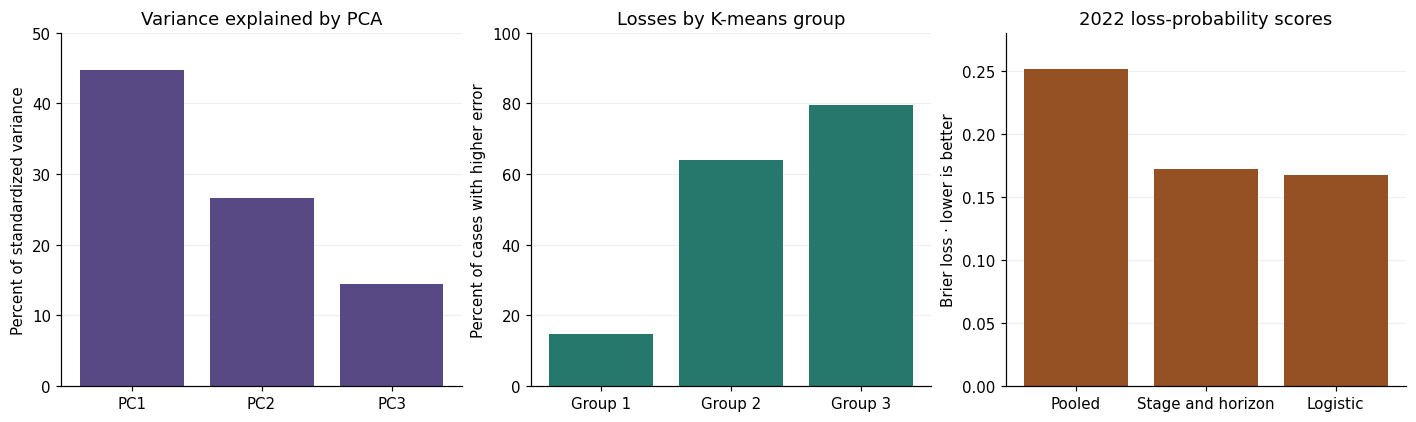

In [4]:
profile_columns = ['Group', 'Cases', 'Median reference move %', 'Median correction move %', 'Loss rate %']
display(pca_variance.round(2))
display(cluster_profiles[profile_columns].round(2))
display(classifier_scores[['Method', 'Test rows', 'Brier loss', 'Accuracy % at 0.5']].round({'Brier loss': 5, 'Accuracy % at 0.5': 2}))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), layout='constrained')
color = '#584984'
axes[0].bar(pca_variance.Component, pca_variance['Variance %'], color=color)
axes[0].set(title='Variance explained by PCA', ylabel='Percent of standardized variance', ylim=(0, 50))
axes[1].bar(cluster_profiles.Group, cluster_profiles['Loss rate %'], color='#26786C')
axes[1].set(title='Losses by K-means group', ylabel='Percent of cases with higher error', ylim=(0, 100))
axes[2].bar(['Pooled', 'Stage and horizon', 'Logistic'], classifier_scores['Brier loss'], color='#955023')
axes[2].set(title='2022 loss-probability scores', ylabel='Brier loss · lower is better', ylim=(0, .28))
for axis in axes:
    axis.spines[['top', 'right']].set_visible(False)
    axis.grid(axis='y', alpha=.18)
    axis.set_axisbelow(True)
plt.show()

## Stage 7 on the previously examined 2023 issue dates

The broader Stage 7 comparison issued a new forecast each session for **19 ARIMA orders × 19 training windows**. Each horizon shared the same **250** 2023 issue dates. Carry-forward had lower error than most fixed configurations. Across the four horizons, **314 of 1,444** order–window–horizon comparisons had lower error than carry-forward. These comparisons share dates and configurations.

For the **90-session** window, 2022 calibration selected MA(1) as its `d=0` order. The weak-form correction improved that reference at 30, 60 and 90 days and increased next-session error. The corrected paths reached their final forecast levels by trading session nine, and removing January issue dates reversed the pooled gains over carry-forward at all three longer horizons. The **95-session screened ARIMA(1,0,1)** example is from the earlier Stage 7 run and is included as a retrospective comparison. Both examples use the 2023 period already examined in Stage 6 Part 2.

The cells below display saved score extracts. The 90- and 95-session cases are examples from the tested grid. The diagnostics above use only Stages 1–6.

In [5]:
# Saved group-score differences from Stage 7. Positive values favor the forecast.
grid_summary = [19, 19, 250, 314, 1444]
grid_order_count, grid_window_count, grid_issue_count, grid_positive_count, grid_score_count = grid_summary
assert grid_score_count == grid_order_count * grid_window_count * 4
print(f"{grid_positive_count} / {grid_score_count} raw grid comparisons beat carry-forward · {grid_issue_count} issue dates per horizon")

archived_stage7 = {
    '90 sessions · 2022-selected MA(1)': [(1, 0.0021518583628732, -0.0027304148911619), (30, -0.009266729350351, 0.0489143136045981), (60, -0.0074645686148322, 0.0366960028337199), (90, -0.0022184497765636, 0.0485970902524481)],
    '95 sessions · screened ARIMA(1,0,1)': [(1, 0.0008777212422472, -0.0008438952462439), (30, 0.0019980567740258, 0.0478667838336068), (60, 0.0030859697462712, 0.0224135824935221), (90, 0.0008922130923636, 0.0317657145096372)],
}
horizons = {1: 'Next session', 30: '30 calendar days', 60: '60 calendar days', 90: '90 calendar days'}
reference_col = 'Reference vs carry (pp)'
corrected_col = 'Corrected vs carry (pp)'
for name, rows in archived_stage7.items():
    scores = pd.DataFrame(rows, columns=['Horizon', reference_col, corrected_col])
    scores['Added by weak-form correction (pp)'] = scores[corrected_col] - scores[reference_col]
    scores['Horizon'] = scores.Horizon.map(horizons)
    print(name)
    display(scores.round(5))

314 / 1444 raw grid comparisons beat carry-forward · 250 issue dates per horizon
90 sessions · 2022-selected MA(1)
95 sessions · screened ARIMA(1,0,1)


,Horizon,Reference vs carry (pp),Corrected vs carry (pp),Added by weak-form correction (pp)
0,Next session,0.00215,-0.00273,-0.00488
1,30 calendar days,-0.00927,0.04891,0.05818
2,60 calendar days,-0.00746,0.03670,0.04416
3,90 calendar days,-0.00222,0.04860,0.05082


,Horizon,Reference vs carry (pp),Corrected vs carry (pp),Added by weak-form correction (pp)
0,Next session,0.00088,-0.00084,-0.00172
1,30 calendar days,0.00200,0.04787,0.04587
2,60 calendar days,0.00309,0.02241,0.01933
3,90 calendar days,0.00089,0.03177,0.03087


## Source record

- Stages 1–6 diagnostic extract from `project_retrospective/presentation/results/presentation_matched_cases.csv.gz`. SHA-256 of the uncompressed source CSV `0c382aed12e70463d2491359f0f6693cbbd1701dfe458638219d892e1c666a52`.
- Stage 7 counts from `stage_7/results/order_grid/order_scores.csv`. The 90-session scores use `order_grid/selected_scores.csv`, with correction differences checked against `order_grid/paired_selected_scores.csv`.
- The 90-session MA(1) path and January sensitivity use the saved forecasts in `stage_7/results/order_grid/order_reference_paths.npz`.
- Stage 7's 95-session scores use `stage_7/results/window_scores.csv` for the screened PCA–ARIMA(1,0,1) reference and its corrected path.

- Struck, C. M. (2026). *Nonlinear Calculus in Practice: The Matrix of Error and Cross-System Integration*. Zenodo. [https://doi.org/10.5281/zenodo.23343429](https://doi.org/10.5281/zenodo.23343429).
